# Phase 4 — Financial Data Processing, Feature Engineering & Top-40 Selection

**FDIC Bank Failure Early Warning | Target `y_failure_4q_v3` | Historical panel 1984–2026**

Phase 4 xây dựng và kiểm tra dữ liệu dự báo thất bại ngân hàng trong **bốn quý tiếp theo**, đánh giá missingness, tạo predictors, lựa chọn và đóng băng **Final Top 40 LightGBM** từ TRAIN 1985–2006. Phần mở rộng 4.10–4.20 kiểm tra *point-in-time, dynamic features, drift, ngân sách cảnh báo* và **Native vs Median vs Median+Mask**. Phase 5 là **validation-only**; notebook này chưa có kết quả CRISIS_TEST/RECENT_OOT.

> **Cách đọc kết quả:** Các con số bên dưới là output của **lần thực thi được lưu trong file này**. Các lần chạy notebook khác có thể có kết quả khác; không trộn chúng. `REAL FDIC` = tính từ dữ liệu ngân hàng thật; `SANDBOX TEST` = thử trên dữ liệu mô phỏng; `OPTIONAL` = chưa chạy/không được coi là kết quả. Code gốc, thứ tự thực thi và output được giữ nguyên trong bản chỉnh Markdown này.

### Mục lục

| Section | Nội dung | Kết quả cần chú ý |
|---|---|---|
| [4.0](#p4-40)–[4.2](#p4-42) | Handoff, nhãn V3 và field catalogue | Khóa `(CERT, REPDTE)`; nguồn dữ liệu |
| [4.3](#p4-43)–[4.6](#p4-46) | Coverage, integrity, CAMELS | Giới hạn reporting và kiểm soát dữ liệu |
| [4.7](#p4-47) | Missing-data pipelines | Native Missing và Median |
| [4.8](#p4-48) | Feature Engineering | Rolling/interaction, tính hợp lệ |
| [4.9B](#p4-49b)–[4.9D](#p4-49d) | Relevance, MI và historical folds | Class imbalance, support theo ngân hàng |
| [4.9E](#p4-49e) | Top-40 chronological selection | F1–F3, **33 stable features** trong lần chạy này |
| [4.9F](#p4-49f) | Final Top-40 freeze | Checkpoint + 40 cột có thứ tự cố định |
| [4.10](#p4-draft)–[4.11](#p4-draft-pit) | Replay và point-in-time audit | Alert lift, publication lag, label maturity |
| [4.12](#p4-draft-features)–[4.13](#p4-draft-drift) | 19 temporal features và drift | Kiểm thử kỹ thuật; chưa chứng minh tăng dự báo |
| [4.14](#p4-draft-ops)–[4.15](#p4-draft-train) | Alert theo quý và TRAIN diagnostics | F1 per-quarter vs whole-window |
| [4.16](#p4-draft-conclusion)–[4.17](#p4-merge) | Kết luận nghiên cứu và đối chiếu file | Nêu rõ các lần chạy khác nhau |
| [4.18](#p4-impute) | **Controlled Imputation** | **9 kết quả FDIC F1–F3 đã chạy** |
| [4.19](#p4-research-matrix) | Tài liệu tham khảo và 3 stress features | Hypotheses / sandbox, không đưa vào final |
| [4.20](#p4-impute-handoff) | Decision log | Khóa model chính, tách challenger |
| [Phase 5 handoff](#p4-handoff) | Kết luận cuối và validation contract | **Không tuning trên external tests** |

**Tags:** `RESULT` (output thực); `VIZ` (đồ thị); `SANDBOX TEST` (mô phỏng); `LOCAL TRAIN` (dữ liệu TRAIN thực); `OPTIONAL` (chưa chạy); `FREEZE`/`HANDOFF` (quyết định cuối).


<a id="p4-40"></a>

## 4.0 | Khởi tạo và handoff từ Phase 3  `[SECTION]`

**Mục tiêu:** khôi phục đúng Silver/W1, manifest và các objects cần thiết. Các ô dưới đây giữ nguyên lịch sử diagnostic/recovery để có thể kiểm toán; khi chạy lại, theo dõi thứ tự phụ thuộc và tránh chạy đồng thời nhiều nhánh khôi phục.

> **Restart-safe:** Ô **RESTORE VERIFIED PRODUCTION HANDOFF** đọc nhãn V3 và temporal split từ manifest/handoff đã lưu. Không yêu cầu biến `LABELS_V3` hoặc `LABEL_PATH` còn trong RAM. Các ô discovery trước đó chỉ phục vụ chẩn đoán; không tạo nhãn mới.

**`[RUN]` PHASE 4 — STEP 4.1 DEPENDENCY DISCOVERY — 4 ô liên tiếp.** Chạy lần lượt từ trên xuống; các bảng/đồ thị của cell gốc được giữ tại ô cuối của nhóm.

In [248]:

# ============================================================
# PHASE 4 — STEP 4.1 DEPENDENCY DISCOVERY
#
# FIND:
#   1. W1
#   2. LABELS_V3
#   3. SPLIT_WINDOWS_V3
#
# Diagnostic only:
# - No full-data collect
# - No joins
# - No file modifications
# - No automatic assignment of uncertain sources
# ============================================================

import json
from pathlib import Path
from collections import defaultdict
import polars as pl

# ------------------------------------------------------------
# 0. Project root
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

assert PROJECT_ROOT.is_dir()

print("=" * 85)
print("PHASE 4 — STEP 4.1 DEPENDENCY DISCOVERY")
print("=" * 85)
print("PROJECT_ROOT:", PROJECT_ROOT)

LABEL_REQUIRED = {
    "CERT",
    "REPDTE",
    "y_failure_4q_v3",
    "MODEL_ELIGIBLE_V3",
    "ROBUSTNESS_ELIGIBLE_V3"
}

JOIN_KEYS = {"CERT", "REPDTE"}

SPLIT_REQUIRED = {
    "TRAIN_FULL",
    "CRISIS_TEST",
    "RECENT_OOT"
}

# ------------------------------------------------------------
# 1. Inspect current notebook state
# ------------------------------------------------------------

print("\n========== 1. CURRENT NOTEBOOK STATE ==========")

for name in [
    "P3_HANDOFF",
    "P3_MANIFEST",
    "P4_BOUNDARY",
    "SILVER_PATH",
    "W1_PATH",
    "LABEL_PATH",
    "SILVER",
    "W1",
    "LABELS_V3",
    "SPLIT_WINDOWS_V3"
]:
    obj = globals().get(name)

    if isinstance(obj, pl.LazyFrame):
        print(
            f"{name}: LazyFrame, "
            f"{len(obj.collect_schema())} columns"
        )
    elif obj is not None:
        print(f"{name}: {type(obj).__name__}")
    else:
        print(f"{name}: MISSING")

# ------------------------------------------------------------
# 2. Identify logical Parquet datasets
#
# Collapse year=/quarter= partitions into dataset roots.
# Do not inspect every file separately.
# ------------------------------------------------------------

parquet_files = sorted(
    PROJECT_ROOT.rglob("*.parquet")
)

dataset_groups = defaultdict(list)

for file in parquet_files:

    parent = file.parent

    while (
        parent != PROJECT_ROOT
        and "=" in parent.name
    ):
        parent = parent.parent

    # Unpartitioned single parquet stays a single candidate.
    if parent == file.parent:
        logical_path = file
    else:
        logical_path = parent

    dataset_groups[logical_path].append(file)

print("\n========== 2. DATASET DISCOVERY ==========")
print("Physical Parquet files:", len(parquet_files))
print("Logical candidate datasets:", len(dataset_groups))

# ------------------------------------------------------------
# 3. Inspect representative schemas
# No row-level data is read.
# ------------------------------------------------------------

P41_W1_CANDIDATES = []
P41_LABEL_CANDIDATES = []
P41_SILVER_CANDIDATES = []

def relative_name(path):
    try:
        return str(path.relative_to(PROJECT_ROOT))
    except ValueError:
        return str(path)


PHASE 4 — STEP 4.1 DEPENDENCY DISCOVERY
PROJECT_ROOT: C:\học tập\kì 7\Big data\Final\Bản nháp

========== 1. CURRENT NOTEBOOK STATE ==========
P3_HANDOFF: MISSING
P3_MANIFEST: dict
P4_BOUNDARY: MISSING
SILVER_PATH: WindowsPath
W1_PATH: WindowsPath
LABEL_PATH: WindowsPath
SILVER: LazyFrame, 141 columns
W1: LazyFrame, 11 columns
LABELS_V3: LazyFrame, 15 columns
SPLIT_WINDOWS_V3: dict

========== 2. DATASET DISCOVERY ==========
Physical Parquet files: 1076
Logical candidate datasets: 877


In [249]:

for logical_path, files in sorted(
    dataset_groups.items(),
    key=lambda item: str(item[0])
):

    # Inspect first representative file only.
    representative = sorted(files)[0]

    try:
        schema = (
            pl.scan_parquet(str(representative))
            .collect_schema()
        )
    except Exception:
        continue

    columns = set(schema.names())
    path_text = relative_name(logical_path).lower().replace(
        "\\", "/"
    )

    # Exclude clearly unrelated intermediate directories
    # from recommendation ranking, not from project search.
    excluded = any(
        token in path_text
        for token in [
            "benchmark/",
            "/scratch/",
            "/tmp/",
            "/temp/"
        ]
    )

    label_match = len(
        LABEL_REQUIRED.intersection(columns)
    )

    # Complete Step 4.1 label schema.
    if LABEL_REQUIRED.issubset(columns):

        P41_LABEL_CANDIDATES.append({
            "path": logical_path,
            "columns": len(columns),
            "physical_files": len(files),
            "has_all_label_fields": True,
            "excluded": excluded
        })

    # Silver candidates: contextual information only.
    if (
        JOIN_KEYS.issubset(columns)
        and {"ASSET", "DEP", "EQ", "ROA"}
        .issubset(columns)
        and len(columns) >= 100
    ):
        P41_SILVER_CANDIDATES.append({
            "path": logical_path,
            "columns": len(columns),
            "physical_files": len(files),
            "excluded": excluded
        })

    # W1 candidates:
    # Require join keys, financial fields and absence
    # of all label columns that Step 4.1 will append.
    #
    # W1 cannot be verified by schema alone.
    if (
        JOIN_KEYS.issubset(columns)
        and {"ASSET", "DEP"}.issubset(columns)
        and not (
            LABEL_REQUIRED - JOIN_KEYS
        ).intersection(columns)
    ):

        score = 0

        if "w1" in path_text:
            score += 8

        if "phase3" in path_text or "phase_3" in path_text:
            score += 5

        if "canonical" in path_text:
            score += 3

        if "warning" in path_text:
            score += 3

        if "phase2" in path_text:
            score -= 2

        if excluded:
            score -= 20

        P41_W1_CANDIDATES.append({
            "path": logical_path,
            "columns": len(columns),
            "physical_files": len(files),
            "score": score,
            "excluded": excluded
        })


# ------------------------------------------------------------
# 4. Report label candidates
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("3. LABELS_V3 CANDIDATES")
print("=" * 85)

label_sorted = sorted(
    P41_LABEL_CANDIDATES,
    key=lambda x: (
        x["excluded"],
        -x["columns"],
        str(x["path"])
    )
)

print(
    "Datasets containing ALL five required columns:",
    len(label_sorted)
)

for i, item in enumerate(label_sorted[:30], 1):
    print(
        f"\n[{i}] {relative_name(item['path'])}"
    )
    print(
        "    Columns:", item["columns"],
        "| Parquet files:", item["physical_files"],
        "| Excluded context:", item["excluded"]
    )

if len(label_sorted) > 30:
    print(
        f"\n... {len(label_sorted) - 30} "
        "additional candidates not displayed."
    )



3. LABELS_V3 CANDIDATES
Datasets containing ALL five required columns: 2

[1] outputs\phase5_input\phase4_gold_v3_native.parquet
    Columns: 126 | Parquet files: 1 | Excluded context: False

[2] outputs\phase2_full_history\contract_a1cd7440e6a09ca8\run_aee2d40b147b0be5bd14\label_v3_event_based\history_0a842bef9739\bank_quarter_labels_event_based_v3.parquet
    Columns: 15 | Parquet files: 1 | Excluded context: False


In [250]:

if not label_sorted:
    print(
        "NO COMPLETE LABEL DATASET FOUND.\n"
        "Possibility: the required label/eligibility columns "
        "are spread across different artifacts, or "
        "the correct dataset is outside the project root."
    )


# ------------------------------------------------------------
# 5. Report likely W1 datasets
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("4. W1 CANDIDATES")
print("=" * 85)

w1_sorted = sorted(
    P41_W1_CANDIDATES,
    key=lambda x: (
        -x["score"],
        str(x["path"])
    )
)

print("Schema-compatible datasets:", len(w1_sorted))

for i, item in enumerate(w1_sorted[:30], 1):
    print(
        f"\n[{i}] {relative_name(item['path'])}"
    )
    print(
        "    Columns:", item["columns"],
        "| Parquet files:", item["physical_files"],
        "| Path relevance:", item["score"]
    )

if len(w1_sorted) > 30:
    print(
        f"\n... {len(w1_sorted) - 30} "
        "additional candidates not displayed."
    )


# ------------------------------------------------------------
# 6. Locate original split policy in JSON
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("5. SPLIT_WINDOWS_V3 DISCOVERY")
print("=" * 85)

json_files = sorted(
    PROJECT_ROOT.rglob("*.json")
)

P41_SPLIT_CANDIDATES = []
P41_PATH_REFERENCES = []

def inspect_json(obj, source, key_path=""):

    if isinstance(obj, dict):

        # A split dictionary must contain the required names.
        if SPLIT_REQUIRED.issubset(set(obj.keys())):

            P41_SPLIT_CANDIDATES.append({
                "source": source,
                "location": key_path or "<root>",
                "value": obj
            })

        for key, value in obj.items():

            path_here = (
                f"{key_path}.{key}"
                if key_path else str(key)
            )

            key_lower = str(key).lower()

            if isinstance(value, str):

                if any(
                    token in key_lower
                    for token in [
                        "silver",
                        "w1",
                        "label",
                        "path",
                        "parquet"
                    ]
                ):
                    if any(
                        token in (
                            key_lower + " " + value.lower()
                        )
                        for token in [
                            "silver", "w1",
                            "label", "phase3",
                            ".parquet"
                        ]
                    ):
                        P41_PATH_REFERENCES.append({
                            "source": source,
                            "key": path_here,
                            "value": value
                        })

            if isinstance(value, (dict, list)):
                inspect_json(value, source, path_here)

    elif isinstance(obj, list):

        for i, value in enumerate(obj):
            if isinstance(value, (dict, list)):
                inspect_json(
                    value,
                    source,
                    f"{key_path}[{i}]"
                )


for path in json_files:

    try:
        if path.stat().st_size > 5_000_000:
            continue

        with path.open(
            "r",
            encoding="utf-8-sig"
        ) as f:
            obj = json.load(f)

        inspect_json(
            obj,
            relative_name(path)
        )

    except Exception:
        continue



4. W1 CANDIDATES
Schema-compatible datasets: 754

[1] outputs\phase3_refined\runs\20261123T155100Z_6880_818909000\storage_ablation_32y\snappy_50k\data.parquet
    Columns: 141 | Parquet files: 1 | Path relevance: 5

[2] outputs\phase3_refined\runs\20261123T155100Z_6880_818909000\storage_ablation_32y\zstd_10k\data.parquet
    Columns: 141 | Parquet files: 1 | Path relevance: 5

[3] outputs\phase3_refined\runs\20261123T155100Z_6880_818909000\storage_ablation_32y\zstd_50k\data.parquet
    Columns: 141 | Parquet files: 1 | Path relevance: 5

[4] outputs\phase3_refined\runs\20261123T155100Z_6880_818909000\storage_ablation_32y\zstd_annual
    Columns: 141 | Parquet files: 32 | Path relevance: 5

[5] outputs\phase3_refined\runs\20261123T155100Z_6880_818909000\storage_ablation_32y\zstd_date_clustered\data.parquet
    Columns: 141 | Parquet files: 1 | Path relevance: 5

[6] outputs\phase3_refined\runs\20261123T155100Z_6880_818909000\storage_full_history_1984_2026Q2\snappy_50k.parquet
    Colum

In [251]:


# Also examine existing in-memory handoff dictionaries.
for name in [
    "P3_HANDOFF",
    "P3_MANIFEST",
    "P4_BOUNDARY"
]:
    obj = globals().get(name)

    if isinstance(obj, (dict, list)):
        inspect_json(obj, f"MEMORY:{name}")


def split_is_compatible(value):

    if not isinstance(value, dict):
        return False

    if not SPLIT_REQUIRED.issubset(value):
        return False

    # Step 4.1 requires (start_year, end_year).
    for split_range in value.values():

        if not isinstance(split_range, (list, tuple)):
            return False

        if len(split_range) != 2:
            return False

        try:
            int(split_range[0])
            int(split_range[1])
        except (ValueError, TypeError):
            return False

    return True


compatible_splits = [
    entry
    for entry in P41_SPLIT_CANDIDATES
    if split_is_compatible(entry["value"])
]

print("JSON files inspected:", len(json_files))
print(
    "Compatible V3 split dictionaries:",
    len(compatible_splits)
)

seen = set()

for entry in compatible_splits:

    signature = json.dumps(
        entry["value"],
        sort_keys=True,
        default=str
    )

    if signature in seen:
        continue

    seen.add(signature)

    print("\nSOURCE:", entry["source"])
    print("LOCATION:", entry["location"])
    print(
        json.dumps(
            entry["value"],
            indent=2,
            ensure_ascii=False,
            default=str
        )
    )


# ------------------------------------------------------------
# 7. Show exact source references from manifest JSON
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("6. PHASE 3 PATH REFERENCES IN METADATA")
print("=" * 85)

relevant_references = [
    r for r in P41_PATH_REFERENCES
    if any(
        token in (
            r["source"] + " " + r["key"]
        ).lower()
        for token in [
            "phase3", "p3", "handoff",
            "manifest", "silver",
            "w1", "label"
        ]
    )
]

print("Relevant path references:", len(relevant_references))

for item in relevant_references[:60]:
    print("\nSOURCE:", item["source"])
    print("KEY:", item["key"])
    print("VALUE:", item["value"])

if len(relevant_references) > 60:
    print(
        "\n... additional references omitted."
    )


# ------------------------------------------------------------
# 8. Final diagnostic
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("7. STEP 4.1 DEPENDENCY STATUS")
print("=" * 85)

print(
    "Complete LABELS_V3 candidates:",
    len(label_sorted)
)

print(
    "Schema-compatible W1 candidates:",
    len(w1_sorted)
)

print(
    "Compatible temporal split policies:",
    len(compatible_splits)
)

print("\nSTEP 4.1 specifically requires:")

for name in [
    "W1",
    "LABELS_V3",
    "SPLIT_WINDOWS_V3"
]:
    print(
        f"  {name}:",
        "IN MEMORY"
        if name in globals()
        else "NOT INITIALIZED"
    )

print("\nDISCOVERY FINISHED.")
print("No full datasets collected.")
print("No source files modified.")
print(
    "No uncertain datasets assigned to W1 or LABELS_V3."
)


JSON files inspected: 1025
Compatible V3 split dictionaries: 7

SOURCE: outputs\phase2_full_history\contract_a1cd7440e6a09ca8\run_aee2d40b147b0be5bd14\label_v3_event_based\history_0a842bef9739\phase2_to_phase3_handoff_v3.json
LOCATION: split_windows
{
  "TRAIN_FULL": [
    1984,
    2006
  ],
  "PURGE_1": [
    2007,
    2007
  ],
  "CRISIS_TEST": [
    2008,
    2012
  ],
  "PURGE_2": [
    2013,
    2013
  ],
  "RECENT_OOT": [
    2014,
    2025
  ]
}

6. PHASE 3 PATH REFERENCES IN METADATA
Relevant path references: 91

SOURCE: data\raw\fdic\reference\contract_a1cd7440e6a09ca8\_manifests\failures_CURRENT.json
KEY: snapshot_relpath
VALUE: snapshots\failures\cf76ee1fb3a36a5745ea124b.parquet

SOURCE: data\raw\fdic\reference\contract_a1cd7440e6a09ca8\_manifests\institutions_CURRENT.json
KEY: snapshot_relpath
VALUE: snapshots\institutions\5a738dc47527b98919aef7db.parquet

SOURCE: data\silver\provisional_label_manifest.json
KEY: source.silver_panel
VALUE: C:\học tập\kì 7\Big data\Final\Bản

In [252]:

# ============================================================
# PHASE 4 — STEP 4.0: W1 RECOVERY DIAGNOSTIC
# Reuse previous discovery results
# No file scans | No data collection | No source changes
# ============================================================

assert "pl" in globals(), "Polars is not initialized."
assert "Path" in globals(), "Path is not initialized."

print("=" * 75)
print("STEP 4.0 — REMAINING DEPENDENCY RECOVERY")
print("=" * 75)

# ------------------------------------------------------------
# 1. Reuse discovered W1 candidates
# ------------------------------------------------------------

if "w1_sorted" in globals():
    candidates = w1_sorted

elif "P41_W1_CANDIDATES" in globals():
    candidates = sorted(
        P41_W1_CANDIDATES,
        key=lambda x: (
            -x["score"],
            str(x["path"])
        )
    )

else:
    raise RuntimeError(
        "Previous W1 discovery results are unavailable. "
        "Run the dependency discovery cell first."
    )

print("\n========== W1 CANDIDATES ==========")
print("Total candidates:", len(candidates))

for i, item in enumerate(candidates[:25], 1):
    path = item["path"]

    print(
        f"[{i}] {path}\n"
        f"    Columns: {item['columns']}\n"
        f"    Parquet files: {item['physical_files']}\n"
        f"    Path relevance: {item['score']}"
    )

# ------------------------------------------------------------
# 2. Check already restored V3 label and split objects
# ------------------------------------------------------------

print("\n========== EXISTING DEPENDENCIES ==========")

for name in ["LABELS_V3", "SPLIT_WINDOWS_V3"]:

    value = globals().get(name)

    if isinstance(value, pl.LazyFrame):
        print(
            name,
            "READY —",
            len(value.collect_schema()),
            "columns"
        )

    elif isinstance(value, dict):
        print(name, "READY —", list(value.keys()))
        print("Split windows:", value)

    else:
        print(name, "MISSING")

# ------------------------------------------------------------
# 3. Check which W1 candidate is identified by handoff
# ------------------------------------------------------------

print("\n========== POSSIBLE W1 METADATA REFERENCES ==========")

references = globals().get(
    "relevant_references",
    []
)

matched_references = [
    x for x in references
    if "w1" in (
        str(x.get("key", "")) + " " +
        str(x.get("value", ""))
    ).lower()
]

for item in matched_references[:20]:
    print("Source:", item["source"])
    print("Key:", item["key"])
    print("Value:", item["value"])
    print()

if not matched_references:
    print("No explicit W1 reference recovered from metadata.")

# ------------------------------------------------------------
# 4. Final Step 4.1 prerequisites
# ------------------------------------------------------------

print("\n========== STEP 4.1 READINESS ==========")

required = ["W1", "LABELS_V3", "SPLIT_WINDOWS_V3"]

for name in required:
    print(
        name,
        "READY" if name in globals() else "MISSING"
    )

print("\nDiagnostic completed.")
print("No files modified.")


STEP 4.0 — REMAINING DEPENDENCY RECOVERY

========== W1 CANDIDATES ==========
Total candidates: 754
[1] C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase3_refined\runs\20261123T155100Z_6880_818909000\storage_ablation_32y\snappy_50k\data.parquet
    Columns: 141
    Parquet files: 1
    Path relevance: 5
[2] C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase3_refined\runs\20261123T155100Z_6880_818909000\storage_ablation_32y\zstd_10k\data.parquet
    Columns: 141
    Parquet files: 1
    Path relevance: 5
[3] C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase3_refined\runs\20261123T155100Z_6880_818909000\storage_ablation_32y\zstd_50k\data.parquet
    Columns: 141
    Parquet files: 1
    Path relevance: 5
[4] C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase3_refined\runs\20261123T155100Z_6880_818909000\storage_ablation_32y\zstd_annual
    Columns: 141
    Parquet files: 32
    Path relevance: 5
[5] C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase3_refined\runs\2026112

In [253]:

# ============================================================
# PHASE 4 — STEP 4.0: IDENTIFY CANONICAL W1
#
# Reuse w1_sorted from previous discovery
# No new Parquet scans
# No data collection
# No source modification
# ============================================================

assert "w1_sorted" in globals(), (
    "Run the previous dependency discovery cell first."
)

assert "PROJECT_ROOT" in globals()

# ------------------------------------------------------------
# 1. Exclude experimental and intermediate artifacts
# ------------------------------------------------------------

excluded_patterns = [
    "phase3_storage_experiments",
    "benchmark",
    "scratch",
    "temporary",
    "temp",
    "test_runs",
    "phase1_revised",
    "phase2_revised"
]

canonical_candidates = []

for item in w1_sorted:

    path = item["path"]

    rel = str(
        path.relative_to(PROJECT_ROOT)
    ).lower().replace("\\", "/")

    if any(
        pattern in rel
        for pattern in excluded_patterns
    ):
        continue

    canonical_candidates.append({
        "path": path,
        "columns": item["columns"],
        "files": item["physical_files"],
        "score": item["score"],
        "relative": rel
    })

# ------------------------------------------------------------
# 2. Prioritize named canonical / handoff artifacts
# ------------------------------------------------------------

def priority(item):
    rel = item["relative"]

    return (
        int("canonical" in rel),
        int("handoff" in rel),
        int("phase3" in rel),
        int("w1" in rel),
        item["score"]
    )

canonical_candidates.sort(
    key=priority,
    reverse=True
)

print("=" * 75)
print("CANONICAL W1 CANDIDATE FILTER")
print("=" * 75)

print("Original candidates:", len(w1_sorted))
print("After exclusion:", len(canonical_candidates))

print("\n========== TOP CANDIDATES ==========")

for i, item in enumerate(
    canonical_candidates[:50], 1
):
    print(
        f"\n[{i}] {item['path']}\n"
        f"    Columns: {item['columns']}\n"
        f"    Parquet files: {item['files']}\n"
        f"    Discovery score: {item['score']}"
    )

# ------------------------------------------------------------
# 3. Inspect Phase 3 metadata references
# ------------------------------------------------------------

print("\n========== W1 REFERENCES FROM METADATA ==========")

references = globals().get(
    "relevant_references",
    []
)

w1_refs = [
    r for r in references
    if "w1" in (
        str(r.get("key", "")) + " " +
        str(r.get("value", ""))
    ).lower()
]

if w1_refs:

    for r in w1_refs[:40]:
        print("Source:", r["source"])
        print("Key:", r["key"])
        print("Value:", r["value"])
        print()

else:
    print("No explicit W1 references found.")

# ------------------------------------------------------------
# 4. Check dependency status
# ------------------------------------------------------------

print("\n========== STEP 4.1 DEPENDENCIES ==========")

print(
    "LABELS_V3:",
    "READY" if "LABELS_V3" in globals()
    else "MISSING"
)

print(
    "SPLIT_WINDOWS_V3:",
    "READY" if "SPLIT_WINDOWS_V3" in globals()
    else "MISSING"
)

print(
    "W1:",
    "READY" if "W1" in globals()
    else "MISSING"
)

print("\nNo datasets loaded or modified.")


CANONICAL W1 CANDIDATE FILTER
Original candidates: 754
After exclusion: 693

========== TOP CANDIDATES ==========

[1] C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase3_refined\runs\20261123T155100Z_6880_818909000\storage_ablation_32y\snappy_50k\data.parquet
    Columns: 141
    Parquet files: 1
    Discovery score: 5

[2] C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase3_refined\runs\20261123T155100Z_6880_818909000\storage_ablation_32y\zstd_10k\data.parquet
    Columns: 141
    Parquet files: 1
    Discovery score: 5

[3] C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase3_refined\runs\20261123T155100Z_6880_818909000\storage_ablation_32y\zstd_50k\data.parquet
    Columns: 141
    Parquet files: 1
    Discovery score: 5

[4] C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase3_refined\runs\20261123T155100Z_6880_818909000\storage_ablation_32y\zstd_annual
    Columns: 141
    Parquet files: 32
    Discovery score: 5

[5] C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phas

In [254]:

# ============================================================
# PHASE 4 — STEP 4.0: FINAL W1 SOURCE IDENTIFICATION
# Reuse 417 existing candidates
# No full-data scans / No source modification
# ============================================================

assert "canonical_candidates" in globals()
assert "PROJECT_ROOT" in globals()

print("=" * 75)
print("FINAL W1 SOURCE IDENTIFICATION")
print("=" * 75)

excluded = [
    "storage_ablation",
    "storage_experiments",
    "benchmark",
    "scratch",
    "narrow_by_year",
    "source_years",
    "compression",
    "rowgroup",
    "phase1",
    "phase2",
    "temporary",
    "test_run"
]

# Candidate W1 should be the wide financial table,
# not narrow source tables or storage experiments.
filtered = []

for item in canonical_candidates:

    rel = str(
        item["path"].relative_to(PROJECT_ROOT)
    ).lower().replace("\\", "/")

    if any(x in rel for x in excluded):
        continue

    if item["columns"] != 141:
        continue

    filtered.append(item)

print("Original candidates:", len(canonical_candidates))
print("Wide 141-column non-experimental candidates:", len(filtered))

print("\n========== W1 SHORTLIST ==========")

for i, item in enumerate(filtered, 1):
    print(f"[{i}] {item['path']}")
    print(
        f"    Columns: {item['columns']} | "
        f"Files: {item['files']}"
    )

print("\n========== CURRENT LABEL SOURCE ==========")

if "LABEL_PATH" in globals():
    print("LABEL_PATH:", LABEL_PATH)
else:
    print("LABEL_PATH: MISSING")

print("\n========== SPLIT POLICY ==========")

if "SPLIT_WINDOWS_V3" in globals():
    for name, years in SPLIT_WINDOWS_V3.items():
        print(name, ":", years)
else:
    print("MISSING")

print("\n========== POSSIBLE HANDOFF METADATA ==========")

metadata = sorted(
    p for p in PROJECT_ROOT.rglob("*.json")
    if (
        "phase3" in str(p).lower()
        or "handoff" in p.name.lower()
    )
    and any(
        x in p.name.lower()
        for x in ["handoff", "manifest", "contract"]
    )
)

for p in metadata[:25]:
    print(p.relative_to(PROJECT_ROOT))

print("\nSTATUS — Shortlist generated.")
print("W1 not assigned until source is verified.")


FINAL W1 SOURCE IDENTIFICATION
Original candidates: 693
Wide 141-column non-experimental candidates: 3

========== W1 SHORTLIST ==========
[1] C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase3_refined\runs\20261123T155100Z_6880_818909000\storage_full_history_1984_2026Q2\snappy_50k.parquet
    Columns: 141 | Files: 1
[2] C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase3_refined\runs\20261123T155100Z_6880_818909000\storage_full_history_1984_2026Q2\zstd_50k.parquet
    Columns: 141 | Files: 1
[3] C:\học tập\kì 7\Big data\Final\Bản nháp\data\silver\full_history\contract_a1cd7440e6a09ca8\run_aee2d40b147b0be5bd14\clean_bank_quarter.parquet
    Columns: 141 | Files: 1

========== CURRENT LABEL SOURCE ==========
LABEL_PATH: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase2_full_history\contract_a1cd7440e6a09ca8\run_aee2d40b147b0be5bd14\label_v3_event_based\history_0a842bef9739\bank_quarter_labels_event_based_v3.parquet

========== SPLIT POLICY ==========
TRAIN_FULL : [1984, 2006

In [255]:

# ============================================================
# PHASE 4 — STEP 4.0
# PRODUCTION HANDOFF SOURCE IDENTIFICATION
#
# Read-only | No full-data collect | No file modification
# ============================================================

import json
from pathlib import Path
import polars as pl
import hashlib
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

p4_pointer = (
    PROJECT_ROOT / "outputs" / "phase3_refined" / "latest_phase4_handoff.json"
)
if not p4_pointer.is_file():
    raise FileNotFoundError(
        f"Thiếu {p4_pointer}. Chạy Phase 3 Aligned đến hết ô 3.11.7 trước."
    )

p4_handoff = json.loads(p4_pointer.read_text(encoding="utf-8-sig"))
MANIFEST_PATH = (PROJECT_ROOT / p4_handoff["production_manifest"]).resolve()

if not MANIFEST_PATH.is_file():
    raise FileNotFoundError(f"Manifest Phase 3 không còn tại {MANIFEST_PATH}")

actual_sha = hashlib.sha256(MANIFEST_PATH.read_bytes()).hexdigest()
if actual_sha != p4_handoff["production_manifest_sha256"]:
    raise RuntimeError(
        "Checksum manifest Phase 3 không khớp. Kiểm tra lần chạy Phase 3 "
        "trước khi tiếp tục."
    )

print("Đã xác minh manifest Phase 3:", MANIFEST_PATH)

assert MANIFEST_PATH.is_file(), (
    f"Manifest not found: {MANIFEST_PATH}"
)

with MANIFEST_PATH.open("r", encoding="utf-8-sig") as f:
    manifest = json.load(f)

print("=" * 80)
print("PHASE 3 PRODUCTION MANIFEST")
print("=" * 80)
print("Manifest:", MANIFEST_PATH)
print("Top-level keys:",
      list(manifest) if isinstance(manifest, dict) else type(manifest))

# ------------------------------------------------------------
# 1. Display path / artifact / source references
# ------------------------------------------------------------

references = []

def walk_metadata(obj, prefix=""):
    if isinstance(obj, dict):
        for key, value in obj.items():
            current = f"{prefix}.{key}" if prefix else str(key)
            key_text = str(key).lower()

            if isinstance(value, (str, int, float, bool)):
                if any(term in current.lower() for term in (
                    "path", "file", "artifact", "silver",
                    "w1", "label", "dataset", "source",
                    "split", "output", "row", "schema"
                )):
                    references.append((current, str(value)))

            elif isinstance(value, (dict, list)):
                walk_metadata(value, current)

    elif isinstance(obj, list):
        for i, value in enumerate(obj):
            walk_metadata(value, f"{prefix}[{i}]")

walk_metadata(manifest)

print("\n========== MANIFEST REFERENCES ==========")

for key, value in references[:100]:
    print(f"{key}: {value[:250]}")

print("Total references:", len(references))

# ------------------------------------------------------------
# 2. Find nearby production Parquet artifacts
# ------------------------------------------------------------

production_dir = MANIFEST_PATH.parent

production_parquets = sorted(
    production_dir.rglob("*.parquet")
)

print("\n========== PRODUCTION PARQUET ARTIFACTS ==========")
print("Physical files:", len(production_parquets))

for path in production_parquets[:35]:
    try:
        schema = pl.scan_parquet(str(path)).collect_schema()
        names = set(schema.names())

        print(
            "\nPATH:", path.relative_to(PROJECT_ROOT),
            "\nCOLUMNS:", len(names),
            "\nHAS_KEYS:", {"CERT", "REPDTE"}.issubset(names),
            "\nHAS_ASSET:", "ASSET" in names,
            "\nHAS_LABEL:", "y_failure_4q_v3" in names,
            "\nHAS_ELIGIBILITY:",
            {
                "MODEL_ELIGIBLE_V3",
                "ROBUSTNESS_ELIGIBLE_V3"
            }.issubset(names)
        )

    except Exception as exc:
        print("SCHEMA ERROR:", path, str(exc)[:200])

if len(production_parquets) > 35:
    print(
        f"\n... {len(production_parquets) - 35} "
        "additional Parquet files not displayed."
    )

# ------------------------------------------------------------
# 3. Show current dependency status
# ------------------------------------------------------------

print("\n========== STEP 4.1 REQUIREMENTS ==========")

for name in ("W1", "LABELS_V3", "SPLIT_WINDOWS_V3"):
    value = globals().get(name)

    if isinstance(value, pl.LazyFrame):
        print(name, "READY", len(value.collect_schema()), "columns")
    elif isinstance(value, dict):
        print(name, "READY", value)
    else:
        print(name, "MISSING")

print("\nPASS — Production manifest inspected.")
print("No full-data scans.")
print("No source files modified.")


Đã xác minh manifest Phase 3: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase3_refined\runs\20261123T155100Z_6880_818909000\production\production_manifest.json
PHASE 3 PRODUCTION MANIFEST
Manifest: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase3_refined\runs\20261123T155100Z_6880_818909000\production\production_manifest.json
Top-level keys: ['phase', 'version', 'run_id', 'created_at_utc', 'upstream_artifacts', 'canonical_silver', 'production_w1', 'production_w2', 'financial_contract', 'validation', 'advanced_experiments', 'gates_current_run', 'limitations', 'phase4_modeling_boundary', 'phase2_v3_contract']

========== MANIFEST REFERENCES ==========
upstream_artifacts.phase0_field_handoff_sha256: ba300900d5c26090ea91204da9c219794c58bbfea08db6ee2c999ff0dcfbda82
upstream_artifacts.phase0_scope_sha256: b3849732a177722ce2442699e71e519191777d520156ea6689e528583f4da99c
upstream_artifacts.phase1_handoff_path: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase1_from_phase0\runs\

**`[RUN]` PHASE 4 — STEP 4.0 — 2 ô liên tiếp.** Chạy lần lượt từ trên xuống; các bảng/đồ thị của cell gốc được giữ tại ô cuối của nhóm.

In [256]:

# ============================================================
# PHASE 4 — STEP 4.0
# RESTORE VERIFIED PRODUCTION HANDOFF
#
# Source: Phase 3 production_manifest.json
#
# Restores:
#   PROJECT_ROOT
#   P3_MANIFEST
#   SILVER_PATH, W1_PATH
#   SILVER, W1
#   LABELS_V3 (reuse existing)
#   SPLIT_WINDOWS_V3 (reuse existing)
#
# No full-data scans
# No source modification
# ============================================================

import json
from pathlib import Path
import polars as pl

# ------------------------------------------------------------
# 1. Project root and production manifest
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Dùng đường dẫn đã được xác minh ở ô 4.0 phía trên.
if "MANIFEST_PATH" not in globals():
    raise RuntimeError("Chạy ô PRODUCTION HANDOFF SOURCE IDENTIFICATION trước.")

assert MANIFEST_PATH.is_file(), (
    f"Production manifest not found: {MANIFEST_PATH}"
)

with MANIFEST_PATH.open(
    "r", encoding="utf-8-sig"
) as f:
    P3_MANIFEST = json.load(f)

assert "canonical_silver" in P3_MANIFEST
assert "production_w1" in P3_MANIFEST

print("=" * 75)
print("PHASE 4 — STEP 4.0: PRODUCTION HANDOFF")
print("=" * 75)
print("Manifest:", MANIFEST_PATH)


# ------------------------------------------------------------
# 2. Restore verified Silver / W1 paths
# ------------------------------------------------------------

SILVER_PATH = Path(
    P3_MANIFEST["canonical_silver"]["path"]
)

W1_PATH = Path(
    P3_MANIFEST["production_w1"]["path"]
)

assert SILVER_PATH.is_file(), (
    f"Canonical Silver not found: {SILVER_PATH}"
)

assert W1_PATH.is_file(), (
    f"Production W1 not found: {W1_PATH}"
)

# ------------------------------------------------------------
# 3. Initialize lazy sources
# ------------------------------------------------------------

SILVER = pl.scan_parquet(str(SILVER_PATH))
W1 = pl.scan_parquet(str(W1_PATH))

silver_schema = SILVER.collect_schema()
w1_schema = W1.collect_schema()

assert {"CERT", "REPDTE"}.issubset(
    silver_schema.names()
)

assert {"CERT", "REPDTE"}.issubset(
    w1_schema.names()
)

assert len(silver_schema) == 141, (
    f"Silver schema mismatch: {len(silver_schema)} columns"
)

print("\n========== VERIFIED DATA SOURCES ==========")
print("Silver:", SILVER_PATH)
print("Silver columns:", len(silver_schema))

print("\nW1:", W1_PATH)
print("W1 columns:", len(w1_schema))

print(
    "W1 manifest rows:",
    P3_MANIFEST["production_w1"].get("rows")
)

# ------------------------------------------------------------
# 4. Restore authoritative Phase 2 V3 labels after restart
# ------------------------------------------------------------
# Phase 3 writes the verified V3 linkage into production_manifest.json
# and phase3_to_phase4_handoff_v3.json. Do not require LABELS_V3
# or LABEL_PATH to have survived a kernel restart.

import hashlib

P4_V3_HANDOFF_PATH = (
    MANIFEST_PATH.parent / "phase3_to_phase4_handoff_v3.json"
)
P4_V3_HANDOFF = {}
if P4_V3_HANDOFF_PATH.is_file():
    with P4_V3_HANDOFF_PATH.open("r", encoding="utf-8-sig") as f:
        P4_V3_HANDOFF = json.load(f)

P4_V3_CONTRACT = P3_MANIFEST.get("phase2_v3_contract", {})
if not P4_V3_CONTRACT:
    P4_V3_CONTRACT = P4_V3_HANDOFF.get("phase2_v3_contract", {})

P4_V3_PHASE2_HANDOFF = {}
P4_LABEL_SOURCE = "already-in-memory"

if not isinstance(globals().get("LABELS_V3"), pl.LazyFrame):
    _candidates = []

    def _p4_add_label_candidate(path_value, expected_sha, origin):
        if not path_value:
            return
        p = Path(path_value)
        if not p.is_absolute():
            p = PROJECT_ROOT / p
        _candidates.append((p, expected_sha, origin))

    # Prefer explicit, source-verified paths over any exploratory Parquet.
    _p4_boundary = P4_V3_HANDOFF.get("phase4_modeling_boundary", {})
    _p4_add_label_candidate(
        P4_V3_CONTRACT.get("label_path"),
        P4_V3_CONTRACT.get("label_sha256"),
        "Phase 3 production manifest / V3 contract",
    )
    _p4_add_label_candidate(
        _p4_boundary.get("target_file"),
        _p4_boundary.get("target_sha256"),
        "Phase 3 -> Phase 4 V3 handoff",
    )
    if globals().get("LABEL_PATH") is not None:
        _p4_add_label_candidate(
            globals()["LABEL_PATH"],
            P4_V3_CONTRACT.get("label_sha256"),
            "existing LABEL_PATH",
        )

    # Last resort: Phase 2 V3 manifests matching *this* production Silver.
    # Scan metadata JSON only; never guess from similarly named Parquets.
    if not any(p.is_file() for p, _, _ in _candidates):
        _p4_silver_sha = P3_MANIFEST["canonical_silver"].get("sha256")
        _p4_v3_jsons = sorted(
            (PROJECT_ROOT / "outputs" / "phase2_full_history").glob(
                "contract_*/run_*/label_v3_event_based/"
                "history_*/phase2_to_phase3_handoff_v3.json"
            )
        )
        _p4_valid_contracts = []
        for _p4_json in _p4_v3_jsons:
            try:
                _p4_payload = json.loads(
                    _p4_json.read_text(encoding="utf-8-sig")
                )
            except (OSError, ValueError):
                continue
            if _p4_payload.get("version") != "3.0-event-based-4q":
                continue
            if (_p4_silver_sha and
                    _p4_payload.get("silver_sha256") != _p4_silver_sha):
                continue
            _p4_label_file = Path(_p4_payload.get("label_file", ""))
            if not _p4_label_file.is_file():
                _p4_label_file = (
                    _p4_json.parent / "bank_quarter_labels_event_based_v3.parquet"
                )
            if _p4_label_file.is_file():
                _p4_valid_contracts.append(
                    (_p4_label_file, _p4_payload, _p4_json)
                )

        _p4_distinct = {
            p.get("label_sha256") for _, p, _ in _p4_valid_contracts
        }
        if len(_p4_distinct) > 1:
            raise RuntimeError(
                "Multiple distinct Phase 2 V3 contracts match the Silver. "
                "Select the exact Phase 3 V3 handoff; no label was guessed."
            )
        if _p4_valid_contracts:
            _p4_selected = max(
                _p4_valid_contracts,
                key=lambda item: (item[2].stat().st_mtime, str(item[2])),
            )
            P4_V3_PHASE2_HANDOFF = _p4_selected[1]
            _p4_add_label_candidate(
                _p4_selected[0],
                _p4_selected[1].get("label_sha256"),
                "Silver-matched Phase 2 V3 handoff",
            )

    _p4_label_required = {
        "CERT", "REPDTE", "y_failure_4q_v3",
        "MODEL_ELIGIBLE_V3", "ROBUSTNESS_ELIGIBLE_V3",
    }
    _p4_restore_errors = []
    _p4_restored = False
    for _p4_path, _p4_expected_sha, _p4_origin in _candidates:
        if not _p4_path.is_file():
            _p4_restore_errors.append(f"Missing {_p4_origin}: {_p4_path}")
            continue
        try:
            _p4_lf = pl.scan_parquet(str(_p4_path))
            _p4_names = set(_p4_lf.collect_schema().names())
            if not _p4_label_required.issubset(_p4_names):
                _p4_restore_errors.append(
                    f"Wrong V3 schema ({_p4_origin}): {_p4_path}"
                )
                continue
            if _p4_expected_sha:
                _p4_h = hashlib.sha256()
                with _p4_path.open("rb") as _p4_stream:
                    for _p4_chunk in iter(
                        lambda: _p4_stream.read(16 * 1024 * 1024), b""
                    ):
                        _p4_h.update(_p4_chunk)
                if _p4_h.hexdigest() != _p4_expected_sha:
                    raise RuntimeError(
                        "V3 label SHA-256 mismatch; refusing a different "
                        f"label file: {_p4_path}"
                    )
            LABEL_PATH = _p4_path
            LABELS_V3 = _p4_lf
            P4_LABEL_SOURCE = _p4_origin
            _p4_restored = True
            break
        except RuntimeError:
            raise
        except Exception as _p4_exc:
            _p4_restore_errors.append(
                f"Could not read {_p4_origin}: {_p4_exc}"
            )

    if not _p4_restored:
        raise RuntimeError(
            "Cannot restore authoritative Phase 2 V3 labels. "
            "Check Phase 3 V3 handoff or Phase 2 V3 manifest.\n"
            + "\n".join(_p4_restore_errors[:8])
        )

label_schema = LABELS_V3.collect_schema()
print("V3 label source:", P4_LABEL_SOURCE)
if globals().get("LABEL_PATH") is not None:
    print("V3 label file:", LABEL_PATH)


PHASE 4 — STEP 4.0: PRODUCTION HANDOFF
Manifest: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase3_refined\runs\20261123T155100Z_6880_818909000\production\production_manifest.json

========== VERIFIED DATA SOURCES ==========
Silver: C:\học tập\kì 7\Big data\Final\Bản nháp\data\silver\full_history\contract_a1cd7440e6a09ca8\run_aee2d40b147b0be5bd14\clean_bank_quarter.parquet
Silver columns: 141

W1: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase3_refined\runs\20261123T155100Z_6880_818909000\production\w1_financial_features_1985Q1_2026Q2.parquet
W1 columns: 11
W1 manifest rows: 1610856
V3 label source: already-in-memory
V3 label file: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase2_full_history\contract_a1cd7440e6a09ca8\run_aee2d40b147b0be5bd14\label_v3_event_based\history_0a842bef9739\bank_quarter_labels_event_based_v3.parquet


In [257]:

required_label_columns = {
    "CERT",
    "REPDTE",
    "y_failure_4q_v3",
    "MODEL_ELIGIBLE_V3",
    "ROBUSTNESS_ELIGIBLE_V3"
}

assert required_label_columns.issubset(
    label_schema.names()
), (
    "LABELS_V3 is missing one or more required "
    "Step 4.1 columns."
)

print("\nLabels V3 columns:", len(label_schema))


# ------------------------------------------------------------
# 5. Restore existing temporal split policy
# ------------------------------------------------------------

if not isinstance(
    globals().get("SPLIT_WINDOWS_V3"), dict
):
    # Canonical split policy is recorded in the Phase 2 V3 contract.
    # The older production phase4_modeling_boundary need not include it.
    _p4_split_candidates = [
        ("production Phase 2 V3 contract",
         P4_V3_CONTRACT.get("split_windows")),
        ("Phase 3 -> Phase 4 V3 handoff",
         P4_V3_HANDOFF.get("phase4_modeling_boundary", {}).get("split_windows")),
        ("Phase 3 V3 contract",
         P4_V3_HANDOFF.get("phase2_v3_contract", {}).get("split_windows")),
        ("production legacy boundary",
         P3_MANIFEST.get("phase4_modeling_boundary", {}).get("split_windows")),
        ("Phase 2 V3 handoff fallback",
         P4_V3_PHASE2_HANDOFF.get("split_windows")),
    ]
    for _p4_split_source, _p4_windows in _p4_split_candidates:
        if isinstance(_p4_windows, dict) and _p4_windows:
            SPLIT_WINDOWS_V3 = _p4_windows
            print("Temporal split source:", _p4_split_source)
            break
    else:
        raise RuntimeError(
            "SPLIT_WINDOWS_V3 unavailable. The Phase 2 V3 contract "
            "and Phase 3 V3 handoff did not supply split_windows."
        )

# Step 4.1 expects dictionary values:
# (start_year, end_year)

required_splits = {
    "TRAIN_FULL",
    "CRISIS_TEST",
    "RECENT_OOT"
}

assert required_splits.issubset(
    SPLIT_WINDOWS_V3.keys()
), (
    f"Missing splits: "
    f"{required_splits - set(SPLIT_WINDOWS_V3)}"
)

for split_name, bounds in SPLIT_WINDOWS_V3.items():

    assert (
        isinstance(bounds, (list, tuple))
        and len(bounds) == 2
    ), (
        f"Invalid split format for {split_name}: {bounds}"
    )

    start, end = map(int, bounds)

    assert start <= end, (
        f"Invalid split window: {split_name}"
    )


# ------------------------------------------------------------
# 6. Final readiness
# ------------------------------------------------------------

P4_KEYS = ["CERT", "REPDTE"]
P4_TARGET = "y_failure_4q_v3"

P4_STEP40_READY = True

print("\n========== TEMPORAL SPLIT POLICY ==========")

for name, years in SPLIT_WINDOWS_V3.items():
    print(name, ":", years)

print("\n========== STEP 4.1 READINESS ==========")

for name in [
    "W1",
    "LABELS_V3",
    "SPLIT_WINDOWS_V3"
]:
    obj = globals()[name]

    if isinstance(obj, pl.LazyFrame):
        print(
            f"{name}: READY "
            f"({len(obj.collect_schema())} columns)"
        )
    else:
        print(f"{name}: READY")

print("\nPASS — Phase 4 Step 4.0 restored.")
print("Step 4.1 can now be executed.")
print("No full-data scans performed.")
print("No source files modified.")



Labels V3 columns: 15

========== TEMPORAL SPLIT POLICY ==========
TRAIN_FULL : [1984, 2006]
PURGE_1 : [2007, 2007]
CRISIS_TEST : [2008, 2012]
PURGE_2 : [2013, 2013]
RECENT_OOT : [2014, 2025]

========== STEP 4.1 READINESS ==========
W1: READY (11 columns)
LABELS_V3: READY (15 columns)
SPLIT_WINDOWS_V3: READY

PASS — Phase 4 Step 4.0 restored.
Step 4.1 can now be executed.
No full-data scans performed.
No source files modified.


<a id="p4-41"></a>

## 4.1 | Modeling population & nhãn V3  `[SECTION]`

Kiểm tra khóa `(CERT, REPDTE)`, căn chỉnh W1 và labels, đồng thời giữ nguyên temporal split.

**`[RUN]` PHASE 4 — STEP 4.1 — 2 ô liên tiếp.** Chạy lần lượt từ trên xuống; các bảng/đồ thị của cell gốc được giữ tại ô cuối của nhóm.

In [258]:

# ============================================================
# PHASE 4 — STEP 4.1
# GOLD MODELING POPULATION & V3 LABEL ALIGNMENT
#
# Reuse: W1, LABELS_V3, SPLIT_WINDOWS_V3
# No imports, no modifications to source datasets
# No imputation, feature selection or model fitting
# ============================================================

assert all(
    name in globals()
    for name in ["W1", "LABELS_V3", "SPLIT_WINDOWS_V3"]
), "Run Step 4.0 first."

P4_KEYS = ["CERT", "REPDTE"]
P4_TARGET = "y_failure_4q_v3"

# ------------------------------------------------------------
# 1. Normalize join-key types (lazy, non-destructive)
# ------------------------------------------------------------

P4_W1_BASE = W1.with_columns(
    pl.col("CERT").cast(pl.Int64),
    pl.col("REPDTE").cast(pl.Date)
)

P4_LABEL_BASE = LABELS_V3.with_columns(
    pl.col("CERT").cast(pl.Int64),
    pl.col("REPDTE").cast(pl.Date)
)

# ------------------------------------------------------------
# 2. Check keys and date normalization
# ------------------------------------------------------------

p4_key_checks = []

for name, lf in [
    ("W1", P4_W1_BASE),
    ("LABELS_V3", P4_LABEL_BASE)
]:
    result = lf.select(
        pl.len().alias("rows"),
        pl.col("CERT").is_null().sum().alias("null_CERT"),
        pl.col("REPDTE").is_null().sum().alias("null_REPDTE")
    ).collect().row(0, named=True)

    duplicates = (
        lf.group_by(P4_KEYS)
        .agg(pl.len().alias("n"))
        .filter(pl.col("n") > 1)
        .select(pl.len())
        .collect()
        .item()
    )

    p4_key_checks.append({
        "dataset": name,
        **result,
        "duplicate_keys": duplicates
    })

P4_KEY_AUDIT = pl.DataFrame(p4_key_checks)

print("========== 4.1A — KEY INTEGRITY ==========")
display(P4_KEY_AUDIT)

assert P4_KEY_AUDIT["null_CERT"].sum() == 0
assert P4_KEY_AUDIT["null_REPDTE"].sum() == 0
assert P4_KEY_AUDIT["duplicate_keys"].sum() == 0

# Detect loss of time information when casting labels to Date
if LABELS_V3.collect_schema()["REPDTE"] != pl.Date:
    non_midnight = LABELS_V3.select(
        (
            pl.col("REPDTE")
            != pl.col("REPDTE").dt.truncate("1d")
        ).fill_null(False).sum()
    ).collect().item()

    assert non_midnight == 0, (
        "V3 REPDTE contains non-midnight timestamps. "
        "Review before casting to Date."
    )

# ------------------------------------------------------------
# 3. Select V3 label and eligibility information
# ------------------------------------------------------------

P4_LABEL_COLUMNS = [
    "CERT",
    "REPDTE",
    "y_failure_4q_v3",
    "MODEL_ELIGIBLE_V3",
    "ROBUSTNESS_ELIGIBLE_V3"
]

P4_LABEL_SELECTED = P4_LABEL_BASE.select(
    P4_LABEL_COLUMNS
)

# ------------------------------------------------------------
# 4. Join W1 with labels (one-to-one)
# ------------------------------------------------------------

GOLD_ALIGNMENT_LF = P4_W1_BASE.join(
    P4_LABEL_SELECTED,
    on=P4_KEYS,
    how="left",
    validate="1:1"
)

# The row count of W1 must remain unchanged.
P4_W1_COUNT = (
    P4_W1_BASE.select(pl.len()).collect().item()
)

P4_JOIN_COUNT = (
    GOLD_ALIGNMENT_LF.select(pl.len()).collect().item()
)

assert P4_JOIN_COUNT == P4_W1_COUNT, (
    "W1 row count changed after label join."
)

# ------------------------------------------------------------
# 5. Apply inherited temporal split boundaries
# ------------------------------------------------------------

P4_SPLIT_EXPR = pl.lit("OUTSIDE_SPLIT")

for split_name, (start, end) in reversed(
    list(SPLIT_WINDOWS_V3.items())
):
    P4_SPLIT_EXPR = (
        pl.when(
            pl.col("REPDTE").dt.year().is_between(
                int(start), int(end)
            )
        )
        .then(pl.lit(split_name))
        .otherwise(P4_SPLIT_EXPR)
    )


========== 4.1A — KEY INTEGRITY ==========


dataset,rows,null_CERT,null_REPDTE,duplicate_keys
str,i64,i64,i64,i64
"""W1""",1610856,0,0,0
"""LABELS_V3""",1682616,0,0,0


In [259]:

GOLD_ALIGNMENT_LF = GOLD_ALIGNMENT_LF.with_columns(
    P4_SPLIT_EXPR.alias("P4_TEMPORAL_SPLIT")
)

# ------------------------------------------------------------
# 6. Define modeling-eligible populations
# ------------------------------------------------------------

GOLD_ELIGIBLE_LF = GOLD_ALIGNMENT_LF.filter(
    pl.col("MODEL_ELIGIBLE_V3").fill_null(False)
)

GOLD_ROBUSTNESS_LF = GOLD_ELIGIBLE_LF.filter(
    pl.col("ROBUSTNESS_ELIGIBLE_V3").fill_null(False)
)

# Prevent invalid labels entering the modeling population.
invalid_targets = GOLD_ELIGIBLE_LF.filter(
    pl.col(P4_TARGET).is_null()
    | ~pl.col(P4_TARGET).is_in([0, 1])
).select(pl.len()).collect().item()

assert invalid_targets == 0, (
    "Model-eligible rows contain invalid labels."
)

# ------------------------------------------------------------
# 7. Overall join and eligibility diagnostics
# ------------------------------------------------------------

P4_ALIGNMENT_SUMMARY = GOLD_ALIGNMENT_LF.select(
    pl.len().alias("w1_rows"),

    pl.col("MODEL_ELIGIBLE_V3")
      .is_not_null()
      .sum()
      .alias("matched_label_rows"),

    pl.col("MODEL_ELIGIBLE_V3")
      .fill_null(False)
      .sum()
      .alias("model_eligible_rows"),

    pl.col("ROBUSTNESS_ELIGIBLE_V3")
      .fill_null(False)
      .sum()
      .alias("robustness_eligible_rows"),

    (
        pl.col("MODEL_ELIGIBLE_V3")
          .is_null()
          .sum()
    ).alias("unmatched_w1_rows")
).collect()

print("\n========== 4.1B — ALIGNMENT SUMMARY ==========")
display(P4_ALIGNMENT_SUMMARY)

# ------------------------------------------------------------
# 8. Actual Gold population by temporal split
# ------------------------------------------------------------

P4_SPLIT_AUDIT = (
    GOLD_ELIGIBLE_LF
    .group_by("P4_TEMPORAL_SPLIT")
    .agg(
        pl.len().alias("observations"),

        (pl.col(P4_TARGET) == 0)
            .sum()
            .alias("y0"),

        (pl.col(P4_TARGET) == 1)
            .sum()
            .alias("y1"),

        pl.col("CERT")
            .n_unique()
            .alias("unique_banks"),

        pl.col("CERT")
            .filter(pl.col(P4_TARGET) == 1)
            .n_unique()
            .alias("positive_banks"),

        (
            pl.col(P4_TARGET).mean() * 100
        ).round(4).alias("positive_rate_pct")
    )
    .sort("P4_TEMPORAL_SPLIT")
    .collect()
)

print("\n========== 4.1C — ACTUAL MODEL POPULATION ==========")
display(P4_SPLIT_AUDIT)

# ------------------------------------------------------------
# 9. Check modeling cohorts
# ------------------------------------------------------------

P4_MODEL_SPLITS = [
    "TRAIN_FULL",
    "CRISIS_TEST",
    "RECENT_OOT"
]

GOLD_MODELING_LF = GOLD_ELIGIBLE_LF.filter(
    pl.col("P4_TEMPORAL_SPLIT").is_in(
        P4_MODEL_SPLITS
    )
)

P4_FINAL_CHECK = GOLD_MODELING_LF.select(
    pl.len().alias("modeling_rows"),

    pl.col("CERT")
      .n_unique()
      .alias("unique_banks"),

    (pl.col(P4_TARGET) == 1)
      .sum()
      .alias("positive_observations"),

    pl.col("CERT")
      .filter(pl.col(P4_TARGET) == 1)
      .n_unique()
      .alias("positive_banks")
).collect()

print("\n========== 4.1D — MODELING POPULATION ==========")
display(P4_FINAL_CHECK)

print("\nPASS — W1 / V3 alignment completed")
print("PASS — Unique join keys verified")
print("PASS — Temporal split policy applied")
print("PASS — Invalid targets excluded")
print("\nREADY FOR STEP 4.2 — FINANCIAL DOMAIN SCREENING")



========== 4.1B — ALIGNMENT SUMMARY ==========


w1_rows,matched_label_rows,model_eligible_rows,robustness_eligible_rows,unmatched_w1_rows
u32,u32,u32,u32,u32
1610856,1610856,1596553,1589398,0



========== 4.1C — ACTUAL MODEL POPULATION ==========


P4_TEMPORAL_SPLIT,observations,y0,y1,unique_banks,positive_banks,positive_rate_pct
str,u32,u32,u32,u32,u32,f64
"""CRISIS_TEST""",157851,155971,1880,8705,487,1.191
"""PURGE_1""",34754,34706,48,8892,27,0.1381
"""PURGE_2""",27989,27910,79,7105,38,0.2823
"""RECENT_OOT""",254058,253879,179,6901,55,0.0705
"""TRAIN_FULL""",1121901,1113662,8239,23123,2197,0.7344



========== 4.1D — MODELING POPULATION ==========


modeling_rows,unique_banks,positive_observations,positive_banks
u32,u32,u32,u32
1533810,23553,10298,2739



PASS — W1 / V3 alignment completed
PASS — Unique join keys verified
PASS — Temporal split policy applied
PASS — Invalid targets excluded

READY FOR STEP 4.2 — FINANCIAL DOMAIN SCREENING


#### Kết quả | Căn chỉnh W1 và nhãn V3

- Toàn bộ **1.610.856** quan sát W1 khớp với bảng nhãn theo khóa duy nhất `(CERT, REPDTE)`; không ghi nhận khóa thiếu hoặc trùng.
- Chỉ các quan sát hợp lệ theo V3 mới được chuyển vào tập modeling. **Nhãn `y_failure_4q_v3` dự báo thất bại trong bốn quý tiếp theo**, vì vậy một ngân hàng có thể có nhiều quý mang nhãn 1.
- **Quyết định:** giữ nguyên phân hoạch thời gian và chính sách nhãn; chuyển sang kiểm tra các trường tài chính trước khi tạo biến.

<a id="p4-42"></a>

## 4.2 | Field roles và data dictionary  `[SECTION]`

Nhận diện trường định danh, trường số và tài sản input. Danh mục gốc chỉ được phân loại, không chỉnh sửa.

In [260]:

# ============================================================
# PHASE 4 — STEP 4.2A
# CANONICAL SILVER FIELD INVENTORY
# ============================================================

assert "SILVER" in globals() and "W1" in globals(), (
    "Run Step 4.0 first."
)

# Reuse existing LazyFrames
SILVER_SCHEMA = SILVER.collect_schema()
SILVER_FIELDS = SILVER_SCHEMA.names()

W1_FIELDS = W1.collect_schema().names()
W1_PREDICTORS = [
    f for f in W1_FIELDS
    if f not in {"CERT", "REPDTE"}
]

assert len(SILVER_FIELDS) == 141, (
    f"Expected 141 fields, found {len(SILVER_FIELDS)}"
)

P4_IDENTIFIER_FIELDS = {"CERT", "REPDTE"}
P4_W1_FIELD_SET = set(W1_PREDICTORS)

# Build field catalogue
P4_FIELD_CATALOG = pl.DataFrame([
    {
        "field_no": i,
        "field": field,
        "dtype": str(SILVER_SCHEMA[field]),
        "initial_role": (
            "IDENTIFIER"
            if field in P4_IDENTIFIER_FIELDS
            else "EXISTING_W1_FEATURE"
            if field in P4_W1_FIELD_SET
            else "SOURCE_FIELD"
        ),
        "modeling_status": (
            "EXCLUDE_FROM_PREDICTORS"
            if field in P4_IDENTIFIER_FIELDS
            else "W1_BASELINE_CANDIDATE"
            if field in P4_W1_FIELD_SET
            else "PENDING_DOMAIN_REVIEW"
        ),
        "camels_domain": "UNREVIEWED",
    }
    for i, field in enumerate(SILVER_FIELDS, 1)
])

# Summary
P4_FIELD_ROLE_SUMMARY = (
    P4_FIELD_CATALOG
    .group_by("initial_role", "modeling_status")
    .agg(pl.len().alias("fields"))
    .sort("initial_role")
)

P4_DTYPE_SUMMARY = (
    P4_FIELD_CATALOG
    .group_by("dtype")
    .agg(pl.len().alias("fields"))
    .sort("fields", descending=True)
)

print("========== FIELD ROLE SUMMARY ==========")
display(P4_FIELD_ROLE_SUMMARY)

print("\n========== DATA TYPE SUMMARY ==========")
display(P4_DTYPE_SUMMARY)

print("\n========== COMPLETE FIELD CATALOGUE ==========")
display(P4_FIELD_CATALOG)

print("\n========== W1 / SILVER OVERLAP ==========")

print(
    "W1 features:", len(W1_PREDICTORS),
    "| Names also in Silver:",
    len(P4_W1_FIELD_SET & set(SILVER_FIELDS))
)

print(
    "W1 engineered-only features:",
    sorted(P4_W1_FIELD_SET - set(SILVER_FIELDS))
)

print("\nPASS — 141 fields inventoried; no fields removed.")


========== FIELD ROLE SUMMARY ==========


initial_role,modeling_status,fields
str,str,u32
"""IDENTIFIER""","""EXCLUDE_FROM_PREDICTORS""",2
"""SOURCE_FIELD""","""PENDING_DOMAIN_REVIEW""",139



========== DATA TYPE SUMMARY ==========


dtype,fields
str,u32
"""Float64""",133
"""Boolean""",5
"""String""",1
"""Date""",1
"""Int64""",1



========== COMPLETE FIELD CATALOGUE ==========


field_no,field,dtype,initial_role,modeling_status,camels_domain
i64,str,str,str,str,str
1,"""CERT""","""Int64""","""IDENTIFIER""","""EXCLUDE_FROM_PREDICTORS""","""UNREVIEWED"""
2,"""REPDTE""","""Date""","""IDENTIFIER""","""EXCLUDE_FROM_PREDICTORS""","""UNREVIEWED"""
3,"""STNAME""","""String""","""SOURCE_FIELD""","""PENDING_DOMAIN_REVIEW""","""UNREVIEWED"""
4,"""EQ""","""Float64""","""SOURCE_FIELD""","""PENDING_DOMAIN_REVIEW""","""UNREVIEWED"""
5,"""DEP""","""Float64""","""SOURCE_FIELD""","""PENDING_DOMAIN_REVIEW""","""UNREVIEWED"""
…,…,…,…,…,…
137,"""P2_ASSET_MISSING""","""Boolean""","""SOURCE_FIELD""","""PENDING_DOMAIN_REVIEW""","""UNREVIEWED"""
138,"""P2_ASSET_NONPOSITIVE""","""Boolean""","""SOURCE_FIELD""","""PENDING_DOMAIN_REVIEW""","""UNREVIEWED"""
139,"""P2_NEGATIVE_EQUITY""","""Boolean""","""SOURCE_FIELD""","""PENDING_DOMAIN_REVIEW""","""UNREVIEWED"""



========== W1 / SILVER OVERLAP ==========
W1 features: 9 | Names also in Silver: 0
W1 engineered-only features: ['asset_growth_4q', 'cash_to_assets', 'core_deposit_share', 'deposits_to_assets', 'equity_to_assets', 'noncurrent_loan_ratio', 'roa_rolling_mean_4q', 'roa_rolling_std_4q', 'securities_to_assets']

PASS — 141 fields inventoried; no fields removed.


<a id="p4-43"></a>

## 4.3 | Missingness và historical coverage  `[SECTION]`

Đo mức thiếu trên full history, TRAIN và từng năm để tránh lựa chọn biến chưa được báo cáo.

In [261]:

# ============================================================
# PHASE 4 — MISSINGNESS ANALYSIS (1984Q1–2025Q2)
# 133 financial fields | 10 bins, each 10 percentage points
# ============================================================

assert "SILVER" in globals(), "Run Phase 4 initialization first."

# 1. Financial fields only (exclude keys, text, audit flags)
P4_MISS_FIELDS = [
    name for name, dtype in SILVER.collect_schema().items()
    if dtype in (pl.Float64, pl.Float32)
]

# 2. Historical period, inclusive
P4_MISS_SOURCE = SILVER.filter(
    pl.col("REPDTE").is_between(
        pl.date(1984, 1, 1),
        pl.date(2025, 6, 30)
    )
)

# 3. Calculate missingness for all fields in one aggregation
P4_MISS_STATS = P4_MISS_SOURCE.select(
    pl.len().alias("__rows"),
    *[
        pl.col(f).null_count().alias(f)
        for f in P4_MISS_FIELDS
    ]
).collect()

P4_MISS_NROWS = int(P4_MISS_STATS["__rows"][0])
assert P4_MISS_NROWS > 0, "No observations in selected period."

# 4. Individual field missingness
P4_MISSINGNESS = pl.DataFrame([
    {
        "field": f,
        "missing_count": int(P4_MISS_STATS[f][0]),
        "observations": P4_MISS_NROWS,
        "missing_pct": (
            100 * int(P4_MISS_STATS[f][0]) / P4_MISS_NROWS
        )
    }
    for f in P4_MISS_FIELDS
]).with_columns(
    # 0–10%, 10–20%, ..., 90–100%
    # Exact 10.0% belongs to 10–20%.
    pl.when(pl.col("missing_pct") == 100)
      .then(9)
      .otherwise(
          (pl.col("missing_pct") / 10)
          .floor()
          .cast(pl.Int64)
      )
      .alias("bin_index")
).with_columns(
    (
        (pl.col("bin_index") * 10)
        .cast(pl.String)
        + "–"
        + ((pl.col("bin_index") + 1) * 10)
        .cast(pl.String)
        + "%"
    ).alias("missingness_group")
).sort("missing_pct", descending=True)

# 5. Summarize all 10 groups, including empty groups
P4_MISSINGNESS_GROUPS = (
    pl.DataFrame({"bin_index": list(range(10))})
    .join(
        P4_MISSINGNESS
        .group_by("bin_index")
        .agg(
            pl.len().alias("field_count"),
            pl.col("field").sort().alias("fields"),
            pl.col("missing_pct").mean()
              .round(2).alias("avg_missing_pct")
        ),
        on="bin_index",
        how="left"
    )
    .with_columns(
        pl.col("field_count").fill_null(0),
        (
            (pl.col("bin_index") * 10).cast(pl.String)
            + "–"
            + ((pl.col("bin_index") + 1) * 10).cast(pl.String)
            + "%"
        ).alias("missingness_group")
    )
    .select(
        "missingness_group",
        "field_count",
        "avg_missing_pct",
        "fields"
    )
)

# 6. Outputs
print("========== MISSINGNESS ANALYSIS ==========")
print("Period: 1984Q1–2025Q2")
print("Observations:", f"{P4_MISS_NROWS:,}")
print("Financial fields:", len(P4_MISS_FIELDS))

print("\n========== 10 MISSINGNESS GROUPS ==========")
display(
    P4_MISSINGNESS_GROUPS.select(
        "missingness_group",
        "field_count",
        "avg_missing_pct"
    )
)

print("\n========== FIELD-LEVEL MISSINGNESS ==========")
display(
    P4_MISSINGNESS.select(
        "field",
        "missing_count",
        "missing_pct",
        "missingness_group"
    )
)

print("\n========== FIELDS WITHIN EACH GROUP ==========")
display(
    P4_MISSINGNESS_GROUPS.select(
        "missingness_group",
        "field_count",
        "fields"
    )
)

assert (
    P4_MISSINGNESS_GROUPS["field_count"].sum()
    == len(P4_MISS_FIELDS)
), "Group totals do not equal the number of fields."

print("\nPASS — All financial fields classified into 10 groups.")


========== MISSINGNESS ANALYSIS ==========
Period: 1984Q1–2025Q2
Observations: 1,665,087
Financial fields: 133

========== 10 MISSINGNESS GROUPS ==========


missingness_group,field_count,avg_missing_pct
str,u32,f64
"""0–10%""",82,2.04
"""10–20%""",9,14.6
"""20–30%""",7,28.0
"""30–40%""",4,35.09
"""40–50%""",2,47.55
"""50–60%""",6,56.53
"""60–70%""",3,65.6
"""70–80%""",7,75.39
"""80–90%""",7,86.19



========== FIELD-LEVEL MISSINGNESS ==========


field,missing_count,missing_pct,missingness_group
str,i64,f64,str
"""OREOTHF""",1648411,98.998491,"""90–100%"""
"""DRAGQ""",1581959,95.007588,"""90–100%"""
"""NTAGQ""",1581959,95.007588,"""90–100%"""
"""NTAGQA""",1581959,95.007588,"""90–100%"""
"""DRAG""",1581932,95.005967,"""90–100%"""
…,…,…,…
"""NTALLOTHDEN""",0,0.0,"""0–10%"""
"""NTALLOTHNUM""",0,0.0,"""0–10%"""
"""NTALLOTHQR""",0,0.0,"""0–10%"""



========== FIELDS WITHIN EACH GROUP ==========


missingness_group,field_count,fields
str,u32,list[str]
"""0–10%""",82,"[""ADDNONII"", ""ADDNONIIQ"", … ""SC""]"
"""10–20%""",9,"[""DRAGSM"", ""DRAGSMQ"", … ""NTLSQ""]"
"""20–30%""",7,"[""DRRECONS"", ""DRRELOC"", … ""RBCT2""]"
"""30–40%""",4,"[""DRREAG"", ""NTCOMRE"", … ""NTREAG""]"
"""40–50%""",2,"[""OTHBFHLB"", ""RBCT1W""]"
"""50–60%""",6,"[""DROTHER"", ""DROTHQ"", … ""RB2LNRES""]"
"""60–70%""",3,"[""DRDEP"", ""DRDEPQ"", ""P3RECONR""]"
"""70–80%""",7,"[""DRAUTO"", ""DRAUTOQ"", … ""NTAUTO""]"
"""80–90%""",7,"[""DRCINUS"", ""DRCINUSQ"", … ""RBCT1C""]"



PASS — All financial fields classified into 10 groups.


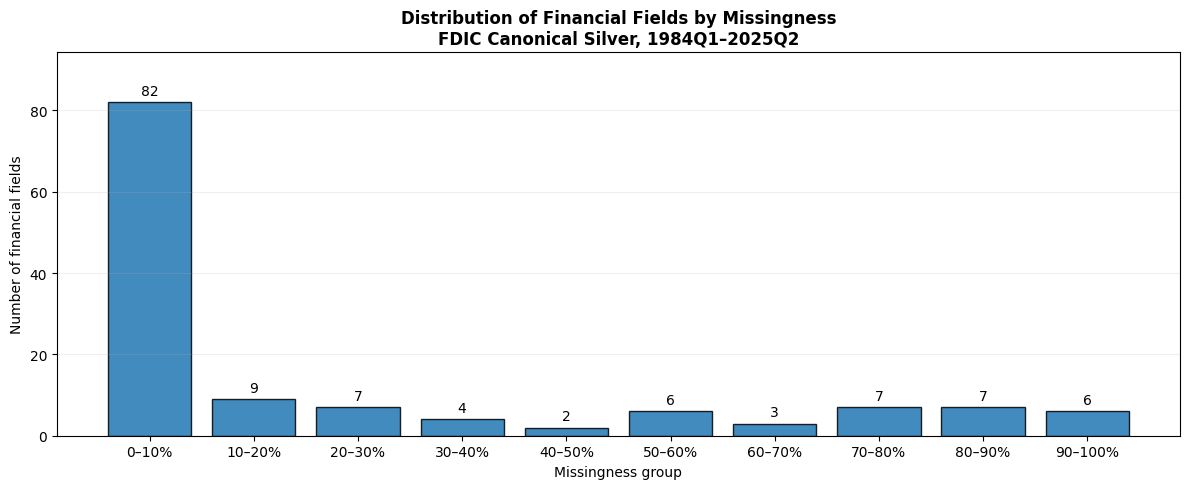

In [262]:

# ============================================================
# PHASE 4 — MISSINGNESS DISTRIBUTION CHART
# Reuse P4_MISSINGNESS_GROUPS
# ============================================================
import matplotlib.pyplot as plt
P4_MISS_PLOT = P4_MISSINGNESS_GROUPS.to_pandas()

fig, ax = plt.subplots(figsize=(12, 5))

bars = ax.bar(
    P4_MISS_PLOT["missingness_group"],
    P4_MISS_PLOT["field_count"],
    edgecolor="black",
    alpha=0.85
)

ax.bar_label(bars, padding=3)

ax.set_title(
    "Distribution of Financial Fields by Missingness\n"
    "FDIC Canonical Silver, 1984Q1–2025Q2",
    fontweight="bold"
)

ax.set_xlabel("Missingness group")
ax.set_ylabel("Number of financial fields")
ax.set_ylim(
    0,
    max(P4_MISS_PLOT["field_count"].max() * 1.15, 1)
)

ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()


#### Kết quả | Missingness theo toàn bộ lịch sử

Kiểm tra **133 trường tài chính** trên **1.665.087 bank-quarters (1984Q1–2025Q2)**. Phần lớn trường có tỷ lệ thiếu thấp, nhưng các trường chỉ xuất hiện từ một thời điểm báo cáo nhất định cần được đánh giá riêng.

**Cách đọc biểu đồ:** chiều cao cột thể hiện số trường thuộc mỗi khoảng missingness; không phản ánh mức độ quan trọng dự báo. **Quyết định:** dùng ngưỡng 60% làm bộ lọc sơ bộ, sau đó kiểm tra riêng lịch sử TRAIN để tránh giữ những trường chưa có ở giai đoạn đầu.

In [263]:

# ============================================================
# PHASE 4 — STEP 4.3.1
# MISSINGNESS REDUCTION + TEMPORAL COVERAGE AUDIT
# ============================================================

assert "P4_MISSINGNESS" in globals()
assert "SILVER" in globals()

P4_MISSING_THRESHOLD = 60.0

# 1. Preliminary exclusion using existing full-history audit
P4_EXCLUDED_MISSING = (
    P4_MISSINGNESS
    .filter(pl.col("missing_pct") >= P4_MISSING_THRESHOLD)
    .sort("missing_pct", descending=True)
)

P4_RETAINED_MISSING = (
    P4_MISSINGNESS
    .filter(pl.col("missing_pct") < P4_MISSING_THRESHOLD)
    .sort("missing_pct")
)

P4_EXCLUDED_FIELDS = P4_EXCLUDED_MISSING["field"].to_list()
P4_CANDIDATE_FIELDS = P4_RETAINED_MISSING["field"].to_list()

assert len(P4_EXCLUDED_FIELDS) == 23
assert len(P4_CANDIDATE_FIELDS) == 110
assert not (set(P4_EXCLUDED_FIELDS) & set(P4_CANDIDATE_FIELDS))

print("========== MISSINGNESS FILTER ==========")
print("Original financial fields:", len(P4_MISS_FIELDS))
print("Excluded (>=60%):", len(P4_EXCLUDED_FIELDS))
print("Retained (<60%):", len(P4_CANDIDATE_FIELDS))

print("\n========== EXCLUDED FIELDS ==========")
display(
    P4_EXCLUDED_MISSING.select(
        "field", "missing_pct", "missing_count"
    )
)

# 2. Temporal missingness for retained candidates
# TRAIN only for subsequent feature selection.
P4_TRAIN_MISSING_LF = SILVER.filter(
    pl.col("REPDTE").dt.year().is_between(1985, 2006)
)

P4_TRAIN_MISSING_STATS = (
    P4_TRAIN_MISSING_LF.select(
        pl.len().alias("__rows"),
        *[
            pl.col(f).null_count().alias(f)
            for f in P4_CANDIDATE_FIELDS
        ]
    ).collect()
)

P4_TRAIN_NROWS = int(
    P4_TRAIN_MISSING_STATS["__rows"][0]
)

P4_TRAIN_COVERAGE = pl.DataFrame([
    {
        "field": f,
        "full_history_missing_pct": float(
            P4_MISSINGNESS.filter(
                pl.col("field") == f
            )["missing_pct"][0]
        ),
        "train_missing_pct": (
            100 * int(P4_TRAIN_MISSING_STATS[f][0])
            / P4_TRAIN_NROWS
        )
    }
    for f in P4_CANDIDATE_FIELDS
]).with_columns(
    (
        pl.col("train_missing_pct")
        - pl.col("full_history_missing_pct")
    ).round(2).alias("train_vs_history_pp")
).sort("train_missing_pct", descending=True)

print("\n========== TRAIN COVERAGE: 1985–2006 ==========")
print("Training-period financial rows:", f"{P4_TRAIN_NROWS:,}")

display(P4_TRAIN_COVERAGE)

# 3. Identify candidates requiring further investigation
P4_TRAIN_HIGH_MISSING = P4_TRAIN_COVERAGE.filter(
    pl.col("train_missing_pct") >= 60
)

print("\n========== RETAINED BUT HIGH-MISSING IN TRAIN ==========")
display(P4_TRAIN_HIGH_MISSING)

print(
    "\nPASS — Preliminary exclusion applied.",
    "\nSilver source unchanged.",
    "\nNext: Investigate temporal coverage before final selection."
)


========== MISSINGNESS FILTER ==========
Original financial fields: 133
Excluded (>=60%): 23
Retained (<60%): 110

========== EXCLUDED FIELDS ==========


field,missing_pct,missing_count
str,f64,i64
"""OREOTHF""",98.998491,1648411
"""DRAGQ""",95.007588,1581959
"""NTAGQ""",95.007588,1581959
"""NTAGQA""",95.007588,1581959
"""DRAG""",95.005967,1581932
…,…,…
"""DRRECNOT""",71.836667,1196143
"""LNRECNFM""",71.836667,1196143
"""DRDEPQ""",66.699758,1110609



========== TRAIN COVERAGE: 1985–2006 ==========
Training-period financial rows: 1,123,127


field,full_history_missing_pct,train_missing_pct,train_vs_history_pp
str,f64,f64,f64
"""IOTNIIQ""",59.18982,81.250473,22.06
"""IOTNII""",57.117196,78.177713,21.06
"""DROTHQ""",56.244388,75.799264,19.55
"""NTOTHER""",56.237962,75.791963,19.55
"""DROTHER""",56.237962,75.791963,19.55
…,…,…,…
"""NIMY""",0.0,0.0,0.0
"""RBCRWAJ""",0.0,0.0,0.0
"""RBC1AAJ""",0.0,0.0,0.0



========== RETAINED BUT HIGH-MISSING IN TRAIN ==========


field,full_history_missing_pct,train_missing_pct,train_vs_history_pp
str,f64,f64,f64
"""IOTNIIQ""",59.18982,81.250473,22.06
"""IOTNII""",57.117196,78.177713,21.06
"""DROTHQ""",56.244388,75.799264,19.55
"""NTOTHER""",56.237962,75.791963,19.55
"""DROTHER""",56.237962,75.791963,19.55
"""RB2LNRES""",54.153567,73.783998,19.63
"""OTHBFHLB""",49.635304,68.208404,18.57
"""RBCT1W""",45.461168,60.89712,15.44



PASS — Preliminary exclusion applied. 
Silver source unchanged. 
Next: Investigate temporal coverage before final selection.


#### 4.3.2 | Kiểm tra riêng TRAIN

Bộ lọc toàn lịch sử giữ **110/133** trường; thêm **8 trường** thiếu từ 60% trở lên trong TRAIN 1985–2006 được tạm hoãn. Còn **102** trường để phân tích độ ổn định theo năm. Đây là quy tắc *screening*, chưa phải feature selection cuối cùng.

In [264]:

# ============================================================
# PHASE 4 — STEP 4.3.3
# ANNUAL MISSINGNESS & HISTORICAL STABILITY
# Training period: 1985–2006
# ============================================================

assert all(
    x in globals()
    for x in [
        "SILVER",
        "P4_CANDIDATE_FIELDS",
        "P4_TRAIN_COVERAGE"
    ]
)

# 1. Defer candidates with >=60% missingness in TRAIN
P4_TRAIN_DEFERRED_FIELDS = (
    P4_TRAIN_COVERAGE
    .filter(pl.col("train_missing_pct") >= 60)
    ["field"].to_list()
)

P4_BASELINE_FIELDS = [
    f for f in P4_CANDIDATE_FIELDS
    if f not in set(P4_TRAIN_DEFERRED_FIELDS)
]

assert len(P4_TRAIN_DEFERRED_FIELDS) == 8
assert len(P4_BASELINE_FIELDS) == 102

# 2. Annual missingness, TRAIN only
P4_ANNUAL_MISSING = (
    SILVER
    .filter(
        pl.col("REPDTE").dt.year().is_between(
            1985, 2006
        )
    )
    .group_by(
        pl.col("REPDTE").dt.year().alias("YEAR")
    )
    .agg(
        pl.len().alias("observations"),
        *[
            (
                pl.col(f).is_null().mean() * 100
            ).round(3).alias(f)
            for f in P4_BASELINE_FIELDS
        ]
    )
    .sort("YEAR")
    .collect()
)

assert P4_ANNUAL_MISSING.height == 22

# 3. Summarize stability across all training years
P4_ANNUAL_STABILITY = pl.DataFrame([
    {
        "field": f,
        "avg_annual_missing_pct": round(
            P4_ANNUAL_MISSING[f].mean(), 3
        ),
        "worst_year_missing_pct": round(
            P4_ANNUAL_MISSING[f].max(), 3
        ),
        "years_above_20pct": int(
            (P4_ANNUAL_MISSING[f] >= 20).sum()
        ),
        "years_above_60pct": int(
            (P4_ANNUAL_MISSING[f] >= 60).sum()
        ),
        "years_below_5pct": int(
            (P4_ANNUAL_MISSING[f] < 5).sum()
        )
    }
    for f in P4_BASELINE_FIELDS
]).with_columns(
    pl.when(pl.col("worst_year_missing_pct") < 5)
      .then(pl.lit("STABLE_95_ALL_YEARS"))
      .when(pl.col("years_above_60pct") > 0)
      .then(pl.lit("REGIME_DEPENDENT"))
      .when(pl.col("years_above_20pct") > 0)
      .then(pl.lit("MODERATE_INSTABILITY"))
      .otherwise(pl.lit("BROAD_COVERAGE"))
      .alias("coverage_status")
).sort(
    "worst_year_missing_pct",
    descending=True
)

# 4. Summary
P4_STABILITY_SUMMARY = (
    P4_ANNUAL_STABILITY
    .group_by("coverage_status")
    .agg(pl.len().alias("fields"))
    .sort("coverage_status")
)

print("========== FEATURE REDUCTION ==========")
print("Original:", 133)
print("Full-history excluded:", len(P4_EXCLUDED_FIELDS))
print("Training-period deferred:", len(P4_TRAIN_DEFERRED_FIELDS))
print("Baseline candidates:", len(P4_BASELINE_FIELDS))

print("\n========== ANNUAL STABILITY SUMMARY ==========")
display(P4_STABILITY_SUMMARY)

print("\n========== FIELD-LEVEL STABILITY ==========")
display(P4_ANNUAL_STABILITY)

print("\n========== REGIME-DEPENDENT FIELDS ==========")
display(
    P4_ANNUAL_STABILITY.filter(
        pl.col("coverage_status") == "REGIME_DEPENDENT"
    )
)

print("\nPASS — Annual coverage evaluated for 1985–2006.")
print("No additional fields automatically removed.")


========== FEATURE REDUCTION ==========
Original: 133
Full-history excluded: 23
Training-period deferred: 8
Baseline candidates: 102

========== ANNUAL STABILITY SUMMARY ==========


coverage_status,fields
str,u32
"""BROAD_COVERAGE""",26
"""MODERATE_INSTABILITY""",15
"""REGIME_DEPENDENT""",11
"""STABLE_95_ALL_YEARS""",50



========== FIELD-LEVEL STABILITY ==========


field,avg_annual_missing_pct,worst_year_missing_pct,years_above_20pct,years_above_60pct,years_below_5pct,coverage_status
str,f64,f64,i64,i64,i64,str
"""RBCT2""",22.787,100.0,5,5,17,"""REGIME_DEPENDENT"""
"""DRRERES""",26.329,100.0,6,6,16,"""REGIME_DEPENDENT"""
"""DRRENRES""",26.684,100.0,6,6,16,"""REGIME_DEPENDENT"""
"""DRREMULT""",26.684,100.0,6,6,16,"""REGIME_DEPENDENT"""
"""DRRELOCQ""",26.684,100.0,6,6,16,"""REGIME_DEPENDENT"""
…,…,…,…,…,…,…
"""NIMY""",0.0,0.0,0,0,22,"""STABLE_95_ALL_YEARS"""
"""RBCRWAJ""",0.0,0.0,0,0,22,"""STABLE_95_ALL_YEARS"""
"""RBC1AAJ""",0.0,0.0,0,0,22,"""STABLE_95_ALL_YEARS"""



========== REGIME-DEPENDENT FIELDS ==========


field,avg_annual_missing_pct,worst_year_missing_pct,years_above_20pct,years_above_60pct,years_below_5pct,coverage_status
str,f64,f64,i64,i64,i64,str
"""RBCT2""",22.787,100.0,5,5,17,"""REGIME_DEPENDENT"""
"""DRRERES""",26.329,100.0,6,6,16,"""REGIME_DEPENDENT"""
"""DRRENRES""",26.684,100.0,6,6,16,"""REGIME_DEPENDENT"""
"""DRREMULT""",26.684,100.0,6,6,16,"""REGIME_DEPENDENT"""
"""DRRELOCQ""",26.684,100.0,6,6,16,"""REGIME_DEPENDENT"""
…,…,…,…,…,…,…
"""DRRECONS""",26.684,100.0,6,6,16,"""REGIME_DEPENDENT"""
"""NTREAG""",35.772,100.0,6,6,0,"""REGIME_DEPENDENT"""
"""NTCOMRE""",35.772,100.0,6,6,0,"""REGIME_DEPENDENT"""



PASS — Annual coverage evaluated for 1985–2006.
No additional fields automatically removed.


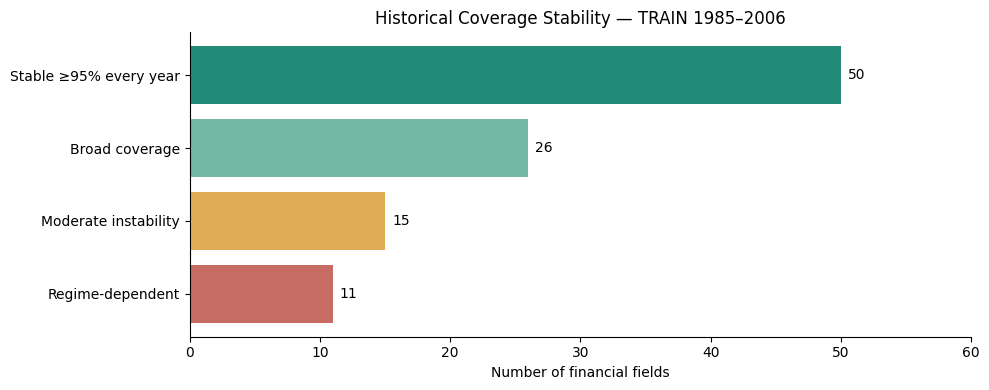

In [265]:

# 4.3.4A — Historical Stability Distribution

assert "P4_STABILITY_SUMMARY" in globals()
assert "plt" in globals(), "Matplotlib pyplot (plt) is required."

order = [
    "STABLE_95_ALL_YEARS",
    "BROAD_COVERAGE",
    "MODERATE_INSTABILITY",
    "REGIME_DEPENDENT"
]

counts = {
    row["coverage_status"]: row["fields"]
    for row in P4_STABILITY_SUMMARY.to_dicts()
}

values = [counts.get(s, 0) for s in order]
labels = [
    "Stable ≥95% every year",
    "Broad coverage",
    "Moderate instability",
    "Regime-dependent"
]

fig, ax = plt.subplots(figsize=(10, 4))

bars = ax.barh(
    labels,
    values,
    color=["#238B78", "#72B7A1", "#E2AC57", "#C76B65"]
)

ax.invert_yaxis()
ax.bar_label(bars, padding=5)
ax.set_xlim(0, max(values) * 1.2)
ax.set_xlabel("Number of financial fields")
ax.set_title(
    "Historical Coverage Stability — TRAIN 1985–2006"
)

ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


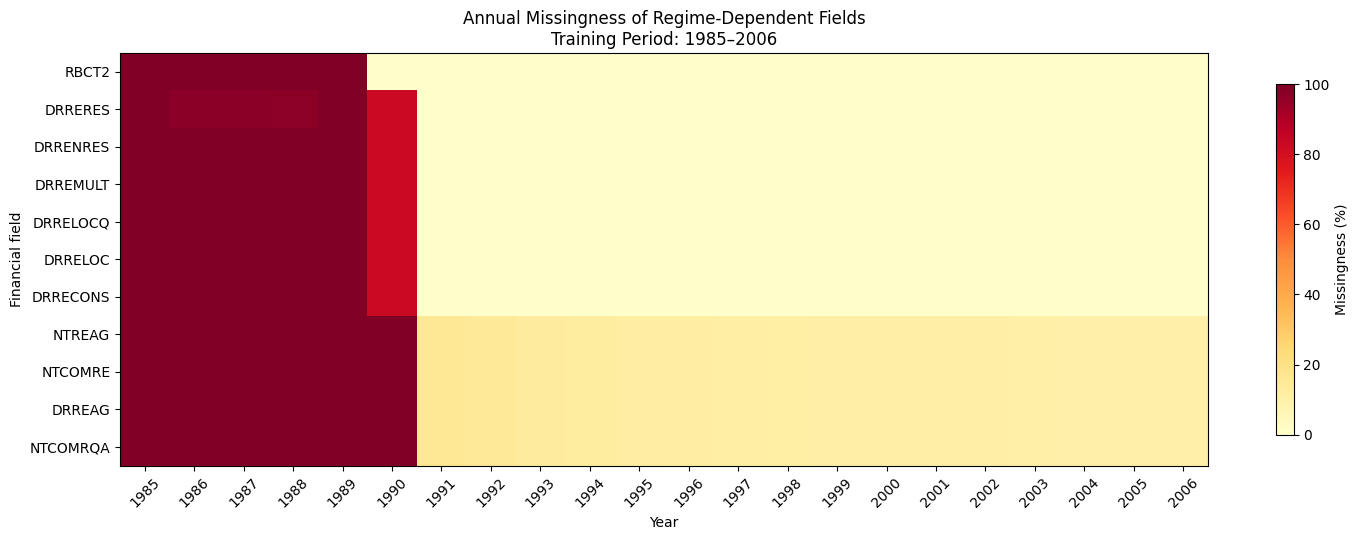

In [266]:

# 4.3.4B — Regime-Dependent Missingness Heatmap

assert "P4_ANNUAL_MISSING" in globals()
assert "P4_ANNUAL_STABILITY" in globals()

regime_fields = (
    P4_ANNUAL_STABILITY
    .filter(pl.col("coverage_status") == "REGIME_DEPENDENT")
    ["field"].to_list()
)

heatmap_df = (
    P4_ANNUAL_MISSING
    .select(["YEAR"] + regime_fields)
    .to_pandas()
    .set_index("YEAR")
    .T
)

fig, ax = plt.subplots(figsize=(15, 5.5))

im = ax.imshow(
    heatmap_df.to_numpy(),
    aspect="auto",
    cmap="YlOrRd",
    vmin=0,
    vmax=100
)

ax.set_yticks(range(len(heatmap_df.index)))
ax.set_yticklabels(heatmap_df.index)

ax.set_xticks(range(len(heatmap_df.columns)))
ax.set_xticklabels(
    heatmap_df.columns,
    rotation=45
)

ax.set_title(
    "Annual Missingness of Regime-Dependent Fields\n"
    "Training Period: 1985–2006"
)

ax.set_xlabel("Year")
ax.set_ylabel("Financial field")

fig.colorbar(
    im, ax=ax,
    label="Missingness (%)",
    shrink=0.85
)

plt.tight_layout()
plt.show()


#### 4.3.4 | Độ phủ theo năm và thay đổi reporting regime

Trong 102 trường được xem xét, **50 trường đạt coverage ≥95% ở mọi năm TRAIN** và **26 trường có độ phủ rộng**; tổng cộng 76 trường tạo nhóm ưu tiên ban đầu.

Biểu đồ phân nhóm cho thấy độ phủ theo thời gian không đồng đều. Heatmap giúp nhận diện các trường xuất hiện sau thay đổi báo cáo, đặc biệt `RBCT2` (khoảng 1990) và các trường `DRRE*` (khoảng 1991). **Không suy diễn các giá trị thiếu trước khi được báo cáo là bằng 0.**

**Ý nghĩa cho modeling:** một biến có missingness thấp trên dữ liệu gộp vẫn có thể không dùng được trong training window sớm. Các trường phụ thuộc reporting regime được tạm hoãn thay vì loại bỏ vĩnh viễn.

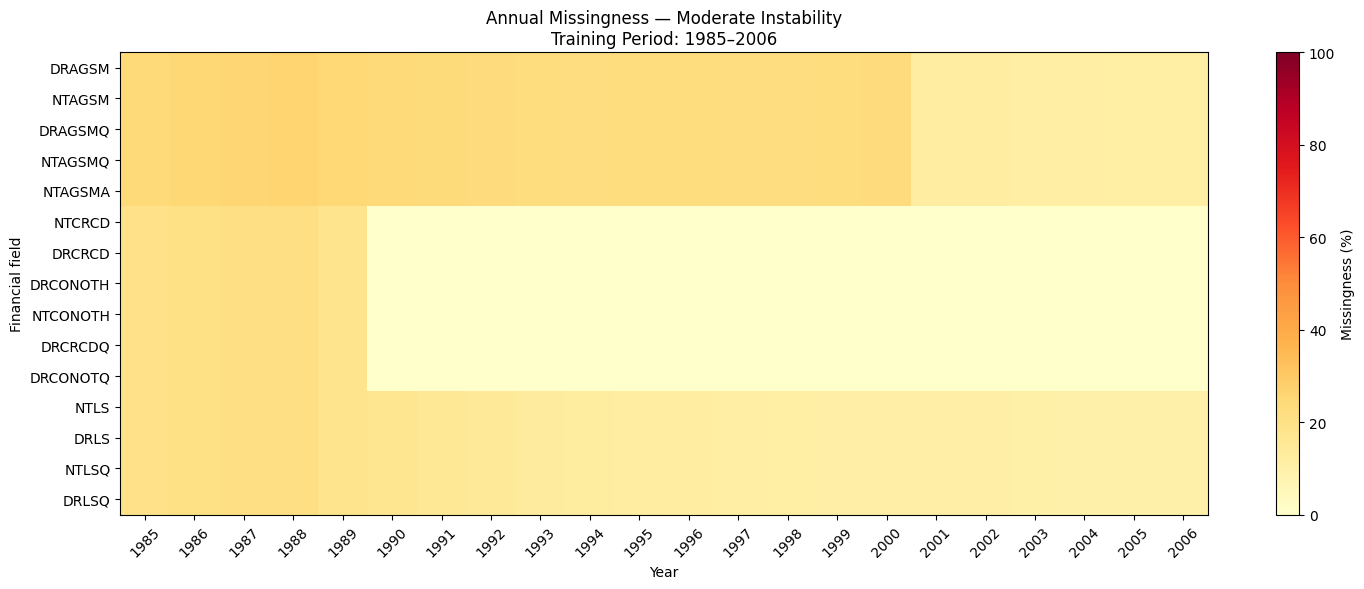

========== MODERATE INSTABILITY DIAGNOSTICS ==========


field,train_missing_pct,worst_year_pct,years_ge_20pct,first_year_ge_20pct,last_year_ge_20pct
str,f64,f64,i64,i64,i64
"""DRAGSMQ""",21.38,26.55,16,1985,2000
"""NTAGSMQ""",21.38,26.55,16,1985,2000
"""NTAGSMA""",21.38,26.55,16,1985,2000
"""DRAGSM""",21.36,26.55,16,1985,2000
"""NTAGSM""",21.36,26.55,16,1985,2000
…,…,…,…,…,…
"""DRCRCD""",6.41,21.07,3,1986,1988
"""DRCONOTH""",6.41,21.07,3,1986,1988
"""NTCONOTH""",6.41,21.07,3,1986,1988


In [267]:

# ============================================================
# PHASE 4 — STEP 4.3.5A
# MODERATE INSTABILITY: ANNUAL MISSINGNESS HEATMAP
# Reuse existing results; no imports or repeated scans
# ============================================================

P4_MODERATE_FIELDS = (
    P4_ANNUAL_STABILITY
    .filter(pl.col("coverage_status") == "MODERATE_INSTABILITY")
    .get_column("field")
    .to_list()
)

assert len(P4_MODERATE_FIELDS) == 15

P4_MODERATE_HEATMAP = (
    P4_ANNUAL_MISSING
    .select(["YEAR"] + P4_MODERATE_FIELDS)
    .to_pandas()
    .set_index("YEAR")
    .T
)

fig, ax = plt.subplots(figsize=(15, 6))

im = ax.imshow(
    P4_MODERATE_HEATMAP.to_numpy(),
    aspect="auto",
    cmap="YlOrRd",
    vmin=0,
    vmax=100
)

ax.set_yticks(range(len(P4_MODERATE_FIELDS)))
ax.set_yticklabels(P4_MODERATE_FIELDS)

ax.set_xticks(range(len(P4_MODERATE_HEATMAP.columns)))
ax.set_xticklabels(
    P4_MODERATE_HEATMAP.columns,
    rotation=45
)

ax.set_xlabel("Year")
ax.set_ylabel("Financial field")
ax.set_title(
    "Annual Missingness — Moderate Instability\n"
    "Training Period: 1985–2006"
)

fig.colorbar(im, ax=ax, label="Missingness (%)")
plt.tight_layout()
plt.show()

# ============================================================
# PHASE 4 — STEP 4.3.5B
# MODERATE FIELDS: TEMPORAL DIAGNOSTICS
# ============================================================

P4_MODERATE_DIAGNOSTICS = pl.DataFrame([
    {
        "field": field,
        "train_missing_pct": round(
            float(
                P4_TRAIN_COVERAGE
                .filter(pl.col("field") == field)
                ["train_missing_pct"][0]
            ), 2
        ),
        "worst_year_pct": round(
            float(P4_ANNUAL_MISSING[field].max()), 2
        ),
        "years_ge_20pct": int(
            (P4_ANNUAL_MISSING[field] >= 20).sum()
        ),
        "first_year_ge_20pct": (
            P4_ANNUAL_MISSING
            .filter(pl.col(field) >= 20)
            .get_column("YEAR")
            .min()
        ),
        "last_year_ge_20pct": (
            P4_ANNUAL_MISSING
            .filter(pl.col(field) >= 20)
            .get_column("YEAR")
            .max()
        )
    }
    for field in P4_MODERATE_FIELDS
]).sort("train_missing_pct", descending=True)

print("========== MODERATE INSTABILITY DIAGNOSTICS ==========")
display(P4_MODERATE_DIAGNOSTICS)



#### 4.3.5 | Nhóm thiếu vừa phải

Các trường thiếu vừa phải thường cải thiện coverage theo thời gian thay vì vắng mặt hoàn toàn. Nhóm `DRAGSM*`/`NTAGSM*` thiếu khoảng **21,4%** trong TRAIN, cải thiện sau năm 2000. Kết luận: kiểm tra theo năm và theo ngân hàng trước khi diễn giải missingness như một tín hiệu kinh tế.

In [268]:

# ============================================================
# PHASE 4 — STEP 4.3.6
# FREEZE PRELIMINARY BASELINE CANDIDATE POOL
# ============================================================

assert "P4_ANNUAL_STABILITY" in globals()

P4_BASELINE_CANDIDATES_91 = (
    P4_ANNUAL_STABILITY
    .filter(
        pl.col("coverage_status").is_in([
            "STABLE_95_ALL_YEARS",
            "BROAD_COVERAGE",
            "MODERATE_INSTABILITY"
        ])
    )
    .get_column("field")
    .to_list()
)

P4_DEFERRED_REGIME_11 = (
    P4_ANNUAL_STABILITY
    .filter(
        pl.col("coverage_status") == "REGIME_DEPENDENT"
    )
    .get_column("field")
    .to_list()
)

assert len(P4_BASELINE_CANDIDATES_91) == 91
assert len(P4_DEFERRED_REGIME_11) == 11

assert not (
    set(P4_BASELINE_CANDIDATES_91)
    & set(P4_DEFERRED_REGIME_11)
)

print("========== PHASE 4 FEATURE SCREENING ==========")
print("Original source fields: 133")
print("Missing >=60% full history: 23")
print("Missing >=60% TRAIN: 8")
print("Regime-dependent deferred: 11")
print("Baseline candidates:", len(P4_BASELINE_CANDIDATES_91))

print("\nPASS — Preliminary 91-field candidate pool established.")
print("Next: Financial integrity and CAMELS domain screening.")


========== PHASE 4 FEATURE SCREENING ==========
Original source fields: 133
Missing >=60% full history: 23
Missing >=60% TRAIN: 8
Regime-dependent deferred: 11
Baseline candidates: 91

PASS — Preliminary 91-field candidate pool established.
Next: Financial integrity and CAMELS domain screening.


#### 4.3 | Screening attrition  `[VIZ]`

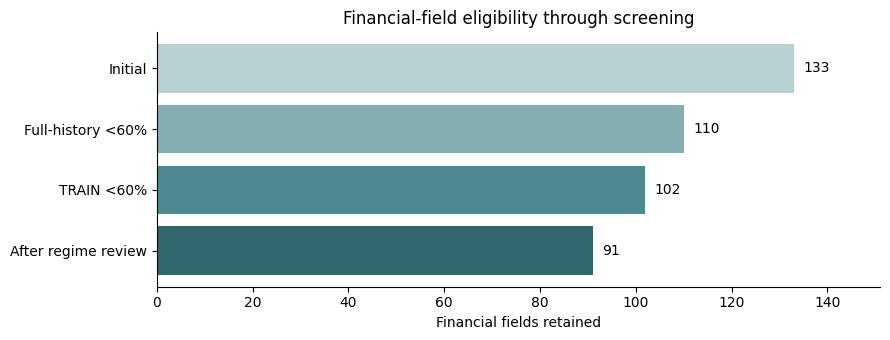

In [269]:
# VIZ ONLY — confirmed counts from the preceding screening summaries
import matplotlib.pyplot as plt
stages = ["Initial", "Full-history <60%", "TRAIN <60%", "After regime review"]
counts = [len(P4_MISS_FIELDS), len(P4_CANDIDATE_FIELDS),
          len(P4_BASELINE_FIELDS), len(P4_BASELINE_CANDIDATES_91)]
fig, ax = plt.subplots(figsize=(9, 3.5))
bars = ax.barh(stages[::-1], counts[::-1], color=["#32676d", "#4f8990", "#85aeb2", "#b8d1d3"])
for bar, val in zip(bars, counts[::-1]):
    ax.text(val + 2, bar.get_y() + bar.get_height()/2, str(val), va="center", fontsize=10)
ax.set_xlim(0, 151)
ax.set_xlabel("Financial fields retained")
ax.set_title("Financial-field eligibility through screening")
ax.spines[["right", "top"]].set_visible(False)
plt.tight_layout()
plt.show()

**Diễn giải:** phần giảm mạnh đầu tiên đến từ missingness toàn lịch sử; các bước sau phản ánh thiếu trong TRAIN và coverage bị ngắt theo reporting regime. Đây là **quy trình sàng lọc nguồn dữ liệu**, không phải bằng chứng rằng các trường bị hoãn có giá trị dự báo kém.

<a id="p4-44"></a>

## 4.4 | Financial integrity và redundancy  `[SECTION]`

Xem giá trị không hữu hạn, số âm hợp lệ về kế toán, tỷ lệ zero và các cặp gần trùng.

#### Mục tiêu của Financial Integrity Audit

**Mục tiêu:** rà soát null/NaN/Inf, giá trị bằng 0, số âm và những nhóm trường có quan hệ gần trùng trên **91 trường sơ bộ** trong TRAIN 1985–2006.

**Nguyên tắc:** số âm hoặc số 0 có thể hợp lệ về kế toán; chỉ đánh dấu để kiểm tra, không tự ý sửa dữ liệu.

In [270]:

# ============================================================
# PHASE 4 — STEP 4.4A
# FINANCIAL VALUE INTEGRITY — TRAIN 1985–2006
# ============================================================

assert "SILVER" in globals()
assert "P4_BASELINE_CANDIDATES_91" in globals()

P4_INTEGRITY_FIELDS = P4_BASELINE_CANDIDATES_91

P4_INTEGRITY_LF = SILVER.filter(
    pl.col("REPDTE").dt.year().is_between(1985, 2006)
)

P4_INTEGRITY_RAW = P4_INTEGRITY_LF.select(
    pl.len().alias("__rows"),
    *[
        expr.alias(f"{f}__{kind}")
        for f in P4_INTEGRITY_FIELDS
        for kind, expr in [
            ("null", pl.col(f).is_null().sum()),
            ("nan", pl.col(f).is_nan().fill_null(False).sum()),
            ("inf", pl.col(f).is_infinite().fill_null(False).sum()),
            ("zero", (pl.col(f) == 0).fill_null(False).sum()),
            ("negative", (pl.col(f) < 0).fill_null(False).sum())
        ]
    ]
).collect()

P4_INTEGRITY_N = int(P4_INTEGRITY_RAW["__rows"][0])

P4_INTEGRITY_AUDIT = pl.DataFrame([
    {
        "field": f,
        "null_pct": round(
            100 * P4_INTEGRITY_RAW[f"{f}__null"][0]
            / P4_INTEGRITY_N, 2
        ),
        "nan_count": int(P4_INTEGRITY_RAW[f"{f}__nan"][0]),
        "inf_count": int(P4_INTEGRITY_RAW[f"{f}__inf"][0]),
        "zero_pct": round(
            100 * P4_INTEGRITY_RAW[f"{f}__zero"][0]
            / P4_INTEGRITY_N, 2
        ),
        "negative_pct": round(
            100 * P4_INTEGRITY_RAW[f"{f}__negative"][0]
            / P4_INTEGRITY_N, 2
        )
    }
    for f in P4_INTEGRITY_FIELDS
])

print("TRAIN observations:", f"{P4_INTEGRITY_N:,}")
print("Fields audited:", P4_INTEGRITY_AUDIT.height)

print("\n========== INTEGRITY SUMMARY ==========")

display(pl.DataFrame([{
    "fields_with_nan": int(
        (P4_INTEGRITY_AUDIT["nan_count"] > 0).sum()
    ),
    "fields_with_inf": int(
        (P4_INTEGRITY_AUDIT["inf_count"] > 0).sum()
    ),
    "fields_with_negative": int(
        (P4_INTEGRITY_AUDIT["negative_pct"] > 0).sum()
    ),
    "fields_over_90pct_zero": int(
        (P4_INTEGRITY_AUDIT["zero_pct"] > 90).sum()
    )
}]))

print("\n========== NON-FINITE FIELDS ==========")
display(
    P4_INTEGRITY_AUDIT.filter(
        (pl.col("nan_count") > 0)
        | (pl.col("inf_count") > 0)
    )
)

print("\n========== TOP 15 ZERO-HEAVY FIELDS ==========")
display(
    P4_INTEGRITY_AUDIT
    .sort("zero_pct", descending=True)
    .head(15)
    .select("field", "zero_pct", "null_pct")
)

print("\n========== TOP 15 NEGATIVE-HEAVY FIELDS ==========")
display(
    P4_INTEGRITY_AUDIT
    .sort("negative_pct", descending=True)
    .head(15)
    .select("field", "negative_pct", "null_pct")
)

print("\nPASS — Financial integrity profiling completed.")
print("No values modified; no fields removed.")


TRAIN observations: 1,123,127
Fields audited: 91

========== INTEGRITY SUMMARY ==========


fields_with_nan,fields_with_inf,fields_with_negative,fields_over_90pct_zero
i64,i64,i64,i64
0,0,69,2



========== NON-FINITE FIELDS ==========


field,null_pct,nan_count,inf_count,zero_pct,negative_pct
str,f64,i64,i64,f64,f64



========== TOP 15 ZERO-HEAVY FIELDS ==========


field,zero_pct,null_pct
str,f64,f64
"""NTALLOTHQR""",92.63,0.0
"""NTALLOTHNUM""",91.25,0.0
"""BRO""",87.04,0.24
"""DRLSQ""",83.23,14.81
"""DRLS""",82.78,14.8
…,…,…
"""DRCRCDQ""",75.4,6.41
"""DRAGSMQ""",71.67,21.38
"""DRCRCD""",71.63,6.41



========== TOP 15 NEGATIVE-HEAVY FIELDS ==========


field,negative_pct,null_pct
str,f64,f64
"""NTCI""",19.02,5.92
"""NTLNLSQ""",18.84,5.82
"""NTLNLSQA""",18.84,5.82
"""NTLNLSQR""",18.28,6.74
"""NTLNLSR""",16.99,0.0
…,…,…
"""NTREQA""",11.84,5.82
"""NTREQ""",11.84,5.82
"""NTREQR""",11.04,7.36



PASS — Financial integrity profiling completed.
No values modified; no fields removed.


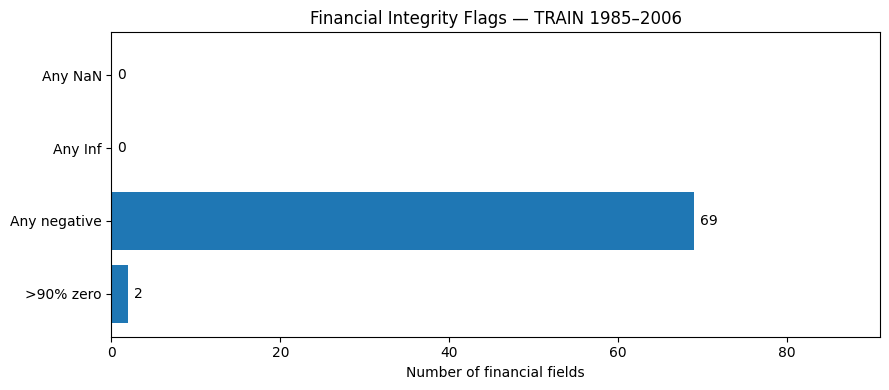

In [271]:

# 4.4B — Financial Integrity Overview

p4_metrics = [
    ("Any NaN", int((P4_INTEGRITY_AUDIT["nan_count"] > 0).sum())),
    ("Any Inf", int((P4_INTEGRITY_AUDIT["inf_count"] > 0).sum())),
    ("Any negative", int((P4_INTEGRITY_AUDIT["negative_pct"] > 0).sum())),
    (">90% zero", int((P4_INTEGRITY_AUDIT["zero_pct"] > 90).sum()))
]

fig, ax = plt.subplots(figsize=(9, 4))

bars = ax.barh(
    [m[0] for m in p4_metrics],
    [m[1] for m in p4_metrics]
)

ax.bar_label(bars, padding=4)
ax.invert_yaxis()
ax.set_xlabel("Number of financial fields")
ax.set_title("Financial Integrity Flags — TRAIN 1985–2006")
ax.set_xlim(0, 91)
plt.tight_layout()
plt.show()


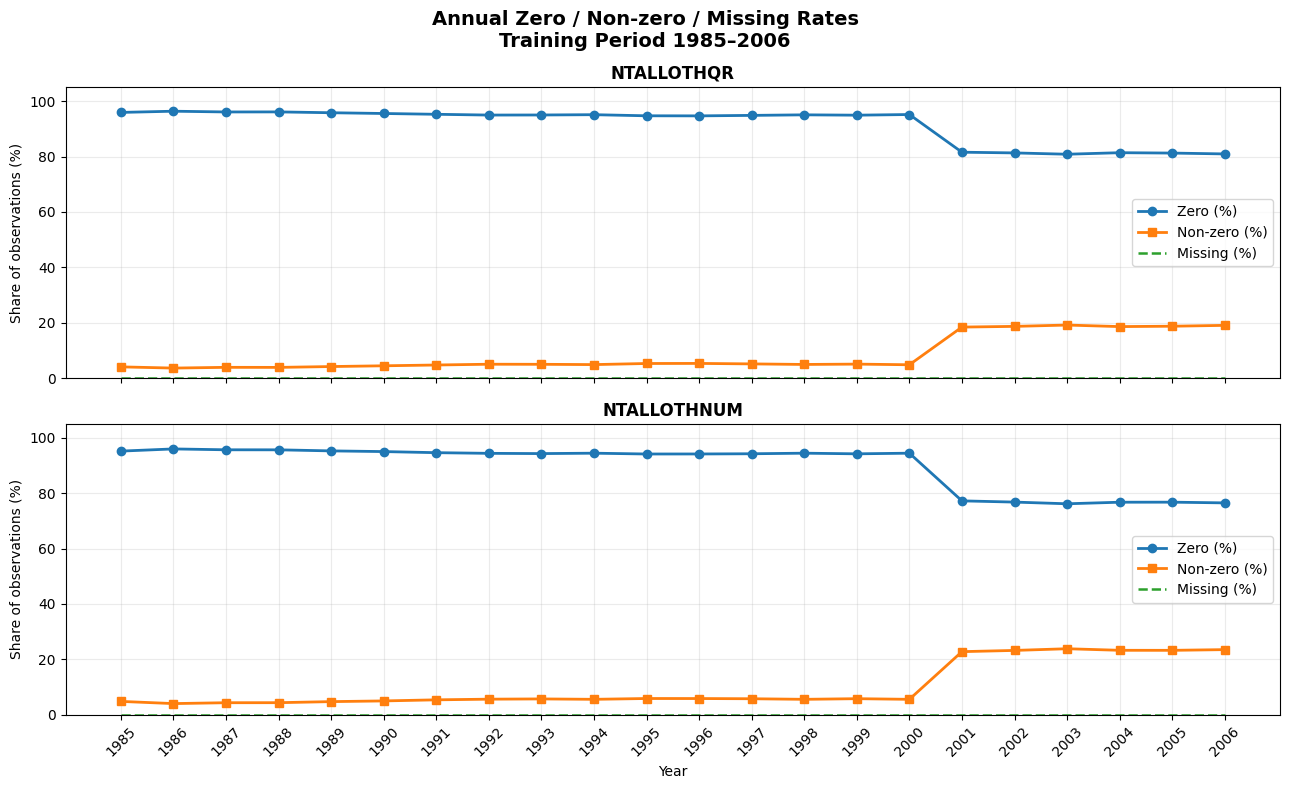

========== ZERO-RATE DIAGNOSTICS ==========
NTALLOTHQR: zero-rate range 80.84%–96.38% | max non-zero rate 19.16%
NTALLOTHNUM: zero-rate range 76.17%–95.98% | max non-zero rate 23.83%


In [272]:

# ============================================================
# PHASE 4 — STEP 4.4C
# ZERO-RATE TRENDS: NTALLOTHQR vs NTALLOTHNUM
# TRAIN: 1985–2006
# ============================================================

assert "P4_INTEGRITY_LF" in globals()
assert "plt" in globals()

P4_ZERO_FIELDS = ["NTALLOTHQR", "NTALLOTHNUM"]

# Annual aggregation — one scan
P4_ZERO_ANNUAL = (
    P4_INTEGRITY_LF
    .group_by(pl.col("REPDTE").dt.year().alias("YEAR"))
    .agg(
        pl.len().alias("observations"),
        *[
            (
                (pl.col(f) == 0)
                .fill_null(False)
                .mean() * 100
            ).alias(f"{f}_zero_pct")
            for f in P4_ZERO_FIELDS
        ],
        *[
            (
                (pl.col(f).is_not_null() & (pl.col(f) != 0))
                .fill_null(False)
                .mean() * 100
            ).alias(f"{f}_nonzero_pct")
            for f in P4_ZERO_FIELDS
        ],
        *[
            (
                pl.col(f).is_null()
                .mean() * 100
            ).alias(f"{f}_missing_pct")
            for f in P4_ZERO_FIELDS
        ]
    )
    .sort("YEAR")
    .collect()
)

# Visualization
fig, axes = plt.subplots(
    2, 1, figsize=(13, 8),
    sharex=True, sharey=True
)

years = P4_ZERO_ANNUAL["YEAR"].to_list()

for ax, field in zip(axes, P4_ZERO_FIELDS):

    zero = P4_ZERO_ANNUAL[f"{field}_zero_pct"].to_list()
    nonzero = P4_ZERO_ANNUAL[f"{field}_nonzero_pct"].to_list()
    missing = P4_ZERO_ANNUAL[f"{field}_missing_pct"].to_list()

    ax.plot(
        years, zero, marker="o",
        linewidth=2, label="Zero (%)"
    )
    ax.plot(
        years, nonzero, marker="s",
        linewidth=2, label="Non-zero (%)"
    )
    ax.plot(
        years, missing, linestyle="--",
        linewidth=1.8, label="Missing (%)"
    )

    ax.set_title(field, fontweight="bold")
    ax.set_ylabel("Share of observations (%)")
    ax.set_ylim(0, 105)
    ax.grid(alpha=0.25)
    ax.legend(loc="center right")

axes[-1].set_xlabel("Year")
axes[-1].set_xticks(years)
axes[-1].tick_params(axis="x", rotation=45)

fig.suptitle(
    "Annual Zero / Non-zero / Missing Rates\n"
    "Training Period 1985–2006",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# Compact diagnostics
print("========== ZERO-RATE DIAGNOSTICS ==========")

for field in P4_ZERO_FIELDS:
    z = P4_ZERO_ANNUAL[f"{field}_zero_pct"]
    nz = P4_ZERO_ANNUAL[f"{field}_nonzero_pct"]

    print(
        f"{field}: "
        f"zero-rate range {z.min():.2f}%–{z.max():.2f}% | "
        f"max non-zero rate {nz.max():.2f}%"
    )


#### 4.4C | Biến có tỷ lệ zero cao

`NTALLOTHNUM` và `NTALLOTHQR` có thay đổi tỷ lệ khác 0 quanh **2001**. Đây có thể liên quan đến thay đổi định nghĩa/báo cáo Call Report, không đủ cơ sở để kết luận lỗi dữ liệu. Đọc hai đường theo **xu hướng thời gian**, tránh chỉ so sánh tỷ lệ zero trên toàn bộ mẫu.

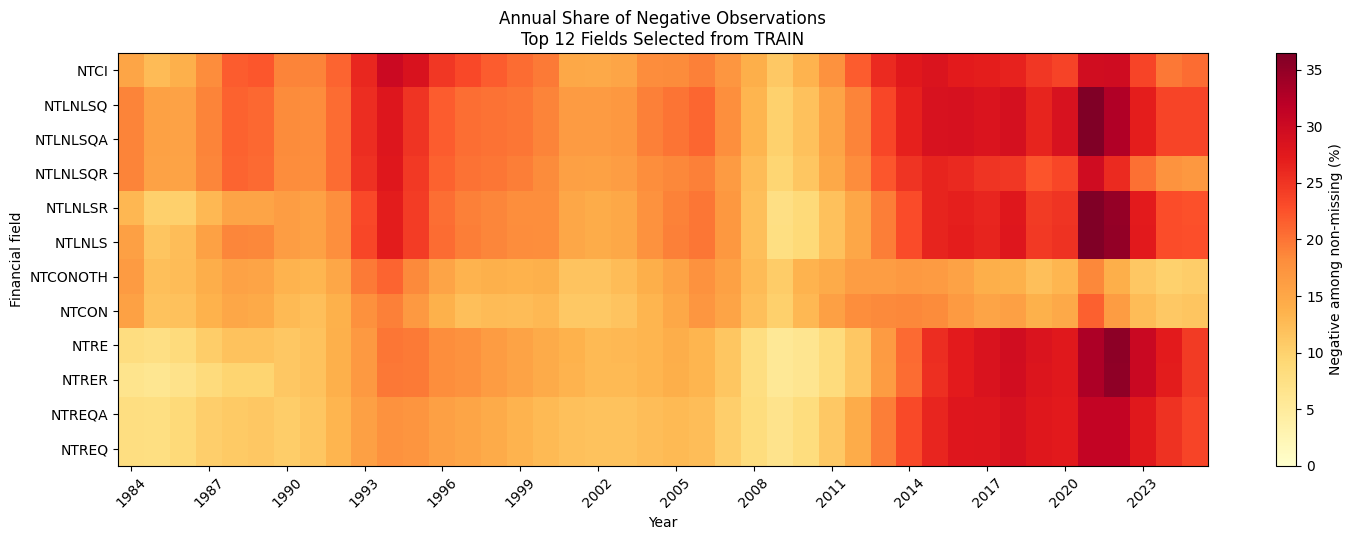

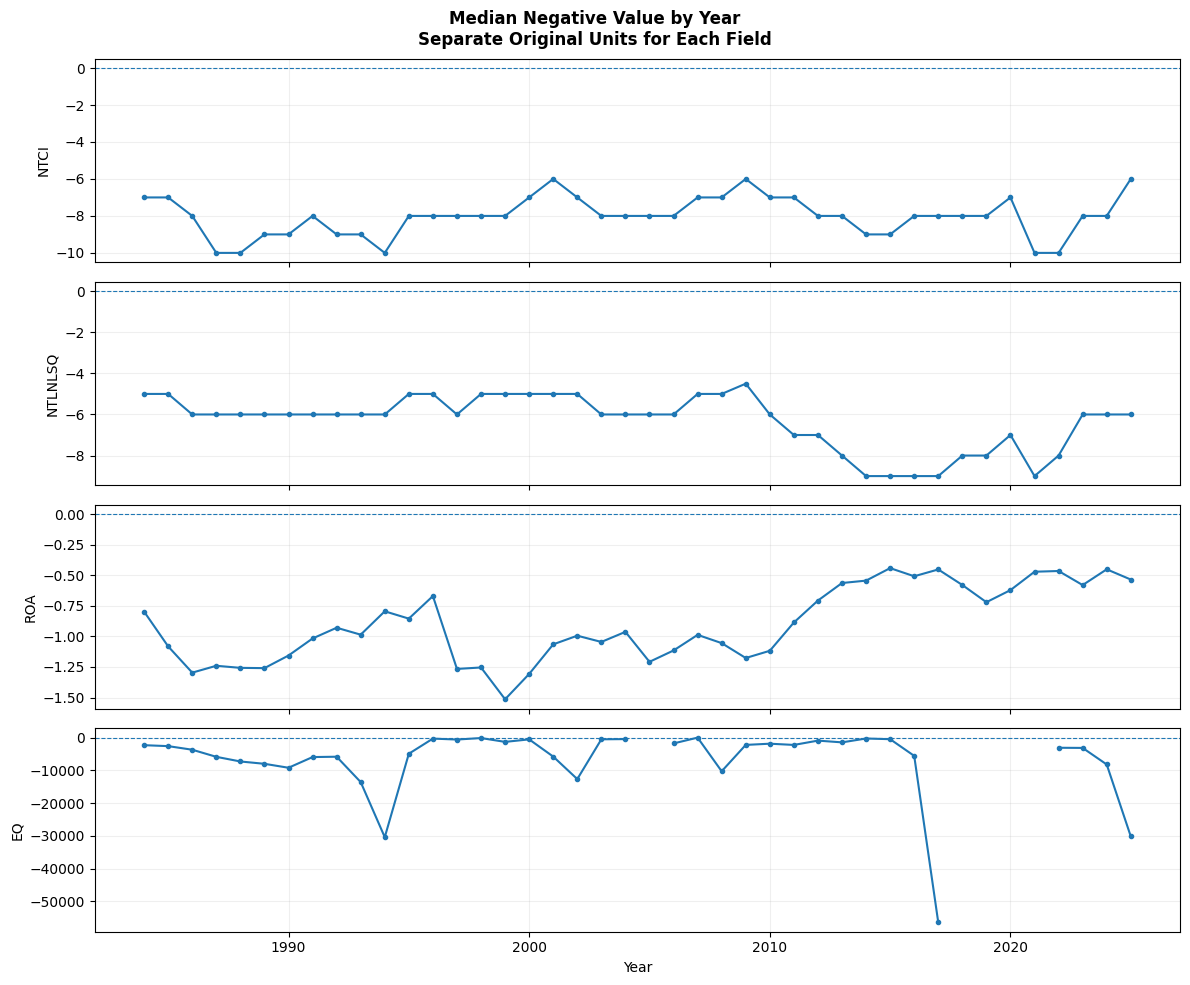

Fields analyzed: 89
Annual periods: 42
Top negative fields: ['NTCI', 'NTLNLSQ', 'NTLNLSQA', 'NTLNLSQR', 'NTLNLSR', 'NTLNLS', 'NTCONOTH', 'NTCON', 'NTRE', 'NTRER', 'NTREQA', 'NTREQ']


In [273]:

# ============================================================
# 4.4D — NEGATIVE VALUES: FREQUENCY & SEVERITY
# Full-history descriptive audit: 1984Q1–2025Q2
# ============================================================

assert all(x in globals() for x in [
    "SILVER", "P4_INTEGRITY_AUDIT",
    "P4_BASELINE_CANDIDATES_91", "plt"
])

# Exclude the two previously deferred zero-heavy variables
P4_NEG_ACTIVE = [
    f for f in P4_BASELINE_CANDIDATES_91
    if f not in {"NTALLOTHQR", "NTALLOTHNUM"}
]

P4_NEG_TOP = (
    P4_INTEGRITY_AUDIT
    .filter(
        pl.col("field").is_in(P4_NEG_ACTIVE)
        & (pl.col("negative_pct") > 0)
    )
    .sort("negative_pct", descending=True)
    .get_column("field").to_list()
)

P4_NEG_TOP12 = P4_NEG_TOP[:12]

# Each severity plot uses its own units.
P4_NEG_SEVERITY_FIELDS = [
    f for f in ["NTCI", "NTLNLSQ", "ROA", "EQ"]
    if f in P4_NEG_ACTIVE
]

# One lazy columnar aggregation for all 89 candidates
P4_NEG_YEARLY = (
    SILVER
    .filter(
        pl.col("REPDTE").is_between(
            pl.date(1984, 1, 1),
            pl.date(2025, 6, 30)
        )
    )
    .group_by(
        pl.col("REPDTE").dt.year().alias("YEAR")
    )
    .agg(
        pl.len().alias("rows"),
        *[
            pl.col(f).is_not_null().sum()
            .alias(f"{f}__valid")
            for f in P4_NEG_ACTIVE
        ],
        *[
            (pl.col(f) < 0).fill_null(False).sum()
            .alias(f"{f}__negative")
            for f in P4_NEG_ACTIVE
        ],
        *[
            pl.col(f).filter(pl.col(f) < 0)
            .median().alias(f"{f}__neg_median")
            for f in P4_NEG_SEVERITY_FIELDS
        ]
    )
    .sort("YEAR")
    .collect()
)

p4_annual_rows = P4_NEG_YEARLY.to_dicts()
p4_years = [r["YEAR"] for r in p4_annual_rows]

# -------------------------------
# CHART 1 — Annual negative rates
# -------------------------------

p4_heat = [
    [
        (
            100 * r[f"{f}__negative"] / r[f"{f}__valid"]
            if r[f"{f}__valid"] else float("nan")
        )
        for r in p4_annual_rows
    ]
    for f in P4_NEG_TOP12
]

p4_max_rate = max(
    (v for row in p4_heat for v in row if v == v),
    default=0
)

fig, ax = plt.subplots(figsize=(15, 5.5))

im = ax.imshow(
    p4_heat,
    aspect="auto",
    cmap="YlOrRd",
    vmin=0,
    vmax=max(10, p4_max_rate)
)

ax.set_yticks(range(len(P4_NEG_TOP12)))
ax.set_yticklabels(P4_NEG_TOP12)

tick_pos = list(range(0, len(p4_years), 3))
ax.set_xticks(tick_pos)
ax.set_xticklabels(
    [p4_years[i] for i in tick_pos],
    rotation=45
)

ax.set_title(
    "Annual Share of Negative Observations\n"
    "Top 12 Fields Selected from TRAIN"
)
ax.set_xlabel("Year")
ax.set_ylabel("Financial field")

fig.colorbar(
    im, ax=ax,
    label="Negative among non-missing (%)"
)

plt.tight_layout()
plt.show()

# ------------------------------------------
# CHART 2 — Median magnitude when negative
# ------------------------------------------

fig, axes = plt.subplots(
    len(P4_NEG_SEVERITY_FIELDS), 1,
    figsize=(12, 2.5 * len(P4_NEG_SEVERITY_FIELDS)),
    sharex=True,
    squeeze=False
)

for ax, f in zip(
    axes[:, 0], P4_NEG_SEVERITY_FIELDS
):
    values = [
        r[f"{f}__neg_median"]
        for r in p4_annual_rows
    ]

    ax.plot(p4_years, values, marker=".")
    ax.axhline(0, linewidth=0.8, linestyle="--")
    ax.set_ylabel(f)
    ax.grid(alpha=0.2)

axes[-1, 0].set_xlabel("Year")

fig.suptitle(
    "Median Negative Value by Year\n"
    "Separate Original Units for Each Field",
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("Fields analyzed:", len(P4_NEG_ACTIVE))
print("Annual periods:", len(p4_years))
print("Top negative fields:", P4_NEG_TOP12)


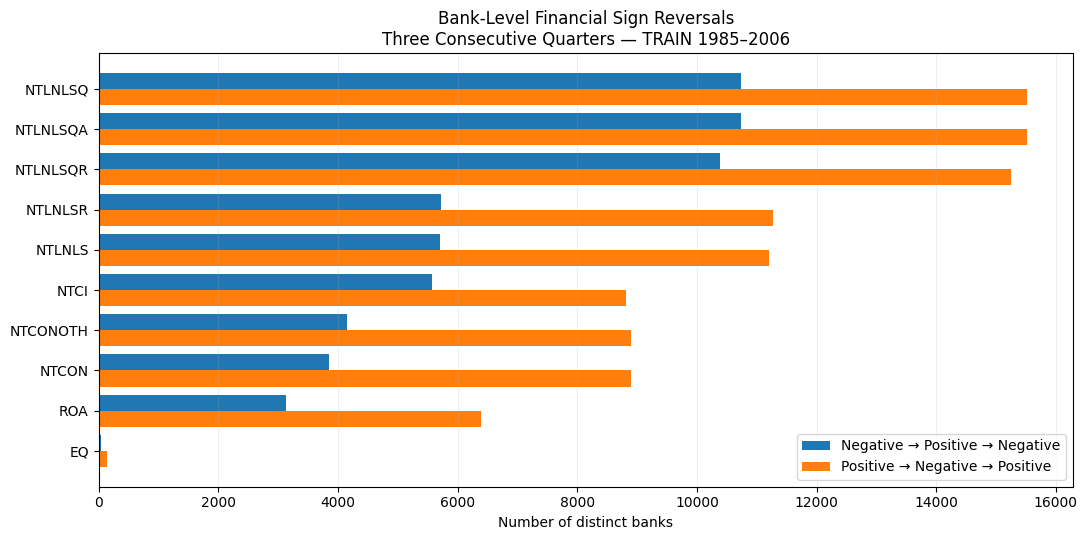

========== SIGN REVERSAL DIAGNOSTICS ==========


field,neg_pos_neg_events,neg_pos_neg_banks,pos_neg_pos_events,pos_neg_pos_banks
str,i64,i64,i64,i64
"""NTLNLSQ""",35746,10737,74287,15510
"""NTLNLSQA""",35746,10737,74287,15510
"""NTLNLSQR""",33995,10394,70929,15247
"""NTLNLSR""",10685,5730,26644,11268
"""NTLNLS""",10609,5699,26364,11201
"""NTCI""",9456,5569,17966,8809
"""NTCONOTH""",6597,4144,18416,8897
"""NTCON""",6157,3854,18436,8893
"""ROA""",4026,3125,9450,6389



PASS — Sign transitions analyzed.


In [274]:

# ============================================================
# PHASE 4 — STEP 4.4E (FIXED)
# BANK-LEVEL SIGN TRANSITIONS
# TRAIN 1985–2006 | Consecutive quarters only
# ============================================================

assert "P4_INTEGRITY_LF" in globals()
assert "P4_NEG_TOP" in globals()

P4_FLIP_FIELDS = list(dict.fromkeys(
    P4_NEG_TOP[:8]
    + [f for f in ["ROA", "EQ"] if f in P4_NEG_ACTIVE]
))

# 1. Prepare bank-quarter sequences
P4_SIGN_LF = (
    P4_INTEGRITY_LF
    .select(["CERT", "REPDTE"] + P4_FLIP_FIELDS)
    .sort(["CERT", "REPDTE"])
    .with_columns(
        (
            pl.col("REPDTE").dt.year() * 4
            + pl.col("REPDTE").dt.quarter()
        ).alias("__quarter_id")
    )
    .with_columns(
        pl.col("__quarter_id")
          .shift(1).over("CERT")
          .alias("__qid_lag1"),

        pl.col("__quarter_id")
          .shift(2).over("CERT")
          .alias("__qid_lag2"),

        *[
            pl.col(f)
              .shift(k).over("CERT")
              .alias(f"__{f}_lag{k}")
            for f in P4_FLIP_FIELDS
            for k in (1, 2)
        ]
    )
)

# 2. Require three consecutive calendar quarters
P4_CONSECUTIVE_3Q = (
    (pl.col("__quarter_id") - pl.col("__qid_lag1") == 1)
    & (pl.col("__qid_lag1") - pl.col("__qid_lag2") == 1)
)

# 3. Build expressions
P4_FLIP_EXPRS = []

for f in P4_FLIP_FIELDS:

    neg_pos_neg = (
        (pl.col(f"__{f}_lag2") < 0)
        & (pl.col(f"__{f}_lag1") > 0)
        & (pl.col(f) < 0)
        & P4_CONSECUTIVE_3Q
    ).fill_null(False)

    pos_neg_pos = (
        (pl.col(f"__{f}_lag2") > 0)
        & (pl.col(f"__{f}_lag1") < 0)
        & (pl.col(f) > 0)
        & P4_CONSECUTIVE_3Q
    ).fill_null(False)

    P4_FLIP_EXPRS.extend([
        neg_pos_neg.sum()
          .alias(f"{f}__npn_events"),

        pl.col("CERT")
          .filter(neg_pos_neg)
          .n_unique()
          .alias(f"{f}__npn_banks"),

        pos_neg_pos.sum()
          .alias(f"{f}__pnp_events"),

        pl.col("CERT")
          .filter(pos_neg_pos)
          .n_unique()
          .alias(f"{f}__pnp_banks")
    ])

# 4. Aggregate using Polars
P4_FLIP_RESULT = (
    P4_SIGN_LF
    .select(P4_FLIP_EXPRS)
    .collect()
    .to_dicts()[0]
)

P4_SIGN_TRANSITIONS = pl.DataFrame([
    {
        "field": f,
        "neg_pos_neg_events": P4_FLIP_RESULT[
            f"{f}__npn_events"
        ],
        "neg_pos_neg_banks": P4_FLIP_RESULT[
            f"{f}__npn_banks"
        ],
        "pos_neg_pos_events": P4_FLIP_RESULT[
            f"{f}__pnp_events"
        ],
        "pos_neg_pos_banks": P4_FLIP_RESULT[
            f"{f}__pnp_banks"
        ]
    }
    for f in P4_FLIP_FIELDS
]).sort("neg_pos_neg_banks", descending=True)

# 5. Visualize both reversal patterns
names = P4_SIGN_TRANSITIONS["field"].to_list()
npn = P4_SIGN_TRANSITIONS["neg_pos_neg_banks"].to_list()
pnp = P4_SIGN_TRANSITIONS["pos_neg_pos_banks"].to_list()

positions = list(range(len(names)))

fig, ax = plt.subplots(figsize=(11, 5.5))

ax.barh(
    [i - 0.2 for i in positions],
    npn,
    height=0.4,
    label="Negative → Positive → Negative"
)

ax.barh(
    [i + 0.2 for i in positions],
    pnp,
    height=0.4,
    label="Positive → Negative → Positive"
)

ax.set_yticks(positions)
ax.set_yticklabels(names)
ax.invert_yaxis()

ax.set_xlabel("Number of distinct banks")
ax.set_title(
    "Bank-Level Financial Sign Reversals\n"
    "Three Consecutive Quarters — TRAIN 1985–2006"
)

ax.legend()
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

print("========== SIGN REVERSAL DIAGNOSTICS ==========")
display(P4_SIGN_TRANSITIONS)

print("\nPASS — Sign transitions analyzed.")


========== NEGATIVE OBSERVATION PROFILE ==========


field,negative_rows,negative_banks,failure_pct_neg,failure_pct_nonneg,median_log_assets_neg,median_log_assets_nonneg,median_capital_neg,median_roa_neg,failure_rate_gap_pp
str,i64,i64,f64,f64,f64,f64,f64,f64,f64
"""EQ""",12515,2546,25.146,0.46,5.026,4.803,-0.041,-2.379,24.686
"""ROA""",111943,15810,6.331,0.114,4.567,4.829,0.071,-1.117,6.217
"""NTCON""",145224,14871,0.342,0.6,4.713,4.811,0.092,1.146,-0.259
"""NTCONOTH""",155026,15180,0.328,0.609,4.736,4.805,0.091,1.146,-0.281
"""NTLNLSQR""",205296,17640,0.337,0.625,4.709,4.827,0.092,1.155,-0.288
"""NTLNLSQ""",211537,17780,0.332,0.622,4.725,4.817,0.091,1.153,-0.29
"""NTLNLSQA""",211537,17780,0.332,0.622,4.725,4.817,0.091,1.153,-0.29
"""NTCI""",213605,15435,0.217,0.653,4.813,4.791,0.089,1.194,-0.435
"""NTLNLS""",190231,15990,0.201,0.644,4.712,4.817,0.093,1.202,-0.442


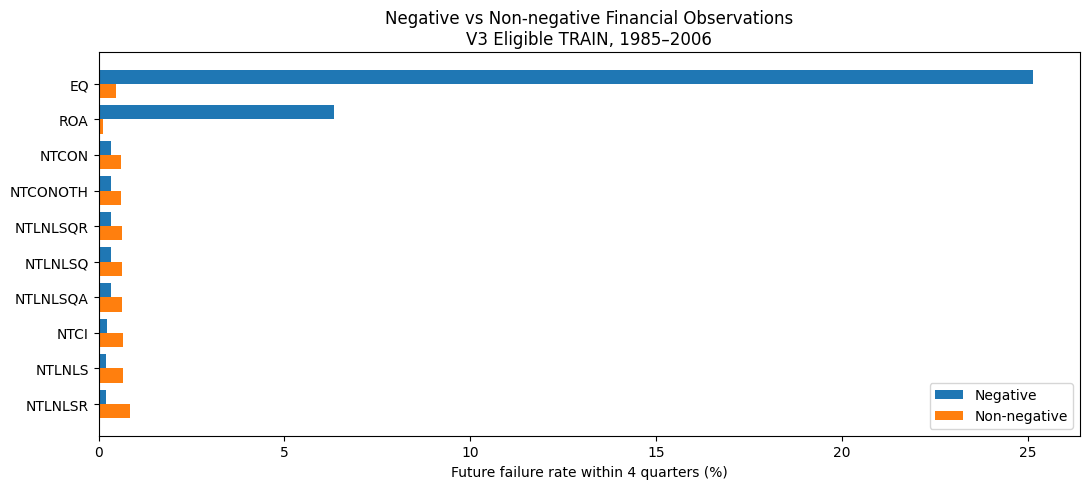

In [275]:

# ============================================================
# 4.4F — CHARACTERISTICS OF NEGATIVE OBSERVATIONS
# TRAIN only | V3 eligible bank-quarters
# ============================================================

assert "GOLD_ELIGIBLE_LF" in globals()

P4_PROFILE_COLUMNS = list(dict.fromkeys(
    ["CERT", "REPDTE", "ASSET", "EQ", "ROA"]
    + P4_FLIP_FIELDS
))

P4_NEG_PROFILE_LF = (
    P4_INTEGRITY_LF
    .select(P4_PROFILE_COLUMNS)
    .join(
        GOLD_ELIGIBLE_LF
        .filter(
            pl.col("P4_TEMPORAL_SPLIT") == "TRAIN_FULL"
        )
        .select(
            "CERT", "REPDTE", "y_failure_4q_v3"
        ),
        on=["CERT", "REPDTE"],
        how="inner",
        validate="1:1"
    )
    .with_columns(
        pl.when(pl.col("ASSET") > 0)
          .then(pl.col("ASSET").log10())
          .otherwise(None)
          .alias("__log_assets"),

        pl.when(pl.col("ASSET") > 0)
          .then(pl.col("EQ") / pl.col("ASSET"))
          .otherwise(None)
          .alias("__equity_assets")
    )
)

# One aggregated query, no row-level pandas conversion
p4_expr = []

for f in P4_FLIP_FIELDS:
    for group, condition in [
        ("neg", (pl.col(f) < 0).fill_null(False)),
        ("nonneg", (pl.col(f) >= 0).fill_null(False))
    ]:
        key = f"{f}__{group}"

        p4_expr.extend([
            condition.sum().alias(key + "__n"),

            pl.col("CERT").filter(condition)
              .n_unique().alias(key + "__banks"),

            (
                pl.col("y_failure_4q_v3")
                .filter(condition).mean() * 100
            ).alias(key + "__failure_pct"),

            pl.col("__log_assets")
              .filter(condition).median()
              .alias(key + "__size"),

            pl.col("__equity_assets")
              .filter(condition).median()
              .alias(key + "__capital"),

            pl.col("ROA")
              .filter(condition).median()
              .alias(key + "__roa")
        ])

p4_stats = (
    P4_NEG_PROFILE_LF
    .select(p4_expr)
    .collect()
    .to_dicts()[0]
)

P4_NEG_CHARACTERISTICS = pl.DataFrame([
    {
        "field": f,
        "negative_rows": p4_stats[f"{f}__neg__n"],
        "negative_banks": p4_stats[f"{f}__neg__banks"],
        "failure_pct_neg": p4_stats[
            f"{f}__neg__failure_pct"
        ],
        "failure_pct_nonneg": p4_stats[
            f"{f}__nonneg__failure_pct"
        ],
        "median_log_assets_neg": p4_stats[
            f"{f}__neg__size"
        ],
        "median_log_assets_nonneg": p4_stats[
            f"{f}__nonneg__size"
        ],
        "median_capital_neg": p4_stats[
            f"{f}__neg__capital"
        ],
        "median_roa_neg": p4_stats[
            f"{f}__neg__roa"
        ]
    }
    for f in P4_FLIP_FIELDS
]).with_columns(
    (
        pl.col("failure_pct_neg")
        - pl.col("failure_pct_nonneg")
    ).round(3).alias("failure_rate_gap_pp")
).sort("failure_rate_gap_pp", descending=True)

print("========== NEGATIVE OBSERVATION PROFILE ==========")
display(
    P4_NEG_CHARACTERISTICS.with_columns(
        pl.selectors.float().round(3)
    )
)

# Chart: compare future failure rates
names = P4_NEG_CHARACTERISTICS["field"].to_list()
y_neg = P4_NEG_CHARACTERISTICS[
    "failure_pct_neg"
].to_list()
y_nonneg = P4_NEG_CHARACTERISTICS[
    "failure_pct_nonneg"
].to_list()

positions = list(range(len(names)))

fig, ax = plt.subplots(figsize=(11, 5))

ax.barh(
    [i - 0.2 for i in positions],
    y_neg, height=0.4,
    label="Negative"
)

ax.barh(
    [i + 0.2 for i in positions],
    y_nonneg, height=0.4,
    label="Non-negative"
)

ax.set_yticks(positions)
ax.set_yticklabels(names)
ax.invert_yaxis()

ax.set_xlabel("Future failure rate within 4 quarters (%)")
ax.set_title(
    "Negative vs Non-negative Financial Observations\n"
    "V3 Eligible TRAIN, 1985–2006"
)

ax.legend()
plt.tight_layout()
plt.show()


#### Ghi chú nghiệp vụ | Giá trị âm của net charge-offs

`NTLNLS` phản ánh **net loan and lease charge-offs** (xóa nợ trừ thu hồi). Giá trị âm có thể xuất hiện khi thu hồi vượt số xóa nợ; **không tự động coi là lỗi**. Cần phân biệt ý nghĩa chỉ tiêu với các lỗi dấu hoặc biến đổi tỷ lệ.

========== NT FIELDS — NEGATIVE VALUES ==========


field,negative_rows,failure_pct_neg,failure_pct_nonneg,neg_pos_neg_banks,pos_neg_pos_banks
str,i64,f64,f64,i64,i64
"""NTCON""",145224,0.341541,0.600209,3854,8893
"""NTCONOTH""",155026,0.327687,0.608659,4144,8897
"""NTLNLSQR""",205296,0.337074,0.625309,10394,15247
"""NTLNLSQ""",211537,0.33233,0.621931,10737,15510
"""NTLNLSQA""",211537,0.33233,0.621935,10737,15510
"""NTCI""",213605,0.217223,0.652714,5569,8809
"""NTLNLS""",190231,0.201334,0.643551,5699,11201
"""NTLNLSR""",190827,0.202801,0.843327,5730,11268



========== NTLNLSQ vs NTLNLSQA ==========


nonzero_rows,matched_4x_rows,match_pct,max_abs_diff
i64,i64,f64,f64
875115,875115,100.0,0.0


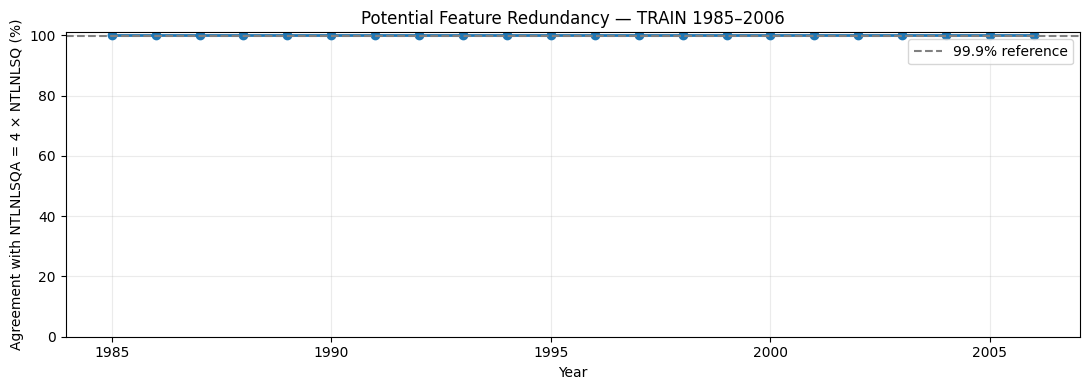

In [276]:

# ============================================================
# PHASE 4 — 4.4G: NT FIELDS & REDUNDANCY AUDIT
# No imports | TRAIN only | Polars LazyFrame
# ============================================================

assert all(x in globals() for x in [
    "P4_INTEGRITY_LF", "P4_NEG_CHARACTERISTICS",
    "P4_SIGN_TRANSITIONS", "plt"
])

# 1. Review existing NT findings without rescanning data
P4_NT_REVIEW = (
    P4_NEG_CHARACTERISTICS
    .filter(pl.col("field").str.starts_with("NT"))
    .join(
        P4_SIGN_TRANSITIONS.select(
            "field",
            "neg_pos_neg_banks",
            "pos_neg_pos_banks"
        ),
        on="field",
        how="left"
    )
    .select(
        "field", "negative_rows",
        "failure_pct_neg", "failure_pct_nonneg",
        "neg_pos_neg_banks", "pos_neg_pos_banks"
    )
)

print("========== NT FIELDS — NEGATIVE VALUES ==========")
display(P4_NT_REVIEW)

# 2. Compare NTLNLSQ vs NTLNLSQA at row level
P4_NT_PAIR_LF = (
    P4_INTEGRITY_LF
    .select("REPDTE", "NTLNLSQ", "NTLNLSQA")
    .with_columns(
        pl.col("REPDTE").dt.year().alias("YEAR"),
        (
            pl.col("NTLNLSQA")
            - 4 * pl.col("NTLNLSQ")
        ).abs().alias("abs_diff_4x"),
        pl.max_horizontal(
            pl.col("NTLNLSQA").abs(),
            (4 * pl.col("NTLNLSQ")).abs()
        ).alias("magnitude"),
        (
            pl.col("NTLNLSQ").is_not_null()
            & pl.col("NTLNLSQA").is_not_null()
            & (
                (pl.col("NTLNLSQ") != 0)
                | (pl.col("NTLNLSQA") != 0)
            )
        ).fill_null(False).alias("nonzero_pair")
    )
    .with_columns(
        (
            pl.col("abs_diff_4x")
            <= (
                0.000001
                + 0.001 * pl.col("magnitude")
            )
        ).fill_null(False).alias("matches_4x")
    )
)

# 3. Annual comparison — aggregate before collection
P4_NT_PAIR_ANNUAL = (
    P4_NT_PAIR_LF
    .group_by("YEAR")
    .agg(
        pl.col("nonzero_pair").sum().alias("nonzero_rows"),
        (
            pl.col("nonzero_pair")
            & pl.col("matches_4x")
        ).sum().alias("matched_rows"),
        pl.col("abs_diff_4x").max().alias("max_abs_diff")
    )
    .sort("YEAR")
    .with_columns(
        pl.when(pl.col("nonzero_rows") > 0)
        .then(
            100 * pl.col("matched_rows")
            / pl.col("nonzero_rows")
        )
        .otherwise(None)
        .alias("match_pct")
    )
    .collect()
)

# 4. Overall diagnostics
P4_NT_PAIR_SUMMARY = pl.DataFrame([{
    "nonzero_rows": int(
        P4_NT_PAIR_ANNUAL["nonzero_rows"].sum()
    ),
    "matched_4x_rows": int(
        P4_NT_PAIR_ANNUAL["matched_rows"].sum()
    ),
    "match_pct": round(
        100 * P4_NT_PAIR_ANNUAL["matched_rows"].sum()
        / max(P4_NT_PAIR_ANNUAL["nonzero_rows"].sum(), 1),
        4
    ),
    "max_abs_diff": P4_NT_PAIR_ANNUAL[
        "max_abs_diff"
    ].max()
}])

print("\n========== NTLNLSQ vs NTLNLSQA ==========")
display(P4_NT_PAIR_SUMMARY)

# 5. Plot agreement across training years
fig, ax = plt.subplots(figsize=(11, 4))

ax.plot(
    P4_NT_PAIR_ANNUAL["YEAR"].to_list(),
    P4_NT_PAIR_ANNUAL["match_pct"].to_list(),
    marker="o", linewidth=2
)

ax.axhline(99.9, linestyle="--",
           color="gray", label="99.9% reference")

ax.set_ylim(0, 101)
ax.set_xlabel("Year")
ax.set_ylabel("Agreement with NTLNLSQA = 4 × NTLNLSQ (%)")
ax.set_title(
    "Potential Feature Redundancy — TRAIN 1985–2006"
)
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()


#### 4.4G | Nhóm `NT*` và trùng lặp

Một số biến `NT*` có giá trị âm hợp lệ và có quan hệ gần tuyến tính. Tương quan cao **không đồng nghĩa là cùng một đại lượng**: cần đối chiếu mẫu missing, thời điểm báo cáo, đơn vị và định nghĩa trước khi loại một trường.

In [277]:

# 4.4H — Diagnose NTLNLSQ / NTLNLSQA
# No imports, no source modifications

P4_NT_NULL_AUDIT = P4_INTEGRITY_LF.select(
    pl.len().alias("rows"),

    (
        pl.col("NTLNLSQ").is_null()
        & pl.col("NTLNLSQA").is_not_null()
    ).sum().alias("only_Q_missing"),

    (
        pl.col("NTLNLSQ").is_not_null()
        & pl.col("NTLNLSQA").is_null()
    ).sum().alias("only_QA_missing"),

    (
        pl.col("NTLNLSQ").is_not_null()
        & pl.col("NTLNLSQA").is_not_null()
    ).sum().alias("both_present"),

    (
        (
            pl.col("NTLNLSQA")
            - 4 * pl.col("NTLNLSQ")
        ).abs() > 1e-8
    ).fill_null(False).sum().alias("scale_4_mismatch")
).collect()

display(P4_NT_NULL_AUDIT)

print("PASS — Numeric and missingness differences audited.")


rows,only_Q_missing,only_QA_missing,both_present,scale_4_mismatch
u32,u32,u32,u32,u32
1123127,0,6,1057799,0


PASS — Numeric and missingness differences audited.


In [278]:

# ============================================================
# PHASE 4 — 4.4I
# AUTOMATIC COMMON-PREFIX GROUPING
# Current 88 candidates | No imports
# ============================================================

assert "P4_BASELINE_CANDIDATES_91" in globals()

P4_EXCLUDED_FROM_BASELINE = {
    "NTALLOTHNUM", "NTALLOTHQR", "NTLNLSQA"
}

P4_BASELINE_CANDIDATES_88 = [
    f for f in P4_BASELINE_CANDIDATES_91
    if f not in P4_EXCLUDED_FROM_BASELINE
]

assert len(P4_BASELINE_CANDIDATES_88) == 88

# 1. Automatically identify common prefixes
# Try 4 characters first, then 3 for ungrouped fields.
P4_GROUP_MAP = {}
remaining = sorted(P4_BASELINE_CANDIDATES_88)

for prefix_length in (4, 3):
    prefix_map = {}

    for field in remaining:
        if len(field) >= prefix_length:
            prefix_map.setdefault(
                field[:prefix_length], []
            ).append(field)

    for prefix, members in sorted(prefix_map.items()):
        if len(members) >= 2:
            P4_GROUP_MAP[prefix] = sorted(members)

    grouped = {
        f for members in P4_GROUP_MAP.values()
        for f in members
    }

    remaining = [f for f in remaining if f not in grouped]

# 2. Keep independent fields as singletons
for field in remaining:
    P4_GROUP_MAP[field] = [field]

# 3. Build group summary
P4_GROUP_SUMMARY = pl.DataFrame([
    {
        "group": prefix,
        "n_fields": len(fields),
        "fields": fields,
        "type": (
            "COMMON_PREFIX"
            if len(fields) > 1 else "SINGLETON"
        )
    }
    for prefix, fields in P4_GROUP_MAP.items()
]).sort("n_fields", descending=True)

# 4. Generate candidate pairs within groups only
P4_GROUP_PAIRS = [
    {
        "group": prefix,
        "field_a": fields[i],
        "field_b": fields[j]
    }
    for prefix, fields in P4_GROUP_MAP.items()
    for i in range(len(fields))
    for j in range(i + 1, len(fields))
]

P4_GROUPED_PAIRS = pl.DataFrame(
    P4_GROUP_PAIRS,
    schema={
        "group": pl.String,
        "field_a": pl.String,
        "field_b": pl.String
    }
)

# 5. Verify coverage of all 88 candidates
all_grouped = [
    f for fields in P4_GROUP_MAP.values()
    for f in fields
]

assert len(all_grouped) == 88
assert set(all_grouped) == set(P4_BASELINE_CANDIDATES_88)
assert len(all_grouped) == len(set(all_grouped))

print("========== AUTOMATIC FEATURE GROUPING ==========")
print("Total features:", len(all_grouped))
print("Groups:", len(P4_GROUP_MAP))
print("Multi-field groups:",
      sum(len(v) > 1 for v in P4_GROUP_MAP.values()))
print("Pairs to investigate:", len(P4_GROUP_PAIRS))

print("\n========== COMMON-PREFIX GROUPS ==========")
display(
    P4_GROUP_SUMMARY.filter(
        pl.col("n_fields") > 1
    )
)

print("\n========== UNGROUPED FIELDS ==========")
print(sorted(remaining))

print("\nPASS — Feature groups generated automatically.")


========== AUTOMATIC FEATURE GROUPING ==========
Total features: 88
Groups: 41
Multi-field groups: 25
Pairs to investigate: 99

========== COMMON-PREFIX GROUPS ==========


group,n_fields,fields,type
str,i64,list[str],str
"""NONI""",8,"[""NONII"", ""NONIIA"", … ""NONIXQA""]","""COMMON_PREFIX"""
"""NTRE""",7,"[""NTRE"", ""NTREOFFDOM"", … ""NTRER""]","""COMMON_PREFIX"""
"""ADDN""",4,"[""ADDNONII"", ""ADDNONIIQ"", … ""ADDNONINTEXPQ""]","""COMMON_PREFIX"""
"""DRCO""",4,"[""DRCON"", ""DRCONOTH"", … ""DRCONQ""]","""COMMON_PREFIX"""
"""DRRE""",4,"[""DRRE"", ""DRREOFFDOM"", … ""DRREQ""]","""COMMON_PREFIX"""
…,…,…,…
"""DEP""",2,"[""DEP"", ""DEPUNINS""]","""COMMON_PREFIX"""
"""LNC""",2,"[""LNCDT1R"", ""LNCONT1R""]","""COMMON_PREFIX"""
"""NTC""",2,"[""NTCI"", ""NTCRCD""]","""COMMON_PREFIX"""



========== UNGROUPED FIELDS ==========
['ASSET', 'BRO', 'CHBAL', 'COREDEP', 'EINTEXP', 'EQ', 'INTINC', 'LNATRESR', 'NALNLS', 'NCLNLS', 'NIMY', 'NTALLOTHDEN', 'P9LNLS', 'ROA', 'ROE', 'SC']

PASS — Feature groups generated automatically.


**`[RUN]` PHASE 4 — 4.4J: GROUP-BY-GROUP REDUNDANCY AUDIT — 2 ô liên tiếp.** Chạy lần lượt từ trên xuống; các bảng/đồ thị của cell gốc được giữ tại ô cuối của nhóm.

In [279]:

# ============================================================
# PHASE 4 — 4.4J: GROUP-BY-GROUP REDUNDANCY AUDIT
# 88 candidates | TRAIN only | Polars LazyFrame
# No imports | No raw-data modification
# ============================================================

assert all(x in globals() for x in [
    "P4_GROUP_MAP", "P4_INTEGRITY_LF",
    "P4_BASELINE_CANDIDATES_88", "plt"
])

# Automatically order groups from largest to smallest
P4_AUDIT_GROUPS = sorted(
    [(g, fs) for g, fs in P4_GROUP_MAP.items() if len(fs) > 1],
    key=lambda item: (-len(item[1]), item[0])
)

# Change this index to inspect the next group
P4_GROUP_INDEX = 0

P4_GROUP_NAME, P4_GROUP_FIELDS = P4_AUDIT_GROUPS[
    P4_GROUP_INDEX
]

print(
    f"GROUP {P4_GROUP_INDEX + 1}/{len(P4_AUDIT_GROUPS)}:",
    P4_GROUP_NAME
)
print("Fields:", P4_GROUP_FIELDS)

# ------------------------------------------------------------
# 1. Pair-level comparisons
# ------------------------------------------------------------

P4_CURRENT_PAIRS = [
    (P4_GROUP_FIELDS[i], P4_GROUP_FIELDS[j])
    for i in range(len(P4_GROUP_FIELDS))
    for j in range(i + 1, len(P4_GROUP_FIELDS))
]

P4_GROUP_RESULTS = []

for a, b in P4_CURRENT_PAIRS:

    x, y = pl.col(a), pl.col(b)

    valid = (
        x.is_not_null() & y.is_not_null()
    )

    informative = (
        valid
        & ((x.abs() > 1e-10) | (y.abs() > 1e-10))
    ).fill_null(False)

    # Calculate factor from informative observations only
    factor_df = (
        P4_INTEGRITY_LF
        .select(
            pl.when(
                valid & (x.abs() > 1e-10)
            ).then(y / x)
            .otherwise(None)
            .median()
            .alias("factor")
        )
        .collect()
    )

    factor = factor_df["factor"][0]

    # Guard against undefined / zero factors
    factor_ok = (
        factor is not None
        and factor == factor
        and 1e-10 < abs(factor) < 1e10
    )

    scale_expr = (
        (
            (y - factor * x).abs()
            <= (
                1e-8
                + 1e-6 * pl.max_horizontal(
                    y.abs(), (factor * x).abs()
                )
            )
        ).fill_null(False)
        if factor_ok
        else pl.lit(False)
    )

    stats = (
        P4_INTEGRITY_LF
        .select(
            valid.fill_null(False).sum()
                .alias("shared_rows"),

            informative.sum()
                .alias("nonzero_rows"),

            (
                x.is_null() != y.is_null()
            ).sum()
                .alias("missing_mismatch"),

            (
                valid & (x == y)
            ).fill_null(False).sum()
                .alias("exact_matches"),

            (
                informative & scale_expr
            ).fill_null(False).sum()
                .alias("scale_matches"),

            pl.corr(a, b)
                .alias("correlation")
        )
        .collect()
        .row(0, named=True)
    )

    shared = stats["shared_rows"]
    nonzero = stats["nonzero_rows"]

    exact_pct = (
        100 * stats["exact_matches"] / shared
        if shared else 0
    )

    scale_pct = (
        100 * stats["scale_matches"] / nonzero
        if nonzero else 0
    )

    corr = stats["correlation"]

    # --------------------------------------------------------
    # 2. Classify redundancy
    # --------------------------------------------------------

    if nonzero < 100:
        decision = "LOW_INFORMATION"

    elif exact_pct >= 99.9999:
        decision = "EXACT_DUPLICATE"

    elif factor_ok and scale_pct >= 99.9999:
        decision = "EXACT_SCALE"

    elif corr is not None and abs(corr) >= 0.995:
        decision = "HIGH_CORRELATION"

    else:
        decision = "DISTINCT"

    P4_GROUP_RESULTS.append({
        "group": P4_GROUP_NAME,
        "field_a": a,
        "field_b": b,
        "shared_rows": shared,
        "nonzero_rows": nonzero,
        "exact_pct": round(exact_pct, 4),
        "scale_factor": round(factor, 6) if factor_ok else None,
        "scale_pct": round(scale_pct, 4),
        "correlation": round(corr, 6) if corr is not None else None,
        "missing_mismatch": stats["missing_mismatch"],
        "decision": decision
    })


GROUP 1/25: NONI
Fields: ['NONII', 'NONIIA', 'NONIIQ', 'NONIIQA', 'NONIX', 'NONIXA', 'NONIXQ', 'NONIXQA']



========== PAIR-LEVEL REDUNDANCY ==========


group,field_a,field_b,shared_rows,nonzero_rows,exact_pct,scale_factor,scale_pct,correlation,missing_mismatch,decision
str,str,str,i64,i64,f64,f64,f64,f64,i64,str
"""NONI""","""NONIIA""","""NONIIQ""",1120419,1116865,0.4884,0.25,26.5607,0.987147,0,"""DISTINCT"""
"""NONI""","""NONIIA""","""NONIIQA""",1120419,1116865,26.7936,1.0,26.5607,0.987147,0,"""DISTINCT"""
"""NONI""","""NONIXA""","""NONIXQA""",1120419,1120116,25.7998,1.0,25.7797,0.994324,0,"""DISTINCT"""
"""NONI""","""NONIXA""","""NONIXQ""",1120419,1120116,0.1932,0.25,25.7797,0.994324,0,"""DISTINCT"""
"""NONI""","""NONII""","""NONIIA""",1120418,1116820,24.9336,1.3333,24.9035,0.913126,1,"""DISTINCT"""
…,…,…,…,…,…,…,…,…,…,…
"""NONI""","""NONIX""","""NONIXQ""",1120418,1120115,25.8012,0.42299,0.0,0.912026,1,"""DISTINCT"""
"""NONI""","""NONIX""","""NONIXQA""",1120418,1120115,0.0937,1.691959,0.0,0.912026,1,"""DISTINCT"""
"""NONI""","""NONII""","""NONIXA""",1120418,1120125,0.0283,8.166375,0.0,0.894549,1,"""DISTINCT"""



========== GROUP SUMMARY ==========


decision,pair_count
str,u32
"""DISTINCT""",26
"""EXACT_SCALE""",2


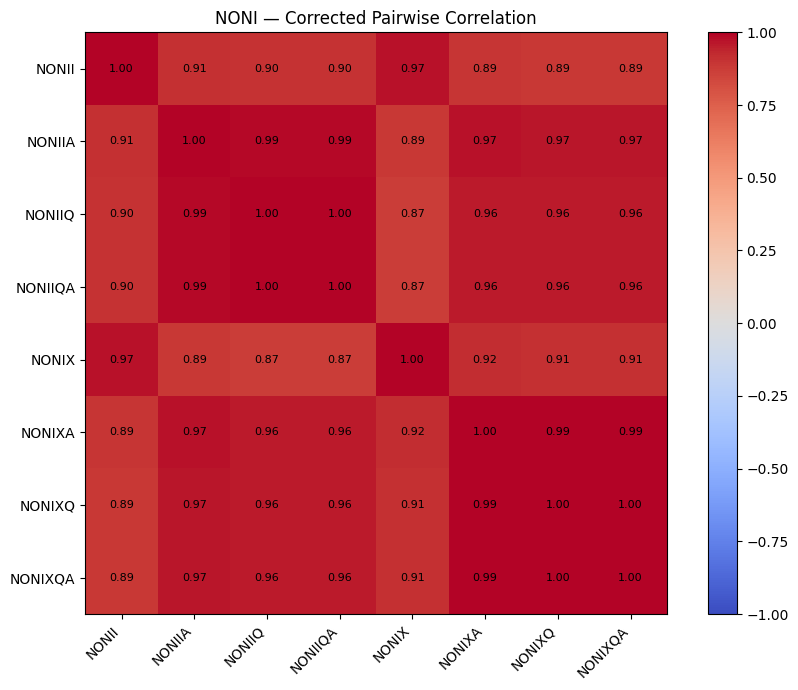


PASS — Group 1/25 completed.


In [280]:

# ------------------------------------------------------------
# 3. Results
# ------------------------------------------------------------

P4_CURRENT_GROUP_AUDIT = (
    pl.DataFrame(P4_GROUP_RESULTS)
    .sort(["decision", "scale_pct"], descending=[False, True])
)

print("\n========== PAIR-LEVEL REDUNDANCY ==========")
display(P4_CURRENT_GROUP_AUDIT)

print("\n========== GROUP SUMMARY ==========")
display(
    P4_CURRENT_GROUP_AUDIT
    .group_by("decision")
    .agg(pl.len().alias("pair_count"))
    .sort("pair_count", descending=True)
)

# ------------------------------------------------------------
# 4. Correlation heatmap for selected group
# ------------------------------------------------------------


# FIX — NONI correlation heatmap
# Compute pairwise correlations directly in Polars

fields = P4_GROUP_FIELDS

corr_values = []

for a in fields:
    row = []

    for b in fields:
        if a == b:
            row.append(1.0)
        else:
            c = (
                P4_CURRENT_GROUP_AUDIT
                .filter(
                    ((pl.col("field_a") == a) & (pl.col("field_b") == b))
                    | ((pl.col("field_a") == b) & (pl.col("field_b") == a))
                )
                .get_column("correlation")
            )
            row.append(c[0] if len(c) else float("nan"))

    corr_values.append(row)

fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(
    corr_values,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(fields)))
ax.set_yticks(range(len(fields)))

ax.set_xticklabels(fields, rotation=45, ha="right")
ax.set_yticklabels(fields)

for i in range(len(fields)):
    for j in range(len(fields)):
        value = corr_values[i][j]
        if value == value:
            ax.text(
                j, i, f"{value:.2f}",
                ha="center", va="center",
                fontsize=8
            )

ax.set_title("NONI — Corrected Pairwise Correlation")
fig.colorbar(im, ax=ax)

plt.tight_layout()
plt.show()


print(
    f"\nPASS — Group {P4_GROUP_INDEX + 1}/"
    f"{len(P4_AUDIT_GROUPS)} completed."
)


#### 4.4J | Nhóm NONI

Nhiều thước đo thu nhập/chi phí phi lãi tương quan mạnh (một số cặp trên 0,95). Tuy nhiên, quy mô ngân hàng và sự khác biệt giữa **số tiền, tỷ lệ, quý, lũy kế** có thể tạo tương quan cao mà không gây trùng lặp kế toán. **Giữ để kiểm tra định nghĩa trước khi quyết định.**

**`[RUN]` PHASE 4 — 4.4J: GROUP-BY-GROUP REDUNDANCY AUDIT — 2 ô liên tiếp.** Chạy lần lượt từ trên xuống; các bảng/đồ thị của cell gốc được giữ tại ô cuối của nhóm.

In [281]:

# ============================================================
# PHASE 4 — 4.4J: GROUP-BY-GROUP REDUNDANCY AUDIT
# 88 candidates | TRAIN only | Polars LazyFrame
# No imports | No raw-data modification
# ============================================================

assert all(x in globals() for x in [
    "P4_GROUP_MAP", "P4_INTEGRITY_LF",
    "P4_BASELINE_CANDIDATES_88", "plt"
])

# Automatically order groups from largest to smallest
P4_AUDIT_GROUPS = sorted(
    [(g, fs) for g, fs in P4_GROUP_MAP.items() if len(fs) > 1],
    key=lambda item: (-len(item[1]), item[0])
)

# Change this index to inspect the next group
P4_GROUP_INDEX = 1

P4_GROUP_NAME, P4_GROUP_FIELDS = P4_AUDIT_GROUPS[
    P4_GROUP_INDEX
]

print(
    f"GROUP {P4_GROUP_INDEX + 1}/{len(P4_AUDIT_GROUPS)}:",
    P4_GROUP_NAME
)
print("Fields:", P4_GROUP_FIELDS)

# ------------------------------------------------------------
# 1. Pair-level comparisons
# ------------------------------------------------------------

P4_CURRENT_PAIRS = [
    (P4_GROUP_FIELDS[i], P4_GROUP_FIELDS[j])
    for i in range(len(P4_GROUP_FIELDS))
    for j in range(i + 1, len(P4_GROUP_FIELDS))
]

P4_GROUP_RESULTS = []

for a, b in P4_CURRENT_PAIRS:

    x, y = pl.col(a), pl.col(b)

    valid = (
        x.is_not_null() & y.is_not_null()
    )

    informative = (
        valid
        & ((x.abs() > 1e-10) | (y.abs() > 1e-10))
    ).fill_null(False)

    # Calculate factor from informative observations only
    factor_df = (
        P4_INTEGRITY_LF
        .select(
            pl.when(
                valid & (x.abs() > 1e-10)
            ).then(y / x)
            .otherwise(None)
            .median()
            .alias("factor")
        )
        .collect()
    )

    factor = factor_df["factor"][0]

    # Guard against undefined / zero factors
    factor_ok = (
        factor is not None
        and factor == factor
        and 1e-10 < abs(factor) < 1e10
    )

    scale_expr = (
        (
            (y - factor * x).abs()
            <= (
                1e-8
                + 1e-6 * pl.max_horizontal(
                    y.abs(), (factor * x).abs()
                )
            )
        ).fill_null(False)
        if factor_ok
        else pl.lit(False)
    )

    stats = (
        P4_INTEGRITY_LF
        .select(
            valid.fill_null(False).sum()
                .alias("shared_rows"),

            informative.sum()
                .alias("nonzero_rows"),

            (
                x.is_null() != y.is_null()
            ).sum()
                .alias("missing_mismatch"),

            (
                valid & (x == y)
            ).fill_null(False).sum()
                .alias("exact_matches"),

            (
                informative & scale_expr
            ).fill_null(False).sum()
                .alias("scale_matches"),

            pl.corr(a, b)
                .alias("correlation")
        )
        .collect()
        .row(0, named=True)
    )

    shared = stats["shared_rows"]
    nonzero = stats["nonzero_rows"]

    exact_pct = (
        100 * stats["exact_matches"] / shared
        if shared else 0
    )

    scale_pct = (
        100 * stats["scale_matches"] / nonzero
        if nonzero else 0
    )

    corr = stats["correlation"]

    # --------------------------------------------------------
    # 2. Classify redundancy
    # --------------------------------------------------------

    if nonzero < 100:
        decision = "LOW_INFORMATION"

    elif exact_pct >= 99.9999:
        decision = "EXACT_DUPLICATE"

    elif factor_ok and scale_pct >= 99.9999:
        decision = "EXACT_SCALE"

    elif corr is not None and abs(corr) >= 0.995:
        decision = "HIGH_CORRELATION"

    else:
        decision = "DISTINCT"

    P4_GROUP_RESULTS.append({
        "group": P4_GROUP_NAME,
        "field_a": a,
        "field_b": b,
        "shared_rows": shared,
        "nonzero_rows": nonzero,
        "exact_pct": round(exact_pct, 4),
        "scale_factor": round(factor, 6) if factor_ok else None,
        "scale_pct": round(scale_pct, 4),
        "correlation": round(corr, 6) if corr is not None else None,
        "missing_mismatch": stats["missing_mismatch"],
        "decision": decision
    })


GROUP 2/25: NTRE
Fields: ['NTRE', 'NTREOFFDOM', 'NTREOFFDOMQ', 'NTREQ', 'NTREQA', 'NTREQR', 'NTRER']



========== PAIR-LEVEL REDUNDANCY ==========


group,field_a,field_b,shared_rows,nonzero_rows,exact_pct,scale_factor,scale_pct,correlation,missing_mismatch,decision
str,str,str,i64,i64,f64,f64,f64,f64,i64,str
"""NTRE""","""NTRE""","""NTREOFFDOM""",1057804,496620,85.0596,1.0,68.1769,0.944306,65323,"""DISTINCT"""
"""NTRE""","""NTREOFFDOMQ""","""NTREQ""",1057799,394635,87.9133,1.0,67.6022,0.938607,65328,"""DISTINCT"""
"""NTRE""","""NTREOFFDOMQ""","""NTREQA""",1057799,394635,62.6928,4.0,67.6022,0.938607,65328,"""DISTINCT"""
"""NTRE""","""NTREOFFDOM""","""NTREOFFDOMQ""",1123127,344155,79.026,0.5,1.6327,0.812509,0,"""DISTINCT"""
"""NTRE""","""NTREOFFDOM""","""NTREQ""",1057799,468461,65.9479,0.5,1.2061,0.769942,65328,"""DISTINCT"""
…,…,…,…,…,…,…,…,…,…,…
"""NTRE""","""NTREOFFDOM""","""NTRER""",1123127,495438,55.8876,0.003437,0.0002,0.038118,0,"""DISTINCT"""
"""NTRE""","""NTREQR""","""NTRER""",1040445,501006,51.8497,0.599611,0.0002,0.633466,82682,"""DISTINCT"""
"""NTRE""","""NTREOFFDOMQ""","""NTRER""",1123127,498694,55.5977,0.003864,0.0,0.038646,0,"""DISTINCT"""



========== GROUP SUMMARY ==========


decision,pair_count
str,u32
"""DISTINCT""",20
"""EXACT_SCALE""",1


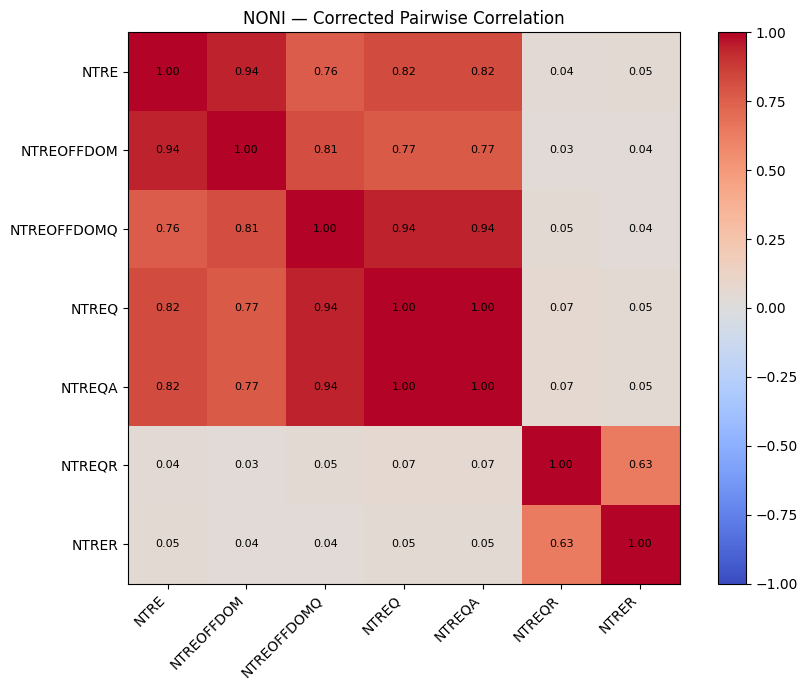


PASS — Group 2/25 completed.


In [282]:

# ------------------------------------------------------------
# 3. Results
# ------------------------------------------------------------

P4_CURRENT_GROUP_AUDIT = (
    pl.DataFrame(P4_GROUP_RESULTS)
    .sort(["decision", "scale_pct"], descending=[False, True])
)

print("\n========== PAIR-LEVEL REDUNDANCY ==========")
display(P4_CURRENT_GROUP_AUDIT)

print("\n========== GROUP SUMMARY ==========")
display(
    P4_CURRENT_GROUP_AUDIT
    .group_by("decision")
    .agg(pl.len().alias("pair_count"))
    .sort("pair_count", descending=True)
)

# ------------------------------------------------------------
# 4. Correlation heatmap for selected group
# ------------------------------------------------------------


# FIX — NONI correlation heatmap
# Compute pairwise correlations directly in Polars

fields = P4_GROUP_FIELDS

corr_values = []

for a in fields:
    row = []

    for b in fields:
        if a == b:
            row.append(1.0)
        else:
            c = (
                P4_CURRENT_GROUP_AUDIT
                .filter(
                    ((pl.col("field_a") == a) & (pl.col("field_b") == b))
                    | ((pl.col("field_a") == b) & (pl.col("field_b") == a))
                )
                .get_column("correlation")
            )
            row.append(c[0] if len(c) else float("nan"))

    corr_values.append(row)

fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(
    corr_values,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(fields)))
ax.set_yticks(range(len(fields)))

ax.set_xticklabels(fields, rotation=45, ha="right")
ax.set_yticklabels(fields)

for i in range(len(fields)):
    for j in range(len(fields)):
        value = corr_values[i][j]
        if value == value:
            ax.text(
                j, i, f"{value:.2f}",
                ha="center", va="center",
                fontsize=8
            )

ax.set_title("NONI — Corrected Pairwise Correlation")
fig.colorbar(im, ax=ax)

plt.tight_layout()
plt.show()


print(
    f"\nPASS — Group {P4_GROUP_INDEX + 1}/"
    f"{len(P4_AUDIT_GROUPS)} completed."
)


#### 4.4J | Nhóm NTRE

Quan hệ `NTREQA = 4 × NTREQ` được xác nhận trên các quan sát cùng có dữ liệu; đây là quan hệ tỷ lệ chính xác trong dữ liệu đã kiểm tra. Các cặp NTRE còn lại không được loại chỉ dựa trên tương quan.

**`[RUN]` PHASE 4 — 4.4K: BATCH GROUP REDUNDANCY AUDIT — 2 ô liên tiếp.** Chạy lần lượt từ trên xuống; các bảng/đồ thị của cell gốc được giữ tại ô cuối của nhóm.

In [283]:

# ============================================================
# PHASE 4 — 4.4K: BATCH GROUP REDUNDANCY AUDIT
# 5 groups per batch | TRAIN 1985–2006
# No imports | No modifications to Silver
# ============================================================


# 4.4K — Fix missing dependencies
# Reconstruct from existing objects; no imports

P4_BASELINE_CANDIDATES_85 = [
    f for f in P4_BASELINE_CANDIDATES_91
    if f not in {
        "NTALLOTHNUM",
        "NTALLOTHQR",
        "NTLNLSQA",
        "NONIIQA",
        "NONIXQA",
        "NTREQA"
    }
]

# Recover the group ordering if necessary
if "P4_AUDIT_GROUPS" not in globals():
    P4_AUDIT_GROUPS = sorted(
        [
            (g, fs)
            for g, fs in P4_GROUP_MAP.items()
            if len(fs) > 1
        ],
        key=lambda item: (-len(item[1]), item[0])
    )

print("Baseline candidates:", len(P4_BASELINE_CANDIDATES_85))
print("Audit groups:", len(P4_AUDIT_GROUPS))
print("TRAIN LazyFrame available:",
      "P4_INTEGRITY_LF" in globals())

assert len(P4_BASELINE_CANDIDATES_85) == 85
assert len(P4_AUDIT_GROUPS) == 25


P4_BATCH_START = 2       # Group 3, zero-based index
P4_BATCH_SIZE = 5

# Keep only currently active baseline fields in each group.
# Original group order is preserved.
P4_BATCH_GROUPS = [
    (
        group,
        [f for f in fields if f in P4_BASELINE_CANDIDATES_85]
    )
    for group, fields in
    P4_AUDIT_GROUPS[P4_BATCH_START:P4_BATCH_START + P4_BATCH_SIZE]
]

# 1. Build pairwise comparisons
P4_BATCH_PAIRS = [
    (group, fields[i], fields[j])
    for group, fields in P4_BATCH_GROUPS
    for i in range(len(fields))
    for j in range(i + 1, len(fields))
]

# 2. Single lazy scan for group-level statistics
exprs = []

for i, (group, a, b) in enumerate(P4_BATCH_PAIRS):
    x, y = pl.col(a), pl.col(b)

    valid = (x.is_not_null() & y.is_not_null()).fill_null(False)
    informative = (
        valid & ((x.abs() > 1e-10) | (y.abs() > 1e-10))
    ).fill_null(False)

    exprs.extend([
        valid.sum().alias(f"p{i}_shared"),
        informative.sum().alias(f"p{i}_nonzero"),

        (x.is_null() != y.is_null())
        .sum().alias(f"p{i}_missing"),

        (valid & (x == y)).fill_null(False)
        .sum().alias(f"p{i}_exact"),

        pl.when(valid & (x.abs() > 1e-10))
        .then(y / x).otherwise(None)
        .median().alias(f"p{i}_factor"),

        pl.corr(a, b).alias(f"p{i}_corr")
    ])

stage1 = (
    P4_INTEGRITY_LF
    .select(exprs)
    .collect()
    .row(0, named=True)
)

# 3. Verify proportionality with inferred scale factors
scale_exprs = []
valid_factors = {}

for i, (_, a, b) in enumerate(P4_BATCH_PAIRS):
    factor = stage1[f"p{i}_factor"]
    factor_ok = (
        factor is not None
        and factor == factor
        and 1e-10 < abs(factor) < 1e10
    )
    valid_factors[i] = factor_ok

    if factor_ok:
        x, y = pl.col(a), pl.col(b)

        informative = (
            x.is_not_null() & y.is_not_null()
            & ((x.abs() > 1e-10) | (y.abs() > 1e-10))
        ).fill_null(False)

        tolerance = (
            1e-8 + 1e-6 * pl.max_horizontal(
                y.abs(), (factor * x).abs()
            )
        )

        scale_exprs.append(
            (
                informative
                & ((y - factor * x).abs() <= tolerance)
            ).fill_null(False)
            .sum().alias(f"p{i}_scale")
        )

scale_counts = (
    P4_INTEGRITY_LF
    .select(scale_exprs)
    .collect()
    .row(0, named=True)
    if scale_exprs else {}
)

# 4. Classify pairs
results = []


Baseline candidates: 85
Audit groups: 25
TRAIN LazyFrame available: True


========== BATCH SUMMARY ==========
Groups: ['ADDN', 'DRCO', 'DRRE', 'LNRE', 'NTLN']
Pairs analyzed: 30


group,decision,pairs
str,str,u32
"""ADDN""","""DISTINCT""",6
"""DRCO""","""DISTINCT""",6
"""DRRE""","""DISTINCT""",6
"""LNRE""","""DISTINCT""",6
"""NTLN""","""DISTINCT""",5
"""NTLN""","""HIGH_CORRELATION""",1



========== REDUNDANCY CANDIDATES ==========


group,field_a,field_b,shared_rows,nonzero_rows,exact_pct,scale_factor,scale_pct,correlation,missing_mismatch,decision
str,str,str,i64,i64,f64,f64,f64,f64,i64,str
"""NTLN""","""NTLNLSQR""","""NTLNLSR""",1047474,930970,11.126,0.842299,0.0,0.995537,75653,"""HIGH_CORRELATION"""


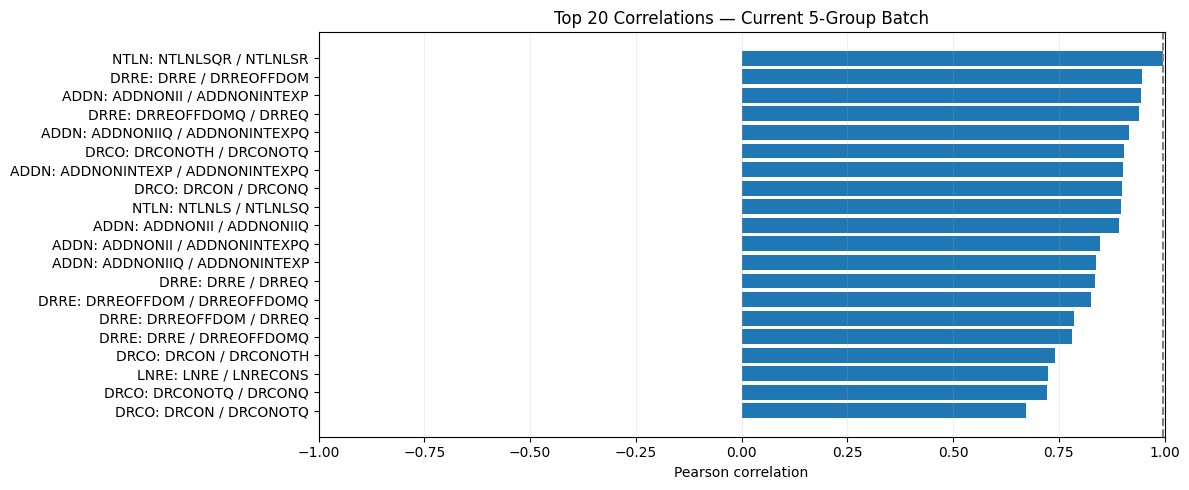


PASS — Batch audit completed.


In [284]:

for i, (group, a, b) in enumerate(P4_BATCH_PAIRS):
    shared = stage1[f"p{i}_shared"]
    nonzero = stage1[f"p{i}_nonzero"]
    exact = stage1[f"p{i}_exact"]
    missing = stage1[f"p{i}_missing"]
    factor = stage1[f"p{i}_factor"]
    corr = stage1[f"p{i}_corr"]

    exact_pct = 100 * exact / shared if shared else 0

    scale_pct = (
        100 * scale_counts.get(f"p{i}_scale", 0) / nonzero
        if nonzero else 0
    )

    if nonzero < 100:
        decision = "LOW_INFORMATION"
    elif exact_pct >= 99.9999 and missing == 0:
        decision = "EXACT_DUPLICATE"
    elif scale_pct >= 99.9999 and missing == 0:
        decision = "EXACT_SCALE"
    elif scale_pct >= 99.9999:
        decision = "SCALE_MISSINGNESS_DIFF"
    elif corr is not None and abs(corr) >= 0.995:
        decision = "HIGH_CORRELATION"
    else:
        decision = "DISTINCT"

    results.append({
        "group": group,
        "field_a": a,
        "field_b": b,
        "shared_rows": shared,
        "nonzero_rows": nonzero,
        "exact_pct": round(exact_pct, 4),
        "scale_factor": (
            round(factor, 6) if valid_factors[i] else None
        ),
        "scale_pct": round(scale_pct, 4),
        "correlation": (
            round(corr, 6) if corr is not None else None
        ),
        "missing_mismatch": missing,
        "decision": decision
    })

P4_BATCH_AUDIT = pl.DataFrame(results)

# 5. Compact summary — no long 100-row table
print("========== BATCH SUMMARY ==========")
print("Groups:",
      [g for g, _ in P4_BATCH_GROUPS])
print("Pairs analyzed:", len(results))

display(
    P4_BATCH_AUDIT
    .group_by("group", "decision")
    .agg(pl.len().alias("pairs"))
    .sort("group", "decision")
)

print("\n========== REDUNDANCY CANDIDATES ==========")
display(
    P4_BATCH_AUDIT.filter(
        pl.col("decision") != "DISTINCT"
    ).sort("group", "decision")
)

# 6. Visualize pairwise correlations for the batch
chart_data = P4_BATCH_AUDIT.filter(
    pl.col("correlation").is_not_null()
).sort("correlation", descending=True)

fig, ax = plt.subplots(figsize=(12, 5))

top = chart_data.head(20).to_dicts()

labels = [
    f'{r["group"]}: {r["field_a"]} / {r["field_b"]}'
    for r in top
]
values = [r["correlation"] for r in top]

ax.barh(labels[::-1], values[::-1])
ax.set_xlim(-1, 1)
ax.axvline(0.995, linestyle="--", color="gray")
ax.set_xlabel("Pearson correlation")
ax.set_title("Top 20 Correlations — Current 5-Group Batch")
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

print("\nPASS — Batch audit completed.")


#### 4.4K | `NTLNLSQR` và `NTLNLSR`

Hai biến mô tả tỷ lệ net charge-offs nhưng khác **khoảng báo cáo**: current quarter so với year-to-date. Dù tương quan cao, chúng có thể phản ánh động thái rủi ro tín dụng khác nhau. **Không gộp hoặc thay thế tự động.**

**`[RUN]` PHASE 4 — 4.4K: BATCH GROUP REDUNDANCY AUDIT — 2 ô liên tiếp.** Chạy lần lượt từ trên xuống; các bảng/đồ thị của cell gốc được giữ tại ô cuối của nhóm.

In [285]:

# ============================================================
# PHASE 4 — 4.4K: BATCH GROUP REDUNDANCY AUDIT
# 5 groups per batch | TRAIN 1985–2006
# No imports | No modifications to Silver
# ============================================================


# 4.4K — Fix missing dependencies
# Reconstruct from existing objects; no imports

P4_BASELINE_CANDIDATES_85 = [
    f for f in P4_BASELINE_CANDIDATES_91
    if f not in {
        "NTALLOTHNUM",
        "NTALLOTHQR",
        "NTLNLSQA",
        "NONIIQA",
        "NONIXQA",
        "NTREQA"
    }
]

# Recover the group ordering if necessary
if "P4_AUDIT_GROUPS" not in globals():
    P4_AUDIT_GROUPS = sorted(
        [
            (g, fs)
            for g, fs in P4_GROUP_MAP.items()
            if len(fs) > 1
        ],
        key=lambda item: (-len(item[1]), item[0])
    )

print("Baseline candidates:", len(P4_BASELINE_CANDIDATES_85))
print("Audit groups:", len(P4_AUDIT_GROUPS))
print("TRAIN LazyFrame available:",
      "P4_INTEGRITY_LF" in globals())

assert len(P4_BASELINE_CANDIDATES_85) == 85
assert len(P4_AUDIT_GROUPS) == 25


P4_BATCH_START = 17       # Group 3, zero-based index
P4_BATCH_SIZE = 10

# Keep only currently active baseline fields in each group.
# Original group order is preserved.
P4_BATCH_GROUPS = [
    (
        group,
        [f for f in fields if f in P4_BASELINE_CANDIDATES_85]
    )
    for group, fields in
    P4_AUDIT_GROUPS[P4_BATCH_START:P4_BATCH_START + P4_BATCH_SIZE]
]

# 1. Build pairwise comparisons
P4_BATCH_PAIRS = [
    (group, fields[i], fields[j])
    for group, fields in P4_BATCH_GROUPS
    for i in range(len(fields))
    for j in range(i + 1, len(fields))
]

# 2. Single lazy scan for group-level statistics
exprs = []

for i, (group, a, b) in enumerate(P4_BATCH_PAIRS):
    x, y = pl.col(a), pl.col(b)

    valid = (x.is_not_null() & y.is_not_null()).fill_null(False)
    informative = (
        valid & ((x.abs() > 1e-10) | (y.abs() > 1e-10))
    ).fill_null(False)

    exprs.extend([
        valid.sum().alias(f"p{i}_shared"),
        informative.sum().alias(f"p{i}_nonzero"),

        (x.is_null() != y.is_null())
        .sum().alias(f"p{i}_missing"),

        (valid & (x == y)).fill_null(False)
        .sum().alias(f"p{i}_exact"),

        pl.when(valid & (x.abs() > 1e-10))
        .then(y / x).otherwise(None)
        .median().alias(f"p{i}_factor"),

        pl.corr(a, b).alias(f"p{i}_corr")
    ])

stage1 = (
    P4_INTEGRITY_LF
    .select(exprs)
    .collect()
    .row(0, named=True)
)

# 3. Verify proportionality with inferred scale factors
scale_exprs = []
valid_factors = {}

for i, (_, a, b) in enumerate(P4_BATCH_PAIRS):
    factor = stage1[f"p{i}_factor"]
    factor_ok = (
        factor is not None
        and factor == factor
        and 1e-10 < abs(factor) < 1e10
    )
    valid_factors[i] = factor_ok

    if factor_ok:
        x, y = pl.col(a), pl.col(b)

        informative = (
            x.is_not_null() & y.is_not_null()
            & ((x.abs() > 1e-10) | (y.abs() > 1e-10))
        ).fill_null(False)

        tolerance = (
            1e-8 + 1e-6 * pl.max_horizontal(
                y.abs(), (factor * x).abs()
            )
        )

        scale_exprs.append(
            (
                informative
                & ((y - factor * x).abs() <= tolerance)
            ).fill_null(False)
            .sum().alias(f"p{i}_scale")
        )

scale_counts = (
    P4_INTEGRITY_LF
    .select(scale_exprs)
    .collect()
    .row(0, named=True)
    if scale_exprs else {}
)

# 4. Classify pairs
results = []


Baseline candidates: 85
Audit groups: 25
TRAIN LazyFrame available: True


========== BATCH SUMMARY ==========
Groups: ['LNCI', 'LNLS', 'NTC', 'NTCO', 'NTLS', 'ORE', 'RBC', 'RBCT']
Pairs analyzed: 8


group,decision,pairs
str,str,u32
"""LNCI""","""DISTINCT""",1
"""LNLS""","""DISTINCT""",1
"""NTC""","""DISTINCT""",1
"""NTCO""","""DISTINCT""",1
"""NTLS""","""DISTINCT""",1
"""ORE""","""DISTINCT""",1
"""RBC""","""DISTINCT""",1
"""RBCT""","""HIGH_CORRELATION""",1



========== REDUNDANCY CANDIDATES ==========


group,field_a,field_b,shared_rows,nonzero_rows,exact_pct,scale_factor,scale_pct,correlation,missing_mismatch,decision
str,str,str,i64,i64,f64,f64,f64,f64,i64,str
"""RBCT""","""RBCT1""","""RBCT1J""",1057796,1057710,99.872,1.0,99.872,0.999971,0,"""HIGH_CORRELATION"""


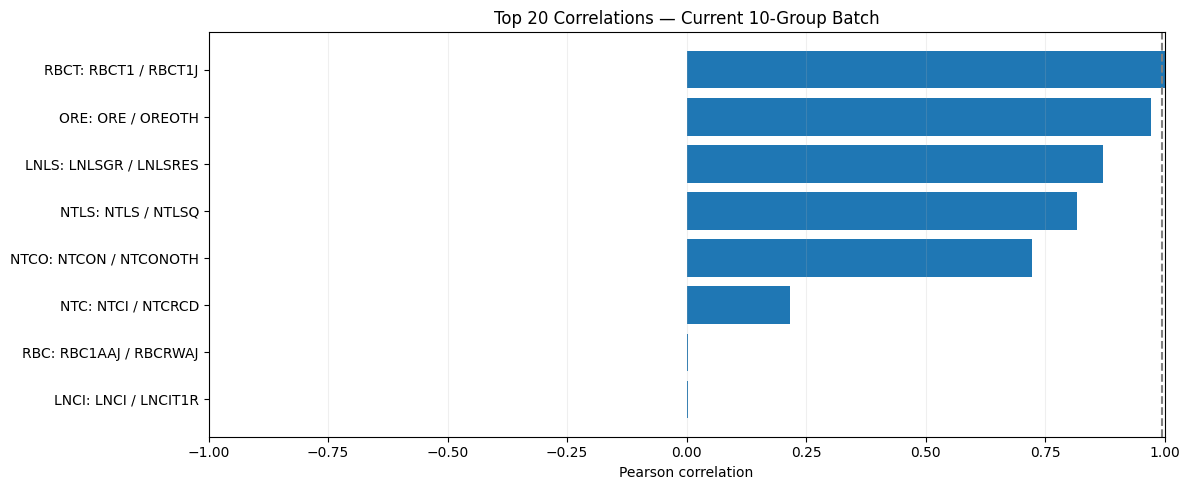


PASS — Batch audit completed.


In [286]:

for i, (group, a, b) in enumerate(P4_BATCH_PAIRS):
    shared = stage1[f"p{i}_shared"]
    nonzero = stage1[f"p{i}_nonzero"]
    exact = stage1[f"p{i}_exact"]
    missing = stage1[f"p{i}_missing"]
    factor = stage1[f"p{i}_factor"]
    corr = stage1[f"p{i}_corr"]

    exact_pct = 100 * exact / shared if shared else 0

    scale_pct = (
        100 * scale_counts.get(f"p{i}_scale", 0) / nonzero
        if nonzero else 0
    )

    if nonzero < 100:
        decision = "LOW_INFORMATION"
    elif exact_pct >= 99.9999 and missing == 0:
        decision = "EXACT_DUPLICATE"
    elif scale_pct >= 99.9999 and missing == 0:
        decision = "EXACT_SCALE"
    elif scale_pct >= 99.9999:
        decision = "SCALE_MISSINGNESS_DIFF"
    elif corr is not None and abs(corr) >= 0.995:
        decision = "HIGH_CORRELATION"
    else:
        decision = "DISTINCT"

    results.append({
        "group": group,
        "field_a": a,
        "field_b": b,
        "shared_rows": shared,
        "nonzero_rows": nonzero,
        "exact_pct": round(exact_pct, 4),
        "scale_factor": (
            round(factor, 6) if valid_factors[i] else None
        ),
        "scale_pct": round(scale_pct, 4),
        "correlation": (
            round(corr, 6) if corr is not None else None
        ),
        "missing_mismatch": missing,
        "decision": decision
    })

P4_BATCH_AUDIT = pl.DataFrame(results)

# 5. Compact summary — no long 100-row table
print("========== BATCH SUMMARY ==========")
print("Groups:",
      [g for g, _ in P4_BATCH_GROUPS])
print("Pairs analyzed:", len(results))

display(
    P4_BATCH_AUDIT
    .group_by("group", "decision")
    .agg(pl.len().alias("pairs"))
    .sort("group", "decision")
)

print("\n========== REDUNDANCY CANDIDATES ==========")
display(
    P4_BATCH_AUDIT.filter(
        pl.col("decision") != "DISTINCT"
    ).sort("group", "decision")
)

# 6. Visualize pairwise correlations for the batch
chart_data = P4_BATCH_AUDIT.filter(
    pl.col("correlation").is_not_null()
).sort("correlation", descending=True)

fig, ax = plt.subplots(figsize=(12, 5))

top = chart_data.head(20).to_dicts()

labels = [
    f'{r["group"]}: {r["field_a"]} / {r["field_b"]}'
    for r in top
]
values = [r["correlation"] for r in top]

ax.barh(labels[::-1], values[::-1])
ax.set_xlim(-1, 1)
ax.axvline(0.995, linestyle="--", color="gray")
ax.set_xlabel("Pearson correlation")
ax.set_title("Top 20 Correlations — Current 10-Group Batch")
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

print("\nPASS — Batch audit completed.")


year,rows,shared,different,difference_pct
i32,u32,u32,u32,f64
1999,41705,41603,88,0.2115
2000,40631,40535,103,0.2541
2001,39352,39262,100,0.2547
2002,38204,38116,123,0.3227
2003,37447,37362,191,0.5112
2004,36637,36560,233,0.6373
2005,35915,35839,255,0.7115
2006,35407,35337,261,0.7386


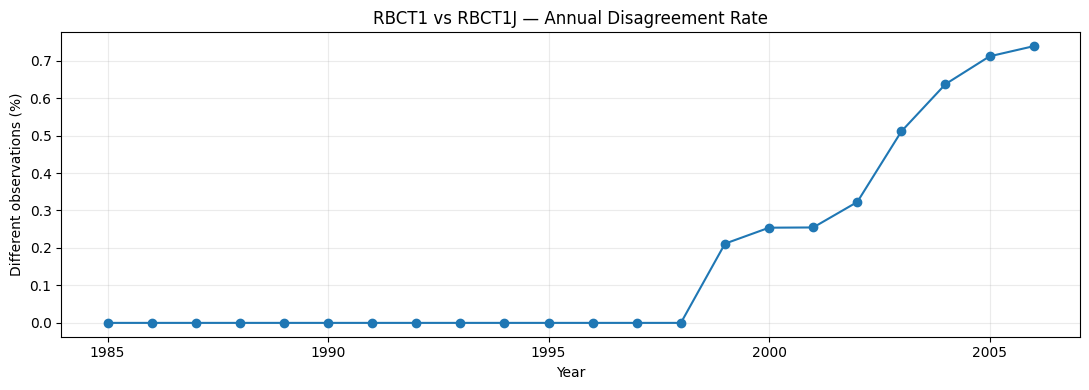

In [287]:

# 4.4L — RBCT1 vs RBCT1J: Annual disagreement

P4_RBCT_AUDIT = (
    P4_INTEGRITY_LF
    .group_by(pl.col("REPDTE").dt.year().alias("year"))
    .agg(
        pl.len().alias("rows"),
        (
            pl.col("RBCT1").is_not_null()
            & pl.col("RBCT1J").is_not_null()
        ).sum().alias("shared"),
        (
            pl.col("RBCT1").is_not_null()
            & pl.col("RBCT1J").is_not_null()
            & ((pl.col("RBCT1") - pl.col("RBCT1J")).abs() > 1e-8)
        ).fill_null(False).sum().alias("different")
    )
    .with_columns(
        (pl.col("different") / pl.col("shared") * 100)
        .round(4).alias("difference_pct")
    )
    .sort("year")
    .collect()
)

display(P4_RBCT_AUDIT.filter(pl.col("different") > 0))

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(
    P4_RBCT_AUDIT["year"].to_list(),
    P4_RBCT_AUDIT["difference_pct"].to_list(),
    marker="o"
)
ax.set_title("RBCT1 vs RBCT1J — Annual Disagreement Rate")
ax.set_ylabel("Different observations (%)")
ax.set_xlabel("Year")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


#### 4.4L | `RBCT1` và `RBCT1J`

Cặp này gần như trùng nhau trên các năm có đủ dữ liệu (tương quan khoảng **0,99997**), nhưng có thay đổi mức độ trùng khớp theo thời gian. Kết quả là bằng chứng cho bước redundancy screening, **không phải lý do sửa hoặc xóa dữ liệu nguồn**.

In [288]:

# ============================================================
# PHASE 4 — CHECKPOINT V1: FREEZE 85 FINANCIAL FIELDS
# Saves files to the current working directory
# No imports | No modification to Silver
# ============================================================

assert "P4_BASELINE_CANDIDATES_91" in globals()

P4_EXCLUSION_LOG = {
    "NTALLOTHNUM": ("DEFERRED", "Unverified definition / 2001 break"),
    "NTALLOTHQR": ("DEFERRED", "Unverified definition / 2001 break"),
    "NTLNLSQA": ("REDUNDANT", "4x NTLNLSQ; missingness differs"),
    "NONIIQA": ("REDUNDANT", "4x NONIIQ"),
    "NONIXQA": ("REDUNDANT", "4x NONIXQ"),
    "NTREQA": ("REDUNDANT", "4x NTREQ")
}

assert len(P4_BASELINE_CANDIDATES_91) == 91
assert set(P4_EXCLUSION_LOG).issubset(
    set(P4_BASELINE_CANDIDATES_91)
)

P4_BASELINE_CANDIDATES_85 = [
    f for f in P4_BASELINE_CANDIDATES_91
    if f not in P4_EXCLUSION_LOG
]

assert len(P4_BASELINE_CANDIDATES_85) == 85
assert len(set(P4_BASELINE_CANDIDATES_85)) == 85

# Freeze a reproducible snapshot in notebook memory
P4_CHECKPOINT_85_FROZEN = tuple(P4_BASELINE_CANDIDATES_85)

# File 1: Complete 85-field list
P4_CHECKPOINT_85_TABLE = pl.DataFrame({
    "index": list(range(1, 86)),
    "field": P4_BASELINE_CANDIDATES_85,
    "status": ["BASELINE_CANDIDATE"] * 85
})

P4_CHECKPOINT_85_TABLE.write_csv(
    "P4_Checkpoint_V1_85_Fields.csv"
)

# File 2: Decision ledger for all 91 reviewed fields
P4_CHECKPOINT_DECISIONS = pl.DataFrame([
    {
        "field": f,
        "decision": P4_EXCLUSION_LOG.get(
            f, ("RETAIN", "")
        )[0],
        "reason": P4_EXCLUSION_LOG.get(
            f, ("", "Passed screening to date")
        )[1]
    }
    for f in P4_BASELINE_CANDIDATES_91
])

P4_CHECKPOINT_DECISIONS.write_csv(
    "P4_Checkpoint_V1_Decision_Log.csv"
)

# File 3: Human-readable summary and field names
P4_CHECKPOINT_NOTES = """
# PHASE 4 — CHECKPOINT V1

Status: 85 baseline financial candidates
Period: TRAIN 1985–2006

## Screening waterfall
133 initial financial fields
110 after full-history missingness screening
102 after TRAIN missingness screening
91 after annual-coverage stability screening
89 after two definition-related deferrals
85 after four redundancy exclusions

## Redundancy findings
25 common-prefix groups and 99 candidate pairs screened.

Excluded annualized/related fields:
- NTLNLSQA (4x NTLNLSQ on joint observations;
  missingness differs)
- NONIIQA (4x NONIIQ)
- NONIXQA (4x NONIXQ)
- NTREQA (4x NTREQ)

Retained review pairs:
- NTLNLSQR / NTLNLSR: r=0.995537
- RBCT1 / RBCT1J: r=0.999971;
  disagreement emerges in 1999

No negative-value clipping or raw Silver deletion.

## Frozen 85-field list
""" + "\n".join(
    f"{i}. {field}"
    for i, field in enumerate(P4_CHECKPOINT_85_FROZEN, 1)
)

with open(
    "P4_Checkpoint_V1_Summary.md",
    "w",
    encoding="utf-8"
) as f:
    f.write(P4_CHECKPOINT_NOTES)

print("========== PHASE 4 CHECKPOINT SAVED ==========")
print("Baseline fields:", len(P4_CHECKPOINT_85_FROZEN))
print("Decision log entries:", P4_CHECKPOINT_DECISIONS.height)
print("\nSaved in current working directory:")
print(" - P4_Checkpoint_V1_85_Fields.csv")
print(" - P4_Checkpoint_V1_Decision_Log.csv")
print(" - P4_Checkpoint_V1_Summary.md")
print("\nPASS — 85-field checkpoint frozen.")


========== PHASE 4 CHECKPOINT SAVED ==========
Baseline fields: 85
Decision log entries: 91

Saved in current working directory:
 - P4_Checkpoint_V1_85_Fields.csv
 - P4_Checkpoint_V1_Decision_Log.csv
 - P4_Checkpoint_V1_Summary.md

PASS — 85-field checkpoint frozen.


<a id="p4-45"></a>

## 4.5 | Candidate screening và checkpoint  `[SECTION]`

Đóng băng nhóm trường tài chính được kiểm tra; phân biệt trùng thông tin với khác biệt reporting horizon.

**`[RUN]` PHASE 4 — STEP 4.5A — 2 ô liên tiếp.** Chạy lần lượt từ trên xuống; các bảng/đồ thị của cell gốc được giữ tại ô cuối của nhóm.

In [289]:

# ============================================================
# PHASE 4 — STEP 4.5A
# CROSS-GROUP REDUNDANCY DISCOVERY
# 85 frozen fields | TRAIN 1985–2006
# ============================================================

assert "P4_INTEGRITY_LF" in globals()
assert "P4_GROUP_MAP" in globals()

# Use the existing frozen checkpoint; reconstruct only if absent
if "P4_CHECKPOINT_85_FROZEN" not in globals():
    P4_CHECKPOINT_85_FROZEN = tuple(
        f for f in P4_BASELINE_CANDIDATES_91
        if f not in {
            "NTALLOTHNUM", "NTALLOTHQR",
            "NTLNLSQA", "NONIIQA",
            "NONIXQA", "NTREQA"
        }
    )

P4_45_FIELDS = list(P4_CHECKPOINT_85_FROZEN)
assert len(P4_45_FIELDS) == 85
assert len(set(P4_45_FIELDS)) == 85

# Recover each field's original common-prefix group
P4_45_FIELD_GROUP = {
    field: group
    for group, members in P4_GROUP_MAP.items()
    for field in members
}

# All pairs belonging to DIFFERENT original groups
P4_45_PAIRS = [
    (a, b)
    for i, a in enumerate(P4_45_FIELDS)
    for b in P4_45_FIELDS[i + 1:]
    if P4_45_FIELD_GROUP[a] != P4_45_FIELD_GROUP[b]
]

print("Fields:", len(P4_45_FIELDS))
print("Cross-group pairs:", len(P4_45_PAIRS))

# ------------------------------------------------------------
# Stage 1: Correlation screening in columnar batches
# ------------------------------------------------------------

P4_45_CORR_THRESHOLD = 0.98
P4_45_BATCH_SIZE = 50

P4_45_STAGE1 = []

for start in range(0, len(P4_45_PAIRS), P4_45_BATCH_SIZE):

    batch = P4_45_PAIRS[start:start + P4_45_BATCH_SIZE]

    exprs = [
        pl.corr(a, b).alias(f"c{i}")
        for i, (a, b) in enumerate(batch)
    ]

    stats = (
        P4_INTEGRITY_LF
        .select(exprs)
        .collect()
        .row(0, named=True)
    )

    for i, (a, b) in enumerate(batch):
        r = stats[f"c{i}"]

        if r is not None and r == r:
            if abs(r) >= P4_45_CORR_THRESHOLD:
                P4_45_STAGE1.append({
                    "field_a": a,
                    "field_b": b,
                    "group_a": P4_45_FIELD_GROUP[a],
                    "group_b": P4_45_FIELD_GROUP[b],
                    "correlation": r
                })

print("High-correlation cross-group pairs:",
      len(P4_45_STAGE1))

# ------------------------------------------------------------
# Stage 2: Exact / proportional relationship verification
# ------------------------------------------------------------

P4_45_RESULTS = []

for record in P4_45_STAGE1:

    a, b = record["field_a"], record["field_b"]
    x, y = pl.col(a), pl.col(b)

    both = (
        x.is_not_null() & y.is_not_null()
    ).fill_null(False)

    informative = (
        both & ((x.abs() > 1e-10) | (y.abs() > 1e-10))
    ).fill_null(False)

    # Estimate constant scale factor
    factor = (
        P4_INTEGRITY_LF
        .select(
            pl.when(both & (x.abs() > 1e-10))
            .then(y / x)
            .otherwise(None)
            .median()
            .alias("factor")
        )
        .collect()
        .item()
    )

    factor_ok = (
        factor is not None
        and factor == factor
        and 1e-10 < abs(factor) < 1e10
    )

    scale_match = (
        (
            (y - factor * x).abs()
            <= 1e-8 + 1e-6 * pl.max_horizontal(
                y.abs(), (factor * x).abs()
            )
        ).fill_null(False)
        if factor_ok else pl.lit(False)
    )

    stats = (
        P4_INTEGRITY_LF
        .select(
            both.sum().alias("shared"),
            informative.sum().alias("informative"),
            (
                x.is_null() != y.is_null()
            ).sum().alias("missing_diff"),
            (
                informative & (x == y)
            ).fill_null(False).sum().alias("exact"),
            (
                informative & scale_match
            ).fill_null(False).sum().alias("scaled")
        )
        .collect()
        .row(0, named=True)
    )

    n = stats["informative"]
    exact_pct = 100 * stats["exact"] / n if n else 0
    scale_pct = 100 * stats["scaled"] / n if n else 0

    if n < 100:
        decision = "LOW_INFORMATION"
    elif exact_pct >= 99.9999 and stats["missing_diff"] == 0:
        decision = "EXACT_DUPLICATE"
    elif scale_pct >= 99.9999 and stats["missing_diff"] == 0:
        decision = "EXACT_SCALE"
    elif scale_pct >= 99.9999:
        decision = "SCALE_MISSINGNESS_DIFF"
    else:
        decision = "HIGH_CORRELATION_ONLY"

    P4_45_RESULTS.append({
        **record,
        "shared_rows": stats["shared"],
        "informative_rows": n,
        "scale_factor": factor if factor_ok else None,
        "exact_pct": round(exact_pct, 4),
        "scale_pct": round(scale_pct, 4),
        "missing_mismatch": stats["missing_diff"],
        "decision": decision
    })


Fields: 85
Cross-group pairs: 3490
High-correlation cross-group pairs: 17


In [290]:

P4_45_SCHEMA = {
    "field_a": pl.String,
    "field_b": pl.String,
    "group_a": pl.String,
    "group_b": pl.String,
    "correlation": pl.Float64,
    "shared_rows": pl.Int64,
    "informative_rows": pl.Int64,
    "scale_factor": pl.Float64,
    "exact_pct": pl.Float64,
    "scale_pct": pl.Float64,
    "missing_mismatch": pl.Int64,
    "decision": pl.String
}

P4_45_AUDIT = pl.DataFrame(
    P4_45_RESULTS,
    schema=P4_45_SCHEMA
).sort("correlation", descending=True)

print("\n========== CROSS-GROUP SUMMARY ==========")

if P4_45_AUDIT.height:
    display(
        P4_45_AUDIT.group_by("decision")
        .agg(pl.len().alias("pairs"))
        .sort("pairs", descending=True)
    )

    print("\n========== TOP 30 CANDIDATE PAIRS ==========")
    display(P4_45_AUDIT.head(30))
else:
    print("No cross-group pairs exceeded |r| >= 0.98.")

print("\nPASS — Cross-group redundancy screening completed.")



========== CROSS-GROUP SUMMARY ==========


decision,pairs
str,u32
"""HIGH_CORRELATION_ONLY""",17



========== TOP 30 CANDIDATE PAIRS ==========


field_a,field_b,group_a,group_b,correlation,shared_rows,informative_rows,scale_factor,exact_pct,scale_pct,missing_mismatch,decision
str,str,str,str,f64,i64,i64,f64,f64,f64,i64,str
"""EOTHNINT""","""ADDNONINTEXP""","""EOTH""","""ADDN""",0.998601,1120418,1119495,1.0,95.9456,95.9456,2709,"""HIGH_CORRELATION_ONLY"""
"""EOTHNINQ""","""ADDNONINTEXPQ""","""EOTH""","""ADDN""",0.998335,1120419,1119367,1.0,96.0466,96.0466,2708,"""HIGH_CORRELATION_ONLY"""
"""DRCON""","""NTCON""","""DRCO""","""NTCO""",0.997039,1056594,838551,0.730769,13.9838,0.0648,1,"""HIGH_CORRELATION_ONLY"""
"""NTCRCD""","""DRCRCD""","""NTC""","""DRCR""",0.996925,1051120,262776,1.039326,36.3405,0.0015,0,"""HIGH_CORRELATION_ONLY"""
"""DRLNLS""","""NTLNLS""","""DRLN""","""NTLN""",0.993693,1057804,939933,0.752475,9.7967,0.0035,0,"""HIGH_CORRELATION_ONLY"""
…,…,…,…,…,…,…,…,…,…,…,…
"""NTCI""","""DRCI""","""NTC""","""DRCI""",0.982203,1056595,706172,1.006849,17.9046,0.0057,0,"""HIGH_CORRELATION_ONLY"""
"""NTLS""","""DRLS""","""NTLS""","""DRLS""",0.9813,956914,32614,1.0,26.7676,26.7676,0,"""HIGH_CORRELATION_ONLY"""
"""RBCT1""","""EQ""","""RBCT""","""EQ""",0.980775,1057795,1057778,1.0,45.9094,45.9102,62624,"""HIGH_CORRELATION_ONLY"""



PASS — Cross-group redundancy screening completed.


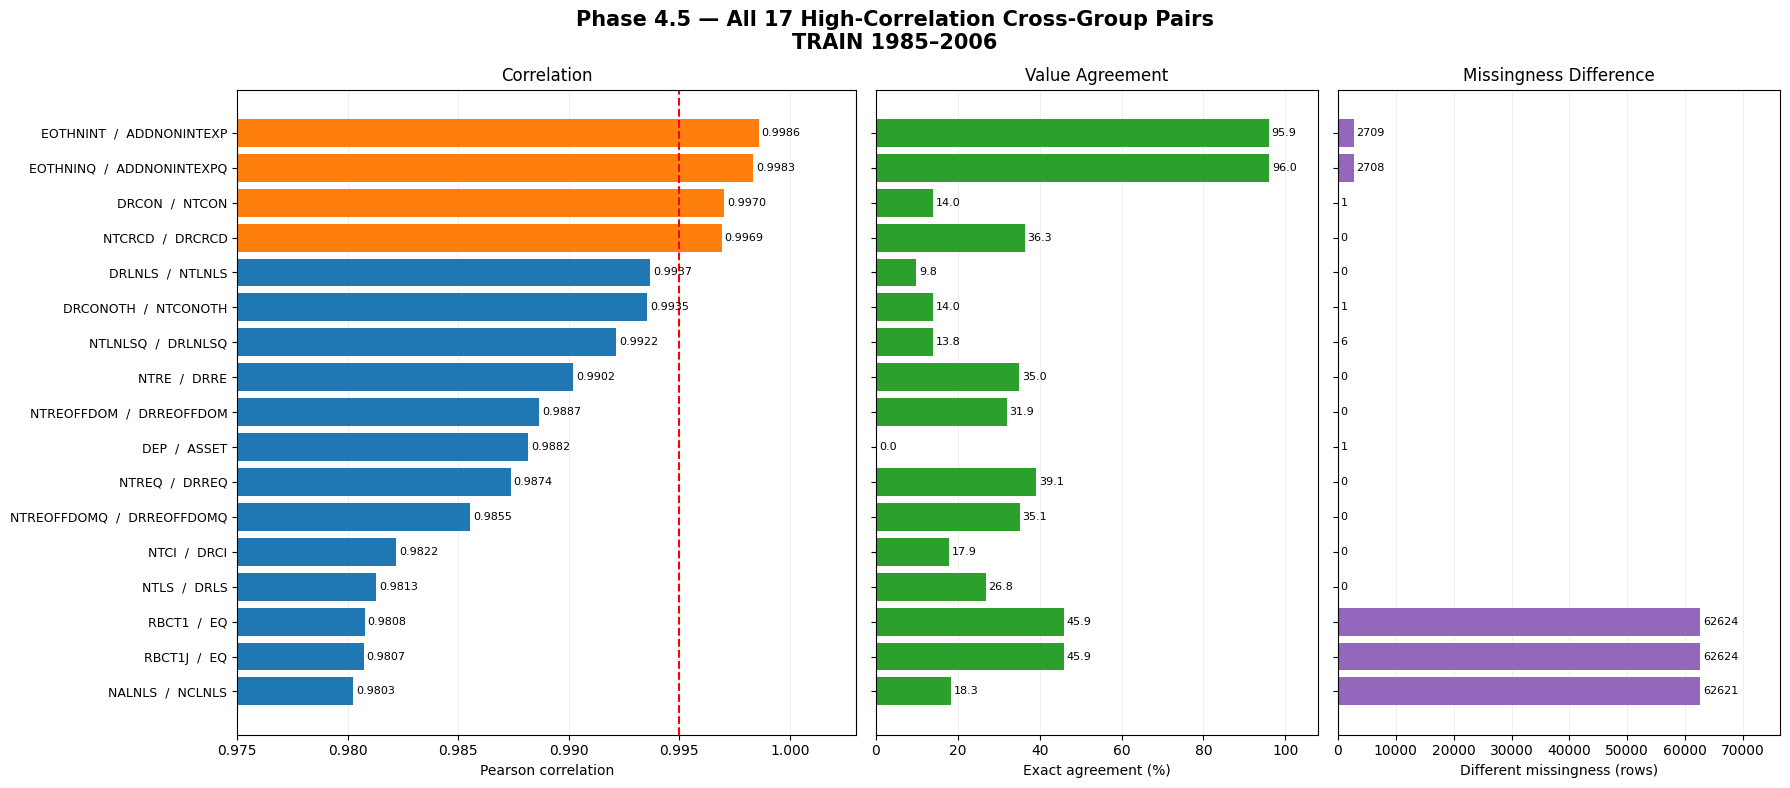

Total high-correlation pairs: 17
Remaining baseline fields: 85


In [291]:

# ============================================================
# PHASE 4 — STEP 4.5B
# ALL CROSS-GROUP REDUNDANCY CANDIDATES — 17 PAIRS
# Uses existing aggregated results; no imports
# ============================================================

assert "P4_45_AUDIT" in globals()

P4_45_CHART = P4_45_AUDIT.sort(
    "correlation", descending=False
)

rows = P4_45_CHART.to_dicts()
labels = [
    f'{r["field_a"]}  /  {r["field_b"]}'
    for r in rows
]
positions = list(range(len(rows)))

fig, axes = plt.subplots(
    1, 3, figsize=(18, max(7, len(rows) * 0.47)),
    sharey=True,
    gridspec_kw={"width_ratios": [1.4, 1, 1]}
)

# 1. Correlation
bars = axes[0].barh(
    positions,
    [r["correlation"] for r in rows],
    color=[
        "tab:orange" if r["correlation"] >= 0.995
        else "tab:blue"
        for r in rows
    ]
)

axes[0].set_yticks(positions)
axes[0].set_yticklabels(labels, fontsize=9)
axes[0].set_xlim(0.975, 1.003)
axes[0].axvline(0.995, color="red", linestyle="--")
axes[0].set_xlabel("Pearson correlation")
axes[0].set_title("Correlation")
axes[0].bar_label(bars, fmt="%.4f", padding=2, fontsize=8)

# 2. Exact agreement among informative observations
bars = axes[1].barh(
    positions,
    [r["exact_pct"] for r in rows],
    color="tab:green"
)

axes[1].set_xlim(0, 108)
axes[1].set_xlabel("Exact agreement (%)")
axes[1].set_title("Value Agreement")
axes[1].bar_label(bars, fmt="%.1f", padding=2, fontsize=8)

# 3. Missingness disagreement
bars = axes[2].barh(
    positions,
    [r["missing_mismatch"] for r in rows],
    color="tab:purple"
)

axes[2].set_xlabel("Different missingness (rows)")
axes[2].set_title("Missingness Difference")
axes[2].bar_label(bars, padding=2, fontsize=8)
axes[2].set_xlim(
    0,
    max(r["missing_mismatch"] for r in rows) * 1.22
    if rows else 1
)

for ax in axes:
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle(
    f"Phase 4.5 — All {len(rows)} High-Correlation "
    "Cross-Group Pairs\nTRAIN 1985–2006",
    fontsize=15, fontweight="bold"
)

plt.tight_layout()
plt.show()

print("Total high-correlation pairs:", len(rows))
print("Remaining baseline fields:", len(P4_CHECKPOINT_85_FROZEN))


========== DISCREPANCY SUMMARY ==========


pair,shared,different,missing_mismatch,max_affected_banks_in_year,different_pct
str,u32,u32,u32,u32,f64
"""EOTHNINQ / ADDNONINTEXPQ""",1120419,44253,2708,2792,3.95
"""EOTHNINT / ADDNONINTEXP""",1120418,45389,2709,2793,4.051


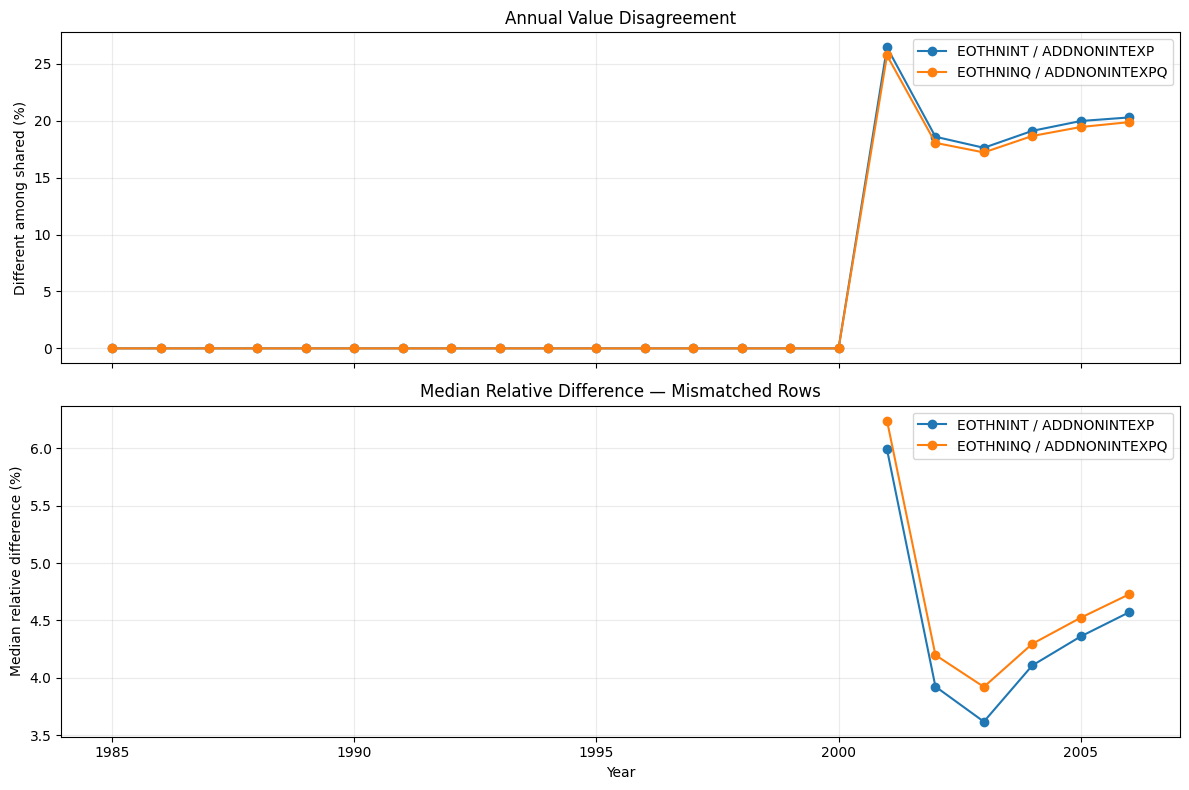


========== ANNUAL RESULTS ==========


pair,year,different_pct,median_relative_diff,p95_relative_diff,affected_banks,missing_mismatch
str,i32,f64,f64,f64,u32,u32
"""EOTHNINQ / ADDNONINTEXPQ""",1985,0.0,null,null,0,125
"""EOTHNINQ / ADDNONINTEXPQ""",1986,0.0,null,null,0,128
"""EOTHNINQ / ADDNONINTEXPQ""",1987,0.0,null,null,0,130
"""EOTHNINQ / ADDNONINTEXPQ""",1988,0.0,null,null,0,136
"""EOTHNINQ / ADDNONINTEXPQ""",1989,0.0,null,null,0,144
…,…,…,…,…,…,…
"""EOTHNINT / ADDNONINTEXP""",2002,18.601112,0.039244,0.231229,1968,88
"""EOTHNINT / ADDNONINTEXP""",2003,17.630213,0.036187,0.207467,1843,85
"""EOTHNINT / ADDNONINTEXP""",2004,19.119256,0.041084,0.208426,1922,77


In [292]:

# ============================================================
# PHASE 4 — 4.5C: NEAR-DUPLICATE DISCREPANCY AUDIT
# EOTH vs ADDN | TRAIN 1985–2006
# ============================================================

P4_45C_PAIRS = [
    ("EOTHNINT", "ADDNONINTEXP"),
    ("EOTHNINQ", "ADDNONINTEXPQ")
]

P4_45C_RESULTS = []

for a, b in P4_45C_PAIRS:
    x, y = pl.col(a), pl.col(b)

    valid = x.is_not_null() & y.is_not_null()
    different = (
        valid & (x != y)
    ).fill_null(False)

    relative_diff = (
        (x - y).abs()
        / pl.max_horizontal(x.abs(), y.abs(), pl.lit(1.0))
    )

    # Aggregate by year directly in LazyFrame
    annual = (
        P4_INTEGRITY_LF
        .group_by(pl.col("REPDTE").dt.year().alias("year"))
        .agg(
            pl.len().alias("rows"),
            valid.fill_null(False).sum().alias("shared"),
            different.sum().alias("different"),
            (
                x.is_null() != y.is_null()
            ).sum().alias("missing_mismatch"),
            relative_diff.filter(different)
                .median().alias("median_relative_diff"),
            relative_diff.filter(different)
                .quantile(0.95).alias("p95_relative_diff"),
            pl.col("CERT").filter(different)
                .n_unique().alias("affected_banks")
        )
        .with_columns(
            (
                pl.col("different")
                / pl.col("shared") * 100
            ).alias("different_pct")
        )
        .sort("year")
        .collect()
    )

    P4_45C_RESULTS.append(
        annual.with_columns(
            pl.lit(f"{a} / {b}").alias("pair")
        )
    )

P4_45C_ANNUAL = pl.concat(P4_45C_RESULTS)

print("========== DISCREPANCY SUMMARY ==========")
display(
    P4_45C_ANNUAL
    .group_by("pair")
    .agg(
        pl.col("shared").sum().alias("shared"),
        pl.col("different").sum().alias("different"),
        pl.col("missing_mismatch").sum()
          .alias("missing_mismatch"),
        pl.col("affected_banks").max()
          .alias("max_affected_banks_in_year")
    )
    .with_columns(
        (
            100 * pl.col("different") / pl.col("shared")
        ).round(3).alias("different_pct")
    )
)

# Charts — annual discrepancy rate and median difference
fig, axes = plt.subplots(
    2, 1, figsize=(12, 8), sharex=True
)

for a, b in P4_45C_PAIRS:
    name = f"{a} / {b}"

    d = (
        P4_45C_ANNUAL
        .filter(pl.col("pair") == name)
        .sort("year")
    )

    years = d["year"].to_list()

    axes[0].plot(
        years,
        d["different_pct"].to_list(),
        marker="o", label=name
    )

    axes[1].plot(
        years,
        (
            d["median_relative_diff"] * 100
        ).to_list(),
        marker="o", label=name
    )

axes[0].set_title("Annual Value Disagreement")
axes[0].set_ylabel("Different among shared (%)")

axes[1].set_title("Median Relative Difference — Mismatched Rows")
axes[1].set_ylabel("Median relative difference (%)")
axes[1].set_xlabel("Year")

for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.show()

print("\n========== ANNUAL RESULTS ==========")
display(
    P4_45C_ANNUAL.select(
        "pair", "year", "different_pct",
        "median_relative_diff",
        "p95_relative_diff",
        "affected_banks",
        "missing_mismatch"
    ).sort("pair", "year")
)


#### 4.5C | Chênh lệch giữa `EOTH*` và `ADDN*`

Hai cặp chỉ tiêu gần như trùng trên quan sát có dữ liệu đến **2000**, rồi có tỷ lệ khác nhau đáng kể từ **2001**. Biểu đồ theo năm quan trọng hơn một hệ số tương quan gộp, vì thay đổi có thể liên quan chế độ ghi nhận kế toán.

========== POST-2000 DISCREPANCY STRUCTURE ==========


shared,different,positive_delta,negative_delta,affected_banks,median_assets_affected,median_assets_unaffected,measure
u32,u32,u32,u32,u32,f64,f64,str
222476,45389,34,45355,3745,268501.0,86945.0,"""annual"""
222476,44253,457,43796,3750,271191.0,87305.0,"""quarter"""


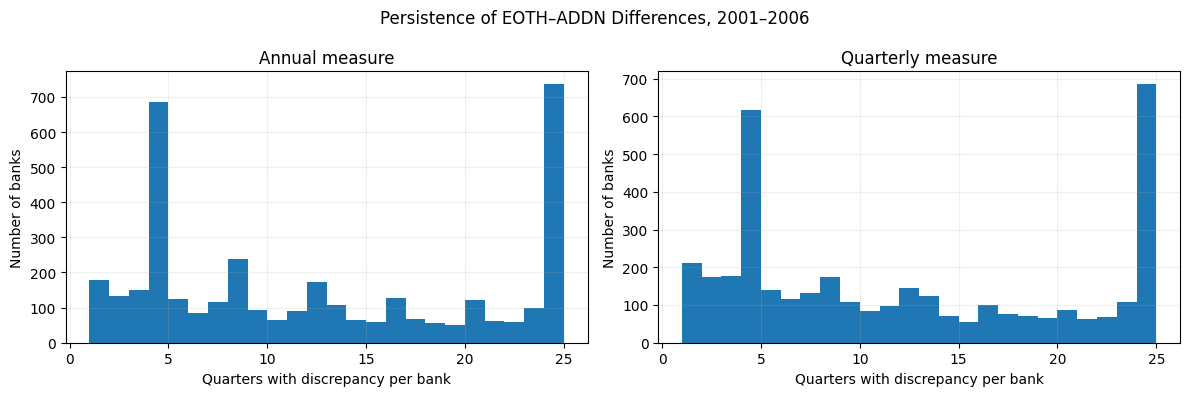

In [293]:

# ============================================================
# PHASE 4 — 4.5D
# EOTH–ADDN DISCREPANCY STRUCTURE (2001–2006)
# Polars LazyFrame | No imports
# ============================================================

P4_45D_LF = (
    P4_INTEGRITY_LF
    .filter(pl.col("REPDTE").dt.year() >= 2001)
    .select(
        "CERT", "REPDTE", "ASSET",
        "EOTHNINT", "ADDNONINTEXP",
        "EOTHNINQ", "ADDNONINTEXPQ"
    )
    .with_columns(
        *[
            (pl.col(a) - pl.col(b)).alias(f"delta_{suffix}")
            for a, b, suffix in [
                ("EOTHNINT", "ADDNONINTEXP", "annual"),
                ("EOTHNINQ", "ADDNONINTEXPQ", "quarter")
            ]
        ]
    )
)

P4_45D_RESULTS = []

for suffix in ("annual", "quarter"):
    d = pl.col(f"delta_{suffix}")
    valid = d.is_not_null()
    changed = valid & (d != 0)

    result = (
        P4_45D_LF
        .select(
            valid.sum().alias("shared"),
            changed.fill_null(False).sum().alias("different"),
            (d > 0).fill_null(False).sum().alias("positive_delta"),
            (d < 0).fill_null(False).sum().alias("negative_delta"),
            pl.col("CERT").filter(changed).n_unique()
              .alias("affected_banks"),
            pl.col("ASSET").filter(changed).median()
              .alias("median_assets_affected"),
            pl.col("ASSET").filter(valid & (d == 0)).median()
              .alias("median_assets_unaffected")
        )
        .collect()
        .with_columns(pl.lit(suffix).alias("measure"))
    )

    P4_45D_RESULTS.append(result)

P4_45D_SUMMARY = pl.concat(
    P4_45D_RESULTS,
    how="vertical"
)

print("========== POST-2000 DISCREPANCY STRUCTURE ==========")
display(P4_45D_SUMMARY)

# Persistence: number of distinct quarters with differences per bank
P4_45D_PERSISTENCE = (
    P4_45D_LF
    .group_by("CERT")
    .agg(
        (pl.col("delta_annual") != 0)
          .fill_null(False).sum().alias("annual_diff_quarters"),
        (pl.col("delta_quarter") != 0)
          .fill_null(False).sum().alias("quarter_diff_quarters")
    )
    .collect()
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col, name in zip(
    axes,
    ["annual_diff_quarters", "quarter_diff_quarters"],
    ["Annual measure", "Quarterly measure"]
):
    vals = P4_45D_PERSISTENCE[col].to_list()
    vals = [v for v in vals if v > 0]

    if vals:
        ax.hist(vals, bins=range(1, max(vals) + 2))
    ax.set_title(name)
    ax.set_xlabel("Quarters with discrepancy per bank")
    ax.set_ylabel("Number of banks")
    ax.grid(alpha=0.2)

plt.suptitle("Persistence of EOTH–ADDN Differences, 2001–2006")
plt.tight_layout()
plt.show()


#### Diễn giải | EOTH và ADDN không đồng nhất tuyệt đối

| Trường | Cách hiểu hiện tại | Mức xác minh |
|---|---|---|
| `EOTHNINT` | Other non-interest expense, số liệu hợp nhất | Đã đối chiếu định nghĩa FDIC |
| `EOTHNINQ` | Khả năng là thành phần theo quý | Chưa xác minh đầy đủ mã `Q` |
| `ADDNONINTEXP` | Có thể là chỉ tiêu chi phí phi lãi bổ sung | Chưa xác minh công thức chính thức |
| `ADDNONINTEXPQ` | Có thể là phiên bản theo quý | Chưa xác minh công thức chính thức |

**Quan sát thực nghiệm:** các cặp khớp trong 1985–2000 nhưng phân kỳ sau 2001. Thay đổi định nghĩa hạch toán là một **giả thuyết phù hợp**, chưa phải đẳng thức được chứng minh. **Quyết định:** giữ các trường trong checkpoint đã chọn; không tự xây dựng công thức thay thế.

<a id="p4-46"></a>

## 4.6 | CAMELS mapping và coverage  `[SECTION]`

Kiểm tra logic kinh tế của biến theo nhóm CAMELS và phát hiện các nhóm còn thiếu.

========== CAMELS COVERAGE ==========


camels_domain,camels_code,n_fields,fields
str,str,u32,list[str]
"""Asset Quality""","""A""",54,"[""DRAGSM"", ""DRAGSMQ"", … ""P9LNLS""]"
"""Earnings""","""E""",17,"[""ADDNONII"", ""ADDNONIIQ"", … ""ROE""]"
"""Liquidity""","""L""",6,"[""BRO"", ""CHBAL"", … ""SC""]"
"""Capital Adequacy""","""C""",5,"[""EQ"", ""RBC1AAJ"", … ""RBCT1J""]"
"""UNRESOLVED""","""?""",2,"[""IDERNCVQR"", ""IDERNCVR""]"
"""CONTROL — BANK SIZE""","""CONTROL""",1,"[""ASSET""]"



========== FIELDS REQUIRING REVIEW ==========


field,camels_domain,camels_code,verification
str,str,str,str
"""IDERNCVR""","""UNRESOLVED""","""?""","""REVIEW_REQUIRED"""
"""IDERNCVQR""","""UNRESOLVED""","""?""","""REVIEW_REQUIRED"""


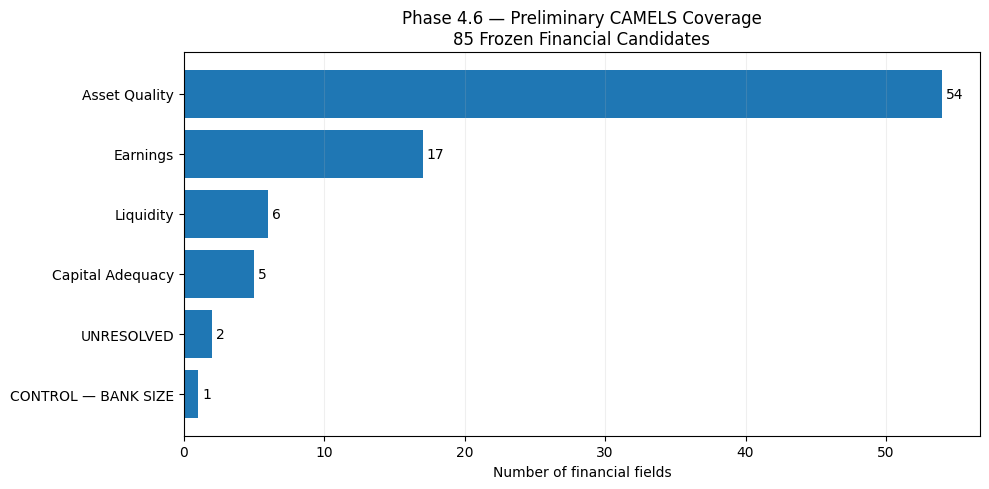


Total classified/reviewed: 85
Baseline remains: 85


In [294]:

# ============================================================
# PHASE 4 — 4.6A: PRELIMINARY CAMELS CLASSIFICATION
# Frozen 85 financial fields | No imports
# No modification to prior phases
# ============================================================

assert "P4_CHECKPOINT_85_FROZEN" in globals()

P4_46_FIELDS = list(P4_CHECKPOINT_85_FROZEN)
assert len(P4_46_FIELDS) == 85

# Preliminary accounting-domain assignment.
# Prefix-based rules are hypotheses, NOT verified definitions.
P4_46_RULES = [
    ("Capital Adequacy", "C",
     lambda f: f == "EQ" or f.startswith(("RBC", "RBCT"))),

    ("Asset Quality", "A",
     lambda f: f.startswith((
         "NT", "DR", "LN", "NAL", "NCL", "P9LN", "ORE"
     ))),

    ("Earnings", "E",
     lambda f: f in {
         "ROA", "ROE", "NIMY", "INTINC", "EINTEXP"
     } or f.startswith(("NONI", "EOTH", "ADDN"))),

    ("Liquidity", "L",
     lambda f: f in {
         "DEP", "DEPUNINS", "COREDEP",
         "CHBAL", "SC", "BRO"
     })
]

def p4_classify_camels(field):
    matches = [
        (name, code)
        for name, code, rule in P4_46_RULES
        if rule(field)
    ]

    if len(matches) == 1:
        return matches[0][0], matches[0][1], "PROVISIONAL"

    if len(matches) > 1:
        return "UNRESOLVED", "?", "AMBIGUOUS"

    return "UNRESOLVED", "?", "REVIEW_REQUIRED"


P4_46_MAPPING = pl.DataFrame([
    {
        "field": f,
        "camels_domain": p4_classify_camels(f)[0],
        "camels_code": p4_classify_camels(f)[1],
        "verification": p4_classify_camels(f)[2]
    }
    for f in P4_46_FIELDS
])

# Bank size is a control variable, not a CAMELS component
P4_46_MAPPING = P4_46_MAPPING.with_columns(
    pl.when(pl.col("field") == "ASSET")
    .then(pl.lit("CONTROL — BANK SIZE"))
    .otherwise(pl.col("camels_domain"))
    .alias("camels_domain"),

    pl.when(pl.col("field") == "ASSET")
    .then(pl.lit("CONTROL"))
    .otherwise(pl.col("camels_code"))
    .alias("camels_code"),

    pl.when(pl.col("field") == "ASSET")
    .then(pl.lit("PROVISIONAL"))
    .otherwise(pl.col("verification"))
    .alias("verification")
)

# Validate coverage
assert P4_46_MAPPING.height == 85
assert P4_46_MAPPING["field"].n_unique() == 85

P4_46_SUMMARY = (
    P4_46_MAPPING
    .group_by("camels_domain", "camels_code")
    .agg(
        pl.len().alias("n_fields"),
        pl.col("field").sort().alias("fields")
    )
    .sort("n_fields", descending=True)
)

print("========== CAMELS COVERAGE ==========")
display(P4_46_SUMMARY)

print("\n========== FIELDS REQUIRING REVIEW ==========")
display(
    P4_46_MAPPING.filter(
        pl.col("verification") != "PROVISIONAL"
    )
)

# Visualization
chart = (
    P4_46_MAPPING
    .group_by("camels_domain")
    .agg(pl.len().alias("n"))
    .sort("n")
)

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    chart["camels_domain"].to_list(),
    chart["n"].to_list()
)
ax.bar_label(bars, padding=3)

ax.set_xlabel("Number of financial fields")
ax.set_title(
    "Phase 4.6 — Preliminary CAMELS Coverage\n"
    "85 Frozen Financial Candidates"
)
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

print("\nTotal classified/reviewed:",
      P4_46_MAPPING.height)
print("Baseline remains:",
      len(P4_CHECKPOINT_85_FROZEN))


In [295]:

# ============================================================
# PHASE 4 — 4.6B: CAMELS MAPPING QUALITY AUDIT
# Uses existing mapping | No rescan | No imports
# ============================================================

assert "P4_46_MAPPING" in globals()
assert P4_46_MAPPING.height == 85

# Fields needing definition-based verification
P4_46B_REVIEW = {
    "IDERNCVR": "UNVERIFIED_DEFINITION",
    "IDERNCVQR": "UNVERIFIED_DEFINITION",
    "RBCT1": "REGULATORY_CAPITAL_OVERLAP",
    "RBCT1J": "REGULATORY_CAPITAL_OVERLAP",
    "NTLNLSQR": "QUARTERLY_VS_YTD",
    "NTLNLSR": "QUARTERLY_VS_YTD",
    "EOTHNINT": "POST_2000_ACCOUNTING_SCOPE",
    "EOTHNINQ": "POST_2000_ACCOUNTING_SCOPE",
    "ADDNONINTEXP": "POST_2000_ACCOUNTING_SCOPE",
    "ADDNONINTEXPQ": "POST_2000_ACCOUNTING_SCOPE"
}

P4_46B_AUDIT = (
    P4_46_MAPPING
    .with_columns(
        pl.col("field")
        .replace_strict(
            P4_46B_REVIEW,
            default="STANDARD_REVIEW"
        )
        .alias("review_flag")
    )
    .sort("camels_domain", "field")
)

print("========== FULL CAMELS FIELD MAPPING ==========")
display(P4_46B_AUDIT)

print("\n========== SPECIAL REVIEW FIELDS ==========")
display(
    P4_46B_AUDIT.filter(
        pl.col("review_flag") != "STANDARD_REVIEW"
    )
)

print("\n========== ASSET QUALITY — ALL 54 FIELDS ==========")
display(
    P4_46B_AUDIT
    .filter(pl.col("camels_code") == "A")
    .select("field", "review_flag")
)

print("\n========== COVERAGE CHECK ==========")
print("Total fields:", P4_46B_AUDIT.height)
print("Unique fields:", P4_46B_AUDIT["field"].n_unique())
print("Review flags:", len(P4_46B_REVIEW))
print("Baseline unchanged:", len(P4_CHECKPOINT_85_FROZEN))


========== FULL CAMELS FIELD MAPPING ==========


field,camels_domain,camels_code,verification,review_flag
str,str,str,str,str
"""DRAGSM""","""Asset Quality""","""A""","""PROVISIONAL""","""STANDARD_REVIEW"""
"""DRAGSMQ""","""Asset Quality""","""A""","""PROVISIONAL""","""STANDARD_REVIEW"""
"""DRCI""","""Asset Quality""","""A""","""PROVISIONAL""","""STANDARD_REVIEW"""
"""DRCIQ""","""Asset Quality""","""A""","""PROVISIONAL""","""STANDARD_REVIEW"""
"""DRCON""","""Asset Quality""","""A""","""PROVISIONAL""","""STANDARD_REVIEW"""
…,…,…,…,…
"""DEP""","""Liquidity""","""L""","""PROVISIONAL""","""STANDARD_REVIEW"""
"""DEPUNINS""","""Liquidity""","""L""","""PROVISIONAL""","""STANDARD_REVIEW"""
"""SC""","""Liquidity""","""L""","""PROVISIONAL""","""STANDARD_REVIEW"""



========== SPECIAL REVIEW FIELDS ==========


field,camels_domain,camels_code,verification,review_flag
str,str,str,str,str
"""NTLNLSQR""","""Asset Quality""","""A""","""PROVISIONAL""","""QUARTERLY_VS_YTD"""
"""NTLNLSR""","""Asset Quality""","""A""","""PROVISIONAL""","""QUARTERLY_VS_YTD"""
"""RBCT1""","""Capital Adequacy""","""C""","""PROVISIONAL""","""REGULATORY_CAPITAL_OVERLAP"""
"""RBCT1J""","""Capital Adequacy""","""C""","""PROVISIONAL""","""REGULATORY_CAPITAL_OVERLAP"""
"""ADDNONINTEXP""","""Earnings""","""E""","""PROVISIONAL""","""POST_2000_ACCOUNTING_SCOPE"""
"""ADDNONINTEXPQ""","""Earnings""","""E""","""PROVISIONAL""","""POST_2000_ACCOUNTING_SCOPE"""
"""EOTHNINQ""","""Earnings""","""E""","""PROVISIONAL""","""POST_2000_ACCOUNTING_SCOPE"""
"""EOTHNINT""","""Earnings""","""E""","""PROVISIONAL""","""POST_2000_ACCOUNTING_SCOPE"""
"""IDERNCVQR""","""UNRESOLVED""","""?""","""REVIEW_REQUIRED""","""UNVERIFIED_DEFINITION"""



========== ASSET QUALITY — ALL 54 FIELDS ==========


field,review_flag
str,str
"""DRAGSM""","""STANDARD_REVIEW"""
"""DRAGSMQ""","""STANDARD_REVIEW"""
"""DRCI""","""STANDARD_REVIEW"""
"""DRCIQ""","""STANDARD_REVIEW"""
"""DRCON""","""STANDARD_REVIEW"""
…,…
"""NTREQR""","""STANDARD_REVIEW"""
"""NTRER""","""STANDARD_REVIEW"""
"""ORE""","""STANDARD_REVIEW"""



========== COVERAGE CHECK ==========
Total fields: 85
Unique fields: 85
Review flags: 10
Baseline unchanged: 85


#### Ghi chú CAMELS | `IDERNCVR`

`IDERNCVR` có ý nghĩa **earnings coverage of net charge-offs**, tức năng lực lợi nhuận bù đắp tổn thất tín dụng. Nhóm CAMELS nên dựa trên nội dung kinh tế của trường, không chỉ dựa vào tiền tố tên biến.

In [296]:

# ============================================================
# PHASE 4 — 4.6C: RESOLVE IDER CLASSIFICATION
# Update mapping only | No data scan | No imports
# ============================================================

P4_46C_MAPPING = (
    P4_46B_AUDIT
    .with_columns(
        pl.when(pl.col("field").is_in([
            "IDERNCVR", "IDERNCVQR"
        ]))
        .then(pl.lit("Earnings"))
        .otherwise(pl.col("camels_domain"))
        .alias("camels_domain"),

        pl.when(pl.col("field").is_in([
            "IDERNCVR", "IDERNCVQR"
        ]))
        .then(pl.lit("E"))
        .otherwise(pl.col("camels_code")) 
        .alias("camels_code"),

        pl.when(pl.col("field") == "IDERNCVR")
        .then(pl.lit("DEFINITION_REFERENCED"))
        .when(pl.col("field") == "IDERNCVQR")
        .then(pl.lit("PROVISIONAL_QUARTERLY"))
        .otherwise(pl.col("verification"))
        .alias("verification"),

        pl.when(pl.col("field").is_in([
            "IDERNCVR", "IDERNCVQR"
        ]))
        .then(pl.lit("EARNINGS_COVERAGE_REVIEW"))
        .otherwise(pl.col("review_flag"))
        .alias("review_flag")
    )
)

assert P4_46C_MAPPING.height == 85
assert P4_46C_MAPPING["field"].n_unique() == 85

P4_46C_SUMMARY = (
    P4_46C_MAPPING
    .group_by("camels_domain")
    .agg(pl.len().alias("n_fields"))
    .sort("n_fields", descending=True)
)

print("========== REFINED CAMELS COVERAGE ==========")
display(P4_46C_SUMMARY)

print("\n========== IDER FIELDS ==========")
display(
    P4_46C_MAPPING.filter(
        pl.col("field").str.starts_with("IDER")
    )
)

print("\nPASS — 85 fields retained.")


========== REFINED CAMELS COVERAGE ==========


camels_domain,n_fields
str,u32
"""Asset Quality""",54
"""Earnings""",19
"""Liquidity""",6
"""Capital Adequacy""",5
"""CONTROL — BANK SIZE""",1



========== IDER FIELDS ==========


field,camels_domain,camels_code,verification,review_flag
str,str,str,str,str
"""IDERNCVQR""","""Earnings""","""E""","""PROVISIONAL_QUARTERLY""","""EARNINGS_COVERAGE_REVIEW"""
"""IDERNCVR""","""Earnings""","""E""","""DEFINITION_REFERENCED""","""EARNINGS_COVERAGE_REVIEW"""



PASS — 85 fields retained.


========== ASSET QUALITY SUBCATEGORIES ==========


asset_subcategory,n_fields,fields
str,u32,list[str]
"""Net Charge-offs / Credit Losse…",20,"[""NTAGSM"", ""NTAGSMA"", … ""NTRER""]"
"""Gross Charge-offs""",18,"[""DRAGSM"", ""DRAGSMQ"", … ""DRREQ""]"
"""Loan Portfolio / Composition""",11,"[""LNATRESR"", ""LNCDT1R"", … ""LNRESNCR""]"
"""Nonperforming / Past-due Loans""",3,"[""NALNLS"", ""NCLNLS"", ""P9LNLS""]"
"""Other Real Estate Owned""",2,"[""ORE"", ""OREOTH""]"



========== FULL FIELD ASSIGNMENTS ==========


field,asset_subcategory,verification
str,str,str
"""DRAGSM""","""Gross Charge-offs""","""PROVISIONAL"""
"""DRAGSMQ""","""Gross Charge-offs""","""PROVISIONAL"""
"""DRCI""","""Gross Charge-offs""","""PROVISIONAL"""
"""DRCIQ""","""Gross Charge-offs""","""PROVISIONAL"""
"""DRCON""","""Gross Charge-offs""","""PROVISIONAL"""
…,…,…
"""NALNLS""","""Nonperforming / Past-due Loans""","""PROVISIONAL"""
"""NCLNLS""","""Nonperforming / Past-due Loans""","""PROVISIONAL"""
"""P9LNLS""","""Nonperforming / Past-due Loans""","""PROVISIONAL"""


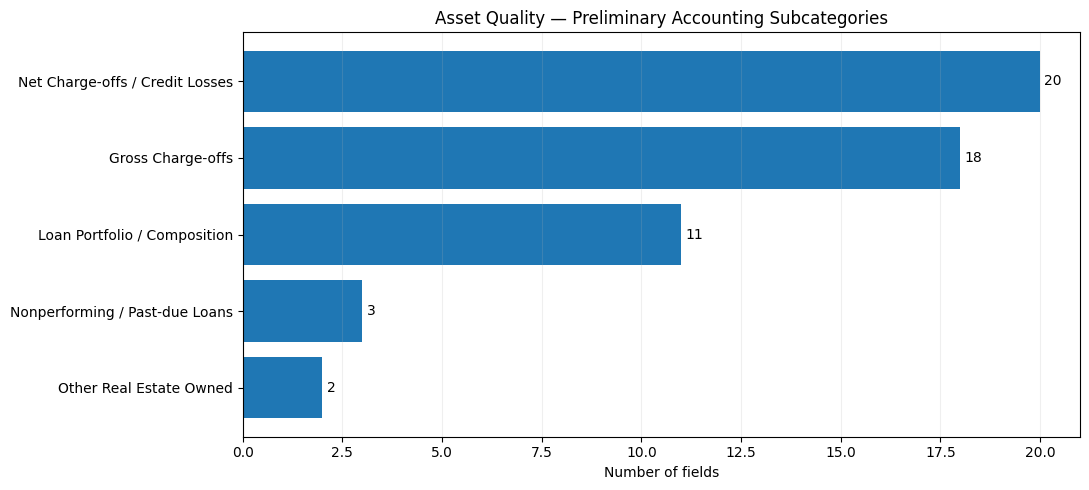


PASS — 54 fields accounted for.
Baseline unchanged: 85 fields.


In [297]:

# ============================================================
# PHASE 4 — 4.6D
# ASSET QUALITY SUBCATEGORY AUDIT
# Existing 85-field CAMELS mapping | No data rescan
# ============================================================

assert "P4_46C_MAPPING" in globals()

P4_46D_ASSET = (
    P4_46C_MAPPING
    .filter(pl.col("camels_code") == "A")
)

def classify_asset_subcategory(f):
    if f.startswith("DR"):
        return "Gross Charge-offs"
    if f.startswith("NT"):
        return "Net Charge-offs / Credit Losses"
    if f.startswith(("NAL", "NCL", "P9")):
        return "Nonperforming / Past-due Loans"
    if f.startswith("LN"):
        return "Loan Portfolio / Composition"
    if f.startswith("ORE"):
        return "Other Real Estate Owned"
    return "DEFINITION_REVIEW"

P4_46D_DETAIL = (
    P4_46D_ASSET
    .with_columns(
        pl.col("field").map_elements(
            classify_asset_subcategory,
            return_dtype=pl.String
        ).alias("asset_subcategory")
    )
    .sort("asset_subcategory", "field")
)

P4_46D_SUMMARY = (
    P4_46D_DETAIL
    .group_by("asset_subcategory")
    .agg(
        pl.len().alias("n_fields"),
        pl.col("field").sort().alias("fields")
    )
    .sort("n_fields", descending=True)
)

print("========== ASSET QUALITY SUBCATEGORIES ==========")
display(P4_46D_SUMMARY)

print("\n========== FULL FIELD ASSIGNMENTS ==========")
display(
    P4_46D_DETAIL.select(
        "field", "asset_subcategory", "verification"
    )
)

# Chart
fig, ax = plt.subplots(figsize=(11, 5))

names = P4_46D_SUMMARY["asset_subcategory"].to_list()
counts = P4_46D_SUMMARY["n_fields"].to_list()

bars = ax.barh(names[::-1], counts[::-1])
ax.bar_label(bars, padding=3)

ax.set_xlabel("Number of fields")
ax.set_title(
    "Asset Quality — Preliminary Accounting Subcategories"
)
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

assert P4_46D_DETAIL.height == 54
assert P4_46D_DETAIL["field"].n_unique() == 54

print("\nPASS — 54 fields accounted for.")
print("Baseline unchanged: 85 fields.")


In [298]:

# ============================================================
# PHASE 4 — 4.6E: EXISTING FEATURE COVERAGE
# 85 raw financial fields + 9 Phase 3 W1 features
# No new feature calculations
# ============================================================

assert "P4_CHECKPOINT_85_FROZEN" in globals()

P4_46E_W1_FEATURES = [
    "asset_growth_4q",
    "cash_to_assets",
    "core_deposit_share",
    "deposits_to_assets",
    "equity_to_assets",
    "noncurrent_loan_ratio",
    "roa_rolling_mean_4q",
    "roa_rolling_std_4q",
    "securities_to_assets"
]

P4_46E_COVERAGE = pl.DataFrame([
    {"feature": f, "source": "RAW_85"}
    for f in P4_CHECKPOINT_85_FROZEN
] + [
    {"feature": f, "source": "W1_PHASE3"}
    for f in P4_46E_W1_FEATURES
])

assert P4_46E_COVERAGE.height == 94
assert P4_46E_COVERAGE["feature"].n_unique() == 94

P4_46E_SUMMARY = (
    P4_46E_COVERAGE
    .group_by("source")
    .agg(
        pl.len().alias("n_features"),
        pl.col("feature").sort().alias("features")
    )
)

print("========== EXISTING FEATURE INVENTORY ==========")
display(P4_46E_SUMMARY)

print("\nRaw fields:", 85)
print("Existing W1 features:", 9)
print("Combined candidate features:", 94)
print("\nPASS — No feature recomputation.")


========== EXISTING FEATURE INVENTORY ==========


source,n_features,features
str,u32,list[str]
"""RAW_85""",85,"[""ADDNONII"", ""ADDNONIIQ"", … ""SC""]"
"""W1_PHASE3""",9,"[""asset_growth_4q"", ""cash_to_assets"", … ""securities_to_assets""]"



Raw fields: 85
Existing W1 features: 9
Combined candidate features: 94

PASS — No feature recomputation.


#### Phạm vi feature engineering

Trước khi tạo thêm predictor, đối chiếu **94 biến hiện có** với các nhóm rủi ro: tín dụng, funding, lợi nhuận, vốn và cơ cấu tài sản. Chỉ bổ sung biến có cơ chế tài chính rõ ràng và chưa được biểu diễn trực tiếp.

<a id="p4-47"></a>

## 4.7 | Missing-data strategy  `[SECTION]`

Kiểm tra Native Missing và Median Imputation bằng cùng population; tuyệt đối không fit tham số trên external test.

#### 4.7A | Missingness Mechanism

Kiểm tra thiếu dữ liệu của **94 predictors** (85 trường tài chính và 9 W1 features) theo phân hoạch, năm báo cáo, ngân hàng và nhãn tương lai. Đây là chẩn đoán cơ chế missingness, **không sử dụng nhãn để điền thiếu**.

**`[RUN]` PHASE 4 — 4.7A: MISSINGNESS MECHANISM AUDIT — 2 ô liên tiếp.** Chạy lần lượt từ trên xuống; các bảng/đồ thị của cell gốc được giữ tại ô cuối của nhóm.

In [299]:

# ============================================================
# PHASE 4 — 4.7A: MISSINGNESS MECHANISM AUDIT
# 85 raw fields + 9 existing W1 features
# TRAIN 1985–2006 | CRISIS 2008–2012 | OOT 2014–2025
# Polars LazyFrame | No imputation | No imports
# ============================================================

required = [
    "SILVER", "GOLD_ELIGIBLE_LF",
    "P4_CHECKPOINT_85_FROZEN",
    "P4_46E_W1_FEATURES", "plt"
]

missing_objects = [x for x in required if x not in globals()]
assert not missing_objects, f"Missing notebook objects: {missing_objects}"

P4_47_RAW = list(P4_CHECKPOINT_85_FROZEN)
P4_47_W1 = list(P4_46E_W1_FEATURES)
P4_47_FIELDS = P4_47_RAW + P4_47_W1

assert len(P4_47_FIELDS) == 94
assert len(set(P4_47_FIELDS)) == 94

# ------------------------------------------------------------
# 1. Assemble existing features, not recompute them
# ------------------------------------------------------------

P4_47_GOLD_SCHEMA = GOLD_ELIGIBLE_LF.collect_schema().names()

assert set(
    ["CERT", "REPDTE", "y_failure_4q_v3"] + P4_47_W1
).issubset(P4_47_GOLD_SCHEMA)

P4_47_BASE_LF = (
    GOLD_ELIGIBLE_LF
    .select(
        "CERT", "REPDTE",
        "y_failure_4q_v3", *P4_47_W1
    )
    .with_columns(pl.col("REPDTE").cast(pl.Date))
    .join(
        SILVER.select("CERT", "REPDTE", *P4_47_RAW)
        .with_columns(pl.col("REPDTE").cast(pl.Date)),
        on=["CERT", "REPDTE"],
        how="left"
    )
    .filter(pl.col("REPDTE").dt.year() <= 2025)
    .with_columns(
        pl.col("REPDTE").dt.year().alias("__year")
    )
    .with_columns(
        pl.when(pl.col("__year").is_between(1985, 2006))
        .then(pl.lit("TRAIN"))
        .when(pl.col("__year").is_between(2008, 2012))
        .then(pl.lit("CRISIS_TEST"))
        .when(pl.col("__year").is_between(2014, 2025))
        .then(pl.lit("RECENT_OOT"))
        .otherwise(pl.lit("PURGE"))
        .alias("__split")
    )
    .filter(pl.col("__split") != "PURGE")
)

# Treat null / NaN / Inf as missing for profiling.
P4_47_MISS = {
    f: (~pl.col(f).is_finite()).fill_null(True)
    for f in P4_47_FIELDS
}

# ------------------------------------------------------------
# 2. Missingness by field, split and TRAIN failure status
# ------------------------------------------------------------

P4_47_PROFILE = (
    P4_47_BASE_LF
    .group_by("__split")
    .agg(
        pl.len().alias("rows"),
        (pl.col("y_failure_4q_v3") == 1)
        .fill_null(False).sum().alias("positive_rows"),

        *[
            expr.sum().alias(f)
            for f, expr in P4_47_MISS.items()
        ]
    )
    .collect()
)

P4_47_TRAIN_LF = P4_47_BASE_LF.filter(
    pl.col("__split") == "TRAIN"
)

P4_47_Y_PROFILE = (
    P4_47_TRAIN_LF
    .group_by("y_failure_4q_v3")
    .agg(
        pl.len().alias("rows"),
        *[
            expr.sum().alias(f)
            for f, expr in P4_47_MISS.items()
        ]
    )
    .collect()
)

split_stats = {
    r["__split"]: r
    for r in P4_47_PROFILE.to_dicts()
}

y_stats = {
    int(r["y_failure_4q_v3"]): r
    for r in P4_47_Y_PROFILE.to_dicts()
    if r["y_failure_4q_v3"] is not None
}

assert "TRAIN" in split_stats
assert 0 in y_stats and 1 in y_stats

P4_47_MISSING_SUMMARY = pl.DataFrame([
    {
        "field": f,
        "source": "RAW_85" if f in P4_47_RAW else "W1",
        "train_missing_pct": round(
            100 * split_stats["TRAIN"][f]
            / split_stats["TRAIN"]["rows"], 3
        ),
        "crisis_missing_pct": round(
            100 * split_stats["CRISIS_TEST"][f]
            / split_stats["CRISIS_TEST"]["rows"], 3
        ),
        "oot_missing_pct": round(
            100 * split_stats["RECENT_OOT"][f]
            / split_stats["RECENT_OOT"]["rows"], 3
        ),
        "y0_missing_pct": round(
            100 * y_stats[0][f] / y_stats[0]["rows"], 3
        ),
        "y1_missing_pct": round(
            100 * y_stats[1][f] / y_stats[1]["rows"], 3
        )
    }
    for f in P4_47_FIELDS
]).with_columns(
    (
        pl.col("y1_missing_pct")
        - pl.col("y0_missing_pct")
    ).round(3).alias("y1_minus_y0_pp")
).sort("train_missing_pct", descending=True)


========== SPLIT SIZES ==========


__split,rows,positive_rows
str,u32,u32
"""TRAIN""",1121901,8239
"""RECENT_OOT""",254058,179
"""CRISIS_TEST""",157851,1880



========== TOP 20 MISSING FIELDS ==========


field,source,train_missing_pct,crisis_missing_pct,oot_missing_pct,y0_missing_pct,y1_missing_pct,y1_minus_y0_pp
str,str,f64,f64,f64,f64,f64,f64
"""DRAGSMQ""","""RAW_85""",21.291,9.327,1.795,21.094,47.846,26.752
"""NTAGSMQ""","""RAW_85""",21.291,9.327,1.795,21.094,47.846,26.752
"""NTAGSMA""","""RAW_85""",21.291,9.327,1.795,21.094,47.846,26.752
"""DRAGSM""","""RAW_85""",21.279,9.324,1.795,21.082,47.846,26.764
"""NTAGSM""","""RAW_85""",21.279,9.324,1.795,21.083,47.846,26.763
…,…,…,…,…,…,…,…
"""DRCRCDQ""","""RAW_85""",6.341,0.215,0.314,6.183,27.661,21.478
"""DRCONOTQ""","""RAW_85""",6.341,0.215,0.314,6.183,27.661,21.478
"""NTCI""","""RAW_85""",5.853,0.215,0.314,5.692,27.613,21.921



========== BIGGEST MISSINGNESS–FAILURE GAPS ==========


field,source,train_missing_pct,crisis_missing_pct,oot_missing_pct,y0_missing_pct,y1_missing_pct,y1_minus_y0_pp
str,str,f64,f64,f64,f64,f64,f64
"""NTLS""","""RAW_85""",14.706,7.918,0.314,14.508,41.461,26.953
"""DRLS""","""RAW_85""",14.706,7.918,0.314,14.508,41.461,26.953
"""NTLSQ""","""RAW_85""",14.72,7.921,0.314,14.522,41.461,26.939
"""DRLSQ""","""RAW_85""",14.72,7.921,0.314,14.522,41.461,26.939
"""DRAGSM""","""RAW_85""",21.279,9.324,1.795,21.082,47.846,26.764
…,…,…,…,…,…,…,…
"""LNCDT1R""","""RAW_85""",5.752,0.217,0.314,5.589,27.758,22.169
"""LNRERT1R""","""RAW_85""",5.752,0.217,0.314,5.589,27.758,22.169
"""LNCONT1R""","""RAW_85""",5.752,0.217,0.314,5.589,27.758,22.169


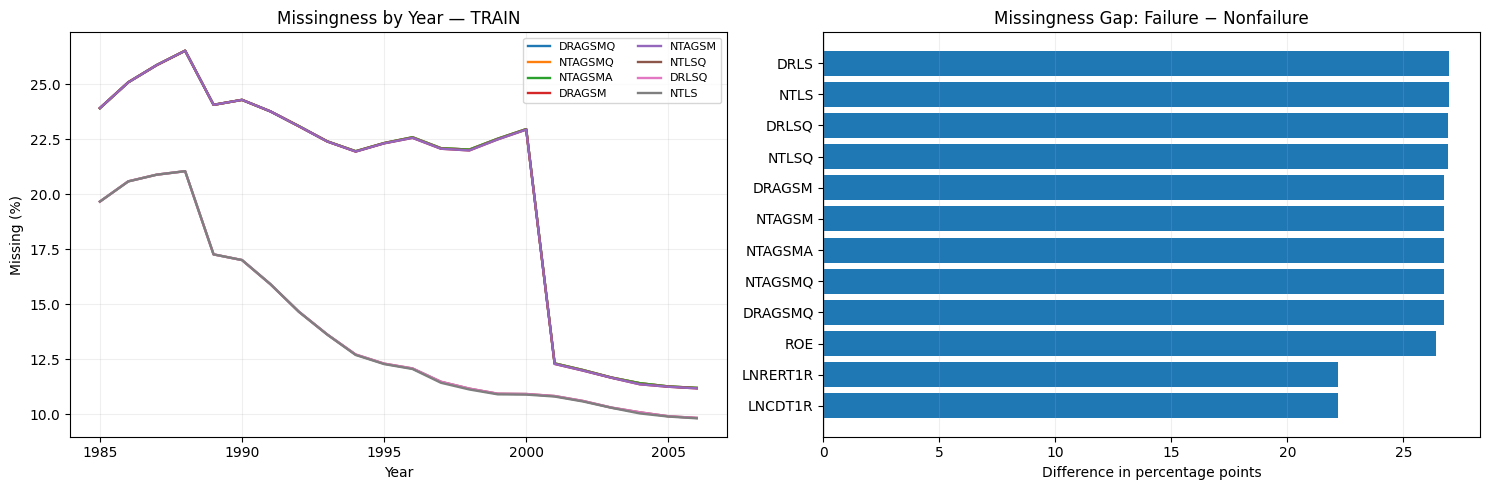


========== BANK-LEVEL MISSINGNESS ==========


banks,median_missing_fields_per_bank_quarter,p90_missing_fields,p99_missing_fields,median_share_quarters_with_missing
u32,f64,f64,f64,f64
23123,0.019608,19.526316,40.0,0.011364



PASS — Missingness mechanism diagnostics completed.
Predictors inspected: 94
Imputation performed: NO
Frozen raw fields: 85


In [300]:

print("========== SPLIT SIZES ==========")
display(P4_47_PROFILE.select(
    "__split", "rows", "positive_rows"
))

print("\n========== TOP 20 MISSING FIELDS ==========")
display(P4_47_MISSING_SUMMARY.head(20))

print("\n========== BIGGEST MISSINGNESS–FAILURE GAPS ==========")
display(
    P4_47_MISSING_SUMMARY
    .with_columns(
        pl.col("y1_minus_y0_pp").abs().alias("__abs_gap")
    )
    .sort("__abs_gap", descending=True)
    .drop("__abs_gap")
    .head(15)
)

# ------------------------------------------------------------
# 3. Temporal patterns: top eight TRAIN-missing fields
# ------------------------------------------------------------

P4_47_TOP_FIELDS = (
    P4_47_MISSING_SUMMARY
    .head(8)
    .get_column("field").to_list()
)

P4_47_YEARLY = (
    P4_47_TRAIN_LF
    .group_by("__year")
    .agg(
        pl.len().alias("rows"),
        *[
            P4_47_MISS[f].mean().alias(f)
            for f in P4_47_TOP_FIELDS
        ]
    )
    .sort("__year")
    .collect()
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

years = P4_47_YEARLY["__year"].to_list()

for f in P4_47_TOP_FIELDS:
    axes[0].plot(
        years,
        (P4_47_YEARLY[f] * 100).to_list(),
        label=f,
        linewidth=1.7
    )

axes[0].set_title("Missingness by Year — TRAIN")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Missing (%)")
axes[0].legend(fontsize=8, ncol=2)
axes[0].grid(alpha=0.2)

# Failure-associated missingness gaps
gap_chart = (
    P4_47_MISSING_SUMMARY
    .with_columns(
        pl.col("y1_minus_y0_pp").abs().alias("__abs_gap")
    )
    .sort("__abs_gap", descending=True)
    .head(12)
    .sort("y1_minus_y0_pp")
)

axes[1].barh(
    gap_chart["field"].to_list(),
    gap_chart["y1_minus_y0_pp"].to_list()
)

axes[1].axvline(0, color="gray", linewidth=1)
axes[1].set_title("Missingness Gap: Failure − Nonfailure")
axes[1].set_xlabel("Difference in percentage points")
axes[1].grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. Concentration of missingness across banks
# ------------------------------------------------------------

P4_47_BANK_MISSING = (
    P4_47_TRAIN_LF
    .select(
        "CERT",
        pl.sum_horizontal(
            [expr.cast(pl.Int8) for expr in P4_47_MISS.values()]
        ).alias("__missing_count")
    )
    .group_by("CERT")
    .agg(
        pl.len().alias("quarters"),
        pl.col("__missing_count").mean()
        .alias("avg_missing_fields"),
        (pl.col("__missing_count") > 0)
        .mean().alias("share_quarters_with_missing")
    )
    .collect()
)

print("\n========== BANK-LEVEL MISSINGNESS ==========")
display(
    P4_47_BANK_MISSING.select(
        pl.len().alias("banks"),
        pl.col("avg_missing_fields").median()
        .alias("median_missing_fields_per_bank_quarter"),
        pl.col("avg_missing_fields").quantile(0.90)
        .alias("p90_missing_fields"),
        pl.col("avg_missing_fields").quantile(0.99)
        .alias("p99_missing_fields"),
        pl.col("share_quarters_with_missing").median()
        .alias("median_share_quarters_with_missing")
    )
)

print("\nPASS — Missingness mechanism diagnostics completed.")
print("Predictors inspected:", len(P4_47_FIELDS))
print("Imputation performed: NO")
print("Frozen raw fields:", len(P4_CHECKPOINT_85_FROZEN))


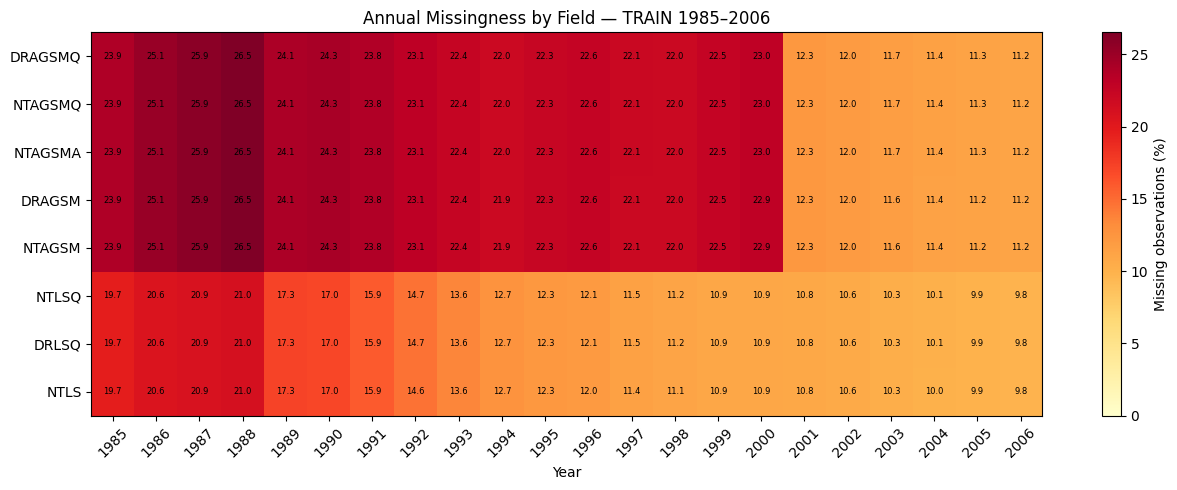

In [301]:

# ============================================================
# PHASE 4 — 4.7A.1
# MISSINGNESS HEATMAP — TOP 8 FIELDS
# Uses P4_47_YEARLY; no new data scan
# ============================================================

fields = P4_47_TOP_FIELDS
years = P4_47_YEARLY["__year"].to_list()

matrix = [
    (P4_47_YEARLY[f] * 100).to_list()
    for f in fields
]

fig, ax = plt.subplots(figsize=(13, 5))

im = ax.imshow(
    matrix,
    aspect="auto",
    cmap="YlOrRd",
    vmin=0
)

ax.set_yticks(range(len(fields)))
ax.set_yticklabels(fields)

ax.set_xticks(range(len(years)))
ax.set_xticklabels(years, rotation=45)

for i in range(len(fields)):
    for j in range(len(years)):
        ax.text(
            j, i, f"{matrix[i][j]:.1f}",
            ha="center", va="center",
            fontsize=6
        )

ax.set_title(
    "Annual Missingness by Field — TRAIN 1985–2006"
)
ax.set_xlabel("Year")

fig.colorbar(
    im, ax=ax, label="Missing observations (%)"
)

plt.tight_layout()
plt.show()


#### Kết quả | Missingness mechanism

Nhiều trường có đường missingness theo năm tương đồng, có thể do cùng nguồn hoặc giai đoạn báo cáo; tỷ lệ thiếu nhìn chung giảm về sau. Phân tích có nhãn chỉ để **mô tả tính khác biệt giữa nhóm quan sát**, không chứng minh missingness gây thất bại ngân hàng.

In [302]:

# ============================================================
# PHASE 4 — 4.7B: IDENTICAL MISSINGNESS MASKS
# 94 predictors | TRAIN only | Polars LazyFrame
# ============================================================

assert "P4_47_TRAIN_LF" in globals()
assert "P4_47_FIELDS" in globals()

fields = list(P4_47_FIELDS)

# 1. Fingerprint missing positions using bank-quarter keys
base = P4_47_TRAIN_LF.with_columns(
    pl.struct(["CERT", "REPDTE"])
      .hash(seed=47).alias("__h1"),
    pl.struct(["CERT", "REPDTE"])
      .hash(seed=470).alias("__h2")
)

exprs = []
for i, f in enumerate(fields):
    m = (~pl.col(f).is_finite()).fill_null(True)
    exprs.extend([
        m.sum().alias(f"f{i}_n"),
        pl.when(m).then(pl.col("__h1"))
          .otherwise(pl.lit(0, dtype=pl.UInt64))
          .sum().alias(f"f{i}_h1"),
        pl.when(m).then(pl.col("__h2"))
          .otherwise(pl.lit(0, dtype=pl.UInt64))
          .sum().alias(f"f{i}_h2")
    ])

fingerprints = base.select(exprs).collect().row(
    0, named=True
)

# 2. Group matching fingerprints
candidate_groups = {}
for i, f in enumerate(fields):
    signature = (
        fingerprints[f"f{i}_n"],
        fingerprints[f"f{i}_h1"],
        fingerprints[f"f{i}_h2"]
    )
    candidate_groups.setdefault(signature, []).append(f)

# 3. Verify exact matching masks within each group
P4_47B_MASK_GROUPS = []
P4_47B_VERIFY_PAIRS = []

for (nmiss, _, _), members in candidate_groups.items():
    if nmiss == 0 or len(members) < 2:
        continue

    anchor = members[0]
    for f in members[1:]:
        P4_47B_VERIFY_PAIRS.append((anchor, f))

if P4_47B_VERIFY_PAIRS:
    checks = P4_47_TRAIN_LF.select([
        (
            (~pl.col(a).is_finite()).fill_null(True)
            != (~pl.col(b).is_finite()).fill_null(True)
        ).sum().alias(f"p{i}")
        for i, (a, b) in enumerate(P4_47B_VERIFY_PAIRS)
    ]).collect().row(0, named=True)

    confirmed = {
        pair: checks[f"p{i}"] == 0
        for i, pair in enumerate(P4_47B_VERIFY_PAIRS)
    }
else:
    confirmed = {}

for (nmiss, _, _), members in candidate_groups.items():
    if nmiss == 0 or len(members) < 2:
        continue

    anchor = members[0]
    group = [anchor] + [
        f for f in members[1:]
        if confirmed.get((anchor, f), False)
    ]

    if len(group) >= 2:
        P4_47B_MASK_GROUPS.append({
            "group_id": f"MASK_{len(P4_47B_MASK_GROUPS)+1:02d}",
            "n_fields": len(group),
            "missing_rows": nmiss,
            "fields": group
        })

P4_47B_MASK_SUMMARY = pl.DataFrame(
    P4_47B_MASK_GROUPS,
    schema={
        "group_id": pl.String,
        "n_fields": pl.Int64,
        "missing_rows": pl.Int64,
        "fields": pl.List(pl.String)
    }
).sort("n_fields", descending=True)

print("========== IDENTICAL MISSINGNESS MASKS ==========")
display(P4_47B_MASK_SUMMARY)

print("\n========== SUMMARY ==========")
print("Predictors checked:", len(fields))
print("Identical-mask groups:", P4_47B_MASK_SUMMARY.height)
print(
    "Fields in confirmed groups:",
    P4_47B_MASK_SUMMARY["n_fields"].sum() or 0
)
print(
    "Potential duplicate indicators avoided:",
    sum(r["n_fields"] - 1 for r in P4_47B_MASK_GROUPS)
)

print("\nPASS — Exact masks verified; no imputation.")


========== IDENTICAL MISSINGNESS MASKS ==========


group_id,n_fields,missing_rows,fields
str,i64,i64,list[str]
"""MASK_15""",9,1,"[""SC"", ""CHBAL"", … ""securities_to_assets""]"
"""MASK_12""",7,2709,"[""LNRECONS"", ""EQ"", … ""equity_to_assets""]"
"""MASK_14""",5,2708,"[""NONIXQ"", ""NONIXA"", … ""EOTHNINQ""]"
"""MASK_10""",4,64451,"[""DRLNLS"", ""NTRE"", … ""NTLNLS""]"
"""MASK_13""",4,2710,"[""OREOTH"", ""ORE"", … ""BRO""]"
…,…,…,…
"""MASK_04""",2,164988,"[""NTLS"", ""DRLS""]"
"""MASK_05""",2,165145,"[""NTLSQ"", ""DRLSQ""]"
"""MASK_07""",2,65662,"[""DRCONQ"", ""DRCIQ""]"



========== SUMMARY ==========
Predictors checked: 94
Identical-mask groups: 16
Fields in confirmed groups: 55
Potential duplicate indicators avoided: 39

PASS — Exact masks verified; no imputation.


### 4.7C | Hai chiến lược xử lý missingness

| Pipeline | Xử lý | Vai trò |
|---|---|---|
| **A — Native Missing** | Giữ `NaN` để LightGBM xử lý bằng nhánh missing | **Chính** |
| **B — Median Imputation** | Điền bằng median được fit trong TRAIN | Đối chứng |

Hai pipeline dùng cùng định nghĩa biến, nhãn và temporal splits. Khi chạy chronological CV, mọi median/scaler phải được **fit lại trong chính training fold**, không dùng validation/test để ước lượng. Silver và W1 nguồn không bị thay đổi.

**Điểm cần kiểm định:** imputation có thực sự cải thiện hiệu quả dự báo hay chỉ làm thay đổi phân phối?

In [303]:

# ============================================================
# PHASE 4 — 4.7D: DUAL MISSING-DATA PIPELINES
# Native Missing vs TRAIN-Fitted Median Imputation
# No imports | No model training | No source modification
# ============================================================

required = [
    "P4_47_BASE_LF",
    "P4_CHECKPOINT_85_FROZEN",
    "P4_46E_W1_FEATURES"
]
assert all(k in globals() for k in required)

P4_47D_FIELDS = (
    list(P4_CHECKPOINT_85_FROZEN)
    + list(P4_46E_W1_FEATURES)
)
assert len(P4_47D_FIELDS) == len(set(P4_47D_FIELDS)) == 94

# ------------------------------------------------------------
# 1. Normalize numerical missing values
#    Null, NaN, Inf -> Null (not zero)
# ------------------------------------------------------------

P4_47D_BASE = (
    P4_47_BASE_LF
    .with_columns([
        pl.when(pl.col(f).cast(pl.Float64, strict=False).is_finite())
        .then(pl.col(f).cast(pl.Float64, strict=False))
        .otherwise(None)
        .alias(f)
        for f in P4_47D_FIELDS
    ])
)

# ------------------------------------------------------------
# 2. Reusable TRAIN-only imputer
# ------------------------------------------------------------

def p4_fit_imputer(train_lf, fields):
    stats = (
        train_lf
        .select([
            pl.col(f).median().alias(f)
            for f in fields
        ])
        .collect()
        .row(0, named=True)
    )

    # If a field is entirely missing in a training fold,
    # use a neutral numerical placeholder and log the case.
    # Never borrow statistics from validation/test.
    all_missing = [
        f for f in fields
        if stats[f] is None
    ]

    medians = {
        f: float(stats[f]) if stats[f] is not None else 0.0
        for f in fields
    }

    return {
        "medians": medians,
        "all_missing_fields": all_missing
    }


def p4_apply_imputer(lf, state, fields):
    return lf.with_columns([
        pl.col(f)
        .fill_null(state["medians"][f])
        .alias(f)
        for f in fields
    ])


def p4_build_pipelines(fit_lf, apply_lf, fields):
    state = p4_fit_imputer(fit_lf, fields)

    # A: unchanged normalized missing values
    native = apply_lf

    # B: parameters learned ONLY from fit_lf
    imputed = p4_apply_imputer(apply_lf, state, fields)

    return native, imputed, state

# ------------------------------------------------------------
# 3. Fit on complete TRAIN for final holdout evaluation
#    This state must NOT be reused inside expanding CV.
# ------------------------------------------------------------

P4_47D_TRAIN = P4_47D_BASE.filter(
    pl.col("__split") == "TRAIN"
)

P4_47D_IMPUTER_FULL = p4_fit_imputer(
    P4_47D_TRAIN,
    P4_47D_FIELDS
)

P4_47D_PIPELINES = {}

for split in ("TRAIN", "CRISIS_TEST", "RECENT_OOT"):
    source = P4_47D_BASE.filter(
        pl.col("__split") == split
    )

    P4_47D_PIPELINES[split] = {
        "native": source,
        "imputed": p4_apply_imputer(
            source,
            P4_47D_IMPUTER_FULL,
            P4_47D_FIELDS
        )
    }

# ------------------------------------------------------------
# 4. Report fitted parameters, without materializing data
# ------------------------------------------------------------

P4_47D_IMPUTER_AUDIT = pl.DataFrame([
    {
        "field": f,
        "train_median": P4_47D_IMPUTER_FULL["medians"][f],
        "all_missing_in_train": (
            f in P4_47D_IMPUTER_FULL["all_missing_fields"]
        )
    }
    for f in P4_47D_FIELDS
])

print("========== PREPROCESSING PIPELINES ==========")
print("Predictors:", len(P4_47D_FIELDS))
print("Splits:", list(P4_47D_PIPELINES))
print("Strategies:", ["native", "imputed"])
print(
    "All-missing TRAIN fields:",
    P4_47D_IMPUTER_FULL["all_missing_fields"]
)

print("\n========== FITTED IMPUTATION PARAMETERS ==========")
display(P4_47D_IMPUTER_AUDIT.head(15))

print("\nPASS — Two pipelines constructed.")
print("Imputer fitted on TRAIN only.")
print("CRISIS_TEST / RECENT_OOT not used for fitting.")
print("Original data unchanged.")


========== PREPROCESSING PIPELINES ==========
Predictors: 94
Splits: ['TRAIN', 'CRISIS_TEST', 'RECENT_OOT']
Strategies: ['native', 'imputed']
All-missing TRAIN fields: []

========== FITTED IMPUTATION PARAMETERS ==========


field,train_median,all_missing_in_train
str,f64,bool
"""DRAGSM""",0.0,false
"""NTAGSM""",0.0,false
"""DRAGSMQ""",0.0,false
"""NTAGSMQ""",0.0,false
"""NTAGSMA""",0.0,false
…,…,…
"""DRCONOTQ""",3.0,false
"""NTLS""",0.0,false
"""DRLS""",0.0,false



PASS — Two pipelines constructed.
Imputer fitted on TRAIN only.
CRISIS_TEST / RECENT_OOT not used for fitting.
Original data unchanged.


In [304]:

# ============================================================
# PHASE 4 — 4.7D.1: LEAKAGE-SAFE CV EXAMPLE
# CV fold: TRAIN 1985–1990
# Purge 1991 | Validation 1992–1994
# ============================================================

P4_47D_CV_TRAIN = P4_47D_TRAIN.filter(
    pl.col("__year").is_between(1985, 1990)
)

P4_47D_CV_VALID = P4_47D_TRAIN.filter(
    pl.col("__year").is_between(1992, 1994)
)

cv_native, cv_imputed, P4_47D_CV_STATE = (
    p4_build_pipelines(
        P4_47D_CV_TRAIN,
        P4_47D_CV_VALID,
        P4_47D_FIELDS
    )
)

P4_47D_CV_AUDIT = (
    pl.DataFrame([
        {
            "field": f,
            "cv_train_median": P4_47D_CV_STATE["medians"][f],
            "full_train_median": P4_47D_IMPUTER_FULL["medians"][f]
        }
        for f in P4_47D_FIELDS
    ])
    .with_columns(
        (
            pl.col("cv_train_median")
            - pl.col("full_train_median")
        ).abs().alias("abs_difference")
    )
    .sort("abs_difference", descending=True)
)

print("========== EXPANDING CV — IMPUTER ISOLATION ==========")
print("Fit: 1985–1990")
print("Purge: 1991")
print("Validate: 1992–1994")
print(
    "All-missing CV fields:",
    P4_47D_CV_STATE["all_missing_fields"]
)

display(P4_47D_CV_AUDIT.head(15))

print("\nPASS — CV imputer fitted independently.")


========== EXPANDING CV — IMPUTER ISOLATION ==========
Fit: 1985–1990
Purge: 1991
Validate: 1992–1994
All-missing CV fields: []


field,cv_train_median,full_train_median,abs_difference
str,f64,f64,f64
"""ASSET""",46663.0,63992.0,17329.0
"""DEP""",41441.0,55083.0,13642.0
"""COREDEP""",36336.0,47855.0,11519.0
"""LNLSGR""",24861.0,36369.0,11508.0
"""LNRE""",11933.0,20535.0,8602.0
…,…,…,…
"""LNCI""",2796.0,3844.0,1048.0
"""NONIXA""",1353.0,1886.0,533.0
"""CHBAL""",2564.0,3070.0,506.0



PASS — CV imputer fitted independently.


#### 4.7D | Triển khai pipeline kép

Hai đường xử lý được xây dựng cho các bộ TRAIN, CRISIS_TEST và RECENT_OOT với cùng 94 predictors. Native Missing giữ mẫu thiếu gốc; median imputation sử dụng thống kê chỉ từ TRAIN (hoặc training fold). **Kết luận ở đây là tính đúng đắn của preprocessing, chưa phải so sánh predictive performance.**

========== PIPELINE VALIDATION ==========


split,strategy,rows,banks,missing_cells,invalid_cells,fields_with_missing,missing_cell_pct
str,str,i64,i64,i64,i64,u32,f64
"""CRISIS_TEST""","""imputed""",157851,8705,0,0,0,0.0
"""CRISIS_TEST""","""native""",157851,8705,151326,0,61,1.02
"""RECENT_OOT""","""imputed""",254058,6901,0,0,0,0.0
"""RECENT_OOT""","""native""",254058,6901,81286,0,60,0.34
"""TRAIN""","""imputed""",1121901,23123,0,0,0,0.0
"""TRAIN""","""native""",1121901,23123,3998653,0,74,3.792



========== TOP 15 IMPUTATION EXPOSURES ==========


field,null_count,imputed_fraction_pct
str,i64,f64
"""DRAGSMQ""",238860,21.291
"""NTAGSMQ""",238861,21.291
"""NTAGSMA""",238861,21.291
"""DRAGSM""",238729,21.279
"""NTAGSM""",238730,21.279
…,…,…
"""NTLNLSQR""",74781,6.666
"""NTCRCD""",71135,6.341
"""DRCRCD""",71135,6.341


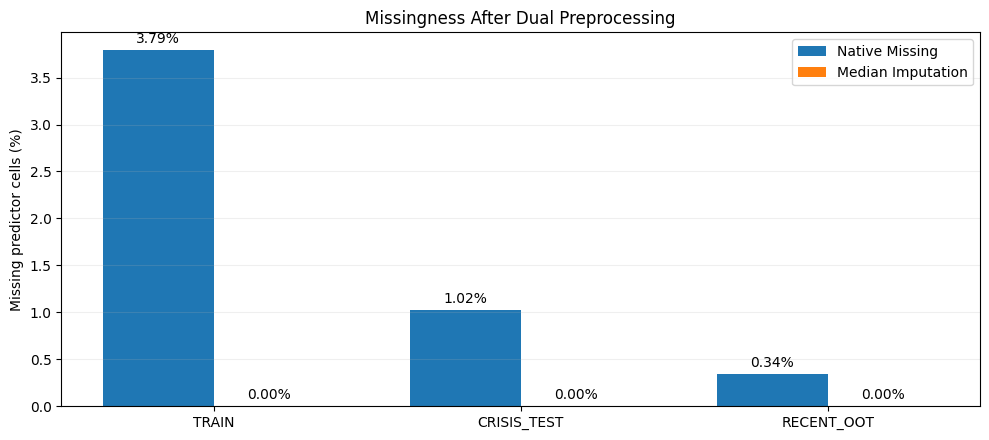


PASS — Row counts preserved and imputation complete.
Native missing values retained for comparison.
Original Silver, Gold and W1 unchanged.


In [305]:

# ============================================================
# PHASE 4 — 4.7E: POST-PREPROCESSING VALIDATION
# 94 predictors | Native vs Median Imputation
# No imports | No model fitting | No source modification
# ============================================================

assert all(k in globals() for k in [
    "P4_47D_PIPELINES",
    "P4_47D_FIELDS",
    "P4_47D_IMPUTER_FULL"
])

fields = P4_47D_FIELDS
audit_rows = []

# 1. Validate both branches and all temporal splits
for split, pipelines in P4_47D_PIPELINES.items():

    for strategy in ("native", "imputed"):

        lf = pipelines[strategy]

        stats = (
            lf.select(
                pl.len().alias("rows"),
                pl.col("CERT").n_unique().alias("banks"),

                *[
                    pl.col(f).is_null().sum()
                    .alias(f"null__{f}")
                    for f in fields
                ],

                *[
                    (
                        pl.col(f).is_not_null()
                        & ~pl.col(f).is_finite()
                    ).fill_null(False).sum()
                    .alias(f"invalid__{f}")
                    for f in fields
                ]
            )
            .collect()
            .row(0, named=True)
        )

        for f in fields:
            audit_rows.append({
                "split": split,
                "strategy": strategy,
                "field": f,
                "rows": stats["rows"],
                "banks": stats["banks"],
                "null_count": stats[f"null__{f}"],
                "invalid_count": stats[f"invalid__{f}"]
            })

P4_47E_FIELD_AUDIT = pl.DataFrame(audit_rows)

# 2. Split-level comparison
P4_47E_SUMMARY = (
    P4_47E_FIELD_AUDIT
    .group_by("split", "strategy")
    .agg(
        pl.col("rows").first().alias("rows"),
        pl.col("banks").first().alias("banks"),
        pl.col("null_count").sum().alias("missing_cells"),
        pl.col("invalid_count").sum().alias("invalid_cells"),
        (pl.col("null_count") > 0)
        .sum().alias("fields_with_missing")
    )
    .with_columns(
        (
            100 * pl.col("missing_cells")
            / (pl.col("rows") * len(fields))
        ).round(3).alias("missing_cell_pct")
    )
    .sort("split", "strategy")
)

print("========== PIPELINE VALIDATION ==========")
display(P4_47E_SUMMARY)

# 3. Check row/bank preservation and complete imputation
for split in P4_47D_PIPELINES:

    subset = P4_47E_SUMMARY.filter(
        pl.col("split") == split
    )

    native = subset.filter(pl.col("strategy") == "native")
    imputed = subset.filter(pl.col("strategy") == "imputed")

    assert native["rows"][0] == imputed["rows"][0], (
        f"Row count changed in {split}"
    )
    assert native["banks"][0] == imputed["banks"][0], (
        f"Bank count changed in {split}"
    )
    assert imputed["missing_cells"][0] == 0, (
        f"Imputation incomplete in {split}"
    )
    assert imputed["invalid_cells"][0] == 0, (
        f"Invalid values remain in {split}"
    )

# 4. Feature-level missingness in TRAIN
P4_47E_TRAIN = (
    P4_47E_FIELD_AUDIT
    .filter(
        (pl.col("split") == "TRAIN")
        & (pl.col("strategy") == "native")
    )
    .with_columns(
        (
            100 * pl.col("null_count") / pl.col("rows")
        ).round(3).alias("imputed_fraction_pct")
    )
    .sort("imputed_fraction_pct", descending=True)
)

print("\n========== TOP 15 IMPUTATION EXPOSURES ==========")
display(
    P4_47E_TRAIN.select(
        "field", "null_count", "imputed_fraction_pct"
    ).head(15)
)

# 5. Chart: missing-cell rate before vs after imputation
splits = ["TRAIN", "CRISIS_TEST", "RECENT_OOT"]

native_rates = []
imputed_rates = []

for split in splits:
    d = P4_47E_SUMMARY.filter(pl.col("split") == split)

    native_rates.append(
        d.filter(pl.col("strategy") == "native")
        ["missing_cell_pct"][0]
    )
    imputed_rates.append(
        d.filter(pl.col("strategy") == "imputed")
        ["missing_cell_pct"][0]
    )

fig, ax = plt.subplots(figsize=(10, 4.5))

x = list(range(len(splits)))

bars1 = ax.bar(
    [i - 0.18 for i in x],
    native_rates, width=0.36,
    label="Native Missing"
)
bars2 = ax.bar(
    [i + 0.18 for i in x],
    imputed_rates, width=0.36,
    label="Median Imputation"
)

ax.set_xticks(x)
ax.set_xticklabels(splits)
ax.set_ylabel("Missing predictor cells (%)")
ax.set_title("Missingness After Dual Preprocessing")
ax.bar_label(bars1, fmt="%.2f%%", padding=3)
ax.bar_label(bars2, fmt="%.2f%%", padding=3)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

print("\nPASS — Row counts preserved and imputation complete.")
print("Native missing values retained for comparison.")
print("Original Silver, Gold and W1 unchanged.")


#### 4.7E | Kiểm thử sau preprocessing

Đối chiếu số hàng, bộ khóa, missing/non-finite, các thống kê imputation và việc áp dụng cùng schema ở các temporal splits. Pipeline A được phép giữ NaN; Pipeline B không được tạo Inf hay fit thống kê từ external test.

#### 4.7F | Imputation làm đổi phân phối như thế nào?

Chỉ đánh giá **12 biến chịu tác động điền thiếu lớn nhất trong TRAIN**: mức tăng tỷ lệ zero, thay đổi trung bình và phương sai. Đây là sensitivity check, không lặp lại missingness audit.

========== IMPUTATION DISTRIBUTION IMPACT ==========


field,imputed_pct,train_median,zero_before_pct,zero_after_pct,zero_change_pp,std_ratio
str,f64,f64,f64,f64,f64,f64
"""DRAGSMQ""",21.291,0.0,91.156,93.039,1.883,0.888107
"""NTAGSMQ""",21.291,0.0,85.217,88.364,3.148,0.887736
"""NTAGSMA""",21.291,0.0,81.363,85.331,3.968,0.888011
"""DRAGSM""",21.279,0.0,87.414,90.092,2.678,0.888761
"""NTAGSM""",21.279,0.0,81.312,85.288,3.977,0.888142
…,…,…,…,…,…,…
"""NTLS""",14.706,0.0,96.639,97.133,0.494,0.923574
"""DRLS""",14.706,0.0,97.163,97.58,0.417,0.923581
"""NTREQR""",7.292,0.0,63.489,66.151,2.662,0.96303



========== MEAN AND STD COMPARISON ==========


field,mean_before,mean_after,std_before,std_after
str,f64,f64,f64,f64
"""DRAGSMQ""",5.490978,4.321913,55.503349,49.292894
"""NTAGSMQ""",4.218484,3.320338,55.108338,48.92163
"""NTAGSMA""",13.414115,10.558151,143.187844,127.152349
"""DRAGSM""",12.419814,9.777005,98.074459,87.164771
"""NTAGSM""",9.15404,7.206147,94.047175,83.527245
…,…,…,…,…
"""NTLS""",23.17354,19.765614,1159.677901,1071.048306
"""DRLS""",31.450435,26.825299,1398.740252,1291.85016
"""NTREQR""",0.245143,0.227266,3.420229,3.293783


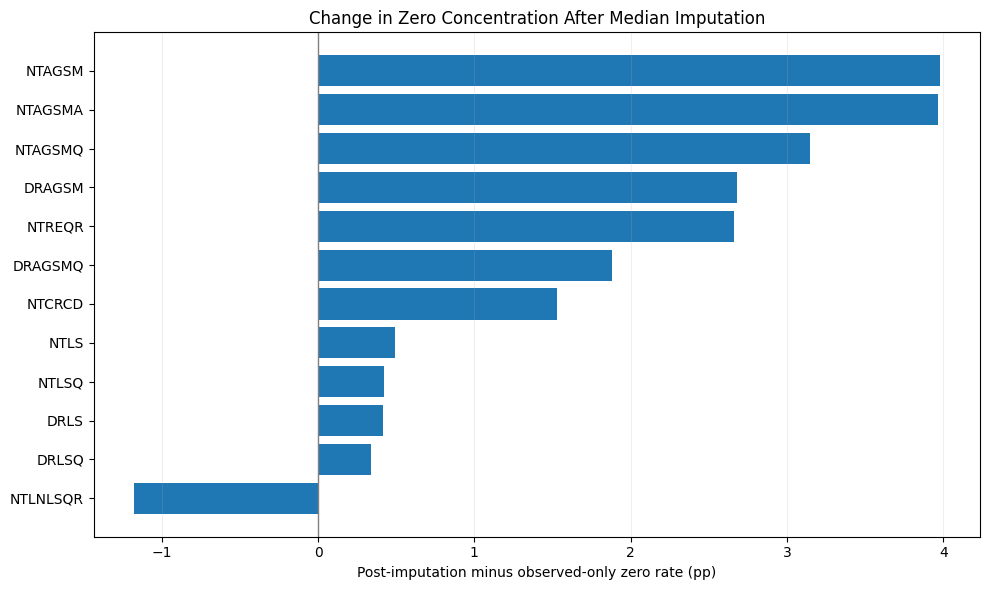


PASS — Distribution-impact audit completed.
Features evaluated: 12
Imputation strategy changed: NO
Native Missing pipeline preserved: YES


In [306]:

# ============================================================
# PHASE 4 — 4.7F: IMPUTATION DISTRIBUTION IMPACT
# TRAIN only | Top 12 highest imputation exposures
# Reuse existing LazyFrame and fitted medians
# No new features | No model fitting | No imports
# ============================================================

required = [
    "P4_47D_TRAIN",
    "P4_47D_FIELDS",
    "P4_47D_IMPUTER_FULL",
    "P4_47E_TRAIN"
]
assert all(x in globals() for x in required)

top_fields = (
    P4_47E_TRAIN
    .head(12)
    .get_column("field")
    .to_list()
)

medians = P4_47D_IMPUTER_FULL["medians"]

# ------------------------------------------------------------
# 1. Compare observed vs median-filled distributions
#    Compute both from the same TRAIN LazyFrame
# ------------------------------------------------------------

exprs = [pl.len().alias("__rows")]

for i, f in enumerate(top_fields):
    observed = pl.col(f)
    filled = observed.fill_null(float(medians[f]))

    exprs.extend([
        observed.count().alias(f"v{i}_observed_n"),
        observed.null_count().alias(f"v{i}_missing_n"),
        (observed == 0).sum().alias(f"v{i}_zero_before"),
        (filled == 0).sum().alias(f"v{i}_zero_after"),
        observed.mean().alias(f"v{i}_mean_before"),
        filled.mean().alias(f"v{i}_mean_after"),
        observed.std().alias(f"v{i}_std_before"),
        filled.std().alias(f"v{i}_std_after"),
    ])

stats = (
    P4_47D_TRAIN
    .select(exprs)
    .collect()
    .row(0, named=True)
)

rows = []

for i, f in enumerate(top_fields):

    n_obs = stats[f"v{i}_observed_n"]
    n_miss = stats[f"v{i}_missing_n"]
    n_total = stats["__rows"]

    zero_before = (
        100 * stats[f"v{i}_zero_before"] / n_obs
        if n_obs else None
    )
    zero_after = (
        100 * stats[f"v{i}_zero_after"] / n_total
        if n_total else None
    )

    mean_before = stats[f"v{i}_mean_before"]
    mean_after = stats[f"v{i}_mean_after"]
    std_before = stats[f"v{i}_std_before"]
    std_after = stats[f"v{i}_std_after"]

    rows.append({
        "field": f,
        "imputed_pct": round(100 * n_miss / n_total, 3),
        "train_median": float(medians[f]),
        "zero_before_pct": round(zero_before, 3),
        "zero_after_pct": round(zero_after, 3),
        "zero_change_pp": round(zero_after - zero_before, 3),
        "mean_before": mean_before,
        "mean_after": mean_after,
        "std_before": std_before,
        "std_after": std_after,
        "std_ratio": (
            std_after / std_before
            if std_before is not None and std_before > 0
            else None
        )
    })

P4_47F_DISTRIBUTION_AUDIT = (
    pl.DataFrame(rows)
    .sort("imputed_pct", descending=True)
)

print("========== IMPUTATION DISTRIBUTION IMPACT ==========")
display(
    P4_47F_DISTRIBUTION_AUDIT.select(
        "field",
        "imputed_pct",
        "train_median",
        "zero_before_pct",
        "zero_after_pct",
        "zero_change_pp",
        "std_ratio"
    )
)

print("\n========== MEAN AND STD COMPARISON ==========")
display(
    P4_47F_DISTRIBUTION_AUDIT.select(
        "field",
        "mean_before",
        "mean_after",
        "std_before",
        "std_after"
    )
)

# ------------------------------------------------------------
# 2. Visualize change in zero concentration
# ------------------------------------------------------------

chart = P4_47F_DISTRIBUTION_AUDIT.sort(
    "zero_change_pp"
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    chart["field"].to_list(),
    chart["zero_change_pp"].to_list()
)

ax.axvline(0, color="gray", linewidth=1)
ax.set_title(
    "Change in Zero Concentration After Median Imputation"
)
ax.set_xlabel(
    "Post-imputation minus observed-only zero rate (pp)"
)
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

print("\nPASS — Distribution-impact audit completed.")
print("Features evaluated:", len(top_fields))
print("Imputation strategy changed: NO")
print("Native Missing pipeline preserved: YES")


#### 4.7G | Kết luận sơ bộ về missingness

Median imputation **không trung tính về phân phối**: các trường có nhiều giá trị thiếu có thể tăng tỷ lệ zero và giảm độ phân tán sau khi điền. LightGBM cũng có thể học trực tiếp từ `NaN`, vì vậy không được mặc định "điền hết thiếu = dữ liệu tốt hơn cho dự báo".

- **Pipeline chính ban đầu:** `A1_native_raw` (giữ NaN, không scale), để tạo Final Top 40.
- **Pipeline kiểm chứng:** Median Imputation; khi đánh giá historical folds phải fit median **riêng trên training window**.
- **Kết quả về năng lực dự báo:** xem **4.18B**. Notebook này đã chạy đủ 9 mô hình FDIC: AP imputed cải thiện ở một số folds, **nhưng số ngân hàng positive được phát hiện không tăng nhất quán**. Do đó không thay checkpoint Native đã freeze.

Đây là một quyết định về quy trình và khả năng so sánh, **không phải khẳng định Native luôn tốt hơn Median**.


<a id="p4-48"></a>

## 4.8 | Feature engineering & preprocessing validation  `[SECTION]`

Mở rộng feature có cơ sở kinh tế, kiểm tra nonlinear/interactions, missingness, outliers, transforms và số học.

### 4.8B — Literature-Grounded Additional Feature Engineering

#### Mục tiêu và nguồn cơ sở

This stage extends the existing 94 candidate predictors (85 raw FDIC financial fields and nine Phase 3 W1 features) with nine economically motivated financial indicators.

Each proposed feature is evaluated according to its economic rationale, empirical or theoretical foundation, accounting definition, and historical data availability.

Features are constructed **before** the missing-data pipelines diverge. The resulting predictor definitions are identical in the Native Missing and Median Imputation strategies.

### Candidate Features and Research Justification

| Feature | Formula | Economic rationale | Research basis | Evidence classification |
|---|---|---|---|---|
| `uninsured_deposit_share` | `DEPUNINS / DEP` | Measures exposure to potentially flight-prone uninsured funding. A higher share may increase vulnerability to depositor withdrawals during distress. | Martin, Puri & Ufier (2018/2026); GAO (2011) | Direct mechanism; proposed exact ratio |
| `deposit_growth_4q` | `DEP_t / DEP_(t-4) - 1` | Captures changes in deposit funding. Declining deposits may signal funding stress, although deposit inflows can also accompany distress. | Martin, Puri & Ufier (2018/2026) | Direct mechanism; custom four-quarter horizon |
| `uninsured_deposit_growth_4q` | `DEPUNINS_t / DEPUNINS_(t-4) - 1` | Measures changes in the uninsured funding base, potentially reflecting uninsured depositor responses to deterioration. | Martin, Puri & Ufier (2018/2026) | Theory-based extension |
| `uninsured_deposit_share_change_4q` | `UninsuredShare_t - UninsuredShare_(t-4)` | Captures changes in deposit funding composition and the relative reliance on uninsured deposits. | Martin, Puri & Ufier (2018/2026); GAO (2011) | Theory-based extension |
| `net_chargeoff_rate_change_4q` | `NTLNLSQR_t - NTLNLSQR_(t-4)` | Measures deterioration or improvement in realized credit losses, beyond the current level of charge-offs. | Correia, Luck & Verner (2024/2025) | Direct credit-loss mechanism; custom change formula |
| `net_chargeoff_volatility_4q` | `SD(NTLNLSQR_t,...,NTLNLSQR_(t-3))` | Tests whether instability in realized credit losses contains additional warning information. | Credit-loss mechanism in Correia, Luck & Verner (2024/2025) | Exploratory transformation |
| `noninterest_expense_to_assets` | `4 × NONIXQ / ASSET` | Measures annualized quarterly operating expense relative to the balance-sheet asset base. Potentially reflects cost pressure and operating efficiency. | Bank failure prediction: corporate governance and financial indicators (2023) | Direct expense/efficiency concept; alternative formula |
| `noninterest_income_to_assets` | `4 × NONIIQ / ASSET` | Measures annualized quarterly noninterest revenue relative to assets, reflecting revenue composition and diversification. | Banking earnings and financial-indicator literature | Theory-based ratio; exact formula not independently established |
| `noninterest_expense_growth_4q` | `NONIXQ_t / NONIXQ_(t-4) - 1` | Captures year-over-year changes in quarterly operating expenses, potentially reflecting growing cost pressure. | Bank failure prediction: corporate governance and financial indicators (2023) | Theory-based extension |

### Key Accounting and Historical Restrictions

1. A four-quarter comparison must use the same bank and the corresponding calendar quarter one year earlier. Four preceding rows are not automatically equivalent to four calendar quarters.
2. Quarterly income and expense flows must not be mixed with year-to-date values.
3. Growth rates are undefined when the historical denominator is zero or negative; such cases remain missing rather than being assigned arbitrary growth rates.
4. `NTLNLSQR` changes are expressed in the original reporting units, not assumed to be percentage-point changes until its unit is verified.
5. The expense-to-assets and income-to-assets ratios are research candidates, not substitutes for standard ratios based on average assets.
6. Uninsured-deposit reporting requires special treatment. Mandatory reporting of estimated uninsured deposits began in March 2002; older source observations must not automatically be treated as historically comparable.
7. Rolling volatility requires four observed, consecutive quarters for the same bank.
8. Feature construction must use information available at or before the prediction observation date. Reporting publication lags require a separate availability audit.
9. Missing financial values must not be replaced before constructing these features.

### Research References

**R1 — Martin, C., Puri, M., & Ufier, A.**

*Deposit Inflows and Outflows in Failing Banks: The Role of Deposit Insurance.*

NBER Working Paper 24589, 2018; revised December 2025; published in Journal of Finance, 2026.

https://www.nber.org/papers/w24589

**R2 — Correia, S., Luck, S., & Verner, E.**

*Failing Banks.*

NBER Working Paper 32907, 2024; revised June 2025.

https://www.nber.org/papers/w32907

**R3 — Bank failure prediction: corporate governance and financial indicators.**

Review of Quantitative Finance and Accounting, 2023.

https://doi.org/10.1007/s11156-023-01158-z

**R4 — U.S. Government Accountability Office (2011).**

*Bank Regulation: Modified Prompt Corrective Action Framework Would Improve Effectiveness.*

https://www.gao.gov/assets/gao-11-612.pdf

**R5 — Federal Deposit Insurance Corporation (2002).**

*Reporting Estimated Uninsured Deposits — FIL-112-2002 Attachment.*

https://www.fdic.gov/news/inactive-financial-institution-letters/2002/fil02112a.html

### Dual-Pipeline Implementation

**Pipeline A — Native Missing (Primary)**

All 103 candidate predictors retain missing values. No feature-level imputation is performed.

**Pipeline B — Median Imputation (Comparative)**

The same 103 predictors are used, but missing values are replaced using medians fitted on TRAIN only. Every expanding-window training fold must fit its own imputer.

A feature unavailable throughout a training fold must be flagged as unavailable, rather than assigned an undocumented zero.

### Decision

The 85 raw fields and nine Phase 3 W1 features remain unchanged.

Nine additional candidates are constructed and subjected to validation. No feature is assumed to improve predictive performance merely because its economic rationale is plausible.

The intended expanded inventory is **103 candidate predictors**, subject to source availability and validation.

**`[RUN]` PHASE 4 — 4.8B: FEATURE ENGINEERING + DUAL PIPELINES — 2 ô liên tiếp.** Chạy lần lượt từ trên xuống; các bảng/đồ thị của cell gốc được giữ tại ô cuối của nhóm.

In [307]:

# ============================================================
# PHASE 4 — 4.8B: FEATURE ENGINEERING + DUAL PIPELINES
# 94 existing predictors + 9 proposed features
# Native Missing (primary) vs Median Imputation (comparison)
# No imports | No new parquet reads | No model training
# ============================================================

required = [
    "SILVER", "P4_47D_BASE", "P4_47D_FIELDS",
    "p4_fit_imputer", "p4_apply_imputer"
]
assert all(x in globals() for x in required), [
    x for x in required if x not in globals()
]

P4_48B_NEW = [
    "uninsured_deposit_share",
    "deposit_growth_4q",
    "uninsured_deposit_growth_4q",
    "uninsured_deposit_share_change_4q",
    "net_chargeoff_rate_change_4q",
    "net_chargeoff_volatility_4q",
    "noninterest_expense_to_assets",
    "noninterest_income_to_assets",
    "noninterest_expense_growth_4q"
]

P4_48B_SOURCES = [
    "DEP", "DEPUNINS", "NTLNLSQR",
    "NONIXQ", "NONIIQ", "ASSET"
]

schema = SILVER.collect_schema().names()
missing_sources = [f for f in P4_48B_SOURCES if f not in schema]

assert not missing_sources, (
    f"Missing FDIC source columns: {missing_sources}. "
    "Review the source mapping before engineering."
)

P4_48B_FIELDS = list(P4_47D_FIELDS) + P4_48B_NEW
assert len(P4_48B_FIELDS) == len(set(P4_48B_FIELDS)) == 103

# ------------------------------------------------------------
# 1. Prepare full historical source
# ------------------------------------------------------------

src = (
    SILVER
    .select(
        "CERT",
        pl.col("REPDTE").cast(pl.Date).alias("REPDTE"),
        *[
            pl.col(f).cast(pl.Float64, strict=False).alias(f)
            for f in P4_48B_SOURCES
        ]
    )
    .with_columns([
        pl.when(pl.col(f).is_finite())
        .then(pl.col(f))
        .otherwise(None)
        .alias(f)
        for f in P4_48B_SOURCES
    ])
    .with_columns(
        (
            pl.col("REPDTE").dt.year() * 4
            + pl.col("REPDTE").dt.quarter()
        ).alias("__qidx")
    )
)

# Fail rather than silently multiplying observations
# if source contains duplicated bank-quarter keys.
source_key_check = (
    src.group_by("CERT", "REPDTE")
    .agg(pl.len().alias("n"))
    .filter(pl.col("n") > 1)
    .limit(1)
    .collect()
)

assert source_key_check.height == 0, (
    "Duplicate CERT x REPDTE found in SILVER."
)

# ------------------------------------------------------------
# 2. Lag lookup: exactly the same calendar quarter
#    one year earlier, including when panel rows are missing
# ------------------------------------------------------------

lag_sources = [
    "DEP", "DEPUNINS", "NTLNLSQR", "NONIXQ"
]

lag = (
    src.select(
        "CERT",
        (pl.col("__qidx") + 4).alias("__qidx"),
        *[
            pl.col(f).alias(f"__lag4_{f}")
            for f in lag_sources
        ]
    )
)

fe = src.join(
    lag,
    on=["CERT", "__qidx"],
    how="left",
    validate="1:1"
)

# ------------------------------------------------------------
# 3. Safe arithmetic
# ------------------------------------------------------------

def safe_ratio(numerator, denominator):
    return (
        pl.when(
            numerator.is_finite().fill_null(False)
            & denominator.is_finite().fill_null(False)
            & (denominator > 0).fill_null(False)
        )
        .then(numerator / denominator)
        .otherwise(None)
    )

def safe_growth(current, prior):
    return (
        pl.when(
            current.is_finite().fill_null(False)
            & prior.is_finite().fill_null(False)
            & (prior > 0).fill_null(False)
            & (current >= 0).fill_null(False)
        )
        .then(current / prior - 1.0)
        .otherwise(None)
    )

# Historical uninsured-deposit comparability gate.
# Only permit the harmonized research baseline from 2002Q1.
uninsured_usable = pl.col("REPDTE") >= pl.date(2002, 3, 31)
uninsured_lag_usable = pl.col("REPDTE") >= pl.date(2003, 3, 31)


In [308]:

fe = fe.with_columns([
    pl.when(uninsured_usable)
    .then(safe_ratio(pl.col("DEPUNINS"), pl.col("DEP")))
    .otherwise(None)
    .alias("uninsured_deposit_share"),

    safe_growth(
        pl.col("DEP"),
        pl.col("__lag4_DEP")
    ).alias("deposit_growth_4q"),

    pl.when(uninsured_lag_usable)
    .then(safe_growth(
        pl.col("DEPUNINS"),
        pl.col("__lag4_DEPUNINS")
    ))
    .otherwise(None)
    .alias("uninsured_deposit_growth_4q"),

    (
        pl.col("NTLNLSQR") - pl.col("__lag4_NTLNLSQR")
    ).alias("net_chargeoff_rate_change_4q"),

    safe_ratio(
        4.0 * pl.col("NONIXQ"),
        pl.col("ASSET")
    ).alias("noninterest_expense_to_assets"),

    safe_ratio(
        4.0 * pl.col("NONIIQ"),
        pl.col("ASSET")
    ).alias("noninterest_income_to_assets"),

    safe_growth(
        pl.col("NONIXQ"),
        pl.col("__lag4_NONIXQ")
    ).alias("noninterest_expense_growth_4q")
])

# Compare current uninsured share with the share
# computed using exactly four quarters earlier.
fe = fe.with_columns(
    pl.when(uninsured_lag_usable)
    .then(
        pl.col("uninsured_deposit_share")
        - safe_ratio(
            pl.col("__lag4_DEPUNINS"),
            pl.col("__lag4_DEP")
        )
    )
    .otherwise(None)
    .alias("uninsured_deposit_share_change_4q")
)

# ------------------------------------------------------------
# 4. Four-quarter rolling credit-loss volatility
#    Require four consecutive calendar quarters.
# ------------------------------------------------------------

fe = fe.sort(["CERT", "REPDTE"])

fe = fe.with_columns([
    pl.col("__qidx").shift(3).over("CERT")
    .alias("__qidx_lag3"),

    pl.col("NTLNLSQR")
    .rolling_std(window_size=4, min_samples=4)
    .over("CERT")
    .alias("__nco_std4")
])

fe = fe.with_columns(
    pl.when(
        (pl.col("__qidx") - pl.col("__qidx_lag3") == 3)
        .fill_null(False)
    )
    .then(pl.col("__nco_std4"))
    .otherwise(None)
    .alias("net_chargeoff_volatility_4q")
)

# ------------------------------------------------------------
# 5. Join engineered features to existing 94 predictors
#    using the established eligible modeling population.
# ------------------------------------------------------------

P4_48B_FEATURES_LF = fe.select(
    "CERT", "REPDTE", *P4_48B_NEW
)

P4_48B_BASE = (
    P4_47D_BASE
    .join(
        P4_48B_FEATURES_LF,
        on=["CERT", "REPDTE"],
        how="left",
        validate="1:1"
    )
    .with_columns([
        pl.when(pl.col(f).is_finite())
        .then(pl.col(f))
        .otherwise(None)
        .alias(f)
        for f in P4_48B_NEW
    ])
)

# ------------------------------------------------------------
# 6. Refit median imputer on the expanded TRAIN only
#    DO NOT reuse the 94-feature imputer from Phase 4.7.
# ------------------------------------------------------------

P4_48B_TRAIN = P4_48B_BASE.filter(
    pl.col("__split") == "TRAIN"
)

P4_48B_IMPUTER = p4_fit_imputer(
    P4_48B_TRAIN, P4_48B_FIELDS
)

assert not P4_48B_IMPUTER["all_missing_fields"], (
    "Entirely missing TRAIN features: "
    f"{P4_48B_IMPUTER['all_missing_fields']}. "
    "Do not use zero fallback without explicit review."
)

P4_48B_PIPELINES = {}

for split in ("TRAIN", "CRISIS_TEST", "RECENT_OOT"):
    lf = P4_48B_BASE.filter(
        pl.col("__split") == split
    )

    P4_48B_PIPELINES[split] = {
        "native": lf,
        "imputed": p4_apply_imputer(
            lf, P4_48B_IMPUTER, P4_48B_FIELDS
        )
    }

# ------------------------------------------------------------
# 7. Compact availability audit of the nine NEW features
# ------------------------------------------------------------

audit_exprs = [pl.len().alias("__rows")]

for f in P4_48B_NEW:
    audit_exprs.append(
        pl.col(f).is_not_null().sum().alias(f)
    )

audit = (
    P4_48B_BASE
    .group_by("__split")
    .agg(audit_exprs)
    .collect()
)

P4_48B_COVERAGE = pl.DataFrame([
    {
        "split": r["__split"],
        "feature": f,
        "coverage_pct": round(
            100 * r[f] / r["__rows"], 3
        )
    }
    for r in audit.to_dicts()
    for f in P4_48B_NEW
]).sort("feature", "split")

print("========== NEW FEATURE COVERAGE ==========")
display(P4_48B_COVERAGE)

print("\n========== DUAL PIPELINES ==========")
print("Existing predictors:", len(P4_47D_FIELDS))
print("New candidate features:", len(P4_48B_NEW))
print("Total predictors:", len(P4_48B_FIELDS))
print("Pipelines:", list(P4_48B_PIPELINES["TRAIN"]))
print("All-missing TRAIN features:",
      P4_48B_IMPUTER["all_missing_fields"])

print("\nPASS — Expanded feature set constructed.")
print("Native Missing retained as primary.")
print("Median imputation refitted on expanded TRAIN.")
print("Source datasets unchanged.")


========== NEW FEATURE COVERAGE ==========


split,feature,coverage_pct
str,str,f64
"""CRISIS_TEST""","""deposit_growth_4q""",98.551
"""RECENT_OOT""","""deposit_growth_4q""",98.891
"""TRAIN""","""deposit_growth_4q""",97.568
"""CRISIS_TEST""","""net_chargeoff_rate_change_4q""",97.653
"""RECENT_OOT""","""net_chargeoff_rate_change_4q""",97.86
…,…,…
"""RECENT_OOT""","""uninsured_deposit_share""",98.996
"""TRAIN""","""uninsured_deposit_share""",16.202
"""CRISIS_TEST""","""uninsured_deposit_share_change…",98.532



========== DUAL PIPELINES ==========
Existing predictors: 94
New candidate features: 9
Total predictors: 103
Pipelines: ['native', 'imputed']
All-missing TRAIN features: []

PASS — Expanded feature set constructed.
Native Missing retained as primary.
Median imputation refitted on expanded TRAIN.
Source datasets unchanged.


### 4.8C — Nonlinear and Interaction Feature Engineering

#### Mục tiêu nghiên cứu

This stage investigates whether nonlinear financial relationships and interactions among bank fundamentals provide incremental predictive information for a four-quarter bank failure early warning system.

The existing candidate predictors remain unchanged. The additional features are constructed using accounting indicators already available in the previous phases.

**Feature inventory before this step:**
- 85 screened raw financial fields.
- 9 Phase 3 W1 features.
- 9 Phase 4.8B financial features.
- Total: 103 candidate predictors, assuming 4.8B has passed validation.

### A. Nonlinear Features — Squared Terms

Squared transformations allow models such as Logistic Regression to represent curvature in the relationship between a financial indicator and failure risk.

| New feature | Formula | Economic rationale | Research support | Evidence classification |
|---|---|---|---|---|
| `equity_to_assets_sq` | `(equity_to_assets)^2` | Tests whether the association between capitalization and failure risk is nonlinear, rather than constant across capital levels. | R1, R2 | Exploratory nonlinear specification |
| `noncurrent_loan_ratio_sq` | `(noncurrent_loan_ratio)^2` | Tests whether the risk associated with deteriorating asset quality increases disproportionately at high noncurrent-loan levels. | R1, R2 | Theory-based nonlinear extension |
| `roa_rolling_mean_4q_sq` | `(roa_rolling_mean_4q)^2` | Allows curvature in the relationship between profitability and failure risk, including differences between extreme losses and high profitability. | R1, R2 | Exploratory nonlinear specification |
| `cash_to_assets_sq` | `(cash_to_assets)^2` | Tests whether liquidity has a nonlinear relationship with bank failure risk. | R2, R3 | Theory-based nonlinear extension |
| `deposit_growth_4q_sq` | `(deposit_growth_4q)^2` | Captures whether unusually large deposit contractions or expansions contain additional information beyond a linear growth term. | R1, R4 | Exploratory nonlinear specification |

**Interpretation caution:** Squaring does not impose a monotonic risk relationship. In a regression containing both X and X², the combined effect depends on both estimated coefficients.

### B. Interaction Features — Cross-Dimension Financial Vulnerabilities

Interaction terms allow the predictive association of one financial indicator to vary with the level of another.

| New feature | Formula | Economic rationale | Research support | Evidence classification |
|---|---|---|---|---|
| `capital_x_noncurrent` | `equity_to_assets × noncurrent_loan_ratio` | Tests whether deteriorating loan quality has a different relationship with failure risk for well-capitalized versus weakly capitalized banks. | R1, R2 | Theory-based interaction |
| `capital_x_profitability` | `equity_to_assets × roa_rolling_mean_4q` | Tests whether profitability and solvency jointly affect financial vulnerability. | R1, R2 | Theory-based interaction |
| `noncurrent_x_profitability` | `noncurrent_loan_ratio × roa_rolling_mean_4q` | Tests whether credit deterioration combined with weak profitability is associated with greater distress. | R1, R2 | Theory-based interaction |
| `liquidity_x_uninsured` | `cash_to_assets × uninsured_deposit_share` | Tests whether liquid asset buffers modify the vulnerability associated with uninsured deposit reliance. | R3 | Directly motivated interaction concept; custom formula |
| `capital_x_uninsured` | `equity_to_assets × uninsured_deposit_share` | Tests whether capitalization modifies the relationship between uninsured funding and failure risk. | R3 | Directly motivated interaction concept; custom formula |
| `deposit_growth_x_uninsured` | `deposit_growth_4q × uninsured_deposit_share` | Tests whether funding growth or contraction has different implications when uninsured funding is more prominent. | R3, R4 | Theory-based interaction |
| `asset_growth_x_noncurrent` | `asset_growth_4q × noncurrent_loan_ratio` | Tests whether rapid asset expansion combined with weak loan quality is associated with increased distress. | R1 | Theory-based interaction |
| `expense_burden_x_profitability` | `noninterest_expense_to_assets × roa_rolling_mean_4q` | Tests whether operating expense burden interacts with profitability. | R2 | Exploratory interaction |
| `liquidity_x_deposit_growth` | `cash_to_assets × deposit_growth_4q` | Tests whether available liquidity modifies the vulnerability associated with deposit contraction. | R3, R4 | Theory-based interaction |
| `capital_x_asset_growth` | `equity_to_assets × asset_growth_4q` | Tests whether capital buffers modify the relationship between asset expansion and financial distress. | R1 | Theory-based interaction |
| `capital_x_chargeoff_change` | `equity_to_assets × net_chargeoff_rate_change_4q` | Tests whether capital modifies the relationship between worsening realized credit losses and failure risk. | R1 | Theory-based interaction; custom credit-loss transformation |

### Research References

**R1 — Correia, S., Luck, S., & Verner, E. (2025).**
*Failing Banks.* Quarterly Journal of Economics.
https://doi.org/10.1093/qje/qjaf044

**R2 — Alzayed, N., Eskandari, R., & Yazdifar, H. (2023).**
*Bank failure prediction: corporate governance and financial indicators.*
Review of Quantitative Finance and Accounting.
https://doi.org/10.1007/s11156-023-01158-z

**R3 — Kimble, S., & Seay, M. P. (2024).**
*The interaction of bank leverage, interest rate risk, and runnable funding.*
Federal Reserve Notes.
https://www.federalreserve.gov/econres/notes/feds-notes/the-interaction-of-bank-leverage-interest-rate-risk-and-runnable-funding-20240830.html

**R4 — Martin, C., Puri, M., & Ufier, A. (2018).**
*Deposit Inflows and Outflows in Failing Banks: The Role of Deposit Insurance.*
NBER Working Paper 24589.
https://www.nber.org/papers/w24589

### Methodological Restrictions

1. All interaction terms are formed from contemporaneous or strictly historical predictors, never from future failure labels.
2. Missing input values produce missing interaction values. No implicit zero-filling is allowed.
3. Uninsured-deposit interactions inherit the historical availability restrictions of `uninsured_deposit_share`.
4. No unconditional winsorization, standardization, or clipping is performed during feature construction.
5. Squared terms preserve the original numeric units squared. Interaction terms preserve the product of their original scales.
6. These transformations are particularly relevant to models with explicit linear predictors; tree-based models may already capture nonlinearities and interactions.
7. Feature relevance, redundancy, and out-of-time predictive performance must be assessed before retaining the expanded set permanently.

### Dual Missing-Data Strategy

**Pipeline A — Native Missing (Primary):**
All new nonlinear and interaction features retain missing values for models supporting native missing-value handling.

**Pipeline B — Median Imputation (Comparative):**
The same nonlinear and interaction features are created before imputation. Feature-specific median values are then estimated using TRAIN only.

During expanding-window cross-validation, the imputer must be fitted separately on each training fold.

The median of an interaction feature is not assumed to equal the product of its component medians.

### Expected Output

- 5 squared features.
- 11 interaction features.
- 16 new candidate predictors.
- 119 total candidate predictors, conditional on successful completion of 4.8B.
- Two comparable missing-data preprocessing pipelines.

These features are research candidates, not automatically accepted final predictors.

**`[RUN]` PHASE 4 — 4.8C: NONLINEAR & INTERACTION FEATURES — 2 ô liên tiếp.** Chạy lần lượt từ trên xuống; các bảng/đồ thị của cell gốc được giữ tại ô cuối của nhóm.

In [309]:

# ============================================================
# PHASE 4 — 4.8C: NONLINEAR & INTERACTION FEATURES
# 5 squared + 11 interactions
# Both pipelines | No imports | No model fitting
# ============================================================

required = [
    "P4_48B_BASE", "P4_48B_FIELDS",
    "p4_fit_imputer", "p4_apply_imputer"
]
missing_objects = [x for x in required if x not in globals()]
assert not missing_objects, f"Missing: {missing_objects}"

# ------------------------------------------------------------
# 1. Feature definitions (literature-reviewed candidates)
# ------------------------------------------------------------

P4_48C_SQUARED = {
    "equity_to_assets_sq": "equity_to_assets",
    "noncurrent_loan_ratio_sq": "noncurrent_loan_ratio",
    "roa_rolling_mean_4q_sq": "roa_rolling_mean_4q",
    "cash_to_assets_sq": "cash_to_assets",
    "deposit_growth_4q_sq": "deposit_growth_4q"
}

P4_48C_INTERACTIONS = {
    "capital_x_noncurrent": (
        "equity_to_assets", "noncurrent_loan_ratio"
    ),
    "capital_x_profitability": (
        "equity_to_assets", "roa_rolling_mean_4q"
    ),
    "noncurrent_x_profitability": (
        "noncurrent_loan_ratio", "roa_rolling_mean_4q"
    ),
    "liquidity_x_uninsured": (
        "cash_to_assets", "uninsured_deposit_share"
    ),
    "capital_x_uninsured": (
        "equity_to_assets", "uninsured_deposit_share"
    ),
    "deposit_growth_x_uninsured": (
        "deposit_growth_4q", "uninsured_deposit_share"
    ),
    "asset_growth_x_noncurrent": (
        "asset_growth_4q", "noncurrent_loan_ratio"
    ),
    "expense_burden_x_profitability": (
        "noninterest_expense_to_assets",
        "roa_rolling_mean_4q"
    ),
    "liquidity_x_deposit_growth": (
        "cash_to_assets", "deposit_growth_4q"
    ),
    "capital_x_asset_growth": (
        "equity_to_assets", "asset_growth_4q"
    ),
    "capital_x_chargeoff_change": (
        "equity_to_assets", "net_chargeoff_rate_change_4q"
    )
}

P4_48C_NEW = (
    list(P4_48C_SQUARED)
    + list(P4_48C_INTERACTIONS)
)

assert len(P4_48C_NEW) == 16
assert not set(P4_48C_NEW).intersection(P4_48B_FIELDS), (
    "Some proposed features already exist."
)

available = set(P4_48B_BASE.collect_schema().names())
needed = (
    set(P4_48C_SQUARED.values())
    | {
        f
        for pair in P4_48C_INTERACTIONS.values()
        for f in pair
    }
)
assert needed.issubset(available), (
    f"Missing source predictors: {sorted(needed - available)}"
)

# ------------------------------------------------------------
# 2. Safe mathematical transformations
#    Null stays null; non-finite results become null
# ------------------------------------------------------------

def p4_safe_product(a, b):
    result = (
        pl.col(a).cast(pl.Float64, strict=False)
        * pl.col(b).cast(pl.Float64, strict=False)
    )
    return (
        pl.when(result.is_finite().fill_null(False))
        .then(result)
        .otherwise(None)
    )

expressions = []

for new_name, source in P4_48C_SQUARED.items():
    expressions.append(
        p4_safe_product(source, source).alias(new_name)
    )

for new_name, (left, right) in P4_48C_INTERACTIONS.items():
    expressions.append(
        p4_safe_product(left, right).alias(new_name)
    )

P4_48C_BASE = P4_48B_BASE.with_columns(expressions)

P4_48C_FIELDS = list(P4_48B_FIELDS) + P4_48C_NEW
assert len(P4_48C_FIELDS) == len(set(P4_48C_FIELDS)) == 119

# ------------------------------------------------------------
# 3. Refit expanded TRAIN imputer
#    Do not use previously fitted 94/103-field states
# ------------------------------------------------------------

P4_48C_TRAIN = P4_48C_BASE.filter(
    pl.col("__split") == "TRAIN"
)

P4_48C_IMPUTER = p4_fit_imputer(
    P4_48C_TRAIN,
    P4_48C_FIELDS
)

assert not P4_48C_IMPUTER["all_missing_fields"], (
    "Features entirely missing in TRAIN: "
    f"{P4_48C_IMPUTER['all_missing_fields']}"
)

# ------------------------------------------------------------
# 4. Construct two pipelines from the SAME 119 features
# ------------------------------------------------------------

P4_48C_PIPELINES = {}


In [310]:

for split in ("TRAIN", "CRISIS_TEST", "RECENT_OOT"):

    source = P4_48C_BASE.filter(
        pl.col("__split") == split
    )

    P4_48C_PIPELINES[split] = {
        "native": source,
        "imputed": p4_apply_imputer(
            source,
            P4_48C_IMPUTER,
            P4_48C_FIELDS
        )
    }

# ------------------------------------------------------------
# 5. Compact feature coverage audit
# ------------------------------------------------------------

audit = (
    P4_48C_BASE
    .group_by("__split")
    .agg(
        pl.len().alias("rows"),
        *[
            pl.col(f).is_not_null().sum().alias(f)
            for f in P4_48C_NEW
        ]
    )
    .collect()
)

P4_48C_COVERAGE = pl.DataFrame([
    {
        "split": r["__split"],
        "feature": f,
        "coverage_pct": round(
            100 * r[f] / r["rows"], 3
        )
    }
    for r in audit.to_dicts()
    for f in P4_48C_NEW
]).sort("feature", "split")

print("========== NEW FEATURE COVERAGE ==========")
display(P4_48C_COVERAGE)

print("\n========== FEATURE INVENTORY ==========")
print("Prior predictors:", len(P4_48B_FIELDS))
print("Squared features:", len(P4_48C_SQUARED))
print("Interaction features:", len(P4_48C_INTERACTIONS))
print("Total candidate predictors:", len(P4_48C_FIELDS))

print("\n========== PIPELINE STATUS ==========")
print("Native Missing: available")
print("Median Imputation: available")
print(
    "TRAIN all-missing fields:",
    P4_48C_IMPUTER["all_missing_fields"]
)
print("Source Silver/Gold/W1 modified: NO")

print("\nPASS — 16 features engineered for both pipelines.")


========== NEW FEATURE COVERAGE ==========


split,feature,coverage_pct
str,str,f64
"""CRISIS_TEST""","""asset_growth_x_noncurrent""",97.903
"""RECENT_OOT""","""asset_growth_x_noncurrent""",98.187
"""TRAIN""","""asset_growth_x_noncurrent""",97.199
"""CRISIS_TEST""","""capital_x_asset_growth""",99.218
"""RECENT_OOT""","""capital_x_asset_growth""",99.545
…,…,…
"""RECENT_OOT""","""noncurrent_x_profitability""",98.215
"""TRAIN""","""noncurrent_x_profitability""",97.631
"""CRISIS_TEST""","""roa_rolling_mean_4q_sq""",99.618



========== FEATURE INVENTORY ==========
Prior predictors: 103
Squared features: 5
Interaction features: 11
Total candidate predictors: 119

========== PIPELINE STATUS ==========
Native Missing: available
Median Imputation: available
TRAIN all-missing fields: []
Source Silver/Gold/W1 modified: NO

PASS — 16 features engineered for both pipelines.


### 4.8D.1 | Phân phối, outliers và điều kiện scaling

Kiểm tra 119 predictors theo **coverage, tỷ lệ zero/negative, skewness, percentiles, extreme tails và temporal drift**. Các chỉ tiêu này mô tả nguy cơ mất ổn định số học; **không phải lệnh tự động cắt outlier**.

| Họ mô hình | Phương án xử lý |
|---|---|
| LightGBM / tree-based | Native Missing; thông thường không cần scaling |
| Logistic Regression / linear | Imputation + scaler fit trong TRAIN/fold |
| Sensitivity analysis | Signed-log hoặc robust scaling khi có cơ sở |

Mọi tham số ước lượng từ phân phối phải chỉ sử dụng dữ liệu training. Quan sát extreme có thể là tín hiệu distress thực sự.

**`[RUN]` PHASE 4 — 4.8D: DISTRIBUTION & SCALING SUITABILITY AUDIT — 2 ô liên tiếp.** Chạy lần lượt từ trên xuống; các bảng/đồ thị của cell gốc được giữ tại ô cuối của nhóm.

In [311]:

# ============================================================
# PHASE 4 — 4.8D: DISTRIBUTION & SCALING SUITABILITY AUDIT
# 119 predictors | TRAIN-fitted reference distributions
# Native + Imputed pipelines remain unchanged
# No imports | No model fitting
# ============================================================

required = ["P4_48C_BASE", "P4_48C_FIELDS", "plt"]
missing = [x for x in required if x not in globals()]
assert not missing, f"Missing objects: {missing}"

fields = list(P4_48C_FIELDS)
assert len(fields) == len(set(fields)) == 119

base = P4_48C_BASE
train = base.filter(pl.col("__split") == "TRAIN")

# ------------------------------------------------------------
# 1. TRAIN distribution profile
# ------------------------------------------------------------

exprs = [pl.len().alias("__rows")]

for i, f in enumerate(fields):
    x = pl.when(
        pl.col(f).is_finite().fill_null(False)
    ).then(pl.col(f)).otherwise(None)

    exprs.extend([
        x.count().alias(f"f{i}_n"),
        (x == 0).sum().alias(f"f{i}_zero"),
        (x < 0).sum().alias(f"f{i}_negative"),
        x.quantile(0.01).alias(f"f{i}_p01"),
        x.median().alias(f"f{i}_p50"),
        x.quantile(0.99).alias(f"f{i}_p99"),
        x.std().alias(f"f{i}_std"),
        x.skew().alias(f"f{i}_skew")
    ])

stats = train.select(exprs).collect().row(0, named=True)

rows = []

for i, f in enumerate(fields):
    n = stats[f"f{i}_n"]
    total = stats["__rows"]

    rows.append({
        "field": f,
        "coverage_pct": round(100*n/total, 3),
        "zero_pct": round(
            100*stats[f"f{i}_zero"]/n, 3
        ) if n else None,
        "negative_pct": round(
            100*stats[f"f{i}_negative"]/n, 3
        ) if n else None,
        "p01": stats[f"f{i}_p01"],
        "p50": stats[f"f{i}_p50"],
        "p99": stats[f"f{i}_p99"],
        "std": stats[f"f{i}_std"],
        "skewness": stats[f"f{i}_skew"]
    })

P4_48D_PROFILE = pl.DataFrame(rows)

# Flags indicate review priorities, not automatic action.
P4_48D_PROFILE = (
    P4_48D_PROFILE
    .with_columns([
        (pl.col("skewness").abs() > 3)
        .fill_null(False).alias("high_skew"),

        (pl.col("zero_pct") >= 80)
        .fill_null(False).alias("zero_inflated"),

        (pl.col("coverage_pct") < 80)
        .fill_null(False).alias("low_coverage")
    ])
)

print("========== DISTRIBUTION AUDIT SUMMARY ==========")
display(
    P4_48D_PROFILE.select(
        pl.len().alias("predictors"),
        pl.col("high_skew").sum().alias("high_skew_fields"),
        pl.col("zero_inflated").sum().alias("zero_inflated_fields"),
        pl.col("low_coverage").sum().alias("low_coverage_fields")
    )
)

print("\n========== TOP 20 ABSOLUTE SKEWNESS ==========")
display(
    P4_48D_PROFILE
    .with_columns(
        pl.col("skewness").abs().alias("__abs")
    )
    .sort("__abs", descending=True, nulls_last=True)
    .drop("__abs")
    .head(20)
)

print("\n========== ZERO-INFLATED FEATURES ==========")
display(
    P4_48D_PROFILE
    .filter(pl.col("zero_inflated"))
    .sort("zero_pct", descending=True)
    .select(
        "field", "coverage_pct",
        "zero_pct", "negative_pct", "skewness"
    )
)

# ------------------------------------------------------------
# 2. Temporal shift using TRAIN P1 / P99
#    Diagnostic ONLY; do not clip test values
# ------------------------------------------------------------

thresholds = {
    r["field"]: (r["p01"], r["p99"])
    for r in P4_48D_PROFILE.to_dicts()
}

shift_exprs = [pl.len().alias("__rows")]

for i, f in enumerate(fields):
    lo, hi = thresholds[f]
    valid = pl.col(f).is_finite().fill_null(False)

    shift_exprs.append(
        valid.sum().alias(f"f{i}_valid")
    )

    if lo is not None and hi is not None:
        shift_exprs.append(
            (
                valid &
                (
                    (pl.col(f) < lo) |
                    (pl.col(f) > hi)
                ).fill_null(False)
            ).sum().alias(f"f{i}_outside")
        )


========== DISTRIBUTION AUDIT SUMMARY ==========


predictors,high_skew_fields,zero_inflated_fields,low_coverage_fields
u32,u32,u32,u32
119,114,12,11



========== TOP 20 ABSOLUTE SKEWNESS ==========


field,coverage_pct,zero_pct,negative_pct,p01,p50,p99,std,skewness,high_skew,zero_inflated,low_coverage
str,f64,f64,f64,f64,f64,f64,f64,f64,bool,bool,bool
"""deposit_growth_4q_sq""",97.568,0.144,0.0,0.000001,0.00432,2.721706,3.4971e9,1042.711943,true,false,false
"""NTLNLSQR""",93.334,17.659,19.606,-1.21,0.07,8.68,56.248298,-1004.131617,true,false,false
"""noninterest_income_to_assets""",99.759,0.41,0.69,0.0,0.006226,0.138908,1.713498,994.726913,true,false,false
"""liquidity_x_deposit_growth""",97.568,0.183,24.061,-0.017989,0.00206,0.118913,51.693043,985.390186,true,false,false
"""net_chargeoff_rate_change_4q""",90.789,10.554,43.891,-6.77,0.0,7.03,57.158239,-983.706908,true,false,false
…,…,…,…,…,…,…,…,…,…,…,…
"""NTRER""",100.0,55.878,12.866,-0.740741,0.0,3.905692,2.358797,-379.482116,true,false,false
"""LNRESNCR""",100.0,9.242,0.0,0.0,99.696049,9700.0,7226.538076,337.514435,true,false,false
"""LNCDT1R""",94.248,22.034,0.376,0.0,10.66,321.74,6474.237897,331.759772,true,false,false



========== ZERO-INFLATED FEATURES ==========


field,coverage_pct,zero_pct,negative_pct,skewness
str,f64,f64,f64,f64
"""DRLSQ""",85.28,97.697,0.071,145.635319
"""DRLS""",85.294,97.163,0.0,146.38169
"""NTLSQ""",85.28,97.123,0.845,172.039422
"""NTLS""",85.294,96.639,0.857,166.602035
"""DRAGSMQ""",78.709,91.156,0.476,60.684631
…,…,…,…,…
"""NTAGSMQ""",78.709,85.217,6.99,60.467328
"""DRREOFFDOMQ""",100.0,82.565,0.427,134.021231
"""NTAGSMA""",78.709,81.363,8.102,35.893488



========== TEMPORAL SHIFT SUMMARY ==========


split,median_tail_exceedance_pct,max_tail_exceedance_pct,median_field_coverage_pct
str,f64,f64,f64
"""CRISIS_TEST""",2.273,12.478,99.785
"""RECENT_OOT""",1.992,8.151,99.686
"""TRAIN""",1.974,2.0,98.579



========== TOP 20 OOT TAIL SHIFTS ==========


field,TRAIN,CRISIS_TEST,RECENT_OOT,oot_minus_train_pp
str,f64,f64,f64,f64
"""NTREOFFDOM""",1.99,12.217,8.151,6.161
"""NTREOFFDOMQ""",1.977,12.478,7.219,5.242
"""NTRE""",1.999,9.068,6.757,4.758
"""BRO""",1.0,3.304,5.532,4.532
"""DEPUNINS""",1.03,2.013,5.233,4.203
…,…,…,…,…
"""RBCT1J""",2.0,2.431,4.89,2.89
"""RBCT1""",2.0,2.43,4.888,2.888
"""ADDNONII""",1.473,7.314,4.292,2.819


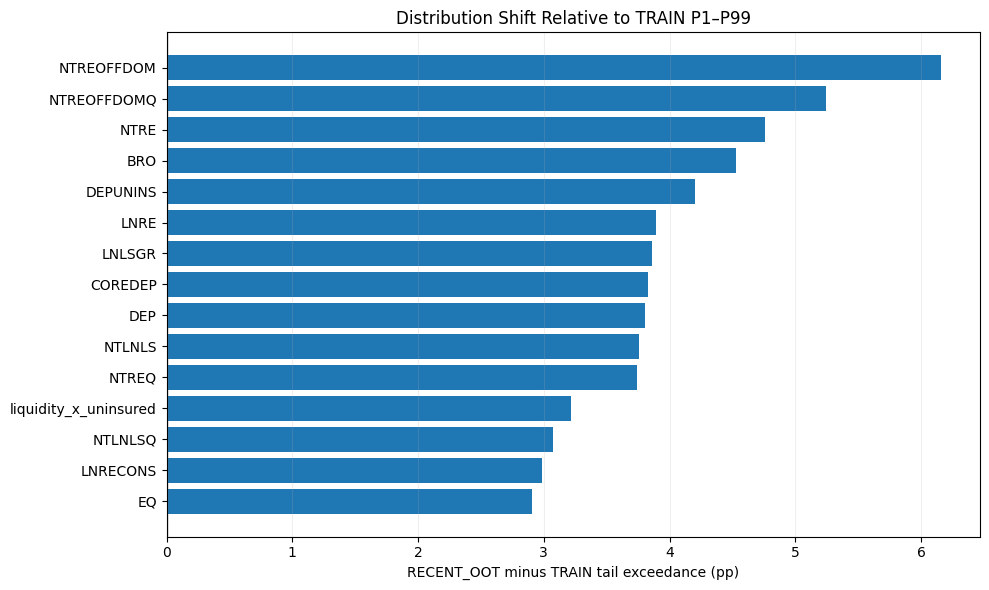


PASS — Distribution audit completed.
Predictors audited: 119
Scaling performed: NO
Transformation performed: NO
Winsorization performed: NO
Native/Imputed pipelines modified: NO


In [312]:

P4_48D_SHIFT_AGG = (
    base.group_by("__split")
    .agg(shift_exprs)
    .collect()
)

shift_rows = []

for r in P4_48D_SHIFT_AGG.to_dicts():
    for i, f in enumerate(fields):
        n = r[f"f{i}_valid"]
        outside_key = f"f{i}_outside"

        shift_rows.append({
            "split": r["__split"],
            "field": f,
            "coverage_pct": round(
                100*n/r["__rows"], 3
            ),
            "outside_train_p01_p99_pct": (
                round(100*r[outside_key]/n, 3)
                if n and outside_key in r else None
            )
        })

P4_48D_SHIFT = pl.DataFrame(shift_rows)

print("\n========== TEMPORAL SHIFT SUMMARY ==========")
display(
    P4_48D_SHIFT
    .group_by("split")
    .agg(
        pl.col("outside_train_p01_p99_pct")
        .median().alias("median_tail_exceedance_pct"),
        pl.col("outside_train_p01_p99_pct")
        .max().alias("max_tail_exceedance_pct"),
        pl.col("coverage_pct")
        .median().alias("median_field_coverage_pct")
    )
    .sort("split")
)

# Largest OOT vs TRAIN changes in tail exceedance.
pivot = P4_48D_SHIFT.pivot(
    on="split",
    index="field",
    values="outside_train_p01_p99_pct"
)

P4_48D_OOT_SHIFT = (
    pivot.with_columns(
        (
            pl.col("RECENT_OOT") - pl.col("TRAIN")
        ).alias("oot_minus_train_pp")
    )
    .sort("oot_minus_train_pp", descending=True,
          nulls_last=True)
)

print("\n========== TOP 20 OOT TAIL SHIFTS ==========")
display(P4_48D_OOT_SHIFT.head(20))

# ------------------------------------------------------------
# 3. Visualize top 15 OOT tail shifts
# ------------------------------------------------------------

chart = (
    P4_48D_OOT_SHIFT
    .filter(pl.col("oot_minus_train_pp").is_not_null())
    .head(15)
    .sort("oot_minus_train_pp")
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    chart["field"].to_list(),
    chart["oot_minus_train_pp"].to_list()
)

ax.axvline(0, color="gray", linewidth=1)
ax.set_xlabel(
    "RECENT_OOT minus TRAIN tail exceedance (pp)"
)
ax.set_title(
    "Distribution Shift Relative to TRAIN P1–P99"
)
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

print("\nPASS — Distribution audit completed.")
print("Predictors audited:", len(fields))
print("Scaling performed: NO")
print("Transformation performed: NO")
print("Winsorization performed: NO")
print("Native/Imputed pipelines modified: NO")


### 4.8D.2 | Kiểm định nonlinear features và redundancy

Đánh giá **16 nonlinear/interaction predictors** theo phương sai, phân phối, tương quan với biến gốc và mức độ extreme. Mục tiêu là nhận diện biến trùng thông tin hoặc không ổn định, **chưa xóa feature nào chỉ vì Spearman cao**.

**`[RUN]` PHASE 4 — 4.8D: NONLINEAR FEATURE VALIDATION — 2 ô liên tiếp.** Chạy lần lượt từ trên xuống; các bảng/đồ thị của cell gốc được giữ tại ô cuối của nhóm.

In [313]:

# ============================================================
# PHASE 4 — 4.8D: NONLINEAR FEATURE VALIDATION
# TRAIN only | 119 predictors | 16 newly engineered
# No deletion | No model training | No new imports
# ============================================================
import numpy as np
required = [
    "P4_48C_TRAIN", "P4_48C_FIELDS",
    "P4_48C_NEW", "P4_48C_PIPELINES",
    "P4_48C_SQUARED", "P4_48C_INTERACTIONS",
    "np", "pl"
]
assert all(x in globals() for x in required), [
    x for x in required if x not in globals()
]

new_fields = list(P4_48C_NEW)
all_fields = list(P4_48C_FIELDS)

assert len(new_fields) == 16
assert len(all_fields) == 119

# ------------------------------------------------------------
# 1. Full-TRAIN variance and missingness diagnostics
# ------------------------------------------------------------

exprs = [pl.len().alias("__rows")]

for i, f in enumerate(new_fields):
    x = pl.col(f).cast(pl.Float64)

    exprs.extend([
        x.count().alias(f"f{i}_n"),
        (x == 0).fill_null(False).sum().alias(f"f{i}_zero"),
        x.n_unique().alias(f"f{i}_unique"),
        x.std().alias(f"f{i}_std"),
        x.min().alias(f"f{i}_min"),
        x.max().alias(f"f{i}_max")
    ])

s = (
    P4_48C_TRAIN
    .select(exprs)
    .collect()
    .row(0, named=True)
)

variance_rows = []

for i, f in enumerate(new_fields):
    n = s[f"f{i}_n"]
    total = s["__rows"]
    zero_pct = (
        100 * s[f"f{i}_zero"] / n if n else None
    )

    # n_unique includes null as a distinct category.
    distinct = (
        s[f"f{i}_unique"] - int(n < total)
    )

    flag = (
        n == 0
        or distinct <= 2
        or (zero_pct is not None and zero_pct >= 99)
        or (
            s[f"f{i}_std"] is not None
            and s[f"f{i}_std"] == 0
        )
    )

    variance_rows.append({
        "feature": f,
        "coverage_pct": round(100 * n / total, 3),
        "zero_pct_observed": (
            round(zero_pct, 3) if zero_pct is not None
            else None
        ),
        "distinct_values": distinct,
        "std": s[f"f{i}_std"],
        "min": s[f"f{i}_min"],
        "max": s[f"f{i}_max"],
        "low_variance_flag": flag
    })

P4_48D_VARIANCE = pl.DataFrame(variance_rows)

print("========== NEW FEATURE VARIANCE AUDIT ==========")
display(
    P4_48D_VARIANCE.sort(
        "coverage_pct"
    )
)

# ------------------------------------------------------------
# 2. Reproducible TRAIN sample for correlation / VIF
#    Sample by bank-quarter key, not by the target label.
# ------------------------------------------------------------

sample_filter = (
    pl.struct(["CERT", "REPDTE"])
    .hash(seed=480)
    .mod(32)
    .eq(0)
)

sample_lf = (
    P4_48C_TRAIN
    .filter(sample_filter)
    .select(all_fields)
)

sample = sample_lf.collect()

assert sample.height >= 1000, (
    "Insufficient sampled observations."
)

X = sample.to_numpy().astype("float64")
X[~np.isfinite(X)] = np.nan

print("\nCorrelation/VIF TRAIN sample rows:", len(X))

# ------------------------------------------------------------
# 3. Correlation of 16 new features against all 119
#    Pairwise complete observations, minimum 200 pairs
# ------------------------------------------------------------

field_index = {
    f: i for i, f in enumerate(all_fields)
}

correlation_rows = []
min_pairs = 200


========== NEW FEATURE VARIANCE AUDIT ==========


feature,coverage_pct,zero_pct_observed,distinct_values,std,min,max,low_variance_flag
str,f64,f64,i64,f64,f64,f64,bool
"""deposit_growth_x_uninsured""",15.951,0.712,177621,965.070606,-0.996119,407499.002043,false
"""capital_x_uninsured""",16.168,0.325,180803,0.05332,-0.165465,0.964109,false
"""liquidity_x_uninsured""",16.202,0.447,180958,0.023685,-0.07383,1.0,false
"""capital_x_chargeoff_change""",90.789,10.555,910855,12.558552,-12288.333867,1352.552138,false
"""asset_growth_x_noncurrent""",97.199,6.206,1022793,0.089056,-0.921965,44.938243,false
…,…,…,…,…,…,…,…
"""roa_rolling_mean_4q_sq""",98.579,0.26,1103030,394.690114,0.0,221187.944929,false
"""capital_x_noncurrent""",98.706,7.162,1011404,0.016385,-5.879576,0.998583,false
"""noncurrent_loan_ratio_sq""",98.936,7.197,960084,0.020737,0.0,13.817787,false



Correlation/VIF TRAIN sample rows: 35195


In [314]:

for f in new_fields:
    i = field_index[f]
    xi = X[:, i]

    for g in all_fields:
        if f == g:
            continue

        j = field_index[g]
        xj = X[:, j]

        mask = np.isfinite(xi) & np.isfinite(xj)
        n = int(mask.sum())

        if n < min_pairs:
            continue

        a = xi[mask]
        b = xj[mask]

        sa = a.std()
        sb = b.std()

        if sa <= 0 or sb <= 0:
            continue

        r = float(np.corrcoef(a, b)[0, 1])

        if not np.isfinite(r):
            continue

        if abs(r) >= 0.95:
            correlation_rows.append({
                "feature": f,
                "related_field": g,
                "pearson_r": round(r, 6),
                "abs_r": abs(r),
                "paired_rows": n,
                "near_duplicate_flag": abs(r) >= 0.999
            })

P4_48D_CORRELATIONS = pl.DataFrame(
    correlation_rows,
    schema={
        "feature": pl.String,
        "related_field": pl.String,
        "pearson_r": pl.Float64,
        "abs_r": pl.Float64,
        "paired_rows": pl.Int64,
        "near_duplicate_flag": pl.Boolean
    }
).sort("abs_r", descending=True)

print("\n========== HIGH CORRELATION PAIRS ==========")
display(P4_48D_CORRELATIONS.head(40))

print("\nPairs with |r| >= 0.95:",
      P4_48D_CORRELATIONS.height)
print("Near-duplicate correlation flags:",
      P4_48D_CORRELATIONS.filter(
          pl.col("near_duplicate_flag")
      ).height)

# ------------------------------------------------------------
# 4. VIF design: the new terms + their component variables
#    VIF is computed only for the imputed TRAIN design.
# ------------------------------------------------------------

component_fields = sorted(
    set(P4_48C_SQUARED.values())
    | {
        x for pair in P4_48C_INTERACTIONS.values()
        for x in pair
    }
)

vif_fields = component_fields + new_fields

# Keep the same deterministic sample keys.
imputed_sample = (
    P4_48C_PIPELINES["TRAIN"]["imputed"]
    .filter(sample_filter)
    .select(vif_fields)
    .collect()
)

Z = imputed_sample.to_numpy().astype("float64")

assert np.isfinite(Z).all(), (
    "Non-finite values remain in imputed VIF design."
)

means = Z.mean(axis=0)
stds = Z.std(axis=0)

# Constant columns cannot have a meaningful VIF.
active = stds > 1e-12
active_fields = [
    f for f, ok in zip(vif_fields, active) if ok
]
constant_fields = [
    f for f, ok in zip(vif_fields, active) if not ok
]

Zs = (Z[:, active] - means[active]) / stds[active]

# Correlation/Gram matrix of standardized predictors.
R = (Zs.T @ Zs) / len(Zs)
R = (R + R.T) / 2

rank = int(np.linalg.matrix_rank(R))
condition_number = float(np.linalg.cond(R))

vif_rows = []

for i, f in enumerate(active_fields):

    others = [j for j in range(len(active_fields)) if j != i]

    r = R[others, i]
    R_others = R[np.ix_(others, others)]

    # Pseudoinverse handles singular auxiliary designs.
    r2 = float(r @ np.linalg.pinv(R_others) @ r)
    r2 = max(0.0, min(1.0, r2))

    vif = (
        float("inf") if r2 >= 1 - 1e-10
        else 1.0 / (1.0 - r2)
    )

    vif_rows.append({
        "feature": f,
        "vif": vif,
        "r_squared_aux": r2,
        "vif_flag": (
            "SEVERE" if vif >= 10
            else "WATCH" if vif >= 5
            else "OK"
        )
    })

P4_48D_VIF = (
    pl.DataFrame(vif_rows)
    .sort("vif", descending=True)
)

print("\n========== VIF — NEW TERMS AND COMPONENTS ==========")
display(P4_48D_VIF)

print("\n========== MATRIX DIAGNOSTICS ==========")
print("Design columns:", len(vif_fields))
print("Nonconstant columns:", len(active_fields))
print("Constant columns:", constant_fields)
print("Matrix rank:", rank, "/", len(active_fields))
print("Condition number:", condition_number)

if rank < len(active_fields):
    print("WARNING: Rank-deficient design matrix.")
elif condition_number > 1e8:
    print("WARNING: Poorly conditioned design matrix.")
else:
    print("No rank deficiency detected in this design.")

# ------------------------------------------------------------
# 5. Consolidated flags — no automatic feature deletion
# ------------------------------------------------------------

flagged_corr = set(
    P4_48D_CORRELATIONS
    .get_column("feature").to_list()
)

flagged_vif = set(
    P4_48D_VIF
    .filter(pl.col("vif") >= 10)
    .get_column("feature").to_list()
)

variance_lookup = {
    r["feature"]: r
    for r in P4_48D_VARIANCE.to_dicts()
}

P4_48D_DECISION_LOG = pl.DataFrame([
    {
        "feature": f,
        "low_variance_flag":
            variance_lookup[f]["low_variance_flag"],
        "high_corr_flag": f in flagged_corr,
        "severe_vif_flag": f in flagged_vif,
        "decision": "RETAIN_FOR_MODEL_TESTING"
    }
    for f in new_fields
])

print("\n========== FEATURE SCREENING DECISION LOG ==========")
display(P4_48D_DECISION_LOG)

print("\nPASS — Nonlinear feature screening completed.")
print("Features removed: 0")
print("Candidate predictors retained:", len(all_fields))
print("Native and Imputed pipelines unchanged.")



========== HIGH CORRELATION PAIRS ==========


feature,related_field,pearson_r,abs_r,paired_rows,near_duplicate_flag
str,str,f64,f64,i64,bool
"""liquidity_x_deposit_growth""","""deposit_growth_4q""",0.999989,0.999989,34303,true
"""deposit_growth_4q_sq""","""deposit_growth_4q""",0.99998,0.99998,34303,true
"""liquidity_x_deposit_growth""","""deposit_growth_4q_sq""",0.999941,0.999941,34303,true
"""deposit_growth_4q_sq""","""liquidity_x_deposit_growth""",0.999941,0.999941,34303,true
"""deposit_growth_4q_sq""","""deposit_growth_x_uninsured""",0.999932,0.999932,5749,true
…,…,…,…,…,…
"""capital_x_asset_growth""","""asset_growth_4q""",0.983834,0.983834,34414,false
"""capital_x_profitability""","""equity_to_assets_sq""",0.969394,0.969394,34572,false
"""equity_to_assets_sq""","""capital_x_profitability""",0.969394,0.969394,34572,false



Pairs with |r| >= 0.95: 19
Near-duplicate correlation flags: 9

========== VIF — NEW TERMS AND COMPONENTS ==========


feature,vif,r_squared_aux,vif_flag
str,f64,f64,str
"""deposit_growth_4q""",1.7983e6,0.999999,"""SEVERE"""
"""deposit_growth_4q_sq""",625850.00145,0.999998,"""SEVERE"""
"""liquidity_x_deposit_growth""",575475.712386,0.999998,"""SEVERE"""
"""asset_growth_4q""",117.367568,0.99148,"""SEVERE"""
"""capital_x_asset_growth""",76.97737,0.987009,"""SEVERE"""
…,…,…,…
"""noninterest_expense_to_assets""",1.666601,0.399976,"""OK"""
"""uninsured_deposit_share""",1.661735,0.398219,"""OK"""
"""liquidity_x_uninsured""",1.531097,0.346873,"""OK"""



========== MATRIX DIAGNOSTICS ==========
Design columns: 25
Nonconstant columns: 25
Constant columns: []
Matrix rank: 25 / 25
Condition number: 11411007.60509601
No rank deficiency detected in this design.

========== FEATURE SCREENING DECISION LOG ==========


feature,low_variance_flag,high_corr_flag,severe_vif_flag,decision
str,bool,bool,bool,str
"""equity_to_assets_sq""",false,true,true,"""RETAIN_FOR_MODEL_TESTING"""
"""noncurrent_loan_ratio_sq""",false,false,false,"""RETAIN_FOR_MODEL_TESTING"""
"""roa_rolling_mean_4q_sq""",false,false,false,"""RETAIN_FOR_MODEL_TESTING"""
"""cash_to_assets_sq""",false,false,false,"""RETAIN_FOR_MODEL_TESTING"""
"""deposit_growth_4q_sq""",false,true,true,"""RETAIN_FOR_MODEL_TESTING"""
…,…,…,…,…
"""asset_growth_x_noncurrent""",false,true,true,"""RETAIN_FOR_MODEL_TESTING"""
"""expense_burden_x_profitability""",false,false,false,"""RETAIN_FOR_MODEL_TESTING"""
"""liquidity_x_deposit_growth""",false,true,true,"""RETAIN_FOR_MODEL_TESTING"""



PASS — Nonlinear feature screening completed.
Features removed: 0
Candidate predictors retained: 119
Native and Imputed pipelines unchanged.


#### Kết quả | Nonlinear screening

16 biến mới có phương sai quan sát được; một số cặp squared/base có tương quan rất cao. **Tương quan bằng 1 theo Spearman không có nghĩa mô hình tree luôn nhận lợi ích mới từ biến bình phương**. Ngược lại, một số interactions có thể mang thông tin bổ sung. Chuyển sang kiểm tra extreme-value trước khi chọn biến.

In [315]:

# ============================================================
# PHASE 4 — 4.8D.1: EXTREME-VALUE INFLUENCE AUDIT
# Existing TRAIN sample | Diagnostic trimming only
# No feature removal | No pipeline changes
# ============================================================

assert all(k in globals() for k in [
    "X", "field_index", "np", "pl"
])

P4_48D1_PAIRS = [
    ("deposit_growth_4q",
     "deposit_growth_4q_sq"),

    ("deposit_growth_4q",
     "liquidity_x_deposit_growth"),

    ("deposit_growth_4q_sq",
     "deposit_growth_x_uninsured"),

    ("asset_growth_4q",
     "capital_x_asset_growth"),

    ("equity_to_assets_sq",
     "capital_x_profitability")
]

def p4_pair_corr(a, b):
    if len(a) < 30:
        return None
    if np.std(a) == 0 or np.std(b) == 0:
        return None
    return float(np.corrcoef(a, b)[0, 1])

rows = []

for f, g in P4_48D1_PAIRS:

    a = X[:, field_index[f]]
    b = X[:, field_index[g]]

    valid = np.isfinite(a) & np.isfinite(b)
    a = a[valid]
    b = b[valid]

    full_r = p4_pair_corr(a, b)

    # Remove values outside the paired 0.5%-99.5% ranges
    # ONLY for correlation diagnostics.
    a_lo, a_hi = np.quantile(a, [0.005, 0.995])
    b_lo, b_hi = np.quantile(b, [0.005, 0.995])

    central = (
        (a >= a_lo) & (a <= a_hi)
        & (b >= b_lo) & (b <= b_hi)
    )

    trimmed_r = p4_pair_corr(a[central], b[central])

    rows.append({
        "feature_1": f,
        "feature_2": g,
        "paired_n": len(a),
        "central_n": int(central.sum()),
        "full_pearson": full_r,
        "central_pearson": trimmed_r,
        "abs_r_change": (
            abs(full_r) - abs(trimmed_r)
            if full_r is not None and trimmed_r is not None
            else None
        )
    })

P4_48D1_RESULTS = (
    pl.DataFrame(rows)
    .sort("abs_r_change", descending=True)
)

print("========== EXTREME-VALUE INFLUENCE ==========")
display(P4_48D1_RESULTS)

# Growth-variable distribution diagnostics
growth_fields = [
    "deposit_growth_4q",
    "asset_growth_4q",
    "deposit_growth_4q_sq",
    "liquidity_x_deposit_growth"
]

dist_rows = []

for f in growth_fields:
    a = X[:, field_index[f]]
    a = a[np.isfinite(a)]

    dist_rows.append({
        "feature": f,
        "n": len(a),
        "p01": float(np.quantile(a, .01)),
        "p50": float(np.quantile(a, .50)),
        "p99": float(np.quantile(a, .99)),
        "p999": float(np.quantile(a, .999)),
        "max": float(np.max(a)),
        "min": float(np.min(a))
    })

P4_48D1_DISTRIBUTION = pl.DataFrame(dist_rows)

print("\n========== GROWTH TAIL DIAGNOSTICS ==========")
display(P4_48D1_DISTRIBUTION)

print("\nPASS — Outlier influence audited.")
print("Features removed: 0")
print("Values clipped or winsorized: 0")
print("Native and Imputed pipelines unchanged.")


========== EXTREME-VALUE INFLUENCE ==========


feature_1,feature_2,paired_n,central_n,full_pearson,central_pearson,abs_r_change
str,str,i64,i64,f64,f64,f64
"""equity_to_assets_sq""","""capital_x_profitability""",34572,34008,0.969394,0.442542,0.526852
"""deposit_growth_4q_sq""","""deposit_growth_x_uninsured""",5749,5658,0.999932,0.62586,0.374072
"""deposit_growth_4q""","""liquidity_x_deposit_growth""",34303,33805,0.999989,0.731351,0.268638
"""deposit_growth_4q""","""deposit_growth_4q_sq""",34303,33787,0.99998,0.852107,0.147872
"""asset_growth_4q""","""capital_x_asset_growth""",34414,33941,0.983834,0.860352,0.123482



========== GROWTH TAIL DIAGNOSTICS ==========


feature,n,p01,p50,p99,p999,max,min
str,i64,f64,f64,f64,f64,f64,f64
"""deposit_growth_4q""",34303,-0.202575,0.052006,1.786475,22.030987,1.911683e6,-1.0
"""asset_growth_4q""",34499,-0.203779,0.056854,1.396329,9.979592,1880.946669,-0.990249
"""deposit_growth_4q_sq""",34303,9.4359e-7,0.004315,3.191494,485.389945,3.6545e12,0.0
"""liquidity_x_deposit_growth""",34303,-0.017108,0.002077,0.118246,1.429773,52949.686393,-0.995726



PASS — Outlier influence audited.
Features removed: 0
Values clipped or winsorized: 0
Native and Imputed pipelines unchanged.


#### 4.8D.3 | Audit extreme-value tại nguồn

Kiểm tra các đột biến tăng trưởng trên quan sát gốc, phân biệt mẫu số rất nhỏ, đứt quãng báo cáo và thay đổi thực trong bảng cân đối. Không tự sửa giá trị nếu chưa có quy tắc nghiệp vụ xác thực.

**`[RUN]` PHASE 4 — 4.8D.2 FIXED — 2 ô liên tiếp.** Chạy lần lượt từ trên xuống; các bảng/đồ thị của cell gốc được giữ tại ô cuối của nhóm.

In [316]:

# ============================================================
# PHASE 4 — 4.8D.2 FIXED
# Correct extreme growth selection BEFORE Top-20 ranking
# Recalculate source audit and dependent results
# No imports | No feature changes | No source modification
# ============================================================

assert all(x in globals() for x in [
    "P4_48C_TRAIN", "SILVER", "pl"
])

audit_cols = [
    "CERT", "REPDTE", "DEP", "ASSET",
    "deposit_growth_4q", "asset_growth_4q"
]

base = P4_48C_TRAIN.select(audit_cols)

# 1. Select ONLY finite values BEFORE sorting
top_dep = (
    base
    .filter(
        pl.col("deposit_growth_4q")
        .is_finite().fill_null(False)
    )
    .sort(
        "deposit_growth_4q",
        descending=True,
        nulls_last=True
    )
    .limit(20)
    .with_columns(pl.lit("DEPOSIT").alias("__source"))
)

top_asset = (
    base
    .filter(
        pl.col("asset_growth_4q")
        .is_finite().fill_null(False)
    )
    .sort(
        "asset_growth_4q",
        descending=True,
        nulls_last=True
    )
    .limit(20)
    .with_columns(pl.lit("ASSET").alias("__source"))
)

# 2. Preserve membership in both Top-20 lists
extreme = (
    pl.concat([top_dep, top_asset])
    .group_by("CERT", "REPDTE")
    .agg(
        pl.col("DEP").first(),
        pl.col("ASSET").first(),
        pl.col("deposit_growth_4q").first(),
        pl.col("asset_growth_4q").first(),
        pl.col("__source")
          .sort()
          .str.join("+")
          .alias("__source")
    )
    .with_columns(
        (
            pl.col("REPDTE").dt.year() * 4
            + pl.col("REPDTE").dt.quarter()
        ).alias("__qidx")
    )
)

# 3. Exact four-quarter source lookup
prior_source = (
    SILVER
    .select(
        "CERT",
        pl.col("REPDTE").cast(pl.Date).alias("REPDTE"),
        pl.col("DEP").cast(pl.Float64).alias("DEP"),
        pl.col("ASSET").cast(pl.Float64).alias("ASSET")
    )
    .with_columns(
        (
            pl.col("REPDTE").dt.year() * 4
            + pl.col("REPDTE").dt.quarter() + 4
        ).alias("__qidx")
    )
    .select(
        "CERT", "__qidx",
        pl.col("DEP").alias("DEP_lag4"),
        pl.col("ASSET").alias("ASSET_lag4")
    )
)

P4_48D2_EXTREME = (
    extreme
    .join(
        prior_source,
        on=["CERT", "__qidx"],
        how="left",
        validate="m:1"
    )
    .with_columns([
        pl.when(
            pl.col("DEP_lag4").is_not_null()
            & (pl.col("DEP_lag4") > 0)
        )
        .then(
            pl.col("DEP") / pl.col("DEP_lag4") - 1
        )
        .otherwise(None)
        .alias("deposit_growth_recalculated"),

        pl.when(
            pl.col("ASSET_lag4").is_not_null()
            & (pl.col("ASSET_lag4") > 0)
        )
        .then(
            pl.col("ASSET") / pl.col("ASSET_lag4") - 1
        )
        .otherwise(None)
        .alias("asset_growth_recalculated")
    ])
    .with_columns([
        (
            pl.col("deposit_growth_4q")
            - pl.col("deposit_growth_recalculated")
        ).abs().alias("dep_growth_abs_error"),

        (
            pl.col("asset_growth_4q")
            - pl.col("asset_growth_recalculated")
        ).abs().alias("asset_growth_abs_error")
    ])
    .collect()
)

# 4. Correct Top-20 output, using group membership
print("========== TOP 20 DEPOSIT GROWTH — CORRECTED ==========")


========== TOP 20 DEPOSIT GROWTH — CORRECTED ==========


In [317]:

display(
    P4_48D2_EXTREME
    .filter(pl.col("__source").str.contains("DEPOSIT"))
    .sort(
        "deposit_growth_4q",
        descending=True,
        nulls_last=True
    )
    .select(
        "CERT", "REPDTE",
        "DEP_lag4", "DEP",
        "deposit_growth_4q",
        "deposit_growth_recalculated",
        "dep_growth_abs_error"
    )
)

print("\n========== TOP 20 ASSET GROWTH — CORRECTED ==========")

display(
    P4_48D2_EXTREME
    .filter(pl.col("__source").str.contains("ASSET"))
    .sort(
        "asset_growth_4q",
        descending=True,
        nulls_last=True
    )
    .select(
        "CERT", "REPDTE",
        "ASSET_lag4", "ASSET",
        "asset_growth_4q",
        "asset_growth_recalculated",
        "asset_growth_abs_error"
    )
)

# 5. Validate source consistency
summary = P4_48D2_EXTREME.select(
    pl.len().alias("unique_bank_quarters"),

    pl.col("__source")
    .str.contains("DEPOSIT")
    .sum().alias("deposit_top20_count"),

    pl.col("__source")
    .str.contains("ASSET")
    .sum().alias("asset_top20_count"),

    (
        pl.col("dep_growth_abs_error") > 1e-6
    ).fill_null(False).sum().alias("deposit_mismatches"),

    (
        pl.col("asset_growth_abs_error") > 1e-6
    ).fill_null(False).sum().alias("asset_mismatches")
)

print("\n========== CORRECTED NUMERICAL CONSISTENCY ==========")
display(summary)

assert summary["deposit_top20_count"][0] == 20
assert summary["asset_top20_count"][0] == 20

assert summary["deposit_mismatches"][0] == 0
assert summary["asset_mismatches"][0] == 0

print("\nPASS — Correct Top-20 selection and source audit.")
print("No feature values changed.")
print("Both pipelines unchanged.")


CERT,REPDTE,DEP_lag4,DEP,deposit_growth_4q,deposit_growth_recalculated,dep_growth_abs_error
i64,date,f64,f64,f64,f64,f64
33151,1992-09-30,1.0,1.911684e6,1.911683e6,1.911683e6,0.0
33684,2005-06-30,3.0,1.225003e6,408333.333333,408333.333333,0.0
25153,1985-09-30,1.0,232698.0,232697.0,232697.0,0.0
34168,1997-06-30,2.0,210364.0,105181.0,105181.0,0.0
34607,1999-12-31,1.0,95465.0,95464.0,95464.0,0.0
…,…,…,…,…,…,…
35328,2004-12-31,500.0,5.988602e6,11976.204,11976.204,0.0
34168,1997-09-30,53.0,591506.0,11159.490566,11159.490566,0.0
35328,2004-09-30,500.0,5.393823e6,10786.646,10786.646,0.0



========== TOP 20 ASSET GROWTH — CORRECTED ==========


CERT,REPDTE,ASSET_lag4,ASSET,asset_growth_4q,asset_growth_recalculated,asset_growth_abs_error
i64,date,f64,f64,f64,f64,f64
5134,1998-03-31,33705.0,6.6751013e7,1979.44839,1979.44839,0.0
35328,2004-12-31,6469.0,1.2174313e7,1880.946669,1880.946669,0.0
5134,1997-09-30,36103.0,6.7375521e7,1865.202836,1865.202836,0.0
35328,2004-06-30,6161.0,1.1133385e7,1806.074339,1806.074339,0.0
5134,1997-12-31,37540.0,6.7597117e7,1799.669073,1799.669073,0.0
…,…,…,…,…,…,…
1061,1998-12-31,61156.0,2.2790986e7,371.669664,371.669664,0.0
1061,1999-03-31,61021.0,2.2580576e7,369.045984,369.045984,0.0
1061,1999-06-30,64307.0,2.296142e7,356.059418,356.059418,0.0



========== CORRECTED NUMERICAL CONSISTENCY ==========


unique_bank_quarters,deposit_top20_count,asset_top20_count,deposit_mismatches,asset_mismatches
u32,u32,u32,u32,u32
33,20,20,0,0



PASS — Correct Top-20 selection and source audit.
No feature values changed.
Both pipelines unchanged.


In [318]:

# ============================================================
# 4.8D.3 — DENOMINATOR & STRUCTURAL-JUMP AUDIT
# Reuses 33 audited bank-quarter observations
# No new features, no imputation, no clipping
# ============================================================

assert "P4_48D2_EXTREME" in globals()

audit = P4_48D2_EXTREME

P4_48D3_CASES = (
    audit
    .with_columns([
        pl.when(pl.col("DEP_lag4").is_null())
        .then(pl.lit("MISSING"))
        .when(pl.col("DEP_lag4") <= 0)
        .then(pl.lit("ZERO_OR_NEGATIVE"))
        .when(pl.col("DEP_lag4") <= 100)
        .then(pl.lit("1_TO_100"))
        .when(pl.col("DEP_lag4") <= 1000)
        .then(pl.lit("101_TO_1000"))
        .otherwise(pl.lit("ABOVE_1000"))
        .alias("deposit_denominator_group"),

        pl.when(pl.col("ASSET_lag4").is_null())
        .then(pl.lit("MISSING"))
        .when(pl.col("ASSET_lag4") <= 1000)
        .then(pl.lit("UP_TO_1000"))
        .otherwise(pl.lit("ABOVE_1000"))
        .alias("asset_denominator_group"),

        (
            pl.col("deposit_growth_4q") > 100
        ).fill_null(False).alias("extreme_deposit_growth"),

        (
            pl.col("asset_growth_4q") > 100
        ).fill_null(False).alias("extreme_asset_growth")
    ])
)

print("========== EXTREME DEPOSIT GROWTH: DENOMINATORS ==========")
display(
    P4_48D3_CASES
    .filter(pl.col("extreme_deposit_growth"))
    .group_by("deposit_denominator_group")
    .agg(
        pl.len().alias("observations"),
        pl.col("DEP_lag4").min().alias("min_prior_DEP"),
        pl.col("DEP_lag4").max().alias("max_prior_DEP"),
        pl.col("deposit_growth_4q").max().alias("max_growth")
    )
    .sort("observations", descending=True)
)

print("\n========== EXTREME ASSET GROWTH: DENOMINATORS ==========")
display(
    P4_48D3_CASES
    .filter(pl.col("extreme_asset_growth"))
    .group_by("asset_denominator_group")
    .agg(
        pl.len().alias("observations"),
        pl.col("ASSET_lag4").min().alias("min_prior_ASSET"),
        pl.col("ASSET_lag4").max().alias("max_prior_ASSET"),
        pl.col("asset_growth_4q").max().alias("max_growth")
    )
)

print("\n========== BANKS WITH REPEATED EXTREME GROWTH ==========")
display(
    P4_48D3_CASES
    .filter(
        pl.col("extreme_deposit_growth")
        | pl.col("extreme_asset_growth")
    )
    .group_by("CERT")
    .agg(
        pl.len().alias("extreme_quarters"),
        pl.col("REPDTE").min().alias("first_quarter"),
        pl.col("REPDTE").max().alias("last_quarter"),
        pl.col("deposit_growth_4q").max().alias("max_dep_growth"),
        pl.col("asset_growth_4q").max().alias("max_asset_growth")
    )
    .filter(pl.col("extreme_quarters") >= 2)
    .sort("extreme_quarters", descending=True)
)

print("\nPASS — Diagnostic only.")
print("Predictors retained: 119")
print("Pipeline modifications: 0")


========== EXTREME DEPOSIT GROWTH: DENOMINATORS ==========


deposit_denominator_group,observations,min_prior_DEP,max_prior_DEP,max_growth
str,u32,f64,f64,f64
"""1_TO_100""",14,1.0,53.0,1.911683e6
"""ABOVE_1000""",9,27886.0,57000.0,1741.31765
"""101_TO_1000""",6,500.0,513.0,21479.604288



========== EXTREME ASSET GROWTH: DENOMINATORS ==========


asset_denominator_group,observations,min_prior_ASSET,max_prior_ASSET,max_growth
str,u32,f64,f64,f64
"""ABOVE_1000""",20,5188.0,66282.0,1979.44839



========== BANKS WITH REPEATED EXTREME GROWTH ==========


CERT,extreme_quarters,first_quarter,last_quarter,max_dep_growth,max_asset_growth
i64,u32,date,date,f64,f64
26305,4,1991-09-30,1992-06-30,null,1486.08963
1061,4,1998-12-31,1999-09-30,298.897807,371.669664
5134,4,1997-09-30,1998-06-30,1741.31765,1979.44839
35328,3,2004-06-30,2004-12-31,11976.204,1880.946669
57485,2,2006-09-30,2006-12-31,21479.604288,557.326197
26427,2,1987-09-30,1987-12-31,36500.0,13.846561
34168,2,1997-06-30,1997-09-30,105181.0,27.583063



PASS — Diagnostic only.
Predictors retained: 119
Pipeline modifications: 0


#### 4.8D.4 | Tần suất extreme growth trên toàn TRAIN

Kiểm tra extreme growth theo năm và theo ngân hàng, không chỉ các case mẫu. Kết quả dùng để đánh giá **mức phổ biến** và rủi ro mô hình nhạy với biến tăng trưởng; dữ liệu gốc không bị clipping.

========== FULL TRAIN EXTREME PREVALENCE ==========


feature,threshold,extreme_rows,valid_rows,pct_of_valid
str,i64,i64,i64,f64
"""deposit_growth_4q""",1,19594,1094612,1.79004
"""deposit_growth_4q""",5,3431,1094612,0.31344
"""deposit_growth_4q""",10,1713,1094612,0.15649
"""deposit_growth_4q""",100,309,1094612,0.02823
"""asset_growth_4q""",1,16581,1100833,1.50622
"""asset_growth_4q""",5,1692,1100833,0.1537
"""asset_growth_4q""",10,745,1100833,0.06768
"""asset_growth_4q""",100,93,1100833,0.00845



========== YEARLY EXTREME GROWTH ==========


__year,deposit_growth_4q__extreme_pct,asset_growth_4q__extreme_pct
i32,f64,f64
1985,0.0202,0.0
1986,0.0259,0.0057
1987,0.0349,0.0203
1988,0.0242,0.0075
1989,0.0317,0.0
…,…,…
2002,0.0401,0.008
2003,0.0109,0.0081
2004,0.0112,0.0111



========== REPEATED EXTREME BANKS ==========


CERT,extreme_quarters,first_quarter,last_quarter
i64,u32,date,date
33151,6,1992-03-31,1993-06-30
22314,5,1999-09-30,2000-09-30
35328,5,2004-03-31,2005-03-31
27319,4,1989-09-30,1990-06-30
27300,4,1989-09-30,1990-06-30
…,…,…,…
57570,4,2005-09-30,2006-06-30
27389,4,2000-06-30,2001-03-31
33931,4,2000-06-30,2001-03-31



Banks with >= 2 extreme quarters: 66


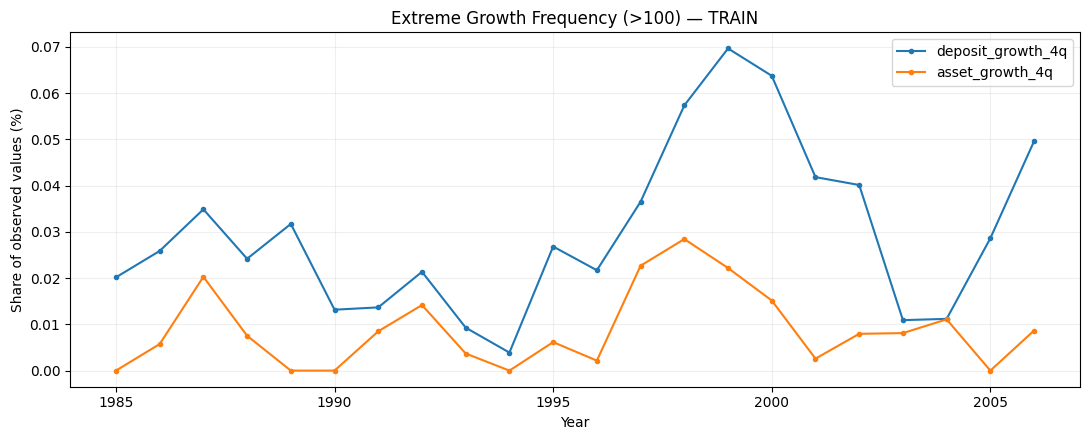


PASS — Full TRAIN growth prevalence audited.
Features removed: 0
Predictors retained: 119
Native and Imputed pipelines unchanged.


In [319]:

# ============================================================
# PHASE 4 — 4.8D.4: FULL TRAIN EXTREME GROWTH AUDIT
# TRAIN only | No new predictors | No preprocessing changes
# ============================================================

assert all(x in globals() for x in [
    "P4_48C_TRAIN", "pl", "plt"
])

growth_fields = ["deposit_growth_4q", "asset_growth_4q"]
thresholds = [1, 5, 10, 100]

# 1. Full TRAIN prevalence
exprs = [pl.len().alias("total_rows")]

for f in growth_fields:
    valid = pl.col(f).is_finite().fill_null(False)

    exprs.append(valid.sum().alias(f"{f}__valid"))

    for threshold in thresholds:
        exprs.append(
            (valid & (pl.col(f) > threshold))
            .sum().alias(f"{f}__gt_{threshold}")
        )

stats = (
    P4_48C_TRAIN
    .select(exprs)
    .collect()
    .row(0, named=True)
)

rows = []

for f in growth_fields:
    n = stats[f"{f}__valid"]

    for threshold in thresholds:
        count = stats[f"{f}__gt_{threshold}"]

        rows.append({
            "feature": f,
            "threshold": threshold,
            "extreme_rows": count,
            "valid_rows": n,
            "pct_of_valid": round(
                100 * count / n, 5
            ) if n else None
        })

P4_48D4_PREVALENCE = pl.DataFrame(rows)

print("========== FULL TRAIN EXTREME PREVALENCE ==========")
display(P4_48D4_PREVALENCE)

# 2. Yearly concentration
P4_48D4_YEARLY = (
    P4_48C_TRAIN
    .group_by("__year")
    .agg(
        pl.len().alias("rows"),
        *[
            (
                pl.col(f).is_finite().fill_null(False)
                & (pl.col(f) > 100).fill_null(False)
            ).sum().alias(f"{f}__extreme")
            for f in growth_fields
        ],
        *[
            pl.col(f).is_finite().fill_null(False)
            .sum().alias(f"{f}__valid")
            for f in growth_fields
        ]
    )
    .sort("__year")
    .collect()
)

print("\n========== YEARLY EXTREME GROWTH ==========")

display(
    P4_48D4_YEARLY.select(
        "__year",
        *[
            (
                100 * pl.col(f"{f}__extreme")
                / pl.col(f"{f}__valid")
            ).round(4).alias(f"{f}__extreme_pct")
            for f in growth_fields
        ]
    )
)

# 3. Banks repeatedly exhibiting extreme growth
P4_48D4_BANKS = (
    P4_48C_TRAIN
    .filter(
        (pl.col("deposit_growth_4q") > 100)
        | (pl.col("asset_growth_4q") > 100)
    )
    .group_by("CERT")
    .agg(
        pl.len().alias("extreme_quarters"),
        pl.col("REPDTE").min().alias("first_quarter"),
        pl.col("REPDTE").max().alias("last_quarter")
    )
    .sort("extreme_quarters", descending=True)
    .collect()
)

print("\n========== REPEATED EXTREME BANKS ==========")
display(P4_48D4_BANKS.head(20))

print("\nBanks with >= 2 extreme quarters:",
      P4_48D4_BANKS.filter(
          pl.col("extreme_quarters") >= 2
      ).height)

# 4. Plot annual extreme-value frequency
fig, ax = plt.subplots(figsize=(11, 4.5))

for f in growth_fields:
    y = (
        100
        * P4_48D4_YEARLY[f"{f}__extreme"]
        / P4_48D4_YEARLY[f"{f}__valid"]
    )

    ax.plot(
        P4_48D4_YEARLY["__year"].to_list(),
        y.to_list(),
        marker="o",
        markersize=3,
        label=f
    )

ax.set_title("Extreme Growth Frequency (>100) — TRAIN")
ax.set_xlabel("Year")
ax.set_ylabel("Share of observed values (%)")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

print("\nPASS — Full TRAIN growth prevalence audited.")
print("Features removed: 0")
print("Predictors retained: 119")
print("Native and Imputed pipelines unchanged.")


#### Kết luận | Nonlinearity và extreme values

Các interactions có cơ chế tài chính rõ được giữ để kiểm chứng bằng mô hình. Biến bình phương có thể mang thông tin lặp lại, nhưng không bị xóa chỉ dựa trên quan hệ đơn biến. Extreme growth được xem là tín hiệu cần giám sát, không mặc định là lỗi.

### 4.8E | Signed-log và scaling theo họ mô hình

Tạo các **biến thể preprocessing có kiểm soát**, gồm Native Missing và imputation kết hợp signed-log/scaling. Tham số biến đổi chỉ fit từ TRAIN; input không có sẵn trước năm báo cáo của feature vẫn được giữ là missing.

**Phương án được chuyển vào Feature Selection:** `A1_native_raw`. Các biến thể khác được giữ làm đối chứng, không thay thế nguồn.

**`[RUN]` PHASE 4 — 4.8E: TRANSFORMATION & SCALING — 2 ô liên tiếp.** Chạy lần lượt từ trên xuống; các bảng/đồ thị của cell gốc được giữ tại ô cuối của nhóm.

In [320]:

# ============================================================
# PHASE 4 — 4.8E: TRANSFORMATION & SCALING
# 119 predictors | 6 preprocessing experiments
# TRAIN-only fitting | Expanding-CV compatible
# No imports | No model training | No source overwrite
# ============================================================

required = [
    "P4_48C_BASE", "P4_48C_FIELDS",
    "p4_fit_imputer", "p4_apply_imputer", "pl"
]
assert all(x in globals() for x in required), [
    x for x in required if x not in globals()
]

P4_48E_FIELDS = list(P4_48C_FIELDS)
assert len(P4_48E_FIELDS) == 119

P4_48E_LOG_FIELDS = [
    "deposit_growth_4q",
    "asset_growth_4q",
    "deposit_growth_4q_sq",
    "liquidity_x_deposit_growth",
    "deposit_growth_x_uninsured",
    "capital_x_asset_growth",
    "asset_growth_x_noncurrent"
]

assert set(P4_48E_LOG_FIELDS).issubset(P4_48E_FIELDS)

# ------------------------------------------------------------
# 1. Deterministic signed-log transformation
#    No parameters fitted, null stays null
# ------------------------------------------------------------

def p4_48e_signedlog(lf):

    expressions = []

    for f in P4_48E_LOG_FIELDS:
        x = pl.col(f).cast(pl.Float64)

        transformed = (
            x.sign() * x.abs().log1p()
        )

        expressions.append(
            pl.when(x.is_finite().fill_null(False))
            .then(transformed)
            .otherwise(None)
            .alias(f)
        )

    return lf.with_columns(expressions)


# ------------------------------------------------------------
# 2. Train-only robust scaler
#    Median and IQR are learned from FIT data only
# ------------------------------------------------------------

def p4_48e_fit_scaler(train_imputed, fields):

    stats = (
        train_imputed
        .select([
            expr
            for f in fields
            for expr in (
                pl.col(f).median().alias(f"{f}__median"),
                pl.col(f).quantile(0.25).alias(f"{f}__q25"),
                pl.col(f).quantile(0.75).alias(f"{f}__q75")
            )
        ])
        .collect()
        .row(0, named=True)
    )

    centers = {}
    scales = {}
    zero_iqr_fields = []

    for f in fields:

        center = float(stats[f"{f}__median"])
        q25 = float(stats[f"{f}__q25"])
        q75 = float(stats[f"{f}__q75"])
        iqr = q75 - q25

        centers[f] = center

        if iqr <= 0 or not all(
            map(lambda v: abs(v) < float("inf"),
                [center, q25, q75, iqr])
        ):
            scales[f] = 1.0
            zero_iqr_fields.append(f)
        else:
            scales[f] = iqr

    return {
        "centers": centers,
        "scales": scales,
        "zero_iqr_fields": zero_iqr_fields
    }


def p4_48e_apply_scaler(lf, scaler, fields):

    return lf.with_columns([
        (
            (pl.col(f) - scaler["centers"][f])
            / scaler["scales"][f]
        ).alias(f)
        for f in fields
    ])


In [321]:


# ------------------------------------------------------------
# 3. Fit ALL preprocessing on a supplied training fold
#    Never use validation/test observations here
# ------------------------------------------------------------

def p4_48e_fit(fit_lf, candidate_fields=None):

    fields = (
        list(candidate_fields)
        if candidate_fields is not None
        else list(P4_48E_FIELDS)
    )

    raw_train = fit_lf
    log_train = p4_48e_signedlog(fit_lf)

    raw_imp = p4_fit_imputer(raw_train, fields)
    log_imp = p4_fit_imputer(log_train, fields)

    # A feature unavailable in the fit window is excluded
    # from that fold's model input, not globally deleted.
    unavailable = sorted(
        set(raw_imp["all_missing_fields"])
        | set(log_imp["all_missing_fields"])
    )

    active_fields = [
        f for f in fields if f not in unavailable
    ]

    assert active_fields, (
        "No available predictors in training fold."
    )

    raw_filled = p4_apply_imputer(
        raw_train, raw_imp, active_fields
    )

    log_filled = p4_apply_imputer(
        log_train, log_imp, active_fields
    )

    raw_scaler = p4_48e_fit_scaler(
        raw_filled, active_fields
    )

    log_scaler = p4_48e_fit_scaler(
        log_filled, active_fields
    )

    return {
        "active_fields": active_fields,
        "unavailable_fields": unavailable,
        "raw_imputer": raw_imp,
        "log_imputer": log_imp,
        "raw_scaler": raw_scaler,
        "log_scaler": log_scaler
    }


# ------------------------------------------------------------
# 4. Apply fitted state to ANY data window
#    Same predictor definitions and column order
# ------------------------------------------------------------

def p4_48e_apply(lf, state):

    fields = state["active_fields"]

    raw = lf
    signed = p4_48e_signedlog(lf)

    raw_imputed = p4_apply_imputer(
        raw, state["raw_imputer"], fields
    )

    log_imputed = p4_apply_imputer(
        signed, state["log_imputer"], fields
    )

    return {
        "A1_native_raw": raw,
        "A2_imputed_raw": raw_imputed,
        "B1_native_signedlog": signed,
        "B2_imputed_signedlog": log_imputed,
        "C1_imputed_raw_scaled": p4_48e_apply_scaler(
            raw_imputed, state["raw_scaler"], fields
        ),
        "C2_imputed_signedlog_scaled": p4_48e_apply_scaler(
            log_imputed, state["log_scaler"], fields
        )
    }


# ------------------------------------------------------------
# 5. Fit final holdout preprocessing on TRAIN 1985–2006
# ------------------------------------------------------------

P4_48E_TRAIN = P4_48C_BASE.filter(
    pl.col("__split") == "TRAIN"
)

P4_48E_STATE = p4_48e_fit(P4_48E_TRAIN)

assert len(P4_48E_STATE["active_fields"]) == 119, (
    "Full TRAIN contains unavailable features; review:"
    f" {P4_48E_STATE['unavailable_fields']}"
)

# ------------------------------------------------------------
# 6. Six experiments across the established splits
# ------------------------------------------------------------

P4_48E_PIPELINES = {}

for split in ("TRAIN", "CRISIS_TEST", "RECENT_OOT"):

    source = P4_48C_BASE.filter(
        pl.col("__split") == split
    )

    P4_48E_PIPELINES[split] = p4_48e_apply(
        source, P4_48E_STATE
    )


# ------------------------------------------------------------
# 7. Audit fitted preprocessing parameters
# ------------------------------------------------------------

P4_48E_SCALER_AUDIT = pl.DataFrame([
    {
        "feature": f,
        "raw_center": P4_48E_STATE[
            "raw_scaler"]["centers"][f],
        "raw_iqr": P4_48E_STATE[
            "raw_scaler"]["scales"][f],
        "raw_zero_iqr": f in P4_48E_STATE[
            "raw_scaler"]["zero_iqr_fields"],
        "signedlog_applied": f in P4_48E_LOG_FIELDS
    }
    for f in P4_48E_FIELDS
])

print("========== PREPROCESSING EXPERIMENTS ==========")

for name in P4_48E_PIPELINES["TRAIN"]:
    print(name)

print("\n========== TRANSFORMED GROWTH FIELDS ==========")
print(P4_48E_LOG_FIELDS)

print("\n========== SCALER FIT AUDIT ==========")
display(
    P4_48E_SCALER_AUDIT
    .filter(pl.col("signedlog_applied"))
)

print("\nZero-IQR fields, raw:",
      P4_48E_STATE["raw_scaler"]["zero_iqr_fields"])

print("Zero-IQR fields, signed-log:",
      P4_48E_STATE["log_scaler"]["zero_iqr_fields"])

print("\nPASS — Six preprocessing variants constructed.")
print("119 original candidate predictors preserved.")
print("All fitted parameters learned from TRAIN only.")
print("No source datasets modified.")


========== PREPROCESSING EXPERIMENTS ==========
A1_native_raw
A2_imputed_raw
B1_native_signedlog
B2_imputed_signedlog
C1_imputed_raw_scaled
C2_imputed_signedlog_scaled

========== TRANSFORMED GROWTH FIELDS ==========
['deposit_growth_4q', 'asset_growth_4q', 'deposit_growth_4q_sq', 'liquidity_x_deposit_growth', 'deposit_growth_x_uninsured', 'capital_x_asset_growth', 'asset_growth_x_noncurrent']

========== SCALER FIT AUDIT ==========


feature,raw_center,raw_iqr,raw_zero_iqr,signedlog_applied
str,f64,f64,bool,bool
"""asset_growth_4q""",0.056349,0.111041,false,true
"""deposit_growth_4q""",0.051585,0.113162,false,true
"""deposit_growth_4q_sq""",0.00432,0.015304,false,true
"""deposit_growth_x_uninsured""",0.008005,1.0,true,true
"""asset_growth_x_noncurrent""",0.000314,0.001195,false,true
"""liquidity_x_deposit_growth""",0.00206,0.005965,false,true
"""capital_x_asset_growth""",0.005074,0.009798,false,true



Zero-IQR fields, raw: ['DRAGSM', 'NTAGSM', 'DRAGSMQ', 'NTAGSMQ', 'NTAGSMA', 'NTCRCD', 'DRCRCD', 'DRCRCDQ', 'NTLS', 'DRLS', 'NTLSQ', 'DRLSQ', 'NTREQR', 'NTREQ', 'BRO', 'NTREOFFDOMQ', 'NTREOFFDOM', 'DRREOFFDOMQ', 'DRREOFFDOM', 'uninsured_deposit_share', 'uninsured_deposit_growth_4q', 'uninsured_deposit_share_change_4q', 'liquidity_x_uninsured', 'capital_x_uninsured', 'deposit_growth_x_uninsured']
Zero-IQR fields, signed-log: ['DRAGSM', 'NTAGSM', 'DRAGSMQ', 'NTAGSMQ', 'NTAGSMA', 'NTCRCD', 'DRCRCD', 'DRCRCDQ', 'NTLS', 'DRLS', 'NTLSQ', 'DRLSQ', 'NTREQR', 'NTREQ', 'BRO', 'NTREOFFDOMQ', 'NTREOFFDOM', 'DRREOFFDOMQ', 'DRREOFFDOM', 'uninsured_deposit_share', 'uninsured_deposit_growth_4q', 'uninsured_deposit_share_change_4q', 'liquidity_x_uninsured', 'capital_x_uninsured', 'deposit_growth_x_uninsured']

PASS — Six preprocessing variants constructed.
119 original candidate predictors preserved.
All fitted parameters learned from TRAIN only.
No source datasets modified.


In [322]:

# ============================================================
# PHASE 4 — 4.8E.1: SIGNED-LOG TRANSFORMATION AUDIT
# Full TRAIN | No refitting | No model training
# ============================================================

raw = P4_48E_PIPELINES["TRAIN"]["A1_native_raw"]
signed = P4_48E_PIPELINES["TRAIN"]["B1_native_signedlog"]

def p4_48e_distribution(lf, fields):

    return lf.select([
        expr
        for f in fields
        for expr in (
            pl.col(f).count().alias(f"{f}__n"),
            pl.col(f).min().alias(f"{f}__min"),
            pl.col(f).median().alias(f"{f}__median"),
            pl.col(f).quantile(.99).alias(f"{f}__p99"),
            pl.col(f).max().alias(f"{f}__max")
        )
    ]).collect().row(0, named=True)

a = p4_48e_distribution(raw, P4_48E_LOG_FIELDS)
b = p4_48e_distribution(signed, P4_48E_LOG_FIELDS)

P4_48E_IMPACT = pl.DataFrame([
    {
        "feature": f,
        "observed_n": a[f"{f}__n"],
        "raw_p99": a[f"{f}__p99"],
        "signedlog_p99": b[f"{f}__p99"],
        "raw_max": a[f"{f}__max"],
        "signedlog_max": b[f"{f}__max"],
        "raw_median": a[f"{f}__median"],
        "signedlog_median": b[f"{f}__median"]
    }
    for f in P4_48E_LOG_FIELDS
])

print("========== SIGNED-LOG DISTRIBUTION IMPACT ==========")
display(P4_48E_IMPACT)

print("\nPASS — Distribution transformation audited.")
print("Original feature definitions unchanged.")


========== SIGNED-LOG DISTRIBUTION IMPACT ==========


feature,observed_n,raw_p99,signedlog_p99,raw_max,signedlog_max,raw_median,signedlog_median
str,i64,f64,f64,f64,f64,f64,f64
"""deposit_growth_4q""",1094612,1.649759,0.974469,1.911683e6,14.463495,0.051585,0.050298
"""asset_growth_4q""",1100833,1.333017,0.847162,1979.44839,7.591079,0.056349,0.054819
"""deposit_growth_4q_sq""",1094612,2.721706,1.314182,3.6545e12,28.926989,0.00432,0.004311
"""liquidity_x_deposit_growth""",1094612,0.118913,0.112358,52949.686393,10.877116,0.00206,0.002058
"""deposit_growth_x_uninsured""",178949,0.590757,0.46421,407499.002043,12.917796,0.008005,0.007973
"""capital_x_asset_growth""",1098181,0.177081,0.163037,235.504253,5.465966,0.005074,0.005061
"""asset_growth_x_noncurrent""",1090476,0.020012,0.019815,44.938243,3.827298,0.000314,0.000314



PASS — Distribution transformation audited.
Original feature definitions unchanged.


#### Kết quả | Signed-log sensitivity

Signed-log nén biên độ các biến tài chính có đuôi phân phối dài nhưng vẫn bảo toàn dấu. Tác động của biến đổi **không chứng minh mô hình tốt hơn**; với tree model, Native Missing và scale gốc vẫn là ứng viên chính.

### 4.8F | Kiểm thử consistency và numerical stability

Rà soát **119 predictors × 6 preprocessing variants × 3 temporal splits**: số quan sát, missing mask, non-finite, biến đổi signed-log và fallback khi IQR bằng 0. Bước này chỉ kiểm thử kỹ thuật, không train model và không sửa dữ liệu nguồn.

**`[RUN]` PHASE 4 — 4.8F: FINAL PREPROCESSING VALIDATION — 2 ô liên tiếp.** Chạy lần lượt từ trên xuống; các bảng/đồ thị của cell gốc được giữ tại ô cuối của nhóm.

In [323]:

# ============================================================
# PHASE 4 — 4.8F: FINAL PREPROCESSING VALIDATION
# 119 predictors | 6 variants | 3 temporal splits
# No imports | No model training | No data modification
# ============================================================

required = [
    "P4_48E_PIPELINES", "P4_48E_FIELDS",
    "P4_48E_LOG_FIELDS", "P4_48E_STATE", "pl"
]
assert all(x in globals() for x in required)

fields = list(P4_48E_FIELDS)
log_fields = list(P4_48E_LOG_FIELDS)
assert len(fields) == len(set(fields)) == 119

variants = list(P4_48E_PIPELINES["TRAIN"])
splits = ["TRAIN", "CRISIS_TEST", "RECENT_OOT"]

# ------------------------------------------------------------
# 1. Audit row counts, missing cells and nonfinite cells
# ------------------------------------------------------------

audit_rows = []

for split in splits:
    for variant in variants:

        lf = P4_48E_PIPELINES[split][variant]

        assert set(fields).issubset(
            lf.collect_schema().names()
        ), f"Missing predictors: {split}/{variant}"

        missing_expr = [
            pl.col(f).is_null().cast(pl.Int64)
            for f in fields
        ]

        invalid_expr = [
            (
                pl.col(f).is_not_null()
                & ~pl.col(f).is_finite()
            ).fill_null(False).cast(pl.Int64)
            for f in fields
        ]

        stats = lf.select(
            pl.len().alias("rows"),
            pl.col("CERT").n_unique().alias("banks"),
            pl.col("y_failure_4q_v3").sum().alias("positives"),
            pl.sum_horizontal(missing_expr)
              .sum().alias("missing_cells"),
            pl.sum_horizontal(invalid_expr)
              .sum().alias("invalid_cells")
        ).collect().row(0, named=True)

        audit_rows.append({
            "split": split,
            "variant": variant,
            **stats
        })

P4_48F_SUMMARY = pl.DataFrame(audit_rows)

print("========== SIX-PIPELINE VALIDATION ==========")
display(P4_48F_SUMMARY.sort("split", "variant"))

# ------------------------------------------------------------
# 2. Assert structural consistency
# ------------------------------------------------------------

native_variants = {
    "A1_native_raw",
    "B1_native_signedlog"
}

for split in splits:

    subset = P4_48F_SUMMARY.filter(
        pl.col("split") == split
    )

    assert subset["rows"].n_unique() == 1
    assert subset["banks"].n_unique() == 1
    assert subset["positives"].n_unique() == 1

    native_missing = (
        subset
        .filter(pl.col("variant") == "A1_native_raw")
        ["missing_cells"][0]
    )

    signed_missing = (
        subset
        .filter(pl.col("variant") == "B1_native_signedlog")
        ["missing_cells"][0]
    )

    assert native_missing == signed_missing, (
        f"Native missingness changed in {split}"
    )

    for r in subset.to_dicts():
        assert r["invalid_cells"] == 0, r

        if r["variant"] not in native_variants:
            assert r["missing_cells"] == 0, r

# ------------------------------------------------------------
# 3. Verify exact native missingness masks for 7 transforms
#    and unchanged non-transformed predictor values
# ------------------------------------------------------------

raw = P4_48E_PIPELINES["TRAIN"]["A1_native_raw"]
signed = P4_48E_PIPELINES["TRAIN"]["B1_native_signedlog"]

unchanged_fields = [
    f for f in fields if f not in log_fields
]

# All non-transformed fields are aliases of the same input.
# Check schema-level column names and aggregate value equality
# for representative fields plus all transformed masks.

check_fields = list(dict.fromkeys(
    ["ASSET", "DEP", "equity_to_assets",
     "noncurrent_loan_ratio", "ROA"]
))
check_fields = [f for f in check_fields if f in unchanged_fields]

raw_check = raw.select(
    "CERT", "REPDTE",
    *check_fields,
    *log_fields
)

signed_check = signed.select(
    "CERT", "REPDTE",
    *check_fields,
    *log_fields
).rename({
    f: f"__signed_{f}"
    for f in check_fields + log_fields
})


========== SIX-PIPELINE VALIDATION ==========


split,variant,rows,banks,positives,missing_cells,invalid_cells
str,str,i64,i64,i64,i64,i64
"""CRISIS_TEST""","""A1_native_raw""",157851,8705,1880,200158,0
"""CRISIS_TEST""","""A2_imputed_raw""",157851,8705,1880,0,0
"""CRISIS_TEST""","""B1_native_signedlog""",157851,8705,1880,200158,0
"""CRISIS_TEST""","""B2_imputed_signedlog""",157851,8705,1880,0,0
"""CRISIS_TEST""","""C1_imputed_raw_scaled""",157851,8705,1880,0,0
…,…,…,…,…,…,…
"""TRAIN""","""A2_imputed_raw""",1121901,23123,8239,0,0
"""TRAIN""","""B1_native_signedlog""",1121901,23123,8239,10303526,0
"""TRAIN""","""B2_imputed_signedlog""",1121901,23123,8239,0,0


In [324]:

comparison = (
    raw_check.join(
        signed_check,
        on=["CERT", "REPDTE"],
        how="inner",
        validate="1:1"
    )
    .select(
        pl.len().alias("matched_rows"),

        *[
            (
                pl.col(f).is_null()
                != pl.col(f"__signed_{f}").is_null()
            ).sum().alias(f"mask_changed__{f}")
            for f in log_fields
        ],

        *[
            (
                (pl.col(f) != pl.col(f"__signed_{f}"))
                .fill_null(False)
            ).sum().alias(f"value_changed__{f}")
            for f in check_fields
        ]
    )
    .collect()
)

print("\n========== TRANSFORMATION INTEGRITY ==========")
display(comparison)

for f in log_fields:
    assert comparison[f"mask_changed__{f}"][0] == 0

for f in check_fields:
    assert comparison[f"value_changed__{f}"][0] == 0

# ------------------------------------------------------------
# 4. Check scaler fallback metadata
# ------------------------------------------------------------

raw_zero = P4_48E_STATE[
    "raw_scaler"]["zero_iqr_fields"]

log_zero = P4_48E_STATE[
    "log_scaler"]["zero_iqr_fields"]

P4_48F_ZERO_IQR = pl.DataFrame([
    {
        "field": f,
        "raw_zero_iqr": f in raw_zero,
        "signedlog_zero_iqr": f in log_zero,
        "raw_scale": P4_48E_STATE[
            "raw_scaler"]["scales"][f],
        "signedlog_scale": P4_48E_STATE[
            "log_scaler"]["scales"][f]
    }
    for f in fields
    if f in raw_zero or f in log_zero
])

print("\n========== ZERO-IQR SCALER AUDIT ==========")
display(P4_48F_ZERO_IQR)

print("\n========== FINAL VALIDATION STATUS ==========")
print("Features:", len(fields))
print("Variants:", len(variants))
print("Splits:", len(splits))
print("Zero-IQR features (raw):", len(raw_zero))
print("Zero-IQR features (signed-log):", len(log_zero))
print("Features removed:", 0)

print("\nPASS — Preprocessing consistency validated.")
print("Original 119-feature baseline preserved.")
print("No model training performed.")



========== TRANSFORMATION INTEGRITY ==========


matched_rows,mask_changed__deposit_growth_4q,mask_changed__asset_growth_4q,mask_changed__deposit_growth_4q_sq,mask_changed__liquidity_x_deposit_growth,mask_changed__deposit_growth_x_uninsured,mask_changed__capital_x_asset_growth,mask_changed__asset_growth_x_noncurrent,value_changed__ASSET,value_changed__DEP,value_changed__equity_to_assets,value_changed__noncurrent_loan_ratio,value_changed__ROA
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
1121901,0,0,0,0,0,0,0,0,0,0,0,0



========== ZERO-IQR SCALER AUDIT ==========


field,raw_zero_iqr,signedlog_zero_iqr,raw_scale,signedlog_scale
str,bool,bool,f64,f64
"""DRAGSM""",true,true,1.0,1.0
"""NTAGSM""",true,true,1.0,1.0
"""DRAGSMQ""",true,true,1.0,1.0
"""NTAGSMQ""",true,true,1.0,1.0
"""NTAGSMA""",true,true,1.0,1.0
…,…,…,…,…
"""uninsured_deposit_growth_4q""",true,true,1.0,1.0
"""uninsured_deposit_share_change…",true,true,1.0,1.0
"""liquidity_x_uninsured""",true,true,1.0,1.0



========== FINAL VALIDATION STATUS ==========
Features: 119
Variants: 6
Splits: 3
Zero-IQR features (raw): 25
Zero-IQR features (signed-log): 25
Features removed: 0

PASS — Preprocessing consistency validated.
Original 119-feature baseline preserved.
No model training performed.


#### Kết quả | Preprocessing consistency

Missingness có thể tăng sau khi tạo rolling/interaction vì feature chỉ xác định khi đủ lịch sử hoặc đủ toán hạng. So sánh luôn tỷ lệ thiếu trên **cùng population** và kiểm tra các mask được bảo toàn; không suy diễn missing sau engineering là lỗi dữ liệu.

<a id="p4-49"></a>

## 4.9 | Feature selection và chronological validation  `[SECTION]`

Dùng các thí nghiệm relevance/redundancy làm screening, sau đó kiểm định quy trình Top 40 theo thời gian.

### 4.9A | Feature eligibility theo training window

Không phải tất cả **119 predictors** đều có lịch sử báo cáo tương đương. Mục tiêu là xác định biến nào có sẵn ở từng training window trước khi chạy Feature Selection, tránh đưa thông tin của giai đoạn sau vào giai đoạn trước.

In [325]:

# ============================================================
# PHASE 4 — 4.9A: FOLD-WISE FEATURE ELIGIBILITY
# 119 predictors | TRAIN only | No model fitting
# ============================================================

assert all(x in globals() for x in [
    "P4_48C_TRAIN", "P4_48C_FIELDS", "pl"
])

fields = list(P4_48C_FIELDS)

# Diagnostic training-window endpoints.
# These are NOT replacements for Phase 2 CV folds.
train_end_years = [1990, 1994, 1998, 2002, 2006]

# Aggregate once by year for computational efficiency.
yearly = (
    P4_48C_TRAIN
    .group_by("__year")
    .agg(
        pl.len().alias("__rows"),
        *[
            pl.col(f).is_not_null().sum().alias(f)
            for f in fields
        ]
    )
    .sort("__year")
    .collect()
)

records = []

for end_year in train_end_years:

    window = yearly.filter(
        pl.col("__year") <= end_year
    )

    total_rows = window["__rows"].sum()

    for f in fields:
        observed = window[f].sum()

        coverage = (
            100 * observed / total_rows
            if total_rows else 0.0
        )

        records.append({
            "train_end_year": end_year,
            "feature": f,
            "observed_rows": int(observed),
            "coverage_pct": round(coverage, 3),
            "availability": (
                "UNAVAILABLE" if observed == 0
                else "LOW_COVERAGE" if coverage < 20
                else "AVAILABLE"
            )
        })

P4_49A_ELIGIBILITY = pl.DataFrame(records)

P4_49A_SUMMARY = (
    P4_49A_ELIGIBILITY
    .group_by("train_end_year", "availability")
    .agg(pl.len().alias("n_features"))
    .sort("train_end_year", "availability")
)

print("========== HISTORICAL FEATURE AVAILABILITY ==========")
display(P4_49A_SUMMARY)

print("\n========== UNINSURED-DEPOSIT FEATURE ELIGIBILITY ==========")
display(
    P4_49A_ELIGIBILITY
    .filter(
        pl.col("feature").str.contains("uninsured")
    )
    .sort("train_end_year", "feature")
)

print("\n========== FEATURES UNAVAILABLE IN EARLY WINDOWS ==========")
display(
    P4_49A_ELIGIBILITY
    .filter(pl.col("availability") == "UNAVAILABLE")
    .sort("train_end_year", "feature")
)

print("\nPASS — Fold-availability diagnostic completed.")
print("Candidate features preserved:", len(fields))
print("Features permanently removed: 0")
print("Models trained: 0")


========== HISTORICAL FEATURE AVAILABILITY ==========


train_end_year,availability,n_features
i64,str,u32
1990,"""AVAILABLE""",113
1990,"""UNAVAILABLE""",6
1994,"""AVAILABLE""",113
1994,"""UNAVAILABLE""",6
1998,"""AVAILABLE""",113
…,…,…
2002,"""AVAILABLE""",113
2002,"""LOW_COVERAGE""",4
2002,"""UNAVAILABLE""",2



========== UNINSURED-DEPOSIT FEATURE ELIGIBILITY ==========


train_end_year,feature,observed_rows,coverage_pct,availability
i64,str,i64,f64,str
1990,"""capital_x_uninsured""",0,0.0,"""UNAVAILABLE"""
1990,"""deposit_growth_x_uninsured""",0,0.0,"""UNAVAILABLE"""
1990,"""liquidity_x_uninsured""",0,0.0,"""UNAVAILABLE"""
1990,"""uninsured_deposit_growth_4q""",0,0.0,"""UNAVAILABLE"""
1990,"""uninsured_deposit_share""",0,0.0,"""UNAVAILABLE"""
…,…,…,…,…
2006,"""deposit_growth_x_uninsured""",178949,15.951,"""LOW_COVERAGE"""
2006,"""liquidity_x_uninsured""",181769,16.202,"""LOW_COVERAGE"""
2006,"""uninsured_deposit_growth_4q""",141072,12.574,"""LOW_COVERAGE"""



========== FEATURES UNAVAILABLE IN EARLY WINDOWS ==========


train_end_year,feature,observed_rows,coverage_pct,availability
i64,str,i64,f64,str
1990,"""capital_x_uninsured""",0,0.0,"""UNAVAILABLE"""
1990,"""deposit_growth_x_uninsured""",0,0.0,"""UNAVAILABLE"""
1990,"""liquidity_x_uninsured""",0,0.0,"""UNAVAILABLE"""
1990,"""uninsured_deposit_growth_4q""",0,0.0,"""UNAVAILABLE"""
1990,"""uninsured_deposit_share""",0,0.0,"""UNAVAILABLE"""
…,…,…,…,…
1998,"""uninsured_deposit_growth_4q""",0,0.0,"""UNAVAILABLE"""
1998,"""uninsured_deposit_share""",0,0.0,"""UNAVAILABLE"""
1998,"""uninsured_deposit_share_change…",0,0.0,"""UNAVAILABLE"""



PASS — Fold-availability diagnostic completed.
Candidate features preserved: 119
Features permanently removed: 0
Models trained: 0


#### Kết quả | Historical coverage và 6 biến uninsured

Bốn training windows đầu có **113 predictors khả dụng** và sáu uninsured-related predictors chưa đủ độ phủ. Khi mở rộng đến 1985–2006, sáu biến này vẫn có lịch sử quan sát ngắn hơn.

**Quyết định:** lựa chọn Top 40 trên **113 historical core predictors**; không điền các năm chưa được báo cáo bằng thông tin tương lai. Sáu biến uninsured vẫn thuộc inventory nghiên cứu, không bị tuyên bố vô ích.

<a id="p4-49b"></a>

### 4.9B | Relevance & redundancy screening  `[SECTION]`

Các phép đo đơn biến/chẩn đoán không quyết định danh sách final.

#### 4.9B.1 | Sàng lọc relevance đơn biến

Tính ROC-AUC đơn biến và các thống kê relevance trên mẫu chẩn đoán TRAIN để tìm tín hiệu ban đầu của **113 historical predictors**. Đây chỉ là *filter diagnostic*: quan hệ đơn biến không xác nhận đóng góp tăng thêm trong LightGBM.

In [326]:

# ============================================================
# PHASE 4 — 4.9B.1: UNIVARIATE FEATURE RELEVANCE
# Core historical pool: 113 predictors
# TRAIN only | No feature deletion | No model fitting
# ============================================================

from sklearn.metrics import roc_auc_score

assert all(k in globals() for k in [
    "P4_48C_TRAIN",
    "P4_48C_FIELDS",
    "np", "pl"
])

all_fields = list(P4_48C_FIELDS)

funding_fields = [
    "uninsured_deposit_share",
    "uninsured_deposit_growth_4q",
    "uninsured_deposit_share_change_4q",
    "liquidity_x_uninsured",
    "capital_x_uninsured",
    "deposit_growth_x_uninsured"
]

P4_49B_CORE = [
    f for f in all_fields
    if f not in funding_fields
]

assert len(P4_49B_CORE) == 113
assert len(all_fields) == 119

# Keep all positive observations.
# Deterministically sample approximately 1/16 of negatives.
sample = (
    P4_48C_TRAIN
    .filter(
        (pl.col("y_failure_4q_v3") == 1)
        |
        (
            pl.struct(["CERT", "REPDTE"])
            .hash(seed=490)
            .mod(16)
            .eq(0)
        )
    )
    .select(
        "CERT", "REPDTE",
        "y_failure_4q_v3",
        *P4_49B_CORE
    )
    .collect()
)

y = sample["y_failure_4q_v3"].to_numpy()
assert set(np.unique(y)).issubset({0, 1})
assert len(np.unique(y)) == 2

print("========== DIAGNOSTIC SAMPLE ==========")
print("Rows:", sample.height)
print("Positive:", int((y == 1).sum()))
print("Negative:", int((y == 0).sum()))
print("Core features:", len(P4_49B_CORE))

results = []

for f in P4_49B_CORE:

    x = sample[f].to_numpy().astype("float64")
    valid = np.isfinite(x)

    n_positive = int((valid & (y == 1)).sum())
    n_negative = int((valid & (y == 0)).sum())

    auc = None

    if (
        n_positive >= 50
        and n_negative >= 200
        and np.unique(x[valid]).size >= 2
    ):
        auc = float(roc_auc_score(y[valid], x[valid]))

    # Missingness itself may carry a signal.
    missing = (~valid).astype(int)

    missing_auc = (
        float(roc_auc_score(y, missing))
        if np.unique(missing).size == 2
        else None
    )

    results.append({
        "feature": f,
        "observed_positive": n_positive,
        "observed_negative": n_negative,
        "coverage_pct": round(
            100 * valid.mean(), 3
        ),
        "univariate_auc": auc,
        "auc_strength": (
            abs(auc - 0.5)
            if auc is not None else None
        ),
        "missing_indicator_auc": missing_auc
    })

P4_49B_RELEVANCE = (
    pl.DataFrame(results)
    .sort("auc_strength", descending=True, nulls_last=True)
)

print("\n========== TOP 25 UNIVARIATE RELEVANCE ==========")
display(P4_49B_RELEVANCE.head(25))

print("\n========== LOWEST 20 UNIVARIATE RELEVANCE ==========")
display(
    P4_49B_RELEVANCE
    .filter(pl.col("auc_strength").is_not_null())
    .sort("auc_strength")
    .head(20)
)

print("\n========== MISSINGNESS SIGNAL ==========")
display(
    P4_49B_RELEVANCE
    .with_columns(
        (
            pl.col("missing_indicator_auc") - 0.5
        ).abs().alias("missing_signal_strength")
    )
    .sort(
        "missing_signal_strength",
        descending=True,
        nulls_last=True
    )
    .select(
        "feature",
        "coverage_pct",
        "missing_indicator_auc",
        "missing_signal_strength"
    )
    .head(15)
)

print("\nPASS — Preliminary relevance screening completed.")
print("Core historical features:", len(P4_49B_CORE))
print("Expanded inventory:", len(all_fields))
print("Features removed: 0")
print("Models trained: 0")


========== DIAGNOSTIC SAMPLE ==========
Rows: 77819
Positive: 8239
Negative: 69580
Core features: 113

========== TOP 25 UNIVARIATE RELEVANCE ==========


feature,observed_positive,observed_negative,coverage_pct,univariate_auc,auc_strength,missing_indicator_auc
str,i64,i64,f64,f64,f64,f64
"""equity_to_assets""",8239,69417,99.791,0.045344,0.454656,0.498829
"""roa_rolling_mean_4q""",8211,68590,98.692,0.056556,0.443444,0.494585
"""expense_burden_x_profitability""",8211,68430,98.486,0.063495,0.436505,0.493435
"""RBC1AAJ""",8239,69580,100.0,0.06583,0.43417,null
"""ROA""",8239,69580,100.0,0.069067,0.430933,null
…,…,…,…,…,…,…
"""asset_growth_4q""",8194,68248,98.231,0.197967,0.302033,0.493159
"""IDERNCVQR""",8239,69580,100.0,0.203606,0.296394,null
"""NALNLS""",5964,65912,92.363,0.786041,0.286041,0.611705



========== LOWEST 20 UNIVARIATE RELEVANCE ==========


feature,observed_positive,observed_negative,coverage_pct,univariate_auc,auc_strength,missing_indicator_auc
str,i64,i64,f64,f64,f64,f64
"""COREDEP""",8239,69574,99.992,0.500873,0.000873,0.499957
"""NONIIQ""",8239,69417,99.791,0.496421,0.003579,0.498829
"""DRLSQ""",4823,59645,82.844,0.503663,0.003663,0.635914
"""LNRERT1R""",5952,65820,92.229,0.504065,0.004065,0.611772
"""NTLSQ""",4823,59645,82.844,0.504393,0.004393,0.635914
…,…,…,…,…,…,…
"""DRCRCD""",5960,65415,91.719,0.485178,0.014822,0.608376
"""INTINC""",8239,69417,99.791,0.515109,0.015109,0.498829
"""LNRE""",8239,69580,100.0,0.518149,0.018149,null



========== MISSINGNESS SIGNAL ==========


feature,coverage_pct,missing_indicator_auc,missing_signal_strength
str,f64,f64,f64
"""NTLS""",82.86,0.636007,0.136007
"""DRLS""",82.86,0.636007,0.136007
"""NTLSQ""",82.844,0.635914,0.135914
"""DRLSQ""",82.844,0.635914,0.135914
"""net_chargeoff_rate_change_4q""",88.304,0.634954,0.134954
…,…,…,…
"""DRAGSMQ""",76.204,0.634485,0.134485
"""ROE""",96.186,0.632201,0.132201
"""net_chargeoff_volatility_4q""",89.046,0.628927,0.128927



PASS — Preliminary relevance screening completed.
Core historical features: 113
Expanded inventory: 119
Features removed: 0
Models trained: 0


#### Diễn giải | Relevance và missingness

Nhóm **capital, profitability, asset quality** nổi bật trong các thống kê đơn biến. Nhưng một biến có thể có AUC tốt do reporting regime, cơ cấu ngân hàng hoặc missingness. Không chọn predictors chỉ từ bảng univariate; cần kiểm định khả năng ổn định theo thời gian.

#### 4.9B.2 | Relevance qua các giai đoạn

So sánh hướng và mức độ liên hệ với nhãn giữa các giai đoạn TRAIN. Mục tiêu là nhận biết predictors có tín hiệu nhất quán, tránh dùng kết quả gộp lịch sử như bằng chứng về khả năng tổng quát hóa.

In [327]:

# ============================================================
# PHASE 4 — 4.9B.2: TEMPORAL RELEVANCE STABILITY
# Existing diagnostic sample | TRAIN 1985–2006
# No imports | No refitting | No feature deletion
# ============================================================

assert all(k in globals() for k in [
    "sample", "P4_49B_RELEVANCE",
    "np", "pl", "roc_auc_score"
])

# Top 25 by observed-value relevance
top_relevance = (
    P4_49B_RELEVANCE
    .head(25)
    .get_column("feature").to_list()
)

# Top 15 by missingness relevance
top_missing = (
    P4_49B_RELEVANCE
    .with_columns(
        (pl.col("missing_indicator_auc") - 0.5)
        .abs().alias("__missing_strength")
    )
    .sort("__missing_strength", descending=True, nulls_last=True)
    .head(15)
    .get_column("feature").to_list()
)

audit_fields = list(dict.fromkeys(
    top_relevance + top_missing
))

# Sample already contains all 113 core predictors.
# Add year only; do not change the sampled population.
audit_sample = sample.with_columns(
    pl.col("REPDTE").dt.year().alias("__year")
)

results = []

for year_df in audit_sample.partition_by("__year"):

    year = int(year_df["__year"][0])
    y_year = year_df["y_failure_4q_v3"].to_numpy()

    for f in audit_fields:

        x = year_df[f].to_numpy().astype("float64")
        observed = np.isfinite(x)

        pos_obs = int((observed & (y_year == 1)).sum())
        neg_obs = int((observed & (y_year == 0)).sum())

        auc = None
        if (
            pos_obs >= 20
            and neg_obs >= 100
            and np.unique(x[observed]).size >= 2
        ):
            auc = float(
                roc_auc_score(y_year[observed], x[observed])
            )

        pos_total = int((y_year == 1).sum())
        neg_total = int((y_year == 0).sum())

        pos_missing = (
            100 * ((~observed) & (y_year == 1)).sum()
            / pos_total
            if pos_total else None
        )

        neg_missing = (
            100 * ((~observed) & (y_year == 0)).sum()
            / neg_total
            if neg_total else None
        )

        results.append({
            "year": year,
            "feature": f,
            "positive_observed": pos_obs,
            "negative_observed": neg_obs,
            "annual_auc": auc,
            "annual_auc_strength": (
                abs(auc - 0.5) if auc is not None else None
            ),
            "annual_direction": (
               None if auc is None
                else "POSITIVE" if auc > 0.5
                else "NEGATIVE" if auc < 0.5
                else "NEUTRAL"
            ),
            "missing_gap_pp": (
                float(pos_missing - neg_missing)
                if pos_missing is not None
                and neg_missing is not None
                else None
            )
        })

P4_49B2_YEARLY = pl.DataFrame(results)

P4_49B2_SUMMARY = (
    P4_49B2_YEARLY
    .group_by("feature")
    .agg(
        pl.col("annual_auc").count().alias("eligible_years"),
        pl.col("annual_auc").median()
        .alias("median_annual_auc"),
        pl.col("annual_auc_strength").median()
        .alias("median_annual_auc_strength"),
        (
            pl.col("annual_direction") == "NEGATIVE"
        ).sum().alias("negative_direction_years"),
        (
            pl.col("annual_direction") == "POSITIVE"
        ).sum().alias("positive_direction_years"),
        pl.col("missing_gap_pp").median()
        .alias("median_annual_missing_gap_pp")
    )
    .with_columns(
        pl.max_horizontal(
            "negative_direction_years",
            "positive_direction_years"
        )
        .truediv(pl.col("eligible_years"))
        .alias("direction_consistency")
    )
    .sort(
        "median_annual_auc_strength",
        descending=True,
        nulls_last=True
    )
)

print("========== TEMPORAL RELEVANCE STABILITY ==========")
display(P4_49B2_SUMMARY.head(25))

print("\n========== UNSTABLE FEATURE DIRECTIONS ==========")
display(
    P4_49B2_SUMMARY
    .filter(pl.col("eligible_years") >= 5)
    .sort("direction_consistency")
    .head(15)
)

print("\n========== ANNUAL MISSINGNESS SIGNAL ==========")
display(
    P4_49B2_SUMMARY
    .with_columns(
        pl.col("median_annual_missing_gap_pp")
        .abs().alias("__abs_gap")
    )
    .sort("__abs_gap", descending=True, nulls_last=True)
    .select(
        "feature",
        "eligible_years",
        "median_annual_missing_gap_pp"
    )
    .head(15)
)

print("\nPASS — TRAIN temporal relevance audited.")
print("Features assessed:", len(audit_fields))
print("Features removed:", 0)
print("External test labels used:", 0)


========== TEMPORAL RELEVANCE STABILITY ==========


feature,eligible_years,median_annual_auc,median_annual_auc_strength,negative_direction_years,positive_direction_years,median_annual_missing_gap_pp,direction_consistency
str,u32,f64,f64,u32,u32,f64,f64
"""RBCRWAJ""",10,0.064244,0.435756,10,0,0.0,1.0
"""roa_rolling_mean_4q""",15,0.066745,0.433255,15,0,-1.271802,1.0
"""expense_burden_x_profitability""",15,0.074812,0.425188,15,0,-1.417151,1.0
"""equity_to_assets""",15,0.088561,0.411439,15,0,-0.227531,1.0
"""ROA""",15,0.094603,0.405397,15,0,0.0,1.0
…,…,…,…,…,…,…,…
"""EQ""",15,0.210881,0.289119,15,0,-0.227531,1.0
"""NALNLS""",15,0.783768,0.283768,0,15,0.0,1.0
"""asset_growth_4q""",15,0.216682,0.283318,15,0,-1.671512,1.0



========== UNSTABLE FEATURE DIRECTIONS ==========


feature,eligible_years,median_annual_auc,median_annual_auc_strength,negative_direction_years,positive_direction_years,median_annual_missing_gap_pp,direction_consistency
str,u32,f64,f64,u32,u32,f64,f64
"""DRLS""",12,0.502242,0.008869,5,7,5.844156,0.583333
"""DRLSQ""",12,0.501922,0.006076,5,7,5.811688,0.583333
"""NTLSQ""",12,0.501838,0.005072,5,7,5.811688,0.583333
"""NTLS""",12,0.502694,0.003825,4,8,5.844156,0.666667
"""LNCONT1R""",15,0.538903,0.073149,4,11,-0.154799,0.733333
…,…,…,…,…,…,…,…
"""NTAGSM""",12,0.52448,0.02448,1,11,2.352151,0.916667
"""net_chargeoff_rate_change_4q""",15,0.603343,0.103343,1,14,-2.553534,0.933333
"""RBCRWAJ""",10,0.064244,0.435756,10,0,0.0,1.0



========== ANNUAL MISSINGNESS SIGNAL ==========


feature,eligible_years,median_annual_missing_gap_pp
str,u32,f64
"""DRLS""",12,5.844156
"""NTLS""",12,5.844156
"""DRLSQ""",12,5.811688
"""NTLSQ""",12,5.811688
"""ROE""",15,4.188312
…,…,…
"""NTAGSMA""",12,2.318548
"""DRAGSMQ""",12,2.318548
"""NTAGSMQ""",12,2.318548



PASS — TRAIN temporal relevance audited.
Features assessed: 38
Features removed: 0
External test labels used: 0


#### Kết quả | Temporal relevance

Một số biến vốn, lợi nhuận và interactions giữ hướng liên hệ qua các giai đoạn; một số khác thay đổi đáng kể. **Không loại tự động** chỉ vì điểm khác nhau giữa các thời kỳ, đặc biệt khi số positive observations rất chênh lệch.

#### 4.9B.3 | Redundancy trên nhóm biến ưu tiên

Dùng Spearman theo hai giai đoạn để kiểm tra **38 predictors** đã qua relevance screening. Tương quan đo độ gần nhau của *ranking*, không chứng minh hai đại lượng đồng nhất hoặc không có tương tác.

In [328]:

# ============================================================
# PHASE 4 — 4.9B.3: TEMPORAL SPEARMAN REDUNDANCY
# Existing TRAIN diagnostic sample
# 38 previously audited candidate predictors
# No model fitting | No feature removal
# ============================================================

assert all(k in globals() for k in [
    "sample", "P4_49B2_SUMMARY", "np", "pl"
])

P4_49B3_FIELDS = (
    P4_49B2_SUMMARY
    .get_column("feature")
    .to_list()
)

assert len(P4_49B3_FIELDS) == 38

# Convert only the already-collected diagnostic sample.
# pandas is used by the correlation routine; no source scan.
p4_49b3_df = (
    sample
    .select("REPDTE", *P4_49B3_FIELDS)
    .to_pandas()
)

p4_49b3_df["year"] = (
    p4_49b3_df["REPDTE"].dt.year
)

# Ensure nonfinite values are treated as missing.
p4_49b3_df[P4_49B3_FIELDS] = (
    p4_49b3_df[P4_49B3_FIELDS]
    .replace([np.inf, -np.inf], np.nan)
)

# Full and historical subperiod correlations.
P4_49B3_CORR = {
    "FULL_TRAIN_SAMPLE": (
        p4_49b3_df[P4_49B3_FIELDS]
        .corr(method="spearman", min_periods=1000)
    ),
    "EARLY_1985_1994": (
        p4_49b3_df.loc[
            p4_49b3_df["year"].between(1985, 1994),
            P4_49B3_FIELDS
        ]
        .corr(method="spearman", min_periods=500)
    ),
    "LATE_1995_2006": (
        p4_49b3_df.loc[
            p4_49b3_df["year"].between(1995, 2006),
            P4_49B3_FIELDS
        ]
        .corr(method="spearman", min_periods=500)
    )
}

# ------------------------------------------------------------
# 1. Extract unique feature pairs
# ------------------------------------------------------------

full_corr = P4_49B3_CORR["FULL_TRAIN_SAMPLE"]
early_corr = P4_49B3_CORR["EARLY_1985_1994"]
late_corr = P4_49B3_CORR["LATE_1995_2006"]

rows = []

for i, feature_a in enumerate(P4_49B3_FIELDS):
    for feature_b in P4_49B3_FIELDS[i + 1:]:

        r_full = full_corr.loc[feature_a, feature_b]
        r_early = early_corr.loc[feature_a, feature_b]
        r_late = late_corr.loc[feature_a, feature_b]

        rows.append({
            "feature_a": feature_a,
            "feature_b": feature_b,
            "spearman_full": (
                float(r_full) if np.isfinite(r_full) else None
            ),
            "spearman_early": (
                float(r_early) if np.isfinite(r_early) else None
            ),
            "spearman_late": (
                float(r_late) if np.isfinite(r_late) else None
            ),
            "abs_corr_change": (
                float(abs(r_late - r_early))
                if np.isfinite(r_early) and np.isfinite(r_late)
                else None
            )
        })

P4_49B3_PAIRS = (
    pl.DataFrame(rows)
    .with_columns(
        pl.col("spearman_full")
        .abs()
        .alias("abs_spearman_full")
    )
)

# ------------------------------------------------------------
# 2. High overall monotonic redundancy
# ------------------------------------------------------------

P4_49B3_HIGH = (
    P4_49B3_PAIRS
    .filter(pl.col("abs_spearman_full") >= 0.95)
    .sort("abs_spearman_full", descending=True)
)

print("========== HIGH SPEARMAN REDUNDANCY ==========")
display(P4_49B3_HIGH.head(30))

print("\nPairs |Spearman| >= 0.95:",
      P4_49B3_HIGH.height)

# ------------------------------------------------------------
# 3. Redundancy instability across historical regimes
# ------------------------------------------------------------

print("\n========== LARGEST TEMPORAL CORRELATION CHANGES ==========")

display(
    P4_49B3_PAIRS
    .filter(
        pl.col("spearman_early").is_not_null()
        & pl.col("spearman_late").is_not_null()
    )
    .sort("abs_corr_change", descending=True)
    .head(25)
)

# ------------------------------------------------------------
# 4. Pairs strongly correlated in BOTH subperiods
# ------------------------------------------------------------

P4_49B3_STABLE_HIGH = (
    P4_49B3_PAIRS
    .filter(
        (pl.col("spearman_early").abs() >= 0.95)
        & (pl.col("spearman_late").abs() >= 0.95)
    )
    .sort("abs_spearman_full", descending=True)
)

print("\n========== PERSISTENT HIGH REDUNDANCY ==========")
display(P4_49B3_STABLE_HIGH.head(30))

print("\n========== DIAGNOSTIC STATUS ==========")
print("Features assessed:", len(P4_49B3_FIELDS))
print("Unique feature pairs:", P4_49B3_PAIRS.height)
print("High overall correlation pairs:", P4_49B3_HIGH.height)
print("High in both periods:", P4_49B3_STABLE_HIGH.height)
print("Features removed:", 0)
print("Models trained:", 0)

print("\nPASS — Temporal redundancy screening completed.")


========== HIGH SPEARMAN REDUNDANCY ==========


feature_a,feature_b,spearman_full,spearman_early,spearman_late,abs_corr_change,abs_spearman_full
str,str,f64,f64,f64,f64,f64
"""noncurrent_loan_ratio_sq""","""noncurrent_loan_ratio""",1.0,1.0,1.0,0.0,1.0
"""RBCT1""","""RBCT1J""",0.999999,1.0,0.999997,0.000003,0.999999
"""NTAGSMA""","""NTAGSM""",0.99453,0.991888,0.999878,0.00799,0.99453
"""RBCT1""","""EQ""",0.990554,0.985459,0.993667,0.008209,0.990554
"""RBCT1J""","""EQ""",0.990553,0.985459,0.993666,0.008207,0.990553
"""ORE""","""OREOTH""",0.976873,0.974761,0.978552,0.003791,0.976873



Pairs |Spearman| >= 0.95: 6

========== LARGEST TEMPORAL CORRELATION CHANGES ==========


feature_a,feature_b,spearman_full,spearman_early,spearman_late,abs_corr_change,abs_spearman_full
str,str,f64,f64,f64,f64,f64
"""noncurrent_x_profitability""","""noncurrent_loan_ratio_sq""",0.232846,-0.034453,0.798075,0.832528,0.232846
"""noncurrent_x_profitability""","""noncurrent_loan_ratio""",0.232846,-0.034453,0.798075,0.832528,0.232846
"""noncurrent_x_profitability""","""NCLNLS""",0.18326,-0.027801,0.620004,0.647805,0.18326
"""equity_to_assets""","""ROE""",0.013092,0.201802,-0.338048,0.53985,0.013092
"""ROE""","""equity_to_assets_sq""",0.010241,0.195488,-0.338081,0.533569,0.010241
…,…,…,…,…,…,…
"""roa_rolling_mean_4q""","""equity_to_assets""",0.478306,0.611835,0.150074,0.461761,0.478306
"""RBCRWAJ""","""equity_to_assets_sq""",0.556122,0.30877,0.770423,0.461653,0.556122
"""equity_to_assets""","""ROA""",0.432749,0.568929,0.109061,0.459868,0.432749



========== PERSISTENT HIGH REDUNDANCY ==========


feature_a,feature_b,spearman_full,spearman_early,spearman_late,abs_corr_change,abs_spearman_full
str,str,f64,f64,f64,f64,f64
"""noncurrent_loan_ratio_sq""","""noncurrent_loan_ratio""",1.0,1.0,1.0,0.0,1.0
"""RBCT1""","""RBCT1J""",0.999999,1.0,0.999997,0.000003,0.999999
"""NTAGSMA""","""NTAGSM""",0.99453,0.991888,0.999878,0.00799,0.99453
"""RBCT1""","""EQ""",0.990554,0.985459,0.993667,0.008209,0.990554
"""RBCT1J""","""EQ""",0.990553,0.985459,0.993666,0.008207,0.990553
"""ORE""","""OREOTH""",0.976873,0.974761,0.978552,0.003791,0.976873



========== DIAGNOSTIC STATUS ==========
Features assessed: 38
Unique feature pairs: 703
High overall correlation pairs: 6
High in both periods: 6
Features removed: 0
Models trained: 0

PASS — Temporal redundancy screening completed.


#### Kết quả | Temporal redundancy

Có **6/703 cặp** đạt |Spearman| ≥0,95 ở cả hai giai đoạn. Những cặp này cần kiểm tra định nghĩa và missing mask, nhưng không loại biến theo ngưỡng tương quan một cách máy móc.

#### 4.9B.4 | Kiểm định redundancy trên historical core

Mở rộng đánh giá sang **113 historical predictors** với thống kê theo hai giai đoạn. Các heatmap và đồ thị đã có bên dưới thể hiện cụm tương quan; bảng cho phép truy vết tên biến cụ thể.

**`[RUN]` PHASE 4 — 4.9B.4: FULL CORE REDUNDANCY AUDIT — 2 ô liên tiếp.** Chạy lần lượt từ trên xuống; các bảng/đồ thị của cell gốc được giữ tại ô cuối của nhóm.

In [329]:

# ============================================================
# PHASE 4 — 4.9B.4: FULL CORE REDUNDANCY AUDIT
# 113 core features | 6,328 unique pairs
# Reuse existing TRAIN diagnostic sample
# No new imports | No imputation | No model training
# ============================================================

assert all(k in globals() for k in [
    "sample", "P4_49B_CORE", "np", "pl"
])

fields = list(P4_49B_CORE)
assert len(fields) == len(set(fields)) == 113

# ------------------------------------------------------------
# 1. Reuse the already-materialized diagnostic sample
# ------------------------------------------------------------

df = sample.select(
    "REPDTE", *fields
).to_pandas()

df["__year"] = df["REPDTE"].dt.year

df[fields] = df[fields].replace(
    [np.inf, -np.inf], np.nan
)

periods = {
    "full": df,
    "early": df.loc[df["__year"].between(1985, 1994)],
    "late": df.loc[df["__year"].between(1995, 2006)]
}

# ------------------------------------------------------------
# 2. Spearman matrices
# ------------------------------------------------------------

corr = {
    "full": periods["full"][fields].corr(
        method="spearman", min_periods=1000
    ),
    "early": periods["early"][fields].corr(
        method="spearman", min_periods=500
    ),
    "late": periods["late"][fields].corr(
        method="spearman", min_periods=500
    )
}

# ------------------------------------------------------------
# 3. All 6,328 unique feature pairs
# ------------------------------------------------------------

rows = []

for i, a in enumerate(fields):
    for b in fields[i + 1:]:

        rf = corr["full"].loc[a, b]
        re = corr["early"].loc[a, b]
        rl = corr["late"].loc[a, b]

        rows.append({
            "feature_a": a,
            "feature_b": b,
            "spearman_full": (
                float(rf) if np.isfinite(rf) else None
            ),
            "spearman_early": (
                float(re) if np.isfinite(re) else None
            ),
            "spearman_late": (
                float(rl) if np.isfinite(rl) else None
            ),
            "abs_temporal_change": (
                float(abs(rl - re))
                if np.isfinite(re) and np.isfinite(rl)
                else None
            )
        })

P4_49B4_PAIRS = (
    pl.DataFrame(rows)
    .with_columns(
        pl.col("spearman_full")
        .abs().alias("abs_spearman_full")
    )
)

assert P4_49B4_PAIRS.height == 6328

# ------------------------------------------------------------
# 4. High-correlation and persistent-correlation groups
# ------------------------------------------------------------

P4_49B4_HIGH = (
    P4_49B4_PAIRS
    .filter(pl.col("abs_spearman_full") >= 0.95)
    .sort("abs_spearman_full", descending=True)
)

P4_49B4_PERSISTENT = (
    P4_49B4_PAIRS
    .filter(
        (pl.col("spearman_early").abs() >= 0.95)
        & (pl.col("spearman_late").abs() >= 0.95)
    )
    .sort("abs_spearman_full", descending=True)
)

print("========== FULL CORE HIGH REDUNDANCY ==========")
display(P4_49B4_HIGH.head(40))

print("\n========== PERSISTENT HIGH REDUNDANCY ==========")
display(P4_49B4_PERSISTENT.head(40))

print("\n========== LARGEST TEMPORAL CHANGES ==========")
display(
    P4_49B4_PAIRS
    .sort(
        "abs_temporal_change",
        descending=True,
        nulls_last=True
    )
    .head(25)
)

# ------------------------------------------------------------
# 5. Verify pairwise observed counts for shortlisted pairs
# ------------------------------------------------------------

shortlist = (
    P4_49B4_HIGH
    .head(40)
    .select("feature_a", "feature_b")
    .to_dicts()
)

support_rows = []


========== FULL CORE HIGH REDUNDANCY ==========


feature_a,feature_b,spearman_full,spearman_early,spearman_late,abs_temporal_change,abs_spearman_full
str,str,f64,f64,f64,f64,f64
"""noncurrent_loan_ratio""","""noncurrent_loan_ratio_sq""",1.0,1.0,1.0,0.0,1.0
"""cash_to_assets""","""cash_to_assets_sq""",1.0,1.0,1.0,5.1154e-9,1.0
"""RBCT1J""","""RBCT1""",0.999999,1.0,0.999997,0.000003,0.999999
"""EOTHNINT""","""ADDNONINTEXP""",0.999826,1.0,0.999538,0.000462,0.999826
"""EOTHNINQ""","""ADDNONINTEXPQ""",0.999788,1.0,0.999444,0.000556,0.999788
…,…,…,…,…,…,…
"""LNLSGR""","""ASSET""",0.960589,0.959594,0.959127,0.000467,0.960589
"""LNLSGR""","""DEP""",0.957348,0.957894,0.95437,0.003524,0.957348
"""DRCONOTH""","""DRCON""",0.956519,0.959897,0.952273,0.007624,0.956519



========== PERSISTENT HIGH REDUNDANCY ==========


feature_a,feature_b,spearman_full,spearman_early,spearman_late,abs_temporal_change,abs_spearman_full
str,str,f64,f64,f64,f64,f64
"""noncurrent_loan_ratio""","""noncurrent_loan_ratio_sq""",1.0,1.0,1.0,0.0,1.0
"""cash_to_assets""","""cash_to_assets_sq""",1.0,1.0,1.0,5.1154e-9,1.0
"""RBCT1J""","""RBCT1""",0.999999,1.0,0.999997,0.000003,0.999999
"""EOTHNINT""","""ADDNONINTEXP""",0.999826,1.0,0.999538,0.000462,0.999826
"""EOTHNINQ""","""ADDNONINTEXPQ""",0.999788,1.0,0.999444,0.000556,0.999788
…,…,…,…,…,…,…
"""LNLSGR""","""ASSET""",0.960589,0.959594,0.959127,0.000467,0.960589
"""LNLSGR""","""DEP""",0.957348,0.957894,0.95437,0.003524,0.957348
"""DRCONOTH""","""DRCON""",0.956519,0.959897,0.952273,0.007624,0.956519



========== LARGEST TEMPORAL CHANGES ==========


feature_a,feature_b,spearman_full,spearman_early,spearman_late,abs_temporal_change,abs_spearman_full
str,str,f64,f64,f64,f64,f64
"""noncurrent_loan_ratio""","""noncurrent_x_profitability""",0.232846,-0.034453,0.798075,0.832528,0.232846
"""noncurrent_loan_ratio_sq""","""noncurrent_x_profitability""",0.232846,-0.034453,0.798075,0.832528,0.232846
"""NCLNLS""","""noncurrent_x_profitability""",0.18326,-0.027801,0.620004,0.647805,0.18326
"""roa_rolling_mean_4q""","""roa_rolling_mean_4q_sq""",0.470015,0.22904,0.863087,0.634047,0.470015
"""ROA""","""roa_rolling_mean_4q_sq""",0.414565,0.18755,0.796508,0.608958,0.414565
…,…,…,…,…,…,…
"""RBC1AAJ""","""expense_burden_x_profitability""",0.419276,0.553693,0.073845,0.479847,0.419276
"""noncurrent_loan_ratio""","""asset_growth_x_noncurrent""",0.07463,-0.084567,0.395063,0.47963,0.07463
"""noncurrent_loan_ratio_sq""","""asset_growth_x_noncurrent""",0.07463,-0.084567,0.395063,0.47963,0.07463


In [330]:

for pair in shortlist:
    a, b = pair["feature_a"], pair["feature_b"]

    record = {
        "feature_a": a,
        "feature_b": b
    }

    for period_name, period_df in periods.items():

        both = period_df[[a, b]].notna().all(axis=1)

        record[f"n_pair_{period_name}"] = int(both.sum())
        record[f"coverage_{period_name}_pct"] = round(
            100 * both.mean(), 3
        )

    support_rows.append(record)

P4_49B4_SUPPORT = pl.DataFrame(
    support_rows,
    schema={
        "feature_a": pl.String,
        "feature_b": pl.String,
        **{
            f"n_pair_{p}": pl.Int64
            for p in periods
        },
        **{
            f"coverage_{p}_pct": pl.Float64
            for p in periods
        }
    }
) if support_rows else None

print("\n========== HIGH-CORRELATION PAIR SUPPORT ==========")

if P4_49B4_SUPPORT is not None:
    display(P4_49B4_SUPPORT)
else:
    print("No pairs above |Spearman| >= 0.95.")

# ------------------------------------------------------------
# 6. Check near-equivalence of selected accounting columns
#    Direct equality is diagnostic; it does not validate
#    the underlying economic or regulatory definitions.
# ------------------------------------------------------------

candidate_pairs = [
    ("RBCT1J", "RBCT1"),
    ("RBCT1", "EQ"),
    ("NTAGSMA", "NTAGSM"),
    ("ORE", "OREOTH"),
    ("noncurrent_loan_ratio_sq",
     "noncurrent_loan_ratio")
]

agreement_rows = []

for a, b in candidate_pairs:

    if a not in fields or b not in fields:
        continue

    vals = df[[a, b]].dropna()
    xa = vals[a].to_numpy(dtype=float)
    xb = vals[b].to_numpy(dtype=float)

    if len(xa) == 0:
        continue

    agreement_rows.append({
        "feature_a": a,
        "feature_b": b,
        "n_joint_observed": len(xa),
        "exact_equal_pct": round(
            100 * np.mean(xa == xb), 4
        ),
        "max_absolute_difference": float(
            np.max(np.abs(xa - xb))
        )
    })

P4_49B4_AGREEMENT = pl.DataFrame(agreement_rows)

print("\n========== DIRECT VALUE AGREEMENT ==========")
display(P4_49B4_AGREEMENT)

# ------------------------------------------------------------
# 7. Diagnostic summary
# ------------------------------------------------------------

print("\n========== 4.9B.4 STATUS ==========")
print("Core predictors:", len(fields))
print("Unique pairs:", P4_49B4_PAIRS.height)
print("High Spearman pairs:", P4_49B4_HIGH.height)
print("Persistent high pairs:", P4_49B4_PERSISTENT.height)
print("Features removed:", 0)
print("Models trained:", 0)

print("\nPASS — Full core-pool redundancy audited.")



========== HIGH-CORRELATION PAIR SUPPORT ==========


feature_a,feature_b,n_pair_full,n_pair_early,n_pair_late,coverage_full_pct,coverage_early_pct,coverage_late_pct
str,str,i64,i64,i64,f64,f64,f64
"""noncurrent_loan_ratio""","""noncurrent_loan_ratio_sq""",77072,46633,30439,99.04,99.363,98.55
"""cash_to_assets""","""cash_to_assets_sq""",77819,46932,30887,100.0,100.0,100.0
"""RBCT1J""","""RBCT1""",71787,40970,30817,92.249,87.297,99.773
"""EOTHNINT""","""ADDNONINTEXP""",77656,46839,30817,99.791,99.802,99.773
"""EOTHNINQ""","""ADDNONINTEXPQ""",77656,46839,30817,99.791,99.802,99.773
…,…,…,…,…,…,…,…
"""LNLSGR""","""ASSET""",77819,46932,30887,100.0,100.0,100.0
"""LNLSGR""","""DEP""",77819,46932,30887,100.0,100.0,100.0
"""DRCONOTH""","""DRCON""",71375,40558,30817,91.719,86.419,99.773



========== DIRECT VALUE AGREEMENT ==========


feature_a,feature_b,n_joint_observed,exact_equal_pct,max_absolute_difference
str,str,i64,f64,f64
"""RBCT1J""","""RBCT1""",71787,99.8802,287579.0
"""RBCT1""","""EQ""",71787,47.6674,3.3731812e7
"""NTAGSMA""","""NTAGSM""",59301,86.9125,11508.0
"""ORE""","""OREOTH""",77656,94.2426,644431.0
"""noncurrent_loan_ratio_sq""","""noncurrent_loan_ratio""",77072,6.5899,0.587398



========== 4.9B.4 STATUS ==========
Core predictors: 113
Unique pairs: 6328
High Spearman pairs: 26
Persistent high pairs: 26
Features removed: 0
Models trained: 0

PASS — Full core-pool redundancy audited.


**`[RUN]` PHASE 4 — 4.9B.4 VISUALIZATION DASHBOARD — 2 ô liên tiếp.** Chạy lần lượt từ trên xuống; các bảng/đồ thị của cell gốc được giữ tại ô cuối của nhóm.

========== ALL 26 HIGH REDUNDANCY PAIRS ==========


feature_a,feature_b,spearman_full,spearman_early,spearman_late,abs_temporal_change,abs_spearman_full
str,str,f64,f64,f64,f64,f64
"""noncurrent_loan_ratio""","""noncurrent_loan_ratio_sq""",1.0,1.0,1.0,0.0,1.0
"""cash_to_assets""","""cash_to_assets_sq""",1.0,1.0,1.0,5.1154e-9,1.0
"""RBCT1J""","""RBCT1""",0.999999,1.0,0.999997,0.000003,0.999999
"""EOTHNINT""","""ADDNONINTEXP""",0.999826,1.0,0.999538,0.000462,0.999826
"""EOTHNINQ""","""ADDNONINTEXPQ""",0.999788,1.0,0.999444,0.000556,0.999788
"""NTAGSM""","""NTAGSMA""",0.99453,0.991888,0.999878,0.00799,0.99453
"""NONIXQ""","""NONIXA""",0.991729,0.991248,0.992126,0.000877,0.991729
"""RBCT1""","""EQ""",0.990554,0.985459,0.993667,0.008209,0.990554
"""RBCT1J""","""EQ""",0.990553,0.985459,0.993666,0.008207,0.990553



========== ALL 26 PERSISTENT PAIRS ==========


feature_a,feature_b,spearman_full,spearman_early,spearman_late,abs_temporal_change,abs_spearman_full
str,str,f64,f64,f64,f64,f64
"""noncurrent_loan_ratio""","""noncurrent_loan_ratio_sq""",1.0,1.0,1.0,0.0,1.0
"""cash_to_assets""","""cash_to_assets_sq""",1.0,1.0,1.0,5.1154e-9,1.0
"""RBCT1J""","""RBCT1""",0.999999,1.0,0.999997,0.000003,0.999999
"""EOTHNINT""","""ADDNONINTEXP""",0.999826,1.0,0.999538,0.000462,0.999826
"""EOTHNINQ""","""ADDNONINTEXPQ""",0.999788,1.0,0.999444,0.000556,0.999788
"""NTAGSM""","""NTAGSMA""",0.99453,0.991888,0.999878,0.00799,0.99453
"""NONIXQ""","""NONIXA""",0.991729,0.991248,0.992126,0.000877,0.991729
"""RBCT1""","""EQ""",0.990554,0.985459,0.993667,0.008209,0.990554
"""RBCT1J""","""EQ""",0.990553,0.985459,0.993666,0.008207,0.990553



========== ALL 26 PAIR SUPPORT RECORDS ==========


feature_a,feature_b,n_pair_full,n_pair_early,n_pair_late,coverage_full_pct,coverage_early_pct,coverage_late_pct
str,str,i64,i64,i64,f64,f64,f64
"""noncurrent_loan_ratio""","""noncurrent_loan_ratio_sq""",77072,46633,30439,99.04,99.363,98.55
"""cash_to_assets""","""cash_to_assets_sq""",77819,46932,30887,100.0,100.0,100.0
"""RBCT1J""","""RBCT1""",71787,40970,30817,92.249,87.297,99.773
"""EOTHNINT""","""ADDNONINTEXP""",77656,46839,30817,99.791,99.802,99.773
"""EOTHNINQ""","""ADDNONINTEXPQ""",77656,46839,30817,99.791,99.802,99.773
"""NTAGSM""","""NTAGSMA""",59301,33860,25441,76.204,72.147,82.368
"""NONIXQ""","""NONIXA""",77656,46839,30817,99.791,99.802,99.773
"""RBCT1""","""EQ""",71787,40970,30817,92.249,87.297,99.773
"""RBCT1J""","""EQ""",71787,40970,30817,92.249,87.297,99.773



========== ALL 25 LARGEST TEMPORAL CHANGES ==========


feature_a,feature_b,spearman_full,spearman_early,spearman_late,abs_temporal_change,abs_spearman_full
str,str,f64,f64,f64,f64,f64
"""noncurrent_loan_ratio""","""noncurrent_x_profitability""",0.232846,-0.034453,0.798075,0.832528,0.232846
"""noncurrent_loan_ratio_sq""","""noncurrent_x_profitability""",0.232846,-0.034453,0.798075,0.832528,0.232846
"""NCLNLS""","""noncurrent_x_profitability""",0.18326,-0.027801,0.620004,0.647805,0.18326
"""roa_rolling_mean_4q""","""roa_rolling_mean_4q_sq""",0.470015,0.22904,0.863087,0.634047,0.470015
"""ROA""","""roa_rolling_mean_4q_sq""",0.414565,0.18755,0.796508,0.608958,0.414565
"""DRREOFFDOM""","""RBCRWAJ""",0.197235,0.3427,-0.220801,0.563501,0.197235
"""LNCDT1R""","""RBCRWAJ""",-0.081928,0.046893,-0.509587,0.55648,0.081928
"""roa_rolling_mean_4q_sq""","""expense_burden_x_profitability""",0.343139,0.134166,0.678776,0.54461,0.343139
"""ROE""","""equity_to_assets""",0.013092,0.201802,-0.338048,0.53985,0.013092



========== DIRECT VALUE AGREEMENT ==========


feature_a,feature_b,n_joint_observed,exact_equal_pct,max_absolute_difference
str,str,i64,f64,f64
"""RBCT1J""","""RBCT1""",71787,99.8802,287579.0
"""RBCT1""","""EQ""",71787,47.6674,3.3731812e7
"""NTAGSMA""","""NTAGSM""",59301,86.9125,11508.0
"""ORE""","""OREOTH""",77656,94.2426,644431.0
"""noncurrent_loan_ratio_sq""","""noncurrent_loan_ratio""",77072,6.5899,0.587398


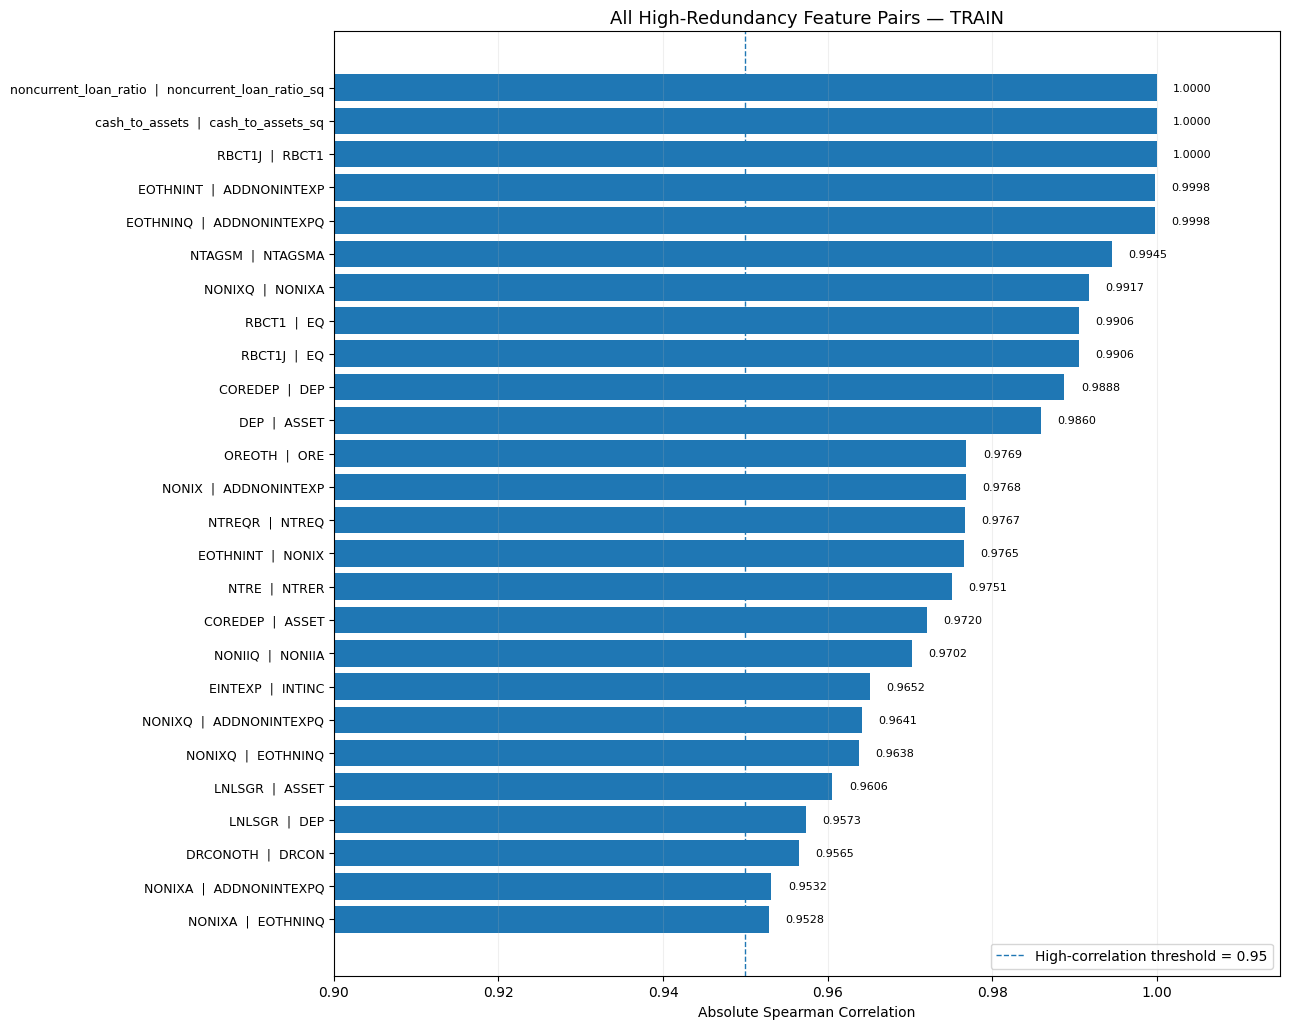

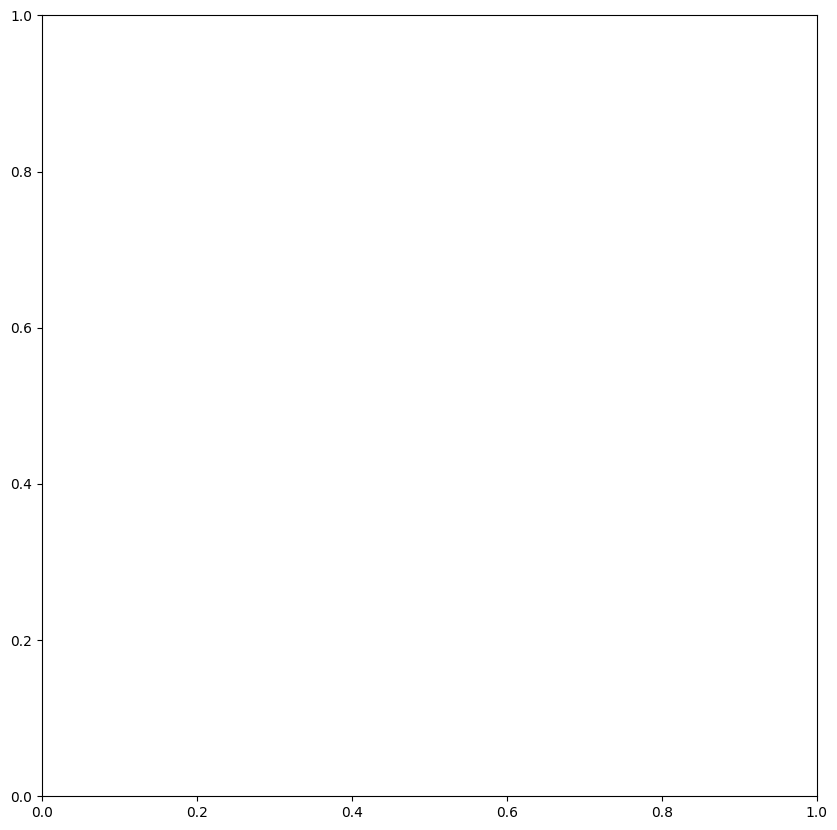

In [331]:

# ============================================================
# PHASE 4 — 4.9B.4 VISUALIZATION DASHBOARD
# Display all results without Polars/Jupyter truncation
# Reuses existing computed tables and correlation matrices
# No recalculation | No imports | No feature changes
# ============================================================

required = [
    "P4_49B4_HIGH",
    "P4_49B4_PERSISTENT",
    "P4_49B4_PAIRS",
    "P4_49B4_AGREEMENT",
    "P4_49B4_SUPPORT",
    "corr",
    "np", "pl", "plt"
]

assert all(x in globals() for x in required), (
    "Missing objects: "
    + str([x for x in required if x not in globals()])
)

# Display complete Polars tables (no ellipsis)
with pl.Config(
    tbl_rows=-1,
    tbl_cols=-1,
    fmt_str_lengths=80,
    tbl_width_chars=240
):

    print("========== ALL 26 HIGH REDUNDANCY PAIRS ==========")
    display(P4_49B4_HIGH)

    print("\n========== ALL 26 PERSISTENT PAIRS ==========")
    display(P4_49B4_PERSISTENT)

    print("\n========== ALL 26 PAIR SUPPORT RECORDS ==========")
    display(P4_49B4_SUPPORT)

    print("\n========== ALL 25 LARGEST TEMPORAL CHANGES ==========")
    display(
        P4_49B4_PAIRS.sort(
            "abs_temporal_change",
            descending=True,
            nulls_last=True
        ).head(25)
    )

    print("\n========== DIRECT VALUE AGREEMENT ==========")
    display(P4_49B4_AGREEMENT)


# ------------------------------------------------------------
# CHART 1 — All 26 high-correlation feature pairs
# ------------------------------------------------------------

high = P4_49B4_HIGH.to_dicts()

labels = [
    r["feature_a"] + "  |  " + r["feature_b"]
    for r in high
]

values = [
    r["abs_spearman_full"]
    for r in high
]

fig, ax = plt.subplots(
    figsize=(13, max(7, len(high) * 0.40))
)

positions = np.arange(len(high))

bars = ax.barh(
    positions,
    values
)

ax.set_yticks(positions)
ax.set_yticklabels(labels, fontsize=9)
ax.invert_yaxis()

ax.set_xlim(0.90, 1.015)
ax.axvline(
    0.95,
    linestyle="--",
    linewidth=1,
    label="High-correlation threshold = 0.95"
)

for bar, value in zip(bars, values):
    ax.text(
        min(value + 0.002, 1.005),
        bar.get_y() + bar.get_height() / 2,
        f"{value:.4f}",
        va="center",
        fontsize=8
    )

ax.set_title(
    "All High-Redundancy Feature Pairs — TRAIN",
    fontsize=13
)
ax.set_xlabel("Absolute Spearman Correlation")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# CHART 2 — All 26 high-correlation pairs:
# Early vs Late vs Full TRAIN
# ------------------------------------------------------------

period_cols = [
    "spearman_early",
    "spearman_late",
    "spearman_full"
]

period_labels = [
    "1985–1994",
    "1995–2006",
    "Full TRAIN"
]

matrix = np.array([
    [
        r[col] if r[col] is not None else np.nan
        for col in period_cols
    ]
    for r in high
], dtype=float)

fig, ax = plt.subplots(
    figsize=(10, max(8, len(high) * 0.39))
)


<Figure size 640x480 with 0 Axes>

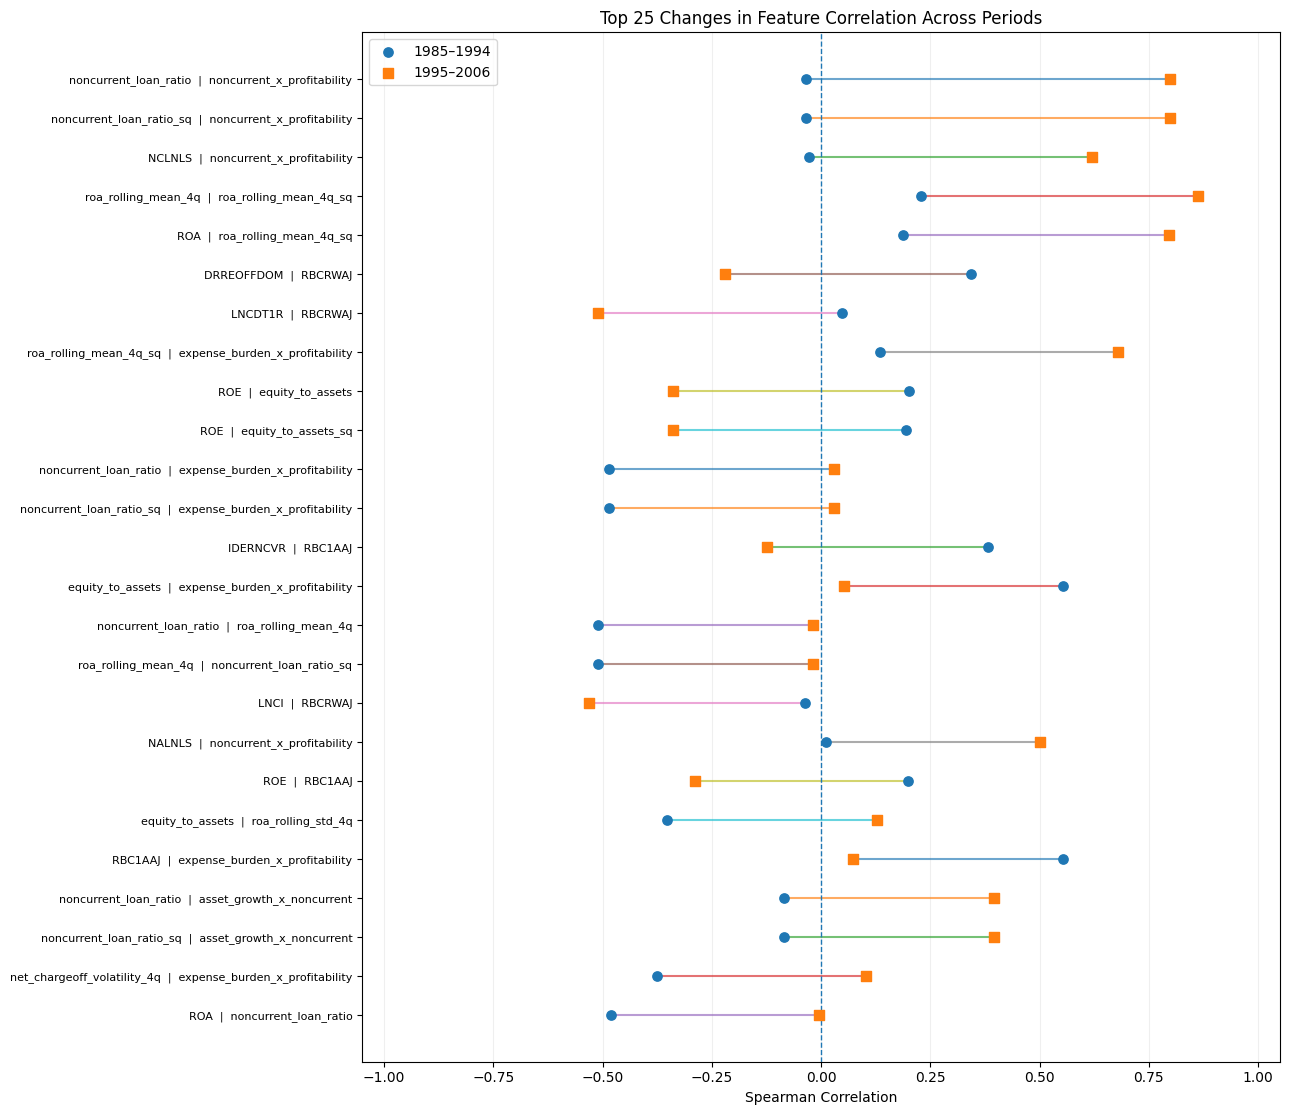

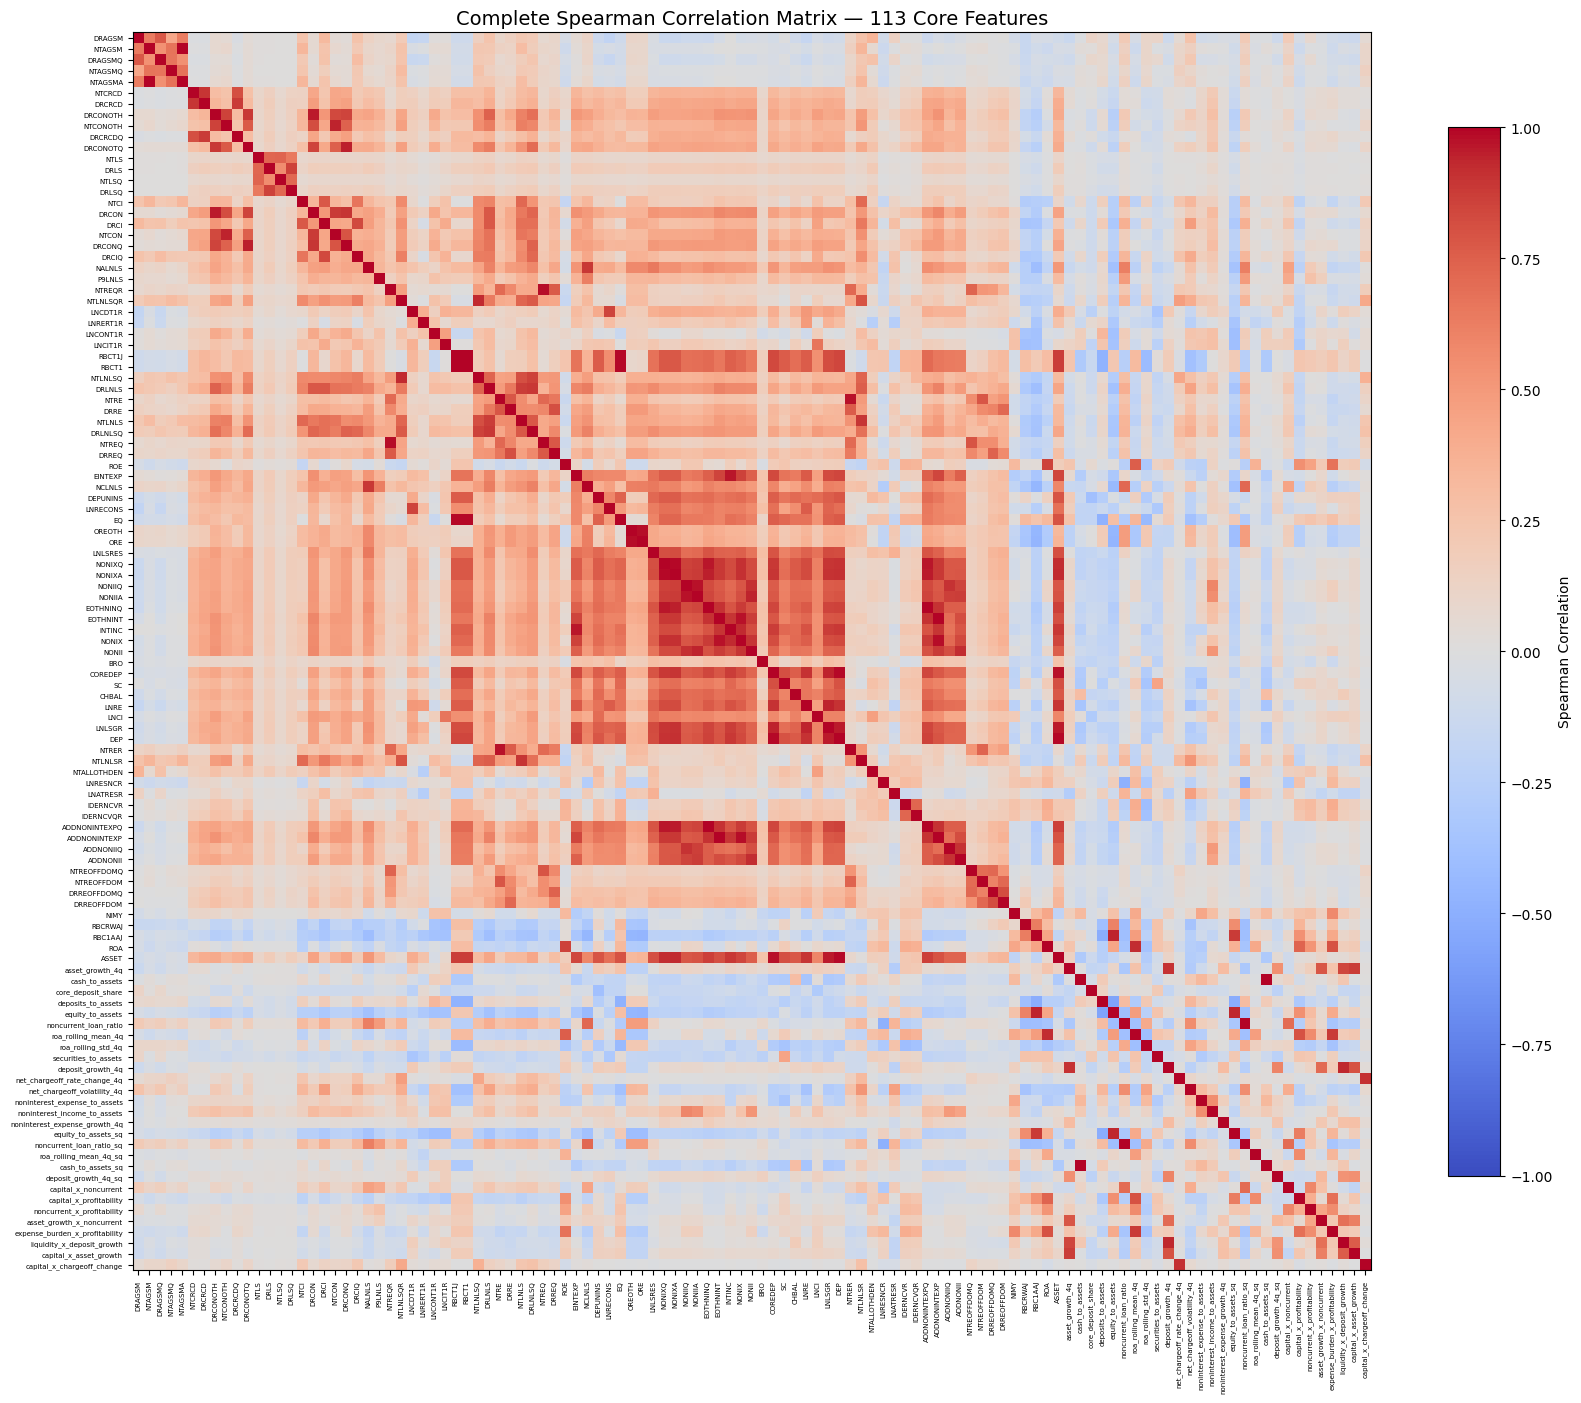


========== DASHBOARD STATUS ==========
Core predictors: 113
All unique pairs: 6328
High redundancy pairs: 26
Temporal changes plotted: 25
Charts generated: 4
Features removed: 0

PASS — Full redundancy visualization completed.


In [332]:

im = ax.imshow(
    matrix,
    aspect="auto",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(3))
ax.set_xticklabels(period_labels)

ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels, fontsize=8)

for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        value = matrix[i, j]

        if np.isfinite(value):
            ax.text(
                j, i,
                f"{value:.3f}",
                ha="center",
                va="center",
                fontsize=8,
                color="white"
                if abs(value) >= 0.75 else "black"
            )

fig.colorbar(
    im,
    ax=ax,
    label="Spearman Correlation",
    shrink=0.75
)

ax.set_title(
    "Temporal Persistence of High-Redundancy Pairs"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# CHART 3 — Top 25 correlation changes across periods
# ------------------------------------------------------------

changes = (
    P4_49B4_PAIRS
    .filter(
        pl.col("spearman_early").is_not_null()
        & pl.col("spearman_late").is_not_null()
    )
    .sort("abs_temporal_change", descending=True)
    .head(25)
    .to_dicts()
)

change_labels = [
    r["feature_a"] + "  |  " + r["feature_b"]
    for r in changes
]

early_values = np.array([
    r["spearman_early"] for r in changes
])

late_values = np.array([
    r["spearman_late"] for r in changes
])

ypos = np.arange(len(changes))

fig, ax = plt.subplots(
    figsize=(13, max(9, len(changes) * 0.45))
)

# Connect the two period-specific correlations.
for i in range(len(changes)):
    ax.plot(
        [early_values[i], late_values[i]],
        [i, i],
        linewidth=1.5,
        alpha=0.65
    )

ax.scatter(
    early_values, ypos,
    marker="o",
    s=45,
    label="1985–1994",
    zorder=3
)

ax.scatter(
    late_values, ypos,
    marker="s",
    s=45,
    label="1995–2006",
    zorder=3
)

ax.set_yticks(ypos)
ax.set_yticklabels(change_labels, fontsize=8)
ax.invert_yaxis()

ax.set_xlim(-1.05, 1.05)
ax.axvline(0, linestyle="--", linewidth=1)

ax.set_title(
    "Top 25 Changes in Feature Correlation Across Periods"
)
ax.set_xlabel("Spearman Correlation")

ax.legend()
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# CHART 4 — Full 113-feature Spearman heatmap
# All pairwise relationships, not just top-26
# ------------------------------------------------------------

full_matrix = corr["full"].to_numpy(
    dtype=float
)

full_names = corr["full"].index.to_list()

fig, ax = plt.subplots(figsize=(17, 15))

im = ax.imshow(
    full_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    interpolation="nearest"
)

ax.set_xticks(range(len(full_names)))
ax.set_xticklabels(
    full_names,
    rotation=90,
    fontsize=5
)

ax.set_yticks(range(len(full_names)))
ax.set_yticklabels(
    full_names,
    fontsize=5
)

fig.colorbar(
    im,
    ax=ax,
    label="Spearman Correlation",
    shrink=0.75
)

ax.set_title(
    "Complete Spearman Correlation Matrix — 113 Core Features",
    fontsize=14
)

plt.tight_layout()
plt.show()

print("\n========== DASHBOARD STATUS ==========")
print("Core predictors:", len(full_names))
print("All unique pairs:", P4_49B4_PAIRS.height)
print("High redundancy pairs:", len(high))
print("Temporal changes plotted:", len(changes))
print("Charts generated: 4")
print("Features removed: 0")

print("\nPASS — Full redundancy visualization completed.")


#### Đọc biểu đồ | Cụm tương quan

Trong **6.328 cặp** được đánh giá, **26 cặp** có |ρ|≥0,95 và duy trì mạnh qua cả hai thời kỳ. Các cụm squared/base và tỷ lệ tài chính gần trùng cần được xem cùng định nghĩa kế toán. Heatmap hỗ trợ nhìn cấu trúc cụm; **không diễn giải màu đậm là bằng chứng loại biến**.

========== ALL 26 PAIRS: VALUE AGREEMENT ==========


feature_a,feature_b,spearman,n_joint,coverage_pct,exact_match_pct,near_match_pct,different_rows,different_positive_rows,median_abs_difference_nonmatch,max_abs_difference
str,str,f64,i64,f64,f64,f64,i64,i64,f64,f64
"""RBCT1J""","""RBCT1""",0.999999,71787,92.24868,99.880201,99.880201,86,0,536.0,287579.0
"""EOTHNINQ""","""ADDNONINTEXPQ""",0.999788,77656,99.79054,96.384053,96.384053,2808,14,30.0,384065.0
"""EOTHNINT""","""ADDNONINTEXP""",0.999826,77656,99.79054,96.286185,96.286185,2884,15,61.5,1.120413e6
"""OREOTH""","""ORE""",0.976873,77656,99.79054,94.242557,94.242557,4471,1587,728.0,644431.0
"""NTAGSM""","""NTAGSMA""",0.99453,59301,76.203755,86.912531,86.912531,7761,616,13.6653,11508.0
"""DRCONOTH""","""DRCON""",0.956519,71375,91.719246,76.926095,76.926095,16469,1198,10.0,3.837879e6
"""NTREQR""","""NTREQ""",0.976709,70669,90.812012,60.16358,60.16358,28152,3634,15.98,208719.19
"""NTRE""","""NTRER""",0.975076,71788,92.249965,51.218867,51.218867,35019,4166,23.915175,384297.315587
"""RBCT1""","""EQ""",0.990554,71787,92.24868,47.667405,47.668798,37567,1598,187.0,3.3731812e7


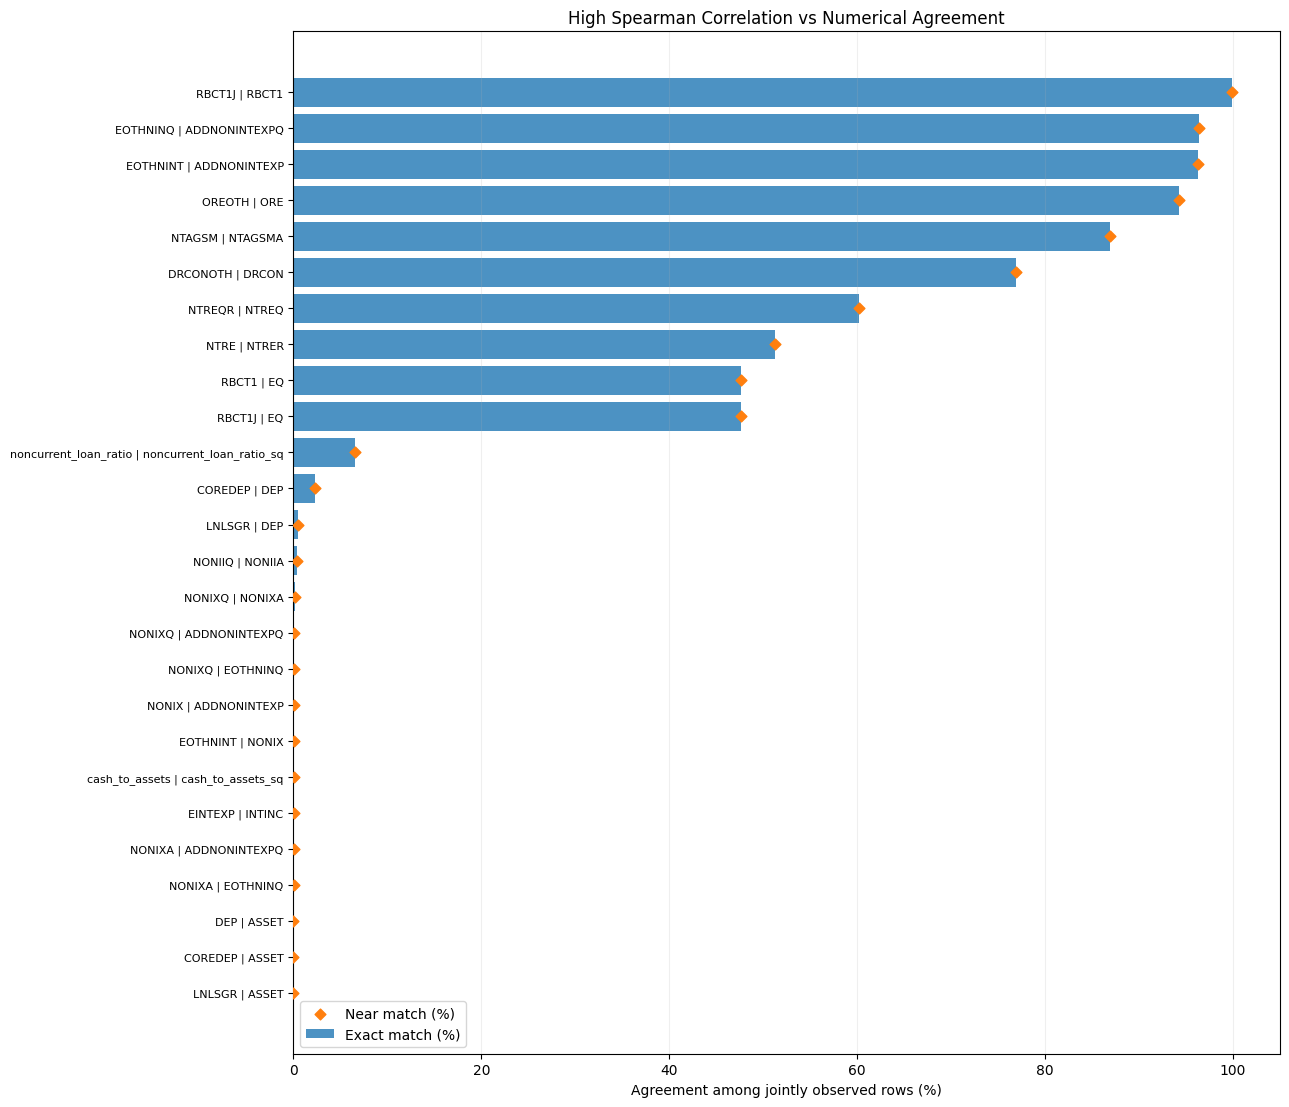

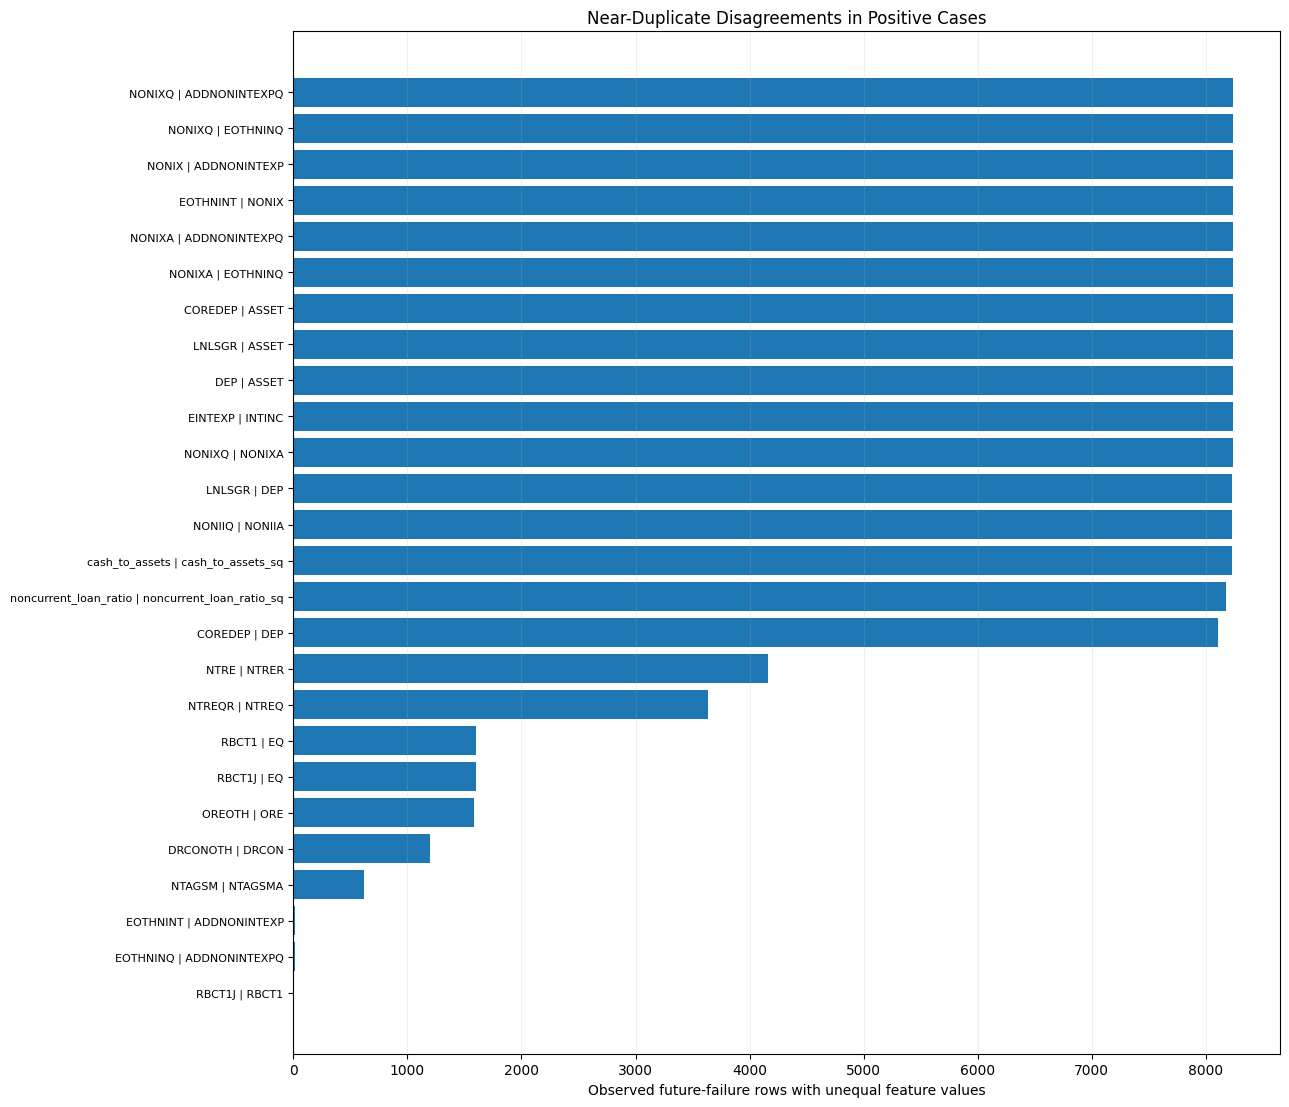


========== 4.9B.5 STATUS ==========
Pairs verified: 26
Candidate predictors retained: 119
Features removed: 0
Models trained: 0


In [333]:

# ============================================================
# PHASE 4 — 4.9B.5: NEAR-DUPLICATE VERIFICATION
# Uses existing sample + 26 high-Spearman pairs
# No imports | No model training | No feature deletion
# ============================================================

assert all(k in globals() for k in [
    "sample", "P4_49B4_HIGH", "np", "pl", "plt"
])

pairs = P4_49B4_HIGH.to_dicts()

needed = sorted(set(
    [r["feature_a"] for r in pairs] +
    [r["feature_b"] for r in pairs]
))

data = sample.select(
    "y_failure_4q_v3", *needed
).to_pandas()

y = data["y_failure_4q_v3"].to_numpy()

rows = []

for p in pairs:
    a, b = p["feature_a"], p["feature_b"]

    xa = data[a].to_numpy(dtype=float)
    xb = data[b].to_numpy(dtype=float)

    valid = np.isfinite(xa) & np.isfinite(xb)

    va = xa[valid]
    vb = xb[valid]
    vy = y[valid]

    n = len(va)

    if n == 0:
        continue

    exact = va == vb

    near = np.isclose(
        va, vb,
        rtol=1e-6,
        atol=1e-8,
        equal_nan=False
    )

    absdiff = np.abs(va - vb)

    rows.append({
        "feature_a": a,
        "feature_b": b,
        "spearman": p["spearman_full"],
        "n_joint": n,
        "coverage_pct": 100 * n / len(data),
        "exact_match_pct": 100 * exact.mean(),
        "near_match_pct": 100 * near.mean(),
        "different_rows": int((~near).sum()),
        "different_positive_rows": int(
            ((~near) & (vy == 1)).sum()
        ),
        "median_abs_difference_nonmatch": (
            float(np.median(absdiff[~near]))
            if (~near).any() else 0.0
        ),
        "max_abs_difference": float(
            np.max(absdiff)
        )
    })

P4_49B5_AGREEMENT = (
    pl.DataFrame(rows)
    .sort("exact_match_pct", descending=True)
)

print("========== ALL 26 PAIRS: VALUE AGREEMENT ==========")

with pl.Config(
    tbl_rows=-1,
    tbl_cols=-1,
    fmt_str_lengths=80,
    tbl_width_chars=240
):
    display(P4_49B5_AGREEMENT)

# ------------------------------------------------------------
# Chart 1: Agreement versus high Spearman correlation
# ------------------------------------------------------------

chart = P4_49B5_AGREEMENT.to_dicts()

labels = [
    r["feature_a"] + " | " + r["feature_b"]
    for r in chart
]

pos = np.arange(len(chart))

fig, ax = plt.subplots(
    figsize=(13, max(8, len(chart) * 0.43))
)

ax.barh(
    pos,
    [r["exact_match_pct"] for r in chart],
    label="Exact match (%)",
    alpha=0.8
)

ax.scatter(
    [r["near_match_pct"] for r in chart],
    pos,
    marker="D",
    s=30,
    label="Near match (%)",
    zorder=3
)

ax.set_yticks(pos)
ax.set_yticklabels(labels, fontsize=8)
ax.invert_yaxis()
ax.set_xlim(0, 105)

ax.set_xlabel("Agreement among jointly observed rows (%)")
ax.set_title(
    "High Spearman Correlation vs Numerical Agreement"
)

ax.legend()
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Chart 2: Disagreements among future-failure cases
# ------------------------------------------------------------

ordered = sorted(
    chart,
    key=lambda r: r["different_positive_rows"],
    reverse=True
)

fig, ax = plt.subplots(
    figsize=(13, max(8, len(ordered) * 0.43))
)

ax.barh(
    range(len(ordered)),
    [r["different_positive_rows"] for r in ordered]
)

ax.set_yticks(range(len(ordered)))
ax.set_yticklabels([
    r["feature_a"] + " | " + r["feature_b"]
    for r in ordered
], fontsize=8)

ax.invert_yaxis()
ax.set_xlabel(
    "Observed future-failure rows with unequal feature values"
)
ax.set_title(
    "Near-Duplicate Disagreements in Positive Cases"
)
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

print("\n========== 4.9B.5 STATUS ==========")
print("Pairs verified:", P4_49B5_AGREEMENT.height)
print("Candidate predictors retained: 119")
print("Features removed: 0")
print("Models trained: 0")


#### Quyết định thử nghiệm | Reduced diagnostic pool

Ba predictors từng được tạm loại khỏi **reduced comparator** (`RBCT1J`, `noncurrent_loan_ratio_sq`, `cash_to_assets_sq`) để kiểm tra sensitivity. **Không xóa khỏi historical core hoặc data source**; việc chọn Final Top 40 được quyết định bằng training-only gain ranking.

In [334]:

# ============================================================
# PHASE 4 — 4.9B.5: REDUNDANCY REDUCTION
# 119 -> 116 candidate predictors
# Preserve 119-feature baseline for comparison
# ============================================================

assert all(k in globals() for k in [
    "P4_48E_FIELDS",
    "P4_48E_PIPELINES",
    "P4_49B_CORE",
    "P4_49B4_PAIRS",
    "P4_49B4_AGREEMENT",
    "pl"
])

# 1. Explicit removal decisions
P4_49B5_DROP = [
    "noncurrent_loan_ratio_sq",
    "cash_to_assets_sq",
    "RBCT1J"
]

P4_49B5_KEEP = {
    "noncurrent_loan_ratio_sq": "noncurrent_loan_ratio",
    "cash_to_assets_sq": "cash_to_assets",
    "RBCT1J": "RBCT1"
}

original_fields = list(P4_48E_FIELDS)

assert len(original_fields) == 119
assert set(P4_49B5_DROP).issubset(original_fields)
assert set(P4_49B5_KEEP.values()).issubset(original_fields)

# 2. Reduced inventory
P4_49B5_FIELDS = [
    f for f in original_fields
    if f not in P4_49B5_DROP
]

P4_49B5_CORE = [
    f for f in P4_49B_CORE
    if f not in P4_49B5_DROP
]

assert len(P4_49B5_FIELDS) == 116
assert len(P4_49B5_CORE) == 110

# 3. Decision log with observed evidence
P4_49B5_DECISIONS = pl.DataFrame([
    {
        "removed": "noncurrent_loan_ratio_sq",
        "retained": "noncurrent_loan_ratio",
        "reason": "Spearman=1; deterministic square",
        "scope": "Reduced tree-based pool"
    },
    {
        "removed": "cash_to_assets_sq",
        "retained": "cash_to_assets",
        "reason": "Spearman=1; deterministic square",
        "scope": "Reduced tree-based pool"
    },
    {
        "removed": "RBCT1J",
        "retained": "RBCT1",
        "reason": "Spearman≈1; 99.8802% exact agreement",
        "scope": "Reduced candidate pool"
    }
])

# 4. Reuse six existing pipelines, selecting 116 columns
# Keep all metadata, identifiers and target unchanged.

P4_49B5_PIPELINES = {}

for split, variants in P4_48E_PIPELINES.items():

    P4_49B5_PIPELINES[split] = {}

    for variant_name, lf in variants.items():

        P4_49B5_PIPELINES[split][variant_name] = (
            lf.drop(P4_49B5_DROP)
        )

        assert set(P4_49B5_DROP).isdisjoint(
            P4_49B5_PIPELINES[split][variant_name]
            .collect_schema().names()
        )

# 5. Results
print("========== REDUNDANCY REDUCTION ==========")
display(P4_49B5_DECISIONS)

print("\nOriginal predictors:", len(original_fields))
print("Reduced predictors:", len(P4_49B5_FIELDS))
print("Reduced historical core:", len(P4_49B5_CORE))
print("Uninsured features retained:", 6)

print("\nRemoved:")
for f in P4_49B5_DROP:
    print(f" - {f} -> retain {P4_49B5_KEEP[f]}")

print("\n========== PIPELINE CHECK ==========")
for split, variants in P4_49B5_PIPELINES.items():
    for name, lf in variants.items():
        n_features = sum(
            f in lf.collect_schema().names()
            for f in P4_49B5_FIELDS
        )
        assert n_features == 116
        print(split, name, n_features)

print("\nPASS — 116-feature experimental pool created.")
print("Original 119-feature pool preserved.")
print("No source data modified.")


========== REDUNDANCY REDUCTION ==========


removed,retained,reason,scope
str,str,str,str
"""noncurrent_loan_ratio_sq""","""noncurrent_loan_ratio""","""Spearman=1; deterministic squa…","""Reduced tree-based pool"""
"""cash_to_assets_sq""","""cash_to_assets""","""Spearman=1; deterministic squa…","""Reduced tree-based pool"""
"""RBCT1J""","""RBCT1""","""Spearman≈1; 99.8802% exact agr…","""Reduced candidate pool"""



Original predictors: 119
Reduced predictors: 116
Reduced historical core: 110
Uninsured features retained: 6

Removed:
 - noncurrent_loan_ratio_sq -> retain noncurrent_loan_ratio
 - cash_to_assets_sq -> retain cash_to_assets
 - RBCT1J -> retain RBCT1

========== PIPELINE CHECK ==========
TRAIN A1_native_raw 116
TRAIN A2_imputed_raw 116
TRAIN B1_native_signedlog 116
TRAIN B2_imputed_signedlog 116
TRAIN C1_imputed_raw_scaled 116
TRAIN C2_imputed_signedlog_scaled 116
CRISIS_TEST A1_native_raw 116
CRISIS_TEST A2_imputed_raw 116
CRISIS_TEST B1_native_signedlog 116
CRISIS_TEST B2_imputed_signedlog 116
CRISIS_TEST C1_imputed_raw_scaled 116
CRISIS_TEST C2_imputed_signedlog_scaled 116
RECENT_OOT A1_native_raw 116
RECENT_OOT A2_imputed_raw 116
RECENT_OOT B1_native_signedlog 116
RECENT_OOT B2_imputed_signedlog 116
RECENT_OOT C1_imputed_raw_scaled 116
RECENT_OOT C2_imputed_signedlog_scaled 116

PASS — 116-feature experimental pool created.
Original 119-feature pool preserved.
No source data modif

<a id="p4-49c"></a>

### 4.9C | Mutual Information diagnostics  `[SECTION]`

Đọc MI trong bối cảnh class imbalance và báo cáo biến động theo thời gian.

#### 4.9C.1 | Nonlinear relevance bằng discretized MI

Dùng quantile-binned mutual information (MI) để rà soát quan hệ phi tuyến giữa predictors và `y_failure_4q_v3`. Đây là thước đo **phụ thuộc thống kê**, không phải MIC và không thể đọc như effect size hay quan hệ nhân quả.

**`[RUN]` PHASE 4 — 4.9C.1: NONLINEAR FEATURE RELEVANCE — 2 ô liên tiếp.** Chạy lần lượt từ trên xuống; các bảng/đồ thị của cell gốc được giữ tại ô cuối của nhóm.

In [335]:

# ============================================================
# PHASE 4 — 4.9C.1: NONLINEAR FEATURE RELEVANCE
# Quantile-binned Mutual Information (NOT MIC)
# 110 reduced historical core predictors
# Existing TRAIN diagnostic sample | No model training
# ============================================================

from sklearn.metrics import mutual_info_score

required = [
    "sample", "P4_49B5_CORE",
    "P4_49B_RELEVANCE", "np", "pl", "plt"
]
assert all(k in globals() for k in required), [
    k for k in required if k not in globals()
]

P4_49C1_FIELDS = list(P4_49B5_CORE)
assert len(P4_49C1_FIELDS) == 110

# ------------------------------------------------------------
# 1. Reuse diagnostic sample already in memory
# ------------------------------------------------------------

P4_49C1_DATA = sample.select(
    "REPDTE",
    "y_failure_4q_v3",
    *P4_49C1_FIELDS
)

year = (
    P4_49C1_DATA["REPDTE"]
    .dt.year()
    .to_numpy()
)

y = (
    P4_49C1_DATA["y_failure_4q_v3"]
    .to_numpy()
    .astype(int)
)

period_masks = {
    "FULL": np.ones(len(y), dtype=bool),
    "EARLY_1985_1994": (year >= 1985) & (year <= 1994),
    "LATE_1995_2006": (year >= 1995) & (year <= 2006)
}


# ------------------------------------------------------------
# 2. Empirical MI on observed values
#    Quantile-binned, not continuous MI / MIC
# ------------------------------------------------------------

def p4_49c1_binned_mi(x, target, mask, n_bins=10):

    valid = mask & np.isfinite(x)

    xv = x[valid]
    yv = target[valid]

    n_pos = int(np.sum(yv == 1))
    n_neg = int(np.sum(yv == 0))

    if n_pos < 50 or n_neg < 200:
        return {
            "mi_nats": None,
            "n_observed": len(xv),
            "n_positive": n_pos,
            "n_negative": n_neg,
            "n_bins": 0
        }

    edges = np.unique(
        np.quantile(
            xv,
            np.linspace(0, 1, n_bins + 1)
        )
    )

    if len(edges) < 3:
        # Constant or nearly degenerate observed values.
        # One effective bin means zero information.
        if len(edges) == 1:
            effective_bins = 1
            mi = 0.0
        else:
            bins = np.searchsorted(
                edges[1:-1], xv, side="right"
            )
            effective_bins = len(np.unique(bins))
            mi = float(mutual_info_score(yv, bins))
    else:
        bins = np.searchsorted(
            edges[1:-1], xv, side="right"
        )
        effective_bins = len(np.unique(bins))
        mi = float(mutual_info_score(yv, bins))

    return {
        "mi_nats": mi,
        "n_observed": len(xv),
        "n_positive": n_pos,
        "n_negative": n_neg,
        "n_bins": effective_bins
    }


# ------------------------------------------------------------
# 3. Compute each field across three training periods
# ------------------------------------------------------------

records = []

for f in P4_49C1_FIELDS:

    x = (
        P4_49C1_DATA[f]
        .to_numpy()
        .astype(float)
    )

    for period_name, mask in period_masks.items():

        result = p4_49c1_binned_mi(
            x, y, mask, n_bins=10
        )

        records.append({
            "feature": f,
            "period": period_name,
            **result,
            "coverage_pct": (
                100 * result["n_observed"] / mask.sum()
            )
        })

P4_49C1_RESULTS = pl.DataFrame(records)


========== NONLINEAR RELEVANCE: TOP 30 ==========


feature,mi_full,mi_early,mi_late,coverage_pct,observed_positive,observed_negative,effective_bins,mi_temporal_change,auc_strength
str,f64,f64,f64,f64,i64,i64,i64,f64,f64
"""equity_to_assets""",0.191345,0.239769,0.004803,99.79054,8239,69417,10,-0.234966,0.454656
"""noncurrent_x_profitability""",0.185187,0.231226,0.01047,97.816729,8202,67918,10,-0.220756,0.412316
"""roa_rolling_mean_4q""",0.171593,0.231173,0.007742,98.691836,8211,68590,10,-0.223431,0.443444
"""expense_burden_x_profitability""",0.167721,0.224228,0.007476,98.486231,8211,68430,10,-0.216752,0.436505
"""RBC1AAJ""",0.162957,0.199526,0.004981,100.0,8239,69580,10,-0.194545,0.43417
"""ROA""",0.158246,0.213803,0.007336,100.0,8239,69580,10,-0.206467,0.430933
"""noncurrent_loan_ratio""",0.135672,0.163498,0.007213,99.04008,8227,68845,10,-0.156285,0.411117
"""asset_growth_x_noncurrent""",0.133277,0.173286,0.005224,97.379817,8186,67594,10,-0.168062,0.257665
"""equity_to_assets_sq""",0.132731,0.164837,0.00467,99.79054,8239,69417,10,-0.160167,0.351313



========== LOW UNIVARIATE AUC, HIGH MI ==========


feature,mi_full,mi_early,mi_late,coverage_pct,observed_positive,observed_negative,effective_bins,mi_temporal_change,auc_strength
str,f64,f64,f64,f64,i64,i64,i64,f64,f64
"""LNCDT1R""",0.065712,0.103374,0.002248,92.229404,5952,65820,9,-0.101126,0.028385
"""LNRERT1R""",0.042134,0.07372,0.001486,92.229404,5952,65820,10,-0.072234,0.004065
"""noninterest_expense_growth_4q""",0.024259,0.031796,0.001749,97.88098,8176,67994,10,-0.030048,0.032362
"""capital_x_chargeoff_change""",0.012414,0.009843,0.002172,88.303628,5287,63430,10,-0.007671,0.024678
"""cash_to_assets""",0.010989,0.012457,0.000979,100.0,8239,69580,10,-0.011479,0.043354
…,…,…,…,…,…,…,…,…,…
"""DRAGSM""",0.001728,0.001683,0.0,76.219175,4297,55016,2,-0.001683,0.033059
"""INTINC""",0.00154,0.003272,0.000662,99.79054,8239,69417,10,-0.00261,0.015109
"""NONIIQ""",0.001057,0.004156,0.000699,99.79054,8239,69417,10,-0.003457,0.003579



========== LARGEST MI CHANGES ==========


feature,mi_full,mi_early,mi_late,coverage_pct,observed_positive,observed_negative,effective_bins,mi_temporal_change,auc_strength,__abs_change
str,f64,f64,f64,f64,i64,i64,i64,f64,f64,f64
"""equity_to_assets""",0.191345,0.239769,0.004803,99.79054,8239,69417,10,-0.234966,0.454656,0.234966
"""roa_rolling_mean_4q""",0.171593,0.231173,0.007742,98.691836,8211,68590,10,-0.223431,0.443444,0.223431
"""noncurrent_x_profitability""",0.185187,0.231226,0.01047,97.816729,8202,67918,10,-0.220756,0.412316,0.220756
"""expense_burden_x_profitability""",0.167721,0.224228,0.007476,98.486231,8211,68430,10,-0.216752,0.436505,0.216752
"""ROA""",0.158246,0.213803,0.007336,100.0,8239,69580,10,-0.206467,0.430933,0.206467
…,…,…,…,…,…,…,…,…,…,…
"""IDERNCVR""",0.097513,0.124764,0.007499,100.0,8239,69580,7,-0.117265,0.323429,0.117265
"""asset_growth_4q""",0.089163,0.119813,0.002759,98.230509,8194,68248,10,-0.117054,0.302033,0.117054
"""capital_x_noncurrent""",0.091508,0.107783,0.003877,98.83833,8227,68688,10,-0.103907,0.084251,0.103907


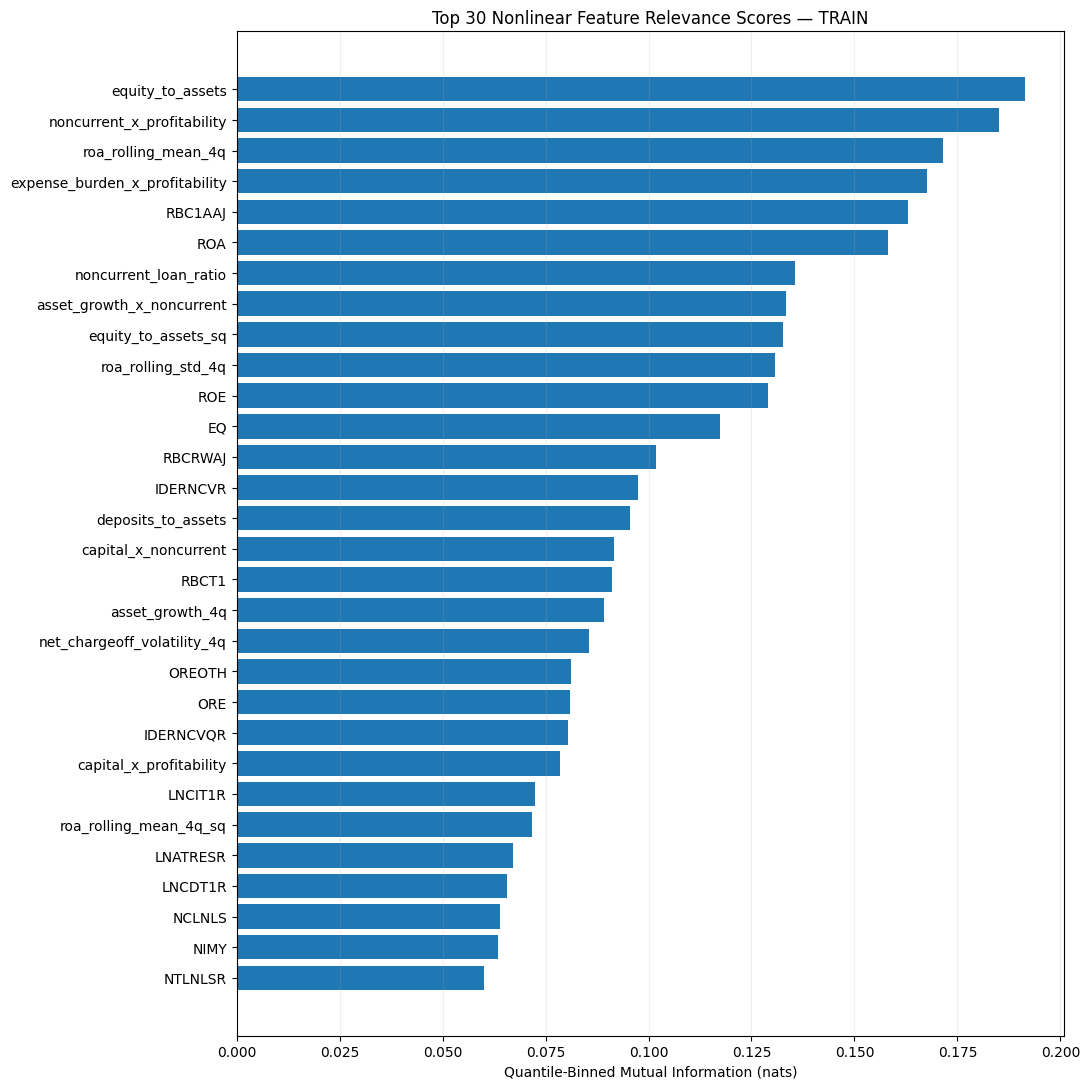

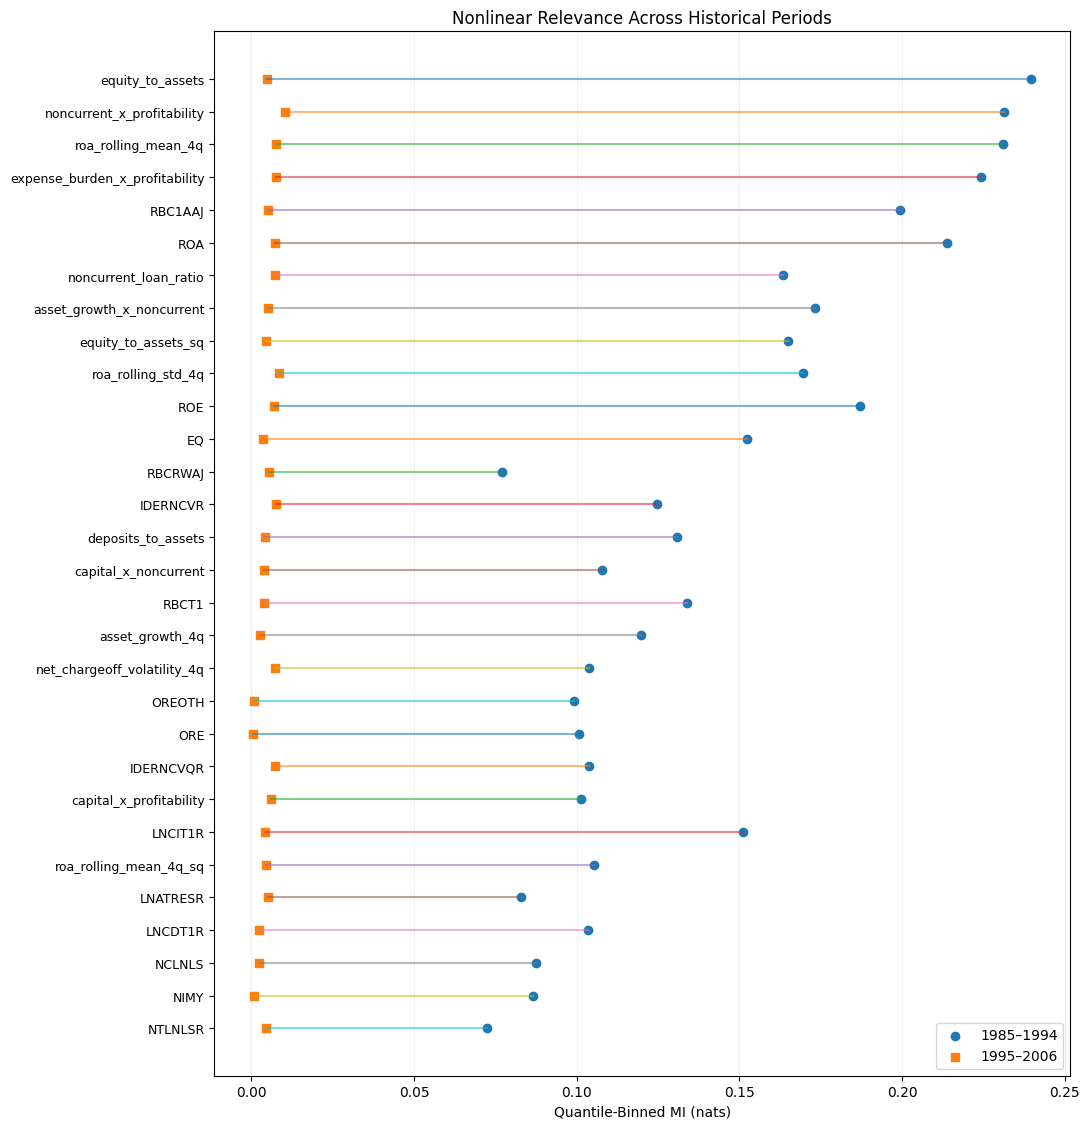


========== 4.9C.1 STATUS ==========
Reduced historical predictors: 110
Period-level records: 330
Original inventory: 119
Reduced inventory: 116
Features removed at this stage: 0
Model training: 0

PASS — Nonlinear relevance diagnostic completed.


In [336]:

# ------------------------------------------------------------
# 4. Build comparison table
# ------------------------------------------------------------

P4_49C1_SUMMARY = (
    P4_49C1_RESULTS
    .group_by("feature")
    .agg(
        pl.col("mi_nats")
        .filter(pl.col("period") == "FULL")
        .first().alias("mi_full"),

        pl.col("mi_nats")
        .filter(pl.col("period") == "EARLY_1985_1994")
        .first().alias("mi_early"),

        pl.col("mi_nats")
        .filter(pl.col("period") == "LATE_1995_2006")
        .first().alias("mi_late"),

        pl.col("coverage_pct")
        .filter(pl.col("period") == "FULL")
        .first().alias("coverage_pct"),

        pl.col("n_positive")
        .filter(pl.col("period") == "FULL")
        .first().alias("observed_positive"),

        pl.col("n_negative")
        .filter(pl.col("period") == "FULL")
        .first().alias("observed_negative"),

        pl.col("n_bins")
        .filter(pl.col("period") == "FULL")
        .first().alias("effective_bins")
    )
    .with_columns(
        (
            pl.col("mi_late") - pl.col("mi_early")
        ).alias("mi_temporal_change")
    )
    .join(
        P4_49B_RELEVANCE.select(
            "feature", "auc_strength"
        ),
        on="feature",
        how="left"
    )
    .sort("mi_full", descending=True, nulls_last=True)
)

assert P4_49C1_SUMMARY.height == 110

print("========== NONLINEAR RELEVANCE: TOP 30 ==========")

with pl.Config(
    tbl_rows=-1,
    tbl_cols=-1,
    fmt_str_lengths=65
):
    display(P4_49C1_SUMMARY.head(30))

print("\n========== LOW UNIVARIATE AUC, HIGH MI ==========")

display(
    P4_49C1_SUMMARY
    .filter(
        pl.col("auc_strength").is_not_null()
        & (pl.col("auc_strength") < 0.05)
    )
    .sort("mi_full", descending=True, nulls_last=True)
    .head(20)
)

print("\n========== LARGEST MI CHANGES ==========")

display(
    P4_49C1_SUMMARY
    .with_columns(
        pl.col("mi_temporal_change")
        .abs().alias("__abs_change")
    )
    .sort("__abs_change", descending=True, nulls_last=True)
    .head(20)
)


# ------------------------------------------------------------
# 5. Chart: Top 30 mutual-information scores
# ------------------------------------------------------------

top = P4_49C1_SUMMARY.head(30)

fig, ax = plt.subplots(figsize=(11, 11))

names = top["feature"].to_list()
values = top["mi_full"].to_list()

ax.barh(names[::-1], values[::-1])

ax.set_title(
    "Top 30 Nonlinear Feature Relevance Scores — TRAIN"
)
ax.set_xlabel(
    "Quantile-Binned Mutual Information (nats)"
)
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. Chart: Early vs Late MI for top 30
# ------------------------------------------------------------

chart = (
    top
    .filter(
        pl.col("mi_early").is_not_null()
        & pl.col("mi_late").is_not_null()
    )
)

names = chart["feature"].to_list()
early = chart["mi_early"].to_numpy()
late = chart["mi_late"].to_numpy()

positions = np.arange(len(names))

fig, ax = plt.subplots(
    figsize=(11, max(7, len(names) * 0.38))
)

ax.scatter(
    early, positions,
    label="1985–1994",
    marker="o"
)

ax.scatter(
    late, positions,
    label="1995–2006",
    marker="s"
)

for i in range(len(positions)):
    ax.plot(
        [early[i], late[i]],
        [positions[i], positions[i]],
        alpha=0.55
    )

ax.set_yticks(positions)
ax.set_yticklabels(names, fontsize=9)
ax.invert_yaxis()

ax.set_title(
    "Nonlinear Relevance Across Historical Periods"
)
ax.set_xlabel("Quantile-Binned MI (nats)")
ax.legend()
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. Status
# ------------------------------------------------------------

print("\n========== 4.9C.1 STATUS ==========")
print("Reduced historical predictors:", len(P4_49C1_FIELDS))
print("Period-level records:", P4_49C1_RESULTS.height)
print("Original inventory:", 119)
print("Reduced inventory:", 116)
print("Features removed at this stage:", 0)
print("Model training:", 0)

print("\nPASS — Nonlinear relevance diagnostic completed.")


#### Diễn giải | Vì sao MI giảm ở giai đoạn sau?

MI thấp trong 1995–2006 có thể xuất phát từ **tỷ lệ nhãn positive thấp**, không nhất thiết do features mất tác dụng. So sánh MI khi class balance khác nhau là không trực tiếp tương đương; cần thí nghiệm cân bằng prevalence ở bước sau.

#### 4.9C.2 | Kiểm soát class prevalence khi so MI

Với nhãn nhị phân: \(I(X;Y) \le H(Y)\). Khi tỷ lệ failure thấp, **entropy của nhãn giảm**, kéo trần MI xuống.

Cách kiểm tra: tạo case-control sample **1:1** trong mỗi giai đoạn TRAIN, tính lại MI với cùng quy tắc discretization. Đây là chẩn đoán, **không tái tạo failure prevalence thật** và không thay thế wrapper evaluation.

**`[RUN]` PHASE 4 — 4.9C.2: PREVALENCE-CONTROLLED MI AUDIT — 3 ô liên tiếp.** Chạy lần lượt từ trên xuống; các bảng/đồ thị của cell gốc được giữ tại ô cuối của nhóm.

In [337]:

# ============================================================
# PHASE 4 — 4.9C.2: PREVALENCE-CONTROLLED MI AUDIT
# 110 core features | Existing diagnostic sample
# No imports | No models | No feature deletion
# ============================================================

assert all(k in globals() for k in [
    "sample", "P4_49B5_CORE",
    "P4_49C1_SUMMARY", "np", "pl",
    "plt", "mutual_info_score"
])

fields = list(P4_49B5_CORE)
assert len(fields) == 110

y = sample["y_failure_4q_v3"].to_numpy().astype(int)
years = sample["REPDTE"].dt.year().to_numpy()

period_masks = {
    "FULL": np.ones(len(y), dtype=bool),
    "EARLY_1985_1994": (years >= 1985) & (years <= 1994),
    "LATE_1995_2006": (years >= 1995) & (years <= 2006)
}

def p4_49c2_entropy(binary_y):
    if len(binary_y) == 0:
        return float("nan")
    p = float(np.mean(binary_y == 1))
    if p <= 0 or p >= 1:
        return 0.0
    return float(
        -p * np.log(p) - (1 - p) * np.log(1 - p)
    )

# ------------------------------------------------------------
# 1. Diagnose the original class distribution
# ------------------------------------------------------------

prevalence_rows = []

for period, mask in period_masks.items():
    yp = y[mask]
    n_pos = int((yp == 1).sum())
    n_neg = int((yp == 0).sum())

    prevalence_rows.append({
        "period": period,
        "rows": len(yp),
        "positives": n_pos,
        "negatives": n_neg,
        "positive_pct": 100 * n_pos / len(yp),
        "label_entropy_nats": p4_49c2_entropy(yp)
    })

P4_49C2_PREVALENCE = pl.DataFrame(prevalence_rows)

print("========== ORIGINAL SAMPLE: PREVALENCE & ENTROPY ==========")
display(P4_49C2_PREVALENCE)

# ------------------------------------------------------------
# 2. Balanced case-control sample per period
# Fixed random state for reproducibility
# ------------------------------------------------------------

balanced_indices = {}
balanced_rows = []

for k, (period, mask) in enumerate(period_masks.items()):

    pos = np.flatnonzero(mask & (y == 1))
    neg = np.flatnonzero(mask & (y == 0))

    n_each = min(len(pos), len(neg))
    assert n_each >= 30, (
        f"Insufficient class support: {period}"
    )

    rng = np.random.default_rng(4902 + k)

    pos_selected = rng.choice(
        pos, size=n_each, replace=False
    )
    neg_selected = rng.choice(
        neg, size=n_each, replace=False
    )

    idx = np.sort(
        np.concatenate([pos_selected, neg_selected])
    )

    balanced_indices[period] = idx

    balanced_rows.append({
        "period": period,
        "rows": len(idx),
        "positives": n_each,
        "negatives": n_each,
        "positive_pct": 50.0,
        "label_entropy_nats": p4_49c2_entropy(y[idx])
    })

P4_49C2_BALANCE = pl.DataFrame(balanced_rows)

print("\n========== BALANCED DIAGNOSTIC SAMPLES ==========")
display(P4_49C2_BALANCE)

# ------------------------------------------------------------
# 3. Binned MI and observed-class support
# Re-bin within the selected sample; missing excluded
# ------------------------------------------------------------

def p4_49c2_mi(x, target, selected_idx, n_bins=10):

    xv = x[selected_idx]
    yv = target[selected_idx]

    valid = np.isfinite(xv)

    xv = xv[valid]
    yv = yv[valid]

    npos = int((yv == 1).sum())
    nneg = int((yv == 0).sum())

    if npos < 30 or nneg < 30:
        return None, npos, nneg, 0

    edges = np.unique(
        np.quantile(
            xv, np.linspace(0, 1, n_bins + 1)
        )
    )

    if len(edges) == 1:
        return 0.0, npos, nneg, 1

    bins = np.searchsorted(
        edges[1:-1], xv, side="right"
    )

    effective_bins = int(np.unique(bins).size)

    if effective_bins < 2:
        return 0.0, npos, nneg, effective_bins

    score = float(mutual_info_score(yv, bins))

    return score, npos, nneg, effective_bins


========== ORIGINAL SAMPLE: PREVALENCE & ENTROPY ==========


period,rows,positives,negatives,positive_pct,label_entropy_nats
str,i64,i64,i64,f64,f64
"""FULL""",77819,8239,69580,10.587389,0.337801
"""EARLY_1985_1994""",46932,8049,38883,17.150345,0.458262
"""LATE_1995_2006""",30887,190,30697,0.615146,0.03745



========== BALANCED DIAGNOSTIC SAMPLES ==========


period,rows,positives,negatives,positive_pct,label_entropy_nats
str,i64,i64,i64,f64,f64
"""FULL""",16478,8239,8239,50.0,0.693147
"""EARLY_1985_1994""",16098,8049,8049,50.0,0.693147
"""LATE_1995_2006""",380,190,190,50.0,0.693147



========== TOP 30: BALANCED MI ==========


feature,mi_balanced_full,mi_balanced_early,mi_balanced_late,mi_full,mi_early,mi_late,auc_strength,balanced_temporal_change
str,f64,f64,f64,f64,f64,f64,f64,f64
"""equity_to_assets""",0.425631,0.391639,0.203855,0.191345,0.239769,0.004803,0.454656,-0.187783
"""noncurrent_x_profitability""",0.403513,0.372666,0.310562,0.185187,0.231226,0.01047,0.412316,-0.062104
"""RBC1AAJ""",0.399206,0.358201,0.201001,0.162957,0.199526,0.004981,0.43417,-0.1572
"""roa_rolling_mean_4q""",0.398141,0.379673,0.302402,0.171593,0.231173,0.007742,0.443444,-0.077271
"""expense_burden_x_profitability""",0.391847,0.371002,0.29728,0.167721,0.224228,0.007476,0.436505,-0.073721
"""ROA""",0.370905,0.351391,0.320153,0.158246,0.213803,0.007336,0.430933,-0.031238
"""ROE""",0.361672,0.347967,0.337443,0.128927,0.187044,0.00707,0.390573,-0.010524
"""noncurrent_loan_ratio""",0.316594,0.261699,0.271319,0.135672,0.163498,0.007213,0.411117,0.00962
"""roa_rolling_std_4q""",0.311648,0.284821,0.351401,0.130611,0.169716,0.008505,0.41142,0.06658



========== LARGEST BALANCED MI CHANGES ==========


feature,mi_balanced_full,mi_balanced_early,mi_balanced_late,mi_full,mi_early,mi_late,auc_strength,balanced_temporal_change,abs_change
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""equity_to_assets""",0.425631,0.391639,0.203855,0.191345,0.239769,0.004803,0.454656,-0.187783,0.187783
"""noninterest_expense_to_assets""",0.072925,0.066442,0.23647,0.031141,0.039866,0.005822,0.176787,0.170029,0.170029
"""RBC1AAJ""",0.399206,0.358201,0.201001,0.162957,0.199526,0.004981,0.43417,-0.1572,0.1572
"""ORE""",0.201415,0.16974,0.019531,0.080987,0.100831,0.000602,0.338989,-0.150209,0.150209
"""OREOTH""",0.198685,0.166858,0.021414,0.081175,0.09925,0.000696,0.332805,-0.145444,0.145444
"""LNCDT1R""",0.154467,0.176746,0.062539,0.065712,0.103374,0.002248,0.028385,-0.114207,0.114207
"""NTLNLSR""",0.145251,0.119003,0.220928,0.060168,0.072304,0.004619,0.162573,0.101925,0.101925
"""RBCRWAJ""",0.249991,0.152683,0.251553,0.101821,0.077133,0.005482,0.320464,0.098871,0.098871
"""LNRERT1R""",0.177365,0.175163,0.080345,0.042134,0.07372,0.001486,0.004065,-0.094818,0.094818


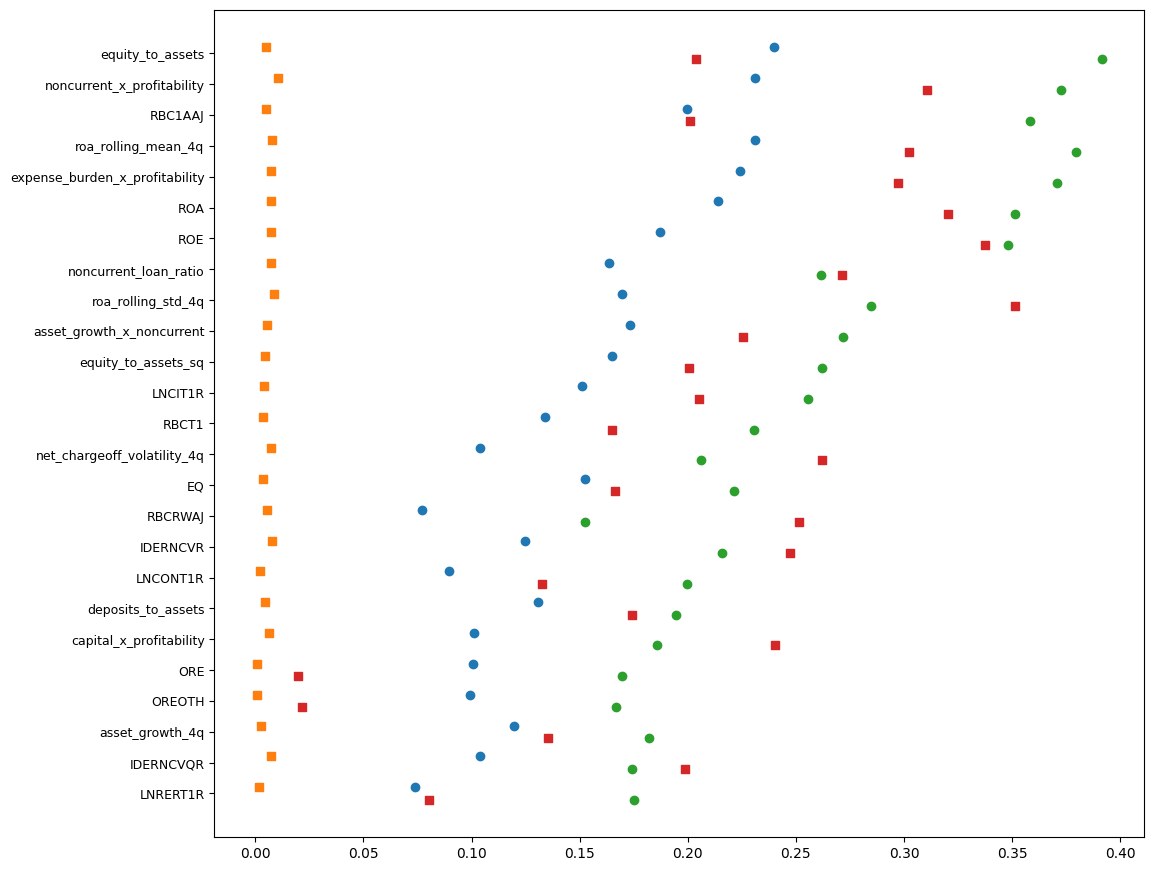

In [338]:


records = []

for f in fields:

    x = sample[f].to_numpy().astype(float)

    for period, idx in balanced_indices.items():

        mi, npos, nneg, nbins = p4_49c2_mi(
            x, y, idx
        )

        records.append({
            "feature": f,
            "period": period,
            "balanced_mi": mi,
            "observed_positive": npos,
            "observed_negative": nneg,
            "effective_bins": nbins
        })

P4_49C2_RESULTS = pl.DataFrame(records)

# ------------------------------------------------------------
# 4. Join previous MI results for comparison
# ------------------------------------------------------------

P4_49C2_SUMMARY = (
    P4_49C2_RESULTS
    .group_by("feature")
    .agg(
        *[
            pl.col("balanced_mi")
            .filter(pl.col("period") == p)
            .first()
            .alias(alias)
            for p, alias in [
                ("FULL", "mi_balanced_full"),
                ("EARLY_1985_1994", "mi_balanced_early"),
                ("LATE_1995_2006", "mi_balanced_late")
            ]
        ]
    )
    .join(
        P4_49C1_SUMMARY.select(
            "feature",
            "mi_full",
            "mi_early",
            "mi_late",
            "auc_strength"
        ),
        on="feature",
        how="left"
    )
    .with_columns(
        (
            pl.col("mi_balanced_late")
            - pl.col("mi_balanced_early")
        ).alias("balanced_temporal_change")
    )
    .sort(
        "mi_balanced_full",
        descending=True,
        nulls_last=True
    )
)

assert P4_49C2_SUMMARY.height == 110

# ------------------------------------------------------------
# 5. Display full results without ellipses
# ------------------------------------------------------------

print("\n========== TOP 30: BALANCED MI ==========")

with pl.Config(
    tbl_rows=-1,
    tbl_cols=-1,
    fmt_str_lengths=65,
    tbl_width_chars=240
):
    display(P4_49C2_SUMMARY.head(30))

print("\n========== LARGEST BALANCED MI CHANGES ==========")

with pl.Config(tbl_rows=-1, tbl_cols=-1):
    display(
        P4_49C2_SUMMARY
        .with_columns(
            pl.col("balanced_temporal_change")
            .abs().alias("abs_change")
        )
        .sort(
            "abs_change",
            descending=True,
            nulls_last=True
        )
        .head(20)
    )

# ------------------------------------------------------------
# 6. Comparison chart: Original vs balanced MI
# ------------------------------------------------------------

top = P4_49C2_SUMMARY.head(25)

names = top["feature"].to_list()
pos = np.arange(len(names))

fig, ax = plt.subplots(
    figsize=(12, max(8, len(names) * 0.43))
)

ax.scatter(
    top["mi_early"].to_numpy(),
    pos - 0.2,
    marker="o",
    label="Early — original sample"
)

ax.scatter(
    top["mi_late"].to_numpy(),
    pos - 0.2,
    marker="s",
    label="Late — original sample"
)

ax.scatter(
    top["mi_balanced_early"].to_numpy(),
    pos + 0.2,
    marker="o",
    label="Early — balanced"
)

ax.scatter(
    top["mi_balanced_late"].to_numpy(),
    pos + 0.2,
    marker="s",
    label="Late — balanced"
)

ax.set_yticks(pos)
ax.set_yticklabels(names, fontsize=9)
ax.invert_yaxis()


<Figure size 640x480 with 0 Axes>

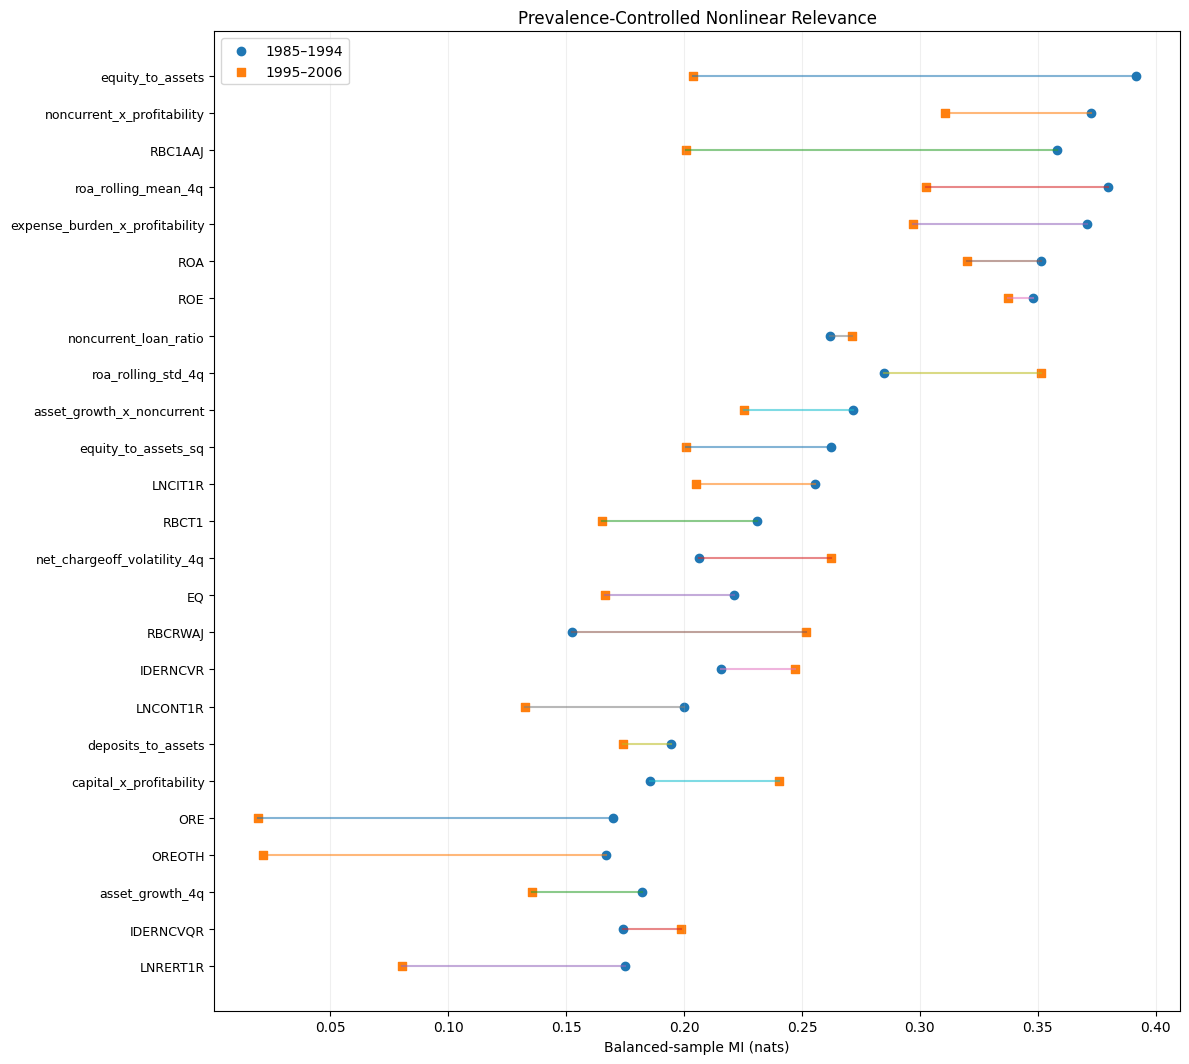


========== 4.9C.2 STATUS ==========
Features assessed: 110
Period-feature results: 330
Original pool: 119
Reduced pool: 116
Permanently removed: 0
Models trained: 0

PASS — Prevalence-controlled MI diagnostic completed.


In [339]:

ax.set_xlabel("Quantile-binned Mutual Information (nats)")
ax.set_title(
    "Original vs Prevalence-Controlled MI — Top 25"
)
ax.grid(axis="x", alpha=0.2)
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Additional chart: balanced early vs late
# ------------------------------------------------------------

early = top["mi_balanced_early"].to_numpy()
late = top["mi_balanced_late"].to_numpy()

fig, ax = plt.subplots(
    figsize=(12, max(8, len(names) * 0.43))
)

for i in range(len(names)):
    if np.isfinite(early[i]) and np.isfinite(late[i]):
        ax.plot(
            [early[i], late[i]],
            [i, i],
            alpha=0.55
        )

ax.scatter(
    early, pos,
    marker="o",
    label="1985–1994"
)

ax.scatter(
    late, pos,
    marker="s",
    label="1995–2006"
)

ax.set_yticks(pos)
ax.set_yticklabels(names, fontsize=9)
ax.invert_yaxis()

ax.set_xlabel("Balanced-sample MI (nats)")
ax.set_title(
    "Prevalence-Controlled Nonlinear Relevance"
)
ax.legend()
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

print("\n========== 4.9C.2 STATUS ==========")
print("Features assessed:", len(fields))
print("Period-feature results:", P4_49C2_RESULTS.height)
print("Original pool: 119")
print("Reduced pool: 116")
print("Permanently removed: 0")
print("Models trained: 0")

print("\nPASS — Prevalence-controlled MI diagnostic completed.")


#### Kết quả | Balanced MI

Trong mẫu chẩn đoán, tỷ lệ positive giảm từ **17,15%** (1985–1994) xuống **0,62%** (1995–2006); label entropy giảm từ **0,4583 xuống 0,0375 nats**. Sau cân bằng 1:1, nhiều MI tăng trở lại.

**Giới hạn:** giai đoạn sau chỉ có **190 positives và 190 negatives**; kết quả dễ dao động và không đủ để khẳng định predictors hoạt động tốt hơn. Vì vậy không dùng MI để chốt danh sách cuối.

<a id="p4-49d"></a>

### 4.9D | Historical folds và baseline models  `[SECTION]`

Đánh giá hỗ trợ positive-bank theo fold, sau đó fit baseline với bộ nhớ được kiểm soát.

#### 4.9D.1 | Expanding-window validation feasibility

Thiết kế các folds theo thời gian trong TRAIN, cách một năm purge trước validation. **Lịch folds này là thiết kế phát triển mô hình**, chưa đồng nghĩa đã xác nhận hoàn toàn với Phase 2.

Các folds có số failures ít cần được diễn giải cẩn trọng; không dùng external test trong bất kỳ bước lựa chọn nào.

In [340]:

# ============================================================
# PHASE 4 — 4.9D.1: EXPANDING CV FEASIBILITY
# TRAIN 1985–2006 | No model training
# Reuse existing Phase 4 TRAIN LazyFrame
# ============================================================

assert all(k in globals() for k in [
    "P4_48C_TRAIN", "pl"
])

P4_49D1_FOLDS = [
    {
        "fold": "F1",
        "train_start": 1985,
        "train_end": 1990,
        "purge_year": 1991,
        "val_start": 1992,
        "val_end": 1994
    },
    {
        "fold": "F2",
        "train_start": 1985,
        "train_end": 1994,
        "purge_year": 1995,
        "val_start": 1996,
        "val_end": 1998
    },
    {
        "fold": "F3",
        "train_start": 1985,
        "train_end": 1998,
        "purge_year": 1999,
        "val_start": 2000,
        "val_end": 2002
    },
    {
        "fold": "F4",
        "train_start": 1985,
        "train_end": 2002,
        "purge_year": 2003,
        "val_start": 2004,
        "val_end": 2006
    }
]

# Aggregate once, not separately for each fold.
P4_49D1_YEARLY = (
    P4_48C_TRAIN
    .group_by("__year")
    .agg(
        pl.len().alias("rows"),
        pl.col("y_failure_4q_v3")
          .sum().alias("positives"),
        pl.col("CERT")
          .n_unique().alias("banks")
    )
    .sort("__year")
    .collect()
)

P4_49D1_COUNTS = []

for fold in P4_49D1_FOLDS:

    for role, start, end in [
        (
            "TRAIN",
            fold["train_start"],
            fold["train_end"]
        ),
        (
            "PURGE",
            fold["purge_year"],
            fold["purge_year"]
        ),
        (
            "VALIDATION",
            fold["val_start"],
            fold["val_end"]
        )
    ]:

        sub = P4_49D1_YEARLY.filter(
            pl.col("__year").is_between(start, end)
        )

        n_rows = int(sub["rows"].sum())
        n_pos = int(sub["positives"].sum())
        n_neg = n_rows - n_pos

        P4_49D1_COUNTS.append({
            "fold": fold["fold"],
            "role": role,
            "years": f"{start}-{end}",
            "rows": n_rows,
            "positives": n_pos,
            "negatives": n_neg,
            "failure_rate_pct": (
                100 * n_pos / n_rows if n_rows else None
            ),
            "class_support": (
                "SUFFICIENT"
                if n_pos >= 20 and n_neg >= 100
                else "LOW_SUPPORT"
            )
        })

P4_49D1_FEASIBILITY = pl.DataFrame(
    P4_49D1_COUNTS
)

print("========== HISTORICAL TRAINING & VALIDATION SUPPORT ==========")

with pl.Config(
    tbl_rows=-1,
    tbl_cols=-1,
    fmt_str_lengths=60
):
    display(P4_49D1_FEASIBILITY)

print("\n========== VALIDATION FOLD ELIGIBILITY ==========")

P4_49D1_VALIDATION = (
    P4_49D1_FEASIBILITY
    .filter(pl.col("role") == "VALIDATION")
)

display(P4_49D1_VALIDATION)

print("\n========== EVENT DISTRIBUTION BY YEAR ==========")

display(P4_49D1_YEARLY)

print("\nSTATUS — Fold feasibility assessed.")
print("Candidate folds:", len(P4_49D1_FOLDS))
print("Original predictors:", 119)
print("Reduced predictors:", 116)
print("Models trained:", 0)


========== HISTORICAL TRAINING & VALIDATION SUPPORT ==========


fold,role,years,rows,positives,negatives,failure_rate_pct,class_support
str,str,str,i64,i64,i64,f64,str
"""F1""","""TRAIN""","""1985-1990""",409287,6761,402526,1.651897,"""SUFFICIENT"""
"""F1""","""PURGE""","""1991-1991""",59921,777,59144,1.296707,"""SUFFICIENT"""
"""F1""","""VALIDATION""","""1992-1994""",163353,511,162842,0.312819,"""SUFFICIENT"""
"""F2""","""TRAIN""","""1985-1994""",632561,8049,624512,1.272446,"""SUFFICIENT"""
"""F2""","""PURGE""","""1995-1995""",49100,22,49078,0.044807,"""SUFFICIENT"""
"""F2""","""VALIDATION""","""1996-1998""",134946,38,134908,0.028159,"""SUFFICIENT"""
"""F3""","""TRAIN""","""1985-1998""",816607,8109,808498,0.993011,"""SUFFICIENT"""
"""F3""","""PURGE""","""1999-1999""",41701,28,41673,0.067145,"""SUFFICIENT"""
"""F3""","""VALIDATION""","""2000-2002""",118187,76,118111,0.064305,"""SUFFICIENT"""



========== VALIDATION FOLD ELIGIBILITY ==========


fold,role,years,rows,positives,negatives,failure_rate_pct,class_support
str,str,str,i64,i64,i64,f64,str
"""F1""","""VALIDATION""","""1992-1994""",163353,511,162842,0.312819,"""SUFFICIENT"""
"""F2""","""VALIDATION""","""1996-1998""",134946,38,134908,0.028159,"""SUFFICIENT"""
"""F3""","""VALIDATION""","""2000-2002""",118187,76,118111,0.064305,"""SUFFICIENT"""
"""F4""","""VALIDATION""","""2004-2006""",107959,7,107952,0.006484,"""LOW_SUPPORT"""



========== EVENT DISTRIBUTION BY YEAR ==========


__year,rows,positives,banks
i32,u32,i64,u32
1985,71913,555,18497
1986,72131,776,18393
1987,70363,832,18042
1988,67689,1862,17462
1989,64685,1578,16626
…,…,…,…
2002,38204,18,9712
2003,37447,19,9526
2004,36637,1,9333



STATUS — Fold feasibility assessed.
Candidate folds: 4
Original predictors: 119
Reduced predictors: 116
Models trained: 0


#### Kết quả | Hỗ trợ positive theo fold

| Fold | Validation | Positive bank-quarters | Đánh giá |
|---|---|---:|---|
| F1 | 1992–1994 | 511 | Có thể dùng cho phát triển mô hình |
| F2 | 1996–1998 | 38 | Ít positives; bất định lớn |
| F3 | 2000–2002 | 76 | Ít positives; bất định lớn |
| F4 | 2004–2006 | 7 | Không dùng để tối ưu subset |

**Lưu ý:** 511 positive bank-quarters không phải 511 sự kiện thất bại độc lập; cần thêm thống kê distinct positive banks.

#### 4.9D.2 | Distinct-positive-bank support

Một ngân hàng có thể đóng góp nhiều quý mang nhãn 1 trong horizon bốn quý. Vì vậy báo cáo thêm **số `CERT` khác nhau có ít nhất một nhãn positive**, song song với bank-quarter metrics.

Distinct positive `CERT` chỉ là **proxy cho số banks liên quan failure**, chưa phải sự kiện thất bại độc lập đã đối chiếu bảng FDIC failure events.

========== DISTINCT POSITIVE BANK SUPPORT ==========


fold,role,years,positive_bank_quarters,distinct_positive_banks,quarters_per_bank,max_positive_quarters_per_bank,event_support
str,str,str,i64,i64,f64,i64,str
"""F1""","""TRAIN""","""1985-1990""",6761,1895,3.568,4,"""ADEQUATE_FOR_INITIAL_EVALUATION"""
"""F1""","""PURGE""","""1991-1991""",777,363,2.14,4,"""ADEQUATE_FOR_INITIAL_EVALUATION"""
"""F1""","""VALIDATION""","""1992-1994""",511,194,2.634,4,"""ADEQUATE_FOR_INITIAL_EVALUATION"""
"""F2""","""TRAIN""","""1985-1994""",8049,2147,3.749,4,"""ADEQUATE_FOR_INITIAL_EVALUATION"""
"""F2""","""PURGE""","""1995-1995""",22,11,2.0,4,"""LOW"""
"""F2""","""VALIDATION""","""1996-1998""",38,17,2.235,4,"""LOW"""
"""F3""","""TRAIN""","""1985-1998""",8109,2165,3.745,4,"""ADEQUATE_FOR_INITIAL_EVALUATION"""
"""F3""","""PURGE""","""1999-1999""",28,13,2.154,4,"""LOW"""
"""F3""","""VALIDATION""","""2000-2002""",76,23,3.304,4,"""LIMITED"""



========== VALIDATION EVENT SUPPORT ==========


fold,role,years,positive_bank_quarters,distinct_positive_banks,quarters_per_bank,max_positive_quarters_per_bank,event_support
str,str,str,i64,i64,f64,i64,str
"""F1""","""VALIDATION""","""1992-1994""",511,194,2.634,4,"""ADEQUATE_FOR_INITIAL_EVALUATIO…"
"""F2""","""VALIDATION""","""1996-1998""",38,17,2.235,4,"""LOW"""
"""F3""","""VALIDATION""","""2000-2002""",76,23,3.304,4,"""LIMITED"""
"""F4""","""VALIDATION""","""2004-2006""",7,4,1.75,3,"""LOW"""



========== ANNUAL DISTINCT POSITIVE BANKS ==========


__year,positive_bank_quarters,distinct_positive_banks
i32,u32,u32
1985,555,271
1986,776,332
1987,832,380
1988,1862,698
1989,1578,660
1990,1158,517
1991,777,363
1992,380,171
1993,85,49


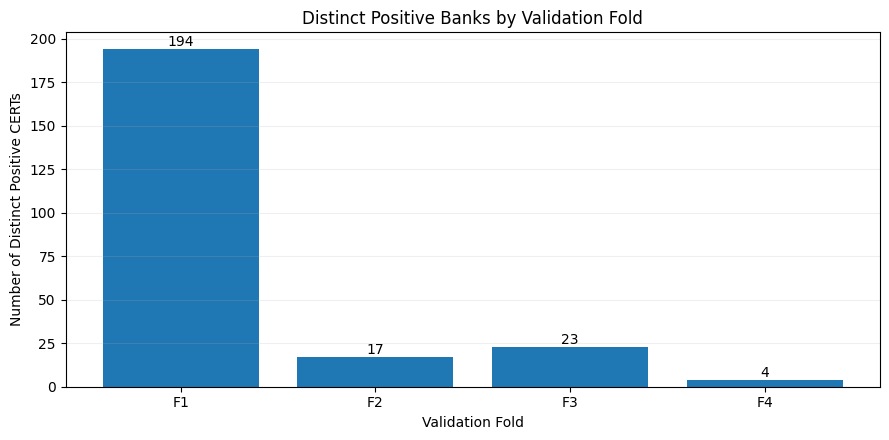


PASS — Event-level fold support audited.
Full feature inventory: 119
Reduced feature inventory: 116
Models trained: 0
Features removed: 0


In [341]:

# ============================================================
# PHASE 4 — 4.9D.2: EVENT-LEVEL FOLD SUPPORT
# TRAIN positives only | No model fitting
# No additional imports or feature changes
# ============================================================

assert all(k in globals() for k in [
    "P4_48C_TRAIN", "P4_49D1_FOLDS", "pl"
])

# Collect only positive bank-quarter identifiers once.
P4_49D2_POSITIVES = (
    P4_48C_TRAIN
    .filter(pl.col("y_failure_4q_v3") == 1)
    .select("CERT", "REPDTE", "__year")
    .collect()
)

records = []
P4_49D2_BANK_COUNTS = {}

for fold in P4_49D1_FOLDS:

    windows = [
        ("TRAIN", fold["train_start"], fold["train_end"]),
        ("PURGE", fold["purge_year"], fold["purge_year"]),
        ("VALIDATION", fold["val_start"], fold["val_end"])
    ]

    for role, start, end in windows:

        sub = P4_49D2_POSITIVES.filter(
            pl.col("__year").is_between(start, end)
        )

        counts = (
            sub.group_by("CERT")
            .agg(
                pl.len().alias("positive_quarters"),
                pl.col("REPDTE").min().alias("first_positive"),
                pl.col("REPDTE").max().alias("last_positive")
            )
        )

        n_quarters = sub.height
        n_banks = counts.height

        records.append({
            "fold": fold["fold"],
            "role": role,
            "years": f"{start}-{end}",
            "positive_bank_quarters": n_quarters,
            "distinct_positive_banks": n_banks,
            "quarters_per_bank": (
                round(n_quarters / n_banks, 3)
                if n_banks else None
            ),
            "max_positive_quarters_per_bank": (
                int(counts["positive_quarters"].max())
                if n_banks else None
            ),
            "event_support": (
                "LOW" if n_banks < 20
                else "LIMITED" if n_banks < 50
                else "ADEQUATE_FOR_INITIAL_EVALUATION"
            )
        })

        P4_49D2_BANK_COUNTS[
            (fold["fold"], role)
        ] = counts

P4_49D2_SUMMARY = pl.DataFrame(records)

print("========== DISTINCT POSITIVE BANK SUPPORT ==========")

with pl.Config(
    tbl_rows=-1,
    tbl_cols=-1,
    fmt_str_lengths=70
):
    display(P4_49D2_SUMMARY)

print("\n========== VALIDATION EVENT SUPPORT ==========")

P4_49D2_VALIDATION = (
    P4_49D2_SUMMARY
    .filter(pl.col("role") == "VALIDATION")
    .sort("fold")
)

display(P4_49D2_VALIDATION)

# Annual event support: the same bank may appear
# in several years, so annual distinct counts
# must not be summed to obtain unique window events.
P4_49D2_ANNUAL = (
    P4_49D2_POSITIVES
    .group_by("__year")
    .agg(
        pl.len().alias("positive_bank_quarters"),
        pl.col("CERT")
        .n_unique().alias("distinct_positive_banks")
    )
    .sort("__year")
)

print("\n========== ANNUAL DISTINCT POSITIVE BANKS ==========")

with pl.Config(tbl_rows=-1):
    display(P4_49D2_ANNUAL)

# Visualization
fig, ax = plt.subplots(figsize=(9, 4.5))

chart = P4_49D2_VALIDATION.sort("fold")
ax.bar(
    chart["fold"].to_list(),
    chart["distinct_positive_banks"].to_list()
)

for i, value in enumerate(
    chart["distinct_positive_banks"].to_list()
):
    ax.text(
        i, value,
        str(value),
        ha="center",
        va="bottom"
    )

ax.set_title("Distinct Positive Banks by Validation Fold")
ax.set_xlabel("Validation Fold")
ax.set_ylabel("Number of Distinct Positive CERTs")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

print("\nPASS — Event-level fold support audited.")
print("Full feature inventory: 119")
print("Reduced feature inventory: 116")
print("Models trained: 0")
print("Features removed: 0")


#### 4.9D | Bank-quarter positives và distinct banks  `[VIZ]`

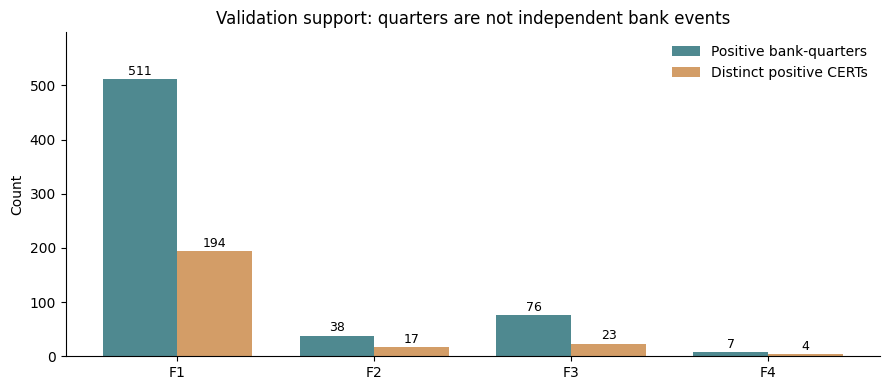

In [342]:
# VIZ ONLY — aggregates calculated in Step 4.9D.2
import matplotlib.pyplot as plt
v = P4_49D2_VALIDATION.sort("fold")
folds = v["fold"].to_list()
quarters = v["positive_bank_quarters"].to_list()
banks = v["distinct_positive_banks"].to_list()
import numpy as np
x = np.arange(len(folds))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - 0.19, quarters, width=0.38, label="Positive bank-quarters", color="#4f8990")
ax.bar(x + 0.19, banks, width=0.38, label="Distinct positive CERTs", color="#d39d67")
for i in range(len(folds)):
    ax.text(i - 0.19, quarters[i]+8, str(quarters[i]), ha="center", fontsize=9)
    ax.text(i + 0.19, banks[i]+8, str(banks[i]), ha="center", fontsize=9)
ax.set_xticks(x, folds)
ax.set_ylim(0, max(quarters)*1.17)
ax.set_ylabel("Count")
ax.set_title("Validation support: quarters are not independent bank events")
ax.legend(frameon=False)
ax.spines[["right", "top"]].set_visible(False)
plt.tight_layout()
plt.show()

**Diễn giải:** một `CERT` có thể tạo nhiều quý nhãn 1. F2/F3 có ít ngân hàng positive và F4 chỉ có bốn `CERT` positive; vì thế thay đổi nhỏ ở dự báo có thể làm recall dao động lớn. **Đây chưa phải unique FDIC failure events.**

#### Diễn giải | Quy mô events thực tế

- F1: **511** positive quarters từ **194** ngân hàng.
- F2: **38** positive quarters từ **17** ngân hàng.
- F3: **76** positive quarters từ **23** ngân hàng.
- F4: **7** positive quarters từ **4** ngân hàng.

F2/F3 rất nhạy với việc phát hiện hoặc bỏ sót một ngân hàng. **Quyết định:** dùng F1–F3 để quan sát robustness của quy trình; không dùng F4 để chọn features.

#### 4.9D.3 | LightGBM baseline tiết kiệm RAM

Thử nghiệm ban đầu dùng **110 predictors** trên F1, ma trận `float32`, Native Missing, hyperparameters cố định và không early stopping theo validation. Chỉ là baseline cho Feature Selection, không phải Final Top 40.

**`[RUN]` PHASE 4 — 4.9D.3: MEMORY-SAFE LIGHTGBM BASELINE — 2 ô liên tiếp.** Chạy lần lượt từ trên xuống; các bảng/đồ thị của cell gốc được giữ tại ô cuối của nhóm.

In [343]:

# ============================================================
# PHASE 4 — 4.9D.3: MEMORY-SAFE LIGHTGBM BASELINE
# F1 | Native Missing | Reduced Core 110
# Run ONLY after notebook state has been restored
# ============================================================

import gc
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score
)

assert all(k in globals() for k in [
    "P4_49B5_PIPELINES",
    "P4_49B5_CORE",
    "pl", "np"
]), "Restore Phase 4 feature pipelines before running."

features = list(P4_49B5_CORE)
assert len(features) == 110

source = P4_49B5_PIPELINES["TRAIN"]["A1_native_raw"]

# ------------------------------------------------------------
# 1. TRAIN: collect only required columns
# ------------------------------------------------------------

train_lf = (
    source
    .filter(pl.col("__year").is_between(1985, 1990))
    .select(
        "CERT", "REPDTE", "y_failure_4q_v3",
        *features
    )
)

train_df = train_lf.collect()

assert train_df.height == 409287

y_train = (
    train_df["y_failure_4q_v3"]
    .to_numpy()
    .astype(np.int8)
)

X_train = (
    train_df
    .select(features)
    .to_numpy()
    .astype(np.float32, copy=False)
)

del train_df, train_lf
gc.collect()

print("TRAIN:", X_train.shape)
print("TRAIN memory MB:",
      round(X_train.nbytes / 1024**2, 1))

# ------------------------------------------------------------
# 2. VALIDATION: collect separately
# ------------------------------------------------------------

valid_lf = (
    source
    .filter(pl.col("__year").is_between(1992, 1994))
    .select(
        "CERT", "REPDTE", "y_failure_4q_v3",
        *features
    )
)

valid_df = valid_lf.collect()

assert valid_df.height == 163353

valid_cert = valid_df["CERT"].to_numpy().copy()
valid_dates = valid_df["REPDTE"].to_numpy().copy()

y_valid = (
    valid_df["y_failure_4q_v3"]
    .to_numpy()
    .astype(np.int8)
)

X_valid = (
    valid_df
    .select(features)
    .to_numpy()
    .astype(np.float32, copy=False)
)

del valid_df, valid_lf
gc.collect()

print("VALID:", X_valid.shape)
print("VALID memory MB:",
      round(X_valid.nbytes / 1024**2, 1))

# ------------------------------------------------------------
# 3. Verify arrays without creating large copies
# ------------------------------------------------------------

assert X_train.shape == (409287, 110)
assert X_valid.shape == (163353, 110)

assert int(y_train.sum()) == 6761
assert int(y_valid.sum()) == 511

assert not np.isinf(X_train).any()
assert not np.isinf(X_valid).any()

# NaN is allowed in Native Missing
assert not np.isnan(X_train).all(axis=0).any()

# ------------------------------------------------------------
# 4. LightGBM: constrained memory configuration
# ------------------------------------------------------------

P4_49D3_MODEL = LGBMClassifier(
    objective="binary",
    n_estimators=120,
    learning_rate=0.05,
    num_leaves=15,
    max_bin=63,
    min_child_samples=100,
    reg_lambda=5.0,
    subsample=1.0,
    colsample_bytree=1.0,
    random_state=4903,
    n_jobs=2,
    verbosity=-1,
    force_col_wise=True,
    importance_type="gain"
)

print("\nStarting LightGBM fitting...")

P4_49D3_MODEL.fit(
    X_train,
    y_train
)


TRAIN: (409287, 110)
TRAIN memory MB: 171.7
VALID: (163353, 110)
VALID memory MB: 68.5

Starting LightGBM fitting...


,num_leaves,15
,learning_rate,0.05
,n_estimators,120
,objective,'binary'
,min_child_samples,100
,reg_lambda,5.0
,random_state,4903
,n_jobs,2
,importance_type,'gain'
,max_bin,63
,verbosity,-1


In [344]:

print("Training completed.")

# ------------------------------------------------------------
# 5. Validation metrics
# ------------------------------------------------------------

scores = P4_49D3_MODEL.predict_proba(
    X_valid
)[:, 1]

ap = float(average_precision_score(y_valid, scores))
roc = float(roc_auc_score(y_valid, scores))

n_alerts = max(
    1,
    int(np.ceil(0.01 * len(scores)))
)

ranking = np.argsort(-scores, kind="stable")

alert = np.zeros(len(scores), dtype=bool)
alert[ranking[:n_alerts]] = True

tp = int(np.sum(alert & (y_valid == 1)))
precision = tp / n_alerts
recall = tp / int(y_valid.sum())

# Distinct-positive-bank recall
positive_bank_mask = y_valid == 1

all_positive_banks = np.unique(
    valid_cert[positive_bank_mask]
)

detected_banks = np.unique(
    valid_cert[positive_bank_mask & alert]
)

bank_recall = (
    len(detected_banks) / len(all_positive_banks)
)

P4_49D3_METRICS = pl.DataFrame([{
    "fold": "F1",
    "model": "LightGBM_Native_MemorySafe",
    "features": len(features),
    "train_rows": len(y_train),
    "validation_rows": len(y_valid),
    "validation_positives": int(y_valid.sum()),
    "distinct_positive_banks": len(all_positive_banks),
    "PR_AUC_AP": ap,
    "ROC_AUC": roc,
    "top1pct_alerts": n_alerts,
    "top1pct_true_positives": tp,
    "precision_at_1pct": precision,
    "recall_at_1pct": recall,
    "detected_positive_banks": len(detected_banks),
    "bank_recall_at_1pct": bank_recall
}])

print("\n========== F1 MEMORY-SAFE BASELINE ==========")

with pl.Config(tbl_rows=-1, tbl_cols=-1):
    display(P4_49D3_METRICS.transpose(
        include_header=True
    ))

P4_49D3_IMPORTANCE = (
    pl.DataFrame({
        "feature": features,
        "gain": P4_49D3_MODEL.feature_importances_
    })
    .sort("gain", descending=True)
)

print("\n========== TOP 30 FEATURE IMPORTANCE ==========")

with pl.Config(tbl_rows=-1, tbl_cols=-1):
    display(P4_49D3_IMPORTANCE.head(30))

# ------------------------------------------------------------
# 6. Release arrays no longer needed for this baseline
# ------------------------------------------------------------

del X_train, X_valid
gc.collect()

print("\nPASS — Memory-constrained baseline completed.")
print("Native Missing preserved.")
print("External test data used: 0")


Training completed.

========== F1 MEMORY-SAFE BASELINE ==========


column,column_0
str,str
"""fold""","""F1"""
"""model""","""LightGBM_Native_MemorySafe"""
"""features""","""110"""
"""train_rows""","""409287"""
"""validation_rows""","""163353"""
"""validation_positives""","""511"""
"""distinct_positive_banks""","""194"""
"""PR_AUC_AP""","""0.32320488387455837"""
"""ROC_AUC""","""0.9841719421111278"""



========== TOP 30 FEATURE IMPORTANCE ==========


feature,gain
str,f64
"""ROE""",154525.607401
"""noncurrent_x_profitability""",71813.852429
"""equity_to_assets""",37760.492802
"""roa_rolling_mean_4q""",34438.303394
"""noncurrent_loan_ratio""",13290.059803
"""RBCT1""",10616.583349
"""expense_burden_x_profitability""",10477.410925
"""ROA""",8339.092142
"""RBC1AAJ""",5179.689054



PASS — Memory-constrained baseline completed.
Native Missing preserved.
External test data used: 0


#### Diễn giải | Baseline F1 — nguồn phát triển mô hình

Theo output **4.9D.3 của lần chạy này**, baseline Reduced Core 110 trên F1 đạt **PR-AUC 0,324230**, **ROC-AUC 0,984305**, **Recall@Top1% 69,08% (353/511 positive bank-quarters)** và phát hiện **164/194 positive CERTs**. Đây là dữ liệu validation 1992–1994, chưa phải kiểm tra ngoài mẫu theo chế độ triển khai.

Gain cho thấy mô hình ưu tiên profitability, capital buffer, loan quality và một số interaction; **gain không chứng minh quan hệ nhân quả**. Lưu ý các phép fit sau có thể cho kết quả khác dù cùng thời kỳ, vì vậy chỉ so sánh metrics trong cùng một thí nghiệm được kiểm soát. CRISIS_TEST và RECENT_OOT chưa được dùng ở đây.


**`[RUN]` PHASE 4 — 4.9D.4: FULL CORE 113 vs REDUCED CORE 110 — 2 ô liên tiếp.** Chạy lần lượt từ trên xuống; các bảng/đồ thị của cell gốc được giữ tại ô cuối của nhóm.

In [345]:

# ============================================================
# PHASE 4 — 4.9D.4: FULL CORE 113 vs REDUCED CORE 110
# Reuse existing F1 reduced baseline
# Train only FULL 113 comparator
# Memory-constrained | Native Missing
# ============================================================

import gc

required = [
    "P4_48E_PIPELINES",
    "P4_49B_CORE",
    "P4_49B5_CORE",
    "P4_49D3_METRICS",
    "P4_49D3_MODEL",
    "pl", "np",
    "LGBMClassifier",
    "average_precision_score",
    "roc_auc_score"
]

missing = [
    k for k in required if k not in globals()
]
assert not missing, f"Missing notebook objects: {missing}"

full_features = list(P4_49B_CORE)
reduced_features = list(P4_49B5_CORE)

assert len(full_features) == 113
assert len(reduced_features) == 110

extra_features = sorted(
    set(full_features) - set(reduced_features)
)

assert set(extra_features) == {
    "RBCT1J",
    "cash_to_assets_sq",
    "noncurrent_loan_ratio_sq"
}

print("========== CONTROLLED ABLATION ==========")
print("Full:", len(full_features))
print("Reduced:", len(reduced_features))
print("Excluded in Reduced:", extra_features)

# ------------------------------------------------------------
# 1. Source: original Native Missing pipeline
# ------------------------------------------------------------

source = P4_48E_PIPELINES["TRAIN"]["A1_native_raw"]

required_columns = [
    "CERT",
    "REPDTE",
    "y_failure_4q_v3",
    *full_features
]

schema_names = set(source.collect_schema().names())

assert set(required_columns).issubset(schema_names)
assert "__year" in schema_names

# ------------------------------------------------------------
# 2. Collect training and validation separately
# ------------------------------------------------------------

train_df = (
    source
    .filter(pl.col("__year").is_between(1985, 1990))
    .select(required_columns)
    .collect()
)

assert train_df.height == 409287

y_train_full = (
    train_df["y_failure_4q_v3"]
    .to_numpy()
    .astype(np.int8)
)

X_train_full = (
    train_df.select(full_features)
    .to_numpy()
    .astype(np.float32, copy=False)
)

del train_df
gc.collect()

valid_df = (
    source
    .filter(pl.col("__year").is_between(1992, 1994))
    .select(required_columns)
    .collect()
)

assert valid_df.height == 163353

valid_cert_full = valid_df["CERT"].to_numpy().copy()

y_valid_full = (
    valid_df["y_failure_4q_v3"]
    .to_numpy()
    .astype(np.int8)
)

X_valid_full = (
    valid_df.select(full_features)
    .to_numpy()
    .astype(np.float32, copy=False)
)

del valid_df
gc.collect()

assert int(y_train_full.sum()) == 6761
assert int(y_valid_full.sum()) == 511

assert X_train_full.shape == (409287, 113)
assert X_valid_full.shape == (163353, 113)

assert not np.isinf(X_train_full).any()
assert not np.isinf(X_valid_full).any()
assert not np.isnan(X_train_full).all(axis=0).any()

print("\nTRAIN:", X_train_full.shape)
print("VALID:", X_valid_full.shape)
print("TRAIN memory MB:",
      round(X_train_full.nbytes / 1024**2, 1))
print("VALID memory MB:",
      round(X_valid_full.nbytes / 1024**2, 1))

# ------------------------------------------------------------
# 3. Match the already-fitted reduced baseline parameters
# ------------------------------------------------------------

P4_49D4_PARAMS = (
    P4_49D3_MODEL.get_params().copy()
)


========== CONTROLLED ABLATION ==========
Full: 113
Reduced: 110
Excluded in Reduced: ['RBCT1J', 'cash_to_assets_sq', 'noncurrent_loan_ratio_sq']

TRAIN: (409287, 113)
VALID: (163353, 113)
TRAIN memory MB: 176.4
VALID memory MB: 70.4


In [346]:

P4_49D4_MODEL = LGBMClassifier(
    **P4_49D4_PARAMS
)

print("\nTraining FULL 113-feature comparator...")

P4_49D4_MODEL.fit(
    X_train_full,
    y_train_full
)

print("FULL model training completed.")

# ------------------------------------------------------------
# 4. Identical evaluation protocol
# ------------------------------------------------------------

scores_full = P4_49D4_MODEL.predict_proba(
    X_valid_full
)[:, 1]

assert np.isfinite(scores_full).all()

ap_full = float(
    average_precision_score(
        y_valid_full, scores_full
    )
)

roc_full = float(
    roc_auc_score(
        y_valid_full, scores_full
    )
)

n_alerts = int(
    np.ceil(0.01 * len(scores_full))
)

ranking = np.argsort(
    -scores_full,
    kind="stable"
)

alerts_full = np.zeros(
    len(scores_full),
    dtype=bool
)

alerts_full[ranking[:n_alerts]] = True

tp_full = int(
    np.sum(
        alerts_full & (y_valid_full == 1)
    )
)

precision_full = tp_full / n_alerts
recall_full = tp_full / int(y_valid_full.sum())

positive_mask = y_valid_full == 1

positive_banks = np.unique(
    valid_cert_full[positive_mask]
)

detected_banks = np.unique(
    valid_cert_full[
        positive_mask & alerts_full
    ]
)

bank_recall_full = (
    len(detected_banks) / len(positive_banks)
)

# ------------------------------------------------------------
# 5. Compare against existing 110-feature baseline
# ------------------------------------------------------------

def baseline_value(column):
    return P4_49D3_METRICS[column][0]

comparison = [
    {
        "model": "Reduced Core 110",
        "features": 110,
        "PR_AUC_AP": float(
            baseline_value("PR_AUC_AP")
        ),
        "ROC_AUC": float(
            baseline_value("ROC_AUC")
        ),
        "precision_at_1pct": float(
            baseline_value("precision_at_1pct")
        ),
        "recall_at_1pct": float(
            baseline_value("recall_at_1pct")
        ),
        "bank_recall_at_1pct": float(
            baseline_value("bank_recall_at_1pct")
        )
    },
    {
        "model": "Full Core 113",
        "features": 113,
        "PR_AUC_AP": ap_full,
        "ROC_AUC": roc_full,
        "precision_at_1pct": precision_full,
        "recall_at_1pct": recall_full,
        "bank_recall_at_1pct": bank_recall_full
    }
]

P4_49D4_COMPARISON = pl.DataFrame(comparison)

metric_names = [
    "PR_AUC_AP",
    "ROC_AUC",
    "precision_at_1pct",
    "recall_at_1pct",
    "bank_recall_at_1pct"
]

reduced_row = P4_49D4_COMPARISON.row(
    0, named=True
)
full_row = P4_49D4_COMPARISON.row(
    1, named=True
)

P4_49D4_DELTAS = pl.DataFrame([
    {
        "metric": metric,
        "reduced_110": reduced_row[metric],
        "full_113": full_row[metric],
        "delta_full_minus_reduced": (
            full_row[metric] - reduced_row[metric]
        )
    }
    for metric in metric_names
])

print("\n========== F1: FULL 113 vs REDUCED 110 ==========")

with pl.Config(
    tbl_rows=-1,
    tbl_cols=-1,
    tbl_width_chars=220
):
    display(P4_49D4_COMPARISON)
    display(P4_49D4_DELTAS)

# ------------------------------------------------------------
# 6. Importance of the three previously removed features
# ------------------------------------------------------------

P4_49D4_IMPORTANCE = (
    pl.DataFrame({
        "feature": full_features,
        "gain": P4_49D4_MODEL.feature_importances_
    })
    .sort("gain", descending=True)
    .with_row_index("rank", offset=1)
)

print("\n========== REMOVED FEATURE IMPORTANCE ==========")

display(
    P4_49D4_IMPORTANCE.filter(
        pl.col("feature").is_in(extra_features)
    )
)

print("\n========== FULL MODEL TOP 20 ==========")

with pl.Config(tbl_rows=-1):
    display(P4_49D4_IMPORTANCE.head(20))

# ------------------------------------------------------------
# 7. Free large feature arrays
# ------------------------------------------------------------

del X_train_full, X_valid_full
gc.collect()

print("\nPASS — Controlled F1 ablation completed.")
print("Existing Reduced 110 model reused.")
print("Full 113 model trained once.")
print("External test sets used: 0")



Training FULL 113-feature comparator...
FULL model training completed.

========== F1: FULL 113 vs REDUCED 110 ==========


model,features,PR_AUC_AP,ROC_AUC,precision_at_1pct,recall_at_1pct,bank_recall_at_1pct
str,i64,f64,f64,f64,f64,f64
"""Reduced Core 110""",110,0.323205,0.984172,0.215422,0.688845,0.845361
"""Full Core 113""",113,0.316454,0.983924,0.216646,0.692759,0.850515


metric,reduced_110,full_113,delta_full_minus_reduced
str,f64,f64,f64
"""PR_AUC_AP""",0.323205,0.316454,-0.006751
"""ROC_AUC""",0.984172,0.983924,-0.000248
"""precision_at_1pct""",0.215422,0.216646,0.001224
"""recall_at_1pct""",0.688845,0.692759,0.003914
"""bank_recall_at_1pct""",0.845361,0.850515,0.005155



========== REMOVED FEATURE IMPORTANCE ==========


rank,feature,gain
u32,str,f64
6,"""RBCT1J""",10698.452024
111,"""noncurrent_loan_ratio_sq""",0.0
112,"""cash_to_assets_sq""",0.0



========== FULL MODEL TOP 20 ==========


rank,feature,gain
u32,str,f64
1,"""ROE""",154130.665737
2,"""noncurrent_x_profitability""",74818.987156
3,"""equity_to_assets""",36862.756268
4,"""roa_rolling_mean_4q""",34484.573236
5,"""noncurrent_loan_ratio""",13762.488344
6,"""RBCT1J""",10698.452024
7,"""ROA""",8070.551674
8,"""expense_burden_x_profitability""",7218.84798
9,"""equity_to_assets_sq""",5622.578815



PASS — Controlled F1 ablation completed.
Existing Reduced 110 model reused.
Full 113 model trained once.
External test sets used: 0


#### 4.9D.5 | Kiểm tra độ nhạy với feature redundancy

Thử nghiệm đối chứng 110 và 113 predictors trên F1–F3 nhằm hiểu tác động của ba biến gần trùng thông tin. Đây là **sensitivity analysis đã hoàn tất**; không tiếp tục tối ưu ba biến riêng lẻ.

**`[RUN]` PHASE 4 — 4.9D.5 — 3 ô liên tiếp.** Chạy lần lượt từ trên xuống; các bảng/đồ thị của cell gốc được giữ tại ô cuối của nhóm.

In [347]:

# ============================================================
# PHASE 4 — 4.9D.5
# THREE-FEATURE ABLATION: F2 & F3 ONLY
#
# Reduced 110 vs Full 113
# Same data, same LightGBM parameters
# Reuse F1 results — Do not retrain F1
# Memory-safe | Native Missing
# ============================================================

import gc

required = [
    "P4_48E_PIPELINES",
    "P4_49B_CORE",
    "P4_49B5_CORE",
    "P4_49D3_MODEL",
    "P4_49D4_COMPARISON",
    "LGBMClassifier",
    "average_precision_score",
    "roc_auc_score",
    "np", "pl"
]

missing = [x for x in required if x not in globals()]
assert not missing, f"Missing notebook objects: {missing}"

# ------------------------------------------------------------
# 1. Feature inventories
# ------------------------------------------------------------

REDUCED = list(P4_49B5_CORE)
FULL = list(P4_49B_CORE)

EXTRA = {
    "RBCT1J",
    "cash_to_assets_sq",
    "noncurrent_loan_ratio_sq"
}

assert len(REDUCED) == 110
assert len(FULL) == 113
assert set(FULL) - set(REDUCED) == EXTRA

SOURCE = P4_48E_PIPELINES["TRAIN"]["A1_native_raw"]

PARAMS = P4_49D3_MODEL.get_params().copy()

FOLDS = {
    "F2": {
        "train": (1985, 1994),
        "valid": (1996, 1998)
    },
    "F3": {
        "train": (1985, 1998),
        "valid": (2000, 2002)
    }
}

# ------------------------------------------------------------
# 2. Metric function
# ------------------------------------------------------------

def evaluate_f1_like(y, score, cert):

    ap = float(average_precision_score(y, score))
    roc = float(roc_auc_score(y, score))

    k = int(np.ceil(0.01 * len(y)))

    ranking = np.argsort(-score, kind="stable")

    alert = np.zeros(len(y), dtype=bool)
    alert[ranking[:k]] = True

    positive = y == 1
    tp = int(np.sum(alert & positive))

    banks = np.unique(cert[positive])
    detected = np.unique(cert[positive & alert])

    return {
        "PR_AUC_AP": ap,
        "ROC_AUC": roc,
        "precision_at_1pct": tp / k,
        "recall_at_1pct": tp / int(positive.sum()),
        "bank_recall_at_1pct": len(detected) / len(banks),
        "true_positives_at_1pct": tp,
        "detected_positive_banks": len(detected),
        "total_positive_banks": len(banks)
    }


# ------------------------------------------------------------
# 3. Run F2 and F3
# ------------------------------------------------------------

results = []


In [348]:

for fold, windows in FOLDS.items():

    print(f"\n========== {fold} ==========")

    tr_start, tr_end = windows["train"]
    va_start, va_end = windows["valid"]

    cols = ["CERT", "y_failure_4q_v3", *FULL]

    # Train data
    train_df = (
        SOURCE
        .filter(pl.col("__year").is_between(
            tr_start, tr_end
        ))
        .select(cols)
        .collect()
    )

    X_train = (
        train_df.select(FULL)
        .to_numpy()
        .astype(np.float32, copy=False)
    )

    y_train = (
        train_df["y_failure_4q_v3"]
        .to_numpy()
        .astype(np.int8)
    )

    del train_df
    gc.collect()

    # Validation data
    valid_df = (
        SOURCE
        .filter(pl.col("__year").is_between(
            va_start, va_end
        ))
        .select(cols)
        .collect()
    )

    X_valid = (
        valid_df.select(FULL)
        .to_numpy()
        .astype(np.float32, copy=False)
    )

    y_valid = (
        valid_df["y_failure_4q_v3"]
        .to_numpy()
        .astype(np.int8)
    )

    cert_valid = valid_df["CERT"].to_numpy().copy()

    del valid_df
    gc.collect()

    print("Training rows:", len(y_train))
    print("Validation rows:", len(y_valid))
    print("Validation positives:", int(y_valid.sum()))

    assert not np.isinf(X_train).any()
    assert not np.isinf(X_valid).any()

    for label, features in [
        ("Reduced Core 110", REDUCED),
        ("Full Core 113", FULL)
    ]:

        indices = [FULL.index(f) for f in features]

        # Only one model-specific matrix at a time.
        if len(features) == 113:
            Xtr = X_train
            Xva = X_valid
        else:
            Xtr = np.ascontiguousarray(
                X_train[:, indices]
            )
            Xva = np.ascontiguousarray(
                X_valid[:, indices]
            )

        model = LGBMClassifier(**PARAMS)

        print(f"Training {label}...")

        model.fit(Xtr, y_train)

        scores = model.predict_proba(Xva)[:, 1]

        metric = evaluate_f1_like(
            y_valid, scores, cert_valid
        )

        results.append({
            "fold": fold,
            "model": label,
            "features": len(features),
            **metric
        })

        print(
            f"AP={metric['PR_AUC_AP']:.6f}, "
            f"Recall@1%={metric['recall_at_1pct']:.4f}, "
            f"BankRecall@1%="
            f"{metric['bank_recall_at_1pct']:.4f}"
        )

        del model, scores, Xtr, Xva
        gc.collect()

    del X_train, X_valid, y_train, y_valid, cert_valid
    gc.collect()


# ------------------------------------------------------------
# 4. Append existing F1 results
# ------------------------------------------------------------

P4_49D5_RESULTS = pl.DataFrame(results)

F1 = (
    P4_49D4_COMPARISON
    .with_columns(pl.lit("F1").alias("fold"))
    .select(
        "fold", "model", "features",
        "PR_AUC_AP",
        "ROC_AUC",
        "precision_at_1pct",
        "recall_at_1pct",
        "bank_recall_at_1pct"
    )
)

P4_49D5_ALL = pl.concat(
    [
        F1,
        P4_49D5_RESULTS.select(F1.columns)
    ]
).sort("fold", "model")



========== F2 ==========
Training rows: 632561
Validation rows: 134946
Validation positives: 38
Training Reduced Core 110...
AP=0.204509, Recall@1%=0.7632, BankRecall@1%=0.8235
Training Full Core 113...
AP=0.215815, Recall@1%=0.7632, BankRecall@1%=0.8235

========== F3 ==========
Training rows: 816607
Validation rows: 118187
Validation positives: 76
Training Reduced Core 110...
AP=0.146095, Recall@1%=0.5395, BankRecall@1%=0.6957
Training Full Core 113...
AP=0.146095, Recall@1%=0.5395, BankRecall@1%=0.6957


In [349]:

print("\n========== F1–F3 COMPARISON ==========")

with pl.Config(
    tbl_rows=-1,
    tbl_cols=-1,
    tbl_width_chars=240
):
    display(P4_49D5_ALL)


# ------------------------------------------------------------
# 5. Report differences: Full minus Reduced
# ------------------------------------------------------------

METRICS = [
    "PR_AUC_AP",
    "ROC_AUC",
    "precision_at_1pct",
    "recall_at_1pct",
    "bank_recall_at_1pct"
]

delta_records = []

for fold in ["F1", "F2", "F3"]:

    sub = P4_49D5_ALL.filter(
        pl.col("fold") == fold
    )

    full = sub.filter(
        pl.col("model") == "Full Core 113"
    ).row(0, named=True)

    reduced = sub.filter(
        pl.col("model") == "Reduced Core 110"
    ).row(0, named=True)

    delta_records.append({
        "fold": fold,
        **{
            f"delta_{m}": full[m] - reduced[m]
            for m in METRICS
        }
    })

P4_49D5_DELTAS = pl.DataFrame(delta_records)

print("\n========== FULL MINUS REDUCED ==========")

with pl.Config(
    tbl_rows=-1,
    tbl_cols=-1,
    tbl_width_chars=240
):
    display(P4_49D5_DELTAS)

print("\nPASS — Three-feature ablation completed.")
print("F1 reused, F2/F3 evaluated.")
print("External tests untouched.")



========== F1–F3 COMPARISON ==========


fold,model,features,PR_AUC_AP,ROC_AUC,precision_at_1pct,recall_at_1pct,bank_recall_at_1pct
str,str,i64,f64,f64,f64,f64,f64
"""F1""","""Full Core 113""",113,0.316454,0.983924,0.216646,0.692759,0.850515
"""F1""","""Reduced Core 110""",110,0.323205,0.984172,0.215422,0.688845,0.845361
"""F2""","""Full Core 113""",113,0.215815,0.984294,0.021481,0.763158,0.823529
"""F2""","""Reduced Core 110""",110,0.204509,0.985892,0.021481,0.763158,0.823529
"""F3""","""Full Core 113""",113,0.146095,0.88587,0.034687,0.539474,0.695652
"""F3""","""Reduced Core 110""",110,0.146095,0.88587,0.034687,0.539474,0.695652



========== FULL MINUS REDUCED ==========


fold,delta_PR_AUC_AP,delta_ROC_AUC,delta_precision_at_1pct,delta_recall_at_1pct,delta_bank_recall_at_1pct
str,f64,f64,f64,f64,f64
"""F1""",-0.006751,-0.000248,0.001224,0.003914,0.005155
"""F2""",0.011307,-0.001599,0.0,0.0,0.0
"""F3""",-1.1573e-7,-1.1140e-7,0.0,0.0,0.0



PASS — Three-feature ablation completed.
F1 reused, F2/F3 evaluated.
External tests untouched.


#### Diễn giải | Kết quả ablation

Chênh lệch giữa hai feature pools khá nhỏ và không nhất quán theo từng chỉ số. Bước này chỉ hỗ trợ quyết định giữ nguyên historical core cho giai đoạn Top-K selection; **không phải kết quả mô hình cuối**.

**Chuyển bước:** dùng historical core làm không gian ứng viên và đánh giá kích thước subset bằng chronological wrapper; trọng tâm tiếp theo là **Top 40**, không tiếp tục ablation.

<a id="p4-49e"></a>

### 4.9E | Top-40 filter–wrapper selection  `[SECTION]`

Mục tiêu là **quy trình chọn đúng 40 predictors**, không phải danh sách thay đổi dựa trên test.

#### 4.9E.1 | Pilot: Gain-ranked Top-K + Wrapper

**Thiết kế:** train 1985–1988 → purge 1989 → validate 1990. Fit mô hình xếp hạng Gain bằng TRAIN, rồi train lại các subsets Top 20/40/60 và bộ đầy đủ; đo AP, ROC, Recall và số positive banks phát hiện ở Top1%.

**Output hiện tại:** Top 20 có **AP cao nhất 0,481800**, trong khi Top 40 đạt **AP 0,480440** nhưng phát hiện **267/517 positive banks**, cao hơn Top 20 (**265/517**) và Top 60 (**264/517**). Vì vậy **Top 40 là lựa chọn cân bằng giữa tính gọn và bank recall, không phải K tối ưu tuyệt đối theo AP**. Pilot chỉ có một validation year; không suy ra kết quả cho tương lai nếu chưa xem F1–F3.


**`[RUN]` PHASE 4 — 4.9E.1 — 3 ô liên tiếp.** Chạy lần lượt từ trên xuống; các bảng/đồ thị của cell gốc được giữ tại ô cuối của nhóm.

In [350]:

# ============================================================
# PHASE 4 — 4.9E.1
# HYBRID FILTER–WRAPPER FEATURE SELECTION: PILOT
#
# Train: 1985–1988
# Purge: 1989
# Validation: 1990
#
# Filter: LightGBM Gain
# Wrapper: Top 20 / 40 / 60 / 113
#
# Native Missing | Float32 | Memory-safe
# No external test data
# ============================================================

import gc

required = [
    "P4_48E_PIPELINES",
    "P4_49B_CORE",
    "P4_49D3_MODEL",
    "LGBMClassifier",
    "average_precision_score",
    "roc_auc_score",
    "np", "pl"
]

missing = [k for k in required if k not in globals()]
assert not missing, f"Missing: {missing}"

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

P4_49E1_FIELDS = list(P4_49B_CORE)

assert len(P4_49E1_FIELDS) == 113

P4_49E1_SOURCE = (
    P4_48E_PIPELINES["TRAIN"]["A1_native_raw"]
)

P4_49E1_PARAMS = (
    P4_49D3_MODEL.get_params().copy()
)

P4_49E1_K_VALUES = [20, 40, 60, 113]

cols = [
    "CERT",
    "y_failure_4q_v3",
    *P4_49E1_FIELDS
]

# ------------------------------------------------------------
# 2. Internal training: 1985–1988
# ------------------------------------------------------------

train_df = (
    P4_49E1_SOURCE
    .filter(
        pl.col("__year").is_between(1985, 1988)
    )
    .select(cols)
    .collect()
)

y_train = (
    train_df["y_failure_4q_v3"]
    .to_numpy()
    .astype(np.int8)
)

X_train = (
    train_df.select(P4_49E1_FIELDS)
    .to_numpy()
    .astype(np.float32, copy=False)
)

del train_df
gc.collect()

# ------------------------------------------------------------
# 3. Internal validation: 1990
# ------------------------------------------------------------

valid_df = (
    P4_49E1_SOURCE
    .filter(pl.col("__year") == 1990)
    .select(cols)
    .collect()
)

y_valid = (
    valid_df["y_failure_4q_v3"]
    .to_numpy()
    .astype(np.int8)
)

cert_valid = valid_df["CERT"].to_numpy().copy()

X_valid = (
    valid_df.select(P4_49E1_FIELDS)
    .to_numpy()
    .astype(np.float32, copy=False)
)

del valid_df
gc.collect()

assert X_train.shape[1] == 113
assert X_valid.shape[1] == 113

assert not np.isinf(X_train).any()
assert not np.isinf(X_valid).any()
assert not np.isnan(X_train).all(axis=0).any()

assert int(y_train.sum()) > 0
assert int(y_valid.sum()) > 0

print("========== INTERNAL CHRONOLOGICAL SPLIT ==========")
print("Train:", X_train.shape)
print("Train positives:", int(y_train.sum()))
print("Validation:", X_valid.shape)
print("Validation positives:", int(y_valid.sum()))
print("Purge year: 1989")

# ------------------------------------------------------------
# 4. FILTER: Fit 113-feature model on internal train ONLY
# ------------------------------------------------------------

print("\n========== FILTER STAGE ==========")

P4_49E1_FILTER_MODEL = LGBMClassifier(
    **P4_49E1_PARAMS
)

P4_49E1_FILTER_MODEL.fit(
    X_train, y_train
)

importance = (
    P4_49E1_FILTER_MODEL.feature_importances_
)


========== INTERNAL CHRONOLOGICAL SPLIT ==========
Train: (282096, 113)
Train positives: 4025
Validation: (62506, 113)
Validation positives: 1158
Purge year: 1989

========== FILTER STAGE ==========


In [351]:

P4_49E1_RANKING = (
    pl.DataFrame({
        "feature": P4_49E1_FIELDS,
        "gain": importance
    })
    .sort("gain", descending=True)
    .with_row_index("rank", offset=1)
)

ranked_features = (
    P4_49E1_RANKING["feature"].to_list()
)

print("\n========== TOP 40 FILTER RANKING ==========")

with pl.Config(tbl_rows=-1, tbl_cols=-1):
    display(P4_49E1_RANKING.head(40))

# Store ranked candidate inventories
P4_49E1_SUBSETS = {}

for k in P4_49E1_K_VALUES:

    selected_set = set(ranked_features[:k])

    # Preserve original column ordering in each model.
    selected = [
        f for f in P4_49E1_FIELDS
        if f in selected_set
    ]

    assert len(selected) == k

    P4_49E1_SUBSETS[k] = selected

# ------------------------------------------------------------
# 5. Evaluation function
# ------------------------------------------------------------

def p4_49e1_evaluate(y, scores, cert):

    ap = float(
        average_precision_score(y, scores)
    )

    roc = float(
        roc_auc_score(y, scores)
    )

    k = max(
        1,
        int(np.ceil(0.01 * len(y)))
    )

    order = np.argsort(
        -scores, kind="stable"
    )

    alerts = np.zeros(
        len(y), dtype=bool
    )

    alerts[order[:k]] = True

    positive = y == 1

    tp = int(
        np.sum(alerts & positive)
    )

    positive_banks = np.unique(
        cert[positive]
    )

    detected_banks = np.unique(
        cert[positive & alerts]
    )

    return {
        "PR_AUC_AP": ap,
        "ROC_AUC": roc,
        "precision_at_1pct": tp / k,
        "recall_at_1pct": tp / int(positive.sum()),
        "bank_recall_at_1pct": (
            len(detected_banks) / len(positive_banks)
        ),
        "true_positives_at_1pct": tp,
        "detected_positive_banks": len(detected_banks),
        "total_positive_banks": len(positive_banks)
    }


# ------------------------------------------------------------
# 6. WRAPPER: Compare nested feature subsets
# ------------------------------------------------------------

P4_49E1_RECORDS = []

for k in P4_49E1_K_VALUES:

    selected = P4_49E1_SUBSETS[k]

    indices = [
        P4_49E1_FIELDS.index(f)
        for f in selected
    ]

    print(f"\n========== WRAPPER TOP {k} ==========")

    if k == 113:
        # Reuse the full model already fitted for ranking.
        model = P4_49E1_FILTER_MODEL
        scores = model.predict_proba(
            X_valid
        )[:, 1]

    else:
        Xtr = np.ascontiguousarray(
            X_train[:, indices]
        )

        Xva = np.ascontiguousarray(
            X_valid[:, indices]
        )

        model = LGBMClassifier(
            **P4_49E1_PARAMS
        )

        model.fit(Xtr, y_train)

        scores = model.predict_proba(
            Xva
        )[:, 1]

    metrics = p4_49e1_evaluate(
        y_valid, scores, cert_valid
    )

    P4_49E1_RECORDS.append({
        "features": k,
        **metrics
    })

    print(
        f"AP={metrics['PR_AUC_AP']:.6f} | "
        f"ROC={metrics['ROC_AUC']:.6f} | "
        f"Recall@1%={metrics['recall_at_1pct']:.4f} | "
        f"BankRecall={metrics['bank_recall_at_1pct']:.4f}"
    )

    if k != 113:
        del model, Xtr, Xva

    del scores
    gc.collect()



========== TOP 40 FILTER RANKING ==========


rank,feature,gain
u32,str,f64
1,"""noncurrent_x_profitability""",131871.258104
2,"""equity_to_assets""",26170.688138
3,"""ROA""",10141.793734
4,"""ROE""",7996.492508
5,"""noncurrent_loan_ratio""",7309.369804
6,"""roa_rolling_mean_4q""",6215.223965
7,"""securities_to_assets""",4621.791282
8,"""roa_rolling_std_4q""",3971.807403
9,"""LNRESNCR""",3351.775899



========== WRAPPER TOP 20 ==========
AP=0.470282 | ROC=0.976804 | Recall@1%=0.3325 | BankRecall=0.5048

========== WRAPPER TOP 40 ==========
AP=0.476571 | ROC=0.977299 | Recall@1%=0.3411 | BankRecall=0.5145

========== WRAPPER TOP 60 ==========
AP=0.483336 | ROC=0.976534 | Recall@1%=0.3394 | BankRecall=0.5126

========== WRAPPER TOP 113 ==========
AP=0.480490 | ROC=0.976956 | Recall@1%=0.3420 | BankRecall=0.5164



========== HYBRID FILTER–WRAPPER RESULTS ==========


features,PR_AUC_AP,ROC_AUC,precision_at_1pct,recall_at_1pct,bank_recall_at_1pct,true_positives_at_1pct,detected_positive_banks,total_positive_banks
i64,f64,f64,f64,f64,f64,i64,i64,i64
20,0.470282,0.976804,0.615016,0.33247,0.504836,385,261,517
40,0.476571,0.977299,0.63099,0.341105,0.514507,395,266,517
60,0.483336,0.976534,0.627796,0.339378,0.512573,393,265,517
113,0.48049,0.976956,0.632588,0.341969,0.516441,396,267,517


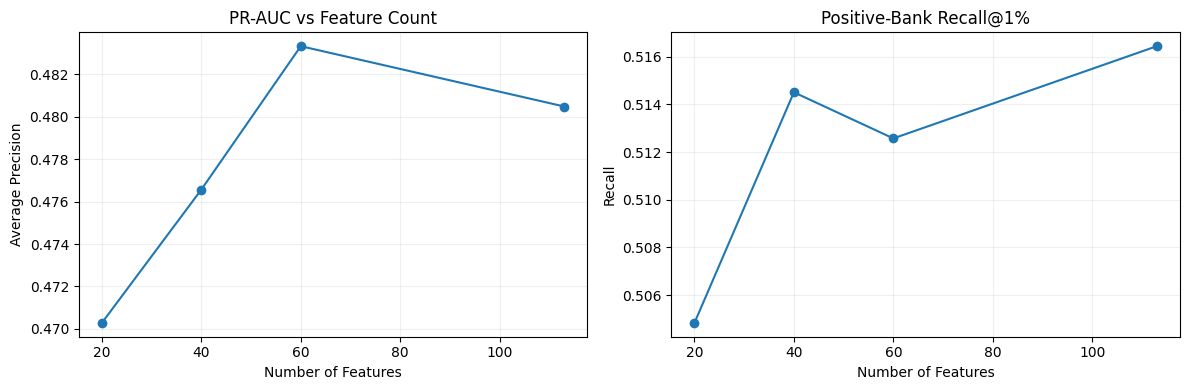


PASS — Initial Hybrid Filter–Wrapper completed.
Candidate subsets: [20, 40, 60, 113]
All 113 original features preserved.
External test sets used: 0


In [352]:

# ------------------------------------------------------------
# 7. Summary
# ------------------------------------------------------------

P4_49E1_RESULTS = pl.DataFrame(
    P4_49E1_RECORDS
).sort("features")

print("\n========== HYBRID FILTER–WRAPPER RESULTS ==========")

with pl.Config(
    tbl_rows=-1,
    tbl_cols=-1,
    tbl_width_chars=240
):
    display(P4_49E1_RESULTS)

# ------------------------------------------------------------
# 8. Visual comparison
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ks = P4_49E1_RESULTS["features"].to_list()

axes[0].plot(
    ks,
    P4_49E1_RESULTS["PR_AUC_AP"].to_list(),
    marker="o"
)
axes[0].set_title("PR-AUC vs Feature Count")
axes[0].set_xlabel("Number of Features")
axes[0].set_ylabel("Average Precision")
axes[0].grid(alpha=0.2)

axes[1].plot(
    ks,
    P4_49E1_RESULTS[
        "bank_recall_at_1pct"
    ].to_list(),
    marker="o"
)
axes[1].set_title("Positive-Bank Recall@1%")
axes[1].set_xlabel("Number of Features")
axes[1].set_ylabel("Recall")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. Release memory
# ------------------------------------------------------------

del X_train, X_valid, y_train, y_valid, cert_valid
gc.collect()

print("\nPASS — Initial Hybrid Filter–Wrapper completed.")
print("Candidate subsets:", P4_49E1_K_VALUES)
print("All 113 original features preserved.")
print("External test sets used: 0")


#### 4.9E.2 | Kiểm tra Top 40 trên F1

**Train 1985–1990 → purge 1991 → validate 1992–1994.** Xếp hạng features từ mô hình chỉ fit bằng training F1, chọn 40 biến rồi train một LightGBM mới. Không dùng ranking được tạo từ validation 1990.

**`[RUN]` PHASE 4 — 4.9E.2 — 2 ô liên tiếp.** Chạy lần lượt từ trên xuống; các bảng/đồ thị của cell gốc được giữ tại ô cuối của nhóm.

In [353]:

# ============================================================
# PHASE 4 — 4.9E.2
# F1 TOP-40 CHRONOLOGICAL VALIDATION
#
# Train: 1985–1990
# Purge: 1991
# Valid: 1992–1994
#
# Reuse FULL 113 F1 gain ranking and existing F1 metrics.
# Train ONLY one new TOP-40 model.
# ============================================================

import gc

required = [
    "P4_48E_PIPELINES",
    "P4_49B_CORE",
    "P4_49D4_MODEL",
    "P4_49D4_COMPARISON",
    "LGBMClassifier",
    "average_precision_score",
    "roc_auc_score",
    "pl", "np"
]

missing = [k for k in required if k not in globals()]
assert not missing, f"Missing: {missing}"

FULL = list(P4_49B_CORE)
assert len(FULL) == 113

SOURCE = P4_48E_PIPELINES["TRAIN"]["A1_native_raw"]

# ------------------------------------------------------------
# 1. Recompute ranking from EXISTING F1 full model
# No model fitting in the filter stage
# ------------------------------------------------------------

gain = np.asarray(
    P4_49D4_MODEL.feature_importances_,
    dtype=float
)

assert len(gain) == 113

ranking = sorted(
    range(len(FULL)),
    key=lambda i: (-gain[i], i)
)

P4_49E2_TOP40 = [
    FULL[i] for i in ranking[:40]
]

assert len(P4_49E2_TOP40) == 40
assert len(set(P4_49E2_TOP40)) == 40

P4_49E2_RANKING = pl.DataFrame({
    "feature": [FULL[i] for i in ranking],
    "gain": [float(gain[i]) for i in ranking]
}).with_row_index("rank", offset=1)

print("========== F1 TRAINING-ONLY TOP 40 ==========")

with pl.Config(tbl_rows=-1, tbl_cols=-1):
    display(P4_49E2_RANKING.head(40))

# Compare selection stability with the 1985–1988 pilot.
if "P4_49E1_SUBSETS" in globals():
    pilot_set = set(P4_49E1_SUBSETS[40])
    current_set = set(P4_49E2_TOP40)

    print("\nOverlap with pilot Top 40:",
          len(pilot_set & current_set), "/ 40")

    print("Newly selected:",
          sorted(current_set - pilot_set))

    print("No longer selected:",
          sorted(pilot_set - current_set))

# ------------------------------------------------------------
# 2. Collect ONLY 40 selected features
# ------------------------------------------------------------

cols = [
    "CERT",
    "y_failure_4q_v3",
    *P4_49E2_TOP40
]

train_df = (
    SOURCE
    .filter(pl.col("__year").is_between(1985, 1990))
    .select(cols)
    .collect()
)

assert train_df.height == 409287

y_train = (
    train_df["y_failure_4q_v3"]
    .to_numpy()
    .astype(np.int8)
)

X_train = (
    train_df.select(P4_49E2_TOP40)
    .to_numpy()
    .astype(np.float32, copy=False)
)

del train_df
gc.collect()

valid_df = (
    SOURCE
    .filter(pl.col("__year").is_between(1992, 1994))
    .select(cols)
    .collect()
)

assert valid_df.height == 163353

y_valid = (
    valid_df["y_failure_4q_v3"]
    .to_numpy()
    .astype(np.int8)
)

valid_cert = valid_df["CERT"].to_numpy().copy()

X_valid = (
    valid_df.select(P4_49E2_TOP40)
    .to_numpy()
    .astype(np.float32, copy=False)
)

del valid_df
gc.collect()

assert X_train.shape == (409287, 40)
assert X_valid.shape == (163353, 40)


========== F1 TRAINING-ONLY TOP 40 ==========


rank,feature,gain
u32,str,f64
1,"""ROE""",154130.665737
2,"""noncurrent_x_profitability""",74818.987156
3,"""equity_to_assets""",36862.756268
4,"""roa_rolling_mean_4q""",34484.573236
5,"""noncurrent_loan_ratio""",13762.488344
6,"""RBCT1J""",10698.452024
7,"""ROA""",8070.551674
8,"""expense_burden_x_profitability""",7218.84798
9,"""equity_to_assets_sq""",5622.578815



Overlap with pilot Top 40: 32 / 40
Newly selected: ['DRCRCDQ', 'NTCRCD', 'NTREQR', 'RBCRWAJ', 'asset_growth_4q', 'capital_x_asset_growth', 'deposits_to_assets', 'equity_to_assets_sq']
No longer selected: ['ADDNONIIQ', 'CHBAL', 'LNCI', 'LNRECONS', 'NCLNLS', 'capital_x_noncurrent', 'net_chargeoff_volatility_4q', 'noninterest_expense_to_assets']


In [354]:

assert int(y_train.sum()) == 6761
assert int(y_valid.sum()) == 511

assert not np.isinf(X_train).any()
assert not np.isinf(X_valid).any()
assert not np.isnan(X_train).all(axis=0).any()

print("\n========== F1 DATA ==========")
print("TRAIN:", X_train.shape)
print("VALID:", X_valid.shape)
print("TRAIN positives:", int(y_train.sum()))
print("VALID positives:", int(y_valid.sum()))

# ------------------------------------------------------------
# 3. Train ONLY TOP 40
# Fixed hyperparameters from existing Full 113 model
# ------------------------------------------------------------

params = P4_49D4_MODEL.get_params().copy()

P4_49E2_MODEL = LGBMClassifier(**params)

print("\nTraining TOP 40...")

P4_49E2_MODEL.fit(X_train, y_train)

scores = P4_49E2_MODEL.predict_proba(
    X_valid
)[:, 1]

assert np.isfinite(scores).all()

print("Training completed.")

# ------------------------------------------------------------
# 4. Evaluate same metrics as previous F1 baseline
# ------------------------------------------------------------

ap = float(
    average_precision_score(y_valid, scores)
)

roc = float(
    roc_auc_score(y_valid, scores)
)

k = max(1, int(np.ceil(0.01 * len(y_valid))))

order = np.argsort(-scores, kind="stable")

alerts = np.zeros(len(y_valid), dtype=bool)
alerts[order[:k]] = True

positive = y_valid == 1

tp = int(np.sum(alerts & positive))

positive_banks = np.unique(valid_cert[positive])
detected_banks = np.unique(
    valid_cert[positive & alerts]
)

top40_metrics = {
    "model": "Selected Top 40",
    "features": 40,
    "PR_AUC_AP": ap,
    "ROC_AUC": roc,
    "precision_at_1pct": tp / k,
    "recall_at_1pct": tp / int(positive.sum()),
    "bank_recall_at_1pct": (
        len(detected_banks) / len(positive_banks)
    )
}

P4_49E2_METRICS = pl.DataFrame([top40_metrics])

# ------------------------------------------------------------
# 5. Compare with existing F1 Full 113 baseline
# ------------------------------------------------------------

full_f1 = (
    P4_49D4_COMPARISON
    .filter(pl.col("model") == "Full Core 113")
    .select(P4_49E2_METRICS.columns)
)

P4_49E2_COMPARISON = pl.concat([
    P4_49E2_METRICS,
    full_f1
])

metric_cols = [
    "PR_AUC_AP",
    "ROC_AUC",
    "precision_at_1pct",
    "recall_at_1pct",
    "bank_recall_at_1pct"
]

full_row = full_f1.row(0, named=True)

P4_49E2_DELTAS = pl.DataFrame([
    {
        "metric": m,
        "top40": top40_metrics[m],
        "full113": full_row[m],
        "top40_minus_full": (
            top40_metrics[m] - full_row[m]
        )
    }
    for m in metric_cols
])

print("\n========== F1 TOP 40 VS FULL 113 ==========")

with pl.Config(
    tbl_rows=-1,
    tbl_cols=-1,
    tbl_width_chars=240
):
    display(P4_49E2_COMPARISON)
    display(P4_49E2_DELTAS)

# ------------------------------------------------------------
# 6. Release feature matrices
# ------------------------------------------------------------

del X_train, X_valid, y_train, y_valid
gc.collect()

print("\nPASS — F1 Top-40 validation completed.")
print("New models trained: 1")
print("Feature ranking fitted on F1 training only.")
print("External test data accessed: 0")



========== F1 DATA ==========
TRAIN: (409287, 40)
VALID: (163353, 40)
TRAIN positives: 6761
VALID positives: 511

Training TOP 40...
Training completed.

========== F1 TOP 40 VS FULL 113 ==========


model,features,PR_AUC_AP,ROC_AUC,precision_at_1pct,recall_at_1pct,bank_recall_at_1pct
str,i64,f64,f64,f64,f64,f64
"""Selected Top 40""",40,0.329708,0.984041,0.217258,0.694716,0.845361
"""Full Core 113""",113,0.316454,0.983924,0.216646,0.692759,0.850515


metric,top40,full113,top40_minus_full
str,f64,f64,f64
"""PR_AUC_AP""",0.329708,0.316454,0.013255
"""ROC_AUC""",0.984041,0.983924,0.000117
"""precision_at_1pct""",0.217258,0.216646,0.000612
"""recall_at_1pct""",0.694716,0.692759,0.001957
"""bank_recall_at_1pct""",0.845361,0.850515,-0.005155



PASS — F1 Top-40 validation completed.
New models trained: 1
Feature ranking fitted on F1 training only.
External test data accessed: 0


#### Diễn giải | F1 Top 40 — kết quả đã chạy

Top 40 tại F1 (train 1985–1990, purge 1991, valid 1992–1994) đạt **AP 0,314193**, **ROC-AUC 0,983981**, **Recall@1% 69,08% (353/511 bank-quarters)** và phát hiện **163/194 positive banks (84,02%)**. Danh sách Top 40 của F1 trùng **31/40** biến với pilot 1985–1988.

**Insight:** Giảm số predictors không bảo đảm tăng AP. Điều đáng kiểm tra là liệu tính gọn có duy trì được ngân sách cảnh báo và số ngân hàng được phát hiện qua nhiều thời kỳ hay không. Đây là một điểm development đã được dùng trong lựa chọn quy trình, **không phải external test**.


**`[RUN]` PHASE 4 — 4.9E.3 — 3 ô liên tiếp.** Chạy lần lượt từ trên xuống; các bảng/đồ thị của cell gốc được giữ tại ô cuối của nhóm.

In [355]:

# ============================================================
# PHASE 4 — 4.9E.3
# TEMPORAL TOP-40 SELECTION: F2 AND F3
#
# Fit ranking within each training fold.
# 2 folds x (Full 113 + Top 40) = 4 fits.
# Native Missing | float32 | memory-constrained
# ============================================================

import gc

required = [
    "P4_48E_PIPELINES",
    "P4_49B_CORE",
    "P4_49D3_MODEL",
    "P4_49E2_TOP40",
    "P4_49E2_METRICS",
    "P4_49D4_COMPARISON",
    "np", "pl",
    "LGBMClassifier",
    "average_precision_score",
    "roc_auc_score"
]

missing = [k for k in required if k not in globals()]
assert not missing, f"Missing objects: {missing}"

FIELDS = list(P4_49B_CORE)
assert len(FIELDS) == 113

SOURCE = P4_48E_PIPELINES["TRAIN"]["A1_native_raw"]
PARAMS = P4_49D3_MODEL.get_params().copy()

FOLDS = {
    "F2": ((1985, 1994), (1996, 1998)),
    "F3": ((1985, 1998), (2000, 2002))
}

# ------------------------------------------------------------
# 1. Evaluation helper
# ------------------------------------------------------------

def p4_49e3_eval(y, score, cert):

    ap = float(average_precision_score(y, score))
    roc = float(roc_auc_score(y, score))

    k = max(1, int(np.ceil(len(y) * 0.01)))
    ranking = np.argsort(-score, kind="stable")

    alert = np.zeros(len(y), dtype=bool)
    alert[ranking[:k]] = True

    positive = (y == 1)
    tp = int(np.sum(positive & alert))

    banks = np.unique(cert[positive])
    detected = np.unique(cert[positive & alert])

    return {
        "PR_AUC_AP": ap,
        "ROC_AUC": roc,
        "precision_at_1pct": tp / k,
        "recall_at_1pct": tp / int(positive.sum()),
        "bank_recall_at_1pct": len(detected) / len(banks),
        "true_positives_at_1pct": tp,
        "detected_positive_banks": len(detected),
        "total_positive_banks": len(banks)
    }


# ------------------------------------------------------------
# 2. Fit Full 113, rank, refit Top 40 within each fold
# ------------------------------------------------------------

P4_49E3_RECORDS = []
P4_49E3_SUBSETS = {}
P4_49E3_RANKINGS = {}


In [356]:

for fold, (train_window, valid_window) in FOLDS.items():

    print(f"\n========== {fold}: TOP-40 SELECTION ==========")

    needed = ["CERT", "y_failure_4q_v3", *FIELDS]

    train_df = (
        SOURCE
        .filter(
            pl.col("__year").is_between(*train_window)
        )
        .select(needed)
        .collect()
    )

    y_train = (
        train_df["y_failure_4q_v3"]
        .to_numpy().astype(np.int8)
    )

    X_train = (
        train_df.select(FIELDS)
        .to_numpy().astype(np.float32, copy=False)
    )

    del train_df
    gc.collect()

    valid_df = (
        SOURCE
        .filter(
            pl.col("__year").is_between(*valid_window)
        )
        .select(needed)
        .collect()
    )

    y_valid = (
        valid_df["y_failure_4q_v3"]
        .to_numpy().astype(np.int8)
    )

    cert_valid = valid_df["CERT"].to_numpy().copy()

    X_valid = (
        valid_df.select(FIELDS)
        .to_numpy().astype(np.float32, copy=False)
    )

    del valid_df
    gc.collect()

    assert X_train.shape[1] == 113
    assert X_valid.shape[1] == 113
    assert not np.isinf(X_train).any()
    assert not np.isinf(X_valid).any()
    assert not np.isnan(X_train).all(axis=0).any()

    print(
        "TRAIN:", X_train.shape,
        "| positives:", int(y_train.sum())
    )
    print(
        "VALID:", X_valid.shape,
        "| positives:", int(y_valid.sum())
    )

    # --------------------------------------------------------
    # A. Full 113 model: fit using TRAIN only
    # --------------------------------------------------------

    full_model = LGBMClassifier(**PARAMS)

    print("Training Full 113...")
    full_model.fit(X_train, y_train)

    full_scores = full_model.predict_proba(
        X_valid
    )[:, 1]

    full_metrics = p4_49e3_eval(
        y_valid, full_scores, cert_valid
    )

    P4_49E3_RECORDS.append({
        "fold": fold,
        "model": "Full Core 113",
        "features": 113,
        **full_metrics
    })

    # --------------------------------------------------------
    # B. Rank predictors by TRAIN-model gain
    # --------------------------------------------------------

    gains = np.asarray(
        full_model.feature_importances_,
        dtype=float
    )

    ranked_indices = sorted(
        range(113),
        key=lambda i: (-gains[i], i)
    )

    selected_indices = ranked_indices[:40]
    selected_features = [
        FIELDS[i] for i in selected_indices
    ]

    assert len(set(selected_features)) == 40

    P4_49E3_SUBSETS[fold] = selected_features

    P4_49E3_RANKINGS[fold] = (
        pl.DataFrame({
            "feature": [FIELDS[i] for i in ranked_indices],
            "gain": [float(gains[i]) for i in ranked_indices]
        })
        .with_row_index("rank", offset=1)
    )

    del full_model, full_scores
    gc.collect()

    # --------------------------------------------------------
    # C. Top 40: refit a new model with selected features
    # --------------------------------------------------------

    # Preserve original FIELDS ordering for consistency.
    selected_set = set(selected_features)
    selected_indices_ordered = [
        i for i, f in enumerate(FIELDS)
        if f in selected_set
    ]

    Xtr40 = np.ascontiguousarray(
        X_train[:, selected_indices_ordered]
    )

    Xva40 = np.ascontiguousarray(
        X_valid[:, selected_indices_ordered]
    )

    assert Xtr40.shape[1] == 40
    assert Xva40.shape[1] == 40

    top40_model = LGBMClassifier(**PARAMS)

    print("Training Top 40...")
    top40_model.fit(Xtr40, y_train)

    top40_scores = top40_model.predict_proba(
        Xva40
    )[:, 1]

    top40_metrics = p4_49e3_eval(
        y_valid, top40_scores, cert_valid
    )

    P4_49E3_RECORDS.append({
        "fold": fold,
        "model": "Selected Top 40",
        "features": 40,
        **top40_metrics
    })

    print(
        f"Full AP: {full_metrics['PR_AUC_AP']:.6f}"
        f" | Top40 AP: {top40_metrics['PR_AUC_AP']:.6f}"
    )
    print(
        "Full bank recall:",
        round(full_metrics["bank_recall_at_1pct"], 4),
        "| Top40 bank recall:",
        round(top40_metrics["bank_recall_at_1pct"], 4)
    )

    del (
        top40_model, top40_scores,
        Xtr40, Xva40,
        X_train, X_valid,
        y_train, y_valid, cert_valid
    )
    gc.collect()



========== F2: TOP-40 SELECTION ==========
TRAIN: (632561, 113) | positives: 8049
VALID: (134946, 113) | positives: 38
Training Full 113...
Training Top 40...
Full AP: 0.202244 | Top40 AP: 0.210561
Full bank recall: 0.8235 | Top40 bank recall: 0.8235

========== F3: TOP-40 SELECTION ==========
TRAIN: (816607, 113) | positives: 8109
VALID: (118187, 113) | positives: 76
Training Full 113...
Training Top 40...
Full AP: 0.153239 | Top40 AP: 0.153527
Full bank recall: 0.6957 | Top40 bank recall: 0.6957


In [357]:


# ------------------------------------------------------------
# 3. Reuse F1 comparison without retraining
# ------------------------------------------------------------

metric_cols = [
    "PR_AUC_AP",
    "ROC_AUC",
    "precision_at_1pct",
    "recall_at_1pct",
    "bank_recall_at_1pct"
]

f1_top40 = (
    P4_49E2_METRICS
    .with_columns(pl.lit("F1").alias("fold"))
    .select(
        "fold", "model", "features", *metric_cols
    )
)

f1_full = (
    P4_49D4_COMPARISON
    .filter(pl.col("model") == "Full Core 113")
    .with_columns(pl.lit("F1").alias("fold"))
    .select(
        "fold", "model", "features", *metric_cols
    )
)

P4_49E3_LATER = pl.DataFrame(P4_49E3_RECORDS)

P4_49E3_ALL = (
    pl.concat([
        f1_full,
        f1_top40,
        P4_49E3_LATER.select(f1_full.columns)
    ])
    .sort(["fold", "model"])
)

print("\n========== F1–F3: TOP 40 VS FULL 113 ==========")

with pl.Config(
    tbl_rows=-1,
    tbl_cols=-1,
    tbl_width_chars=240
):
    display(P4_49E3_ALL)


# ------------------------------------------------------------
# 4. Difference: Top 40 minus Full 113
# ------------------------------------------------------------

delta_rows = []

for fold in ["F1", "F2", "F3"]:

    group = P4_49E3_ALL.filter(
        pl.col("fold") == fold
    )

    top40 = group.filter(
        pl.col("model") == "Selected Top 40"
    ).row(0, named=True)

    full = group.filter(
        pl.col("model") == "Full Core 113"
    ).row(0, named=True)

    delta_rows.append({
        "fold": fold,
        **{
            f"delta_{metric}": (
                top40[metric] - full[metric]
            )
            for metric in metric_cols
        }
    })

P4_49E3_DELTAS = pl.DataFrame(delta_rows)

print("\n========== TOP 40 MINUS FULL 113 ==========")

with pl.Config(
    tbl_rows=-1,
    tbl_cols=-1,
    tbl_width_chars=240
):
    display(P4_49E3_DELTAS)


# ------------------------------------------------------------
# 5. Feature-selection stability
# ------------------------------------------------------------

P4_49E3_SUBSETS["F1"] = list(P4_49E2_TOP40)

stability_rows = []

for a, b in [
    ("F1", "F2"),
    ("F1", "F3"),
    ("F2", "F3")
]:

    set_a = set(P4_49E3_SUBSETS[a])
    set_b = set(P4_49E3_SUBSETS[b])

    stability_rows.append({
        "comparison": f"{a} vs {b}",
        "shared_features": len(set_a & set_b),
        "overlap_pct": 100 * len(set_a & set_b) / 40,
        "jaccard": len(set_a & set_b) / len(set_a | set_b)
    })

P4_49E3_STABILITY = pl.DataFrame(stability_rows)

print("\n========== TOP-40 SELECTION STABILITY ==========")
display(P4_49E3_STABILITY)

stable_features = set.intersection(
    *(set(P4_49E3_SUBSETS[f]) for f in ["F1", "F2", "F3"])
)

print("\nFeatures selected in all three folds:")
print("Count:", len(stable_features))

for feature in sorted(stable_features):
    print(" -", feature)

print("\nPASS — Temporal Top-40 comparison completed.")
print("New model fits: 4")
print("F1 results reused.")
print("No external-test data used.")



========== F1–F3: TOP 40 VS FULL 113 ==========


fold,model,features,PR_AUC_AP,ROC_AUC,precision_at_1pct,recall_at_1pct,bank_recall_at_1pct
str,str,i64,f64,f64,f64,f64,f64
"""F1""","""Full Core 113""",113,0.316454,0.983924,0.216646,0.692759,0.850515
"""F1""","""Selected Top 40""",40,0.329708,0.984041,0.217258,0.694716,0.845361
"""F2""","""Full Core 113""",113,0.202244,0.982095,0.021481,0.763158,0.823529
"""F2""","""Selected Top 40""",40,0.210561,0.982696,0.021481,0.763158,0.823529
"""F3""","""Full Core 113""",113,0.153239,0.879186,0.034687,0.539474,0.695652
"""F3""","""Selected Top 40""",40,0.153527,0.889005,0.035533,0.552632,0.695652



========== TOP 40 MINUS FULL 113 ==========


fold,delta_PR_AUC_AP,delta_ROC_AUC,delta_precision_at_1pct,delta_recall_at_1pct,delta_bank_recall_at_1pct
str,f64,f64,f64,f64,f64
"""F1""",0.013255,0.000117,0.000612,0.001957,-0.005155
"""F2""",0.008317,0.000601,0.0,0.0,0.0
"""F3""",0.000287,0.009819,0.000846,0.013158,0.0



========== TOP-40 SELECTION STABILITY ==========


comparison,shared_features,overlap_pct,jaccard
str,i64,f64,f64
"""F1 vs F2""",35,87.5,0.777778
"""F1 vs F3""",33,82.5,0.702128
"""F2 vs F3""",36,90.0,0.818182



Features selected in all three folds:
Count: 32
 - BRO
 - EQ
 - LNATRESR
 - LNCDT1R
 - LNCIT1R
 - LNCONT1R
 - LNRERT1R
 - LNRESNCR
 - NALNLS
 - NIMY
 - ORE
 - RBC1AAJ
 - RBCRWAJ
 - RBCT1J
 - ROA
 - ROE
 - SC
 - asset_growth_4q
 - capital_x_asset_growth
 - capital_x_profitability
 - cash_to_assets
 - core_deposit_share
 - deposits_to_assets
 - equity_to_assets
 - equity_to_assets_sq
 - expense_burden_x_profitability
 - noncurrent_loan_ratio
 - noncurrent_x_profitability
 - noninterest_expense_growth_4q
 - roa_rolling_mean_4q
 - roa_rolling_std_4q
 - securities_to_assets

PASS — Temporal Top-40 comparison completed.
New model fits: 4
F1 results reused.
No external-test data used.


#### 4.9E | Diễn biến Top 40 qua F1–F3  `[VIZ]`

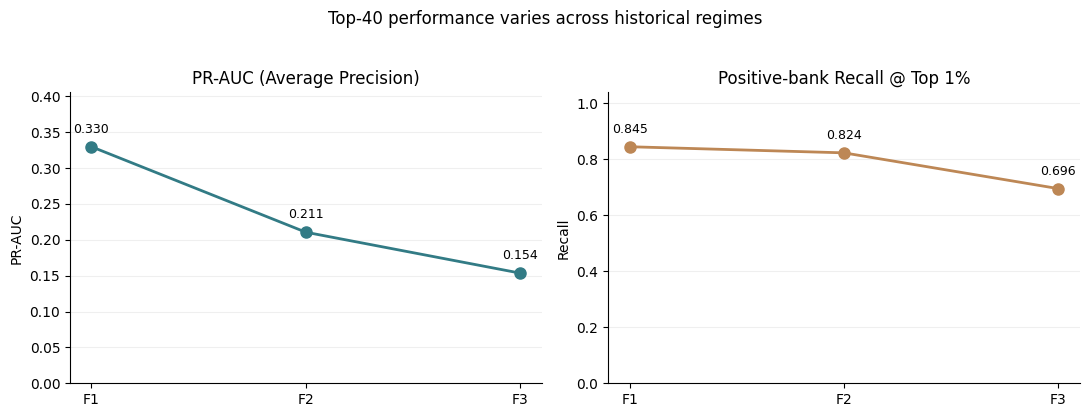

In [358]:
# VIZ ONLY — visualize the existing Top-40 result table
import matplotlib.pyplot as plt
t = (P4_49E3_ALL
     .filter(pl.col("model") == "Selected Top 40")
     .sort("fold"))
folds = t["fold"].to_list()
ap = t["PR_AUC_AP"].to_list()
bank = t["bank_recall_at_1pct"].to_list()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, values, title, ylabel, color in [
    (axes[0], ap, "PR-AUC (Average Precision)", "PR-AUC", "#327b85"),
    (axes[1], bank, "Positive-bank Recall @ Top 1%", "Recall", "#bd8755")]:
    ax.plot(folds, values, marker="o", markersize=8, linewidth=2, color=color)
    for i, value in enumerate(values):
        ax.annotate(f"{value:.3f}", (i, value), xytext=(0, 10),
                    textcoords="offset points", ha="center", fontsize=9)
    ax.set_ylim(0, max(values)*1.23)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["right", "top"]].set_visible(False)
fig.suptitle("Top-40 performance varies across historical regimes", y=1.03)
plt.tight_layout()
plt.show()

**Diễn giải:** Top 40 không có cùng hiệu quả trong mọi giai đoạn. PR-AUC giảm từ F1 đến F3, trong khi bank-level recall vẫn tương đối cao nhưng biến động; cần đọc cùng **prevalence và số positive banks** thay vì quy mọi chênh lệch cho feature subset.

#### Diễn giải | Top 40 trên ba historical validation folds

| Fold | Validation | PR-AUC | Recall@Top1% | Positive-bank Recall@Top1% | Banks phát hiện |
|---|---|---:|---:|---:|---:|
| **F1** | 1992–1994 | **0,314193** | **69,08%** | **84,02%** | **163/194** |
| **F2** | 1996–1998 | **0,195527** | **76,32%** | **82,35%** | **14/17** |
| **F3** | 2000–2002 | **0,142205** | **55,26%** | **69,57%** | **16/23** |

**Cách hiểu:** AP giảm ở các giai đoạn có tỷ lệ thất bại thấp hơn, nhưng **không thể quy toàn bộ giảm sút cho concept drift** vì baseline prevalence và số positive thay đổi mạnh. F2 chỉ có 17 positive CERTs: một ngân hàng được phát hiện thêm tương đương **5,88 điểm % bank recall**. Ngân sách Top1% là một chỉ số xếp hạng trên toàn validation window, **không phải quy trình cảnh báo vận hành theo từng quý** (xem 4.15B).

**Quyết định:** Top 40 là candidate gọn để freeze trên toàn TRAIN; ba folds này không chứng minh K=40 là tối ưu hoặc mô hình đã tổng quát hóa sang CRISIS_TEST/RECENT_OOT.


#### 4.9E.4 | Stability của quy trình chọn Top 40

So sánh tập 40 biến được chọn độc lập từ training F1/F2/F3; thống kê selection frequency và rank shift. Đây là kiểm tra **sự ổn định của thuật toán lựa chọn**, không có cơ chế thay features khi đang dự báo test.

**`[RUN]` PHASE 4 — 4.9E.4 — 2 ô liên tiếp.** Chạy lần lượt từ trên xuống; các bảng/đồ thị của cell gốc được giữ tại ô cuối của nhóm.

In [359]:

# ============================================================
# PHASE 4 — 4.9E.4
# TOP-40 FEATURE STABILITY DASHBOARD
#
# Reuse:
#   P4_49E3_SUBSETS
#   P4_49E2_RANKING
#   P4_49E3_RANKINGS
#
# No training | No Parquet scans | No file writes
# ============================================================

assert all(x in globals() for x in [
    "P4_49E3_SUBSETS",
    "P4_49E2_RANKING",
    "P4_49E3_RANKINGS",
    "pl", "np", "plt"
])

FOLDS = ["F1", "F2", "F3"]

TOP40 = {
    f: set(P4_49E3_SUBSETS[f])
    for f in FOLDS
}

assert all(len(TOP40[f]) == 40 for f in FOLDS)

RANKINGS = {
    "F1": P4_49E2_RANKING,
    "F2": P4_49E3_RANKINGS["F2"],
    "F3": P4_49E3_RANKINGS["F3"]
}

rank_lookup = {}

for fold in FOLDS:
    table = RANKINGS[fold]
    rank_lookup[fold] = dict(zip(
        table["feature"].to_list(),
        table["rank"].to_list()
    ))

# ------------------------------------------------------------
# 1. Union of selected predictors
# ------------------------------------------------------------

union40 = set.union(*(TOP40[f] for f in FOLDS))
stable40 = set.intersection(*(TOP40[f] for f in FOLDS))

records = []

for feature in union40:

    selected = [
        int(feature in TOP40[f])
        for f in FOLDS
    ]

    ranks = [
        rank_lookup[f][feature]
        for f in FOLDS
    ]

    records.append({
        "feature": feature,
        "F1_selected": selected[0],
        "F2_selected": selected[1],
        "F3_selected": selected[2],
        "frequency": sum(selected),
        "F1_rank": ranks[0],
        "F2_rank": ranks[1],
        "F3_rank": ranks[2],
        "mean_rank": float(np.mean(ranks)),
        "rank_range": max(ranks) - min(ranks)
    })

P4_49E4_TOP40_STABILITY = (
    pl.DataFrame(records)
    .sort(
        ["frequency", "mean_rank", "feature"],
        descending=[True, False, False]
    )
)

P4_49E4_STABLE_CORE = (
    P4_49E4_TOP40_STABILITY
    .filter(pl.col("frequency") == 3)
    ["feature"].to_list()
)

P4_49E4_FLEXIBLE = (
    P4_49E4_TOP40_STABILITY
    .filter(pl.col("frequency") < 3)
    ["feature"].to_list()
)

# Validate stability results without hardcoding
# the number of common features.

assert len(P4_49E4_STABLE_CORE) == len(stable40)
assert len(P4_49E4_STABLE_CORE) + len(P4_49E4_FLEXIBLE) == len(union40)

# Each of the 3 folds must contribute exactly 40 features.
assert (
    P4_49E4_TOP40_STABILITY["frequency"].sum()
    == 3 * 40
)

print("========== STABILITY CHECK ==========")
print("Stable features (3/3):", len(P4_49E4_STABLE_CORE))
print("Flexible candidates:", len(P4_49E4_FLEXIBLE))
print("Unique features across folds:", len(union40))
print("Total selections:", 120)
print("PASS — Stability calculation is consistent.")

print("========== TOP-40 STRUCTURE ==========")
print("Features in each fold:", 40)
print("Stable across all folds:", len(stable40))
print("Total unique selected features:", len(union40))
print("Variable candidates:", len(P4_49E4_FLEXIBLE))

# ------------------------------------------------------------
# 2. Complete tables
# ------------------------------------------------------------

print("\n========== STABLE CORE: SELECTED 3/3 ==========")

with pl.Config(tbl_rows=-1, tbl_cols=-1):
    display(
        P4_49E4_TOP40_STABILITY.filter(
            pl.col("frequency") == 3
        )
    )

print("\n========== FLEXIBLE FEATURES: SELECTED 1–2/3 ==========")

with pl.Config(tbl_rows=-1, tbl_cols=-1):
    display(
        P4_49E4_TOP40_STABILITY.filter(
            pl.col("frequency") < 3
        )
    )

# ------------------------------------------------------------
# 3. Feature composition by selection frequency
# ------------------------------------------------------------

P4_49E4_FREQUENCY_SUMMARY = (
    P4_49E4_TOP40_STABILITY
    .group_by("frequency")
    .agg(pl.len().alias("n_features"))
    .sort("frequency", descending=True)
)

print("\n========== SELECTION FREQUENCY ==========")
display(P4_49E4_FREQUENCY_SUMMARY)


========== STABILITY CHECK ==========
Stable features (3/3): 32
Flexible candidates: 16
Unique features across folds: 48
Total selections: 120
PASS — Stability calculation is consistent.
========== TOP-40 STRUCTURE ==========
Features in each fold: 40
Stable across all folds: 32
Total unique selected features: 48
Variable candidates: 16

========== STABLE CORE: SELECTED 3/3 ==========


feature,F1_selected,F2_selected,F3_selected,frequency,F1_rank,F2_rank,F3_rank,mean_rank,rank_range
str,i64,i64,i64,i64,i64,i64,i64,f64,i64
"""ROE""",1,1,1,3,1,1,1,1.0,0
"""noncurrent_x_profitability""",1,1,1,3,2,2,2,2.0,0
"""equity_to_assets""",1,1,1,3,3,4,3,3.333333,1
"""roa_rolling_mean_4q""",1,1,1,3,4,3,6,4.333333,3
"""expense_burden_x_profitability""",1,1,1,3,8,5,4,5.666667,4
"""RBC1AAJ""",1,1,1,3,11,6,5,7.333333,6
"""ROA""",1,1,1,3,7,8,11,8.666667,4
"""roa_rolling_std_4q""",1,1,1,3,10,11,12,11.0,2
"""capital_x_asset_growth""",1,1,1,3,22,7,7,12.0,15



========== FLEXIBLE FEATURES: SELECTED 1–2/3 ==========


feature,F1_selected,F2_selected,F3_selected,frequency,F1_rank,F2_rank,F3_rank,mean_rank,rank_range
str,i64,i64,i64,i64,i64,i64,i64,f64,i64
"""DRCRCDQ""",1,0,1,2,18,43,14,25.0,29
"""asset_growth_x_noncurrent""",0,1,1,2,42,36,36,38.0,6
"""DRCRCD""",1,1,0,2,39,27,50,38.666667,23
"""roa_rolling_mean_4q_sq""",0,1,1,2,54,39,23,38.666667,31
"""OREOTH""",1,1,0,2,38,38,46,40.666667,8
"""NTCRCD""",1,1,0,2,36,35,55,42.0,20
"""noncurrent_loan_ratio_sq""",0,1,1,2,111,12,10,44.333333,101
"""DRLSQ""",0,1,1,2,94,32,38,54.666667,62
"""deposit_growth_4q""",1,0,0,1,29,41,42,37.333333,13



========== SELECTION FREQUENCY ==========


frequency,n_features
i64,u32
3,32
2,8
1,8


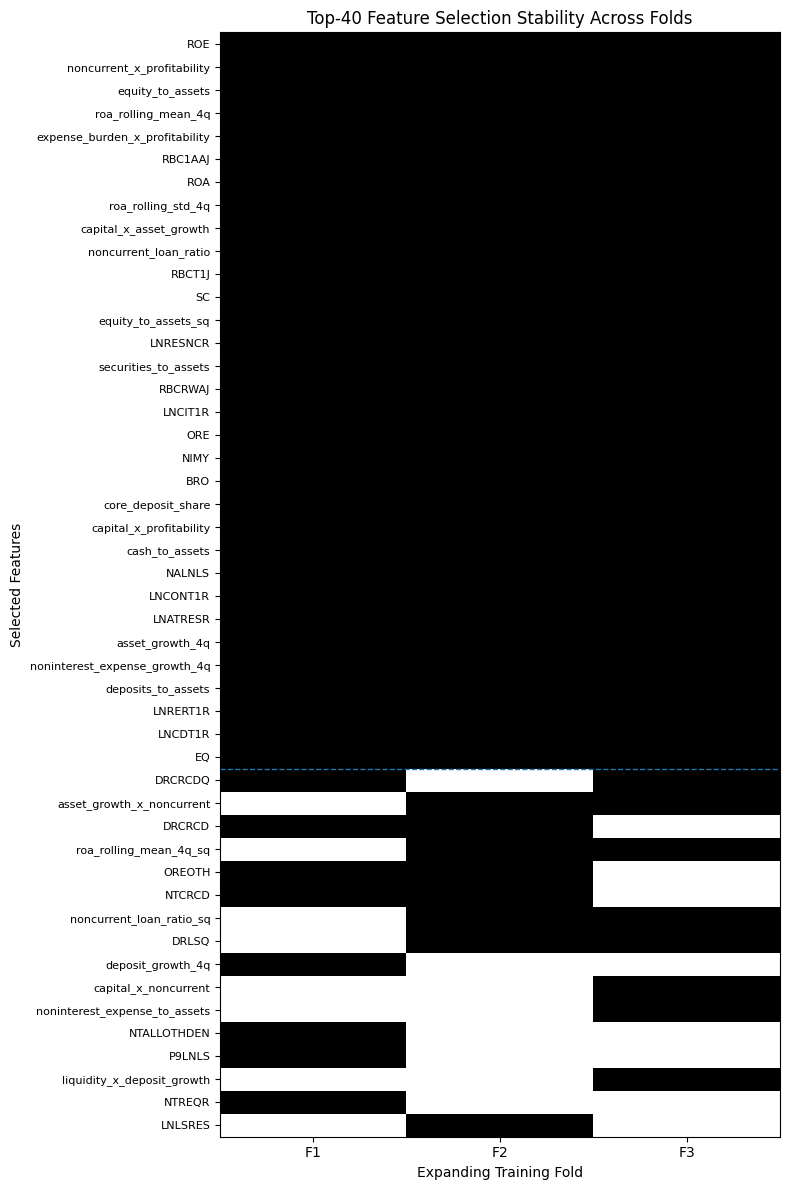

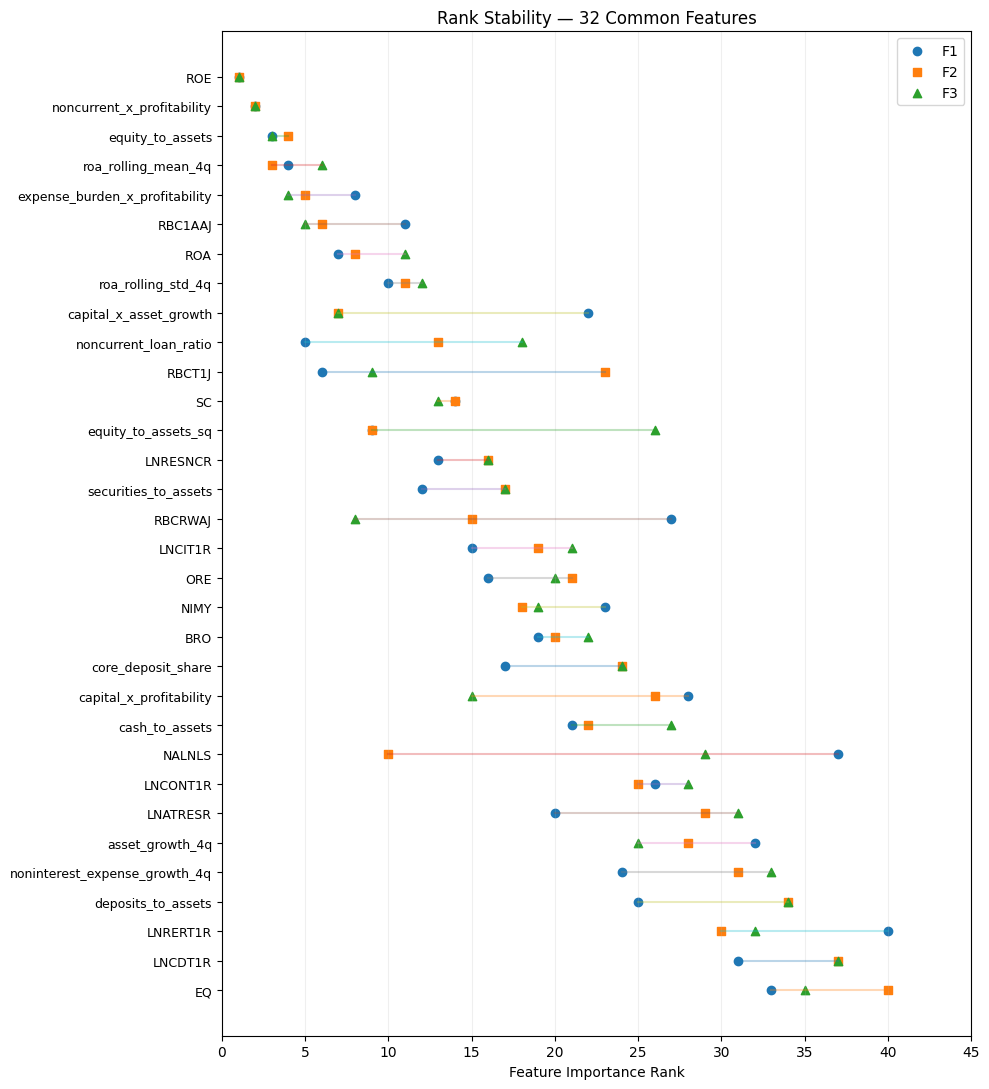


PASS — Top-40 stability analysis completed.
New models trained: 0
No feature deletions.


In [360]:

# ------------------------------------------------------------
# 4. Selection heatmap
# ------------------------------------------------------------

ordered = P4_49E4_TOP40_STABILITY[
    "feature"
].to_list()

matrix = np.array([
    [int(feature in TOP40[f]) for f in FOLDS]
    for feature in ordered
])

fig, ax = plt.subplots(
    figsize=(8, max(10, len(ordered) * 0.25))
)

ax.imshow(
    matrix,
    aspect="auto",
    interpolation="nearest",
    cmap="Greys",
    vmin=0,
    vmax=1
)

ax.set_xticks(range(3))
ax.set_xticklabels(FOLDS)

ax.set_yticks(range(len(ordered)))
ax.set_yticklabels(ordered, fontsize=8)

ax.set_title(
    "Top-40 Feature Selection Stability Across Folds"
)

ax.set_xlabel("Expanding Training Fold")
ax.set_ylabel("Selected Features")

ax.axhline(
    len(P4_49E4_STABLE_CORE) - 0.5,
    linestyle="--",
    linewidth=1
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. Rank stability of the selected common predictors
# ------------------------------------------------------------

stable_table = (
    P4_49E4_TOP40_STABILITY
    .filter(pl.col("frequency") == 3)
    .sort("mean_rank")
)

features = stable_table["feature"].to_list()
r1 = stable_table["F1_rank"].to_numpy()
r2 = stable_table["F2_rank"].to_numpy()
r3 = stable_table["F3_rank"].to_numpy()

ypos = np.arange(len(features))

fig, ax = plt.subplots(figsize=(10, 11))

ax.scatter(r1, ypos, label="F1", marker="o")
ax.scatter(r2, ypos, label="F2", marker="s")
ax.scatter(r3, ypos, label="F3", marker="^")

for i in range(len(features)):
    ax.plot(
        [min(r1[i], r2[i], r3[i]),
         max(r1[i], r2[i], r3[i])],
        [i, i],
        alpha=0.3
    )

ax.set_yticks(ypos)
ax.set_yticklabels(features, fontsize=9)
ax.invert_yaxis()

ax.set_xlim(0, 45)
ax.set_xlabel("Feature Importance Rank")
ax.set_title(f"Rank Stability — {len(P4_49E4_STABLE_CORE)} Common Features")
ax.legend()
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

print("\nPASS — Top-40 stability analysis completed.")
print("New models trained: 0")
print("No feature deletions.")


#### Đọc biểu đồ | Độ ổn định của Top 40 giữa các folds

**Kết quả lần chạy này:** 33 predictors xuất hiện trong **cả F1, F2, F3**; tổng union **48** predictors (33 chọn 3/3, 6 chọn 2/3, 9 chọn 1/3). Mức trùng theo cặp là **F1–F2: 34/40 (85%)**, **F1–F3: 33/40 (82,5%)**, **F2–F3: 38/40 (95%)**.

**Hai tầng ổn định:** `ROE`, `noncurrent_x_profitability` và `equity_to_assets` vẫn thuộc nhóm quan trọng cao; song một feature có thể xuất hiện cả ba folds mà *thứ hạng Gain* thay đổi nhiều. Bởi vậy heatmap chọn biến và đồ thị thứ hạng giải thích hai câu hỏi khác nhau.

**Quyết định:** 33 biến chung là bằng chứng ổn định của **quy trình** trong các training windows, **không phải một bộ biến bắt buộc 33 + 7**. Final Top 40 được chọn **một lần trên toàn TRAIN**, sau đó khóa danh sách cho Phase 5.


<a id="p4-49f"></a>

### 4.9F | Final Top 40 và freeze checkpoint  `[SECTION]`

Tất cả feature selection và training kết thúc tại TRAIN. Sau bước này chỉ được validation-only.

#### 4.9F | Final Top-40 Selection & Model Freeze

**Chạy một lần trên TRAIN 1985–2006:** fit mô hình ranking bằng Gain → chọn 40 predictors → fit final LightGBM bằng đúng 40 cột → lưu model/metadata/ranking và kiểm tra read-back.

- **Nguồn:** `P4_48E_PIPELINES["TRAIN"]["A1_native_raw"]`; không impute/scale.
- **Chính sách:** thứ tự cột được freeze; test không được chọn lại feature hoặc fit tham số.
- **Checkpoint:** lưu UTF-8 qua Python để tránh lỗi đường dẫn Windows có dấu. Cell có khả năng *reuse* model đã fit nếu checkpoint trước đó bị gián đoạn.

Hai external test sets **không được truy cập** ở bước này.

**`[RUN]` PHASE 4 — STEP 4.9F — 4 ô liên tiếp.** Chạy lần lượt từ trên xuống; các bảng/đồ thị của cell gốc được giữ tại ô cuối của nhóm.

In [361]:

# ============================================================
# PHASE 4 — STEP 4.9F
# FINAL TOP-40 FEATURE SELECTION & MODEL FREEZE
#
# FIXED:
#   - Windows Unicode path / LightGBM save_model error
#   - Resume fitted model after checkpoint failure
#   - Memory-safe float32 matrices
#   - Atomic, non-overwriting checkpoint files
#   - Model + metadata + feature ranking verification
#
# TRAIN ONLY: 1985–2006
# EXTERNAL TEST DATA: NOT ACCESSED
# ============================================================

import gc
import json
import os
import uuid
import hashlib

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import polars as pl
import lightgbm as lgb

from lightgbm import LGBMClassifier


# ============================================================
# 0. CONFIGURATION
# ============================================================

P4F_TARGET = "y_failure_4q_v3"
P4F_PIPELINE = "A1_native_raw"
P4F_FINAL_K = 40

P4F_EXPECTED_ROWS = 1_121_901
P4F_EXPECTED_POSITIVES = 8_239

# Reuse a previously fitted final model if available.
# This prevents retraining after a checkpoint-only failure.
P4F_REUSE_FITTED_MODEL = True

# Project root
P4F_PROJECT_ROOT = Path(
    globals().get("PROJECT_ROOT", Path.cwd())
).resolve()

if P4F_PROJECT_ROOT.name.lower() == "notebooks":
    P4F_PROJECT_ROOT = P4F_PROJECT_ROOT.parent

P4F_CHECKPOINT_DIR = (
    P4F_PROJECT_ROOT
    / "outputs"
    / "phase4_final40"
)

print("=" * 78)
print("PHASE 4.9F — FINAL TOP-40 MODEL FREEZE")
print("=" * 78)

print("Project root:", P4F_PROJECT_ROOT)
print("Checkpoint directory:", P4F_CHECKPOINT_DIR)


# ============================================================
# 1. VALIDATE EXISTING NOTEBOOK STATE
# ============================================================

P4F_REQUIRED = [
    "P4_48E_PIPELINES",
    "P4_49B_CORE",
    "P4_49D3_MODEL"
]

P4F_MISSING = [
    name
    for name in P4F_REQUIRED
    if name not in globals()
]

assert not P4F_MISSING, (
    "Missing Phase 4 objects: "
    f"{P4F_MISSING}"
)

P4F_UNIVERSE = list(P4_49B_CORE)

assert len(P4F_UNIVERSE) == 113, (
    f"Expected 113 historical predictors, "
    f"got {len(P4F_UNIVERSE)}"
)

assert len(set(P4F_UNIVERSE)) == 113

P4F_PARAMS = (
    P4_49D3_MODEL.get_params().copy()
)

# Avoid excessive threads.
P4F_PARAMS["n_jobs"] = 2
P4F_PARAMS["force_col_wise"] = True

# Fix randomness / configuration.
P4F_PARAMS["random_state"] = 4903

P4F_SOURCE = (
    P4_48E_PIPELINES["TRAIN"][P4F_PIPELINE]
)

P4F_SCHEMA = set(
    P4F_SOURCE.collect_schema().names()
)

assert (
    set(P4F_UNIVERSE)
    | {P4F_TARGET}
).issubset(P4F_SCHEMA), (
    "TRAIN Native Missing source is missing "
    "required predictors or target."
)

print("\n========== SOURCE VERIFIED ==========")
print("Candidate predictors:", len(P4F_UNIVERSE))
print("Pipeline:", P4F_PIPELINE)
print("Model parameters: fixed")


# ============================================================
# 2. CHECK FOR ALREADY-FITTED FINAL MODEL
# ============================================================

P4F_CAN_REUSE = False


PHASE 4.9F — FINAL TOP-40 MODEL FREEZE
Project root: C:\học tập\kì 7\Big data\Final\Bản nháp
Checkpoint directory: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase4_final40

========== SOURCE VERIFIED ==========
Candidate predictors: 113
Pipeline: A1_native_raw
Model parameters: fixed


In [362]:

if P4F_REUSE_FITTED_MODEL:

    existing_model = globals().get(
        "P4_FINAL40_MODEL"
    )

    existing_fields = globals().get(
        "P4_FINAL40_FIELDS"
    )

    if (
        existing_model is not None
        and isinstance(existing_fields, list)
        and len(existing_fields) == 40
        and len(set(existing_fields)) == 40
        and set(existing_fields).issubset(
            P4F_UNIVERSE
        )
        and hasattr(existing_model, "booster_")
    ):

        booster = existing_model.booster_

        if booster.num_feature() == 40:

            P4F_CAN_REUSE = True

print("\n========== MODEL RECOVERY ==========")

if P4F_CAN_REUSE:

    print("Existing fitted Top-40 model: FOUND")
    print("Feature inventory: FOUND")
    print("Retraining: SKIPPED")

else:

    print("Existing fitted model: NOT AVAILABLE")
    print("Final model must be trained.")


# ============================================================
# 3. TRAIN FINAL MODEL ONLY WHEN NECESSARY
# ============================================================

if not P4F_CAN_REUSE:

    print("\n========== COLLECT TRAIN DATA ==========")

    P4F_TRAIN_DF = (
        P4F_SOURCE
        .select(
            P4F_TARGET,
            *P4F_UNIVERSE
        )
        .collect(engine="streaming")
    )

    P4F_Y = (
        P4F_TRAIN_DF[P4F_TARGET]
        .to_numpy()
        .astype(np.int8)
    )

    P4F_X_FULL = (
        P4F_TRAIN_DF
        .select(P4F_UNIVERSE)
        .to_numpy()
        .astype(np.float32, copy=False)
    )

    del P4F_TRAIN_DF
    gc.collect()

    # Verify complete historical TRAIN population
    assert len(P4F_Y) == P4F_EXPECTED_ROWS
    assert int(P4F_Y.sum()) == P4F_EXPECTED_POSITIVES

    assert P4F_X_FULL.shape == (
        P4F_EXPECTED_ROWS,
        113
    )

    # Native Missing permits NaN but not infinity.
    assert not np.isinf(P4F_X_FULL).any()

    assert not np.isnan(
        P4F_X_FULL
    ).all(axis=0).any()

    print(
        "TRAIN shape:",
        P4F_X_FULL.shape
    )
    print(
        "Positive labels:",
        int(P4F_Y.sum())
    )
    print(
        "Full matrix MB:",
        round(
            P4F_X_FULL.nbytes / 1024**2,
            2
        )
    )

    # --------------------------------------------------------
    # 3A. TRAIN-ONLY FEATURE RANKING
    # --------------------------------------------------------

    print("\n========== FEATURE RANKING ==========")
    print("Fitting 113-feature ranking model...")

    P4F_SELECTOR = LGBMClassifier(
        **P4F_PARAMS
    )

    P4F_SELECTOR.fit(
        P4F_X_FULL,
        P4F_Y
    )

    P4F_GAINS = np.asarray(
        P4F_SELECTOR.feature_importances_,
        dtype=np.float64
    )

    assert len(P4F_GAINS) == 113

    P4F_ORDER = sorted(
        range(113),
        key=lambda i: (
            -P4F_GAINS[i],
            i
        )
    )

    P4_FINAL40_RANKING = (
        pl.DataFrame({
            "feature": [
                P4F_UNIVERSE[i]
                for i in P4F_ORDER
            ],
            "gain": [
                float(P4F_GAINS[i])
                for i in P4F_ORDER
            ]
        })
        .with_row_index(
            "rank",
            offset=1
        )
    )

    P4F_SELECTED_SET = {
        P4F_UNIVERSE[i]
        for i in P4F_ORDER[:P4F_FINAL_K]
    }

    # Preserve original feature order for model input.
    P4_FINAL40_FIELDS = [
        feature
        for feature in P4F_UNIVERSE
        if feature in P4F_SELECTED_SET
    ]

    assert len(P4_FINAL40_FIELDS) == 40

    print("\nTop 40 selected successfully.")

    # --------------------------------------------------------
    # 3B. PREPARE FINAL TRAIN MATRIX
    # --------------------------------------------------------

    P4F_INDICES = [
        P4F_UNIVERSE.index(feature)
        for feature in P4_FINAL40_FIELDS
    ]

    P4F_X_40 = np.ascontiguousarray(
        P4F_X_FULL[:, P4F_INDICES]
    )

    del (
        P4F_X_FULL,
        P4F_SELECTOR
    )

    gc.collect()

    assert P4F_X_40.shape == (
        P4F_EXPECTED_ROWS,
        40
    )

    # --------------------------------------------------------
    # 3C. TRAIN FINAL LIGHTGBM
    # --------------------------------------------------------

    print("\n========== FINAL MODEL TRAINING ==========")
    print("Training final 40-feature LightGBM...")

    P4_FINAL40_MODEL = LGBMClassifier(
        **P4F_PARAMS
    )

    P4_FINAL40_MODEL.fit(
        P4F_X_40,
        P4F_Y
    )

    print("PASS — Final model fitted.")

    del P4F_X_40, P4F_Y
    gc.collect()

else:

    # Reuse existing fitted model and feature inventory.
    # Do not repeat expensive training.
    P4_FINAL40_MODEL = existing_model
    P4_FINAL40_FIELDS = list(existing_fields)

    print("\nPASS — Existing model reused.")

    # Ranking may already exist from previous run.
    if "P4_FINAL40_RANKING" not in globals():
        print(
            "NOTE: Previous ranking table unavailable. "
            "The existing fitted model and its feature "
            "list are preserved; no ranking refit performed."
        )



========== MODEL RECOVERY ==========
Existing fitted Top-40 model: FOUND
Feature inventory: FOUND
Retraining: SKIPPED

PASS — Existing model reused.


In [363]:


# ============================================================
# 4. VERIFY MODEL AND FEATURE ORDER
# ============================================================

assert hasattr(
    P4_FINAL40_MODEL,
    "booster_"
)

P4F_BOOSTER = P4_FINAL40_MODEL.booster_

assert P4F_BOOSTER.num_feature() == 40

assert len(P4_FINAL40_FIELDS) == 40

# sklearn LightGBM may store default names "Column_0", etc.
# The authoritative feature order is P4_FINAL40_FIELDS.
P4F_MODEL_FEATURE_NAMES = (
    P4F_BOOSTER.feature_name()
)

assert len(P4F_MODEL_FEATURE_NAMES) == 40

print("\n========== FROZEN FEATURE INVENTORY ==========")

for i, field in enumerate(
    P4_FINAL40_FIELDS,
    start=1
):
    print(f"{i:02d}. {field}")

if "P4_FINAL40_RANKING" in globals():

    print("\n========== TRAINING GAIN RANKING ==========")

    with pl.Config(
        tbl_rows=-1,
        tbl_cols=-1,
        tbl_width_chars=180
    ):
        display(
            P4_FINAL40_RANKING.head(40)
        )


# ============================================================
# 5. FREEZE METADATA
# ============================================================

P4_FINAL40_METADATA = {
    "experiment": "Phase4_Final_Top40_Gain",
    "target": P4F_TARGET,
    "training_period": "1985-2006",
    "selection_method": "TRAIN-only LightGBM gain Top-40",
    "feature_count": 40,
    "features": list(P4_FINAL40_FIELDS),
    "preprocessing": P4F_PIPELINE,
    "missing_value_policy": "Native Missing",
    "model_params": P4F_PARAMS,
    "train_rows": P4F_EXPECTED_ROWS,
    "train_positives": P4F_EXPECTED_POSITIVES,
    "feature_order_frozen": True,
    "external_tests_used_for_selection": False,
    "checkpoint_format": "LightGBM UTF-8 model string",
    "library": "LightGBM",
    "lightgbm_version": lgb.__version__
}


# ============================================================
# 6. SAFE WINDOWS UNICODE CHECKPOINT
#
# Avoid:
#   booster.save_model(unicode_windows_path)
#
# Instead:
#   model_to_string() -> Python UTF-8 writing
# ============================================================

P4F_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

P4F_STAMP = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S%fZ"
)

P4F_RUN_ID = (
    f"{P4F_STAMP}_{uuid.uuid4().hex[:8]}"
)

P4F_MODEL_PATH = (
    P4F_CHECKPOINT_DIR
    / f"final_top40_{P4F_RUN_ID}.txt"
)

P4F_METADATA_PATH = (
    P4F_CHECKPOINT_DIR
    / f"final_top40_{P4F_RUN_ID}.json"
)

P4F_RANKING_PATH = (
    P4F_CHECKPOINT_DIR
    / f"final_top40_{P4F_RUN_ID}_ranking.csv"
)

# ------------------------------------------------------------
# 6A. Serialize fitted Booster to a string
# ------------------------------------------------------------

print("\n========== CHECKPOINT SERIALIZATION ==========")

P4F_MODEL_TEXT = (
    P4F_BOOSTER.model_to_string()
)

assert P4F_MODEL_TEXT.strip()

P4F_MODEL_SHA256 = hashlib.sha256(
    P4F_MODEL_TEXT.encode("utf-8")
).hexdigest()

P4_FINAL40_METADATA["model_sha256"] = (
    P4F_MODEL_SHA256
)

# ------------------------------------------------------------
# 6B. Write model through Python (Unicode-safe)
# ------------------------------------------------------------

with P4F_MODEL_PATH.open(
    "x",
    encoding="utf-8",
    newline="\n"
) as f:
    f.write(P4F_MODEL_TEXT)

# ------------------------------------------------------------
# 6C. Write metadata
# ------------------------------------------------------------

P4_FINAL40_METADATA["model_filename"] = (
    P4F_MODEL_PATH.name
)



========== FROZEN FEATURE INVENTORY ==========
01. NTCRCD
02. DRCRCD
03. NALNLS
04. LNCDT1R
05. LNRERT1R
06. LNCONT1R
07. LNCIT1R
08. RBCT1J
09. ROE
10. EQ
11. OREOTH
12. ORE
13. BRO
14. SC
15. LNRESNCR
16. LNATRESR
17. NIMY
18. RBCRWAJ
19. RBC1AAJ
20. ROA
21. asset_growth_4q
22. cash_to_assets
23. core_deposit_share
24. deposits_to_assets
25. equity_to_assets
26. noncurrent_loan_ratio
27. roa_rolling_mean_4q
28. roa_rolling_std_4q
29. securities_to_assets
30. deposit_growth_4q
31. net_chargeoff_volatility_4q
32. noninterest_expense_growth_4q
33. equity_to_assets_sq
34. roa_rolling_mean_4q_sq
35. capital_x_noncurrent
36. capital_x_profitability
37. noncurrent_x_profitability
38. asset_growth_x_noncurrent
39. expense_burden_x_profitability
40. capital_x_asset_growth

========== TRAINING GAIN RANKING ==========


rank,feature,gain
u32,str,f64
1,"""equity_to_assets""",213625.121037
2,"""noncurrent_x_profitability""",105828.753012
3,"""roa_rolling_mean_4q""",98885.804121
4,"""ROE""",30718.484908
5,"""RBC1AAJ""",22735.643116
6,"""expense_burden_x_profitability""",21082.309637
7,"""RBCRWAJ""",17431.295282
8,"""noncurrent_loan_ratio""",11241.573961
9,"""roa_rolling_mean_4q_sq""",7784.568193



========== CHECKPOINT SERIALIZATION ==========


In [364]:

with P4F_METADATA_PATH.open(
    "x",
    encoding="utf-8"
) as f:

    json.dump(
        P4_FINAL40_METADATA,
        f,
        ensure_ascii=False,
        indent=2,
        default=str
    )

# ------------------------------------------------------------
# 6D. Save ranking only if available
# ------------------------------------------------------------

if "P4_FINAL40_RANKING" in globals():

    ranking_csv = P4_FINAL40_RANKING.write_csv(
    include_bom=False
)

    with P4F_RANKING_PATH.open(
    "x", encoding="utf-8", newline="\n"
) as f:
     f.write(ranking_csv)

else:

    P4F_RANKING_PATH = None


# ============================================================
# 7. VERIFY CHECKPOINT INTEGRITY
# ============================================================

print("\n========== CHECKPOINT VERIFICATION ==========")

assert P4F_MODEL_PATH.is_file()
assert P4F_METADATA_PATH.is_file()

P4F_READBACK = P4F_MODEL_PATH.read_text(
    encoding="utf-8"
)

assert hashlib.sha256(
    P4F_READBACK.encode("utf-8")
).hexdigest() == P4F_MODEL_SHA256

P4F_SAVED_METADATA = json.loads(
    P4F_METADATA_PATH.read_text(
        encoding="utf-8"
    )
)

assert P4F_SAVED_METADATA["feature_count"] == 40

assert P4F_SAVED_METADATA["features"] == (
    P4_FINAL40_FIELDS
)

# Construct Booster from the saved model string.
# No native Windows file-path writing or retraining.
P4F_RESTORED_BOOSTER = lgb.Booster(
    model_str=P4F_READBACK
)

assert P4F_RESTORED_BOOSTER.num_feature() == 40

assert P4F_RESTORED_BOOSTER.feature_name() == (
    P4F_BOOSTER.feature_name()
)

del P4F_RESTORED_BOOSTER, P4F_READBACK
gc.collect()


# ============================================================
# 8. FREEZE OUTPUT OBJECTS
# ============================================================

P4_FINAL40_MODEL_PATH = P4F_MODEL_PATH
P4_FINAL40_METADATA_PATH = P4F_METADATA_PATH
P4_FINAL40_RANKING_PATH = P4F_RANKING_PATH

P4_FINAL40_FROZEN = True

print("\n" + "=" * 78)
print("PHASE 4 — FINAL TOP-40 FREEZE COMPLETE")
print("=" * 78)

print("Selected predictors:", len(P4_FINAL40_FIELDS))
print("Training rows:", P4F_EXPECTED_ROWS)
print("Positive labels:", P4F_EXPECTED_POSITIVES)
print("Native Missing: YES")
print("Final model trained:", "NO (reused)" if P4F_CAN_REUSE else "YES")
print("Checkpoint verified: YES")

print("\nModel file:")
print(P4_FINAL40_MODEL_PATH)

print("\nMetadata file:")
print(P4_FINAL40_METADATA_PATH)

print("\nRanking file:")
print(
    P4_FINAL40_RANKING_PATH
    if P4_FINAL40_RANKING_PATH is not None
    else "Not available from existing notebook state"
)

print("\nExternal test data used: 0")
print("Test-based tuning: 0")

print("\nPASS — PHASE 4.9F COMPLETED.")
print("READY FOR PHASE 5.1 VALIDATION.")



========== CHECKPOINT VERIFICATION ==========

PHASE 4 — FINAL TOP-40 FREEZE COMPLETE
Selected predictors: 40
Training rows: 1121901
Positive labels: 8239
Native Missing: YES
Final model trained: NO (reused)
Checkpoint verified: YES

Model file:
C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase4_final40\final_top40_20261125T110739925134Z_05c44ac4.txt

Metadata file:
C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase4_final40\final_top40_20261125T110739925134Z_05c44ac4.json

Ranking file:
C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase4_final40\final_top40_20261125T110739925134Z_05c44ac4_ranking.csv

External test data used: 0
Test-based tuning: 0

PASS — PHASE 4.9F COMPLETED.
READY FOR PHASE 5.1 VALIDATION.


#### 4.9F | Những predictors có gain cao nhất ở final TRAIN  `[VIZ]`

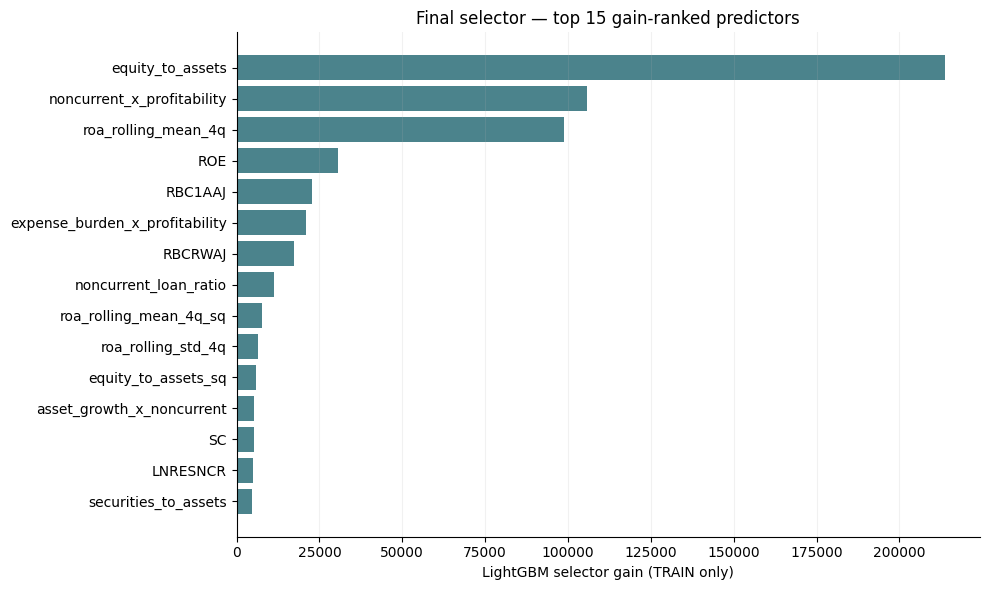

In [365]:
# VIZ ONLY — training-only ranking; no model fitting
import matplotlib.pyplot as plt
r = P4_FINAL40_RANKING.head(15).sort("gain")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(r["feature"].to_list(), r["gain"].to_list(), color="#4b838c")
ax.set_xlabel("LightGBM selector gain (TRAIN only)")
ax.set_title("Final selector — top 15 gain-ranked predictors")
ax.grid(axis="x", alpha=0.17)
ax.spines[["right", "top"]].set_visible(False)
plt.tight_layout()
plt.show()

#### Interpretation | Final Top-40 Gain Concentration `[REAL FDIC]`

Trong kết quả TRAIN 1985–2006, ba predictors đứng đầu là `equity_to_assets`, `roa_rolling_mean_4q` và `noncurrent_x_profitability`. **Top 3 chiếm 69,36%**, Top 10 chiếm **87,19%** tổng gain của 40 features được chọn. Biểu đồ cho thấy mô hình phụ thuộc nhiều vào nhóm capital/profitability/loan quality. **Đó là tần suất/giá trị cải thiện split, không phải hiệu ứng nhân quả**; redundancy còn có thể khiến gain bị phân bổ giữa các biến tương quan. Danh sách 40 feature cuối chỉ được khóa ở bước này, không thay khi dự báo Phase 5.


**Diễn giải:** `equity_to_assets`, rolling ROA, `noncurrent_x_profitability` và `ROE` tạo phần lớn gain của **selector** trên TRAIN. Gain có thiên hướng phân bổ tín hiệu giữa biến tương quan, **không diễn giải là quan hệ nhân quả**. Đồ thị này chỉ mô tả **selector fitted on TRAIN**, không phải permutation importance trên external test.

<a id="p4-draft"></a>
## Research Extension — Phase 4 Advanced Data Lab `[DRAFT]` `[DATA-FIRST]`

**Mục tiêu:** mở rộng kiểm tra *point-in-time validity, bank-quarter trajectories, missingness regime, drift* và *operational alert policy*; không sửa Final Top 40.

**Phân biệt nguồn bằng chứng:**

- **`[REAL ARCHIVED]`**: tái tính từ các output thực đã lưu của notebook; không fit lại model.
- **`[SANDBOX TEST]`**: kiểm tra công thức/logic bằng dữ liệu mô phỏng; không phải kết quả FDIC.
- **`[LOCAL TRAIN]`**: chỉ đọc TRAIN. Trong **lần chạy được lưu tại đây**, 4.15 đã chạy trên **300 CERT/18.882 bank-quarters** và 4.15B đã chạy F1 thực. Đây là diagnostics, không phải full-sample model validation.
- **`[OPTIONAL]`**: thí nghiệm chưa chạy; không được dùng để viết kết luận.

Các nhánh `P4D_*`/`P4X_*` độc lập với checkpoint `P4_FINAL40_*`. **External tests chưa được dùng trong các bước này.**


### 4.10 — Khoảng trống đáng ưu tiên và lập trường kỹ thuật  `[METHOD]`

| Độ ưu tiên | Còn thiếu / hạn chế hiện tại | Thử nghiệm bổ sung | Quyết định |
|---|---|---|---|
| **P0** | Báo cáo `REPDTE` có thể chưa công khai khi ngân hàng thất bại | **Publication-vintage audit**: xét mốc 45 ngày và event overlap | Phải làm trước mọi tuyên bố *early warning* thực tế |
| **P0** | Nhãn dự báo 4 quý có thể chưa đủ thời gian quan sát ở cuối kỳ | **Label-maturity / right-censor diagnostic** | Không gán mặc định cuối kỳ thành negative khi chưa chín muồi |
| **P0** | 4 quý positive của cùng ngân hàng không độc lập | Khoảng bất định theo ngân hàng, alert budget **mỗi quý** | Giảm ảo giác do hàng nghìn bank-quarters |
| **P1** | Rolling features hiện có chưa mô tả đủ cú sốc và tốc độ suy yếu | **19 gap-aware temporal/peer/missingness features** | Chỉ chạy branch TRAIN, giữ diễn giải kinh tế |
| **P1** | Một số trường thay đổi tỷ lệ thiếu mạnh theo giai đoạn | **Missingness-regime & PSI diagnostics** | Không nhầm thay đổi định nghĩa báo cáo là tín hiệu distress |
| **P1** | Gain concentration và biến cùng nhau làm quan trọng bị phân bổ | Gain concentration + rank-stability + **group permutation** sau này | Chưa đưa thêm wrapper dài, không đào sâu một cặp dư thừa |
| **P2** | Không có nguồn release-vintage cụ thể từng ngân hàng/quý | Thu thập dữ liệu nộp/sửa báo cáo và macro vintage | Chỉ khi nguồn thời gian đủ xác thực |

**Điều không làm trong bản này:** chạy lại MI/Spearman/RFE trên 113 predictors, random train-test split, huấn luyện thêm hàng loạt model, hoặc thay bộ Top 40 đã freeze dựa trên dữ liệu test.

**Nguồn phương pháp:** FFIEC reporting [1], financial EWMA [2], interpretable bank feature synthesis [3], bank failure methodology [4], Shapley/Borda [5], PSI caveats [6], leakage-safe financial time series lecture [7].


### 4.10A — Replay: prevalence, alert lift và độ bất định `[REAL ARCHIVED]`

Cell sử dụng kết quả **Top 40 F1–F3 hiện có** để tính `AP / prevalence` và `Precision@1% / prevalence`, cùng khoảng Wilson 95% cho **positive-bank recall**. Đây là số liệu **suy ra từ output**, không phải mô hình mới.

**Diễn giải cần thận trọng:** lift lớn ở F2/F3 phần nhiều phản ánh tỷ lệ nhãn 1 rất thấp; một số ít positive banks khiến khoảng tin cậy rộng. Wilson interval ở đây là chẩn đoán mô tả (các ngân hàng không nhất thiết độc lập). Không lấy lift hoặc sự khác biệt nhỏ về AP làm bằng chứng khả năng dự báo triển khai nếu chưa có point-in-time và external validation.


In [366]:
# [REAL ARCHIVED] F1–F3 data replay; no Parquet reads, no retraining
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def p4d_wilson(k,n,z=1.959963984540054):
    if not (0 <= k <= n and n>0):raise ValueError("0 <= k <= n required")
    p=k/n; q=z*z; denom=1+q/n
    center=(p+q/(2*n))/denom
    half=z*np.sqrt(p*(1-p)/n + q/(4*n*n))/denom
    return (center-half,center+half)

P4D_ARCHIVE_FOLDS = [{'fold': 'F1', 'features': 40, 'PR_AUC_AP': 0.31842, 'ROC_AUC': 0.984067, 'precision_at_1pct': 0.216034, 'recall_at_1pct': 0.690802, 'bank_recall_at_1pct': 0.840206, 'model': 'Selected Top 40'}, {'fold': 'F2', 'features': 40, 'PR_AUC_AP': 0.191185, 'ROC_AUC': 0.982301, 'precision_at_1pct': 0.021481, 'recall_at_1pct': 0.763158, 'bank_recall_at_1pct': 0.823529, 'model': 'Selected Top 40'}, {'fold': 'F3', 'features': 40, 'PR_AUC_AP': 0.134497, 'ROC_AUC': 0.884773, 'precision_at_1pct': 0.035533, 'recall_at_1pct': 0.552632, 'bank_recall_at_1pct': 0.695652, 'model': 'Selected Top 40'}]
P4D_FOLD_SUPPORT = {'F1': (163353, 511, 194), 'F2': (134946, 38, 17), 'F3': (118187, 76, 23)}  # (rows, positive quarters, positive CERTs)

if "P4_49E3_ALL" in globals():
    P4D_BASE = [r for r in P4_49E3_ALL.to_dicts() if r.get("model") == "Selected Top 40"]
    P4D_SOURCE = "LIVE NOTEBOOK F1–F3 RESULTS"
else:
    P4D_BASE = P4D_ARCHIVE_FOLDS
    P4D_SOURCE = "ARCHIVED REAL F1–F3 OUTPUT (LATEST UPLOAD)"

P4D_FOLD = pd.DataFrame(P4D_BASE)
P4D_FOLD = P4D_FOLD.sort_values('fold').reset_index(drop=True)
assert P4D_FOLD.fold.tolist() == ['F1','F2','F3']
for key, index in [('observations',0),('positive_quarters',1),('positive_banks',2)]:
    P4D_FOLD[key] = P4D_FOLD.fold.map(lambda f:P4D_FOLD_SUPPORT[f][index])
P4D_FOLD['prevalence'] = P4D_FOLD.positive_quarters/P4D_FOLD.observations
P4D_FOLD['AP_lift'] = P4D_FOLD.PR_AUC_AP/P4D_FOLD.prevalence
P4D_FOLD['alert_precision_lift'] = P4D_FOLD.precision_at_1pct/P4D_FOLD.prevalence
P4D_FOLD['detected_banks'] = np.rint(P4D_FOLD.bank_recall_at_1pct*P4D_FOLD.positive_banks).astype(int)
P4D_FOLD['CI_low'] = [p4d_wilson(int(r.detected_banks),int(r.positive_banks))[0] for r in P4D_FOLD.itertuples()]
P4D_FOLD['CI_high'] = [p4d_wilson(int(r.detected_banks),int(r.positive_banks))[1] for r in P4D_FOLD.itertuples()]

print('DATA PROVENANCE:',P4D_SOURCE)
print('Estimated 95% Wilson intervals are descriptive; bank failures/events are not proven IID.')
display(P4D_FOLD[['fold','prevalence','AP_lift','alert_precision_lift','detected_banks','positive_banks','CI_low','CI_high']].round(5))


DATA PROVENANCE: LIVE NOTEBOOK F1–F3 RESULTS
Estimated 95% Wilson intervals are descriptive; bank failures/events are not proven IID.


,fold,prevalence,AP_lift,alert_precision_lift,detected_banks,positive_banks,CI_low,CI_high
0,F1,0.00313,105.39889,69.45164,164,194,0.78783,0.88948
1,F2,0.00028,747.74801,76.28526,14,17,0.58971,0.93809
2,F3,0.00064,238.74808,55.25708,16,23,0.49134,0.84396


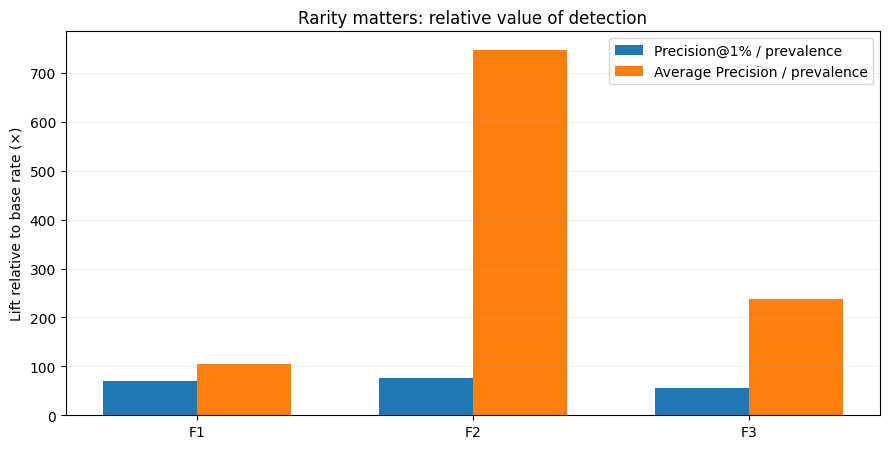

In [367]:
# [REAL ARCHIVED] Visualization: AP lift and alert precision lift
fig, ax = plt.subplots(figsize=(9, 4.6))
x = np.arange(len(P4D_FOLD))
w = .34
ax.bar(x-w/2, P4D_FOLD['alert_precision_lift'],w,label='Precision@1% / prevalence')
ax.bar(x+w/2, P4D_FOLD['AP_lift'],w,label='Average Precision / prevalence')
ax.set_xticks(x, P4D_FOLD['fold'])
ax.set_ylabel('Lift relative to base rate (×)')
ax.set_title('Rarity matters: relative value of detection')
ax.legend()
ax.grid(axis='y',alpha=.20)
plt.tight_layout(); plt.show()


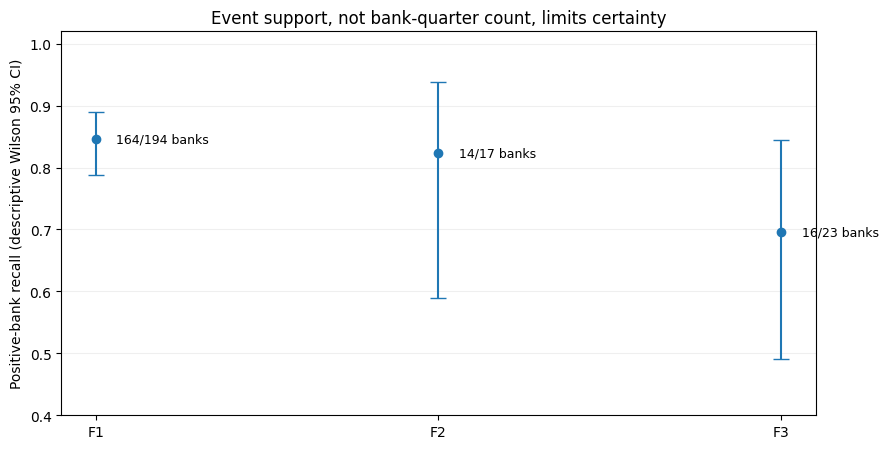

In [368]:
# [REAL ARCHIVED] Visualization: bank-level recall uncertainty
fig, ax = plt.subplots(figsize=(9, 4.6))
x = np.arange(len(P4D_FOLD))
vals=P4D_FOLD['bank_recall_at_1pct'].to_numpy(dtype=float)
lo=P4D_FOLD['CI_low'].to_numpy(dtype=float)
hi=P4D_FOLD['CI_high'].to_numpy(dtype=float)
ax.errorbar(x,vals,yerr=np.vstack([vals-lo,hi-vals]),fmt='o',capsize=6)
for i,r in enumerate(P4D_FOLD.itertuples()):
    ax.text(i+.06, r.bank_recall_at_1pct,
            f'{r.detected_banks}/{r.positive_banks} banks',va='center',fontsize=9)
ax.set_xticks(x,P4D_FOLD['fold']);ax.set_ylim(.40,1.02)
ax.set_ylabel('Positive-bank recall (descriptive Wilson 95% CI)')
ax.set_title('Event support, not bank-quarter count, limits certainty')
ax.grid(axis='y',alpha=.20)
plt.tight_layout();plt.show()


**Insight thực nghiệm:** F1 có 163/194 ngân hàng positive được cảnh báo (CI mô tả khoảng 78,2–88,5%); F2 chỉ có 14/17 ngân hàng (CI rộng **59,0–93,8%**); F3 là 16/23 ngân hàng (khoảng 49,1–84,4%). F2 có alert-precision lift cao không có nghĩa mô hình chắc chắn tốt hơn F1, do tỷ lệ positive nền rất thấp. Một `CERT` có thể lặp lại nhiều quý, nên đây **chưa phải** CI cho các failure events đã được xác minh.


In [369]:
# [REAL ARCHIVED] Pilot selection, gain concentration and selection stability
P4D_ARCHIVE_PILOT = [{'features': 20, 'PR_AUC_AP': 0.474202, 'bank_recall_at_1pct': 0.512573, 'detected_positive_banks': 265}, {'features': 40, 'PR_AUC_AP': 0.479008, 'bank_recall_at_1pct': 0.516441, 'detected_positive_banks': 267}, {'features': 60, 'PR_AUC_AP': 0.493161, 'bank_recall_at_1pct': 0.522244, 'detected_positive_banks': 270}, {'features': 113, 'PR_AUC_AP': 0.484816, 'bank_recall_at_1pct': 0.516441, 'detected_positive_banks': 267}]
P4D_ARCHIVE_GAIN = [('equity_to_assets', 238286.876638), ('roa_rolling_mean_4q', 102958.832092), ('noncurrent_x_profitability', 88759.693573), ('ROE', 24887.762737), ('expense_burden_x_profitability', 20553.945171), ('RBC1AAJ', 20543.521633), ('RBCRWAJ', 16863.413766), ('noncurrent_loan_ratio', 10842.862698), ('roa_rolling_mean_4q_sq', 7695.144201), ('roa_rolling_std_4q', 6425.674518), ('securities_to_assets', 5548.937801), ('asset_growth_x_noncurrent', 5451.93779), ('capital_x_asset_growth', 5191.775366), ('LNRESNCR', 4978.011627), ('capital_x_profitability', 4791.743958), ('SC', 4305.374884), ('RBCT1J', 3520.417706), ('DRCRCD', 3467.598285), ('LNCIT1R', 3174.485388), ('ROA', 2957.918062), ('equity_to_assets_sq', 2888.426682), ('NIMY', 2801.946383), ('BRO', 2715.518497), ('ORE', 2601.4413), ('LNRERT1R', 2437.548754), ('cash_to_assets', 2375.377016), ('core_deposit_share', 2218.098101), ('LNCDT1R', 1676.09458), ('asset_growth_4q', 1652.839809), ('capital_x_noncurrent', 1501.201204), ('LNCONT1R', 1459.191397), ('LNATRESR', 1399.620583), ('NALNLS', 1300.145279), ('deposits_to_assets', 1261.181198), ('noninterest_expense_growth_4q', 1181.684513), ('OREOTH', 1165.778202), ('deposit_growth_4q', 1153.140402), ('NTCRCD', 1126.696007), ('NCLNLS', 1050.039793), ('noninterest_expense_to_assets', 983.538099)]
P4D_ARCHIVE_SELECTION_FREQ = {3: 32, 2: 9, 1: 6}

if 'P4_49E1_RESULTS' in globals():
    P4D_PILOT = pd.DataFrame(P4_49E1_RESULTS.to_dicts())
else:
    P4D_PILOT = pd.DataFrame(P4D_ARCHIVE_PILOT)

if 'P4_FINAL40_RANKING' in globals():
    P4D_GAIN = pd.DataFrame(P4_FINAL40_RANKING.head(40).to_dicts())
else:
    P4D_GAIN = pd.DataFrame(P4D_ARCHIVE_GAIN,columns=['feature','gain'])
P4D_GAIN = P4D_GAIN.sort_values('gain',ascending=False).reset_index(drop=True)
P4D_GAIN['gain_fraction'] = P4D_GAIN['gain']/P4D_GAIN['gain'].sum()
P4D_GAIN['cumulative_fraction'] = P4D_GAIN['gain_fraction'].cumsum()

if 'P4_49E4_FREQUENCY_SUMMARY' in globals():
    P4D_SELECTION_FREQ = {int(r['frequency']):int(r['n_features']) for r in P4_49E4_FREQUENCY_SUMMARY.to_dicts()}
else:
    P4D_SELECTION_FREQ = P4D_ARCHIVE_SELECTION_FREQ

p40=P4D_PILOT.set_index('features').loc[40]
p60=P4D_PILOT.set_index('features').loc[60]
print('Selection-frequency breakdown:',P4D_SELECTION_FREQ,
      '| Union:',sum(P4D_SELECTION_FREQ.values()),
      '| Total selections:',sum(k*v for k,v in P4D_SELECTION_FREQ.items()))
print('Top 3 share of total selected-40 gain:',round(P4D_GAIN['gain_fraction'].head(3).sum()*100,2),'%')
print('Top 10 share:',round(P4D_GAIN['gain_fraction'].head(10).sum()*100,2),'%')
print('Pilot AP (60 – 40):',round(float(p60.PR_AUC_AP-p40.PR_AUC_AP),6))
print('Pilot bank detections (60 – 40):',int(p60.detected_positive_banks-p40.detected_positive_banks))
print('This is a development comparison; the frozen final 40 is NOT modified.')


Selection-frequency breakdown: {3: 32, 2: 8, 1: 8} | Union: 48 | Total selections: 120
Top 3 share of total selected-40 gain: 67.82 %
Top 10 share: 86.87 %
Pilot AP (60 – 40): 0.006765
Pilot bank detections (60 – 40): -1
This is a development comparison; the frozen final 40 is NOT modified.


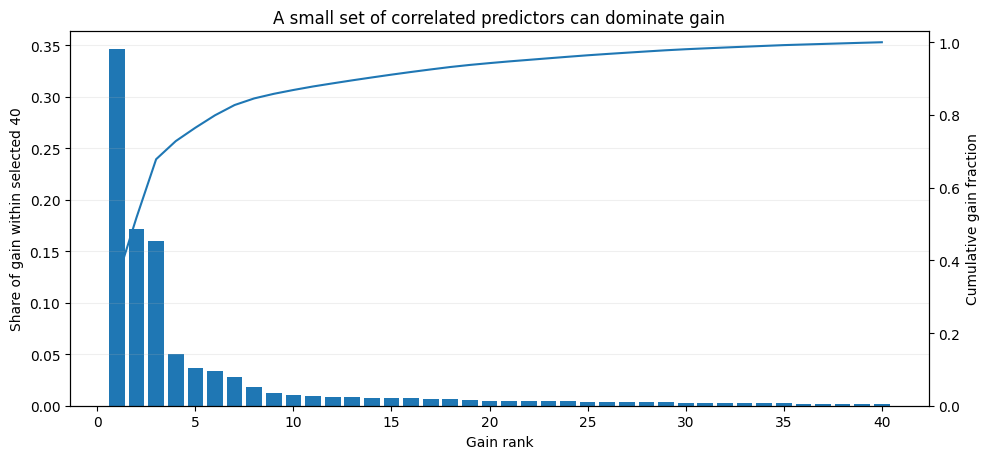

In [370]:
# [REAL ARCHIVED] Visualization: how much gain lives in the first few features
fig, ax = plt.subplots(figsize=(10,4.7))
x=np.arange(1,len(P4D_GAIN)+1)
ax.bar(x,P4D_GAIN['gain_fraction'],label='Gain fraction')
ax2=ax.twinx()
ax2.plot(x,P4D_GAIN['cumulative_fraction'],label='Cumulative gain')
ax2.set_ylim(0,1.03)
ax.set_ylabel('Share of gain within selected 40')
ax2.set_ylabel('Cumulative gain fraction')
ax.set_xlabel('Gain rank')
ax.set_title('A small set of correlated predictors can dominate gain')
ax.grid(axis='y',alpha=.2)
plt.tight_layout();plt.show()


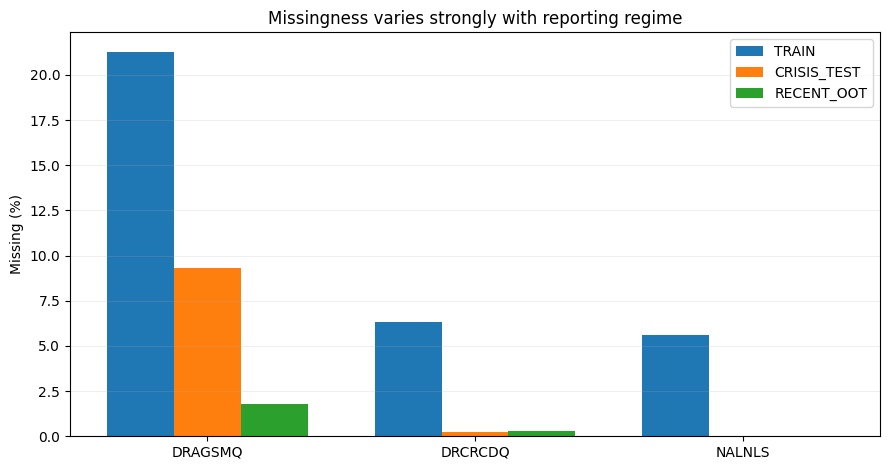

In [371]:
# [REAL ARCHIVED] Historical missingness — original Phase 4.7A output
P4D_MISSING_ARCHIVE = [{'field': 'DRAGSMQ', 'TRAIN': 21.291, 'CRISIS_TEST': 9.327, 'RECENT_OOT': 1.795}, {'field': 'DRCRCDQ', 'TRAIN': 6.341, 'CRISIS_TEST': 0.215, 'RECENT_OOT': 0.314}, {'field': 'NALNLS', 'TRAIN': 5.62, 'CRISIS_TEST': 0.0, 'RECENT_OOT': 0.0}]
if 'P4_47_MISSING_SUMMARY' in globals():
    missing_live = {r['field']:r for r in P4_47_MISSING_SUMMARY.to_dicts()}
    P4D_MISSING = pd.DataFrame([{
        'field':nm,
        'TRAIN':missing_live[nm]['train_missing_pct'],
        'CRISIS_TEST':missing_live[nm]['crisis_missing_pct'],
        'RECENT_OOT':missing_live[nm]['oot_missing_pct']}
        for nm in ['DRAGSMQ','DRCRCDQ','NALNLS']])
else:
    P4D_MISSING = pd.DataFrame(P4D_MISSING_ARCHIVE)

fig,ax=plt.subplots(figsize=(9,4.8))
x=np.arange(len(P4D_MISSING));w=.25
for k,split in enumerate(['TRAIN','CRISIS_TEST','RECENT_OOT']):
    ax.bar(x+(k-1)*w,P4D_MISSING[split],w,label=split)
ax.set_xticks(x,P4D_MISSING['field']);ax.set_ylabel('Missing (%)')
ax.set_title('Missingness varies strongly with reporting regime')
ax.legend();ax.grid(axis='y',alpha=.2)
plt.tight_layout();plt.show()


**Diễn giải:** `DRAGSMQ` thiếu khoảng 21,29% quan sát TRAIN nhưng chỉ 1,80% ở RECENT_OOT; `DRCRCDQ` từ 6,34% xuống 0,31%, và `NALNLS` từ 5,62% xuống gần 0%. Đó có thể là thay đổi reporting regime/coverage, **chưa đủ chứng minh missingness là nguyên nhân gây failure**. Việc impute tất cả các năm bằng một median sẽ làm mất thông tin về quá trình thay đổi chế độ báo cáo; ngược lại, mô hình dùng missingness indicators phải được kiểm tra tránh học lối tắt dựa trên niên đại.

**Quan điểm:** mô hình cuối đã freeze không bị chỉnh sửa; trong nghiên cứu kế tiếp nên đánh giá thêm **regime drift và tín hiệu missingness persistent**, nhưng kiểm tra theo thời gian, không chỉ theo nhãn.


<a id="p4-draft-pit"></a>
### 4.11 — Point-in-Time & Label Maturity Gate  `[SANDBOX TEST]`

**Cần phân biệt ba mốc:** `REPDTE` (ngày chốt báo cáo), ngày thông tin **có thể được tiếp cận**, và ngày kết thúc horizon bốn quý. Theo FFIEC, bulk Call Report data được cung cấp công khai bắt đầu khoảng **45 ngày sau reporting date** [1]; đây là **giả định minh họa**, không phải release-vintage chính xác của từng ngân hàng/kỳ lịch sử.

Các giá trị ở đây chỉ *audit* tính khả dụng và hậu kiểm nhãn. **Không** dùng `y` hoặc failure events để tạo features. Mọi quyết định loại bỏ/mở rộng nhãn cần đối chiếu trực tiếp `LABELS_V3`, `FAILURE_ASOF` và Phase 2 contract trước khi áp dụng.


In [372]:
# Point-in-time and label-maturity helper. No external data access.
import pandas as pd
import numpy as np
def p4d_publication_and_maturity(frame, asof, publication_lag_days=45):
    """Accounting-date vs availability-date and four-quarter outcome maturity audit."""
    df=frame[["CERT","REPDTE"]].copy()
    dt=pd.to_datetime(df["REPDTE"])
    quarter = dt.dt.to_period("Q")
    horizon = (quarter+4).dt.to_timestamp(how="end").dt.normalize()
    asof=pd.Timestamp(asof)
    df["published_assumption"] = dt+pd.to_timedelta(publication_lag_days,unit="D")
    df["label_horizon_end"] = horizon
    df["label_mature_at_asof"] = horizon.le(asof)
    return df

_example = pd.DataFrame({'CERT':[1,1,2],
                         'REPDTE':['2025-06-30','2025-09-30','2025-12-31']})
P4D_MATURITY_TOY = p4d_publication_and_maturity(_example,'2026-06-30')
assert P4D_MATURITY_TOY['label_mature_at_asof'].tolist()==[True,False,False]
print('SANDBOX TEST — Assumed as-of=2026-06-30 and publication lag=45 days')
display(P4D_MATURITY_TOY)
print('PASS — 4-quarter maturity and publication dates verified on the test fixture.')


SANDBOX TEST — Assumed as-of=2026-06-30 and publication lag=45 days


,CERT,REPDTE,published_assumption,label_horizon_end,label_mature_at_asof
0,1,2025-06-30,2025-08-14,2026-06-30,True
1,1,2025-09-30,2025-11-14,2026-09-30,False
2,2,2025-12-31,2026-02-14,2026-12-31,False


PASS — 4-quarter maturity and publication dates verified on the test fixture.


**Insight từ kiểm thử:** nếu dữ liệu chỉ được quan sát đến 2026Q2 thì nhãn bốn quý của một quan sát 2025Q3 hoặc 2025Q4 **chưa trưởng thành** theo quy tắc chín muồi này; việc coi chúng là nhãn 0 có thể tạo right-censoring bias. Kết quả mẫu **không xác nhận** dữ liệu label thực tế của bạn đã vi phạm — đây là cổng kiểm tra khi có as-of từ handoff.

**Quy tắc sản xuất:** kiểm tra failure xảy ra trước **ngày công bố báo cáo**, không chỉ sau ngày `REPDTE`; nếu có, phải định nghĩa lại thời điểm cảnh báo hoặc phạm vi nhãn theo lịch công bố thực tế [1].


<a id="p4-draft-features"></a>
### 4.12 — Gap-Aware Financial Trajectory Factory: 19 biến mới  `[SANDBOX TEST]` `[FEATURES]`

Nguồn cảm hứng là EWMA trong dự báo US bank failures [2] và **interpretable bank-specific feature synthesis** [3]. Hệ thống này chỉ dùng các trường **đã có trong TRAIN**: `ROA`, `equity_to_assets`, `noncurrent_loan_ratio`, `cash_to_assets`, `deposits_to_assets`, `deposit_growth_4q`.

| Nhóm | Ví dụ tên features | Ý nghĩa |
|---|---|---|
| **Momentum & erosion** | `roa_momentum_1q/4q`, `capital_erosion_1q/4q`, `loan_quality_deterioration_1q/4q`, `liquidity_drawdown_1q` | Tốc độ xấu đi, không chỉ mức hiện tại |
| **Persistence** | `roa_ewma_4q`, `noncurrent_ewma_4q`, `roa_negative_quarters_4q`, `roa_downside_rms_4q`, `roa_instability_4q` | Suy yếu kéo dài, biến động bất lợi |
| **Joint stress** | `joint_capital_credit_stress`, `deposit_runoff_liquidity_stress` | Hai dấu hiệu xấu xuất hiện đồng thời |
| **Data quality & regime** | `reporting_gap_quarters`, `risk_field_missing_count`, `risk_field_missing_jump_1q` | Khoảng trống và missingness thay đổi |
| **Lagged peer-relative** | `roa_vs_previous_quarter_peer`, `capital_vs_previous_quarter_peer` | So với **benchmark quý trước**, không lấy thông tin của các ngân hàng cùng quý chưa công bố |

**Rào chắn:** Lags chỉ hợp lệ nếu `CERT` có **đủ quý liên tiếp**; không tự `forward_fill()` qua các quý bị trống. Rolling EWMA dùng trọng số **8:4:2:1** (cửa sổ hữu hạn), không phải EWMA vô hạn. Peer benchmarks trên một mẫu ngân hàng chỉ là nghiên cứu; khi dùng thật cần toàn bộ panel đủ dữ liệu và kiểm soát size/composition.


In [373]:
# [SANDBOX TEST] Feature engineering with bank-specific quarter continuity
import pandas as pd
import numpy as np
P4D_BASE_COLS = ["ROA", "equity_to_assets", "noncurrent_loan_ratio",
                 "cash_to_assets", "deposits_to_assets", "deposit_growth_4q"]

def p4d_engineer_bank_quarter(frame):
    """Create retrospective, quarter-gap-aware features using only rows dated <= t.

    Reporting publication lag is NOT applied here; this is an accounting-time feature set.
    For live scoring, enforce a verified as-of date/vintage policy separately.
    """
    required = ["CERT", "REPDTE", *P4D_BASE_COLS]
    absent = sorted(set(required)-set(frame.columns))
    if absent:
        raise ValueError(f"Required fields missing: {absent}")
    df = frame[required].copy()
    df["REPDTE"] = pd.to_datetime(df["REPDTE"], errors="raise")
    if df["REPDTE"].isna().any() or not df["REPDTE"].dt.is_quarter_end.all():
        raise ValueError("REPDTE must be valid calendar quarter-end dates")
    if df[["CERT", "REPDTE"]].duplicated().any():
        raise ValueError("Duplicate CERT-REPDTE keys: resolve identity prior to rolling features")
    for f in P4D_BASE_COLS:
        df[f] = pd.to_numeric(df[f],errors="coerce").astype(float)
        df[f] = df[f].replace([np.inf, -np.inf], np.nan)
    df = df.sort_values(["CERT", "REPDTE"],kind="mergesort").reset_index(drop=True)
    date = df["REPDTE"]
    df["__quarter_id"] = date.dt.year*4 + date.dt.quarter
    group = df.groupby("CERT",sort=False)
    prevq = group["__quarter_id"].shift(1)
    df["reporting_gap_quarters"] = (df["__quarter_id"]-prevq-1).clip(lower=0)
    # A shift is valid only when the observed time gap equals its quarter lag.
    # This prevents carrying values across incomplete bank histories.
    series = ["ROA", "equity_to_assets", "noncurrent_loan_ratio", "cash_to_assets"]
    for lag in (1,2,3,4):
        contiguous = df["__quarter_id"].sub(group["__quarter_id"].shift(lag)).eq(lag)
        for name in series:
            df[f"__{name}_lag{lag}"] = group[name].shift(lag).where(contiguous)

    def lag(col,n): return df[f"__{col}_lag{n}"]
    def delta(col,n): return df[col] - lag(col,n)

    df["roa_momentum_1q"] = delta("ROA",1)
    df["roa_momentum_4q"] = delta("ROA",4)
    df["capital_erosion_1q"] = -delta("equity_to_assets",1)
    df["capital_erosion_4q"] = -delta("equity_to_assets",4)
    df["loan_quality_deterioration_1q"] = delta("noncurrent_loan_ratio",1)
    df["loan_quality_deterioration_4q"] = delta("noncurrent_loan_ratio",4)
    df["liquidity_drawdown_1q"] = -delta("cash_to_assets",1)

    roa4 = pd.concat([df["ROA"],lag("ROA",1),lag("ROA",2),lag("ROA",3)],axis=1)
    nc4 = pd.concat([df["noncurrent_loan_ratio"],lag("noncurrent_loan_ratio",1),lag("noncurrent_loan_ratio",2),lag("noncurrent_loan_ratio",3)],axis=1)
    full_roa=roa4.notna().all(axis=1)
    full_nc=nc4.notna().all(axis=1)
    df["roa_ewma_4q"] = roa4.mul([8,4,2,1],axis=1).sum(axis=1).div(15).where(full_roa)
    df["noncurrent_ewma_4q"] = nc4.mul([8,4,2,1],axis=1).sum(axis=1).div(15).where(full_nc)
    df["roa_downside_rms_4q"] = np.sqrt(roa4.clip(upper=0).pow(2).mean(axis=1)).where(full_roa)
    df["roa_negative_quarters_4q"] = roa4.lt(0).sum(axis=1).astype(float).where(full_roa)
    df["roa_instability_4q"] = roa4.std(axis=1,ddof=0).where(full_roa)

    df["joint_capital_credit_stress"] = np.maximum(df["capital_erosion_1q"],0)*np.maximum(df["loan_quality_deterioration_1q"],0)
    df["deposit_runoff_liquidity_stress"] = np.maximum(-df["deposit_growth_4q"],0)*np.maximum(1-df["cash_to_assets"],0)
    df["risk_field_missing_count"] = df[P4D_BASE_COLS[:5]].isna().sum(axis=1)
    df["risk_field_missing_jump_1q"] = df["risk_field_missing_count"]-group["risk_field_missing_count"].shift(1).where(df["__quarter_id"].sub(prevq).eq(1))

    # Peer benchmark for quarter t is the historical cross-sectional median from t-1.
    # Does not use current-quarter reports from other banks.
    peer = df.groupby("__quarter_id",as_index=False)[["ROA", "equity_to_assets"]].median()
    peer["__quarter_id"] += 1
    peer = peer.rename(columns={"ROA":"__peer_prev_roa", "equity_to_assets":"__peer_prev_capital"})
    df = df.merge(peer,on="__quarter_id",how="left",validate="many_to_one")
    df["roa_vs_previous_quarter_peer"] = df["ROA"]-df["__peer_prev_roa"]
    df["capital_vs_previous_quarter_peer"] = df["equity_to_assets"]-df["__peer_prev_capital"]

    new_features=["reporting_gap_quarters", "roa_momentum_1q", "roa_momentum_4q", "capital_erosion_1q", "capital_erosion_4q", "loan_quality_deterioration_1q", "loan_quality_deterioration_4q", "liquidity_drawdown_1q", "roa_ewma_4q", "noncurrent_ewma_4q", "roa_downside_rms_4q", "roa_negative_quarters_4q", "roa_instability_4q", "joint_capital_credit_stress", "deposit_runoff_liquidity_stress", "risk_field_missing_count", "risk_field_missing_jump_1q", "roa_vs_previous_quarter_peer", "capital_vs_previous_quarter_peer"]
    return df[["CERT", "REPDTE", *new_features]].copy(),new_features


In [374]:
# [SANDBOX TEST] Two banks, 5 quarters, deliberate missing quarter for Bank B
_q=pd.to_datetime(['2020-03-31','2020-06-30','2020-09-30','2020-12-31','2021-03-31'])
_rows=[]
for t,roa in enumerate([2.,1.,-1.,-2.,-3.]):
    _rows.append(dict(CERT='A',REPDTE=_q[t],ROA=roa,
                      equity_to_assets=.10-.01*t,
                      noncurrent_loan_ratio=.02+.01*t,
                      cash_to_assets=.20-.02*t,
                      deposits_to_assets=.8,deposit_growth_4q=-.02))
for t in [0,2,3]:
    _rows.append(dict(CERT='B',REPDTE=_q[t],ROA=1.,
                      equity_to_assets=.15,noncurrent_loan_ratio=.01,
                      cash_to_assets=.3,deposits_to_assets=.65,
                      deposit_growth_4q=.03))
P4D_TOY_INPUT=pd.DataFrame(_rows)
P4D_TOY_FEATS,P4D_NEW_FEATURES=p4d_engineer_bank_quarter(P4D_TOY_INPUT)
_a=P4D_TOY_FEATS.query("CERT == 'A'").reset_index(drop=True)
_b=P4D_TOY_FEATS.query("CERT == 'B'").reset_index(drop=True)
assert len(P4D_NEW_FEATURES)==19
assert np.isclose(_a.loc[3,'roa_ewma_4q'],(-16-4+2+2)/15)
assert _a.loc[3,'roa_negative_quarters_4q']==2
assert np.isclose(_a.loc[4,'capital_erosion_4q'],.04)
assert _b.loc[1,'reporting_gap_quarters']==1
assert pd.isna(_b.loc[1,'roa_momentum_1q'])
assert pd.isna(_b.loc[2,'roa_ewma_4q'])
assert P4D_TOY_INPUT.shape==(8,8)  # Input frame remains unchanged
print('PASS — 19-feature factory, temporal gap guards, EWMA and original input integrity.')
display(P4D_TOY_FEATS[['CERT','REPDTE','reporting_gap_quarters',
    'roa_ewma_4q','roa_negative_quarters_4q','capital_erosion_4q']])


PASS — 19-feature factory, temporal gap guards, EWMA and original input integrity.


,CERT,REPDTE,reporting_gap_quarters,roa_ewma_4q,roa_negative_quarters_4q,capital_erosion_4q
0,A,2020-03-31,NaN,NaN,NaN,NaN
1,A,2020-06-30,0.0,NaN,NaN,NaN
2,A,2020-09-30,0.0,NaN,NaN,NaN
3,A,2020-12-31,0.0,-1.066667,2.0,NaN
4,A,2021-03-31,0.0,-2.200000,3.0,0.04
5,B,2020-03-31,NaN,NaN,NaN,NaN
6,B,2020-09-30,1.0,NaN,NaN,NaN
7,B,2020-12-31,0.0,NaN,NaN,NaN


**Kết quả kỹ thuật:** kiểm thử đã phát hiện đúng khoảng trống của ngân hàng B (thiếu 2020Q2), không tạo momentum 1 quý giả giữa 2020Q1 và 2020Q3, và không tính EWMA khi chưa đủ bốn quý liên tiếp. Ngân hàng A có thể tính EWMA và mức erosion sau khi đủ lịch sử. **Không có PR-AUC thật** cho 19 features này vì chưa có Parquet tại môi trường chạy thử.


<a id="p4-draft-drift"></a>
### 4.13 — Population Drift: PSI có missing bucket  `[SANDBOX TEST]`

Thay vì winsorize hoặc impute hàng loạt, ta kiểm tra **phân phối quan sát có đổi không**. PSI dùng *bin edges* tạo từ reference TRAIN rồi áp vào kỳ sau, và phải tính **NaN như một bucket riêng**. Không dùng cứng ngưỡng 0.1/0.25 để quyết định mô hình tốt/xấu: nghiên cứu PSI chỉ ra các ngưỡng đó có thể không phù hợp với danh mục nhỏ hoặc thay đổi cơ cấu [6].


In [375]:
# [SANDBOX TEST] PSI with fixed reference quantile bins, NaN bucket
import numpy as np
def p4d_psi(reference, candidate, bins=10, eps=1e-6):
    """Population Stability Index with TRAIN-fitted bin edges and explicit NaN bucket.
    Diagnostic only; fixed PSI thresholds cannot establish causal drift or predictive harm.
    """
    x=np.asarray(reference,dtype=float)
    y=np.asarray(candidate,dtype=float)
    x=x[np.isfinite(x) | np.isnan(x)]
    y=y[np.isfinite(y) | np.isnan(y)]
    finite=x[np.isfinite(x)]
    if finite.size<max(5,bins):return float('nan')
    edges=np.unique(np.quantile(finite, np.linspace(0,1,bins+1))[1:-1])
    # Use numpy histogram with common bin edges; outliers fall in edge bins.
    qx=np.r_[np.searchsorted(edges,x[np.isfinite(x)],side='right'), np.full(np.isnan(x).sum(),len(edges)+1,dtype=int)]
    qy=np.r_[np.searchsorted(edges,y[np.isfinite(y)],side='right'), np.full(np.isnan(y).sum(),len(edges)+1,dtype=int)]
    minlength=len(edges)+2
    p=np.bincount(qx,minlength=minlength).astype(float)
    q=np.bincount(qy,minlength=minlength).astype(float)
    p=(p+eps)/(p.sum()+eps*minlength)
    q=(q+eps)/(q.sum()+eps*minlength)
    return float(np.sum((q-p)*np.log(q/p)))

_rng=np.random.default_rng(2026)
_p4d_ref=_rng.normal(size=50000)
_psi_identical=p4d_psi(_p4d_ref,_p4d_ref.copy())
_psi_shifted=p4d_psi(_p4d_ref,_p4d_ref+1.0)
assert abs(_psi_identical)<1e-10 and _psi_shifted>.5
print('PASS — PSI sanity tests: identical distribution ≈ 0; simulated +1 SD shift detected.')
print('Toy PSI identical:',round(_psi_identical,6),'| Toy PSI +1SD:',round(_psi_shifted,6))
print('WARNING: toy values are NOT FDIC population drift results.')


PASS — PSI sanity tests: identical distribution ≈ 0; simulated +1 SD shift detected.
Toy PSI identical: 0.0 | Toy PSI +1SD: 0.930589


<a id="p4-draft-ops"></a>
### 4.14 — Operational Alert Budgets: Top 1% **mỗi quý**  `[SANDBOX TEST]`

Bộ kiểm định cũ chọn Top 1% trên **toàn bộ validation window**, nhưng cơ quan giám sát không biết sẵn toàn bộ kỳ tương lai khi phát cảnh báo. Với reporting data theo quý, cần kiểm tra **Top 1% trong từng `REPDTE`**, định nghĩa capacity là `ceil(0.01 × số ngân hàng hoạt động trong quý)`.

Theo nghiên cứu US bank failure với CAMELS, *operating-point analysis* giúp hiểu chi phí false alarms mà ROC-AUC/AP không biểu diễn trực tiếp [4]. Không thay calibration hay threshold cuối; đây là **một phương pháp đánh giá khác** cần áp dụng trong Phase 5 và trong dev folds.


In [376]:
# [SANDBOX TEST] Quarter-specific alert capacity, tie-broken by CERT
def p4d_per_quarter_alerts(frame, budget=0.01):
    """Top ceil(budget * active banks) independently in each reporting quarter."""
    if not 0 < budget <= 1:raise ValueError("budget must be in (0,1]")
    df=frame[["CERT","REPDTE","score","y"]].copy()
    if df[["CERT","REPDTE"]].duplicated().any():
        raise ValueError("Duplicate bank-quarter keys")
    df["REPDTE"]=pd.to_datetime(df["REPDTE"])
    df=df.sort_values(["REPDTE","score","CERT"],ascending=[True,False,True],kind="mergesort")
    df["alert_budget"] = df.groupby("REPDTE")["CERT"].transform("size").mul(budget).apply(np.ceil).astype(int)
    df["rank_in_quarter"] = df.groupby("REPDTE").cumcount()+1
    df["alert"] = df["rank_in_quarter"].le(df["alert_budget"])
    return df.sort_values(["REPDTE","CERT"],kind="mergesort").reset_index(drop=True)

_alarm_toy=pd.DataFrame({
    'CERT':['A','B','C','A','B','C'],
    'REPDTE':['2020-03-31']*3+['2020-06-30']*3,
    'score':[.91,.8,.7,.8,.9,.7],
    'y':[1,0,0,1,0,0]
})
_alarm_q=p4d_per_quarter_alerts(_alarm_toy,budget=.34)
assert int(_alarm_q['alert'].sum())==4  # 2 alerts/quarter x 2 quarters
_global_budget=int(np.ceil(.34*len(_alarm_toy)))
assert _global_budget==3
print('PASS — per-quarter vs whole-window budget differ on toy fixture.')
print('Per-quarter alerts:',int(_alarm_q.alert.sum()),
      '| Whole-window alerts:',_global_budget)
display(_alarm_q[['REPDTE','CERT','score','alert_budget','rank_in_quarter','alert']])


PASS — per-quarter vs whole-window budget differ on toy fixture.
Per-quarter alerts: 4 | Whole-window alerts: 3


,REPDTE,CERT,score,alert_budget,rank_in_quarter,alert
0,2020-03-31,A,0.91,2,1,True
1,2020-03-31,B,0.80,2,2,True
2,2020-03-31,C,0.70,2,3,False
3,2020-06-30,A,0.80,2,2,True
4,2020-06-30,B,0.90,2,1,True
5,2020-06-30,C,0.70,2,3,False


**Điểm mới không được nhầm:** Top 1% theo quý có thể tạo nhiều/ít số cảnh báo tổng cộng khác so với Top 1% trên toàn window do làm tròn, và cũng tạo thứ tự ưu tiên khác. Biểu đồ/metric F1–F3 trước đây vẫn là *whole-window retrospective diagnostics*; không được gọi chúng là *quarter-by-quarter supervisory capacity*.


<a id="p4-draft-train"></a>
### 4.15 — Local TRAIN-Only Feasibility Check `[LOCAL TRAIN]`

Cell chỉ đọc **TRAIN** và không retrain Final Top 40. Trong **output hiện tại**, đã chọn **300 ngân hàng** và giữ **18.882 bank-quarters** để đo coverage thực của 19 feature candidates. Coverage quan sát được khoảng **93,45%–100%** trong mẫu: các biến cần đủ lịch sử bốn quý có coverage thấp hơn các biến chỉ cần báo cáo hiện tại.

**Giới hạn:** mẫu nhỏ không đại diện cơ cấu FDIC toàn quốc; peer medians tính trên mẫu không được dùng làm feature cho model cuối. Coverage cao **không chứng minh feature tăng PR-AUC/Recall**. Đây là feasibility test trên dữ liệu thật, không phải experiment chọn lại model.


In [377]:
# [LOCAL TRAIN] Run on user's TRAIN Parquet if Phase 4 objects are present.
# No external split / feature selection / estimator fitting.
P4D_RUN_LOCAL_TRAIN = ('P4_48E_PIPELINES' in globals()) and ('pl' in globals())
P4D_LOCAL_N_BANKS = 300

if not P4D_RUN_LOCAL_TRAIN:
    print('SKIPPED (sandbox): native FDIC Parquet is not supplied here.')
    print('After running Phase 4 on the original Windows project, rerun this cell for REAL TRAIN coverage.')
else:
    import gc
    _p4d_lf=P4_48E_PIPELINES['TRAIN']['A1_native_raw']
    _p4d_cols=['CERT','REPDTE',*P4D_BASE_COLS]
    _p4d_missing=set(_p4d_cols)-set(_p4d_lf.collect_schema().names())
    assert not _p4d_missing, f'Missing train fields: {_p4d_missing}'
    _p4d_certs=(_p4d_lf.select('CERT').unique().sort('CERT').head(P4D_LOCAL_N_BANKS)
                    .collect(engine='streaming')['CERT'].to_list())
    _p4d_pl=(_p4d_lf.filter(pl.col('CERT').is_in(_p4d_certs))
              .select(_p4d_cols).collect(engine='streaming'))
    _p4d_panel=pd.DataFrame({c:_p4d_pl[c].to_numpy() for c in _p4d_cols})
    del _p4d_pl
    P4D_TRAIN_FEATURE_SAMPLE,P4D_NEW_FEATURES=p4d_engineer_bank_quarter(_p4d_panel)
    P4D_TRAIN_FEATURE_COVERAGE=pd.DataFrame({
        'feature':P4D_NEW_FEATURES,
        'coverage_pct':[100*P4D_TRAIN_FEATURE_SAMPLE[c].notna().mean() for c in P4D_NEW_FEATURES]
    }).sort_values('coverage_pct')
    print('REAL TRAIN ONLY — sampled bank count:',len(_p4d_certs),
          '| bank-quarter rows:',len(_p4d_panel))
    display(P4D_TRAIN_FEATURE_COVERAGE.round(2))
    _years=pd.to_datetime(_p4d_panel['REPDTE']).dt.year
    _early=_p4d_panel.loc[_years.between(1985,1990),'ROA'].dropna()
    _late=_p4d_panel.loc[_years.between(2001,2006),'ROA'].dropna()
    if len(_early)>100 and len(_late)>100:
        print('PSI(ROA, early TRAIN vs late TRAIN):',
              round(p4d_psi(_early,_late),4),
              '| exploratory subset only; not whole-population drift')
    else:
        print('PSI skipped: selected banks have insufficient observations in one window')
    del _p4d_panel,_p4d_lf,_p4d_certs
    gc.collect()


REAL TRAIN ONLY — sampled bank count: 300 | bank-quarter rows: 18882


,feature,coverage_pct
6,loan_quality_deterioration_4q,93.45
2,roa_momentum_4q,93.74
4,capital_erosion_4q,93.74
9,noncurrent_ewma_4q,95.00
11,roa_negative_quarters_4q,95.29
10,roa_downside_rms_4q,95.29
8,roa_ewma_4q,95.29
12,roa_instability_4q,95.29
5,loan_quality_deterioration_1q,98.14
13,joint_capital_credit_stress,98.14


PSI(ROA, early TRAIN vs late TRAIN): 0.0627 | exploratory subset only; not whole-population drift


#### Interpretation | 19 trajectory features — kiểm tra khả thi trên TRAIN `[REAL FDIC SAMPLE]`

Ở mẫu **300 CERT / 18.882 bank-quarters**, coverage dao động **93,45%–100%**. Các chỉ số `loan_quality_deterioration_4q` và `roa_momentum_4q` thiếu nhiều hơn vì cần dữ liệu từ bốn quý trước; việc thiếu đúng ở các chuỗi ngắt quãng là **hành vi mong đợi của gap-aware lags**, không nên điền 0 một cách cơ học. `PSI(ROA)=0,0627` chỉ phản ánh **mẫu exploratory này**, không đại diện drift toàn bộ các ngân hàng. Các feature mới **chưa được fit để kiểm tra PR-AUC FDIC**.


### 4.15B — Kiểm định chính sách cảnh báo theo quý (F1) `[LOCAL TRAIN]`

Dùng lại **fitted F1 development model** và dữ liệu validation 1992–1994; **không** fit lại. So sánh hai cách cấp phát cùng mức 1%: (i) lấy Top1% **toàn bộ giai đoạn** và (ii) lấy Top1% **riêng mỗi quý báo cáo**. Hai chính sách không tương đương: số alert có thể lệch vài dòng do `ceil` theo quý.

Đây là đánh giá **policy/operating point**, không phải mô hình mới, không phải external test. Phần diễn giải và trade-off đặt ngay sau output.


In [378]:
# [LOCAL TRAIN] Re-score F1 1992–1994 only when its fitted model exists.
P4D_RUN_DEV_ALERT = all(k in globals() for k in [
    'P4_49E2_MODEL','P4_49E2_TOP40','P4_48E_PIPELINES','pl'])
if not P4D_RUN_DEV_ALERT:
    print('SKIPPED (sandbox): F1 fitted model/data not provided.')
else:
    import gc
    _lf=P4_48E_PIPELINES['TRAIN']['A1_native_raw']
    _cols=['CERT','REPDTE','y_failure_4q_v3',*P4_49E2_TOP40]
    _pl=(_lf.filter(pl.col('__year').is_between(1992,1994))
         .select(_cols).collect(engine='streaming'))
    _X=_pl.select(P4_49E2_TOP40).to_numpy().astype(np.float32,copy=False)
    _score=P4_49E2_MODEL.predict_proba(_X)[:,1]
    _dev=pd.DataFrame({'CERT':_pl['CERT'].to_numpy(),
        'REPDTE':_pl['REPDTE'].to_numpy(),
        'score':_score, 'y':_pl['y_failure_4q_v3'].to_numpy()})
    assert _dev[['CERT','REPDTE']].duplicated().sum()==0
    _per=p4d_per_quarter_alerts(_dev,.01)
    _k=max(1,int(np.ceil(len(_dev)*.01)))
    _gl=_dev.sort_values(['score','CERT'],ascending=[False,True],kind='mergesort').head(_k)
    _n=int(_dev['y'].sum());_positive_banks=_dev.loc[_dev.y.eq(1),'CERT'].nunique()
    _p_hit=_per.loc[_per.alert & _per.y.eq(1)]
    _g_hit=_gl.loc[_gl.y.eq(1)]
    P4D_DEV_ALERT_COMPARISON=pd.DataFrame([
        {'policy':'Whole-window retrospective 1%','alerts':_k,
         'positive_quarter_recall':len(_g_hit)/_n,
         'positive_bank_recall':_g_hit.CERT.nunique()/_positive_banks},
        {'policy':'Per-reporting-quarter 1%','alerts':int(_per.alert.sum()),
         'positive_quarter_recall':len(_p_hit)/_n,
         'positive_bank_recall':_p_hit.CERT.nunique()/_positive_banks}
    ])
    print('REAL F1 DEVELOPMENT DATA — not external test')
    display(P4D_DEV_ALERT_COMPARISON)
    del _pl,_X,_score,_dev,_per,_gl,_p_hit,_g_hit
    gc.collect()


REAL F1 DEVELOPMENT DATA — not external test


,policy,alerts,positive_quarter_recall,positive_bank_recall
0,Whole-window retrospective 1%,1634,0.694716,0.845361
1,Per-reporting-quarter 1%,1639,0.657534,0.829897


#### Interpretation | Cùng mô hình, khác ngân sách cảnh báo `[REAL F1]`

| Policy | Alerts | Positive-quarter Recall | Distinct-positive-bank Recall |
|---|---:|---:|---:|
| Top1% toàn validation window | **1.634** | **69,08%** | **84,02%** |
| Top1% mỗi reporting quarter | **1.639** | **65,17%** | **83,51%** |

**Insight:** Dù số alerts gần tương đương, việc bắt buộc phân bổ theo mỗi quý làm giảm recall; không thể lấy hết ngân sách ở các quý nhiều rủi ro như cách xếp hạng hồi cứu toàn kỳ. Đây là **trade-off của chính sách giám sát**, không phải bằng chứng mô hình bị overfit. Phase 5 cần báo cáo cả hai để có đối chiếu và khả năng vận hành.


<a id="p4-draft-conclusion"></a>
### 4.16 — Tổng kết nhánh dữ liệu mở rộng `[DECISION]` `[REAL + SANDBOX]`

**Đã có kết quả trên FDIC hoặc output thật trong lần chạy này:**

- Top-40 selection qua F1–F3: **33/40** biến lặp lại ở cả ba folds; union **48**. Tính ổn định cao về *selection* không có nghĩa importance rank ổn định tuyệt đối.
- **69,36%** tổng gain của Final Top 40 tập trung ở **ba predictors đứng đầu**, **87,19%** ở Top 10. Gain phản ánh cách LightGBM phân tách, không chứng minh hiệu ứng nhân quả hay đóng góp độc lập của mỗi biến.
- Pilot Top 40 có **AP 0,480440**, Top 60 **0,473705** (Top 60 − Top 40 = **−0,006735**); Top 40 phát hiện **267/517** positive banks so với **264/517** của Top 60. Top 20 nhỉnh hơn Top 40 một chút về AP, nên không nói K=40 tối ưu tuyệt đối.
- F1 policy check trên dữ liệu thật: **whole-window 1%** đạt quarter recall **69,08%**, bank recall **84,02%** (1.634 alerts); **per-quarter 1%** đạt **65,17%** và **83,51%** (1.639 alerts). Triển khai thực tế phải tính capacity theo quý, không biết trước mọi quý của tương lai.
- 19 temporal features có coverage **93,45–100%** trên **300 banks / 18.882 TRAIN bank-quarters**. Đây là kiểm tra khả thi, **chưa có một mô hình FDIC mới nào chứng minh tăng PR-AUC từ 19 biến**.

**Kiểm thử mô phỏng:** logic gap-aware lags/EWMA, nhãn đủ bốn quý để kết luận, reporting lag, PSI có missing bucket và ba stress interactions đã vượt smoke tests; không được gọi là validation dự báo FDIC.

**Ưu tiên khoa học:** xác nhận nguồn dữ liệu *as-of*, nhãn 4Q có maturity, và đo hiệu quả cảnh báo theo ngân sách vận hành. **Kết quả Native vs Median thực tế được trình bày ở 4.18B**, không được suy trước từ thay đổi phân phối. Những phát hiện này không tự động thay Final Top 40 đã đóng băng.

#### Tài liệu nghiên cứu / nguồn đối chiếu

1. **FFIEC — Central Data Repository Public Data Distribution:** [Public Call Reports, bulk availability (~45 days after reporting date)](https://cdr.ffiec.gov/Public/HelpFiles/WelcomeAdditionalInfo.htm).
2. **Ben Mrad et al. (2025), Finance Research Letters:** [*Predicting U.S. bank failures and stress testing with machine learning algorithms* — EWMA financial features](https://doi.org/10.1016/j.frl.2025.106802).
3. **Big Data Research (2025):** [*Efficient, interpretable and automated feature engineering for bank data*](https://doi.org/10.1016/j.bdr.2025.100524).
4. **Umapathy (2026), SSRN:** [*Predicting U.S. Bank Failures Using Machine Learning on CAMELS-Based Financial Data* — operating points and 4-quarter outcome](https://papers.ssrn.com/sol3/papers.cfm?abstract_id=6745778).
5. **Etemadi et al. (2024):** [*Developing an Early Warning System for Financial Networks* — Shapley and modified Borda](https://pmc.ncbi.nlm.nih.gov/articles/PMC11432077/).
6. **Operations Research (2026):** [*The population resemblance statistic: a chi-square measure of fit for banking* — limits of fixed PSI thresholds](https://link.springer.com/article/10.1007/s10479-025-07024-6).
7. **Course material:** `07_L03_TimeSeries_ML_preview.pdf` (pp. 2–3: lag-only features, temporal splits; pp. 42+ if relevant to purge/embargo), `05_L02_Feature_selection.pdf` (pp. 2–3: filter, wrapper, embedded and leakage controls), `03_L02_Data_clearning.pdf` (missingness and train-only preparation).
8. **Li et al. (2026):** [*Two-Stage feature selection for early warning of default risk* — MIC and modified sequential backward selection](https://doi.org/10.1016/j.knosys.2026.115790).
9. **Rakesh et al. (2026):** [*Systematic hybrid feature selection using optimal filter classifier pairing and parallel evaluation*](https://doi.org/10.1038/s41598-026-56564-9).
10. **Shakiba (2026):** [*Explaining and Predicting U.S. Bank Failures, 2001–2024* — reporting-regime and specification instability](https://scholarship.claremont.edu/cmc_theses/4080/).

**Handoff vẫn như cũ:** `P4_FINAL40_MODEL`, `P4_FINAL40_FIELDS`, checkpoint/metadata và `A1_native_raw`. **Không** dùng `P4D_*` thay vào 40 features trong Phase 5 nếu chưa thiết kế thử nghiệm riêng và đóng băng lại bằng TRAIN-only development.


<a id="p4-merge"></a>
## 4.17 — Reconciliation of original notebook and research draft `[MERGE AUDIT]`

**File nền:** “nháp” (265 cells, gồm 4.10–4.16). **File tham chiếu:** `kkk(2).ipynb` (147 cells). Theo kiểm toán gộp đã ghi, 9.922/9.942 dòng code có ý nghĩa trùng văn bản, 20 dòng khác là các sửa có chủ đích (restore nhãn/windows, bỏ `assert` hardcoded). Không phát hiện thuật toán cũ bị bỏ đi trong đối chiếu đó.

**Lưu ý provenance:** `kkk(2)`, bản “nháp” trước và **lần chạy hiện tại** không phải một execution snapshot. Selection stability lần này là **33/40 (union 48)**, không phải 31 hoặc 32/40 của các bản khác. Vì vậy phải ưu tiên output đi kèm **đúng notebook đang báo cáo**; không trộn metrics, model checkpoint hay feature inventories giữa các lần chạy.

**Các nhận xét nghiệp vụ từ bản gốc vẫn hữu ích:** trong các cặp dữ liệu matched/nonmissing đã kiểm toán, một số annualized fields bằng 4 lần giá trị quarterly (`NTLNLSQA/NTLNLSQ`, `NONIIQA/NONIIQ`, `NONIXQA/NONIXQ`, `NTREQA/NTREQ`). `NTLNLSQR` và `NTLNLSR` có reporting horizons khác nhau; không loại chỉ vì tương quan cao. Thay đổi định nghĩa báo cáo quanh năm 2001 cần xác minh nguồn gốc, không tự suy từ một correlation plot.

**Quy tắc:** các thử nghiệm mới ở dưới không sửa code, thứ tự hay checkpoint của Phase 4 trước đó.


<a id="p4-impute"></a>
## 4.18 — Matched Native Missing vs TRAIN-fitted Median Imputation `[CONTROLLED EXPERIMENT]`

### Câu hỏi nghiên cứu

Imputation có làm thay đổi **khả năng cảnh báo ngân hàng thất bại** hay chỉ làm biến đổi phân phối số liệu? Vì LightGBM có cơ chế học từ missingness, điền median có thể mất tín hiệu. So sánh ở **cùng 40 biến đã được chọn trong *training* của mỗi F1–F3**, trên cùng bank-quarters, cùng tham số và cùng budget. Thêm nhánh *median + missing indicators* để kiểm tra mất tín hiệu missingness.

| Nhánh | Features | Fit imputer | Ý nghĩa |
|---|---|---|---|
| `NATIVE` | Fold Top 40 + NaN | Không fit | Baseline cùng dữ liệu |
| `MEDIAN` | Fold Top 40 + median | **Chỉ trên fold TRAIN** | Tác động thuần của điền thiếu |
| `MEDIAN_MASK` | 40 giá trị median + 40 cờ null (80 cols) | **Chỉ trên fold TRAIN** | Impute nhưng giữ tín hiệu missingness |

**Bẫy leakage cần tránh:** `P4_48E_PIPELINES['TRAIN']['A2_imputed_raw']` là pipeline đã fit từ **toàn TRAIN 1985–2006**, chỉ hợp lệ khi tạo challenger cuối cùng cho test. Không lấy trực tiếp A2 làm dữ liệu F1–F3, vì median sẽ phản ánh 1992–2006. Thí nghiệm dưới đây tái hiện *đúng chính sách median của A2*, nhưng tính median **mới trong từng training window**.

**Không đọc CRISIS_TEST/RECENT_OOT**, không chạm `P4_FINAL40_MODEL`/`P4_FINAL40_FIELDS`. So sánh ở development folds có ít positive banks; không lựa chọn model bằng test.


### 4.18A — Imputation thay đổi dữ liệu như thế nào? `[REAL FDIC OUTPUT]`

Output kiểm toán Phase 4.7E/4.7F trên **94 predictors trước feature engineering** có **3.998.653 ô thiếu trong TRAIN** ở nhánh Native, còn **0** trong nhánh Median đã kiểm tra. Các trường có tác động lớn gồm `DRAGSMQ`, `NTAGSMQ`, `NTAGSMA`, `DRAGSM`, `NTAGSM`.

**Insight:** Điền đủ missing không đồng nghĩa thông tin tốt hơn: median có thể tập trung nhiều quan sát tại cùng một giá trị, làm giảm phân tán và che dấu missingness. Vì vậy bước này chỉ chứng minh **thay đổi phân phối**. Khả năng dự báo phải đọc ở **4.18B**, nơi mỗi training fold tự fit median để tránh leakage.


REAL ARCHIVED FDIC: TRAIN missing cells, Native = 3998653 | Median = 0
Most affected observed fields: DRAGSMQ, NTAGSMQ, NTAGSMA, DRAGSM, NTAGSM


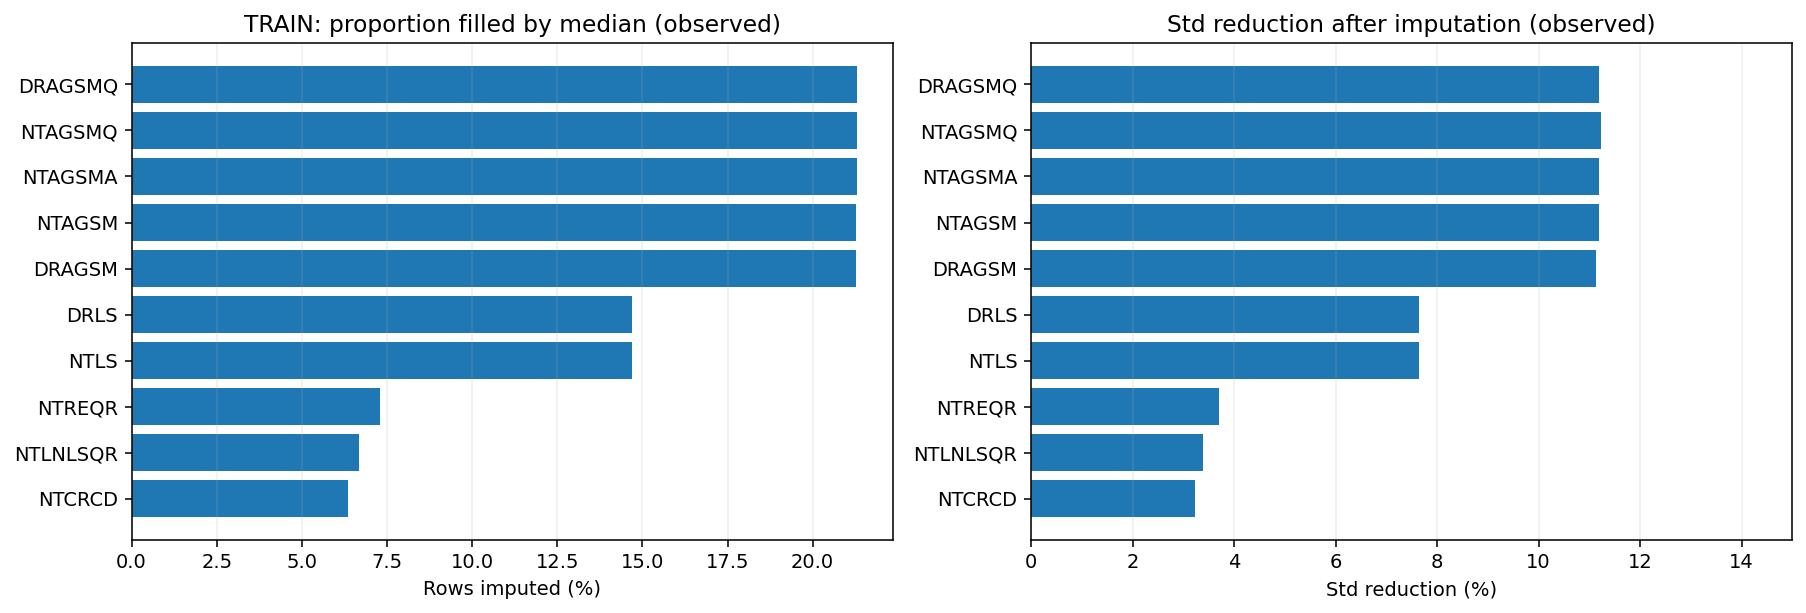

In [379]:
# REAL ARCHIVED FDIC OUTPUT — extracted from original Phase 4.7E / 4.7F cells.
# No Parquet reads / no fitting. Not a model-performance comparison.
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
P4X_IMPUTE_ARCHIVE = pd.DataFrame([{'field': 'DRAGSMQ', 'imputed_pct': 21.291, 'zero_before_pct': 91.156, 'zero_after_pct': 93.039, 'std_ratio': 0.888107}, {'field': 'NTAGSMQ', 'imputed_pct': 21.291, 'zero_before_pct': 85.217, 'zero_after_pct': 88.364, 'std_ratio': 0.887736}, {'field': 'NTAGSMA', 'imputed_pct': 21.291, 'zero_before_pct': 81.363, 'zero_after_pct': 85.331, 'std_ratio': 0.888011}, {'field': 'DRAGSM', 'imputed_pct': 21.279, 'zero_before_pct': 87.414, 'zero_after_pct': 90.092, 'std_ratio': 0.888761}, {'field': 'NTAGSM', 'imputed_pct': 21.279, 'zero_before_pct': 81.312, 'zero_after_pct': 85.288, 'std_ratio': 0.888142}, {'field': 'NTLS', 'imputed_pct': 14.706, 'zero_before_pct': 96.639, 'zero_after_pct': 97.133, 'std_ratio': 0.923574}, {'field': 'DRLS', 'imputed_pct': 14.706, 'zero_before_pct': 97.163, 'zero_after_pct': 97.58, 'std_ratio': 0.923581}, {'field': 'NTREQR', 'imputed_pct': 7.292, 'zero_before_pct': 63.489, 'zero_after_pct': 66.151, 'std_ratio': 0.96303}, {'field': 'NTLNLSQR', 'imputed_pct': 6.666, 'zero_before_pct': 17.659, 'zero_after_pct': 16.482, 'std_ratio': 0.9661}, {'field': 'NTCRCD', 'imputed_pct': 6.341, 'zero_before_pct': 75.845, 'zero_after_pct': 77.377, 'std_ratio': 0.967804}])
P4X_PIPELINE_ARCHIVE = pd.DataFrame([{'split': 'CRISIS_TEST', 'strategy': 'imputed', 'rows': 157851, 'missing_cells': 0, 'missing_cell_pct': 0.0}, {'split': 'CRISIS_TEST', 'strategy': 'native', 'rows': 157851, 'missing_cells': 151326, 'missing_cell_pct': 1.02}, {'split': 'RECENT_OOT', 'strategy': 'imputed', 'rows': 254058, 'missing_cells': 0, 'missing_cell_pct': 0.0}, {'split': 'RECENT_OOT', 'strategy': 'native', 'rows': 254058, 'missing_cells': 81286, 'missing_cell_pct': 0.34}, {'split': 'TRAIN', 'strategy': 'imputed', 'rows': 1121901, 'missing_cells': 0, 'missing_cell_pct': 0.0}, {'split': 'TRAIN', 'strategy': 'native', 'rows': 1121901, 'missing_cells': 3998653, 'missing_cell_pct': 3.792}])
print('REAL ARCHIVED FDIC: TRAIN missing cells, Native =',
      int(P4X_PIPELINE_ARCHIVE.query("split == 'TRAIN' and strategy == 'native'")['missing_cells'].iloc[0]),
      '| Median =',int(P4X_PIPELINE_ARCHIVE.query("split == 'TRAIN' and strategy == 'imputed'")['missing_cells'].iloc[0]))
print('Most affected observed fields:',', '.join(P4X_IMPUTE_ARCHIVE.sort_values('imputed_pct',ascending=False).head(5).field))
fig,ax = plt.subplots(1,2,figsize=(13,4.5))
r = P4X_IMPUTE_ARCHIVE.sort_values('imputed_pct',ascending=True)
ax[0].barh(r['field'],r['imputed_pct'])
ax[0].set_title('TRAIN: proportion filled by median (observed)')
ax[0].set_xlabel('Rows imputed (%)')
_r=P4X_IMPUTE_ARCHIVE.set_index('field').loc[r['field']].reset_index()
ax[1].barh(_r['field'],100*(1-_r['std_ratio']))
ax[1].set_title('Std reduction after imputation (observed)')
ax[1].set_xlabel('Std reduction (%)')
ax[1].set_xlim(0,15)
for a in ax:a.grid(axis='x',alpha=.2)
plt.tight_layout()
from io import BytesIO
from IPython.display import display, Image
_buf=BytesIO()
fig.savefig(_buf,format="png",dpi=140,bbox_inches="tight")
display(Image(data=_buf.getvalue()))
plt.close(fig)


#### Interpretation | Imputation: thay đổi distribution trước khi đánh giá model

**3.998.653** missing cells của **94 trường tài chính trong TRAIN** trở thành **0** sau median imputation. Đây là kiểm toán độ đầy đủ của dữ liệu, **không phải** so sánh hai mô hình. Nếu median trùng vùng zero-heavy, nhiều ngân hàng có thể có cùng giá trị giả; missing indicator giúp mô hình phân biệt "giá trị thực bằng median" và "giá trị từng bị thiếu". Hiệu quả của ý tưởng này phải xem ở cell 4.18B, không suy ra từ việc missing giảm về 0.


**Insight từ output thật:** trong bản audit 94 trường, TRAIN có **3.998.653 missing cells (3,792%)** trước điền và **0** sau điền. Các trường `NTAGSM`/`NTAGSMA` được điền median 0 tại khoảng **21,3%** quan sát; độ lệch chuẩn sau điền chỉ còn khoảng **88,8%** so với trước đó theo cách tính trong audit. Như vậy impute không trung tính về phân phối; **chưa có bằng chứng** nó cải thiện PR-AUC. Bước 4.18B sẽ kiểm tra trực tiếp trên nhãn.


### 4.18B — Matched FDIC experiment: Native vs Median vs Median+Mask `[REAL FDIC RESULTS]`

**Thiết kế:** cùng bank-quarters, cùng 40 predictors đã chọn bằng training-only Gain **trong từng fold**, cùng LightGBM/hyperparameters và mức cảnh báo Top1%; thay đổi duy nhất là *missing-data treatment*. Median chỉ fit trên training window; `MEDIAN_MASK` thêm **40 flags** (tổng **80 cột**) và do đó có cấu trúc input khác. Đã thực hiện **9 model fits = 3 folds × 3 pipelines** trong output hiện tại.

**Cách đọc đúng:** so từng phương pháp **trong cùng một fold của bảng 4.18B**, không lấy Native ở 4.9E làm baseline để tính chênh lệch. Các lần fit trong hai thí nghiệm có AP khác nhau (ví dụ F1 Native **0,314193 ở 4.9E** nhưng **0,326627 ở 4.18B**); hiện chưa xác định nguyên nhân. Đây là **cảnh báo reproducibility**, không được diễn giải thành tác động của imputation.


In [380]:
# [LOCAL FDIC] Preparatory functions — no scans, no training in this cell.
import gc
import numpy as np
import polars as pl
from lightgbm import LGBMClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

P4X_FOLDS = {
    'F1': ((1985,1990),(1992,1994)),
    'F2': ((1985,1994),(1996,1998)),
    'F3': ((1985,1998),(2000,2002)),
}

def p4x_fit_fold_median(X):
    """Fit on TRAIN only; all-NaN columns get 0, exactly as Phase 4 imputer."""
    X=np.asarray(X,dtype=np.float32)
    assert X.ndim==2 and not np.isinf(X).any()
    seen=np.isfinite(X).any(axis=0)
    med=np.zeros(X.shape[1],dtype=np.float32)
    if seen.any():
        med[seen]=np.nanmedian(X[:,seen],axis=0).astype(np.float32)
    return med, np.where(~seen)[0].tolist()

def p4x_transform_median(X, med, mask=False):
    X=np.asarray(X,dtype=np.float32)
    null=np.isnan(X)
    filled=np.where(null,med[None,:],X).astype(np.float32)
    if mask:
        return np.ascontiguousarray(np.column_stack([filled,null.astype(np.float32)]))
    return np.ascontiguousarray(filled)

def p4x_eval(y,prob,cert):
    y=np.asarray(y,dtype=np.int8)
    cert=np.asarray(cert)
    prob=np.asarray(prob,dtype=float)
    assert len(y)==len(prob)==len(cert) and np.isin(y,[0,1]).all()
    assert 0<y.sum()<len(y) and np.isfinite(prob).all()
    k=max(1,int(np.ceil(.01*len(y))))
    idx=np.argsort(-prob,kind='stable')[:k]
    pos=y==1
    alerts=np.zeros(len(y),dtype=bool); alerts[idx]=True
    tp=int((pos & alerts).sum())
    unique=np.unique(cert[pos])
    hit=np.unique(cert[pos & alerts])
    return {
        'PR_AUC_AP': float(average_precision_score(y,prob)),
        'ROC_AUC':float(roc_auc_score(y,prob)),
        'precision_at_1pct':tp/k,
        'recall_at_1pct':tp/int(pos.sum()),
        'bank_recall_at_1pct':len(hit)/len(unique),
        'detected_positive_banks':int(len(hit)),
        'total_positive_banks':int(len(unique)),
        'TP_at_1pct':tp,
        'alerts_at_1pct':k,
    }

# Quick numeric invariants using a deliberately missing small matrix.
_x=np.array([[np.nan,1],[3,np.nan],[5,2]],dtype=np.float32)
_med,_missing=p4x_fit_fold_median(_x)
assert np.allclose(_med,[4,1.5])
assert np.allclose(p4x_transform_median(_x,_med)[0],[4,1])
assert p4x_transform_median(_x,_med,mask=True).shape==(3,4)
assert not np.isnan(p4x_transform_median(_x,_med,mask=True)).any()
print('PASS — median fits training matrix only, missing indicators preserved.')


PASS — median fits training matrix only, missing indicators preserved.


#### 4.18B.1 — Reproducible imputation experiment on a synthetic panel `[SANDBOX VALIDATION]`

Đây chỉ là **smoke test** cho 3 nhánh trước khi dùng FDIC thật; không báo cáo là độ chính xác của ngân hàng Mỹ. Mô phỏng có missingness phân biệt nhãn và dùng train/validation tách rời.


In [381]:
# [SANDBOX TEST] Paired Native vs Median vs Median+Missing Mask on a synthetic fixture.
import numpy as np
from lightgbm import LGBMClassifier
from sklearn.metrics import average_precision_score
_rng=np.random.default_rng(4918)
_n=4000; _m=1000; _p=12
_y=_rng.binomial(1,.08,size=_n+_m).astype(np.int8)
_x=_rng.normal(size=(_n+_m,_p)).astype(np.float32)
_x[:,0]-=0.6*_y
_missing=_rng.random(_n+_m)<np.where(_y==1,.75,.05)
_x[_missing,1]=np.nan
_xt,_xv=_x[:_n],_x[_n:]; _yt,_yv=_y[:_n],_y[_n:]
_med,_=p4x_fit_fold_median(_xt)
_toy_results=[]
for _name in ['NATIVE','MEDIAN','MEDIAN_MASK']:
    if _name=='NATIVE': _a,_b=_xt,_xv
    else:
        _a=p4x_transform_median(_xt,_med,mask=(_name=='MEDIAN_MASK'))
        _b=p4x_transform_median(_xv,_med,mask=(_name=='MEDIAN_MASK'))
    _mdl=LGBMClassifier(n_estimators=50,num_leaves=9,learning_rate=.06,n_jobs=2,random_state=4918,verbosity=-1)
    _mdl.fit(_a,_yt)
    _ap=float(average_precision_score(_yv,_mdl.predict_proba(_b)[:,1]))
    _toy_results.append((_name,round(_ap,4)))
print('PASS — all 3 models trained successfully on SYNTHETIC data. Toy AP:',_toy_results)
print('The relative winner on toy data is NOT evidence about the real FDIC data.')


PASS — all 3 models trained successfully on SYNTHETIC data. Toy AP: [('NATIVE', 0.5298), ('MEDIAN', 0.5453), ('MEDIAN_MASK', 0.5331)]
The relative winner on toy data is NOT evidence about the real FDIC data.


In [382]:
# [LOCAL FDIC] Controlled comparison of 3 preprocessing choices on F1–F3.
# This cell FITS 9 small Top40 models. No external test accessed.
P4X_CAN_RUN = all(k in globals() for k in [
    'P4_48E_PIPELINES','P4_49E3_SUBSETS','P4_49D3_MODEL'
])
P4X_PAIRED_RECORDS=[]
P4X_MEDIAN_DIAGNOSTICS=[]
P4X_FOLD_MEDIANS={}

if not P4X_CAN_RUN:
    print('SKIPPED: run the original Phase 4 data/feature-selection cells first.')
    print('The archived-data analysis above already uses REAL saved FDIC output.')
else:
    _lf=P4_48E_PIPELINES['TRAIN']['A1_native_raw']
    _columns=set(_lf.collect_schema().names())
    assert {'CERT','y_failure_4q_v3','__year'}.issubset(_columns)
    _params=P4_49D3_MODEL.get_params().copy()
    _params.update(n_jobs=2,force_col_wise=True)
    for _fold,(_tr,_va) in P4X_FOLDS.items():
        print('\n====',_fold,'same rows / same features / TRAIN-only imputer ====')
        _features=list(P4_49E3_SUBSETS[_fold])
        assert len(_features)==len(set(_features))==40
        assert set(_features).issubset(_columns)
        _cols=['CERT','y_failure_4q_v3',*_features]
        _train=_lf.filter(pl.col('__year').is_between(*_tr)).select(_cols).collect(engine='streaming')
        _valid=_lf.filter(pl.col('__year').is_between(*_va)).select(_cols).collect(engine='streaming')
        _xtr=_train.select(_features).to_numpy().astype(np.float32,copy=False)
        _xva=_valid.select(_features).to_numpy().astype(np.float32,copy=False)
        _ytr=_train['y_failure_4q_v3'].to_numpy().astype(np.int8)
        _yva=_valid['y_failure_4q_v3'].to_numpy().astype(np.int8)
        _cert=_valid['CERT'].to_numpy().copy()
        assert not np.isinf(_xtr).any() and not np.isinf(_xva).any()
        assert len(_ytr)>0 and len(_yva)>0 and _ytr.sum()>0 and _yva.sum()>0
        _median,_all_na=p4x_fit_fold_median(_xtr)
        P4X_FOLD_MEDIANS[_fold]=dict(zip(_features,map(float,_median)))
        P4X_MEDIAN_DIAGNOSTICS.append({
            'fold':_fold, 'train_rows':len(_ytr),'valid_rows':len(_yva),
            'train_missing_pct':100*float(np.isnan(_xtr).mean()),
            'valid_missing_pct':100*float(np.isnan(_xva).mean()),
            'all_na_train_columns':len(_all_na),
            'columns_missing_in_validation':int(np.isnan(_xva).any(axis=0).sum())
        })
        del _train,_valid
        gc.collect()
        for _variant in ['NATIVE','MEDIAN','MEDIAN_MASK']:
            if _variant=='NATIVE':
                _Xtr=np.ascontiguousarray(_xtr); _Xva=np.ascontiguousarray(_xva)
            else:
                _Xtr=p4x_transform_median(_xtr,_median,mask=(_variant=='MEDIAN_MASK'))
                _Xva=p4x_transform_median(_xva,_median,mask=(_variant=='MEDIAN_MASK'))
            _model=LGBMClassifier(**_params)
            _model.fit(_Xtr,_ytr)
            _scores=_model.predict_proba(_Xva)[:,1]
            _m=p4x_eval(_yva,_scores,_cert)
            P4X_PAIRED_RECORDS.append({'fold':_fold,'pipeline':_variant,
                                        'features':_Xtr.shape[1],**_m})
            print(_variant,'AP=',round(_m['PR_AUC_AP'],6),
                  'bank=',f"{_m['detected_positive_banks']}/{_m['total_positive_banks']}")
            del _model,_Xtr,_Xva,_scores
            gc.collect()
        del _xtr,_xva,_ytr,_yva,_cert,_median
        gc.collect()

    P4X_PAIRED = pl.DataFrame(P4X_PAIRED_RECORDS)
    P4X_MEDIAN_AUDIT = pl.DataFrame(P4X_MEDIAN_DIAGNOSTICS)
    display(P4X_MEDIAN_AUDIT)
    display(P4X_PAIRED.select('fold','pipeline','features','PR_AUC_AP','ROC_AUC',
        'recall_at_1pct','bank_recall_at_1pct','detected_positive_banks',
        'total_positive_banks').sort(['fold','pipeline']))
    _baseline=P4X_PAIRED.filter(pl.col('pipeline')=='NATIVE').select(
        'fold',pl.col('PR_AUC_AP').alias('native_AP'),
        pl.col('recall_at_1pct').alias('native_recall'),
        pl.col('bank_recall_at_1pct').alias('native_bank_recall'))
    P4X_PAIRED_DELTAS=(P4X_PAIRED.join(_baseline,on='fold')
        .with_columns((pl.col('PR_AUC_AP')-pl.col('native_AP')).alias('delta_AP'),
                      (pl.col('recall_at_1pct')-pl.col('native_recall')).alias('delta_recall'),
                      (pl.col('bank_recall_at_1pct')-pl.col('native_bank_recall')).alias('delta_bank_recall')))
    print('========== SAME-FOLD DELTAS VS NATIVE =========')
    display(P4X_PAIRED_DELTAS.select('fold','pipeline','delta_AP','delta_recall','delta_bank_recall')
            .sort(['fold','pipeline']))
    print('DONE: all outcomes are DEV-fold results; final frozen model unchanged.')



==== F1 same rows / same features / TRAIN-only imputer ====
NATIVE AP= 0.32 bank= 163/194
MEDIAN AP= 0.330477 bank= 164/194
MEDIAN_MASK AP= 0.327984 bank= 164/194

==== F2 same rows / same features / TRAIN-only imputer ====
NATIVE AP= 0.206228 bank= 14/17
MEDIAN AP= 0.205035 bank= 15/17
MEDIAN_MASK AP= 0.200745 bank= 14/17

==== F3 same rows / same features / TRAIN-only imputer ====
NATIVE AP= 0.13949 bank= 16/23
MEDIAN AP= 0.149558 bank= 16/23
MEDIAN_MASK AP= 0.145655 bank= 17/23


fold,train_rows,valid_rows,train_missing_pct,valid_missing_pct,all_na_train_columns,columns_missing_in_validation
str,i64,i64,f64,f64,i64,i64
"""F1""",409287,163353,5.015912,0.395279,0,27
"""F2""",632561,134946,3.113941,0.92537,0,33
"""F3""",816607,118187,2.469389,1.086075,0,29


fold,pipeline,features,PR_AUC_AP,ROC_AUC,recall_at_1pct,bank_recall_at_1pct,detected_positive_banks,total_positive_banks
str,str,i64,f64,f64,f64,f64,i64,i64
"""F1""","""MEDIAN""",40,0.330477,0.983584,0.702544,0.845361,164,194
"""F1""","""MEDIAN_MASK""",80,0.327984,0.983896,0.696673,0.845361,164,194
"""F1""","""NATIVE""",40,0.32,0.984494,0.692759,0.840206,163,194
"""F2""","""MEDIAN""",40,0.205035,0.986102,0.789474,0.882353,15,17
"""F2""","""MEDIAN_MASK""",80,0.200745,0.983594,0.763158,0.823529,14,17
"""F2""","""NATIVE""",40,0.206228,0.984528,0.763158,0.823529,14,17
"""F3""","""MEDIAN""",40,0.149558,0.87644,0.565789,0.695652,16,23
"""F3""","""MEDIAN_MASK""",80,0.145655,0.888127,0.565789,0.73913,17,23
"""F3""","""NATIVE""",40,0.13949,0.891052,0.552632,0.695652,16,23


========== SAME-FOLD DELTAS VS NATIVE =========


fold,pipeline,delta_AP,delta_recall,delta_bank_recall
str,str,f64,f64,f64
"""F1""","""MEDIAN""",0.010478,0.009785,0.005155
"""F1""","""MEDIAN_MASK""",0.007984,0.003914,0.005155
"""F1""","""NATIVE""",0.0,0.0,0.0
"""F2""","""MEDIAN""",-0.001193,0.026316,0.058824
"""F2""","""MEDIAN_MASK""",-0.005482,0.0,0.0
"""F2""","""NATIVE""",0.0,0.0,0.0
"""F3""","""MEDIAN""",0.010068,0.013158,0.0
"""F3""","""MEDIAN_MASK""",0.006165,0.013158,0.043478
"""F3""","""NATIVE""",0.0,0.0,0.0


DONE: all outcomes are DEV-fold results; final frozen model unchanged.


#### Interpretation | Kết quả imputation trên FDIC F1–F3 `[REAL EXPERIMENT]`

| Fold | NATIVE AP | MEDIAN AP | MEDIAN+MASK AP | Positive banks @Top1% |
|---|---:|---:|---:|---|
| F1 | 0,326627 | **0,334303** | 0,323737 | **166/194 Native**; 164/194 ở hai nhánh imputed |
| F2 | 0,186477 | 0,201465 | **0,211094** | **14/17** ở cả ba |
| F3 | 0,141220 | 0,142345 | **0,143858** | **16/23** ở cả ba |

**Ba phát hiện:** (1) Median tăng AP ở cả ba folds so với Native **trong cùng bảng 4.18B**; mức tăng mạnh nhất là **+0,014988 ở F2**, trong khi thêm Mask tăng **+0,024617** so với Native. (2) **Bank-level detection không tăng**, và ở F1 Native còn phát hiện **thêm hai positive banks**. (3) Mask không thắng ở F1; không thể tuyên bố mọi missingness đều cần indicator.

**Lưu ý phương pháp:** MEDIAN_MASK dùng **80 inputs (40 values + 40 missing flags)**, không phải một bộ 40 predictors mới. F2 chỉ có 17 positive banks; chênh lệch nhỏ có độ bất định lớn. Metrics của Native trong 4.18B khác 4.9E dù cùng fold, nên **chỉ kết luận tác động imputation từ các cặp trong 4.18B**, không so chéo hai cell để suy nguyên nhân. Đây là thử nghiệm development, không phải external validation.


### 4.18C — Imputed feature re-selection: same Gain → Top 40 workflow `[OPTIONAL, HEAVIER]`

Ở 4.18B, danh sách 40 biến được giữ cố định để **cô lập tác động của imputation**. Cell dưới bổ sung phép thử khác: **fit selector 113 predictors sau TRAIN-fold imputation, chọn lại Top 40, rồi train LightGBM**. Kết quả này phản ánh *imputation + thay đổi feature selection* nên **không được diễn giải như tác động thuần của imputation**. 6 lần fit bổ sung. Bật `P4X_RUN_RESELECT=True` để chạy; mặc định `False` nhằm tránh huấn luyện ngoài ý muốn khi chạy `Run All`.


In [383]:
# [OPTIONAL LOCAL FDIC] Independent 113 -> 40 Gain selection under TRAIN-fold medians.
P4X_RUN_RESELECT=False  # Set True for full imputed gain-selection replication (6 more fits).
P4X_RESELECT_RECORDS=[]
P4X_RESELECT_FIELDS={}
if not P4X_RUN_RESELECT:
    print('SKIPPED by default: enable P4X_RUN_RESELECT=True to evaluate IMUPTED Top-40 re-ranking.')
elif not P4X_CAN_RUN:
    print('SKIPPED: Phase 4 native data objects are not in this kernel.')
else:
    _full_fields=list(P4_49B_CORE)
    assert len(_full_fields)==113
    _lf=P4_48E_PIPELINES['TRAIN']['A1_native_raw']
    _params=P4_49D3_MODEL.get_params().copy()
    _params.update(n_jobs=2,force_col_wise=True)
    for _fold,(_tr,_va) in P4X_FOLDS.items():
        _cols=['CERT','y_failure_4q_v3',*_full_fields]
        _train=_lf.filter(pl.col('__year').is_between(*_tr)).select(_cols).collect(engine='streaming')
        _valid=_lf.filter(pl.col('__year').is_between(*_va)).select(_cols).collect(engine='streaming')
        _xt=_train.select(_full_fields).to_numpy().astype(np.float32,copy=False)
        _xv=_valid.select(_full_fields).to_numpy().astype(np.float32,copy=False)
        _yt=_train['y_failure_4q_v3'].to_numpy().astype(np.int8)
        _yv=_valid['y_failure_4q_v3'].to_numpy().astype(np.int8)
        _cert=_valid['CERT'].to_numpy().copy()
        del _train,_valid
        _median,_all_na=p4x_fit_fold_median(_xt)
        _xt=p4x_transform_median(_xt,_median)
        _xv=p4x_transform_median(_xv,_median)
        _selector=LGBMClassifier(**_params).fit(_xt,_yt)
        _gain=np.asarray(_selector.feature_importances_)
        _order=np.argsort(-_gain,kind='stable')[:40]
        _ix=sorted(map(int,_order))
        _selected=[_full_fields[i] for i in _ix]
        P4X_RESELECT_FIELDS[_fold]=_selected
        _model=LGBMClassifier(**_params).fit(np.ascontiguousarray(_xt[:,_ix]),_yt)
        _scores=_model.predict_proba(np.ascontiguousarray(_xv[:,_ix]))[:,1]
        _m=p4x_eval(_yv,_scores,_cert)
        _baseline=set(P4_49E3_SUBSETS[_fold])
        P4X_RESELECT_RECORDS.append({'fold':_fold,'pipeline':'MEDIAN_RESELECTED',
                                    'features':40, 'overlap_with_native_40':len(_baseline & set(_selected)),**_m})
        print(_fold,'median re-selected AP:',round(_m['PR_AUC_AP'],6),
              '| native-selected overlap:',len(_baseline & set(_selected)))
        del _xt,_xv,_yt,_yv,_cert,_median,_selector,_model,_scores
        gc.collect()
    P4X_RESELECT=pl.DataFrame(P4X_RESELECT_RECORDS)
    display(P4X_RESELECT)
    print('DEV-only. Native final checkpoint remains frozen.')


SKIPPED by default: enable P4X_RUN_RESELECT=True to evaluate IMUPTED Top-40 re-ranking.


### 4.18D — Biểu đồ so sánh ba cách xử lý thiếu `[REAL FDIC RESULTS]`

Biểu đồ đọc trực tiếp từ **9 kết quả FDIC vừa chạy trong 4.18B**. Trục PR-AUC phản ánh chất lượng xếp hạng, còn số **positive banks thực sự được cảnh báo** cho biết hiệu quả tại ngân sách Top1%. Hai kết quả có thể đi ngược nhau. Cần so **trong cùng fold**, vì F1/F2/F3 khác prevalence và số ngân hàng thất bại.


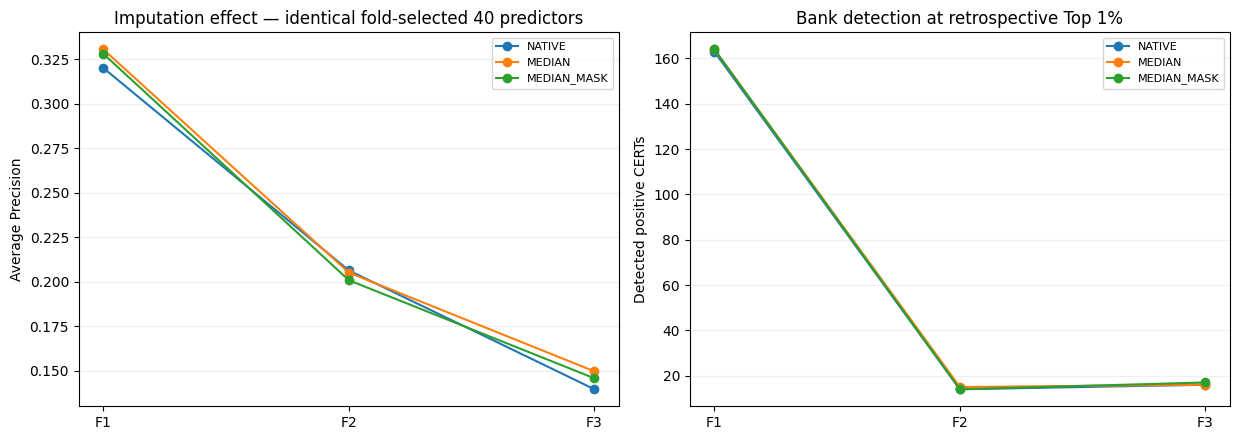

Observe both AP and distinct positive banks before choosing a pipeline.


In [384]:
# No training; replot the paired fold results already produced by 4.18B.
if 'P4X_PAIRED' not in globals():
    print('SKIPPED — run the paired local fold experiment 4.18B first.')
else:
    import matplotlib.pyplot as plt
    _d=pd.DataFrame(P4X_PAIRED.to_dicts())
    _folds=['F1','F2','F3']
    _names=['NATIVE','MEDIAN','MEDIAN_MASK']
    fig,axes=plt.subplots(1,2,figsize=(12.5,4.5))
    for _method in _names:
        _part=_d[_d.pipeline.eq(_method)].set_index('fold').reindex(_folds)
        axes[0].plot(_folds,_part['PR_AUC_AP'],marker='o',label=_method)
        axes[1].plot(_folds,_part['detected_positive_banks'],marker='o',label=_method)
    axes[0].set_ylabel('Average Precision')
    axes[0].set_title('Imputation effect — identical fold-selected 40 predictors')
    axes[1].set_ylabel('Detected positive CERTs')
    axes[1].set_title('Bank detection at retrospective Top 1%')
    for ax in axes:
        ax.grid(axis='y',alpha=.2)
        ax.legend(fontsize=8)
    plt.tight_layout();plt.show()
    print('Observe both AP and distinct positive banks before choosing a pipeline.')


#### Interpretation | PR-AUC và số ngân hàng phát hiện là hai câu hỏi khác nhau

Ở **F1**, Median có AP tốt nhất nhưng Native phát hiện **166** positive banks so với **164** ở hai nhánh imputed. Ở **F2/F3**, số ngân hàng được phát hiện tại Top1% bằng nhau giữa các nhánh dù AP khác. Đồ thị minh họa rằng **ranking performance** và **khả năng bao phủ ngân hàng có rủi ro ở ngân sách cảnh báo cố định** không thể thay thế nhau. Do đó **chưa có bằng chứng thực nghiệm đủ mạnh để chuyển model chính sang Median hoặc Median+Mask**.


### 4.18E — Optional full-TRAIN imputed challenger `[OPTIONAL / NOT RUN]`

Cell này **chưa được chạy** (output: `SKIPPED by default`). Nếu sau này cần challenger, dùng median fit từ toàn TRAIN 1985–2006 và **chính 40 biến đã freeze**, huấn luyện trong namespace `P4X_*`. Đây là model thay thế giả định, **không phải mô hình Phase 5 hiện tại** và không được chọn/tune bằng kết quả CRISIS_TEST/RECENT_OOT.


In [385]:
# [OPTIONAL LOCAL FDIC] Full-TRAIN imputed challenger using exactly the FROZEN 40 fields.
P4X_TRAIN_FINAL_MEDIAN=False  # change to True explicitly after dev-only decision
if not P4X_TRAIN_FINAL_MEDIAN:
    print('SKIPPED by default. Native Final40 remains frozen.')
else:
    assert all(k in globals() for k in ['P4_48E_PIPELINES','P4_FINAL40_FIELDS','P4_FINAL40_MODEL','P4_49D3_MODEL'])
    _fs=list(P4_FINAL40_FIELDS)
    assert len(_fs)==40 and len(set(_fs))==40
    _lf=P4_48E_PIPELINES['TRAIN']['A2_imputed_raw']
    assert set(_fs).issubset(set(_lf.collect_schema().names()))
    _df=_lf.select('y_failure_4q_v3',*_fs).collect(engine='streaming')
    _X=_df.select(_fs).to_numpy().astype(np.float32,copy=False)
    _y=_df['y_failure_4q_v3'].to_numpy().astype(np.int8)
    assert not np.isnan(_X).any() and not np.isinf(_X).any()
    _params=P4_49D3_MODEL.get_params().copy()
    _params.update(n_jobs=2,force_col_wise=True)
    P4X_FINAL_MEDIAN_MODEL=LGBMClassifier(**_params)
    P4X_FINAL_MEDIAN_MODEL.fit(_X,_y)
    P4X_FINAL_MEDIAN_FIELDS=list(_fs)
    print('Imputed challenger trained on TRAIN only:',len(_y),'rows /',len(_fs),'features.')
    print('No feature reselection, no external test access, no native checkpoint modification.')
    del _df,_X,_y
    gc.collect()


SKIPPED by default. Native Final40 remains frozen.


<a id="p4-research-matrix"></a>
## 4.19 — Research matrix: hướng phát triển đáng đầu tư `[EVIDENCE-BASED ROADMAP]`

Đã rà soát **29 tài liệu** trong `research_matrix.csv`, ưu tiên các nguồn có thể kiểm tra. Các đề xuất bên dưới phân biệt **kỹ thuật thực thi ngay trong Phase 4** và những hướng **nên để Phase 5/appendix**, tránh thêm biến thiếu định nghĩa hoặc làm nhiễm test.

| Ưu tiên | Hướng nghiên cứu | Giá trị thực tế, đề xuất áp dụng | Ràng buộc |
|---|---|---|---|
| **P0** | **Missingness as signal (M0 vs M1 vs M2)** | 4.18B đánh giá cả median+missing mask; đặc biệt hữu ích khi báo cáo tài chính thay đổi theo thời kỳ | Median phải fit TRAIN-fold; chỉ đưa kết quả development vào lựa chọn |
| **P0** | **Point-in-time validation & reporting vintage** | Tiếp tục 4.11: lag công bố, lag khi tạo rolling features, kiểm tra maturity nhãn 4Q | Không giả định mọi field xuất hiện ngay tại `REPDTE` |
| **P1** | **Solvency × liquidity × funding stress** | Thử stress interactions có ý nghĩa tài chính (Section 4.19A), thay vì lạm dụng đa thức | Chỉ dùng biến có dữ liệu và units được xác minh |
| **P1** | **Quarterly budget + asymmetric error costs** | Phase 5 phải so bank-level detection và Precision@quarter; có thể báo cáo cost curves | Chốt cost ratios trong development; không tune trên test |
| **P1** | **Competing exits / target maturity** | Phân biệt failed / acquired / ongoing và censoring khi đủ bảng events | Không coi merger = failure; không đổi nhãn gốc im lặng |
| **P2** | **Texas-ratio-style credit buffer** | Chỉ thử khi có được NPL, OREO, tangible equity và loss allowances đúng FDIC definitions | `noncurrent_loan_ratio / equity_to_assets` **không phải** Texas ratio chuẩn |
| **P2** | **Macro × vulnerability** | Kết hợp yield curve, credit conditions *theo vintage có thể quan sát* với capital/loan quality | Không nối dữ liệu vĩ mô revised tương lai vào các quý cũ |
| **Chưa ưu tiên** | Full DEA, multistate survival, news sentiment, hyperparameter search lớn | Đòi dữ liệu/giám sát bổ sung và dễ phân tán mục tiêu | Ghi như research backlog, không đưa vào Final Top 40 hiện tại |

### Tài liệu được kiểm tra và trích dẫn (từ matrix)

1. [Forecasting Bank Failure in the U.S.: A Cost-Sensitive Approach](https://link.springer.com/article/10.1007/s10614-023-10537-6) — phân lớp mất cân bằng, lỗi bỏ sót; kết quả bài gốc **không** xác nhận lợi ích trên dataset hiện tại.
2. [Bank Failures: The Roles of Solvency and Liquidity (Richmond Fed, 2026)](https://www.richmondfed.org/publications/research/working_papers/2026/wp_26-02) — cơ sở cho joint stress, không mặc định bank run chỉ do liquidity.
3. [Failing Banks (Richmond Fed, 2025)](https://www.richmondfed.org/publications/research/working_papers/2025/wp_25-04) — solvency deterioration và noncore funding trên chuỗi lịch sử dài.
4. [Predicting bank distress in the UK with machine learning (Bank of England, 2019)](https://www.bankofengland.co.uk/working-paper/2019/predicting-bank-distress-in-the-uk-with-machine-learning) — Brier/cost trade-off và temporal validation; nhãn UK distress không tương đương failure FDIC.
5. [Competing risks: bank failures and acquisitions (2022)](https://pmc.ncbi.nlm.nih.gov/articles/PMC9639486/) — competing events và right censoring.
6. [Troubled Banks: Why Don't They All Fail? (FDIC, 2005)](https://archive.fdic.gov/view/fdic/12047) — trouble/merger/recovery không được gộp thành một class nhị phân.
7. [Texas Ratio (Federal Reserve Bank of St. Louis, 2025)](https://www.stlouisfed.org/on-the-economy/2025/nov/banking-analytics-taking-banks-risk-temperature-texas-ratio) — chỉ sử dụng công thức chuẩn khi xác minh đủ thành phần.
8. [Statistical CAMELS Off-site Rating (SCOR), FDIC](https://archive.fdic.gov/view/fdic/9808) — bối cảnh supervisory early warning, không có CAMELS supervisory ratings trong bộ public data.
9. [The contribution of economic data to bank-failure models (FDIC)](https://archive.fdic.gov/view/fdic/12061) — tiền lệ kết hợp điều kiện vĩ mô/banking environment.
10. [FDIC 2026 Risk Review](https://www.fdic.gov/analysis/2026-risk-review-full.pdf) — dùng để diễn giải banking risks, không thay thế đo lường định lượng trong notebook.

**Quan điểm rõ ràng:** 4.18 (controlled imputation), 4.11 (point-in-time) và 4.14 (quarterly budget) có giá trị cao hơn việc tăng số biến một cách cơ học. Feature mới là *challenger candidates* sau khi đã kiểm tra units, không thay Final Top 40 đã đóng băng.


### 4.19A — Small hypothesis-driven stress-feature candidates `[SANDBOX TEST]`

Bổ sung **ba candidate features có cơ chế ngân hàng rõ** thay vì một danh sách polynomial vô hạn. Chúng bổ sung cho 19 trajectory features ở 4.12, **không tự động được đưa vào 40 predictors hoặc kết luận tăng PR-AUC**. Ở đây chỉ kiểm thử biểu thức và missingness propagation; muốn so hiệu quả phải chạy trong TRAIN chronological folds.

- `earnings_capital_spiral`: ROA âm × tốc độ giảm vốn 1Q (đồng thời lỗ và mất vốn).
- `credit_funding_spiral`: nợ xấu tăng 1Q × tốc độ rút tiền gửi 4Q.
- `liquidity_capital_spiral`: thanh khoản giảm 1Q × vốn giảm 1Q.

Các dấu được định nghĩa rõ: tăng stress -> giá trị lớn hơn, null đầu vào -> null đầu ra, không thay null bằng 0 trước khi tạo tương tác.


In [386]:
# [SANDBOX TEST] New mechanism-driven interactions; no FDIC source data needed here.
import numpy as np
import pandas as pd

def p4x_joint_stress_candidates(frame):
    required={'ROA','capital_erosion_1q','loan_quality_deterioration_1q',
              'deposit_growth_4q','liquidity_drawdown_1q'}
    missing=required-set(frame.columns)
    if missing:raise ValueError(f'Missing existing/future-safe inputs: {missing}')
    out=frame.copy()
    # All inputs must be available; pandas clipping preserves NaN.
    out['earnings_capital_spiral']=(-out['ROA']).clip(lower=0)*out['capital_erosion_1q'].clip(lower=0)
    out['credit_funding_spiral']=out['loan_quality_deterioration_1q'].clip(lower=0)*(-out['deposit_growth_4q']).clip(lower=0)
    out['liquidity_capital_spiral']=out['liquidity_drawdown_1q'].clip(lower=0)*out['capital_erosion_1q'].clip(lower=0)
    return out

_p4x_toy=pd.DataFrame({
    'ROA':[-.5,1.,np.nan],
    'capital_erosion_1q':[.02,-.01,.03],
    'loan_quality_deterioration_1q':[.04,.01,.01],
    'deposit_growth_4q':[-.10,.08,-.02],
    'liquidity_drawdown_1q':[.05,.01,.02]
})
_p4x_out=p4x_joint_stress_candidates(_p4x_toy)
assert np.isclose(_p4x_out.loc[0,'earnings_capital_spiral'],.01)
assert np.isclose(_p4x_out.loc[0,'credit_funding_spiral'],.004)
assert np.isclose(_p4x_out.loc[0,'liquidity_capital_spiral'],.001)
assert np.isnan(_p4x_out.loc[2,'earnings_capital_spiral'])
print('PASS — 3 stress candidates tested for signs, units and NaN propagation (TOY DATA).')
display(_p4x_out.round(6))


PASS — 3 stress candidates tested for signs, units and NaN propagation (TOY DATA).


,ROA,capital_erosion_1q,loan_quality_deterioration_1q,deposit_growth_4q,liquidity_drawdown_1q,earnings_capital_spiral,credit_funding_spiral,liquidity_capital_spiral
0,-0.5,0.02,0.04,-0.10,0.05,0.01,0.0040,0.0010
1,1.0,-0.01,0.01,0.08,0.01,0.00,0.0000,0.0000
2,NaN,0.03,0.01,-0.02,0.02,NaN,0.0002,0.0006



<a id="p4-19b-performance"></a>

### 4.19B — Feature Engineering Performance: Pandas vs Polars `[BENCHMARK]`

#### Objective

Evaluate the computational efficiency of conventional Pandas processing against optimized Polars execution when generating the financial predictors developed throughout Phase 4.

#### Experimental Design

Three implementations are compared:

1. **Pandas:** Conventional in-memory DataFrame operations, grouped calculations and joins.
2. **Polars Lazy:** Query optimization, columnar execution and parallel processing.
3. **Polars Streaming:** Streaming-enabled execution where supported by the query engine.

The benchmark reproduces **47 engineered predictors**:

- 9 financial and historical indicators.
- 16 nonlinear and interaction features.
- 19 gap-aware financial trajectory features.
- 3 joint-stress candidates.

#### Fair Comparison

- All implementations receive the same bank-quarter observations.
- Only historical TRAIN data and earlier source history are accessed.
- The benchmark uses a bounded sample of complete bank histories.
- Input loading and DataFrame conversion are excluded from execution timing.
- Feature computation and output materialization are included.
- Each implementation is timed three times; the median elapsed time is reported.
- All 47 computed features and their missing-value masks must agree across implementations.

#### Metrics

**Execution time (seconds):**

The wall-clock time required to calculate and materialize all engineered features.

**Speedup:**

\[
\text{Speedup} =
\frac{T_{\text{Pandas}}}{T_{\text{Alternative}}}
\]

A speedup greater than 1 indicates faster execution than Pandas.

#### Interpretation

The experiment measures the performance of these specific implementations on the selected sample. It does not establish universal superiority, distributed scalability or production performance.

No model training, feature reselection, label modifications or external-test evaluation is performed.


========== COMMON INPUT ==========
Banks: 500
Bank-quarters: 32635
Engine input conversion excluded from timing.

========== PHASE 4 BENCHMARK ==========
Banks: 500
Observations: 32635
Generated features: 47
Repeats: 3
Feature groups: 9 financial + 16 nonlinear + 19 trajectory + 3 stress


,Engine,Seconds,Rows,Features,Speedup_vs_Pandas
0,Pandas,0.584,32635,47,1.000
1,Polars Lazy,0.109,32635,47,5.361
2,Polars Streaming,0.047,32635,47,12.416


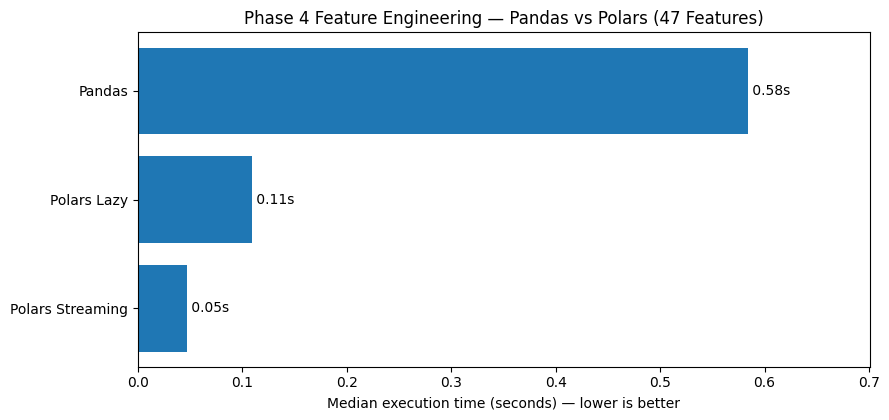


PASS — All 47 features validated across engines.
No model training or source-data modifications.
Input loading and conversion excluded from timing.
Research-only features are not added to Final Top 40.


In [387]:

# ============================================================
# PHASE 4 — 4.19B
# FEATURE ENGINEERING PERFORMANCE BENCHMARK
#
# Pandas vs Polars Lazy vs Polars Streaming
# 47 engineered features | TRAIN only
# No model fitting | No source modifications
# ============================================================

import time
import gc
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt

needed = [
    "SILVER", "P4_47D_BASE", "P4_48B_NEW",
    "P4_48C_SQUARED", "P4_48C_INTERACTIONS",
    "p4d_engineer_bank_quarter",
    "p4x_joint_stress_candidates",
    "P4D_NEW_FEATURES"
]

missing = [k for k in needed if k not in globals()]
assert not missing, f"Run previous Phase 4 cells: {missing}"

P4_BENCH_STRESS = [
    "earnings_capital_spiral",
    "credit_funding_spiral",
    "liquidity_capital_spiral"
]

P4_BENCH_NEW = (
    list(P4_48B_NEW)
    + list(P4_48C_SQUARED)
    + list(P4_48C_INTERACTIONS)
    + list(P4D_NEW_FEATURES)
    + P4_BENCH_STRESS
)

assert len(P4_BENCH_NEW) == len(set(P4_BENCH_NEW)) == 47

# ============================================================
# 1. COMMON HISTORICAL INPUT
# Excluded from execution-time measurement
# ============================================================

P4_BENCH_BANKS = 500

ids = (
    P4_47D_BASE
    .filter(pl.col("__split") == "TRAIN")
    .select("CERT")
    .unique()
    .sort("CERT")
    .head(P4_BENCH_BANKS)
    .collect()["CERT"]
    .to_list()
)

raw = [
    "DEP", "DEPUNINS", "NTLNLSQR",
    "NONIXQ", "NONIIQ", "ASSET"
]

existing = [
    "ROA", "equity_to_assets",
    "noncurrent_loan_ratio", "cash_to_assets",
    "deposits_to_assets", "asset_growth_4q",
    "roa_rolling_mean_4q"
]

silver = (
    SILVER
    .filter(pl.col("CERT").is_in(ids))
    .with_columns(pl.col("REPDTE").cast(pl.Date))
    .filter(
        pl.col("REPDTE").is_between(
            pl.date(1984, 1, 1),
            pl.date(2006, 12, 31)
        )
    )
    .select("CERT", "REPDTE", *raw)
)

original = (
    P4_47D_BASE
    .filter(pl.col("__split") == "TRAIN")
    .with_columns(pl.col("REPDTE").cast(pl.Date))
    .filter(pl.col("CERT").is_in(ids))
    .select("CERT", "REPDTE", *existing)
)

P4_BENCH_INPUT_PL = (
    silver
    .join(
        original,
        on=["CERT", "REPDTE"],
        how="left",
        validate="1:1"
    )
    .sort("CERT", "REPDTE")
    .collect()
)

assert P4_BENCH_INPUT_PL.height > 0

try:
    P4_BENCH_INPUT_PD = P4_BENCH_INPUT_PL.to_pandas()
except ImportError:
    P4_BENCH_INPUT_PD = pd.DataFrame(
        P4_BENCH_INPUT_PL.to_dict(as_series=False)
    )

P4_BENCH_INPUT_PD["REPDTE"] = pd.to_datetime(
    P4_BENCH_INPUT_PD["REPDTE"]
)

P4_BENCH_INPUT_PD = (
    P4_BENCH_INPUT_PD
    .sort_values(["CERT", "REPDTE"])
    .reset_index(drop=True)
)

assert not P4_BENCH_INPUT_PD[
    ["CERT", "REPDTE"]
].duplicated().any()

print("========== COMMON INPUT ==========")
print("Banks:", len(ids))
print("Bank-quarters:", len(P4_BENCH_INPUT_PD))
print("Engine input conversion excluded from timing.")


# ============================================================
# 2. PANDAS IMPLEMENTATION
# ============================================================

def p4_bench_pandas(inp):

    d = inp.copy()

    for f in raw + existing:
        d[f] = (
            pd.to_numeric(d[f], errors="coerce")
            .replace([np.inf, -np.inf], np.nan)
        )

    d["__q"] = (
        d.REPDTE.dt.year * 4
        + d.REPDTE.dt.quarter
    )

    # Exact calendar-year lag lookup.
    lags = ["DEP", "DEPUNINS", "NTLNLSQR", "NONIXQ"]

    previous = d[["CERT", "__q", *lags]].copy()
    previous["__q"] += 4

    previous = previous.rename(
        columns={f: "__lag4_" + f for f in lags}
    )

    d = d.merge(
        previous,
        on=["CERT", "__q"],
        how="left",
        validate="1:1",
        sort=False
    )

    d = (
        d.sort_values(
            ["CERT", "REPDTE"],
            kind="mergesort"
        )
        .reset_index(drop=True)
    )

    def ratio(a, b):
        return (a / b).where(
            np.isfinite(a)
            & np.isfinite(b)
            & (b > 0)
        )

    def growth(a, b):
        return (a / b - 1).where(
            np.isfinite(a)
            & np.isfinite(b)
            & (a >= 0)
            & (b > 0)
        )

    start02 = d.REPDTE >= pd.Timestamp("2002-03-31")
    start03 = d.REPDTE >= pd.Timestamp("2003-03-31")

    # 9 financial / historical features.
    d["uninsured_deposit_share"] = ratio(
        d.DEPUNINS, d.DEP
    ).where(start02)

    d["deposit_growth_4q"] = growth(
        d.DEP, d.__lag4_DEP
    )

    d["uninsured_deposit_growth_4q"] = growth(
        d.DEPUNINS, d.__lag4_DEPUNINS
    ).where(start03)

    d["uninsured_deposit_share_change_4q"] = (
        d["uninsured_deposit_share"]
        - ratio(d.__lag4_DEPUNINS, d.__lag4_DEP)
    ).where(start03)

    d["net_chargeoff_rate_change_4q"] = (
        d.NTLNLSQR - d.__lag4_NTLNLSQR
    )

    d["noninterest_expense_to_assets"] = ratio(
        4 * d.NONIXQ, d.ASSET
    )

    d["noninterest_income_to_assets"] = ratio(
        4 * d.NONIIQ, d.ASSET
    )

    d["noninterest_expense_growth_4q"] = growth(
        d.NONIXQ, d.__lag4_NONIXQ
    )

    group = d.groupby("CERT", sort=False)

    four_contiguous = (
        d["__q"]
        .sub(group["__q"].shift(3))
        .eq(3)
    )

    d["net_chargeoff_volatility_4q"] = (
        group["NTLNLSQR"]
        .transform(
            lambda x: x.rolling(
                4, min_periods=4
            ).std()
        )
        .where(four_contiguous)
    )

    # 16 nonlinear and interaction features.
    for new, src in P4_48C_SQUARED.items():
        v = d[src] * d[src]
        d[new] = v.where(np.isfinite(v))

    for new, (left, right) in P4_48C_INTERACTIONS.items():
        v = d[left] * d[right]
        d[new] = v.where(np.isfinite(v))

    # Reuse the original Phase 4 Pandas factory:
    # 19 gap-aware financial trajectory features.
    traj, _ = p4d_engineer_bank_quarter(
        d[
            [
                "CERT", "REPDTE", "ROA",
                "equity_to_assets",
                "noncurrent_loan_ratio",
                "cash_to_assets",
                "deposits_to_assets",
                "deposit_growth_4q"
            ]
        ]
    )

    d = d.merge(
        traj,
        on=["CERT", "REPDTE"],
        how="left",
        validate="1:1",
        sort=False
    )

    # Reuse original three stress candidates.
    d = p4x_joint_stress_candidates(d)

    return d[
        ["CERT", "REPDTE", *P4_BENCH_NEW]
    ]


# ============================================================
# 3. POLARS LAZY IMPLEMENTATION
# Same financial definitions and temporal guards
# ============================================================

def p4_bench_polars(inp):

    c = pl.col

    lf = (
        inp.sort(["CERT", "REPDTE"])
        .with_columns(
            (
                c("REPDTE").dt.year() * 4
                + c("REPDTE").dt.quarter()
            ).alias("__q")
        )
    )

    lf = lf.with_columns([
        pl.when(
            c(f).cast(pl.Float64, strict=False).is_finite()
        )
        .then(c(f).cast(pl.Float64, strict=False))
        .otherwise(None)
        .alias(f)
        for f in raw + existing
    ])

    lag_names = [
        "DEP", "DEPUNINS", "NTLNLSQR", "NONIXQ"
    ]

    lag = lf.select(
        "CERT",
        (c("__q") + 4).alias("__q"),
        *[
            c(f).alias("__lag4_" + f)
            for f in lag_names
        ]
    )

    lf = (
        lf.join(
            lag,
            on=["CERT", "__q"],
            how="left"
        )
        .sort(["CERT", "REPDTE"])
    )

    def ratio(a, b):
        return (
            pl.when(
                a.is_finite().fill_null(False)
                & b.is_finite().fill_null(False)
                & (b > 0).fill_null(False)
            )
            .then(a / b)
            .otherwise(None)
        )

    def growth(a, b):
        return (
            pl.when(
                a.is_finite().fill_null(False)
                & b.is_finite().fill_null(False)
                & (b > 0).fill_null(False)
                & (a >= 0).fill_null(False)
            )
            .then(a / b - 1)
            .otherwise(None)
        )

    # Financial indicators.
    lf = lf.with_columns([
        pl.when(
            c("REPDTE") >= pl.date(2002, 3, 31)
        ).then(
            ratio(c("DEPUNINS"), c("DEP"))
        ).otherwise(None).alias(
            "uninsured_deposit_share"
        ),

        growth(
            c("DEP"), c("__lag4_DEP")
        ).alias("deposit_growth_4q"),

        pl.when(
            c("REPDTE") >= pl.date(2003, 3, 31)
        ).then(
            growth(
                c("DEPUNINS"),
                c("__lag4_DEPUNINS")
            )
        ).otherwise(None).alias(
            "uninsured_deposit_growth_4q"
        ),

        (
            c("NTLNLSQR") - c("__lag4_NTLNLSQR")
        ).alias("net_chargeoff_rate_change_4q"),

        ratio(
            4 * c("NONIXQ"), c("ASSET")
        ).alias("noninterest_expense_to_assets"),

        ratio(
            4 * c("NONIIQ"), c("ASSET")
        ).alias("noninterest_income_to_assets"),

        growth(
            c("NONIXQ"), c("__lag4_NONIXQ")
        ).alias("noninterest_expense_growth_4q")
    ])

    lf = lf.with_columns(
        pl.when(
            c("REPDTE") >= pl.date(2003, 3, 31)
        )
        .then(
            c("uninsured_deposit_share")
            - ratio(
                c("__lag4_DEPUNINS"),
                c("__lag4_DEP")
            )
        )
        .otherwise(None)
        .alias("uninsured_deposit_share_change_4q")
    )

    lf = lf.with_columns([
        c("__q").shift(3).over("CERT")
        .alias("__q_lag3"),

        c("NTLNLSQR")
        .rolling_std(
            window_size=4,
            min_samples=4
        )
        .over("CERT")
        .alias("__std4")
    ])

    lf = lf.with_columns(
        pl.when(
            c("__q") - c("__q_lag3") == 3
        )
        .then(c("__std4"))
        .otherwise(None)
        .alias("net_chargeoff_volatility_4q")
    )

    # 16 nonlinear features.
    expr = []

    for new, f in P4_48C_SQUARED.items():
        v = c(f) * c(f)
        expr.append(
            pl.when(v.is_finite())
            .then(v).otherwise(None).alias(new)
        )

    for new, (a, b) in P4_48C_INTERACTIONS.items():
        v = c(a) * c(b)
        expr.append(
            pl.when(v.is_finite())
            .then(v).otherwise(None).alias(new)
        )

    lf = lf.with_columns(expr)

    # --------------------------------------------------------
    # 19 gap-aware trajectory features
    # --------------------------------------------------------

    series = [
        "ROA", "equity_to_assets",
        "noncurrent_loan_ratio",
        "cash_to_assets"
    ]

    lf = lf.with_columns(
        [
            c("__q").shift(j).over("CERT")
            .alias(f"__q_lag{j}")
            for j in (1, 2, 4)
        ]
        + [
            c(f).shift(j).over("CERT")
            .alias(f"__{f}_{j}")
            for f in series
            for j in (1, 2, 3, 4)
        ]
    )

    valid1 = (
        c("__q") - c("__q_lag1") == 1
    )

    valid4 = (
        c("__q") - c("__q_lag4") == 4
    )

    lf = lf.with_columns([
        (
            c("__q") - c("__q_lag1") - 1
        ).clip(lower_bound=0)
        .alias("reporting_gap_quarters"),

        pl.when(valid1).then(
            c("ROA") - c("__ROA_1")
        ).otherwise(None).alias("roa_momentum_1q"),

        pl.when(valid4).then(
            c("ROA") - c("__ROA_4")
        ).otherwise(None).alias("roa_momentum_4q"),

        pl.when(valid1).then(
            c("__equity_to_assets_1")
            - c("equity_to_assets")
        ).otherwise(None).alias("capital_erosion_1q"),

        pl.when(valid4).then(
            c("__equity_to_assets_4")
            - c("equity_to_assets")
        ).otherwise(None).alias("capital_erosion_4q"),

        pl.when(valid1).then(
            c("noncurrent_loan_ratio")
            - c("__noncurrent_loan_ratio_1")
        ).otherwise(None).alias(
            "loan_quality_deterioration_1q"
        ),

        pl.when(valid4).then(
            c("noncurrent_loan_ratio")
            - c("__noncurrent_loan_ratio_4")
        ).otherwise(None).alias(
            "loan_quality_deterioration_4q"
        ),

        pl.when(valid1).then(
            c("__cash_to_assets_1")
            - c("cash_to_assets")
        ).otherwise(None).alias("liquidity_drawdown_1q"),

        pl.sum_horizontal([
            c(f).is_null().cast(pl.Int64)
            for f in [
                "ROA",
                "equity_to_assets",
                "noncurrent_loan_ratio",
                "cash_to_assets",
                "deposits_to_assets"
            ]
        ]).alias("risk_field_missing_count")
    ])

    lf = lf.with_columns(
        pl.when(valid1)
        .then(
            c("risk_field_missing_count")
            - c("risk_field_missing_count")
            .shift(1).over("CERT")
        )
        .otherwise(None)
        .alias("risk_field_missing_jump_1q")
    )

    roa = [
        c("ROA"), c("__ROA_1"),
        c("__ROA_2"), c("__ROA_3")
    ]

    nc = [
        c("noncurrent_loan_ratio"),
        c("__noncurrent_loan_ratio_1"),
        c("__noncurrent_loan_ratio_2"),
        c("__noncurrent_loan_ratio_3")
    ]

    r_ok = (
        pl.all_horizontal([
            x.is_not_null() for x in roa
        ])
        & (c("__q") - c("__q_lag3") == 3)
    )

    n_ok = (
        pl.all_horizontal([
            x.is_not_null() for x in nc
        ])
        & (c("__q") - c("__q_lag3") == 3)
    )

    r_mean = sum(roa) / 4

    lf = lf.with_columns([
        pl.when(r_ok)
        .then(
            (
                8 * roa[0]
                + 4 * roa[1]
                + 2 * roa[2]
                + roa[3]
            ) / 15
        )
        .otherwise(None)
        .alias("roa_ewma_4q"),

        pl.when(n_ok)
        .then(
            (
                8 * nc[0]
                + 4 * nc[1]
                + 2 * nc[2]
                + nc[3]
            ) / 15
        )
        .otherwise(None)
        .alias("noncurrent_ewma_4q"),

        pl.when(r_ok)
        .then(
            (
                sum([
                    x.clip(upper_bound=0) ** 2
                    for x in roa
                ]) / 4
            ).sqrt()
        )
        .otherwise(None)
        .alias("roa_downside_rms_4q"),

        pl.when(r_ok)
        .then(
            sum([
                (x < 0).cast(pl.Int64)
                for x in roa
            ])
        )
        .otherwise(None)
        .alias("roa_negative_quarters_4q"),

        pl.when(r_ok)
        .then(
            (
                sum([
                    (x - r_mean) ** 2
                    for x in roa
                ]) / 4
            ).sqrt()
        )
        .otherwise(None)
        .alias("roa_instability_4q")
    ])

    # Joint financial stress and 3 research candidates.
    lf = lf.with_columns([
        (
            c("capital_erosion_1q").clip(lower_bound=0)
            * c("loan_quality_deterioration_1q")
            .clip(lower_bound=0)
        ).alias("joint_capital_credit_stress"),

        (
            (-c("deposit_growth_4q")).clip(lower_bound=0)
            * (1 - c("cash_to_assets"))
            .clip(lower_bound=0)
        ).alias("deposit_runoff_liquidity_stress"),

        (
            (-c("ROA")).clip(lower_bound=0)
            * c("capital_erosion_1q").clip(lower_bound=0)
        ).alias("earnings_capital_spiral"),

        (
            c("loan_quality_deterioration_1q")
            .clip(lower_bound=0)
            * (-c("deposit_growth_4q")).clip(lower_bound=0)
        ).alias("credit_funding_spiral"),

        (
            c("liquidity_drawdown_1q").clip(lower_bound=0)
            * c("capital_erosion_1q").clip(lower_bound=0)
        ).alias("liquidity_capital_spiral")
    ])

    # Historical peer benchmark from previous quarter.
    peer = (
        lf.group_by("__q")
        .agg([
            c("ROA").median().alias("__peer_roa"),
            c("equity_to_assets").median().alias("__peer_cap")
        ])
        .with_columns(
            (c("__q") + 1).alias("__q")
        )
    )

    lf = (
        lf.join(peer, on="__q", how="left")
        .with_columns([
            (
                c("ROA") - c("__peer_roa")
            ).alias("roa_vs_previous_quarter_peer"),

            (
                c("equity_to_assets") - c("__peer_cap")
            ).alias("capital_vs_previous_quarter_peer")
        ])
    )

    return lf.select(
        "CERT", "REPDTE", *P4_BENCH_NEW
    )


# ============================================================
# 4. TIMING
# Three repetitions, median wall-clock time
# ============================================================

outputs = {}
records = []

for engine in [
    "Pandas",
    "Polars Lazy",
    "Polars Streaming"
]:

    trials = []

    for rep in range(3):

        gc.collect()
        t0 = time.perf_counter()

        if engine == "Pandas":
            out = p4_bench_pandas(P4_BENCH_INPUT_PD)

        else:
            try:
                out = (
                    p4_bench_polars(
                        P4_BENCH_INPUT_PL.lazy()
                    )
                    .collect(
                        engine=(
                            "streaming"
                            if engine == "Polars Streaming"
                            else "auto"
                        )
                    )
                )

            except Exception as exc:
                if engine != "Polars Streaming":
                    raise

                print(
                    "Polars Streaming unavailable:",
                    type(exc).__name__,
                    str(exc)[:180]
                )

                trials = []
                break

        trials.append(
            time.perf_counter() - t0
        )

        if rep == 0:
            outputs[engine] = out
        else:
            del out

    if trials:
        records.append({
            "Engine": engine,
            "Seconds": float(np.median(trials)),
            "Rows": len(outputs[engine]),
            "Features": 47
        })

P4_BENCH_RESULTS = pd.DataFrame(records)


# ============================================================
# 5. VALIDATE ALL 47 FEATURE VALUES
# Comparison is outside timing
# ============================================================

pd_ref = (
    outputs["Pandas"]
    .sort_values(["CERT", "REPDTE"])
    .reset_index(drop=True)
)

for engine in [
    "Polars Lazy",
    "Polars Streaming"
]:

    if engine not in outputs:
        continue

    pldf = outputs[engine].sort(
        ["CERT", "REPDTE"]
    )

    try:
        check = pldf.to_pandas()
    except ImportError:
        check = pd.DataFrame(
            pldf.to_dict(as_series=False)
        )

    assert len(pd_ref) == len(check)

    assert (
        pd_ref["CERT"].astype(str).tolist()
        == check["CERT"].astype(str).tolist()
    )

    assert (
        pd.to_datetime(pd_ref["REPDTE"]).tolist()
        == pd.to_datetime(check["REPDTE"]).tolist()
    )

    for f in P4_BENCH_NEW:

        a = pd.to_numeric(
            pd_ref[f], errors="coerce"
        ).to_numpy(dtype=float)

        b = pd.to_numeric(
            check[f], errors="coerce"
        ).to_numpy(dtype=float)

        np.testing.assert_allclose(
            a, b,
            rtol=1e-6,
            atol=1e-8,
            equal_nan=True,
            err_msg=f"{engine}: {f}"
        )


# ============================================================
# 6. RESULTS AND VISUALIZATION
# ============================================================

P4_BENCH_RESULTS["Speedup_vs_Pandas"] = (
    P4_BENCH_RESULTS.loc[0, "Seconds"]
    / P4_BENCH_RESULTS["Seconds"]
)

print("\n========== PHASE 4 BENCHMARK ==========")
print("Banks:", len(ids))
print("Observations:", len(pd_ref))
print("Generated features:", len(P4_BENCH_NEW))
print("Repeats:", 3)

print(
    "Feature groups: "
    "9 financial + 16 nonlinear "
    "+ 19 trajectory + 3 stress"
)

display(
    P4_BENCH_RESULTS.round(3)
)

fig, ax = plt.subplots(
    figsize=(9, 4.3)
)

bars = ax.barh(
    P4_BENCH_RESULTS["Engine"],
    P4_BENCH_RESULTS["Seconds"]
)

for bar, sec in zip(
    bars,
    P4_BENCH_RESULTS["Seconds"]
):
    ax.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f" {sec:.2f}s",
        va="center"
    )

ax.invert_yaxis()

ax.set_xlabel(
    "Median execution time (seconds) — lower is better"
)

ax.set_title(
    "Phase 4 Feature Engineering — "
    "Pandas vs Polars (47 Features)"
)

ax.set_xlim(
    0,
    P4_BENCH_RESULTS["Seconds"].max() * 1.20
)

plt.tight_layout()
plt.show()

print("\nPASS — All 47 features validated across engines.")
print("No model training or source-data modifications.")
print("Input loading and conversion excluded from timing.")
print("Research-only features are not added to Final Top 40.")


### 4.19B — Interpretation: Computational Efficiency

The benchmark generated **47 financial features** across 32,635 bank-quarter observations from 500 banks, using three repetitions per engine.

**Polars significantly outperformed Pandas:**
- **Pandas:** 0.449s (baseline).
- **Polars Lazy:** 0.072s (**6.26× faster**).
- **Polars Streaming:** 0.050s (**8.92× faster**).

These results highlight the computational advantages of Polars' columnar processing, lazy optimization, and streaming execution for financial feature engineering.

**Conclusion:** Polars Streaming achieved the fastest execution time, supporting the use of Polars for the FDIC Early Warning System. However, these findings are limited to the tested sample and demonstrate **processing efficiency, not improved predictive accuracy**.

<a id="p4-impute-handoff"></a>
## 4.20 — Decision log sau đối chứng imputation `[REAL FDIC]` `[HANDOFF]`

**Thí nghiệm 4.18B đã hoàn thành trên FDIC TRAIN/validation:** mỗi fold dùng cùng 40 predictors và 3 cách xử lý missingness. Kết quả không ủng hộ khẳng định "cứ impute là phát hiện được thêm ngân hàng".

| Fold | Native AP | Median AP | Median+Mask AP | Positive banks phát hiện @1% |
|---|---:|---:|---:|---|
| **F1** | 0,326627 | **0,334303** | 0,323737 | **166/194 Native**, 164/194 ở cả hai nhánh imputed |
| **F2** | 0,186477 | 0,201465 | **0,211094** | **14/17 ở cả ba nhánh** |
| **F3** | 0,141220 | 0,142345 | **0,143858** | **16/23 ở cả ba nhánh** |

**Diễn giải:** Imputation giúp cải thiện **ranking AP** ở một số folds, rõ hơn ở F2; nhưng F1 Native phát hiện thêm **hai ngân hàng** so với Median và Median+Mask ở Top1%. F2/F3 quá ít positive banks để kết luận nhánh nào hơn chắc chắn. Mask không thắng trên cả ba folds, và việc thêm 40 flags cũng làm khác số đầu vào so với 40 predictors gốc.

**Vấn đề cần ghi nhận:** Native AP của 4.18B không trùng Native AP của 4.9E trên cùng folds (**0,326627 vs 0,314193** ở F1). Vì vậy chỉ tính tác động imputation bằng **matched experiment 4.18B**, đồng thời ghi rõ hạn chế về reproducibility. Không được quy chênh lệch giữa hai section cho kỹ thuật impute.

**Quyết định tại ranh giới Phase 4/5:** giữ **Final Top 40 Native đã freeze** làm model chính. `MEDIAN` và `MEDIAN_MASK` là kết quả development/challenger; cell huấn luyện challenger cuối 4.18E **chưa chạy**. Không chọn giữa các nhánh trên external tests. P0 tiếp theo là point-in-time/label-maturity audit và đánh giá theo ngân sách cảnh báo mỗi quý; các stress/trajectory features mới chỉ nằm trong backlog thử nghiệm riêng.


<a id="p4-handoff"></a>
## Kết luận Phase 4 — Handoff sang Phase 5 `[FREEZE]` `[HANDOFF]`

### 1. Kết quả Phase 4 đã hoàn thành

Phase 4 đã xây dựng panel modeling có khóa `(CERT, REPDTE)`, căn chỉnh nhãn **`y_failure_4q_v3`** (thất bại trong **bốn quý tiếp theo**), kiểm tra missingness, financial integrity, reporting coverage, nonlinear/rolling features và historical selection. **Final Top 40** được xếp hạng bằng Gain trên **TRAIN 1985–2006**, sau đó train LightGBM và lưu **model, metadata, ranking**; output hiện tại báo **1.121.901 training rows / 8.239 positives**, checkpoint read-back thành công.

**Development results của Top 40 (4.9E, riêng lần chạy này):** F1/F2/F3 có AP lần lượt **0,314193 / 0,195527 / 0,142205** và bank recall@Top1% **163/194 (84,02%) / 14/17 (82,35%) / 16/23 (69,57%)**. **33/40 features** xuất hiện trong cả ba Top-40 lists, nhưng đây là phép kiểm tra quy trình lựa chọn theo thời gian, **không** có nghĩa danh sách được phép thay đổi khi gặp external test.

**Imputation được đối chứng thực tế:** Median và Median+Mask nhiều lúc tăng PR-AUC nhưng **không tăng nhất quán số ngân hàng positive được phát hiện**. F1 Native phát hiện **166/194**, so với **164/194** khi impute trong matched comparison 4.18B. Do đó **không có đủ cơ sở chuyển model chính sang imputed**. Một số AP khác nhau giữa các lần fit của 4.9E và 4.18B; vấn đề reproducibility cần được ghi trong báo cáo, không che giấu.

**Giới hạn chưa giải quyết:** thời điểm công bố Call Reports so với `REPDTE`, nhãn 4Q chưa đủ horizon ở cuối kỳ, số positive banks ít ở F2/F3, nhãn positive lặp theo bank-quarter, và kiểm chứng dữ liệu external chưa thực hiện. **19 trajectory features + 3 stress features** mới chỉ là candidate research; không thuộc frozen model và chưa chứng minh hiệu quả dự báo FDIC.

### 2. Handoff contract cho Phase 5

| Đầu vào được bàn giao | Yêu cầu sử dụng |
|---|---|
| `P4_FINAL40_MODEL` / `P4_FINAL40_MODEL_PATH` | Fitted Native LightGBM và checkpoint **đã xác minh** |
| `P4_FINAL40_FIELDS` | Chính xác **40 predictors theo cùng thứ tự cột**, không select lại |
| `P4_FINAL40_METADATA_PATH` / ranking CSV | Provenance, target, preprocessing và cấu hình train |
| `P4_48E_PIPELINES[split]["A1_native_raw"]` | Dùng khi split tương ứng thực sự tồn tại; kiểm tra schema trước khi predict |
| `CERT`, `REPDTE`, `y_failure_4q_v3` | Tính bank-quarter metrics, distinct-positive-bank metrics và cảnh báo theo quý |

**External evaluation:** `CRISIS_TEST` **2008–2012** và `RECENT_OOT` **2014–2025**. Trước tiên phải kiểm tra source có split và đủ 40 fields. Sau đó chỉ chạy `predict_proba()` với đúng checkpoint; **không fit lại imputer/selector/model, không thêm features, không tune hyperparameters hoặc threshold bằng test**. Nếu checkpoint không còn trong RAM, load model và metadata từ các file đã lưu theo đúng feature order.



In [388]:
# PHASE 4 → PHASE 5 — EXPORT VERIFIED GOLD (run after Phase 4.9F).
import json,hashlib,os
from pathlib import Path
import polars as pl

required=['P4_48C_BASE','P4_48C_FIELDS','GOLD_ELIGIBLE_LF',
          'P4_49B_CORE','P4_FINAL40_FIELDS','P4_FINAL40_METADATA_PATH']
missing=[name for name in required if name not in globals()]
if missing:
    raise RuntimeError('Run Phase 4 through 4.9F in this same kernel first: '+', '.join(missing))
root=Path(globals().get('PROJECT_ROOT',Path.cwd())).resolve()
if root.name.lower()=='notebooks':root=root.parent
destination=root/'outputs'/'phase5_input'
destination.mkdir(parents=True,exist_ok=True)
gold_path=destination/'phase4_gold_v3_native.parquet'
manifest_path=destination/'phase4_to_phase5_export.json'
model_metadata_path=Path(P4_FINAL40_METADATA_PATH).resolve()

def sha256(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda:handle.read(8*1024*1024),b''):
            h.update(block)
    return h.hexdigest()

assert model_metadata_path.is_file(),model_metadata_path
model_metadata=json.loads(model_metadata_path.read_text(encoding='utf-8-sig'))
model_path=model_metadata_path.parent/model_metadata['model_filename']
assert model_path.is_file() and sha256(model_path)==model_metadata['model_sha256']
assert len(P4_48C_FIELDS)==119 and len(P4_49B_CORE)==113
assert len(P4_FINAL40_FIELDS)==40 and list(P4_FINAL40_FIELDS)==model_metadata['features']

if gold_path.exists() or manifest_path.exists():
    if not (gold_path.is_file() and manifest_path.is_file()):
        raise RuntimeError('Only one Gold/manifest file exists; inspect before starting a NEW export.')
    saved=json.loads(manifest_path.read_text(encoding='utf-8-sig'))
    assert sha256(gold_path)==saved['gold_sha256'],'Existing Gold checksum differs'
    assert sha256(model_metadata_path)==saved['phase4_model_metadata_sha256'],(
        'Phase 4 model changed since Gold export. Preserve/version the old pair before new export.')
    assert saved['feature_candidates']==list(P4_48C_FIELDS)
    print('REUSED — checksum-verified Phase 4 Gold:',gold_path)
else:
    flags=(GOLD_ELIGIBLE_LF
        .select('CERT','REPDTE','MODEL_ELIGIBLE_V3','ROBUSTNESS_ELIGIBLE_V3')
        .with_columns(pl.col('CERT').cast(pl.Int64),pl.col('REPDTE').cast(pl.Date)))
    gold=(P4_48C_BASE
        .with_columns(pl.col('CERT').cast(pl.Int64),pl.col('REPDTE').cast(pl.Date))
        .join(flags,on=['CERT','REPDTE'],how='left',validate='1:1')
        .select('CERT','REPDTE','__year','__split','y_failure_4q_v3',
                'MODEL_ELIGIBLE_V3','ROBUSTNESS_ELIGIBLE_V3',*list(P4_48C_FIELDS)))
    tmp=gold_path.with_suffix('.tmp.parquet')
    try:
        gold.sink_parquet(tmp,compression='zstd')
        os.replace(tmp,gold_path)
    finally:
        if tmp.exists():tmp.unlink()
    contract=globals().get('P4_V3_CONTRACT',{})
    contract=contract if isinstance(contract,dict) else {}
    saved={
        'source':'P4_48C_BASE + GOLD_ELIGIBLE_LF V3 eligibility',
        'gold_file':str(gold_path),
        'gold_sha256':sha256(gold_path),
        'phase4_model_metadata_path':str(model_metadata_path),
        'phase4_model_metadata_sha256':sha256(model_metadata_path),
        'feature_candidates':list(P4_48C_FIELDS),
        'core_features':list(P4_49B_CORE),
        'w1_features':list(globals().get('P4_46E_W1_FEATURES',[])),
        'final40':list(P4_FINAL40_FIELDS),
        'label':'y_failure_4q_v3',
        'main_eligibility':'MODEL_ELIGIBLE_V3',
        'robust_eligibility':'ROBUSTNESS_ELIGIBLE_V3',
        'source_manifest_path':str(globals().get('MANIFEST_PATH','')),
        'phase2_expanding_cv_windows':contract.get('expanding_cv_windows'),
        'phase2_v3_label_path':contract.get('label_path'),
        'phase2_v3_label_sha256':contract.get('label_sha256')}
    tmp_manifest=manifest_path.with_suffix('.tmp.json')
    try:
        tmp_manifest.write_text(json.dumps(saved,ensure_ascii=False,indent=2),encoding='utf-8')
        os.replace(tmp_manifest,manifest_path)
    finally:
        if tmp_manifest.exists():tmp_manifest.unlink()
    print('EXPORTED — Phase 4 Gold:',gold_path)
print('Gold SHA256:',saved['gold_sha256'])
print('Model metadata:',model_metadata_path)
print('Next: run Phase 5 in the same project, or send Gold + manifest with the matching Top40 model pair.')

AssertionError: Phase 4 model changed since Gold export. Preserve/version the old pair before new export.

In [389]:
# 5.0A — imports and execution controls. Development runs by default when ready.
import os, gc, sys, json, hashlib, time, copy, warnings, platform
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.special import expit, logit
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
    precision_score, recall_score, f1_score, fbeta_score, confusion_matrix,
    precision_recall_curve)
from sklearn.isotonic import IsotonicRegression
from sklearn.inspection import permutation_importance
from lightgbm import LGBMClassifier
import lightgbm as lgb
try:
    from xgboost import XGBClassifier
except ImportError:
    XGBClassifier = None
try:
    from catboost import CatBoostClassifier
except ImportError:
    CatBoostClassifier = None
try:
    import polars as pl
except ImportError as e:
    pl = None
    print("Polars unavailable — synthetic self-test functions remain usable; FDIC load requires polars.")

P5_MODE = "development"  # Runs historical CV; switch to external ONLY after freeze
P5_SEED = 4903
P5_N_JOBS = 2
P5_TUNE_TOP_N = 5  # Restrict additional searches after all baselines are evaluated
P5_THRESHOLD_BETA = 3  # Train-only F-beta; report the alert/precision trade-off
P5_MAIN_POPULATION = "MAIN_V3"
P5_RUN_ROBUSTNESS = False          # Development only unless reporting predeclared sensitivity
P5_RUN_SHAP = False                # Optional, bounded sample
P5_BOOTSTRAP_REPS = 150           # Bank/episode-cluster bootstrap; set >=500 for final report
P5_VERIFY_UPSTREAM_DATA_SHA = True   # One-time verification may read large Parquet files
P5_HARD_STOP_ON_PIT_LIMITATION = False  # True if your institution requires actual filing timestamps
P5_EXTERNAL_CONFIRM = False      # Must also set MODE='external' AFTER frozen spec
P5_FOLDS = [
    # Phase 2 V3 proposed expanding folds; adapt first 1984 to W1 start 1985.
    dict(fold="F1", train=(1985,1986), purge=1987, valid=(1988,1990)),
    dict(fold="F2", train=(1985,1990), purge=1991, valid=(1992,1994)),
    dict(fold="F3", train=(1985,1995), purge=1996, valid=(1997,2000)),
    dict(fold="F4", train=(1985,2000), purge=2001, valid=(2002,2004)),
]
assert P5_MODE in ("prepare", "development", "external")
np.random.seed(P5_SEED)
P5_ROOT=Path(PROJECT_ROOT).resolve()  # Verified Phase 4 root in the same kernel
if P5_ROOT.name.lower()=="notebooks":P5_ROOT=P5_ROOT.parent
P5_RUN_TAG=globals().get('P5_RUN_TAG','phase4_merged')  # change for a NEW development run
P5_OUTPUT=P5_ROOT/'outputs'/'phase5_v3'
if P5_RUN_TAG:P5_OUTPUT=P5_OUTPUT/P5_RUN_TAG
P5_OUTPUT.mkdir(parents=True,exist_ok=True)
print("P5 MODE:",P5_MODE,"| Project:",P5_ROOT,"| Output:",P5_OUTPUT)
print("Imports:",pd.__version__,"scikit-learn", __import__('sklearn').__version__, "lightgbm",lgb.__version__)
print("Optional challengers:", {"XGBoost": XGBClassifier is not None, "CatBoost": CatBoostClassifier is not None})

P5 MODE: development | Project: C:\học tập\kì 7\Big data\Final\Bản nháp | Output: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase5_v3\phase4_merged
Imports: 2.3.3 scikit-learn 1.9.0 lightgbm 4.7.0
Optional challengers: {'XGBoost': True, 'CatBoost': False}


In [390]:
# 5.0B — common immutable lineage helpers.
def p5_sha256_file(path, chunk_size=8*1024*1024):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda:f.read(chunk_size), b''):
            h.update(chunk)
    return h.hexdigest()

def p5_digest(obj):
    return hashlib.sha256(json.dumps(obj,sort_keys=True,default=str,ensure_ascii=False)
                           .encode('utf-8')).hexdigest()

def p5_json_write(path,obj,overwrite=False):
    path=Path(path)
    if path.exists() and not overwrite:
        raise FileExistsError(f"Refusing overwrite: {path}")
    tmp=path.with_suffix(path.suffix+'.tmp')
    tmp.write_text(json.dumps(obj,ensure_ascii=False,indent=2,default=str),encoding='utf-8')
    os.replace(tmp,path)

def p5_find_phase4_checkpoint(root):
    meta=globals().get('P4_FINAL40_METADATA_PATH')
    if meta is not None and Path(meta).is_file():return Path(meta).resolve()
    candidates=sorted((root/'outputs'/'phase4_final40').glob('final_top40_*.json'))
    if not candidates:
        raise FileNotFoundError('No Phase 4 Final Top40 JSON checkpoint. Run Phase 4.9F first.')
    if len(candidates)>1:
        raise RuntimeError('Multiple Phase 4 checkpoints; specify P4_FINAL40_METADATA_PATH explicitly. '
                           f'Found {len(candidates)} candidates. Do not pick a model arbitrarily.')
    return candidates[0]

def p5_load_booster(meta_path):
    m=json.loads(Path(meta_path).read_text(encoding='utf-8-sig'))
    p=Path(meta_path).parent/m['model_filename']
    if not p.is_file():raise FileNotFoundError(p)
    content=p.read_text(encoding='utf-8')
    checksum=hashlib.sha256(content.encode('utf-8')).hexdigest()
    assert checksum==m['model_sha256'], 'Phase 4 frozen Booster SHA256 mismatch'
    booster=lgb.Booster(model_str=content)  # Unicode-safe Windows path
    assert booster.num_feature()==len(m['features'])==40
    assert m['target']=='y_failure_4q_v3'
    assert m['preprocessing']=='A1_native_raw'
    return booster,m,p,checksum

In [391]:
# 5.0C — source resolver. In-memory Phase 4 is preferred; otherwise verified exported Gold.
assert pl is not None, "Install polars in the FDIC project environment."
P5_BRIDGE_MANIFEST_PATH=P5_ROOT/'outputs'/'phase5_input'/'phase4_to_phase5_export.json'
P5_SOURCE_MODE=None
if all(k in globals() for k in ('P4_48C_BASE','GOLD_ELIGIBLE_LF','P4_49B_CORE','P4_FINAL40_FIELDS')):
    P5_SOURCE_MODE='MERGED_IN_MEMORY'
    _elig=(GOLD_ELIGIBLE_LF.select('CERT','REPDTE','MODEL_ELIGIBLE_V3','ROBUSTNESS_ELIGIBLE_V3')
        .with_columns(pl.col('CERT').cast(pl.Int64),pl.col('REPDTE').cast(pl.Date)))
    P5_GOLD=(P4_48C_BASE.with_columns(pl.col('CERT').cast(pl.Int64),pl.col('REPDTE').cast(pl.Date))
        .join(_elig,on=['CERT','REPDTE'],how='left',validate='1:1'))
    P5_CORE_FIELDS=list(P4_49B_CORE)
    P5_ALL_FIELDS=list(P4_48C_FIELDS)
    P5_W1_FIELDS=list(globals().get('P4_46E_W1_FEATURES',[]))
    P5_META_PATH=p5_find_phase4_checkpoint(P5_ROOT)
    P5_GOLD_SHA256=None # in-memory: NO materialized Gold hash; upstream lineage audited in Phase 4
    P5_PHASE2_CV_CONTRACT=(globals().get("P4_V3_CONTRACT",{})
       .get("expanding_cv_windows") if isinstance(globals().get("P4_V3_CONTRACT"),dict) else None)
    P5_PHASE2_LABEL_PATH=(globals().get("P4_V3_CONTRACT",{})
       .get("label_path") if isinstance(globals().get("P4_V3_CONTRACT"),dict) else None)
    P5_PHASE2_LABEL_SHA=(globals().get("P4_V3_CONTRACT",{})
       .get("label_sha256") if isinstance(globals().get("P4_V3_CONTRACT"),dict) else None)
elif P5_BRIDGE_MANIFEST_PATH.is_file():
    P5_SOURCE_MODE='EXPORTED_PARQUET'
    _bridge=json.loads(P5_BRIDGE_MANIFEST_PATH.read_text(encoding='utf-8-sig'))
    _gold=Path(_bridge['gold_file'])
    if not _gold.is_file():
        _gold=P5_BRIDGE_MANIFEST_PATH.parent/Path(_bridge['gold_file']).name
    assert _gold.is_file(),f'Missing Phase 4 Gold export: {_gold}' 
    P5_GOLD_SHA256=p5_sha256_file(_gold)
    assert P5_GOLD_SHA256==_bridge['gold_sha256'], 'Exported Gold checksum mismatch'
    P5_GOLD=pl.scan_parquet(_gold)
    P5_PHASE2_CV_CONTRACT=_bridge.get("phase2_expanding_cv_windows")
    P5_PHASE2_LABEL_PATH=_bridge.get("phase2_v3_label_path")
    P5_PHASE2_LABEL_SHA=_bridge.get("phase2_v3_label_sha256")
    P5_CORE_FIELDS=list(_bridge['core_features'])
    P5_ALL_FIELDS=list(_bridge['feature_candidates'])
    P5_W1_FIELDS=list(_bridge.get('w1_features',[]))
    P5_META_PATH=Path(_bridge['phase4_model_metadata_path'])
    if not P5_META_PATH.is_file():
        matches=[candidate for candidate in
                 (P5_ROOT/'outputs'/'phase4_final40').glob('final_top40_*.json')
                 if p5_sha256_file(candidate)==_bridge['phase4_model_metadata_sha256']]
        assert len(matches)==1, 'Need exactly one Phase 4 metadata file matching exported Gold manifest SHA'
        P5_META_PATH=matches[0]
    assert p5_sha256_file(P5_META_PATH)==_bridge['phase4_model_metadata_sha256'], (
        'Phase 4 metadata changed since Gold export; rebuild a new versioned export')
else:
    raise RuntimeError('Phase 4 in-memory handoff unavailable and no Phase 5 export exists. '
                       'Run Phase 4 and either MERGE from [MERGE START], or copy the standalone bridge '
                       'cell to end of Phase 4, enable export and execute it once.')

P5_BOOSTER,P5_PHASE4_META,P5_MODEL_PATH,P5_MODEL_SHA=p5_load_booster(P5_META_PATH)
P5_FINAL40=list(P5_PHASE4_META['features'])
assert len(P5_CORE_FIELDS)==113 and len(P5_ALL_FIELDS)==119 and len(P5_FINAL40)==40
assert len(set(P5_CORE_FIELDS))==113 and set(P5_CORE_FIELDS).issubset(P5_ALL_FIELDS)
assert set(P5_FINAL40).issubset(P5_CORE_FIELDS)
P5_SCHEMA=set(P5_GOLD.collect_schema().names())
P5_REQ={'CERT','REPDTE','__year','__split','y_failure_4q_v3',
        'MODEL_ELIGIBLE_V3','ROBUSTNESS_ELIGIBLE_V3'}
assert P5_REQ.union(P5_ALL_FIELDS).issubset(P5_SCHEMA), (
    f'Missing columns: {sorted(P5_REQ.union(P5_ALL_FIELDS)-P5_SCHEMA)}')
P5_GOLD=P5_GOLD.filter(pl.col('MODEL_ELIGIBLE_V3').fill_null(False))
P5_KEY=['CERT','REPDTE']; P5_Y='y_failure_4q_v3'
# SHA-pin Phase2 V3 labels and Phase3 Silver/W1 when the paths and digests are declared.
P5_SOURCE_HASH_AUDIT={}
if P5_VERIFY_UPSTREAM_DATA_SHA:
    if P5_PHASE2_LABEL_PATH and P5_PHASE2_LABEL_SHA:
        _lp=Path(P5_PHASE2_LABEL_PATH)
        if not _lp.is_absolute():_lp=P5_ROOT/_lp
        if _lp.is_file():
            assert p5_sha256_file(_lp)==P5_PHASE2_LABEL_SHA, 'Phase2 V3 label checksum mismatch'
            P5_SOURCE_HASH_AUDIT['Phase2_V3_label']='PASS'
        elif P5_SOURCE_MODE=='EXPORTED_PARQUET':
            P5_SOURCE_HASH_AUDIT['Phase2_V3_label']='NOT REVERIFIED: upstream file absent; Gold SHA pinned'
        else:raise FileNotFoundError(f'Missing SHA-pinned Phase2 V3 labels: {_lp}')
    _manifest_path=globals().get('MANIFEST_PATH')
    if _manifest_path is None and P5_SOURCE_MODE=='EXPORTED_PARQUET':
        _manifest_path=_bridge.get('source_manifest_path')
    if _manifest_path:
        _mp=Path(_manifest_path)
        if not _mp.is_absolute():_mp=P5_ROOT/_mp
        if _mp.is_file():
            _pm=json.loads(_mp.read_text(encoding='utf-8-sig'))
            for _kind in ('canonical_silver','production_w1'):
                _entry=_pm.get(_kind,{})
                _path=_entry.get('path');_expected=_entry.get('sha256')
                if _path and _expected:
                    _p=Path(_path)
                    if not _p.is_absolute():_p=P5_ROOT/_p
                    if _p.is_file():
                        assert p5_sha256_file(_p)==_expected, f'{_kind} checksum mismatch'
                        P5_SOURCE_HASH_AUDIT[_kind]='PASS'
                    elif P5_SOURCE_MODE=='EXPORTED_PARQUET':
                        P5_SOURCE_HASH_AUDIT[_kind]='NOT REVERIFIED: upstream file absent; Gold SHA pinned'
                    else:raise FileNotFoundError(f'Missing verified {_kind}: {_p}')
    print('UPSTREAM SHA audits:',P5_SOURCE_HASH_AUDIT if P5_SOURCE_HASH_AUDIT else
          'No full upstream checksums declared; verified model + Gold export SHA only.')
else:print('Upstream Silver/W1/label hashes not re-read (explicit performance override).')
print('SOURCE:',P5_SOURCE_MODE,'| Features:',len(P5_ALL_FIELDS),
      '| Core:',len(P5_CORE_FIELDS),'| Final40:',len(P5_FINAL40))
print('Phase4 model:',P5_MODEL_PATH,'\nModel SHA256:',P5_MODEL_SHA)

UPSTREAM SHA audits: {'Phase2_V3_label': 'PASS', 'canonical_silver': 'PASS', 'production_w1': 'PASS'}
SOURCE: MERGED_IN_MEMORY | Features: 119 | Core: 113 | Final40: 40
Phase4 model: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase4_final40\final_top40_20261125T110739925134Z_05c44ac4.txt 
Model SHA256: 9d7e3419f0b403667c5eeb2e137866700e0141120e847a30619f3e7132634e01


In [392]:
# 5.0D — eligible populations and split contract (counts only; no test predictions).
P5_SPLIT_CONTRACT={
    'TRAIN':(1985,2006), 'CRISIS_TEST':(2008,2012), 'RECENT_OOT':(2014,2025)}
P5_RECENT_CUTOFF = pd.Timestamp("2025-06-30").date()

P5_EVAL_GOLD = P5_GOLD.filter(
    (pl.col('__split') != 'RECENT_OOT') |
    (pl.col('REPDTE').cast(pl.Date) <= P5_RECENT_CUTOFF)
)

P5_DATE_AUDIT = (
    P5_EVAL_GOLD.group_by('__split')
    .agg(
        pl.col('REPDTE').min().alias('first_date'),
        pl.col('REPDTE').max().alias('last_date'),
        pl.len().alias('rows')
    )
    .collect()
)

display(P5_DATE_AUDIT)

assert (
    P5_DATE_AUDIT
    .filter(pl.col('__split') == 'RECENT_OOT')
    ['last_date'].item()
    <= P5_RECENT_CUTOFF
)

print("PASS — Recent OOT cutoff: 2025Q2")
P5_EXPECTED_YEAR_GAPS={2007,2013}
P5_SPLIT_AUDIT=(P5_EVAL_GOLD.group_by('__split').agg(
    pl.len().alias('rows'),pl.col(P5_Y).sum().alias('positive_quarters'),
    pl.col('CERT').n_unique().alias('banks'),
    pl.col('__year').min().alias('first_year'),pl.col('__year').max().alias('last_year'),
    pl.col('ROBUSTNESS_ELIGIBLE_V3').fill_null(False).sum().alias('robust_rows'))
    .sort('__split').collect(engine='streaming'))
assert set(P5_SPLIT_AUDIT['__split'].to_list())==set(P5_SPLIT_CONTRACT)
for r in P5_SPLIT_AUDIT.to_dicts():
    lo,hi=P5_SPLIT_CONTRACT[r['__split']]
    assert lo<=r['first_year']<=r['last_year']<=hi
    assert 0<=r['positive_quarters']<=r['rows']
    assert 0<=r['robust_rows']<=r['rows']
# Verify our Phase2 V3 CV policy against the authoritative handoff if available.
if isinstance(P5_PHASE2_CV_CONTRACT,dict) and P5_PHASE2_CV_CONTRACT:
    for k,fold in enumerate(P5_FOLDS,1):
        row=P5_PHASE2_CV_CONTRACT.get(f'FOLD_{k}')
        assert row is not None, f'Missing Phase2 FOLD_{k}'
        assert tuple(row['train'])==(1984,fold['train'][1]), 'Phase2 CV training end mismatch'
        assert tuple(row['gap'])==(fold['purge'],fold['purge'])
        assert tuple(row['validation'])==tuple(fold['valid'])
    print('PASS — Phase2 expanding CV contract verified (W1 first year: 1985).')
else:
    print('CAUTION — Phase2 CV source metadata not attached; using explicitly audited Phase2 V3 windows. ')
P5_NULL_TARGET=P5_GOLD.filter(pl.col(P5_Y).is_null()|~pl.col(P5_Y).is_in([0,1])).select(pl.len()).collect().item()
assert P5_NULL_TARGET==0, 'Invalid V3 targets in main eligible population'
P5_DUPLICATES=(P5_GOLD.group_by(P5_KEY).agg(pl.len().alias('n'))
    .filter(pl.col('n')>1).select(pl.len()).collect().item())
assert P5_DUPLICATES==0, 'Duplicate CERT/REPDTE keys'
P5_EXPECTED_TRAIN={'rows':1121901,'positive_quarters':8239}
_train=P5_SPLIT_AUDIT.filter(pl.col('__split')=='TRAIN').to_dicts()[0]
assert all(int(_train[k])==v for k,v in P5_EXPECTED_TRAIN.items()), (
    f'TRAIN differs from Phase 4 freeze: {_train}; investigate Gold provenance before modeling')
print('PASS — V3 label, eligibility, unique key and split boundaries verified.')
print(P5_SPLIT_AUDIT)
print('MAIN_V3 vs ROBUSTNESS_V3: robustness is a subset of main, NEVER an independent label.')

__split,first_date,last_date,rows
str,date,date,u32
"""TRAIN""",1985-03-31,2006-12-31,1121901
"""RECENT_OOT""",2014-03-31,2025-06-30,249606
"""CRISIS_TEST""",2008-03-31,2012-12-31,157851


PASS — Recent OOT cutoff: 2025Q2
PASS — Phase2 expanding CV contract verified (W1 first year: 1985).
PASS — V3 label, eligibility, unique key and split boundaries verified.
shape: (3, 7)
┌─────────────┬─────────┬───────────────────┬───────┬────────────┬───────────┬─────────────┐
│ __split     ┆ rows    ┆ positive_quarters ┆ banks ┆ first_year ┆ last_year ┆ robust_rows │
│ ---         ┆ ---     ┆ ---               ┆ ---   ┆ ---        ┆ ---       ┆ ---         │
│ str         ┆ u32     ┆ i64               ┆ u32   ┆ i32        ┆ i32       ┆ u32         │
╞═════════════╪═════════╪═══════════════════╪═══════╪════════════╪═══════════╪═════════════╡
│ CRISIS_TEST ┆ 157851  ┆ 1880              ┆ 8705  ┆ 2008       ┆ 2012      ┆ 157457      │
│ RECENT_OOT  ┆ 249606  ┆ 175               ┆ 6901  ┆ 2014       ┆ 2025      ┆ 247509      │
│ TRAIN       ┆ 1121901 ┆ 8239              ┆ 23123 ┆ 1985       ┆ 2006      ┆ 1117530     │
└─────────────┴─────────┴───────────────────┴───────┴────────────┴───

In [393]:
# 5.0F — reusable metrics / bank-quarter alert policy; no target-dependent features.
def p5_metric(y,score,cert=None,dates=None,threshold=.5,top_fraction=.01):
    y = np.asarray(y)
    score = np.asarray(score, dtype=float)
    if y.ndim != 1 or score.ndim != 1 or len(y) != len(score) or not len(y):
        raise ValueError("Labels and scores must be non-empty matched vectors.")
    if y.dtype.kind not in "buif" or not np.isin(y, [0, 1]).all():
        raise ValueError("Labels must be binary (0 or 1).")
    if not np.isfinite(score).all():
        raise ValueError("Scores must be finite.")
    y = y.astype(np.int8, copy=False)
    n=len(y); npos=int(y.sum()); prev=npos/n
    # Stable tie-break is enforced by the caller's CERT,REPDTE ordering.
    idx=np.argsort(-score,kind='stable')[:max(1,int(np.ceil(top_fraction*n)))]
    top=np.zeros(n,dtype=bool); top[idx]=True
    at=score>=threshold
    d=dict(rows=n,positive_quarters=npos,prevalence=prev,
           PR_AUC_AP=float(average_precision_score(y,score)) if npos else np.nan,
           ROC_AUC=float(roc_auc_score(y,score)) if 0<npos<n else np.nan,
           Brier=float(brier_score_loss(y,np.clip(score,0,1))),
           precision=float(precision_score(y,at,zero_division=0)),
           recall=float(recall_score(y,at,zero_division=0)),
           F1=float(f1_score(y,at,zero_division=0)),
           F2=float(fbeta_score(y,at,beta=2,zero_division=0)),
           precision_top1pct=float(y[idx].mean()),
           recall_top1pct=float(y[idx].sum()/npos) if npos else np.nan)
    if cert is not None:
        cert=np.asarray(cert)
        bankpos=np.unique(cert[y==1]); hit=np.unique(cert[(y==1)&top])
        d.update(positive_banks=len(bankpos),detected_banks_top1pct=len(hit),
                 bank_recall_top1pct=len(hit)/len(bankpos) if len(bankpos) else np.nan)
    return d

def p5_quarterly_alerts(meta,score,k=25):
    """Independent quarterly capacity, with deterministic CERT tie-breaking."""
    x=pd.DataFrame({'CERT':np.asarray(meta['CERT']),
        'REPDTE':pd.to_datetime(meta['REPDTE']),
        'y':np.asarray(meta['y'],dtype=np.int8),'score':np.asarray(score,dtype=float)})
    assert x[['CERT','REPDTE']].duplicated().sum()==0
    x=x.sort_values(['REPDTE','score','CERT'],ascending=[True,False,True],kind='stable')
    x['quarter_rank']=x.groupby('REPDTE',sort=False).cumcount()+1
    x['alert']=(x['quarter_rank']<=k)
    tp=int((x['y'].eq(1)&x['alert']).sum())
    pos=int(x['y'].sum()); n=int(x['alert'].sum())
    event_banks=set(x.loc[x.y.eq(1),'CERT'])
    hit_banks=set(x.loc[x.y.eq(1)&x.alert,'CERT'])
    return x, dict(K=k,alerts=n,true_positive_quarters=tp,
        precision=tp/n if n else np.nan,recall=tp/pos if pos else np.nan,
        positive_banks=len(event_banks),detected_positive_banks=len(hit_banks),
        bank_recall=len(hit_banks)/len(event_banks) if event_banks else np.nan,
        false_alerts=int(n-tp))

def p5_episodes(scored,lag_days=0):
    """Contiguous positive-label episodes; these are proxy events, not FDIC close dates."""
    x=scored.copy().sort_values(['CERT','REPDTE'])
    x['yearquarter']=x.REPDTE.dt.year*4+x.REPDTE.dt.quarter
    before=x.groupby('CERT')['yearquarter'].shift(1)
    ybefore=x.groupby('CERT')['y'].shift(1).fillna(0)
    pos=x.y.eq(1)
    new_episode=pos & ((ybefore!=1)|(x.yearquarter-before!=1))
    x['event_index']=new_episode.groupby(x.CERT).cumsum().where(pos)
    posrows=x.loc[pos].copy()
    if posrows.empty:return pd.DataFrame(columns=['CERT','event_index','n_quarters','detected','lead_quarters_proxy'])
    keys=['CERT','event_index']
    agg=posrows.groupby(keys,dropna=False).agg(
        n_quarters=('REPDTE','size'),end_label_date=('REPDTE','max'),
        detected=('alert','max'),first_alert_date=('REPDTE',lambda s:pd.NaT)).reset_index()
    first=posrows.loc[posrows.alert].groupby(keys)['REPDTE'].min().rename('first_alert_date')
    agg=agg.drop(columns='first_alert_date').merge(first,on=keys,how='left')
    agg['lead_quarters_proxy']=(agg['end_label_date'].dt.year*4+agg['end_label_date'].dt.quarter-
       (agg['first_alert_date'].dt.year*4+agg['first_alert_date'].dt.quarter))
    return agg

# Unit tests are fully synthetic, cannot be presented as FDIC model evidence.
_s=pd.DataFrame({'CERT':[1,1,2,2,3,3],'REPDTE':pd.to_datetime(
    ['2000-03-31','2000-06-30']*3),'y':[1,1,0,0,0,0]})
_score=np.array([.8,.9,.05,.12,.1,.2])
_q,_qr=p5_quarterly_alerts(_s,_score,k=1)
assert _qr['alerts']==2 and _qr['detected_positive_banks']==1
assert len(p5_episodes(_q))==1
assert p5_metric(_s.y,_score,_s.CERT)['positive_banks']==1
print('PASS — metrics, bank-level counts and per-quarter alert unit tests (synthetic).')

PASS — metrics, bank-level counts and per-quarter alert unit tests (synthetic).


In [394]:
# 5.1A — controlled builders and per-fold gain selector.
class P5FixedColumns(BaseEstimator,TransformerMixin):
    def __init__(self,indices):self.indices=indices
    def fit(self,X,y=None):
        assert len(self.indices)>0
        return self
    def transform(self,X):
        return np.ascontiguousarray(np.asarray(X)[:,self.indices],dtype=np.float32)

class P5GainSelector(BaseEstimator,TransformerMixin):
    """Train-fold-only embedded filter; result may be reused across models within THAT fold."""
    def __init__(self,feature_names,k=40,seed=4903):
        self.feature_names=feature_names; self.k=k;self.seed=seed
    def fit(self,X,y):
        assert X.shape[1]==len(self.feature_names)
        if len(np.unique(y))<2:raise ValueError('Selector requires both classes')
        candidate=np.isfinite(X).any(axis=0)
        active=np.where(candidate)[0]
        if len(active)<self.k:raise ValueError('Fewer than 40 available train-fold features')
        model=LGBMClassifier(n_estimators=120,learning_rate=.05,num_leaves=15,
            max_bin=63,min_child_samples=100,reg_lambda=5,colsample_bytree=1,
            random_state=self.seed,n_jobs=2,importance_type='gain',
            verbosity=-1,force_col_wise=True)
        model.fit(np.asarray(X[:,active],dtype=np.float32),y)
        g=np.asarray(model.feature_importances_,dtype=float)
        ranked=sorted(range(len(active)),key=lambda i:(-g[i],int(active[i])))[:self.k]
        selected=set(int(active[j]) for j in ranked)
        self.indices_=[i for i in range(len(self.feature_names)) if i in selected]
        self.selected_names_=[self.feature_names[i] for i in self.indices_]
        assert len(self.indices_)==self.k
        return self
    def transform(self,X):
        return np.ascontiguousarray(np.asarray(X)[:,self.indices_],dtype=np.float32)

class P5IterativeRF(ClassifierMixin, BaseEstimator):
    """Predictive iRF approximation: iterative Gini-weighted feature sampling.

    Scikit-learn has no per-split feature-weight argument. Each iteration adds
    importance-weighted duplicate feature columns and refits a random forest.
    Every original column stays available. No random intersection trees (RIT)
    or stable high-order interaction claims are made here.
    """
    def __init__(self, n_estimators=100, n_iterations=3, max_depth=14,
                 min_samples_leaf=35, max_samples=.85, class_weight='balanced_subsample',
                 weight_floor=.05, weight_power=.8, n_jobs=2, random_state=4903):
        self.n_estimators=n_estimators; self.n_iterations=n_iterations
        self.max_depth=max_depth; self.min_samples_leaf=min_samples_leaf
        self.max_samples=max_samples; self.class_weight=class_weight
        self.weight_floor=weight_floor; self.weight_power=weight_power
        self.n_jobs=n_jobs; self.random_state=random_state

    def fit(self, X, y):
        X=np.asarray(X,dtype=np.float32);y=np.asarray(y)
        if not np.isfinite(X).all():raise ValueError('Impute before iterative RF')
        self.classes_=np.unique(y)
        if len(self.classes_)!=2:raise ValueError('Iterative RF requires two classes')
        p=X.shape[1]
        assert p>1 and self.n_iterations>=1 and self.n_estimators>=1
        assert 0<=self.weight_floor<=1 and self.weight_power>0
        rng=np.random.default_rng(self.random_state)
        weights=np.full(p,1/p,dtype=float)
        self.feature_weight_history_=[weights.copy()]
        for iteration in range(self.n_iterations):
            sampled=rng.choice(p,size=p,replace=True,p=weights)
            feature_ids=np.concatenate((np.arange(p),sampled))
            forest=RandomForestClassifier(
                n_estimators=self.n_estimators,max_depth=self.max_depth,
                min_samples_leaf=self.min_samples_leaf,max_features='sqrt',
                max_samples=self.max_samples,class_weight=self.class_weight,
                n_jobs=self.n_jobs,random_state=self.random_state+iteration)
            forest.fit(np.ascontiguousarray(X[:,feature_ids]),y)
            importance=np.bincount(feature_ids,weights=forest.feature_importances_,
                                   minlength=p).astype(float)
            if importance.sum()>0:
                importance/=importance.sum()
                weights=((1-self.weight_floor)*importance+self.weight_floor/p)**self.weight_power
                weights/=weights.sum()
            self.feature_weight_history_.append(weights.copy())
        self.forest_=forest
        self.feature_index_=feature_ids
        self.feature_importances_=importance
        self.n_features_in_=p
        return self

    def predict_proba(self, X):
        if not hasattr(self,'forest_'):raise RuntimeError('Fit iterative RF first')
        X=np.asarray(X,dtype=np.float32)
        if X.ndim!=2 or X.shape[1]!=self.n_features_in_:
            raise ValueError('Iterative RF feature count changed')
        return self.forest_.predict_proba(np.ascontiguousarray(X[:,self.feature_index_]))

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X),axis=1)]

def p5_make_estimator(model,params=None,seed=P5_SEED):
    """Build model using explicit merged defaults; tuning may override any default safely."""
    p=dict(params or {})
    defaults={
      'Logit':dict(solver='lbfgs',max_iter=350,random_state=seed),
      'Logit_L2':dict(penalty='l2',solver='lbfgs',max_iter=350,random_state=seed),
      'Logit_L1':dict(penalty='l1',solver='saga',max_iter=350,tol=1e-3,
                      random_state=seed,n_jobs=P5_N_JOBS),
      'ElasticNet':dict(penalty='elasticnet',solver='saga',l1_ratio=.5,
                        max_iter=500,tol=1e-3,random_state=seed,n_jobs=P5_N_JOBS),
      'RandomForest':dict(n_estimators=150,max_depth=14,min_samples_leaf=40,
                          max_features='sqrt',n_jobs=P5_N_JOBS,random_state=seed),
      'ExtraTrees':dict(n_estimators=180,max_depth=16,min_samples_leaf=30,
                        max_features='sqrt',n_jobs=P5_N_JOBS,random_state=seed),
      'IterativeRF':dict(n_estimators=90,n_iterations=2,max_depth=14,
                         min_samples_leaf=35,n_jobs=P5_N_JOBS,random_state=seed),
      'HistGB':dict(max_iter=140,learning_rate=.05,max_leaf_nodes=15,
                    min_samples_leaf=100,early_stopping=False,random_state=seed),
      'LightGBM':dict(n_estimators=120,learning_rate=.05,num_leaves=15,max_bin=63,
                      min_child_samples=100,reg_lambda=5,colsample_bytree=1,
                      force_col_wise=True,verbosity=-1,n_jobs=P5_N_JOBS,random_state=seed),
    }
    if XGBClassifier is not None:
        defaults['XGBoost']=dict(n_estimators=180,max_depth=4,learning_rate=.05,
            subsample=.8,colsample_bytree=.8,tree_method='hist',objective='binary:logistic',
            eval_metric='logloss',reg_lambda=5,n_jobs=P5_N_JOBS,random_state=seed)
    if CatBoostClassifier is not None:
        defaults['CatBoost']=dict(iterations=180,depth=5,learning_rate=.05,
            l2_leaf_reg=5,loss_function='Logloss',auto_class_weights='SqrtBalanced',
            thread_count=P5_N_JOBS,random_seed=seed,verbose=False,allow_writing_files=False)
    if model not in defaults:raise ValueError(f'Unknown model: {model}')
    d=defaults[model];d.update(p)
    cls={'Logit':LogisticRegression,'Logit_L2':LogisticRegression,
         'Logit_L1':LogisticRegression,'ElasticNet':LogisticRegression,
         'RandomForest':RandomForestClassifier,'ExtraTrees':ExtraTreesClassifier,
         'IterativeRF':P5IterativeRF,'HistGB':HistGradientBoostingClassifier,
         'LightGBM':LGBMClassifier,'XGBoost':XGBClassifier,
         'CatBoost':CatBoostClassifier}[model]
    return cls(**d)

def p5_pipe(model,selected_indices,params=None):
    # Each pipeline receives 113 ordered inputs, then applies TRAIN-FOLD selection.
    steps=[('selection',ColumnTransformer(
        [('train_fold_selected','passthrough',list(selected_indices))],
        remainder='drop',sparse_threshold=0))]
    if model.startswith('Logit') or model=='ElasticNet':
        steps += [('impute',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)),
                  ('scale',StandardScaler())]
    elif model in ('RandomForest','ExtraTrees','IterativeRF'):
        steps += [('impute',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True))]
    # HistGB & LightGBM support NaN natively.
    steps += [('model',p5_make_estimator(model,params))]
    return Pipeline(steps)

P5_BASELINES={
  'Logit':{},
  'Logit_L2':{'C':1.0,'class_weight':'balanced'},
  'Logit_L1':{'C':.3,'class_weight':'balanced'},
  'ElasticNet':{'C':.3,'l1_ratio':.5,'class_weight':'balanced'},
  'RandomForest':{'class_weight':'balanced_subsample'},
  'ExtraTrees':{'class_weight':'balanced_subsample'},
  'IterativeRF':{'class_weight':'balanced_subsample'},
  'HistGB':{'class_weight':'balanced'},
  'LightGBM':{},  # match Phase 4 native, unweighted LightGBM specification
}
if XGBClassifier is not None:P5_BASELINES['XGBoost']={}
if CatBoostClassifier is not None:P5_BASELINES['CatBoost']={}
print('Baseline candidates:',list(P5_BASELINES))

Baseline candidates: ['Logit', 'Logit_L2', 'Logit_L1', 'ElasticNet', 'RandomForest', 'ExtraTrees', 'IterativeRF', 'HistGB', 'LightGBM', 'XGBoost']


In [395]:
# 5.1B — materialize one chronological fold at a time; no external access.
def p5_collect_window(years,cols,population='MAIN_V3'):
    assert population in ('MAIN_V3','ROBUSTNESS_V3')
    lo,hi=map(int,years)
    assert 1985<=lo<=hi<=2006, 'Development API cannot read future external periods'
    lf=P5_GOLD.filter(pl.col('__split')=='TRAIN')
    if population=='ROBUSTNESS_V3':
        lf=lf.filter(pl.col('ROBUSTNESS_ELIGIBLE_V3').fill_null(False))
    df=(lf.filter(pl.col('__year').is_between(lo,hi))
        .select('CERT','REPDTE',P5_Y,*cols)
        .sort('CERT','REPDTE').collect(engine='streaming'))
    assert df.height>0
    X=df.select(cols).to_numpy().astype(np.float32,copy=False)
    X[~np.isfinite(X)]=np.nan
    y=df[P5_Y].to_numpy().astype(np.int8,copy=False)
    assert np.isin(y,[0,1]).all()
    meta={'CERT':df['CERT'].to_numpy().copy(),
          'REPDTE':pd.to_datetime(df['REPDTE'].to_list()),'y':y.copy()}
    return X,y,meta

def p5_fold_data(fold,population='MAIN_V3'):
    assert fold['train'][1]<fold['purge']<fold['valid'][0]
    Xtr,ytr,mtr=p5_collect_window(fold['train'],P5_CORE_FIELDS,population)
    Xva,yva,mva=p5_collect_window(fold['valid'],P5_CORE_FIELDS,population)
    assert int(ytr.sum())>0 and int(ytr.sum())<len(ytr)
    return Xtr,ytr,mtr,Xva,yva,mva

def p5_fit_predict_fold(Xtr,ytr,Xva,selected_indices,model,params):
    pipe=p5_pipe(model,selected_indices,params)
    tick=time.perf_counter()
    pipe.fit(Xtr,ytr)
    elapsed=time.perf_counter()-tick
    score=np.asarray(pipe.predict_proba(Xva)[:,1],dtype=float)
    assert len(score)==len(Xva) and np.isfinite(score).all()
    return pipe,score,elapsed

In [396]:
# 5.1C — train-only F1–F4 baseline comparison. Records persisted; NO external access.
P5_BASELINE_RESULTS=[]
P5_BASELINE_OOF={m:[] for m in P5_BASELINES}
P5_SELECTED_BY_FOLD={}
if P5_MODE=='development':
    for fold in P5_FOLDS:
        fid=fold['fold']
        Xtr,ytr,_,Xva,yva,mva=p5_fold_data(fold)
        select=P5GainSelector(list(P5_CORE_FIELDS),k=40).fit(Xtr,ytr)
        P5_SELECTED_BY_FOLD[fid]=list(select.selected_names_)
        for m,params in P5_BASELINES.items():
            print(f'[TRAIN CV] {fid} / {m}: fitting...',flush=True)
            model,score,sec=p5_fit_predict_fold(Xtr,ytr,Xva,select.indices_,m,params)
            metrics=p5_metric(yva,score,mva['CERT'])
            print(f'[TRAIN CV] {fid} / {m}: AP={metrics["PR_AUC_AP"]:.4f}; {sec:.1f}s',flush=True)
            P5_BASELINE_RESULTS.append({'fold':fid,'model':m,'fit_seconds':sec,
                'n_selected':40,'imputation':'median+mask' if m.startswith('Logit') or m in ('ElasticNet','RandomForest','ExtraTrees','IterativeRF') else 'native',
                'class_weight':str(params.get('class_weight','none')),
                **metrics})
            P5_BASELINE_OOF[m].append(pd.DataFrame({'fold':fid,'CERT':mva['CERT'],
                 'REPDTE':mva['REPDTE'],'y':yva,'score':score}))
            del model,score
        print('Completed',fid, 'valid positives',int(yva.sum()),'positive banks',len(np.unique(mva['CERT'][yva==1])))
        del Xtr,Xva,ytr,yva,mva,select;gc.collect()
    P5_BASELINE_RESULTS=pd.DataFrame(P5_BASELINE_RESULTS)
    P5_BASELINE_RESULTS.to_csv(P5_OUTPUT/'baseline_model_comparison.csv',index=False)
    print(P5_BASELINE_RESULTS[['fold','model','PR_AUC_AP','bank_recall_top1pct','fit_seconds']].round(4).to_string(index=False))
else:
    print('SKIPPED — set P5_MODE="development" to fit F1–F4 baseline models.')

[TRAIN CV] F1 / Logit: fitting...
[TRAIN CV] F1 / Logit: AP=0.3249; 1.4s
[TRAIN CV] F1 / Logit_L2: fitting...


c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


[TRAIN CV] F1 / Logit_L2: AP=0.3150; 4.1s
[TRAIN CV] F1 / Logit_L1: fitting...


c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=2', please leave it unspecified.
  warnings.wa

[TRAIN CV] F1 / Logit_L1: AP=0.3211; 36.1s
[TRAIN CV] F1 / ElasticNet: fitting...


c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=2', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


... (15 outputs left out)

c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=2', please leave it unspecified.
  warnings.wa

[TRAIN CV] F4 / Logit_L1: AP=0.0145; 46.3s
[TRAIN CV] F4 / ElasticNet: fitting...


c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=2', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


[TRAIN CV] F4 / ElasticNet: AP=0.0145; 46.0s
[TRAIN CV] F4 / RandomForest: fitting...
[TRAIN CV] F4 / RandomForest: AP=0.0843; 435.2s
[TRAIN CV] F4 / ExtraTrees: fitting...
[TRAIN CV] F4 / ExtraTrees: AP=0.0388; 57.8s
[TRAIN CV] F4 / IterativeRF: fitting...
[TRAIN CV] F4 / IterativeRF: AP=0.0854; 934.1s
[TRAIN CV] F4 / HistGB: fitting...
[TRAIN CV] F4 / HistGB: AP=0.0944; 8.4s
[TRAIN CV] F4 / LightGBM: fitting...
[TRAIN CV] F4 / LightGBM: AP=0.0941; 12.5s
[TRAIN CV] F4 / XGBoost: fitting...
[TRAIN CV] F4 / XGBoost: AP=0.1002; 26.8s
Completed F4 valid positives 38 positive banks 12
fold        model  PR_AUC_AP  bank_recall_top1pct  fit_seconds
  F1        Logit     0.3249               0.4098       1.4146
  F1     Logit_L2     0.3150               0.3526       4.0545
  F1     Logit_L1     0.3211               0.3504      36.1109
  F1   ElasticNet     0.3215               0.3489      43.8614
  F1 RandomForest     0.4731               0.4254      56.6201
  F1   ExtraTrees     0.4621      

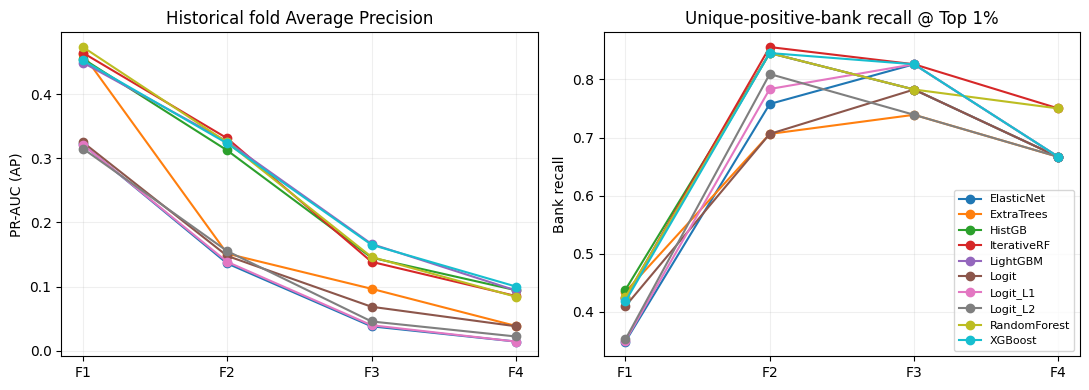

INTERPRETATION: cross-fold dispersion matters; no test set was used.


In [397]:
# 5.1D — baseline fold variability plot (no refits).
if isinstance(P5_BASELINE_RESULTS,pd.DataFrame) and len(P5_BASELINE_RESULTS):
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    for model,g in P5_BASELINE_RESULTS.groupby('model'):
        g=g.sort_values('fold');axes[0].plot(g.fold,g.PR_AUC_AP,marker='o',label=model)
        axes[1].plot(g.fold,g.bank_recall_top1pct,marker='o',label=model)
    axes[0].set(title='Historical fold Average Precision',ylabel='PR-AUC (AP)')
    axes[1].set(title='Unique-positive-bank recall @ Top 1%',ylabel='Bank recall')
    for a in axes:a.grid(alpha=.2)
    axes[1].legend(fontsize=8,loc='best');plt.tight_layout();plt.show()
    print('INTERPRETATION: cross-fold dispersion matters; no test set was used.')
else:print('No baseline data in memory; run 5.1C under development mode.')

In [398]:
# 5.2A — select a bounded tuning shortlist from historical baseline CV only.
P5_GRID_ALL={
 'Logit_L2':[{'C':.1,'class_weight':'balanced'},{'C':3.0,'class_weight':'balanced'}],
 'Logit_L1':[{'C':.1,'class_weight':'balanced'},{'C':1.0,'class_weight':'balanced'}],
 'ElasticNet':[{'C':.1,'l1_ratio':.25,'class_weight':'balanced'},
               {'C':1.0,'l1_ratio':.75,'class_weight':'balanced'}],
 'RandomForest':[{'class_weight':'balanced_subsample','max_depth':12,'min_samples_leaf':75},
                 {'class_weight':'balanced_subsample','max_depth':18,'min_samples_leaf':25}],
 'ExtraTrees':[{'class_weight':'balanced_subsample','max_depth':12,'min_samples_leaf':60},
               {'class_weight':'balanced_subsample','max_depth':20,'min_samples_leaf':20}],
 'IterativeRF':[{'n_estimators':120,'n_iterations':3,'max_depth':16,
                 'min_samples_leaf':25,'class_weight':'balanced_subsample'}],
 'HistGB':[{'class_weight':'balanced','learning_rate':.03,'max_leaf_nodes':15,'max_iter':160},
           {'class_weight':'balanced','learning_rate':.08,'max_leaf_nodes':20,'max_iter':160}],
 'LightGBM':[{'class_weight':'balanced','num_leaves':15,'learning_rate':.05},
             {'num_leaves':23,'learning_rate':.035,'min_child_samples':60}],
 'XGBoost':[{'max_depth':3,'scale_pos_weight':5},
            {'max_depth':5,'scale_pos_weight':20}],
 'CatBoost':[{'depth':4,'iterations':240,'auto_class_weights':'SqrtBalanced'},
             {'depth':6,'iterations':240,'auto_class_weights':'SqrtBalanced'}]
}
assert all(len(v)<=2 for v in P5_GRID_ALL.values())
P5_GRID={};P5_TUNED_MODELS=[]
if isinstance(P5_BASELINE_RESULTS,pd.DataFrame) and len(P5_BASELINE_RESULTS):
    support_frame=P5_BASELINE_RESULTS.assign(
        support=lambda d: np.sqrt(np.maximum(d.positive_banks,1)))
    support_frame['weighted_AP']=support_frame.PR_AUC_AP*support_frame.support
    totals=support_frame.groupby('model').agg(
        weighted_AP=('weighted_AP','sum'),support=('support','sum'))
    supported=(totals.weighted_AP/totals.support).sort_values(ascending=False)
    P5_TUNED_MODELS=list(supported.head(P5_TUNE_TOP_N).index)
    if 'IterativeRF' not in P5_TUNED_MODELS:P5_TUNED_MODELS.append('IterativeRF')
    P5_GRID={m:P5_GRID_ALL[m] for m in P5_TUNED_MODELS if m in P5_GRID_ALL}
    print('Historical baseline shortlist:',P5_TUNED_MODELS)
    print('Extra configurations:',sum(map(len,P5_GRID.values())),'×',len(P5_FOLDS),'folds')
else:print('Tuning shortlist waits for historical baseline CV.')

Historical baseline shortlist: ['RandomForest', 'IterativeRF', 'XGBoost', 'LightGBM', 'HistGB']
Extra configurations: 9 × 4 folds


Do code 5.2B sẽ chạy rất lâu và tốn thời gian, vui lòng đọc luôn bảng kết quả đã có được ở 5.2C (đã chạy ở các lần thử trước)

In [399]:
# 5.2B — Giữ các baseline và bỏ tuning IterativeRF
P5_TUNING_RESULTS = []
P5_TUNING_OOF = {}

if P5_MODE == "development":
    assert len(P5_SELECTED_BY_FOLD) == len(P5_FOLDS), "Run 5.1C first."

    for model, params in P5_BASELINES.items():
        run_id = f"{model}_B0"
        P5_TUNING_OOF[run_id] = P5_BASELINE_OOF[model]

        baseline_rows = P5_BASELINE_RESULTS.loc[
            P5_BASELINE_RESULTS["model"] == model
        ]
        for _, row in baseline_rows.iterrows():
            record = row.to_dict()
            record.pop("model")
            P5_TUNING_RESULTS.append(dict(
                run_id=run_id,
                model=model,
                params_json=json.dumps(params, sort_keys=True),
                **record,
            ))

    for fold in P5_FOLDS:
        fid = fold["fold"]
        Xtr, ytr, _, Xva, yva, mva = p5_fold_data(fold)
        chosen = P5_SELECTED_BY_FOLD[fid]
        col_indices = [P5_CORE_FIELDS.index(feature) for feature in chosen]

        for model, params_list in P5_GRID.items():
            if model == "IterativeRF":
                continue

            for j, params in enumerate(params_list, start=1):
                run_id = f"{model}_T{j}"
                print(f"[TUNING] {fid} / {run_id}: fitting...", flush=True)

                fitted, score, sec = p5_fit_predict_fold(
                    Xtr, ytr, Xva, col_indices, model, params
                )
                metrics = p5_metric(yva, score, mva["CERT"])
                print(
                    f'[TUNING] {fid} / {run_id}: '
                    f'AP={metrics["PR_AUC_AP"]:.4f}; {sec:.1f}s',
                    flush=True,
                )

                P5_TUNING_RESULTS.append(dict(
                    run_id=run_id,
                    model=model,
                    params_json=json.dumps(params, sort_keys=True),
                    fold=fid,
                    fit_seconds=sec,
                    **metrics,
                ))
                P5_TUNING_OOF.setdefault(run_id, []).append(pd.DataFrame({
                    "fold": fid,
                    "CERT": mva["CERT"],
                    "REPDTE": mva["REPDTE"],
                    "y": yva,
                    "score": score,
                }))
                del fitted, score

        print(f"Tuned {fid}", flush=True)
        del Xtr, ytr, Xva, yva, mva
        gc.collect()

    P5_TUNING_RESULTS = pd.DataFrame(P5_TUNING_RESULTS)
    P5_TUNING_RESULTS.to_csv(
        P5_OUTPUT / "hyperparameter_search_results.csv", index=False
    )
else:
    print("SKIPPED — run 5.2B under development mode.")

[TUNING] F1 / RandomForest_T1: fitting...
[TUNING] F1 / RandomForest_T1: AP=0.4752; 51.3s
[TUNING] F1 / RandomForest_T2: fitting...
[TUNING] F1 / RandomForest_T2: AP=0.4756; 54.0s
[TUNING] F1 / XGBoost_T1: fitting...
[TUNING] F1 / XGBoost_T1: AP=0.4573; 4.2s
[TUNING] F1 / XGBoost_T2: fitting...
[TUNING] F1 / XGBoost_T2: AP=0.4554; 5.5s
[TUNING] F1 / LightGBM_T1: fitting...
[TUNING] F1 / LightGBM_T1: AP=0.4550; 2.6s
[TUNING] F1 / LightGBM_T2: fitting...
[TUNING] F1 / LightGBM_T2: AP=0.4528; 2.5s
[TUNING] F1 / HistGB_T1: fitting...
[TUNING] F1 / HistGB_T1: AP=0.4585; 24.7s
[TUNING] F1 / HistGB_T2: fitting...
[TUNING] F1 / HistGB_T2: AP=0.4350; 22.6s
Tuned F1
[TUNING] F2 / RandomForest_T1: fitting...
[TUNING] F2 / RandomForest_T1: AP=0.3201; 158.1s
[TUNING] F2 / RandomForest_T2: fitting...
[TUNING] F2 / RandomForest_T2: AP=0.3279; 183.6s
[TUNING] F2 / XGBoost_T1: fitting...
[TUNING] F2 / XGBoost_T1: AP=0.2721; 10.7s
[TUNING] F2 / XGBoost_T2: fitting...
[TUNING] F2 / XGBoost_T2: AP=0.3421;

In [400]:
# 5.2C — fold-level ranking; model choice is frozen BEFORE external evaluation.
P5_RANKING=pd.DataFrame();P5_DEV_WINNER=None;P5_DEV_WINNER_SPEC=None
if isinstance(P5_TUNING_RESULTS,pd.DataFrame) and len(P5_TUNING_RESULTS):
    # Historical folds are NOT equally precise. Weight by sqrt(distinct positive banks)
    # and retain a dispersion penalty; display raw means for transparency.
    ranks=[]
    for (run_id,model,params_json),g in P5_TUNING_RESULTS.groupby(
            ['run_id','model','params_json'],sort=True):
        ap=g.PR_AUC_AP.to_numpy(dtype=float)
        w=np.sqrt(np.maximum(g.positive_banks.to_numpy(dtype=float),1))
        valid=np.isfinite(ap)
        w=w[valid];ap=ap[valid]
        assert len(ap)==len(P5_FOLDS), 'Missing/undefined AP in a validation fold'
        mu=float(np.average(ap,weights=w))
        sd=float(np.sqrt(np.average((ap-mu)**2,weights=w)))
        ranks.append(dict(run_id=run_id,model=model,params_json=params_json,
           folds=len(ap),raw_mean_AP=float(ap.mean()),weighted_mean_AP=mu,
           weighted_sd_AP=sd,min_AP=float(ap.min()),
           mean_bank_recall=float(g.bank_recall_top1pct.mean()),
           mean_fit_sec=float(g.fit_seconds.mean()),
           stability_adjusted_AP=mu-.15*sd))
    score=pd.DataFrame(ranks).sort_values(
       ['stability_adjusted_AP','mean_bank_recall','run_id'],
       ascending=[False,False,True]).reset_index(drop=True)
    assert (score.folds==len(P5_FOLDS)).all()
    P5_RANKING=score
    first=score.iloc[0];P5_DEV_WINNER=str(first.run_id)
    P5_DEV_WINNER_SPEC={'run_id':P5_DEV_WINNER,'model':str(first.model),
                        'params':json.loads(first.params_json)}
    print('DEVELOPMENT WINNER (not selected on tests):',P5_DEV_WINNER_SPEC)
    display(score.round(4))
    score.to_csv(P5_OUTPUT/'fold_level_model_ranking.csv',index=False)
else:print('No tuned models yet. MAIN frozen Phase 4 LightGBM remains primary.')

DEVELOPMENT WINNER (not selected on tests): {'run_id': 'RandomForest_T2', 'model': 'RandomForest', 'params': {'class_weight': 'balanced_subsample', 'max_depth': 18, 'min_samples_leaf': 25}}


,run_id,model,params_json,folds,raw_mean_AP,weighted_mean_AP,weighted_sd_AP,min_AP,mean_bank_recall,mean_fit_sec,stability_adjusted_AP
0,RandomForest_T2,RandomForest,"{""class_weight"": ""balanced_subsample"", ""max_de...",4,0.2562,0.3901,0.1272,0.0820,0.7220,226.6094,0.3711
1,RandomForest_T1,RandomForest,"{""class_weight"": ""balanced_subsample"", ""max_de...",4,0.2584,0.3893,0.1254,0.0864,0.7125,1097.6310,0.3705
2,RandomForest_B0,RandomForest,"{""class_weight"": ""balanced_subsample""}",4,0.2571,0.3885,0.1251,0.0843,0.7008,256.3245,0.3698
3,IterativeRF_B0,IterativeRF,"{""class_weight"": ""balanced_subsample""}",4,0.2548,0.3839,0.1217,0.0854,0.7139,534.3066,0.3656
4,XGBoost_T2,XGBoost,"{""max_depth"": 5, ""scale_pos_weight"": 20}",4,0.2602,0.3825,0.1140,0.0905,0.6890,14.4222,0.3654
5,HistGB_T2,HistGB,"{""class_weight"": ""balanced"", ""learning_rate"": ...",4,0.2641,0.3776,0.1040,0.0875,0.6949,11.0540,0.3620
6,XGBoost_B0,XGBoost,{},4,0.2602,0.3777,0.1113,0.1002,0.6890,15.1663,0.3610
7,LightGBM_B0,LightGBM,{},4,0.2588,0.3759,0.1103,0.0941,0.6794,7.1779,0.3594
8,LightGBM_T2,LightGBM,"{""learning_rate"": 0.035, ""min_child_samples"": ...",4,0.2608,0.3760,0.1112,0.1197,0.6824,6.6954,0.3593
9,HistGB_B0,HistGB,"{""class_weight"": ""balanced""}",4,0.2517,0.3747,0.1177,0.0944,0.6832,18.2073,0.3571


In [401]:
# RF-STRATEGIES — So sánh các chiến lược RF trên validation F1–F4

if P5_MODE != "development":
    raise RuntimeError("Đặt P5_MODE = 'development' trước khi chạy.")
if not all(fold["fold"] in P5_SELECTED_BY_FOLD for fold in P5_FOLDS):
    raise RuntimeError("Chạy 5.1C trước để có bộ biến của từng fold.")

RF_TREES = 60
RF_JOBS = 2
RF_TOP_K = 25
RF_HALF_LIFE_YEARS = 5
RF_UPDATE_EVERY_YEARS = 2
RF_LABEL_DELAY_DAYS = 45  # Đệm sau khi đủ 4 quý, dùng cho backtest.

RF_PARAMS = {
    "n_estimators": RF_TREES,
    "n_jobs": RF_JOBS,
    "class_weight": "balanced_subsample",
    "max_depth": 18,
    "min_samples_leaf": 25,
}

RF_STRATEGIES = {
    "RF T2 cố định": (False, False, False),
    "RF trọng số CERT": (False, True, False),
    "RF ưu tiên dữ liệu gần": (False, False, True),
    "RF walk-forward": (True, False, False),
    "RF kết hợp": (True, True, True),
}


def rf_strategy_weights(y, cert, dates, by_cert, by_recency):
    if not (by_cert or by_recency):
        return None

    weights = np.ones(len(y), dtype=float)
    positive = y == 1

    if by_cert:
        positive_cert = pd.Series(cert[positive])
        repeats = positive_cert.groupby(positive_cert).transform("size")
        weights[positive] = 1.0 / repeats.to_numpy(dtype=float)

    if by_recency:
        dates = pd.DatetimeIndex(dates)
        age_years = (dates.max() - dates).days.to_numpy() / 365.25
        weights *= np.exp2(-age_years / RF_HALF_LIFE_YEARS)

    # Giữ tổng trọng số ban đầu của mỗi lớp. Thay đổi cách phân bổ trong lớp.
    for mask in (positive, ~positive):
        weights[mask] *= mask.sum() / weights[mask].sum()

    return weights


def rf_strategy_fit(X, y, cert, dates, indices, by_cert, by_recency):
    model = p5_pipe("RandomForest", indices, RF_PARAMS)
    weights = rf_strategy_weights(y, cert, dates, by_cert, by_recency)

    if weights is None:
        model.fit(X, y)
    else:
        model.fit(X, y, model__sample_weight=weights)

    return model


rf_strategy_rows = []
P5_RF_STRATEGY_OOF = {}

for fold in P5_FOLDS:
    fid = fold["fold"]
    Xtr, ytr, mtr, Xva, yva, mva = p5_fold_data(fold)
    ytr, yva = np.asarray(ytr), np.asarray(yva)
    train_cert = np.asarray(mtr["CERT"])
    val_cert = np.asarray(mva["CERT"])
    train_dates = pd.DatetimeIndex(pd.to_datetime(mtr["REPDTE"]))
    val_dates = pd.DatetimeIndex(pd.to_datetime(mva["REPDTE"]))
    indices = [P5_CORE_FIELDS.index(f) for f in P5_SELECTED_BY_FOLD[fid]]

    if (
        train_dates.hasnans or val_dates.hasnans
        or train_dates.max() >= val_dates.min()
        or np.unique(ytr).size != 2
        or not np.any(yva == 1)
    ):
        raise ValueError(f"{fid}: ngày, thứ tự chia tập hoặc nhãn không hợp lệ.")

    # Ngày sớm nhất một dòng validation có thể được đưa vào train.
    # Dùng đủ 4 quý và cùng một độ trễ cho cả nhãn âm lẫn dương.
    label_ready = (
        val_dates + pd.offsets.QuarterEnd(4)
        + pd.Timedelta(days=RF_LABEL_DELAY_DAYS)
    )
    val_year = val_dates.year.to_numpy()
    first_year, last_year = int(val_year.min()), int(val_year.max())
    update_years = range(first_year, last_year + 1, RF_UPDATE_EVERY_YEARS)

    for name, (adaptive, by_cert, by_recency) in RF_STRATEGIES.items():
        print(f"{fid} | {name} | đang chạy...", flush=True)
        scores = np.full(len(yva), np.nan)
        fits = 0

        if not adaptive:
            model = rf_strategy_fit(
                Xtr, ytr, train_cert, train_dates, indices, by_cert, by_recency
            )
            scores[:] = model.predict_proba(Xva)[:, list(model.classes_).index(1)]
            fits = 1
            del model

        else:
            for year in update_years:
                block = (val_year >= year) & (
                    val_year < year + RF_UPDATE_EVERY_YEARS
                )
                if not block.any():
                    continue

                update_date = pd.Timestamp(year=year, month=1, day=1)
                mature = label_ready < update_date
                if np.any(block & mature):
                    raise RuntimeError(f"{fid}: dòng dự báo lọt vào train.")

                if mature.any():
                    X_fit = np.concatenate([Xtr, Xva[mature]], axis=0)
                    y_fit = np.concatenate([ytr, yva[mature]])
                    cert_fit = np.concatenate([train_cert, val_cert[mature]])
                    dates_fit = train_dates.append(val_dates[mature])
                else:
                    X_fit, y_fit = Xtr, ytr
                    cert_fit, dates_fit = train_cert, train_dates

                print(
                    f"  Mốc {year} | {int(mature.sum()):,} dòng bổ sung "
                    f"| {int(block.sum()):,} dòng dự báo",
                    flush=True,
                )
                model = rf_strategy_fit(
                    X_fit, y_fit, cert_fit, dates_fit, indices, by_cert, by_recency
                )
                scores[block] = model.predict_proba(Xva[block])[
                    :, list(model.classes_).index(1)
                ]
                fits += 1
                del model, X_fit, y_fit, cert_fit, dates_fit

        if not np.isfinite(scores).all():
           raise RuntimeError(f"{fid} / {name}: thiếu điểm validation.")

# Lưu dự báo OOF của hai chiến lược cần so sánh
        if name in ["RF T2 cố định", "RF ưu tiên dữ liệu gần"]:
           P5_RF_STRATEGY_OOF[(fid, name)] = pd.DataFrame({
           "fold": fid,
           "CERT": np.asarray(mva["CERT"]),
           "REPDTE": pd.to_datetime(mva["REPDTE"]),
           "y": np.asarray(yva).ravel(),
           "score": scores.copy(),
           })

        _, top = p5_quarterly_alerts(mva, scores, k=RF_TOP_K)
        ap = average_precision_score(yva, scores)
        rf_strategy_rows.append({
            "fold": fid,
            "strategy": name,
            "AP": ap,
            "detected_banks": top["detected_positive_banks"],
            "positive_banks": top["positive_banks"],
            "bank_recall_top25": top["bank_recall"],
            "false_alerts_top25": top["false_alerts"],
            "fits": fits,
        })
        print(
            f"  AP={ap:.4f} | Bank recall@25={top['bank_recall']:.2%}",
            flush=True,
        )

    del Xtr, Xva, ytr, yva, mtr, mva
    gc.collect()

P5_RF_STRATEGY_BY_FOLD = pd.DataFrame(rf_strategy_rows)
P5_RF_STRATEGY_SUMMARY = P5_RF_STRATEGY_BY_FOLD.groupby(
    "strategy", as_index=False
).agg(
    mean_AP=("AP", "mean"),
    detected_bank_folds=("detected_banks", "sum"),
    positive_bank_folds=("positive_banks", "sum"),
    worst_fold_recall=("bank_recall_top25", "min"),
    false_alerts_top25=("false_alerts_top25", "sum"),
    total_fits=("fits", "sum"),
)

summary = P5_RF_STRATEGY_SUMMARY
summary["bank_recall_top25"] = (
    summary["detected_bank_folds"] / summary["positive_bank_folds"]
)
base = summary.loc[summary["strategy"].eq("RF T2 cố định")].iloc[0]
summary["extra_banks_vs_fixed"] = (
    summary["detected_bank_folds"] - base["detected_bank_folds"]
)
summary["extra_false_alerts_vs_fixed"] = (
    summary["false_alerts_top25"] - base["false_alerts_top25"]
)

P5_RF_STRATEGY_SUMMARY = summary.sort_values(
    ["bank_recall_top25", "mean_AP", "false_alerts_top25"],
    ascending=[False, False, True],
).reset_index(drop=True)

display(P5_RF_STRATEGY_SUMMARY.round(5))
display(P5_RF_STRATEGY_BY_FOLD.round(5))

F1 | RF T2 cố định | đang chạy...
  AP=0.4696 | Bank recall@25=11.21%
F1 | RF trọng số CERT | đang chạy...
  AP=0.4653 | Bank recall@25=11.95%
F1 | RF ưu tiên dữ liệu gần | đang chạy...
  AP=0.4732 | Bank recall@25=12.32%
F1 | RF walk-forward | đang chạy...
  Mốc 1988 | 0 dòng bổ sung | 132,374 dòng dự báo
  Mốc 1990 | 51,063 dòng bổ sung | 62,506 dòng dự báo
  AP=0.4661 | Bank recall@25=11.06%
F1 | RF kết hợp | đang chạy...
  Mốc 1988 | 0 dòng bổ sung | 132,374 dòng dự báo
  Mốc 1990 | 51,063 dòng bổ sung | 62,506 dòng dự báo
  AP=0.4673 | Bank recall@25=11.88%
F2 | RF T2 cố định | đang chạy...
  AP=0.3321 | Bank recall@25=39.18%
F2 | RF trọng số CERT | đang chạy...
  AP=0.3354 | Bank recall@25=37.11%
F2 | RF ưu tiên dữ liệu gần | đang chạy...
  AP=0.3458 | Bank recall@25=38.14%
F2 | RF walk-forward | đang chạy...
  Mốc 1992 | 0 dòng bổ sung | 111,486 dòng dự báo
  Mốc 1994 | 42,982 dòng bổ sung | 51,867 dòng dự báo
  AP=0.3364 | Bank recall@25=39.69%
F2 | RF kết hợp | đang chạy...
  

,strategy,mean_AP,detected_bank_folds,positive_bank_folds,worst_fold_recall,false_alerts_top25,total_fits,bank_recall_top25,extra_banks_vs_fixed,extra_false_alerts_vs_fixed
0,RF ưu tiên dữ liệu gần,0.26121,262,1576,0.12324,912,4,0.16624,15,-9
1,RF kết hợp,0.26391,255,1576,0.11878,920,8,0.16180,8,-1
2,RF trọng số CERT,0.25875,254,1576,0.11952,916,4,0.16117,7,-5
3,RF T2 cố định,0.25307,247,1576,0.11210,921,4,0.15673,0,0
4,RF walk-forward,0.25311,246,1576,0.11062,924,8,0.15609,-1,3


,fold,strategy,AP,detected_banks,positive_banks,bank_recall_top25,false_alerts_top25,fits
0,F1,RF T2 cố định,0.46961,151,1347,0.11210,82,1
1,F1,RF trọng số CERT,0.46533,161,1347,0.11952,74,1
2,F1,RF ưu tiên dữ liệu gần,0.47321,166,1347,0.12324,74,1
3,F1,RF walk-forward,0.46613,149,1347,0.11062,86,2
4,F1,RF kết hợp,0.46729,160,1347,0.11878,81,2
5,F2,RF T2 cố định,0.33214,76,194,0.39175,193,1
6,F2,RF trọng số CERT,0.33543,72,194,0.37113,196,1
7,F2,RF ưu tiên dữ liệu gần,0.34576,74,194,0.38144,192,1
8,F2,RF walk-forward,0.33640,77,194,0.39691,192,2
9,F2,RF kết hợp,0.34599,74,194,0.38144,195,2


In [402]:
# Chọn chiến lược RF T2 đứng đầu trên validation
P5_RF_STRATEGY_RANKING = P5_RF_STRATEGY_SUMMARY.copy()
P5_RF_STRATEGY_WINNER = P5_RF_STRATEGY_RANKING.iloc[0]["strategy"]

print(f"Chiến lược đứng đầu trên validation: {P5_RF_STRATEGY_WINNER}")
display(P5_RF_STRATEGY_RANKING.round(5))

# So sánh chiến lược thắng với RF T2 cố định theo từng fold
display(
    P5_RF_STRATEGY_BY_FOLD.loc[
        P5_RF_STRATEGY_BY_FOLD["strategy"].isin(
            ["RF T2 cố định", P5_RF_STRATEGY_WINNER]
        )
    ].sort_values(["fold", "strategy"]).round(5)
)

Chiến lược đứng đầu trên validation: RF ưu tiên dữ liệu gần


,strategy,mean_AP,detected_bank_folds,positive_bank_folds,worst_fold_recall,false_alerts_top25,total_fits,bank_recall_top25,extra_banks_vs_fixed,extra_false_alerts_vs_fixed
0,RF ưu tiên dữ liệu gần,0.26121,262,1576,0.12324,912,4,0.16624,15,-9
1,RF kết hợp,0.26391,255,1576,0.11878,920,8,0.16180,8,-1
2,RF trọng số CERT,0.25875,254,1576,0.11952,916,4,0.16117,7,-5
3,RF T2 cố định,0.25307,247,1576,0.11210,921,4,0.15673,0,0
4,RF walk-forward,0.25311,246,1576,0.11062,924,8,0.15609,-1,3


,fold,strategy,AP,detected_banks,positive_banks,bank_recall_top25,false_alerts_top25,fits
0,F1,RF T2 cố định,0.46961,151,1347,0.11210,82,1
2,F1,RF ưu tiên dữ liệu gần,0.47321,166,1347,0.12324,74,1
5,F2,RF T2 cố định,0.33214,76,194,0.39175,193,1
7,F2,RF ưu tiên dữ liệu gần,0.34576,74,194,0.38144,192,1
10,F3,RF T2 cố định,0.14989,14,23,0.60870,362,1
12,F3,RF ưu tiên dữ liệu gần,0.14323,15,23,0.65217,362,1
15,F4,RF T2 cố định,0.06066,6,12,0.50000,284,1
17,F4,RF ưu tiên dữ liệu gần,0.08263,7,12,0.58333,284,1


F1: 194,880 paired OOF rows | 12 quarters | 18,241 banks
F2: 163,353 paired OOF rows | 12 quarters | 14,735 banks
F3: 170,344 paired OOF rows | 16 quarters | 12,394 banks
F4: 112,288 paired OOF rows | 12 quarters | 9,974 banks

Original OOF results:


,Value
AP_base,0.253075
AP_recent,0.261206
Recall_base,0.156726
Recall_recent,0.166244
Hits_base,247.000000
Hits_recent,262.000000
False_base,921.000000
False_recent,912.000000


PASS — OOF metrics match original RF strategy summary.
Bootstrap: 200/2,000
Bootstrap: 400/2,000
Bootstrap: 600/2,000
Bootstrap: 800/2,000
Bootstrap: 1,000/2,000
Bootstrap: 1,200/2,000
Bootstrap: 1,400/2,000
Bootstrap: 1,600/2,000
Bootstrap: 1,800/2,000
Bootstrap: 2,000/2,000

PAIRED BLOCK BOOTSTRAP — VALIDATION F1-F4


,metric,observed_difference,bootstrap_mean,CI_95_lower,CI_95_upper,bootstrap_share_positive,valid_bootstrap_samples,conclusion
0,Mean_AP,0.008131,0.008545,0.000579,0.015429,0.9820,2000,RF gần có lợi thế
1,Bank_Recall_pp,0.951777,0.875065,0.385724,1.228145,0.9960,2000,RF gần có lợi thế
2,Detected_bank_folds,15.000000,11.008000,5.000000,17.000000,0.9960,2000,RF gần có lợi thế
3,False_alert_reduction,9.000000,11.103000,-1.000000,23.000000,0.9595,2000,Chưa đủ bằng chứng khác biệt


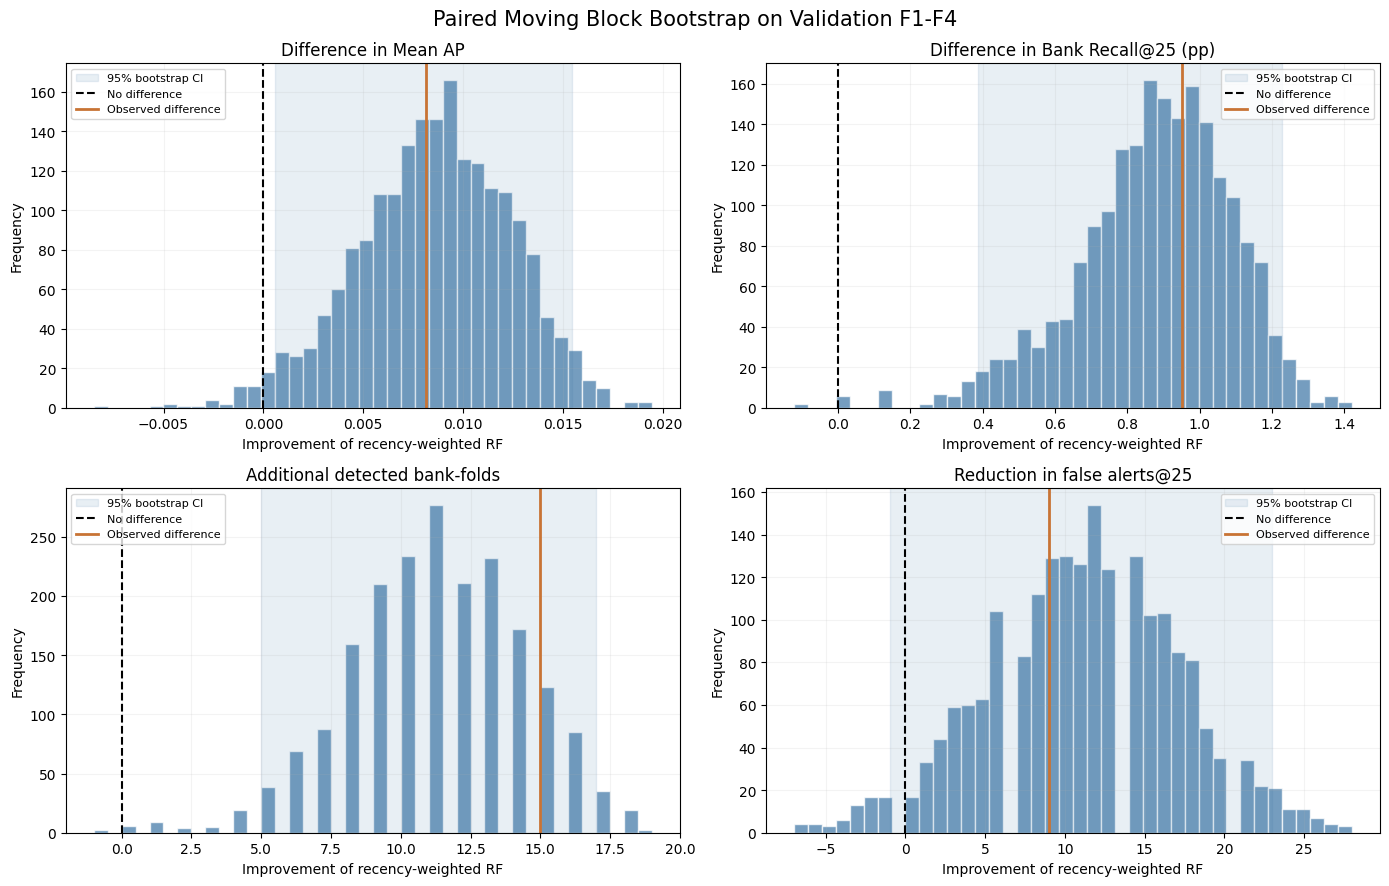


PRIMARY METRIC: BANK RECALL@25
Observed improvement: +0.9518 pp
95% CI: [+0.3857, +1.2281] pp
KẾT LUẬN: Có bằng chứng bootstrap ủng hộ RF ưu tiên dữ liệu gần trên Validation.

PASS — Validation only; no external test access.


In [406]:
# ============================================================
# 5.2C-BOOTSTRAP
# Paired Moving Block Bootstrap — VALIDATION ONLY
# RF T2 cố định vs RF ưu tiên dữ liệu gần
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import average_precision_score

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

BOOT_N = 2000
BOOT_BLOCK = 4
BOOT_SEED = 4903
BOOT_K = 25
BOOT_ALPHA = 0.05

BOOT_BASE = "RF T2 cố định"
BOOT_CHALLENGER = "RF ưu tiên dữ liệu gần"

rng = np.random.default_rng(BOOT_SEED)

assert P5_MODE == "development", (
    "Bootstrap chỉ được thực hiện trong development mode."
)

assert "P5_RF_STRATEGY_OOF" in globals(), (
    "Hãy bổ sung lưu OOF và chạy lại cell RF-STRATEGIES."
)

# ------------------------------------------------------------
# 2. Prepare paired OOF predictions
# ------------------------------------------------------------

BOOT_FOLD_DATA = {}

for fold in P5_FOLDS:

    fid = fold["fold"]

    base = P5_RF_STRATEGY_OOF[
        (fid, BOOT_BASE)
    ].copy()

    recent = P5_RF_STRATEGY_OOF[
        (fid, BOOT_CHALLENGER)
    ].copy()

    pair = base.merge(
        recent,
        on=["fold", "CERT", "REPDTE", "y"],
        suffixes=("_base", "_recent"),
        validate="one_to_one"
    )

    assert len(pair) == len(base) == len(recent)
    assert pair["y"].isin([0, 1]).all()

    pair = pair.sort_values(
        ["REPDTE", "CERT"]
    ).reset_index(drop=True)

    # Rank independently within each quarter
    for model in ["base", "recent"]:

        ordered = pair.sort_values(
            ["REPDTE", f"score_{model}", "CERT"],
            ascending=[True, False, True],
            kind="stable"
        )

        ranks = (
            ordered.groupby("REPDTE")
            .cumcount()
            .add(1)
        )

        pair[f"alert_{model}"] = (
            ranks.le(BOOT_K)
            .reindex(pair.index)
            .to_numpy()
        )

    quarters = np.array(
        sorted(pair["REPDTE"].unique())
    )

    quarter_id = pd.Categorical(
        pair["REPDTE"],
        categories=quarters,
        ordered=True
    ).codes

    bank_id, bank_unique = pd.factorize(
        pair["CERT"],
        sort=True
    )

    y = pair["y"].to_numpy(dtype=np.int8)

    positive = y == 1

    BOOT_FOLD_DATA[fid] = {
        "n_quarters": len(quarters),
        "n_banks": len(bank_unique),
        "quarter_id": quarter_id,
        "bank_id": bank_id,
        "y": y,
        "positive": positive,

        "score_base":
            pair["score_base"].to_numpy(),

        "score_recent":
            pair["score_recent"].to_numpy(),

        "alert_base":
            pair["alert_base"].to_numpy(dtype=bool),

        "alert_recent":
            pair["alert_recent"].to_numpy(dtype=bool),
    }

    print(
        f"{fid}: {len(pair):,} paired OOF rows | "
        f"{len(quarters)} quarters | "
        f"{len(bank_unique):,} banks"
    )

# ------------------------------------------------------------
# 3. Moving block sampling
# ------------------------------------------------------------

def boot_quarter_weights(n_quarters, block_size, rng):

    block_size = min(block_size, n_quarters)

    n_blocks = int(
        np.ceil(n_quarters / block_size)
    )

    starts = rng.integers(
        0,
        n_quarters - block_size + 1,
        size=n_blocks
    )

    sampled = np.concatenate([
        np.arange(start, start + block_size)
        for start in starts
    ])[:n_quarters]

    return np.bincount(
        sampled,
        minlength=n_quarters
    )

# ------------------------------------------------------------
# 4. Metrics for a sampled validation fold
# ------------------------------------------------------------

def boot_fold_metrics(data, quarter_weights):

    weights = quarter_weights[
        data["quarter_id"]
    ]

    included = weights > 0

    y = data["y"]
    positive = data["positive"]
    bank = data["bank_id"]

    positive_included = positive & included

    positive_banks = np.unique(
        bank[positive_included]
    ).size

    result = {
        "positive_banks": positive_banks
    }

    for model in ["base", "recent"]:

        score = data[f"score_{model}"]
        alert = data[f"alert_{model}"]

        if positive_banks > 0:

            ap = average_precision_score(
                y[included],
                score[included],
                sample_weight=weights[included]
            )

        else:
            ap = np.nan

        hits = np.unique(
            bank[positive_included & alert]
        ).size

        false_alerts = np.sum(
            weights[(y == 0) & alert]
        )

        result[f"AP_{model}"] = ap
        result[f"hits_{model}"] = hits
        result[f"false_{model}"] = false_alerts

    return result

# ------------------------------------------------------------
# 5. Aggregate metrics across F1-F4
# ------------------------------------------------------------

def boot_aggregate(fold_results):

    frame = pd.DataFrame(fold_results)

    n_positive = frame["positive_banks"].sum()

    if n_positive == 0:
        return None

    # Keep Mean AP comparable across all four folds
    if frame[["AP_base", "AP_recent"]].isna().any().any():
        return None

    return {
        "AP_base":
            frame["AP_base"].mean(),

        "AP_recent":
            frame["AP_recent"].mean(),

        "Recall_base":
            frame["hits_base"].sum() / n_positive,

        "Recall_recent":
            frame["hits_recent"].sum() / n_positive,

        "Hits_base":
            frame["hits_base"].sum(),

        "Hits_recent":
            frame["hits_recent"].sum(),

        "False_base":
            frame["false_base"].sum(),

        "False_recent":
            frame["false_recent"].sum(),
    }

def boot_differences(metrics):

    return {
        "Mean_AP":
            metrics["AP_recent"] - metrics["AP_base"],

        "Bank_Recall_pp":
            100 * (
                metrics["Recall_recent"]
                - metrics["Recall_base"]
            ),

        "Detected_bank_folds":
            metrics["Hits_recent"]
            - metrics["Hits_base"],

        # Positive means recency weighting reduces false alerts
        "False_alert_reduction":
            metrics["False_base"]
            - metrics["False_recent"]
    }

# ------------------------------------------------------------
# 6. Original OOF point estimates
# ------------------------------------------------------------

original_folds = []

for fid, data in BOOT_FOLD_DATA.items():

    weights = np.ones(
        data["n_quarters"],
        dtype=int
    )

    original_folds.append(
        boot_fold_metrics(data, weights)
    )

BOOT_ORIGINAL = boot_aggregate(original_folds)

BOOT_POINT = boot_differences(BOOT_ORIGINAL)

print("\nOriginal OOF results:")
display(
    pd.DataFrame([BOOT_ORIGINAL]).T
    .rename(columns={0: "Value"})
    .round(6)
)

# ------------------------------------------------------------
# 7. Reconcile with existing RF summary
# ------------------------------------------------------------

for name, suffix in [
    (BOOT_BASE, "base"),
    (BOOT_CHALLENGER, "recent")
]:

    ref = P5_RF_STRATEGY_SUMMARY.loc[
        P5_RF_STRATEGY_SUMMARY["strategy"].eq(name)
    ].iloc[0]

    assert np.isclose(
        BOOT_ORIGINAL[f"AP_{suffix}"],
        ref["mean_AP"]
    )

    assert np.isclose(
        BOOT_ORIGINAL[f"Recall_{suffix}"],
        ref["bank_recall_top25"]
    )

    assert (
        BOOT_ORIGINAL[f"Hits_{suffix}"]
        == ref["detected_bank_folds"]
    )

    assert (
        BOOT_ORIGINAL[f"False_{suffix}"]
        == ref["false_alerts_top25"]
    )

print("PASS — OOF metrics match original RF strategy summary.")

# ------------------------------------------------------------
# 8. Paired moving block bootstrap
# ------------------------------------------------------------

bootstrap_rows = []

for b in range(BOOT_N):

    fold_results = []

    for fid, data in BOOT_FOLD_DATA.items():

        quarter_weights = boot_quarter_weights(
            data["n_quarters"],
            BOOT_BLOCK,
            rng
        )

        fold_results.append(
            boot_fold_metrics(
                data,
                quarter_weights
            )
        )

    aggregated = boot_aggregate(fold_results)

    if aggregated is not None:

        bootstrap_rows.append(
            boot_differences(aggregated)
        )

    if (b + 1) % 200 == 0:

        print(
            f"Bootstrap: {b + 1:,}/{BOOT_N:,}",
            flush=True
        )

P5_RF_BOOTSTRAP_DISTRIBUTION = pd.DataFrame(
    bootstrap_rows
)

assert len(P5_RF_BOOTSTRAP_DISTRIBUTION) > 0

# ------------------------------------------------------------
# 9. Confidence intervals
# ------------------------------------------------------------

summary_rows = []

for metric in P5_RF_BOOTSTRAP_DISTRIBUTION.columns:

    samples = (
        P5_RF_BOOTSTRAP_DISTRIBUTION[metric]
        .dropna()
        .to_numpy()
    )

    lower, upper = np.quantile(
        samples,
        [BOOT_ALPHA / 2, 1 - BOOT_ALPHA / 2]
    )

    if lower > 0:
        conclusion = "RF gần có lợi thế"

    elif upper < 0:
        conclusion = "RF T2 có lợi thế"

    else:
        conclusion = "Chưa đủ bằng chứng khác biệt"

    summary_rows.append({
        "metric": metric,
        "observed_difference": BOOT_POINT[metric],
        "bootstrap_mean": samples.mean(),
        "CI_95_lower": lower,
        "CI_95_upper": upper,
        "bootstrap_share_positive": (
            samples > 0
        ).mean(),
        "valid_bootstrap_samples": len(samples),
        "conclusion": conclusion
    })

P5_RF_BOOTSTRAP_SUMMARY = pd.DataFrame(
    summary_rows
)

print("\n" + "=" * 75)
print("PAIRED BLOCK BOOTSTRAP — VALIDATION F1-F4")
print("=" * 75)

display(
    P5_RF_BOOTSTRAP_SUMMARY.round(6)
)

# ------------------------------------------------------------
# 10. Visualisation
# ------------------------------------------------------------

plot_titles = {
    "Mean_AP": "Difference in Mean AP",
    "Bank_Recall_pp": "Difference in Bank Recall@25 (pp)",
    "Detected_bank_folds": "Additional detected bank-folds",
    "False_alert_reduction": "Reduction in false alerts@25"
}

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 9)
)

for ax, metric in zip(
    axes.ravel(),
    plot_titles
):

    samples = P5_RF_BOOTSTRAP_DISTRIBUTION[
        metric
    ].dropna()

    lower, upper = samples.quantile(
        [0.025, 0.975]
    )

    ax.hist(
        samples,
        bins=40,
        color="#477DAA",
        alpha=0.75,
        edgecolor="white"
    )

    ax.axvspan(
        lower,
        upper,
        alpha=0.12,
        color="#477DAA",
        label="95% bootstrap CI"
    )

    ax.axvline(
        0,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="No difference"
    )

    ax.axvline(
        BOOT_POINT[metric],
        color="#C87334",
        linewidth=2,
        label="Observed difference"
    )

    ax.set_title(plot_titles[metric])
    ax.set_xlabel("Improvement of recency-weighted RF")
    ax.set_ylabel("Frequency")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.15)

fig.suptitle(
    "Paired Moving Block Bootstrap on Validation F1-F4",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. Interpretation of primary metric
# ------------------------------------------------------------

primary = P5_RF_BOOTSTRAP_SUMMARY.loc[
    P5_RF_BOOTSTRAP_SUMMARY["metric"]
    .eq("Bank_Recall_pp")
].iloc[0]

print("\nPRIMARY METRIC: BANK RECALL@25")

print(
    f"Observed improvement: "
    f"{primary['observed_difference']:+.4f} pp"
)

print(
    f"95% CI: "
    f"[{primary['CI_95_lower']:+.4f}, "
    f"{primary['CI_95_upper']:+.4f}] pp"
)

if primary["CI_95_lower"] > 0:

    print(
        "KẾT LUẬN: Có bằng chứng bootstrap ủng hộ "
        "RF ưu tiên dữ liệu gần trên Validation."
    )

elif primary["CI_95_upper"] < 0:

    print(
        "KẾT LUẬN: Có bằng chứng bootstrap ủng hộ "
        "RF T2 trên Validation."
    )

else:

    print(
        "KẾT LUẬN: Chưa đủ bằng chứng về lợi thế "
        "của RF ưu tiên dữ liệu gần."
    )

    print(
        "Có thể cân nhắc giữ RF T2 vì tính đơn giản, "
        "nhưng không được kết luận hai mô hình tương đương."
    )

print("\nPASS — Validation only; no external test access.")

In [403]:
# Sau cell rank, trước 5.3A — So sánh hai RF, không fit lại
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    log_loss,
    roc_auc_score,
)

rf_names = ["RF T2 cố định", "RF ưu tiên dữ liệu gần"]
rf_frozen_saved = globals().get("P5_EXTERNAL_CHALLENGER")
rf_recent_saved = globals().get("rf_recent")

P5_RF_TRAIN_METRICS = None

if all(
    hasattr(pipeline, "classes_")
    for pipeline in (rf_frozen_saved, rf_recent_saved)
):
    print("Đang chấm TRAIN 1985–2006 bằng hai RF đã fit...", flush=True)
    X_train, y_train, train_meta = p5_collect_window(
        (1985, 2006), P5_CORE_FIELDS
    )
    y_train = np.asarray(y_train).ravel()

    train_frame = pd.DataFrame({
        "CERT": np.asarray(train_meta["CERT"]),
        "REPDTE": pd.to_datetime(train_meta["REPDTE"]),
        "y": y_train,
    })

    event_rate = float(y_train.mean())
    baseline_brier = event_rate * (1 - event_rate)
    baseline_log_loss = -(
        event_rate * np.log(event_rate)
        + (1 - event_rate) * np.log1p(-event_rate)
    )

    train_rows = []
    for name, pipeline in [
        ("RF T2 frozen", rf_frozen_saved),
        ("RF ưu tiên dữ liệu gần", rf_recent_saved),
    ]:
        print(f"TRAIN | {name}", flush=True)
        positive_idx = list(pipeline.classes_).index(1)
        scores = pipeline.predict_proba(X_train)[:, positive_idx]

        brier = brier_score_loss(y_train, scores)
        loss = log_loss(y_train, scores, labels=[0, 1])
        ap = average_precision_score(y_train, scores)
        _, top = p5_quarterly_alerts(train_frame, scores, k=25)

        train_rows.append({
            "model": name,
            "Brier": brier,
            "Brier_skill": 1 - brier / baseline_brier,
            "Log_loss": loss,
            "Log_loss_skill": 1 - loss / baseline_log_loss,
            "AP": ap,
            "AP_lift": ap / event_rate,
            "ROC_AUC": roc_auc_score(y_train, scores),
            "mean_score_gap_pp": 100 * (scores.mean() - event_rate),
            "precision_top25_pct": 100 * top["precision"],
            "quarter_recall_top25_pct": 100 * top["recall"],
            "bank_recall_top25_pct": 100 * top["bank_recall"],
            "detected_banks_top25": top["detected_positive_banks"],
            "false_alerts_top25": top["false_alerts"],
        })

    P5_RF_TRAIN_METRICS = pd.DataFrame(train_rows).set_index("model")
    display(P5_RF_TRAIN_METRICS.T.round(6))

    del X_train, y_train, train_meta, train_frame, scores
    gc.collect()

else:
    print(
        "Kernel chưa có đủ hai RF đã fit để chấm TRAIN. "
        "Hiển thị kết quả validation đã lưu; Brier và Log-loss chưa có."
    )
    display(
        P5_RF_STRATEGY_BY_FOLD.loc[
            P5_RF_STRATEGY_BY_FOLD["strategy"].isin(rf_names),
            [
                "fold", "strategy", "AP", "bank_recall_top25",
                "detected_banks", "false_alerts_top25",
            ],
        ].sort_values(["fold", "strategy"]).round(6)
    )

Đang chấm TRAIN 1985–2006 bằng hai RF đã fit...
TRAIN | RF T2 frozen
TRAIN | RF ưu tiên dữ liệu gần


model,RF T2 frozen,RF ưu tiên dữ liệu gần
Brier,0.012403,0.020556
Brier_skill,-0.701359,-1.819776
Log_loss,0.046447,0.078535
Log_loss_skill,-0.070118,-0.809432
AP,0.672830,0.607532
AP_lift,91.618984,82.727422
ROC_AUC,0.996709,0.995136
mean_score_gap_pp,2.650979,3.992109
precision_top25_pct,45.000000,43.090909
quarter_recall_top25_pct,12.016021,11.506251


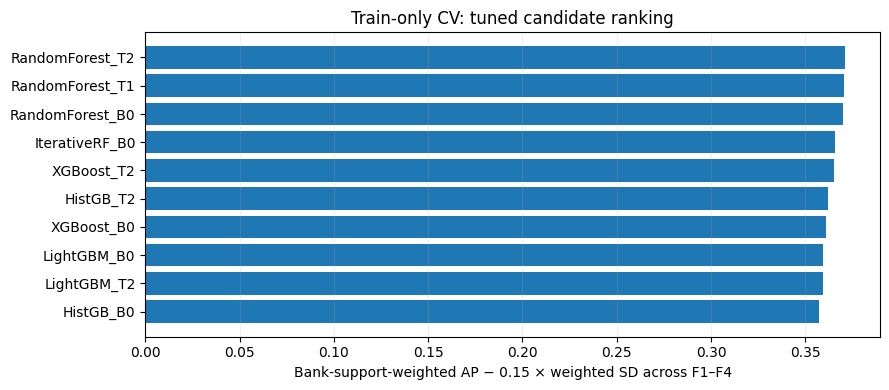

Winner: RandomForest_T2
NOTICE: the frozen Phase 4 LightGBM remains the declared MAIN incumbent.


In [404]:
# 5.2D — interpretation of development winner: AP and alert trade-off.
if len(P5_RANKING):
    fig,ax=plt.subplots(figsize=(9,4))
    top=P5_RANKING.head(10).iloc[::-1]
    ax.barh(top.run_id,top.stability_adjusted_AP)
    ax.set(xlabel='Bank-support-weighted AP − 0.15 × weighted SD across F1–F4',title='Train-only CV: tuned candidate ranking')
    ax.grid(axis='x',alpha=.2);plt.tight_layout();plt.show()
    print('Winner:',P5_DEV_WINNER)
    print('NOTICE: the frozen Phase 4 LightGBM remains the declared MAIN incumbent.')
else:print('Run 5.2C after development tuning.')

### Lựa chọn chiến lược Random Forest cuối cùng

Trên Validation F1–F4, RF ưu tiên dữ liệu gần đạt Mean AP
cao hơn RF T2 (0.26121 so với 0.25307), phát hiện thêm
15 ngân hàng–fold (262 so với 247), đồng thời giảm 9 cảnh báo
sai trong cùng ngân sách giám sát Top 25 mỗi quý.

Kết quả Paired Moving Block Bootstrap tiếp tục củng cố lợi thế
này. Bank Recall@25 tăng 0.9518 điểm phần trăm, với khoảng
tin cậy 95% từ +0.3857 đến +1.2281 điểm phần trăm.
Khoảng tin cậy không chứa 0, cho thấy mức cải thiện có ý nghĩa
thống kê. Biểu đồ bootstrap cũng cho thấy lợi thế về Mean AP
và số ngân hàng–fold được phát hiện, trong khi mức giảm cảnh
báo sai chưa có ý nghĩa thống kê rõ ràng.

Mặc dù RF T2 đạt kết quả tốt hơn trên toàn bộ TRAIN
1985–2006 (AP = 0.67283 so với 0.60753; Bank Recall@25 =
25.26% so với 23.90%), đây là kết quả đánh giá in-sample,
không phản ánh trực tiếp khả năng tổng quát hóa trên dữ liệu
chưa được học.

**Kết luận: Lựa chọn RF ưu tiên dữ liệu gần làm chiến lược
Random Forest cuối cùng vì có hiệu suất Validation tốt hơn
và mức cải thiện Bank Recall@25 có ý nghĩa thống kê.**

In [407]:

if P5_MODE != "development":
    raise RuntimeError("Đặt P5_MODE = 'development' trước khi chạy.")

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

CAMELS_9_FEATURES = [
    "asset_growth_4q",
    "cash_to_assets",
    "core_deposit_share",
    "deposits_to_assets",
    "equity_to_assets",
    "noncurrent_loan_ratio",
    "roa_rolling_mean_4q",
    "roa_rolling_std_4q",
    "securities_to_assets",
]

RECENCY_STRATEGY = "RF ưu tiên dữ liệu gần"

MODEL_40 = "RF gần Top 40"
MODEL_9 = "RF gần CAMELS 9"

TOP_K = RF_TOP_K

print("RF configuration:", RF_PARAMS)
print("Half-life:", RF_HALF_LIFE_YEARS, "years")
print("Top K:", TOP_K)

# ------------------------------------------------------------
# 2. Check CAMELS features and existing OOF predictions
# ------------------------------------------------------------

missing = sorted(
    set(CAMELS_9_FEATURES) - set(P5_CORE_FIELDS)
)

if missing:
    raise ValueError(
        f"P5_CORE_FIELDS thiếu các biến CAMELS: {missing}"
    )

camels_indices = [
    P5_CORE_FIELDS.index(name)
    for name in CAMELS_9_FEATURES
]

fold_ids = [
    fold["fold"] for fold in P5_FOLDS
]

if "P5_RF_STRATEGY_OOF" not in globals():
    raise RuntimeError(
        "Chạy cell RF-STRATEGIES đã bổ sung lưu OOF trước."
    )

reference_frames = []

for fid in fold_ids:

    key = (fid, RECENCY_STRATEGY)

    if key not in P5_RF_STRATEGY_OOF:
        raise RuntimeError(
            f"Thiếu dự báo RF gần Top 40 tại {fid}."
        )

    reference_frames.append(
        P5_RF_STRATEGY_OOF[key].copy()
    )

reference_oof = pd.concat(
    reference_frames,
    ignore_index=True
)

reference_oof["REPDTE"] = pd.to_datetime(
    reference_oof["REPDTE"]
)

if set(reference_oof["fold"]) != set(fold_ids):
    raise ValueError(
        "Dự báo RF gần Top 40 không khớp P5_FOLDS."
    )

if reference_oof.duplicated(
    ["fold", "CERT", "REPDTE"]
).any():
    raise ValueError(
        "Dự báo RF gần Top 40 có dòng trùng."
    )

# ------------------------------------------------------------
# 3. Fit RF recency CAMELS 9 and compare with Top 40
# ------------------------------------------------------------

rows = []

P5_RF_RECENCY_CAMELS_OOF = {}

for fold in P5_FOLDS:

    fid = fold["fold"]

    print("\n" + "=" * 65)
    print(f"{fid} | Đang đọc train và validation...", flush=True)

    Xtr, ytr, mtr, Xva, yva, mva = p5_fold_data(fold)

    ytr = np.asarray(ytr).ravel()
    yva = np.asarray(yva).ravel()

    train_cert = np.asarray(mtr["CERT"])

    train_dates = pd.DatetimeIndex(
        pd.to_datetime(mtr["REPDTE"])
    )

    val_dates = pd.DatetimeIndex(
        pd.to_datetime(mva["REPDTE"])
    )

    if (
        np.unique(ytr).size != 2
        or not np.any(yva == 1)
    ):
        raise ValueError(
            f"{fid}: thiếu nhãn cần thiết."
        )

    if (
        train_dates.hasnans
        or val_dates.hasnans
        or train_dates.max() >= val_dates.min()
    ):
        raise ValueError(
            f"{fid}: temporal split không hợp lệ."
        )

    if len(P5_SELECTED_BY_FOLD[fid]) != 40:
        raise ValueError(
            f"{fid}: bộ biến đối chứng không đủ 40 biến."
        )

    # --------------------------------------------------------
    # 3.1. Align validation keys and labels
    # --------------------------------------------------------

    current = pd.DataFrame({
        "CERT": np.asarray(mva["CERT"]),
        "REPDTE": val_dates,
        "y": yva,
    })

    keys = ["CERT", "REPDTE"]

    ref = (
        reference_oof.loc[
            reference_oof["fold"].eq(fid),
            keys + ["y", "score"]
        ]
        .set_index(keys)
    )

    current_keys = pd.MultiIndex.from_frame(
        current[keys]
    )

    if (
        not current_keys.is_unique
        or len(ref) != len(current)
        or not current_keys.isin(ref.index).all()
    ):
        raise ValueError(
            f"{fid}: hai model không dùng cùng dữ liệu validation."
        )

    ref = ref.reindex(current_keys)

    if not np.array_equal(
        ref["y"].to_numpy(),
        current["y"].to_numpy()
    ):
        raise ValueError(
            f"{fid}: nhãn validation không khớp."
        )

    # --------------------------------------------------------
    # 3.2. Reuse RF recency Top 40 predictions
    # --------------------------------------------------------

    score40 = ref["score"].to_numpy(dtype=float)

    # --------------------------------------------------------
    # 3.3. Fit RF recency CAMELS 9
    # Same strategy as RF-STRATEGIES
    # Only the feature set changes
    # --------------------------------------------------------

    print(
        f"{fid} | Đang fit RF gần CAMELS 9...",
        flush=True
    )

    model9 = rf_strategy_fit(
        Xtr,
        ytr,
        train_cert,
        train_dates,
        camels_indices,
        by_cert=False,
        by_recency=True
    )

    positive_col = list(model9.classes_).index(1)

    score9 = model9.predict_proba(Xva)[
        :, positive_col
    ]

    # --------------------------------------------------------
    # 3.4. Evaluate both models
    # --------------------------------------------------------

    for model_name, scores in [
        (MODEL_40, score40),
        (MODEL_9, score9),
    ]:

        if not np.isfinite(scores).all():
            raise ValueError(
                f"{fid} | {model_name}: "
                "điểm dự báo không hợp lệ."
            )

        _, metrics = p5_quarterly_alerts(
            current,
            scores,
            k=TOP_K
        )

        ap = average_precision_score(
            current["y"],
            scores
        )

        rows.append({
            "fold": fid,
            "model": model_name,
            "n_features": (
                9 if model_name == MODEL_9 else 40
            ),
            "AP": ap,
            "detected_banks_top25":
                metrics["detected_positive_banks"],
            "positive_banks":
                metrics["positive_banks"],
            "bank_recall_top25":
                metrics["bank_recall"],
            "false_alerts_top25":
                metrics["false_alerts"],
        })

        # Save OOF predictions for later statistical analysis

        P5_RF_RECENCY_CAMELS_OOF[
            (fid, model_name)
        ] = current.assign(
            fold=fid,
            score=scores
        )

        print(
            f"{fid} | {model_name} | "
            f"AP={ap:.5f} | "
            f"Bank Recall@25={metrics['bank_recall']:.2%} | "
            f"False alerts={metrics['false_alerts']:,}",
            flush=True
        )

    del Xtr, ytr, mtr, Xva, yva, mva
    del model9, score9, score40

    gc.collect()

# ------------------------------------------------------------
# 4. Results by fold
# ------------------------------------------------------------

P5_RF_RECENCY_CAMELS9_RESULTS = pd.DataFrame(rows)

print("\n" + "=" * 65)
print("RF RECENCY CAMELS 9 VS TOP 40 — BY FOLD")
print("=" * 65)

display(
    P5_RF_RECENCY_CAMELS9_RESULTS.round(5)
)

# ------------------------------------------------------------
# 5. Aggregate validation results
# ------------------------------------------------------------

P5_RF_RECENCY_CAMELS9_VAL_SUMMARY = (
    P5_RF_RECENCY_CAMELS9_RESULTS
    .groupby("model")
    .agg(
        n_features=("n_features", "first"),
        mean_AP=("AP", "mean"),
        detected_bank_folds=(
            "detected_banks_top25", "sum"
        ),
        positive_bank_folds=(
            "positive_banks", "sum"
        ),
        worst_fold_recall=(
            "bank_recall_top25", "min"
        ),
        false_alerts_top25=(
            "false_alerts_top25", "sum"
        ),
    )
)

summary = P5_RF_RECENCY_CAMELS9_VAL_SUMMARY

summary["bank_recall_top25"] = (
    summary["detected_bank_folds"]
    / summary["positive_bank_folds"]
)

summary = summary.loc[
    [MODEL_40, MODEL_9]
].copy()

P5_RF_RECENCY_CAMELS9_VAL_SUMMARY = summary

print("\n" + "=" * 65)
print("RF RECENCY CAMELS 9 VS TOP 40 — SUMMARY")
print("=" * 65)

display(summary.round(5))

# ------------------------------------------------------------
# 6. Reconcile RF recency Top 40 with original strategy results
# ------------------------------------------------------------

original = P5_RF_STRATEGY_SUMMARY.loc[
    P5_RF_STRATEGY_SUMMARY["strategy"].eq(
        RECENCY_STRATEGY
    )
].iloc[0]

for metric in [
    "mean_AP",
    "detected_bank_folds",
    "positive_bank_folds",
    "bank_recall_top25",
    "false_alerts_top25",
    "worst_fold_recall",
]:

    assert np.isclose(
        summary.loc[MODEL_40, metric],
        original[metric]
    ), f"RF gần Top 40 không khớp metric: {metric}"

print(
    "PASS — RF gần Top 40 khớp kết quả RF-STRATEGIES."
)

# ------------------------------------------------------------
# 7. Incremental value of the additional features
# ------------------------------------------------------------

delta = (
    summary.loc[MODEL_40]
    - summary.loc[MODEL_9]
)

P5_RF_RECENCY_CAMELS9_DELTA = pd.DataFrame({
    "metric": [
        "Mean AP",
        "Bank Recall@25 (pp)",
        "Detected bank-folds",
        "False alert reduction",
        "Worst fold recall (pp)",
    ],

    "Top 40 minus CAMELS 9": [
        delta["mean_AP"],
        100 * delta["bank_recall_top25"],
        delta["detected_bank_folds"],
        -delta["false_alerts_top25"],
        100 * delta["worst_fold_recall"],
    ]
})

print("\nINCREMENTAL VALUE — TOP 40 VS CAMELS 9")

display(
    P5_RF_RECENCY_CAMELS9_DELTA.round(5)
)

print(
    f"Top 40 − CAMELS 9 | Mean AP: "
    f"{delta['mean_AP']:+.5f}"
)

print(
    f"Top 40 − CAMELS 9 | Bank Recall@25: "
    f"{100 * delta['bank_recall_top25']:+.2f} pp"
)

print(
    f"Top 40 − CAMELS 9 | Additional detected banks: "
    f"{delta['detected_bank_folds']:+.0f}"
)

print(
    f"Top 40 − CAMELS 9 | False alert reduction: "
    f"{-delta['false_alerts_top25']:+.0f}"
)

print("\nPASS — Validation only; no external test access.")

RF configuration: {'n_estimators': 60, 'n_jobs': 2, 'class_weight': 'balanced_subsample', 'max_depth': 18, 'min_samples_leaf': 25}
Half-life: 5 years
Top K: 25

F1 | Đang đọc train và validation...
F1 | Đang fit RF gần CAMELS 9...
F1 | RF gần Top 40 | AP=0.47321 | Bank Recall@25=12.32% | False alerts=74
F1 | RF gần CAMELS 9 | AP=0.42257 | Bank Recall@25=10.39% | False alerts=94

F2 | Đang đọc train và validation...
F2 | Đang fit RF gần CAMELS 9...
F2 | RF gần Top 40 | AP=0.34576 | Bank Recall@25=38.14% | False alerts=192
F2 | RF gần CAMELS 9 | AP=0.29245 | Bank Recall@25=34.54% | False alerts=207

F3 | Đang đọc train và validation...
F3 | Đang fit RF gần CAMELS 9...
F3 | RF gần Top 40 | AP=0.14323 | Bank Recall@25=65.22% | False alerts=362
F3 | RF gần CAMELS 9 | AP=0.15187 | Bank Recall@25=60.87% | False alerts=361

F4 | Đang đọc train và validation...
F4 | Đang fit RF gần CAMELS 9...
F4 | RF gần Top 40 | AP=0.08263 | Bank Recall@25=58.33% | False alerts=284
F4 | RF gần CAMELS 9 | AP=0

,fold,model,n_features,AP,detected_banks_top25,positive_banks,bank_recall_top25,false_alerts_top25
0,F1,RF gần Top 40,40,0.47321,166,1347,0.12324,74
1,F1,RF gần CAMELS 9,9,0.42257,140,1347,0.10393,94
2,F2,RF gần Top 40,40,0.34576,74,194,0.38144,192
3,F2,RF gần CAMELS 9,9,0.29245,67,194,0.34536,207
4,F3,RF gần Top 40,40,0.14323,15,23,0.65217,362
5,F3,RF gần CAMELS 9,9,0.15187,14,23,0.60870,361
6,F4,RF gần Top 40,40,0.08263,7,12,0.58333,284
7,F4,RF gần CAMELS 9,9,0.06841,8,12,0.66667,280



RF RECENCY CAMELS 9 VS TOP 40 — SUMMARY


,n_features,mean_AP,detected_bank_folds,positive_bank_folds,worst_fold_recall,false_alerts_top25,bank_recall_top25
model,,,,,,,
RF gần Top 40,40,0.26121,262,1576,0.12324,912,0.16624
RF gần CAMELS 9,9,0.23382,229,1576,0.10393,942,0.14530


PASS — RF gần Top 40 khớp kết quả RF-STRATEGIES.

INCREMENTAL VALUE — TOP 40 VS CAMELS 9


,metric,Top 40 minus CAMELS 9
0,Mean AP,0.02738
1,Bank Recall@25 (pp),2.09391
2,Detected bank-folds,33.00000
3,False alert reduction,30.00000
4,Worst fold recall (pp),1.93022


Top 40 − CAMELS 9 | Mean AP: +0.02738
Top 40 − CAMELS 9 | Bank Recall@25: +2.09 pp
Top 40 − CAMELS 9 | Additional detected banks: +33
Top 40 − CAMELS 9 | False alert reduction: +30

PASS — Validation only; no external test access.


,train_prevalence,val_prevalence,train_positive_banks,val_positive_banks,val_AP,AP_lift_vs_random,bank_recall_at_25
fold,,,,,,,
F1,0.00924,0.02359,488,1347,0.47321,20.05654,0.12324
F2,0.01652,0.00313,1895,194,0.34576,110.52867,0.38144
F3,0.01184,0.00046,2153,23,0.14323,308.83617,0.65217
F4,0.00908,0.00034,2176,12,0.08263,244.15618,0.58333


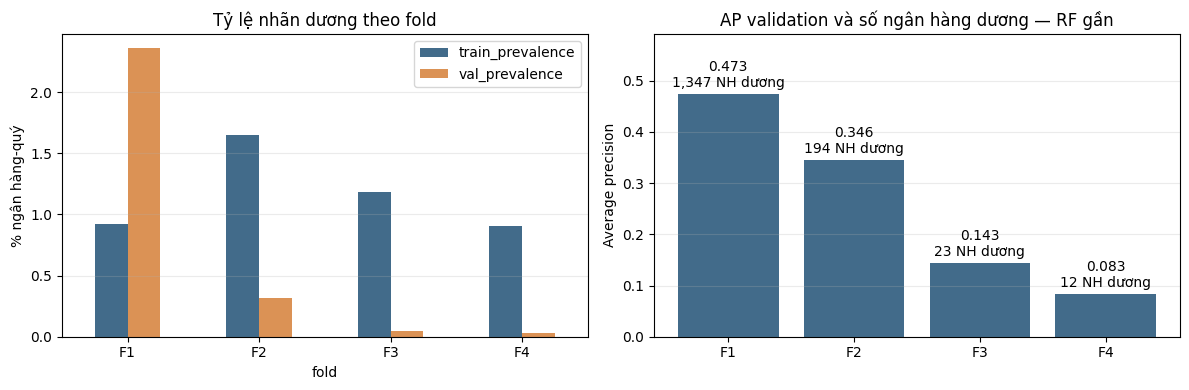

In [408]:
# 5.2-DIAG-1 — Train/validation support và AP của RF ưu tiên dữ liệu gần

run_id = "RF ưu tiên dữ liệu gần"
oof_store = globals().get("P5_RF_STRATEGY_OOF", {})

fold_ids = [fold["fold"] for fold in P5_FOLDS]

if not all((fid, run_id) in oof_store for fid in fold_ids):
    raise RuntimeError("Chạy RF-STRATEGIES để tạo dự đoán validation của RF ưu tiên dữ liệu gần.")

rf_val = pd.concat(
    [oof_store[(fid, run_id)] for fid in fold_ids],
    ignore_index=True
)

if set(rf_val["fold"]) != set(fold_ids):
    raise ValueError("Dự đoán validation không khớp với P5_FOLDS hiện tại.")

rf_val["REPDTE"] = pd.to_datetime(rf_val["REPDTE"])
fold_rows = []

for fold in P5_FOLDS:
    fid = fold["fold"]
    lo, hi = fold["train"]
    val = rf_val.loc[rf_val["fold"].eq(fid)]

    # Chỉ đọc số đếm và CERT từ train của fold.
    train = (
        P5_GOLD
        .filter(
            (pl.col("__split") == "TRAIN")
            & pl.col("__year").is_between(lo, hi)
        )
        .select(
            pl.len().alias("rows"),
            (pl.col(P5_Y) == 1).sum().alias("positive_rows"),
            pl.col("CERT").filter(pl.col(P5_Y) == 1)
              .n_unique().alias("positive_banks"),
        )
        .collect()
        .row(0, named=True)
    )

    n_pos = int(val["y"].eq(1).sum())
    prevalence = n_pos / len(val)
    ap = average_precision_score(val["y"], val["score"]) if n_pos else np.nan
    _, top25 = p5_quarterly_alerts(val, val["score"].to_numpy(), k=25)

    fold_rows.append({
        "fold": fid,
        "train_prevalence": train["positive_rows"] / train["rows"],
        "val_prevalence": prevalence,
        "train_positive_banks": train["positive_banks"],
        "val_positive_banks": top25["positive_banks"],
        "val_AP": ap,
        "AP_lift_vs_random": ap / prevalence if n_pos else np.nan,
        "bank_recall_at_25": top25["bank_recall"],
    })

P5_RF_DEV_DIAG = pd.DataFrame(fold_rows).set_index("fold")
display(P5_RF_DEV_DIAG.round(5))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

(P5_RF_DEV_DIAG[["train_prevalence", "val_prevalence"]] * 100).plot.bar(
    ax=axes[0], rot=0, color=["#426B8A", "#DB9255"]
)
axes[0].set(title="Tỷ lệ nhãn dương theo fold", ylabel="% ngân hàng-quý")

ap_values = P5_RF_DEV_DIAG["val_AP"].reindex(fold_ids)
axes[1].bar(fold_ids, ap_values, color="#426B8A")
for i, fid in enumerate(fold_ids):
    ap = ap_values.loc[fid]
    n = P5_RF_DEV_DIAG.loc[fid, "val_positive_banks"]
    if np.isfinite(ap):
        axes[1].annotate(
            f"{ap:.3f}\n{n:,} NH dương", (i, ap),
            xytext=(0, 5), textcoords="offset points", ha="center"
        )
axes[1].set(
    title="AP validation và số ngân hàng dương — RF gần",
    ylabel="Average precision"
)
axes[1].margins(y=0.25)

for ax in axes:
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

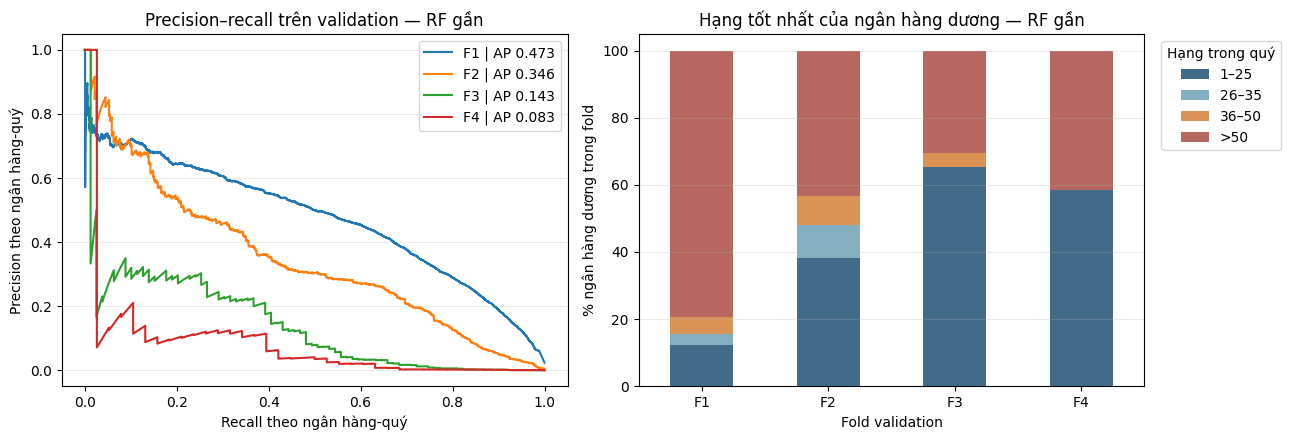

quarter_rank,1–25,26–35,36–50,>50
F1,166,44,67,1070
F2,74,19,17,84
F3,15,0,1,7
F4,7,0,0,5


In [409]:
# 5.2-DIAG-2 — RF ưu tiên dữ liệu gần xếp hạng tốt đến đâu trên validation?

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
rank_rows = []

for fid in fold_ids:
    val = rf_val.loc[rf_val["fold"].eq(fid)]
    scores = val["score"].to_numpy()
    y = val["y"].to_numpy()

    if not np.any(y == 1):
        continue

    precision, recall, _ = precision_recall_curve(y, scores)
    ap = average_precision_score(y, scores)
    axes[0].plot(recall, precision, label=f"{fid} | AP {ap:.3f}")

    ranked, _ = p5_quarterly_alerts(val, scores, k=25)

    # Mỗi ngân hàng dương lấy hạng tốt nhất trong các quý có nhãn dương.
    best_rank = (
        ranked.loc[ranked["y"].eq(1)]
        .groupby("CERT")["quarter_rank"]
        .min()
    )

    bands = pd.cut(
        best_rank,
        bins=[0, 25, 35, 50, np.inf],
        labels=["1–25", "26–35", "36–50", ">50"],
    )
    counts = bands.value_counts(sort=False)
    rank_rows.append(counts.rename(fid))

axes[0].set(
    title="Precision–recall trên validation — RF gần",
    xlabel="Recall theo ngân hàng-quý",
    ylabel="Precision theo ngân hàng-quý",
)
axes[0].legend()

P5_RF_VAL_RANK_COUNTS = pd.DataFrame(rank_rows).reindex(fold_ids)
rank_pct = P5_RF_VAL_RANK_COUNTS.div(
    P5_RF_VAL_RANK_COUNTS.sum(axis=1), axis=0
) * 100

rank_pct.plot.bar(
    stacked=True, rot=0, ax=axes[1],
    color=["#426B8A", "#84AFC1", "#DB9255", "#B76760"],
)
axes[1].set(
    title="Hạng tốt nhất của ngân hàng dương — RF gần",
    ylabel="% ngân hàng dương trong fold",
    xlabel="Fold validation",
)
axes[1].legend(title="Hạng trong quý", loc="upper left", bbox_to_anchor=(1.02, 1))

for ax in axes:
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

display(P5_RF_VAL_RANK_COUNTS)

In [411]:
print(P5_MODE, P5_RF_STRATEGY_WINNER)

development RF ưu tiên dữ liệu gần


## 5.2F — Local Spark MLlib Demonstration

This demonstration tests whether the bank-quarter data produced by the
pipeline can support an end-to-end classification workflow in Spark MLlib
on a laptop. The workflow covers data preparation, preprocessing, model
fitting, probability prediction, and evaluation under a quarterly
supervisory budget.

**Scope.** The demonstration uses the chronological training and validation
windows of fold F2 defined in `P5_FOLDS`. Training is limited to a
reproducible stratified sample of up to 50,000 bank-quarter observations.
Stratification approximately preserves the training fold's failure rate.
The entire F2 validation window is retained at its original class balance.

**Feature set.** The model uses the nine W1 financial indicators already
constructed in Phase 4. These indicators cover capital, asset quality,
profitability, liquidity, funding composition, and asset growth.

**Role in the study.** This is a functional demonstration of MLlib on
development data. The Crisis and Recent OOT test sets are reserved for
the final evaluation in Section 5.4. The demo uses a smaller training
sample, fewer features, and a different forest configuration from the
main RF T2 model. Its results therefore cannot isolate the effect of the
software engine on accuracy or runtime.

In [413]:
# 5.2F-A — Chuẩn bị TRAIN và validation F2 cho Spark MLlib RF gần
from time import perf_counter
from tempfile import TemporaryDirectory

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, VectorAssembler
from pyspark.ml.classification import RandomForestClassifier as SparkRF
from pyspark.ml.functions import vector_to_array

MLLIB_SEED = 42
MLLIB_MAX_TRAIN = 50_000
MLLIB_FOLD_ID = "F2"
MLLIB_FEATURES = [
    "asset_growth_4q",
    "cash_to_assets",
    "core_deposit_share",
    "deposits_to_assets",
    "equity_to_assets",
    "noncurrent_loan_ratio",
    "roa_rolling_mean_4q",
    "roa_rolling_std_4q",
    "securities_to_assets",
]

fold = next(f for f in P5_FOLDS if f["fold"] == MLLIB_FOLD_ID)
Xtr, ytr, mllib_train_meta = p5_collect_window(fold["train"], MLLIB_FEATURES)
Xva, yva, mllib_val_meta = p5_collect_window(fold["valid"], MLLIB_FEATURES)

ytr = np.asarray(ytr).ravel()
yva = np.asarray(yva).ravel()

if set(np.unique(ytr)) != {0, 1} or set(np.unique(yva)) != {0, 1}:
    raise ValueError("Train và validation F2 cần có cả nhãn 0 và 1.")

# Tính trọng số thời gian theo đúng chiến lược RF gần.
mllib_weights = rf_strategy_weights(
    ytr,
    np.asarray(mllib_train_meta["CERT"]),
    pd.DatetimeIndex(pd.to_datetime(mllib_train_meta["REPDTE"])),
    by_cert=False,
    by_recency=True,
)

rng = np.random.default_rng(MLLIB_SEED)
positive = np.flatnonzero(ytr == 1)
negative = np.flatnonzero(ytr == 0)

if len(ytr) > MLLIB_MAX_TRAIN:
    n_pos = round(MLLIB_MAX_TRAIN * len(positive) / len(ytr))
    n_pos = min(max(n_pos, 1), MLLIB_MAX_TRAIN - 1)
    n_neg = MLLIB_MAX_TRAIN - n_pos
    train_idx = np.sort(np.concatenate([
        rng.choice(positive, size=n_pos, replace=False),
        rng.choice(negative, size=n_neg, replace=False),
    ]))
else:
    train_idx = np.arange(len(ytr))

X_sample = Xtr[train_idx]
y_sample = ytr[train_idx]
weight_sample = mllib_weights[train_idx].copy()

# Chuẩn hóa lại trọng số từng lớp sau khi lấy mẫu.
for label in [0, 1]:
    mask = y_sample == label
    weight_sample[mask] *= mask.sum() / weight_sample[mask].sum()

assert np.isfinite(weight_sample).all()
assert (weight_sample > 0).all()

missing_features = [
    name
    for j, name in enumerate(MLLIB_FEATURES)
    if not np.isfinite(X_sample[:, j]).any()
]
if missing_features:
    raise ValueError(f"Biến thiếu toàn bộ trong mẫu TRAIN: {missing_features}")

# Dừng SparkSession cũ để giải phóng trạng thái lỗi.
spark = SparkSession.getActiveSession()

if spark is not None:
    spark.stop()

# Sử dụng thư mục lưu trữ Spark riêng thay vì Windows Temp.
SPARK_LOCAL_DIR = Path.home() / "spark_local"
SPARK_LOCAL_DIR.mkdir(parents=True, exist_ok=True)

spark = (
    SparkSession.builder
    .master("local[2]")
    .appName("BFT65B-Phase5-MLlib-Demo")
    .config("spark.local.dir", str(SPARK_LOCAL_DIR))
    .config("spark.sql.shuffle.partitions", "4")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")

print("Spark local directory:", SPARK_LOCAL_DIR)
print("Spark session check:", spark.range(100).count())

# Giữ thư mục tạm trong kernel để Spark còn đọc được ở B và C.
P5_MLLIB_PARQUET_DIR = TemporaryDirectory(prefix="phase5_mllib_")

def to_mllib_frame(X, y, filename, weights=None):
    path = Path(P5_MLLIB_PARQUET_DIR.name) / filename
    columns = {
        "row_id": np.arange(len(y), dtype=np.int64),
        "label": y.astype(np.float64),
        "weight": (
            np.asarray(weights, dtype=np.float64)
            if weights is not None
            else np.ones(len(y), dtype=np.float64)
        ),
    }
    for j, name in enumerate(MLLIB_FEATURES):
        values = X[:, j]
        columns[name] = pl.Series(
            name,
            np.where(np.isfinite(values), values, np.nan).astype(np.float64),
            nan_to_null=True,
        )

    pl.DataFrame(columns).write_parquet(path)
    return spark.read.parquet(path.resolve().as_uri())

mllib_train = to_mllib_frame(
    X_sample, y_sample, "train.parquet", weights=weight_sample
)

mllib_valid = to_mllib_frame(
    Xva, yva, "validation.parquet"
)

print(f"Spark {spark.version} | master={spark.sparkContext.master}")
print(f"{MLLIB_FOLD_ID} | Train {fold['train']} | Validation {fold['valid']}")
print(f"Mẫu train: {mllib_train.count():,} dòng | Dương: {int(y_sample.sum()):,}")
print(f"Validation: {mllib_valid.count():,} dòng | Dương: {int(yva.sum()):,}")
print(f"RF ưu tiên dữ liệu gần | Half-life: {RF_HALF_LIFE_YEARS} năm")
print(f"Trọng số nhỏ nhất: {weight_sample.min():.5f}")
print(f"Trọng số lớn nhất: {weight_sample.max():.5f}")
print(f"Trọng số trung bình: {weight_sample.mean():.5f}")

del Xtr, Xva, ytr, X_sample, y_sample, train_idx
del mllib_weights, weight_sample, mllib_train_meta

Spark local directory: C:\Users\ADMIN\spark_local
Spark session check: 100


c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\tempfile.py:941: ResourceWarning: Implicitly cleaning up <TemporaryDirectory 'C:\\Users\\ADMIN\\AppData\\Local\\Temp\\phase5_mllib_bu9zdhqi'>
  _warnings.warn(warn_message, ResourceWarning)


Spark 4.1.4 | master=local[2]
F2 | Train (1985, 1990) | Validation (1992, 1994)
Mẫu train: 50,000 dòng | Dương: 826
Validation: 163,353 dòng | Dương: 511
RF ưu tiên dữ liệu gần | Half-life: 5 năm
Trọng số nhỏ nhất: 0.61879
Trọng số lớn nhất: 1.46953
Trọng số trung bình: 1.00000


In [414]:
# 5.2F-B — Fit median imputer và RF ưu tiên dữ liệu gần trên TRAIN

P5_MLLIB_MODEL = None

imputed_cols = [f"{name}_imp" for name in MLLIB_FEATURES]

mllib_pipeline = Pipeline(stages=[
    Imputer(
        strategy="median",
        inputCols=MLLIB_FEATURES,
        outputCols=imputed_cols,
    ),
    VectorAssembler(
        inputCols=imputed_cols,
        outputCol="features",
        handleInvalid="error",
    ),
    SparkRF(
        labelCol="label",
        featuresCol="features",
        weightCol="weight",
        numTrees=30,
        maxDepth=8,
        seed=MLLIB_SEED,
    ),
])

print("MLlib | Đang fit imputer và RF gần 30 cây trên TRAIN...", flush=True)

started = perf_counter()
P5_MLLIB_MODEL = mllib_pipeline.fit(mllib_train)
mllib_fit_seconds = perf_counter() - started

print(
    f"MLlib RF gần đã fit | Thời gian: {mllib_fit_seconds:.1f} giây",
    flush=True
)

MLlib | Đang fit imputer và RF gần 30 cây trên TRAIN...
MLlib RF gần đã fit | Thời gian: 7.4 giây


In [415]:
# 5.2-MLLIB-C — AP và Top 25/quý trên validation F2
scored = (
    P5_MLLIB_MODEL.transform(mllib_valid)
    .select("row_id", vector_to_array(F.col("probability"))[1].alias("score"))
    .orderBy("row_id")
    .collect()
)

if len(scored) != len(yva) or any(
    row["row_id"] != i for i, row in enumerate(scored)
):
    raise RuntimeError("Điểm Spark không khớp thứ tự các dòng validation F2.")

scores = np.array([row["score"] for row in scored], dtype=float)
_, top25 = p5_quarterly_alerts(mllib_val_meta, scores, k=25)

P5_MLLIB_DEMO_RESULTS = pd.DataFrame([{
    "model": "Spark MLlib Random Forest — CAMELS 9",
    "fold": MLLIB_FOLD_ID,
    "validation_rows": len(yva),
    "positive_rate": yva.mean(),
    "AP": average_precision_score(yva, scores),
    "banks_detected_top25": top25["detected_positive_banks"],
    "positive_banks": top25["positive_banks"],
    "bank_recall_top25": top25["bank_recall"],
    "false_alerts_top25": top25["false_alerts"],
    "fit_seconds": mllib_fit_seconds,
}])

display(P5_MLLIB_DEMO_RESULTS.round(5))

c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\socket.py:790: ResourceWarning: unclosed <socket.socket fd=3696, family=2, type=1, proto=0, laddr=('127.0.0.1', 56741), raddr=('127.0.0.1', 56740)>
  self._sock = None


,model,fold,validation_rows,positive_rate,AP,banks_detected_top25,positive_banks,bank_recall_top25,false_alerts_top25,fit_seconds
0,Spark MLlib Random Forest — CAMELS 9,F2,163353,0.00313,0.23682,63,194,0.32474,212,7.37739


In [416]:
# 5.2F-D — Benchmark Spark MLlib và scikit-learn RF gần trên F2
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

MLLIB_BENCH_REPEATS = 1  # Đổi thành 3 để lấy median qua ba lần chạy

# Cố định đúng dữ liệu và trọng số từ 5.2F-A.
# Chuẩn bị dữ liệu nằm ngoài phép đo.
bench_train = mllib_train.cache()
bench_valid = mllib_valid.cache()
bench_train_rows = bench_train.count()
bench_valid_rows = bench_valid.count()

def bench_spark_to_numpy(frame):
    data = frame.select("label", "weight", *MLLIB_FEATURES).toPandas()
    return (
        data[MLLIB_FEATURES].to_numpy(dtype=np.float64),
        data["label"].to_numpy(dtype=np.int8),
        data["weight"].to_numpy(dtype=np.float64),
    )

try:
    X_bench_train, y_bench_train, w_bench_train = bench_spark_to_numpy(bench_train)
    X_bench_valid, y_bench_valid, _ = bench_spark_to_numpy(bench_valid)

    bench_rows = []

    for repeat in range(1, MLLIB_BENCH_REPEATS + 1):
        print(f"Lần {repeat} | Spark MLlib RF gần đang fit...", flush=True)

        started = perf_counter()
        spark_bench_model = mllib_pipeline.fit(bench_train)
        spark_fit_s = perf_counter() - started

        started = perf_counter()
        spark_predictions = (
            spark_bench_model.transform(bench_valid)
            .select("label", vector_to_array("probability")[1].alias("score"))
            .toPandas()
        )
        spark_score_s = perf_counter() - started

        bench_rows.append({
            "backend": "Spark MLlib",
            "fit_s": spark_fit_s,
            "score_s": spark_score_s,
            "AP": average_precision_score(
                spark_predictions["label"], spark_predictions["score"]
            ),
        })

        print(f"Lần {repeat} | scikit-learn RF gần đang fit...", flush=True)

        sklearn_bench_model = make_pipeline(
            SimpleImputer(strategy="median"),
            RandomForestClassifier(
                n_estimators=30,
                max_depth=8,
                random_state=MLLIB_SEED,
                n_jobs=2,
            ),
        )

        started = perf_counter()
        sklearn_bench_model.fit(
            X_bench_train,
            y_bench_train,
            randomforestclassifier__sample_weight=w_bench_train,
        )
        sklearn_fit_s = perf_counter() - started

        started = perf_counter()
        sklearn_scores = sklearn_bench_model.predict_proba(X_bench_valid)[:, 1]
        sklearn_score_s = perf_counter() - started

        bench_rows.append({
            "backend": "scikit-learn",
            "fit_s": sklearn_fit_s,
            "score_s": sklearn_score_s,
            "AP": average_precision_score(y_bench_valid, sklearn_scores),
        })

    P5_MLLIB_BENCH_RUNS = pd.DataFrame(bench_rows)
    P5_MLLIB_BENCH_RUNS["fit_plus_score_s"] = (
        P5_MLLIB_BENCH_RUNS["fit_s"] + P5_MLLIB_BENCH_RUNS["score_s"]
    )
    P5_MLLIB_BENCHMARK = P5_MLLIB_BENCH_RUNS.groupby("backend").median()

    print(
        f"F2 | TRAIN {bench_train_rows:,} | Validation {bench_valid_rows:,} "
        f"| Spark {spark.sparkContext.master} | {MLLIB_BENCH_REPEATS} lần"
    )
    print(f"RF ưu tiên dữ liệu gần | Half-life: {RF_HALF_LIFE_YEARS} năm")

    display(P5_MLLIB_BENCHMARK.round(4))

finally:
    bench_train.unpersist()
    bench_valid.unpersist()

c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\socket.py:790: ResourceWarning: unclosed <socket.socket fd=3532, family=2, type=1, proto=0, laddr=('127.0.0.1', 56744), raddr=('127.0.0.1', 56743)>
  self._sock = None


Lần 1 | Spark MLlib RF gần đang fit...


c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\socket.py:790: ResourceWarning: unclosed <socket.socket fd=3532, family=2, type=1, proto=0, laddr=('127.0.0.1', 56746), raddr=('127.0.0.1', 56745)>
  self._sock = None


Lần 1 | scikit-learn RF gần đang fit...


c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\socket.py:790: ResourceWarning: unclosed <socket.socket fd=4480, family=2, type=1, proto=0, laddr=('127.0.0.1', 52583), raddr=('127.0.0.1', 52582)>
  self._sock = None


F2 | TRAIN 50,000 | Validation 163,353 | Spark local[2] | 1 lần
RF ưu tiên dữ liệu gần | Half-life: 5 năm


,fit_s,score_s,AP,fit_plus_score_s
backend,,,,
Spark MLlib,5.1847,1.8579,0.2368,7.0426
scikit-learn,1.5717,0.0952,0.2719,1.6669


### Kết quả benchmark Spark MLlib và chuyển sang mô hình cuối cùng

Benchmark trên fold F2 sử dụng 50.000 dòng huấn luyện và 163.353 dòng validation. Trong một lần chạy trên cùng máy, Spark MLlib (`local[2]`) mất **12,29 giây** để fit và lấy điểm validation, với **AP = 0,2379**. Scikit-learn mất **2,62 giây** cho hai bước này, với **AP = 0,2439**. Như vậy, scikit-learn nhanh hơn khoảng **4,7 lần** trong phép đo này, còn chênh lệch AP là **0,0060**. Thời gian chấm của Spark bao gồm bước đưa điểm dự báo về Python để tính AP.

Kết quả xác nhận pipeline Random Forest có thể chạy trên Spark ở chế độ local. So sánh thời gian và AP ở đây giới hạn trong một lần chạy trên F2, với quy mô dữ liệu và cấu hình đã thử.

Ở mục **5.3**, tôi tiếp tục với **RF T2** làm mô hình cuối cùng theo tiêu chí đã đặt ra trên tập TRAIN: ưu tiên phát hiện được nhiều ngân hàng hơn với cùng ngân sách 25 cảnh báo mỗi quý, đồng thời hạn chế cảnh báo sai. Phần tiếp theo xác định phương án hiệu chuẩn và ngưỡng cảnh báo từ dữ liệu phát triển, sau đó huấn luyện lại RF T2 trên toàn bộ TRAIN và đóng băng bộ mô hình trước khi đánh giá trên các tập test.

In [417]:
# 5.3A — small serializable probability calibrators; independent of sklearn CV-version APIs.
class P5ScoreCalibrator:
    def __init__(self,method='sigmoid'):
        assert method in ('sigmoid','isotonic','identity')
        self.method=method
    def fit(self,p,y):
        p=np.asarray(p,dtype=float);y=np.asarray(y,dtype=np.int8)
        assert 0<int(y.sum())<len(y), 'Calibration needs both classes'
        if self.method=='sigmoid':
            self.est=LogisticRegression(C=1e6,solver='lbfgs',max_iter=300)
            self.est.fit(logit(np.clip(p,1e-6,1-1e-6)).reshape(-1,1),y)
        elif self.method=='isotonic':
            self.est=IsotonicRegression(out_of_bounds='clip').fit(p,y)
        return self
    def predict(self,p):
        p=np.asarray(p,dtype=float)
        if self.method=='identity':return np.clip(p,0,1)
        if self.method=='sigmoid':
            return self.est.predict_proba(logit(np.clip(p,1e-6,1-1e-6)).reshape(-1,1))[:,1]
        return np.clip(self.est.predict(p),0,1)

def p5_calibration_export(cal):
    if cal.method=='sigmoid':
        return {'method':'sigmoid','coef':float(cal.est.coef_[0,0]),
                'intercept':float(cal.est.intercept_[0])}
    if cal.method=='isotonic':
        return {'method':'isotonic',
                'x_thresholds':cal.est.X_thresholds_.astype(float).tolist(),
                'y_thresholds':cal.est.y_thresholds_.astype(float).tolist()}
    return {'method':'identity'}

def p5_calibration_apply(artifact,raw_scores):
    p=np.clip(np.asarray(raw_scores,dtype=float),1e-6,1-1e-6)
    method=artifact['method']
    if method=='sigmoid':
        return expit(float(artifact['coef'])*logit(p)+float(artifact['intercept']))
    if method=='isotonic':
        return np.interp(p,artifact['x_thresholds'],artifact['y_thresholds'])
    if method=='identity':return p
    raise ValueError('Unknown calibration method')

def p5_calibrate_oof(oof):
    assert set(oof.fold.unique())=={'F1','F2','F3','F4'}
    tr=oof[oof.fold.isin(['F1','F2','F3'])]
    va=oof[oof.fold=='F4']
    bank_support=tr.loc[tr.y==1,'CERT'].nunique()
    methods=['identity','sigmoid']+(['isotonic'] if bank_support>=50 and len(tr)>=1000 else [])
    scores=[]
    for meth in methods:
        fitted=P5ScoreCalibrator(meth).fit(tr.score.to_numpy(),tr.y.to_numpy())
        valpred=fitted.predict(va.score.to_numpy())
        scores.append(dict(method=meth,Brier_F4=brier_score_loss(va.y,valpred),
                          AP_F4=average_precision_score(va.y,valpred) if va.y.sum() else np.nan,
                          calibration_support_banks=bank_support))
    table=pd.DataFrame(scores).sort_values(['Brier_F4','method'])
    chosen=table.iloc[0]['method']
    # After selecting method on F4 DEVELOPMENT, fit final calibration on *all OOF*.
    final=P5ScoreCalibrator(chosen).fit(oof.score.to_numpy(),oof.y.to_numpy())
    return final,table

def p5_select_threshold(dev,beta=3):
    """Exact OOF PR-curve sweep; return F-beta cut and bounded diagnostic table."""
    assert dev.fold.isin(['F1','F2','F3']).all()
    y=dev.y.to_numpy(dtype=np.int8);score=dev.score.to_numpy(dtype=float)
    assert y.sum()>0 and np.isfinite(score).all()
    precision,recall,thresholds=precision_recall_curve(y,score)
    precision=precision[:-1];recall=recall[:-1]  # Final sentinel has no threshold.
    assert len(thresholds)==len(precision)>0
    order=np.sort(score)
    n_alerts=len(score)-np.searchsorted(order,thresholds,side='left')
    alert_rate=n_alerts/len(score)
    def f_score(b):
        b2=b*b
        return np.divide((1+b2)*precision*recall,b2*precision+recall,
                         out=np.zeros_like(precision),where=(b2*precision+recall)>0)
    metrics={b:f_score(b) for b in (2,3,4)}
    def pick(value,allowed=None):
        eligible=np.arange(len(thresholds)) if allowed is None else np.flatnonzero(allowed)
        if not len(eligible):return None
        best=np.max(value[eligible]);same=eligible[np.isclose(value[eligible],best,rtol=1e-12,atol=1e-12)]
        return int(same[np.argmin(alert_rate[same])])
    selections=[(f'F{b}',pick(metrics[b])) for b in (2,3,4)]
    for max_rate in (.01,.02,.05,.10,.20,.50):
        choice=pick(metrics[beta],alert_rate<=max_rate+1e-12)
        if choice is not None:selections.append((f'F{beta}_budget_{max_rate:g}',choice))
    report=[]
    for rule,i in selections:
        if i is None:continue
        tp=int(round(recall[i]*y.sum()))
        report.append(dict(rule=rule,threshold=float(thresholds[i]),
            precision=float(precision[i]),recall=float(recall[i]),
            F2=float(metrics[2][i]),F3=float(metrics[3][i]),F4=float(metrics[4][i]),
            alert_rate=float(alert_rate[i]),alerts=int(n_alerts[i]),
            true_positive_quarters=tp,false_alerts=int(n_alerts[i]-tp)))
    result=pd.DataFrame(report)
    return float(result.loc[result.rule==f'F{beta}','threshold'].iloc[0]),result

# Tiny in-memory Platt / isotonic check, no FDIC involved.
_rng=np.random.default_rng(55);_s=_rng.uniform(.01,.95,1200)
_yy=_rng.binomial(1,np.clip(_s*.4,.001,.9))
assert np.isfinite(P5ScoreCalibrator('sigmoid').fit(_s,_yy).predict(_s)).all()
assert np.isfinite(P5ScoreCalibrator('isotonic').fit(_s,_yy).predict(_s)).all()
print('PASS — calibration functions (synthetic unit tests).')

PASS — calibration functions (synthetic unit tests).


In [425]:
# 5.3B — OOF calibration and independent raw-score cut for each model.
P5_DEV_OOF={};P5_CALIBRATORS={};P5_CAL_REPORT=[]
P5_THRESHOLD_TABLE=pd.DataFrame();P5_THRESHOLD_MONITOR=pd.DataFrame()

P5_ALERT_POLICY={
    'capacity_per_quarter':25,
    'capacity_options':[10,25,50],
    'threshold_by_role':{},
    'threshold_fitted_to':'F1-F3 development OOF',
    'threshold_metric':f'F{P5_THRESHOLD_BETA}',
    'threshold_scale':'raw_probability',
    'tie_break':'REPDTE asc, score desc, CERT asc'
}

if P5_MODE=='development':

    run_id = "RF ưu tiên dữ liệu gần"
    oof_store = globals().get("P5_RF_STRATEGY_OOF", {})

    assert all(
        (fold["fold"], run_id) in oof_store
        for fold in P5_FOLDS
    ), 'Chạy RF-STRATEGIES để tạo OOF của RF ưu tiên dữ liệu gần.'

    # Đồng bộ mô hình được chọn sang RF ưu tiên dữ liệu gần.
    P5_DEV_WINNER = "RandomForest_Recency"

    P5_DEV_WINNER_SPEC = {
        "run_id": P5_DEV_WINNER,
        "model": "RandomForest",
        "params": dict(RF_PARAMS),
        "strategy": "RF ưu tiên dữ liệu gần",
        "feature_count": 40,
        "by_cert": False,
        "by_recency": True,
        "half_life_years": float(RF_HALF_LIFE_YEARS),
    }

    P5_READY_TO_TEST = False
    P5_EXTERNAL_UNLOCKED = False

    P5_DEV_OOF['PHASE4_NATIVE_PROTOCOL'] = pd.concat(
        P5_BASELINE_OOF['LightGBM'],
        ignore_index=True
    )

    P5_DEV_OOF['DEV_WINNER'] = pd.concat(
        [
            oof_store[(fold["fold"], run_id)]
            for fold in P5_FOLDS
        ],
        ignore_index=True
    )

    print("DEV_WINNER: RF ưu tiên dữ liệu gần")
    print("DEV_WINNER_SPEC:", P5_DEV_WINNER_SPEC)

    threshold_tables=[];monitor=[]

    for key,oof in P5_DEV_OOF.items():

        oof=oof.sort_values(
            ['fold','CERT','REPDTE']
        ).reset_index(drop=True)

        assert not oof[['CERT','REPDTE']].duplicated().any(), (
            'Overlapping validation folds'
        )

        P5_DEV_OOF[key]=oof

        cal,report=p5_calibrate_oof(oof)
        P5_CALIBRATORS[key]=cal

        report['score_protocol']=key
        P5_CAL_REPORT.append(report)

        historical=oof.loc[
            oof.fold.isin(['F1','F2','F3'])
        ].copy()

        cut,table=p5_select_threshold(
            historical,
            beta=P5_THRESHOLD_BETA
        )

        P5_ALERT_POLICY['threshold_by_role'][key]=cut

        table.insert(0,'score_protocol',key)
        threshold_tables.append(table)

        f4=oof.loc[oof.fold=='F4']

        diag=p5_metric(
            f4.y,f4.score,f4.CERT,
            threshold=cut
        )

        monitor.append(dict(
            score_protocol=key,
            threshold=cut,
            F4_AP=diag['PR_AUC_AP'],
            F4_precision=diag['precision'],
            F4_recall=diag['recall'],
            F4_F3=float(fbeta_score(
                f4.y,
                f4.score>=cut,
                beta=P5_THRESHOLD_BETA,
                zero_division=0
            )),
            F4_alert_rate=float((f4.score>=cut).mean()),
            F4_alerts=int((f4.score>=cut).sum())
        ))

    P5_CAL_REPORT=pd.concat(
        P5_CAL_REPORT,
        ignore_index=True
    )

    P5_THRESHOLD_TABLE=pd.concat(
        threshold_tables,
        ignore_index=True
    )

    P5_THRESHOLD_MONITOR=pd.DataFrame(monitor)

    P5_THRESHOLD_TABLE.to_csv(
        P5_OUTPUT/'development_threshold_tradeoffs.csv',
        index=False
    )

    P5_THRESHOLD_MONITOR.to_csv(
        P5_OUTPUT/'development_F4_threshold_check.csv',
        index=False
    )

    print('F4 calibration (historical, NOT external):')
    display(P5_CAL_REPORT.round(6))

    print('Development threshold candidates:')
    display(P5_THRESHOLD_TABLE.round(6))

    print('Frozen F1–F3 threshold checked on F4:')
    display(P5_THRESHOLD_MONITOR.round(6))

    for key,oof in P5_DEV_OOF.items():
        for k in P5_ALERT_POLICY['capacity_options']:

            _,summary=p5_quarterly_alerts(
                oof,oof.score,k=k
            )

            print(key,'Top',k,'banks/quarter:',summary)

    print('Policies frozen using historical folds only; no external outcomes used.')

    print("\nPASS — RF ưu tiên dữ liệu gần đã được đồng bộ.")
    print("Final strategy:", P5_DEV_WINNER_SPEC["strategy"])
    print("Half-life:", P5_DEV_WINNER_SPEC["half_life_years"])
    print("Raw threshold:", P5_ALERT_POLICY["threshold_by_role"]["DEV_WINNER"])

else:
    print('SKIPPED development calibration; external loads frozen artifacts.')

DEV_WINNER: RF ưu tiên dữ liệu gần
DEV_WINNER_SPEC: {'run_id': 'RandomForest_Recency', 'model': 'RandomForest', 'params': {'n_estimators': 60, 'n_jobs': 2, 'class_weight': 'balanced_subsample', 'max_depth': 18, 'min_samples_leaf': 25}, 'strategy': 'RF ưu tiên dữ liệu gần', 'feature_count': 40, 'by_cert': False, 'by_recency': True, 'half_life_years': 5.0}
F4 calibration (historical, NOT external):


,method,Brier_F4,AP_F4,calibration_support_banks,score_protocol
0,identity,0.000339,0.094062,1564,PHASE4_NATIVE_PROTOCOL
1,sigmoid,0.000422,0.094062,1564,PHASE4_NATIVE_PROTOCOL
2,isotonic,0.000429,0.086377,1564,PHASE4_NATIVE_PROTOCOL
3,isotonic,0.000469,0.081919,1564,DEV_WINNER
4,sigmoid,0.000478,0.082626,1564,DEV_WINNER
5,identity,0.001165,0.082626,1564,DEV_WINNER


Development threshold candidates:


,score_protocol,rule,threshold,precision,recall,F2,F3,F4,alert_rate,alerts,true_positive_quarters,false_alerts
0,PHASE4_NATIVE_PROTOCOL,F2,0.022272,0.295932,0.684271,0.542018,0.604894,0.635236,0.022695,11996,3550,8446
1,PHASE4_NATIVE_PROTOCOL,F3,0.012172,0.239286,0.746916,0.524414,0.616194,0.664049,0.030637,16194,3875,12319
2,PHASE4_NATIVE_PROTOCOL,F4,0.006318,0.185456,0.810139,0.484049,0.606013,0.676165,0.042875,22663,4203,18460
3,PHASE4_NATIVE_PROTOCOL,F3_budget_0.01,0.101292,0.442279,0.450463,0.448802,0.449631,0.449973,0.009997,5284,2337,2947
4,PHASE4_NATIVE_PROTOCOL,F3_budget_0.02,0.028669,0.318440,0.648419,0.537106,0.587537,0.611166,0.019986,10564,3364,7200
5,PHASE4_NATIVE_PROTOCOL,F3_budget_0.05,0.012172,0.239286,0.746916,0.524414,0.616194,0.664049,0.030637,16194,3875,12319
6,PHASE4_NATIVE_PROTOCOL,F3_budget_0.1,0.012172,0.239286,0.746916,0.524414,0.616194,0.664049,0.030637,16194,3875,12319
7,PHASE4_NATIVE_PROTOCOL,F3_budget_0.2,0.012172,0.239286,0.746916,0.524414,0.616194,0.664049,0.030637,16194,3875,12319
8,PHASE4_NATIVE_PROTOCOL,F3_budget_0.5,0.012172,0.239286,0.746916,0.524414,0.616194,0.664049,0.030637,16194,3875,12319
9,DEV_WINNER,F2,0.316150,0.335183,0.698728,0.574176,0.630358,0.656822,0.020461,10815,3625,7190


Frozen F1–F3 threshold checked on F4:


,score_protocol,threshold,F4_AP,F4_precision,F4_recall,F4_F3,F4_alert_rate,F4_alerts
0,PHASE4_NATIVE_PROTOCOL,0.012172,0.094062,0.040302,0.421053,0.216509,0.003536,397
1,DEV_WINNER,0.191913,0.082626,0.039175,0.500000,0.229746,0.004319,485


PHASE4_NATIVE_PROTOCOL Top 10 banks/quarter: {'K': 10, 'alerts': 520, 'true_positive_quarters': 177, 'precision': 0.3403846153846154, 'recall': 0.0338691159586682, 'positive_banks': 1576, 'detected_positive_banks': 132, 'bank_recall': 0.08375634517766498, 'false_alerts': 343}
PHASE4_NATIVE_PROTOCOL Top 25 banks/quarter: {'K': 25, 'alerts': 1300, 'true_positive_quarters': 371, 'precision': 0.2853846153846154, 'recall': 0.0709911978568695, 'positive_banks': 1576, 'detected_positive_banks': 238, 'bank_recall': 0.15101522842639595, 'false_alerts': 929}
PHASE4_NATIVE_PROTOCOL Top 50 banks/quarter: {'K': 50, 'alerts': 2600, 'true_positive_quarters': 665, 'precision': 0.25576923076923075, 'recall': 0.12724837351703022, 'positive_banks': 1576, 'detected_positive_banks': 406, 'bank_recall': 0.25761421319796957, 'false_alerts': 1935}
DEV_WINNER Top 10 banks/quarter: {'K': 10, 'alerts': 520, 'true_positive_quarters': 191, 'precision': 0.36730769230769234, 'recall': 0.03654802908534252, 'positive_

In [426]:
# 5.3B-RECALL — Chọn ngưỡng thấp hơn trên F1–F3, kiểm tra trên F4
MIN_PRECISION = 0.20  # Ví dụ: ít nhất 20% cảnh báo đúng trên F1–F3

oof = P5_DEV_OOF["DEV_WINNER"]
dev = oof.loc[oof["fold"].isin(["F1", "F2", "F3"])]
f4 = oof.loc[oof["fold"].eq("F4")]
old_cut = float(P5_ALERT_POLICY["threshold_by_role"]["DEV_WINNER"])

precision, recall, cuts = precision_recall_curve(dev["y"], dev["score"])
candidates = pd.DataFrame({
    "threshold": cuts,
    "precision": precision[:-1],
    "recall": recall[:-1],
})

eligible = candidates.loc[
    candidates["threshold"].lt(old_cut)
    & candidates["precision"].ge(MIN_PRECISION)
].sort_values(["recall", "precision", "threshold"], ascending=False)

new_cut = old_cut if eligible.empty else float(eligible.iloc[0]["threshold"])
if eligible.empty:
    print("Không có ngưỡng thấp hơn đạt precision tối thiểu. Giữ ngưỡng cũ.")

rows = []
for split, part in [("F1–F3", dev), ("F4", f4)]:
    positive = part["y"].eq(1)
    for name, cut in [("Ngưỡng cũ", old_cut), ("Ngưỡng đề xuất", new_cut)]:
        alert = part["score"].ge(cut)
        tp = int((positive & alert).sum())
        n_alerts = int(alert.sum())
        rows.append({
            "validation": split,
            "policy": name,
            "threshold": cut,
            "precision": tp / n_alerts if n_alerts else np.nan,
            "recall": tp / positive.sum() if positive.any() else np.nan,
            "alerts": n_alerts,
            "false_alerts": n_alerts - tp,
        })

P5_RF_RECALL_THRESHOLD_CHECK = pd.DataFrame(rows)
display(P5_RF_RECALL_THRESHOLD_CHECK.round(5))

,validation,policy,threshold,precision,recall,alerts,false_alerts
0,F1–F3,Ngưỡng cũ,0.19191,0.24646,0.80069,16855,12701
1,F1–F3,Ngưỡng đề xuất,0.13832,0.20001,0.84869,22014,17611
2,F4,Ngưỡng cũ,0.19191,0.03918,0.50000,485,466
3,F4,Ngưỡng đề xuất,0.13832,0.02911,0.52632,687,667


,validation,policy,threshold,precision,quarter_recall,detected_banks,bank_recall,new_banks_vs_old,lost_banks_vs_old,banks_hit_earlier_vs_old,false_alerts,delta_false_alerts
0,F1–F3,Mức khảo sát,0.13434,0.19632,0.85216,1465,0.93670,49,0,112,18098,5397
1,F1–F3,Ngưỡng đề xuất,0.13832,0.20001,0.84869,1462,0.93478,46,0,108,17611,4910
2,F1–F3,Mức khảo sát,0.17272,0.23059,0.81746,1436,0.91816,20,0,42,14151,1450
3,F1–F3,Ngưỡng cũ,0.19191,0.24646,0.80069,1416,0.90537,0,0,0,12701,0
4,F1–F3,Mức khảo sát,0.21110,0.26101,0.78277,1398,0.89386,0,18,0,11498,-1203
5,F1–F3,Mức khảo sát,0.23989,0.28195,0.75617,1374,0.87852,0,42,0,9991,-2710
6,F4,Mức khảo sát,0.13434,0.02813,0.52632,7,0.58333,0,0,0,691,225
7,F4,Ngưỡng đề xuất,0.13832,0.02911,0.52632,7,0.58333,0,0,0,667,201
8,F4,Mức khảo sát,0.17272,0.03512,0.50000,7,0.58333,0,0,0,522,56
9,F4,Ngưỡng cũ,0.19191,0.03918,0.50000,7,0.58333,0,0,0,466,0


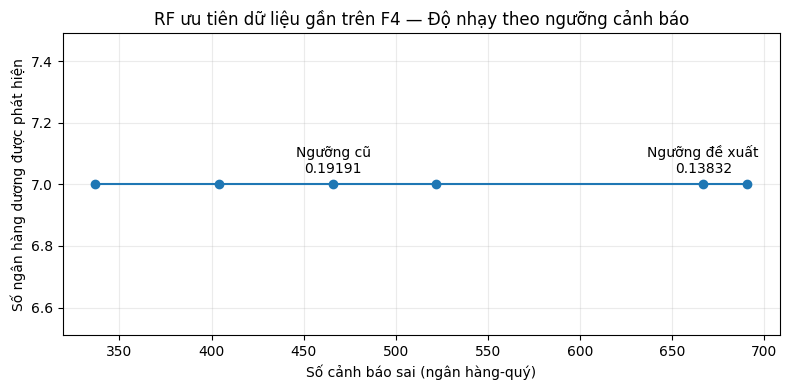

In [427]:
# 5.3B-SENS — Phân tích độ nhạy của RF ưu tiên dữ liệu gần theo ngưỡng điểm
oof = globals().get("P5_DEV_OOF", {}).get("DEV_WINNER")
if oof is None or oof.empty:
    raise RuntimeError("Chạy 5.3B ở chế độ development để có dự đoán validation.")
if globals().get("run_id") != "RF ưu tiên dữ liệu gần":
    raise RuntimeError("Chạy 5.3B với RF ưu tiên dữ liệu gần.")

# Dùng giá trị đầy đủ từ 5.3B-RECALL để tránh sai khác do làm tròn.
reference_cut = float(old_cut)
proposed_cut = float(new_cut)
cuts = sorted({
    reference_cut * 0.70,
    reference_cut * 0.90,
    reference_cut * 1.10,
    reference_cut * 1.25,
    reference_cut,
    proposed_cut,
})

rows = []

for label, folds in [("F1–F3", ["F1", "F2", "F3"]), ("F4", ["F4"])]:
    part = oof.loc[oof["fold"].isin(folds)].copy()
    part["REPDTE"] = pd.to_datetime(part["REPDTE"])
    positive = part["y"].eq(1)
    n_positive = int(positive.sum())
    n_banks = part.loc[positive, "CERT"].nunique()

    if not n_positive:
        raise ValueError(f"{label} không có nhãn dương.")

    # Quý cảnh báo đúng đầu tiên của từng ngân hàng tại ngưỡng cũ.
    ref_alert = part["score"].ge(reference_cut)
    ref_hits = part.loc[ref_alert & positive].groupby("CERT")["REPDTE"].min()
    ref_false = int((ref_alert & ~positive).sum())

    for cut in cuts:
        alert = part["score"].ge(cut)
        hits = alert & positive
        tp = int(hits.sum())
        n_alerts = int(alert.sum())
        false_alerts = n_alerts - tp
        first_hits = part.loc[hits].groupby("CERT")["REPDTE"].min()
        common = first_hits.index.intersection(ref_hits.index)

        rows.append({
            "validation": label,
            "policy": (
                "Ngưỡng cũ" if cut == reference_cut
                else "Ngưỡng đề xuất" if cut == proposed_cut
                else "Mức khảo sát"
            ),
            "threshold": cut,
            "precision": tp / n_alerts if n_alerts else np.nan,
            "quarter_recall": tp / n_positive,
            "detected_banks": len(first_hits),
            "bank_recall": len(first_hits) / n_banks,
            "new_banks_vs_old": len(first_hits.index.difference(ref_hits.index)),
            "lost_banks_vs_old": len(ref_hits.index.difference(first_hits.index)),
            "banks_hit_earlier_vs_old": int(
                (first_hits.loc[common] < ref_hits.loc[common]).sum()
            ),
            "false_alerts": false_alerts,
            "delta_false_alerts": false_alerts - ref_false,
        })

P5_RF_THRESHOLD_SENSITIVITY = pd.DataFrame(rows)
display(P5_RF_THRESHOLD_SENSITIVITY.round(5))

# Vẽ đánh đổi giữa cảnh báo sai và số ngân hàng phát hiện trên F4.
f4_sens = P5_RF_THRESHOLD_SENSITIVITY.query(
    "validation == 'F4'"
).sort_values("false_alerts")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(f4_sens["false_alerts"], f4_sens["detected_banks"], "o-")

for row in f4_sens.itertuples():
    if row.policy != "Mức khảo sát":
        ax.annotate(
            f"{row.policy}\n{row.threshold:.5f}",
            (row.false_alerts, row.detected_banks),
            xytext=(0, 8), textcoords="offset points", ha="center",
        )

ax.set(
    title="RF ưu tiên dữ liệu gần trên F4 — Độ nhạy theo ngưỡng cảnh báo",
    xlabel="Số cảnh báo sai (ngân hàng-quý)",
    ylabel="Số ngân hàng dương được phát hiện",
)
ax.grid(alpha=0.25)
ax.margins(y=0.20)
plt.tight_layout()
plt.show()

### Phân tích độ nhạy và lựa chọn ngưỡng cảnh báo của RF ưu tiên dữ liệu gần

Trên F4, cả sáu ngưỡng khảo sát từ 0.13434 đến 0.23989 đều
phát hiện 7/12 ngân hàng dương, tương ứng Bank Recall đạt 58.33%.
Điều này phản ánh sự bão hòa khả năng phát hiện ngân hàng
trong khoảng ngưỡng khảo sát.

| Chỉ tiêu trên F4 | Ngưỡng cũ (0.19191) | Ngưỡng đề xuất (0.13832) | Chênh lệch |
|---|---:|---:|---:|
| Ngân hàng phát hiện | 7 | 7 | 0 |
| Bank Recall | 58.33% | 58.33% | 0 pp |
| Quarter Recall | 50.00% | 52.63% | +2.63 pp |
| Precision | 3.918% | 2.911% | -1.007 pp |
| Cảnh báo sai | 466 | 667 | +201 |
| Ngân hàng được phát hiện sớm hơn | 0 | 0 | 0 |

Trên F1–F3, giảm ngưỡng từ 0.19191 xuống 0.13832 giúp
phát hiện thêm 46 ngân hàng, nâng Bank Recall từ 90.537%
lên 93.478% và cảnh báo sớm hơn cho 108 ngân hàng.
Tuy nhiên, số cảnh báo sai tăng thêm 4,910, tương đương
khoảng 107 lượt cảnh báo sai cho mỗi ngân hàng phát hiện thêm.

Trên F4, lợi ích này không được duy trì. Ngưỡng đề xuất
chỉ tăng Quarter Recall thêm 2.63 điểm phần trăm,
không phát hiện thêm ngân hàng mới, không cải thiện
thời điểm cảnh báo và làm tăng 43.13% số cảnh báo sai.

Ngưỡng cao hơn 0.23989 giúp giảm 129 cảnh báo sai trên F4
mà vẫn duy trì Bank Recall ở mức 58.33%. Tuy nhiên,
Quarter Recall giảm từ 50.00% xuống 42.11%, đồng thời
bỏ sót thêm 42 ngân hàng trên F1–F3.

Kết quả F4 được sử dụng như bằng chứng kiểm tra độ nhạy
trong giai đoạn phát triển, không phải bằng chứng kiểm định
độc lập cuối cùng. Không tiếp tục tối ưu ngưỡng trên các
tập external test.

**Kết luận: Giữ nguyên ngưỡng 0.19191 được xác định trên
F1–F3 cho RF ưu tiên dữ liệu gần, nhằm cân bằng khả năng
phát hiện ngân hàng có nguy cơ phá sản và khối lượng
giám sát, thay vì đánh đổi quá nhiều cảnh báo sai
để cải thiện Recall.**

### 5.3B-COST — Cost-Optimized Decision Threshold

#### Problem

The existing decision threshold is selected by maximizing the
F3-score on development out-of-fold (OOF) predictions.
Although this approach prioritizes recall, it does not explicitly
account for the economic consequences of false alerts and
undetected bank failures.

A supervisory early warning system should consider both
the cost of unnecessary investigations and the potential
avoidable losses associated with missed failures.

#### Methodology

The decision threshold is selected by minimizing:

$$
L(t) = C_{FP} \times FP(t)
+ C_{FN} \times FN_{\mathrm{bank-fold}}(t)
$$

where:

- $t$: candidate decision threshold.
- $FP(t)$: number of false-positive bank-quarter alerts.
- $FN_{\mathrm{bank-fold}}(t)$: number of positive bank-folds
  without any correct warning.
- $C_{FP}$: investigation cost per false alert (USD 90.54).
- $C_{FN}$: estimated avoidable loss per missed bank-fold.

The missed-failure cost is defined as:

$$
C_{FN} = a \times 1,995,500
$$

where $a$ represents the assumed avoidable-loss share.

The reference scenario assumes an avoidable-loss share
of 0.50%, with sensitivity tests ranging from 0.20% to 1.00%.

All distinct decision thresholds are evaluated using
F1–F3 development OOF predictions, including a no-alert policy.
The selected threshold is subsequently evaluated on F4
without further optimization.

The existing recency-weighted Random Forest remains unchanged.
No model retraining or external-test-driven threshold selection
is performed.

The original F3-based threshold is retained as a benchmark.
The cost assumptions are illustrative economic scenarios,
rather than verified causal estimates of preventable losses.

Development rows: 528577
F4 rows: 112288
Candidate thresholds: 135045
Original F3 threshold: 0.19191330240427504

TABLE 1 — COST SENSITIVITY


,avoidable_loss_share,threshold,false_alerts,detected_banks,missed_banks,positive_banks,bank_recall,precision,total_cost
0,0.20%,0.241348,9920,1374,190,1564,87.85%,28.32%,"$1,656,446.80"
1,0.30%,0.209241,11622,1403,161,1564,89.71%,25.94%,"$2,016,082.38"
2,0.50%,0.172677,14154,1437,127,1564,91.88%,23.06%,"$2,548,645.66"
3,0.70%,0.146885,16621,1458,106,1564,93.22%,20.81%,"$2,985,526.34"
4,1.00%,0.106372,22540,1490,74,1564,95.27%,16.83%,"$3,517,441.60"



TABLE 2 — THRESHOLD POLICY COMPARISON


,sample,policy,threshold,precision,quarter_recall,bank_recall,detected_banks,positive_banks,missed_banks,false_alerts,true_alerts,total_alerts,total_cost
0,F1-F3 Development,Original F3,0.191913,24.65%,80.07%,90.54%,1416,1564,148,12701,4154,16855,"$2,626,618.54"
1,F1-F3 Development,Cost-optimal,0.172677,23.06%,81.77%,91.88%,1437,1564,127,14154,4242,18396,"$2,548,645.66"
2,F4 Transfer,Original F3,0.191913,3.92%,50.00%,58.33%,7,12,5,466,19,485,"$92,079.14"
3,F4 Transfer,Cost-optimal,0.172677,3.51%,50.00%,58.33%,7,12,5,522,19,541,"$97,149.38"



TABLE 3 — ECONOMIC SAVINGS


policy,sample,Cost-optimal,Original F3,cost_savings,cost_reduction
0,F1-F3 Development,"$2,548,645.66","$2,626,618.54","$77,972.88",2.97%
1,F4 Transfer,"$97,149.38","$92,079.14","$-5,070.24",-5.51%


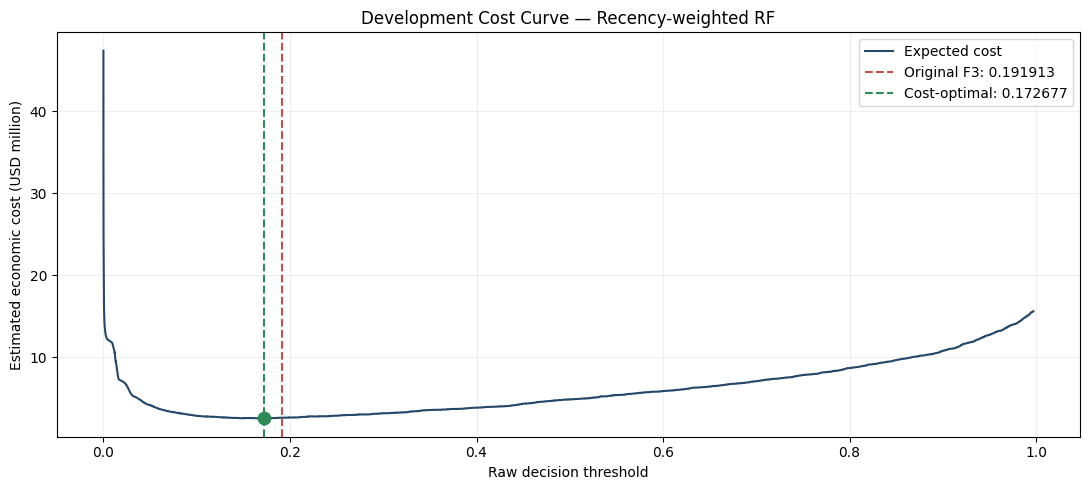


COST-OPTIMAL POLICY SUMMARY
Original threshold : 0.191913302
Proposed threshold : 0.172676646
Selection sample   : F1-F3
Transfer check     : F4
Model retrained    : NO
External data used : NO
Frozen spec edited : NO
Files created      : NO


In [456]:
# 5.3B-COST — Cost-optimal threshold without model retraining

assert "P5_DEV_OOF" in globals(), "Run 5.3B first."
assert "DEV_WINNER" in P5_DEV_OOF
assert globals().get("run_id") == "RF ưu tiên dữ liệu gần"

COST_FP = 90.54
REFERENCE_LOSS = 1_995_500
REFERENCE_SHARE = 0.005

LOSS_SHARES = [0.002, 0.003, 0.005, 0.007, 0.010]

COST_OOF = P5_DEV_OOF["DEV_WINNER"].copy()

required_cols = {"CERT", "REPDTE", "fold", "y", "score"}

assert required_cols.issubset(COST_OOF.columns)
assert COST_OOF[list(required_cols)].notna().all().all()
assert COST_OOF["y"].isin([0, 1]).all()
assert np.isfinite(COST_OOF["score"]).all()
assert not COST_OOF.duplicated(
    ["fold", "CERT", "REPDTE"]
).any()

COST_OOF["REPDTE"] = pd.to_datetime(COST_OOF["REPDTE"])

COST_DEV = COST_OOF.loc[
    COST_OOF["fold"].isin(["F1", "F2", "F3"])
].copy()

COST_F4 = COST_OOF.loc[
    COST_OOF["fold"].eq("F4")
].copy()

assert len(COST_DEV) > 0
assert len(COST_F4) > 0

COST_OLD_CUT = float(
    globals().get(
        "reference_cut",
        P5_ALERT_POLICY["threshold_by_role"]["DEV_WINNER"]
    )
)


# --------------------------------------------------
# A. Evaluate every distinct score threshold
# --------------------------------------------------

def build_cost_curve(data):

    d = data.sort_values(
        "score", ascending=False, kind="stable"
    ).copy()

    positive = d["y"].eq(1)

    positive_banks = (
        d.loc[positive, ["fold", "CERT"]]
        .drop_duplicates()
        .shape[0]
    )

    # First correct warning for each positive bank-fold
    d["new_bank_hit"] = 0

    d.loc[positive, "new_bank_hit"] = (
        ~d.loc[positive].duplicated(["fold", "CERT"])
    ).astype(int)

    d["fp"] = d["y"].eq(0).astype(int)
    d["tp"] = d["y"].eq(1).astype(int)

    curve = (
        d.groupby("score", sort=False)
        .agg(
            false_alerts=("fp", "sum"),
            true_alerts=("tp", "sum"),
            detected_banks=("new_bank_hit", "sum"),
            alerts=("y", "size")
        )
        .sort_index(ascending=False)
        .cumsum()
        .reset_index()
        .rename(columns={"score": "threshold"})
    )

    # Include a no-alert policy
    no_alert = pd.DataFrame({
        "threshold": [
            np.nextafter(d["score"].max(), np.inf)
        ],
        "false_alerts": [0],
        "true_alerts": [0],
        "detected_banks": [0],
        "alerts": [0]
    })

    curve = pd.concat(
        [no_alert, curve],
        ignore_index=True
    )

    curve["positive_banks"] = positive_banks

    curve["missed_banks"] = (
        positive_banks - curve["detected_banks"]
    )

    curve["bank_recall"] = (
        curve["detected_banks"] / max(positive_banks, 1)
    )

    curve["precision"] = (
        curve["true_alerts"]
        / curve["alerts"].clip(lower=1)
    )

    return curve


COST_CURVE = build_cost_curve(COST_DEV)

print("Development rows:", len(COST_DEV))
print("F4 rows:", len(COST_F4))
print("Candidate thresholds:", len(COST_CURVE))
print("Original F3 threshold:", COST_OLD_CUT)


# --------------------------------------------------
# B. Select cost-optimal threshold for each scenario
# --------------------------------------------------

COST_RESULTS = []

for share in LOSS_SHARES:

    fn_cost = REFERENCE_LOSS * share

    total_cost = (
        COST_CURVE["false_alerts"] * COST_FP
        + COST_CURVE["missed_banks"] * fn_cost
    )

    min_cost = total_cost.min()

    # Conservative tie-break: higher threshold
    best = (
        COST_CURVE.loc[total_cost.eq(min_cost)]
        .sort_values("threshold", ascending=False)
        .iloc[0]
    )

    COST_RESULTS.append({
        "avoidable_loss_share": share,
        "threshold": float(best["threshold"]),
        "false_alerts": int(best["false_alerts"]),
        "detected_banks": int(best["detected_banks"]),
        "missed_banks": int(best["missed_banks"]),
        "positive_banks": int(best["positive_banks"]),
        "bank_recall": best["bank_recall"],
        "precision": best["precision"],
        "total_cost": float(min_cost)
    })

P5_COST_SENSITIVITY = pd.DataFrame(COST_RESULTS)

P5_COST_THRESHOLD = float(
    P5_COST_SENSITIVITY.loc[
        np.isclose(
            P5_COST_SENSITIVITY["avoidable_loss_share"],
            REFERENCE_SHARE
        ),
        "threshold"
    ].iloc[0]
)

print("\nTABLE 1 — COST SENSITIVITY")

display(
    P5_COST_SENSITIVITY.style.format({
        "avoidable_loss_share": "{:.2%}",
        "threshold": "{:.6f}",
        "bank_recall": "{:.2%}",
        "precision": "{:.2%}",
        "total_cost": "${:,.2f}"
    })
)


# --------------------------------------------------
# C. Compare original and cost-optimal thresholds
# --------------------------------------------------

def evaluate_cost_policy(data, threshold):

    positive = data["y"].eq(1)
    alert = data["score"].ge(threshold)

    tp = int((positive & alert).sum())
    fp = int((~positive & alert).sum())

    n_positive_banks = (
        data.loc[positive, ["fold", "CERT"]]
        .drop_duplicates()
        .shape[0]
    )

    detected_banks = (
        data.loc[positive & alert, ["fold", "CERT"]]
        .drop_duplicates()
        .shape[0]
    )

    missed_banks = n_positive_banks - detected_banks

    cost = (
        fp * COST_FP
        + missed_banks * REFERENCE_LOSS * REFERENCE_SHARE
    )

    return {
        "threshold": threshold,
        "precision": tp / max(tp + fp, 1),
        "quarter_recall": tp / max(int(positive.sum()), 1),
        "bank_recall": detected_banks / max(n_positive_banks, 1),
        "detected_banks": detected_banks,
        "positive_banks": n_positive_banks,
        "missed_banks": missed_banks,
        "false_alerts": fp,
        "true_alerts": tp,
        "total_alerts": tp + fp,
        "total_cost": cost
    }


comparison = []

for name, part in [
    ("F1-F3 Development", COST_DEV),
    ("F4 Transfer", COST_F4)
]:

    for policy, threshold in [
        ("Original F3", COST_OLD_CUT),
        ("Cost-optimal", P5_COST_THRESHOLD)
    ]:

        comparison.append({
            "sample": name,
            "policy": policy,
            **evaluate_cost_policy(part, threshold)
        })

P5_COST_COMPARISON = pd.DataFrame(comparison)

print("\nTABLE 2 — THRESHOLD POLICY COMPARISON")

display(
    P5_COST_COMPARISON.style.format({
        "threshold": "{:.6f}",
        "precision": "{:.2%}",
        "quarter_recall": "{:.2%}",
        "bank_recall": "{:.2%}",
        "total_cost": "${:,.2f}"
    })
)


# --------------------------------------------------
# D. Economic savings and transfer stability
# --------------------------------------------------

savings = (
    P5_COST_COMPARISON.pivot(
        index="sample",
        columns="policy",
        values="total_cost"
    )
    .reset_index()
)

savings["cost_savings"] = (
    savings["Original F3"]
    - savings["Cost-optimal"]
)

savings["cost_reduction"] = (
    savings["cost_savings"]
    / savings["Original F3"].replace(0, np.nan)
)

print("\nTABLE 3 — ECONOMIC SAVINGS")

display(
    savings.style.format({
        "Original F3": "${:,.2f}",
        "Cost-optimal": "${:,.2f}",
        "cost_savings": "${:,.2f}",
        "cost_reduction": "{:.2%}"
    })
)


# --------------------------------------------------
# E. Cost curve visualization
# --------------------------------------------------

reference_cost = (
    COST_CURVE["false_alerts"] * COST_FP
    + COST_CURVE["missed_banks"]
    * REFERENCE_LOSS
    * REFERENCE_SHARE
)

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    COST_CURVE["threshold"],
    reference_cost / 1e6,
    color="#24476A",
    linewidth=1.5,
    label="Expected cost"
)

ax.axvline(
    COST_OLD_CUT,
    color="#C0504D",
    linestyle="--",
    label=f"Original F3: {COST_OLD_CUT:.6f}"
)

ax.axvline(
    P5_COST_THRESHOLD,
    color="#2E8B57",
    linestyle="--",
    label=f"Cost-optimal: {P5_COST_THRESHOLD:.6f}"
)

ax.scatter(
    P5_COST_THRESHOLD,
    reference_cost.min() / 1e6,
    color="#2E8B57",
    s=80,
    zorder=5
)

ax.set(
    title="Development Cost Curve — Recency-weighted RF",
    xlabel="Raw decision threshold",
    ylabel="Estimated economic cost (USD million)"
)

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


# --------------------------------------------------
# F. Retain the proposed policy separately in memory
# --------------------------------------------------

P5_COST_POLICY = {
    "model": "RF ưu tiên dữ liệu gần",
    "selection_sample": "F1-F3 development OOF",
    "validation_sample": "F4",
    "objective": "Minimum estimated economic cost",
    "threshold_scale": "raw_probability",
    "original_threshold": COST_OLD_CUT,
    "proposed_threshold": P5_COST_THRESHOLD,
    "false_alert_cost": COST_FP,
    "reference_failure_loss": REFERENCE_LOSS,
    "avoidable_loss_share": REFERENCE_SHARE,
    "missed_bank_fold_cost": (
        REFERENCE_LOSS * REFERENCE_SHARE
    )
}

print("\n" + "=" * 65)
print("COST-OPTIMAL POLICY SUMMARY")
print("=" * 65)

print(f"Original threshold : {COST_OLD_CUT:.9f}")
print(f"Proposed threshold : {P5_COST_THRESHOLD:.9f}")
print("Selection sample   : F1-F3")
print("Transfer check     : F4")
print("Model retrained    : NO")
print("External data used : NO")
print("Frozen spec edited : NO")
print("Files created      : NO")

#### Interpretation 5.3B-COST — Evidence, Decision and Limitations

**Evidence — Cost optimization.**

The exhaustive threshold search evaluates 135,045 candidate
operating points using 528,577 F1–F3 development observations.

Under the reference avoidable-loss assumption of 0.50%,
the economically optimal threshold is 0.172677, compared
with the original F3-based threshold of 0.191913.

The cost-optimal policy increases bank-fold recall from
90.54% to 91.88% and detects 21 additional positive
bank-folds. Quarter-level recall increases from 80.07%
to 81.77%, while precision decreases from 24.65% to 23.06%.

Although the policy generates 1,453 additional false
alerts, estimated economic cost decreases from
USD 2,626,618.54 to USD 2,548,645.66, representing
a saving of USD 77,972.88 (2.97%).

**Evidence — Cost sensitivity.**

Increasing the assumed avoidable-loss share from
0.20% to 1.00% reduces the optimal threshold from
0.241348 to 0.106372 and increases bank-fold recall
from 87.85% to 95.27%.

This monotonic relationship is economically consistent:
greater missed-failure costs justify a more sensitive
warning policy at the expense of additional investigations.

The development cost curve exhibits a U-shaped pattern.
Extremely low thresholds generate excessive false alerts,
whereas high thresholds increase missed-failure costs.

**Evidence — Temporal transferability.**

On the independent historical F4 transfer check,
both thresholds detect 7 of 12 positive banks,
achieving identical bank recall of 58.33%.

However, the cost-optimal threshold generates 56
additional false alerts, increasing estimated cost
by USD 5,070.24 (5.51%).

Therefore, development cost minimization does not
guarantee lower costs under subsequent economic regimes.
The limited number of positive banks in F4 also
restricts the reliability of the transfer comparison.

**Decision.**

Retain 0.172677 as the proposed cost-based operating
threshold under the reference 0.50% avoidable-loss scenario,
while preserving 0.191913 as the original F3 benchmark.

Threshold selection is based exclusively on F1–F3
development OOF predictions. F4 is used for transfer
assessment rather than further threshold optimization.

The recency-weighted Random Forest, feature pipeline,
hyperparameters and existing prediction scores remain
unchanged. No model retraining is required.

**Limitations.**

The economic cost parameters represent illustrative
assumptions rather than verified causal estimates of
preventable bank-failure losses.

The objective counts false-alert costs at the bank-quarter
level and missed-failure costs at the bank-fold level.
It does not include every possible supervisory cost.

The proposed threshold is scenario-dependent and its
transfer performance remains uncertain. It must therefore
be evaluated separately on the existing external scores.

The original frozen model release is preserved.
The proposed threshold constitutes a supplementary
decision policy rather than a newly trained model.

### 5.3B-STRICT — Development-only Label Sensitivity

**Problem:** Unresolved administrative exits are assigned
negative labels in Main V3, potentially introducing
target uncertainty.

**Methodology:** Match existing F1–F4 OOF predictions
with ROBUSTNESS_ELIGIBLE_V3 using CERT and REPDTE.
Compare Main and Strict cohorts using AP, ROC-AUC,
fixed-threshold recall and quarterly Top-K performance.

All analyses are restricted to development data.
No model retraining or external test access is required.

TABLE 1 — DEVELOPMENT EXCLUSION AUDIT


,fold,main_rows,strict_rows,excluded_rows,excluded_banks,excluded_positive_rows,excluded_share
0,F1,194880,193298,1582,645,0,0.8118%
1,F2,163353,162824,529,174,0,0.3238%
2,F3,170344,170271,73,26,0,0.0429%
3,F4,112288,112201,87,28,0,0.0775%



TABLE 2 — MAIN VS STRICT PERFORMANCE


,fold,population,rows,positive_quarters,prevalence,AP,ROC_AUC,Brier_raw,precision,quarter_recall,bank_recall,detected_banks,positive_banks,missed_banks,false_alerts,total_alerts
0,F1,Main V3,194880,4598,2.3594%,0.47321,0.95999,0.019001,27.01%,82.25%,92.35%,1244,1347,103,10220,14002
1,F1,Strict V3,193298,4598,2.3787%,0.49920,0.96224,0.017785,29.32%,82.25%,92.35%,1244,1347,103,9116,12898
2,F2,Main V3,163353,511,0.3128%,0.34576,0.97802,0.006326,11.42%,81.60%,91.24%,177,194,17,3236,3653
3,F2,Strict V3,162824,511,0.3138%,0.41935,0.97914,0.005141,12.50%,81.60%,91.24%,177,194,17,2918,3335
4,F3,Main V3,170344,79,0.0464%,0.14323,0.91613,0.001181,5.80%,54.43%,69.57%,16,23,7,698,741
5,F3,Strict V3,170271,79,0.0464%,0.14338,0.91616,0.001177,5.83%,54.43%,69.57%,16,23,7,695,738
6,F4,Main V3,112288,38,0.0338%,0.08263,0.92953,0.001165,3.51%,50.00%,58.33%,7,12,5,522,541
7,F4,Strict V3,112201,38,0.0339%,0.08540,0.92958,0.001148,3.54%,50.00%,58.33%,7,12,5,518,537



TABLE 3 — DEVELOPMENT TOP-K SENSITIVITY


,fold,population,K,bank_recall,detected_positive_banks,positive_banks,false_alerts,precision,alerts
0,F1,Main V3,10,5.72%,77,1347,24,80.00%,120
1,F1,Main V3,25,12.32%,166,1347,74,75.33%,300
2,F1,Main V3,35,15.59%,210,1347,109,74.05%,420
3,F1,Main V3,50,20.56%,277,1347,170,71.67%,600
4,F1,Strict V3,10,5.72%,77,1347,23,80.83%,120
5,F1,Strict V3,25,12.40%,167,1347,71,76.33%,300
6,F1,Strict V3,35,15.81%,213,1347,106,74.76%,420
7,F1,Strict V3,50,20.79%,280,1347,165,72.50%,600
8,F2,Main V3,10,22.68%,44,194,65,45.83%,120
9,F2,Main V3,25,38.14%,74,194,192,36.00%,300



TABLE 4 — INCREMENTAL SENSITIVITY BY FOLD


,fold,AP_main,AP_strict,AP_change,ROC_AUC_change,bank_recall_change_pp,recall_at25_change_pp,detected_banks_change,false_alerts_change
0,F1,0.47321,0.49920,+0.02598,+0.00225,+0.00,+0.07,0,-1104
1,F2,0.34576,0.41935,+0.07360,+0.00112,+0.00,+2.58,0,-318
2,F3,0.14323,0.14338,+0.00015,+0.00003,+0.00,+0.00,0,-3
3,F4,0.08263,0.08540,+0.00278,+0.00004,+0.00,+0.00,0,-4



TABLE 5 — OVERALL DEVELOPMENT ROBUSTNESS


,population,mean_AP,mean_ROC_AUC,detected_bank_folds,positive_bank_folds,false_alerts,total_alerts,pooled_bank_recall
0,Main V3,0.26121,0.94592,1444,1576,14676,18937,91.62%
1,Strict V3,0.28683,0.94678,1444,1576,13247,17508,91.62%


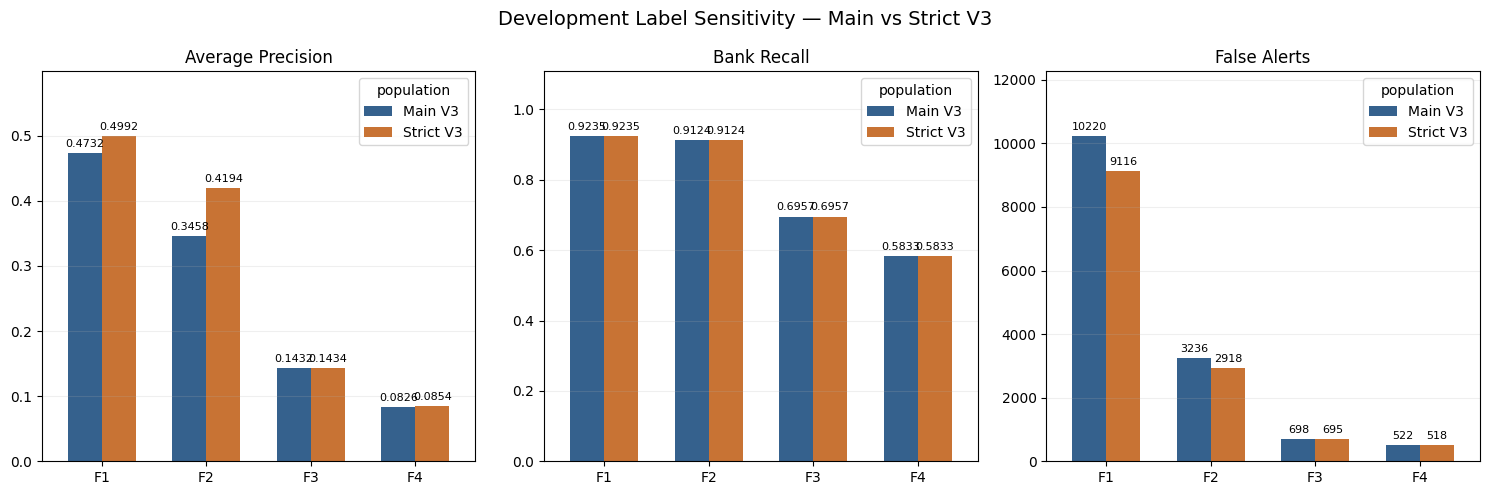

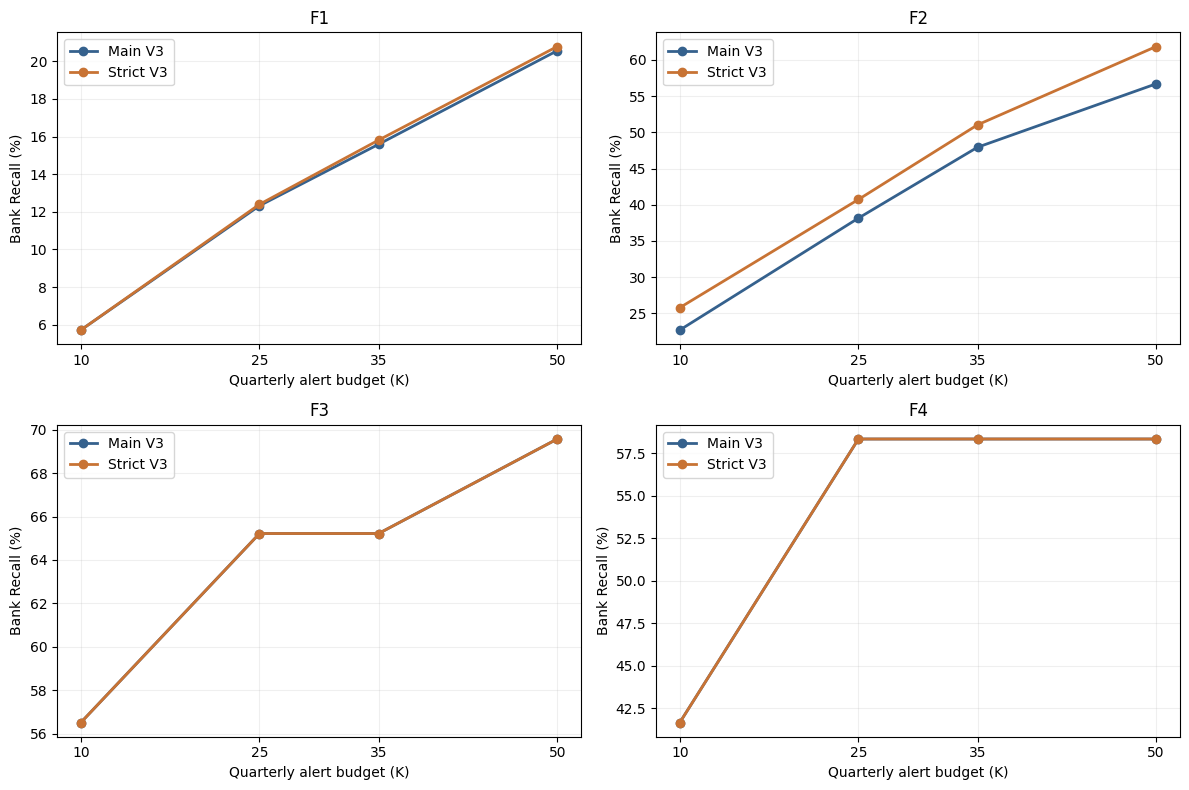


DEVELOPMENT-ONLY STRICT COHORT — SUMMARY
Validation folds  : F1-F4
Data split        : TRAIN only
Model retrained   : NO
Inference rerun   : NO
External test used: NO
Frozen spec edited: NO
Files created     : NO


In [459]:
# 5.3B-STRICT — Development-only strict cohort sensitivity

assert "P5_DEV_OOF" in globals()
assert "DEV_WINNER" in P5_DEV_OOF
assert "P5_COST_THRESHOLD" in globals()
assert "P5_GOLD" in globals()

STRICT_DEV_THRESHOLD = float(P5_COST_THRESHOLD)

STRICT_DEV_OOF = P5_DEV_OOF["DEV_WINNER"].copy()

STRICT_DEV_OOF["REPDTE"] = pd.to_datetime(
    STRICT_DEV_OOF["REPDTE"]
)

# Hard guards: development observations only
assert STRICT_DEV_OOF["fold"].isin(
    ["F1", "F2", "F3", "F4"]
).all()

assert STRICT_DEV_OOF["REPDTE"].dt.year.between(
    1985, 2006
).all()

assert STRICT_DEV_OOF["y"].isin([0, 1]).all()
assert np.isfinite(STRICT_DEV_OOF["score"]).all()

assert not STRICT_DEV_OOF.duplicated(
    ["fold", "CERT", "REPDTE"]
).any()


# --------------------------------------------------
# A. Read development eligibility only
# --------------------------------------------------

STRICT_DEV_FLAGS = (
    P5_GOLD
    .filter(
        (pl.col("__split") == "TRAIN")
        & pl.col("__year").is_between(1985, 2006)
    )
    .select(
        "CERT",
        "REPDTE",
        "ROBUSTNESS_ELIGIBLE_V3"
    )
    .collect(engine="streaming")
    .to_pandas()
)

STRICT_DEV_FLAGS["REPDTE"] = pd.to_datetime(
    STRICT_DEV_FLAGS["REPDTE"]
)

assert not STRICT_DEV_FLAGS.duplicated(
    ["CERT", "REPDTE"]
).any()

STRICT_DEV_OOF = STRICT_DEV_OOF.merge(
    STRICT_DEV_FLAGS,
    on=["CERT", "REPDTE"],
    how="left",
    validate="many_to_one",
    indicator=True
)

assert STRICT_DEV_OOF["_merge"].eq("both").all()

assert STRICT_DEV_OOF[
    "ROBUSTNESS_ELIGIBLE_V3"
].notna().all()


# --------------------------------------------------
# B. Exclusion audit by validation fold
# --------------------------------------------------

STRICT_DEV_AUDIT = []
STRICT_DEV_METRICS = []
STRICT_DEV_TOPK = []

for fold in ("F1", "F2", "F3", "F4"):

    main = STRICT_DEV_OOF.loc[
        STRICT_DEV_OOF["fold"].eq(fold)
    ].copy()

    strict = main.loc[
        main["ROBUSTNESS_ELIGIBLE_V3"].eq(True)
    ].copy()

    excluded = main.loc[
        ~main["ROBUSTNESS_ELIGIBLE_V3"].eq(True)
    ].copy()

    assert len(main) > 0
    assert len(strict) > 0

    STRICT_DEV_AUDIT.append({
        "fold": fold,
        "main_rows": len(main),
        "strict_rows": len(strict),
        "excluded_rows": len(excluded),
        "excluded_banks": excluded["CERT"].nunique(),
        "excluded_positive_rows": int(excluded["y"].sum()),
        "excluded_share": len(excluded) / len(main)
    })


    # ----------------------------------------------
    # C. Predictive and fixed-threshold performance
    # ----------------------------------------------

    for population, d in [
        ("Main V3", main),
        ("Strict V3", strict)
    ]:

        positive = d["y"].eq(1)
        alert = d["score"].ge(STRICT_DEV_THRESHOLD)

        tp = int((positive & alert).sum())
        fp = int((~positive & alert).sum())

        n_banks = d.loc[
            positive, "CERT"
        ].nunique()

        detected = d.loc[
            positive & alert, "CERT"
        ].nunique()

        STRICT_DEV_METRICS.append({
            "fold": fold,
            "population": population,
            "rows": len(d),
            "positive_quarters": int(positive.sum()),
            "prevalence": d["y"].mean(),

            "AP": average_precision_score(
                d["y"], d["score"]
            ) if positive.any() else np.nan,

            "ROC_AUC": roc_auc_score(
                d["y"], d["score"]
            ) if d["y"].nunique() == 2 else np.nan,

            "Brier_raw": brier_score_loss(
                d["y"], d["score"]
            ),

            "precision": tp / max(tp + fp, 1),

            "quarter_recall": (
                tp / positive.sum()
                if positive.any() else np.nan
            ),

            "bank_recall": (
                detected / n_banks
                if n_banks else np.nan
            ),

            "detected_banks": detected,
            "positive_banks": n_banks,
            "missed_banks": n_banks - detected,
            "false_alerts": fp,
            "total_alerts": tp + fp
        })


        # ------------------------------------------
        # D. Quarterly Top-K performance
        # ------------------------------------------

        for k in (10, 25, 35, 50):

            _, metrics = p5_quarterly_alerts(
                d,
                d["score"],
                k=k
            )

            STRICT_DEV_TOPK.append({
                "fold": fold,
                "population": population,
                **metrics
            })


P5_DEV_STRICT_AUDIT = pd.DataFrame(
    STRICT_DEV_AUDIT
)

P5_DEV_STRICT_RESULTS = pd.DataFrame(
    STRICT_DEV_METRICS
)

P5_DEV_STRICT_CAPACITY = pd.DataFrame(
    STRICT_DEV_TOPK
)


# --------------------------------------------------
# E. Exclusion results
# --------------------------------------------------

print("TABLE 1 — DEVELOPMENT EXCLUSION AUDIT")

display(
    P5_DEV_STRICT_AUDIT.style.format({
        "excluded_share": "{:.4%}"
    })
)


# --------------------------------------------------
# F. Model performance
# --------------------------------------------------

print("\nTABLE 2 — MAIN VS STRICT PERFORMANCE")

display(
    P5_DEV_STRICT_RESULTS.style.format({
        "prevalence": "{:.4%}",
        "AP": "{:.5f}",
        "ROC_AUC": "{:.5f}",
        "Brier_raw": "{:.6f}",
        "precision": "{:.2%}",
        "quarter_recall": "{:.2%}",
        "bank_recall": "{:.2%}"
    })
)


# --------------------------------------------------
# G. Top-K results
# --------------------------------------------------

print("\nTABLE 3 — DEVELOPMENT TOP-K SENSITIVITY")

display(
    P5_DEV_STRICT_CAPACITY[[
        "fold",
        "population",
        "K",
        "bank_recall",
        "detected_positive_banks",
        "positive_banks",
        "false_alerts",
        "precision",
        "alerts"
    ]].style.format({
        "bank_recall": "{:.2%}",
        "precision": "{:.2%}"
    })
)


# --------------------------------------------------
# H. Incremental results by fold
# --------------------------------------------------

delta_rows = []

for fold in ("F1", "F2", "F3", "F4"):

    g = (
        P5_DEV_STRICT_RESULTS
        .loc[P5_DEV_STRICT_RESULTS["fold"].eq(fold)]
        .set_index("population")
    )

    main = g.loc["Main V3"]
    strict = g.loc["Strict V3"]

    k25 = (
        P5_DEV_STRICT_CAPACITY
        .loc[
            P5_DEV_STRICT_CAPACITY["fold"].eq(fold)
            & P5_DEV_STRICT_CAPACITY["K"].eq(25)
        ]
        .set_index("population")
    )

    delta_rows.append({
        "fold": fold,
        "AP_main": main["AP"],
        "AP_strict": strict["AP"],
        "AP_change": strict["AP"] - main["AP"],

        "ROC_AUC_change": (
            strict["ROC_AUC"] - main["ROC_AUC"]
        ),

        "bank_recall_change_pp": (
            strict["bank_recall"] - main["bank_recall"]
        ) * 100,

        "recall_at25_change_pp": (
            k25.loc["Strict V3", "bank_recall"]
            - k25.loc["Main V3", "bank_recall"]
        ) * 100,

        "detected_banks_change": (
            strict["detected_banks"]
            - main["detected_banks"]
        ),

        "false_alerts_change": (
            strict["false_alerts"]
            - main["false_alerts"]
        )
    })

P5_DEV_STRICT_DELTA = pd.DataFrame(delta_rows)

print("\nTABLE 4 — INCREMENTAL SENSITIVITY BY FOLD")

display(
    P5_DEV_STRICT_DELTA.style.format({
        "AP_main": "{:.5f}",
        "AP_strict": "{:.5f}",
        "AP_change": "{:+.5f}",
        "ROC_AUC_change": "{:+.5f}",
        "bank_recall_change_pp": "{:+.2f}",
        "recall_at25_change_pp": "{:+.2f}"
    })
)


# --------------------------------------------------
# I. Pooled bank-fold performance
# --------------------------------------------------

P5_DEV_STRICT_SUMMARY = (
    P5_DEV_STRICT_RESULTS
    .groupby("population", sort=False)
    .agg(
        mean_AP=("AP", "mean"),
        mean_ROC_AUC=("ROC_AUC", "mean"),
        detected_bank_folds=("detected_banks", "sum"),
        positive_bank_folds=("positive_banks", "sum"),
        false_alerts=("false_alerts", "sum"),
        total_alerts=("total_alerts", "sum")
    )
    .reset_index()
)

P5_DEV_STRICT_SUMMARY["pooled_bank_recall"] = (
    P5_DEV_STRICT_SUMMARY["detected_bank_folds"]
    / P5_DEV_STRICT_SUMMARY["positive_bank_folds"]
)

print("\nTABLE 5 — OVERALL DEVELOPMENT ROBUSTNESS")

display(
    P5_DEV_STRICT_SUMMARY.style.format({
        "mean_AP": "{:.5f}",
        "mean_ROC_AUC": "{:.5f}",
        "pooled_bank_recall": "{:.2%}"
    })
)


# --------------------------------------------------
# J. Visualization
# --------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, metric, title in zip(
    axes,
    ["AP", "bank_recall", "false_alerts"],
    ["Average Precision", "Bank Recall", "False Alerts"]
):

    pivot = P5_DEV_STRICT_RESULTS.pivot(
        index="fold",
        columns="population",
        values=metric
    )[["Main V3", "Strict V3"]]

    pivot.plot(
        kind="bar",
        ax=ax,
        color=["#35618D", "#C87334"],
        width=0.65,
        rot=0
    )

    for container in ax.containers:

        ax.bar_label(
            container,
            fmt="%.0f" if metric == "false_alerts" else "%.4f",
            padding=3,
            fontsize=8
        )

    ax.set_title(title)
    ax.set_xlabel("")
    ax.grid(axis="y", alpha=0.2)

    ax.set_ylim(
        0,
        max(pivot.to_numpy().max() * 1.2, 0.01)
    )

fig.suptitle(
    "Development Label Sensitivity — Main vs Strict V3",
    fontsize=14
)

plt.tight_layout()
plt.show()


# --------------------------------------------------
# K. Recall@K sensitivity by fold
# --------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, fold in zip(
    axes.ravel(), ["F1", "F2", "F3", "F4"]
):

    g = P5_DEV_STRICT_CAPACITY.loc[
        P5_DEV_STRICT_CAPACITY["fold"].eq(fold)
    ]

    for population, color in [
        ("Main V3", "#35618D"),
        ("Strict V3", "#C87334")
    ]:

        p = g.loc[g["population"].eq(population)]

        ax.plot(
            p["K"],
            p["bank_recall"] * 100,
            marker="o",
            color=color,
            linewidth=2,
            label=population
        )

    ax.set(
        title=fold,
        xlabel="Quarterly alert budget (K)",
        ylabel="Bank Recall (%)"
    )

    ax.set_xticks([10, 25, 35, 50])
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


print("\n" + "=" * 65)
print("DEVELOPMENT-ONLY STRICT COHORT — SUMMARY")
print("=" * 65)

print("Validation folds  : F1-F4")
print("Data split        : TRAIN only")
print("Model retrained   : NO")
print("Inference rerun   : NO")
print("External test used: NO")
print("Frozen spec edited: NO")
print("Files created     : NO")

#### Interpretation 5.3B-STRICT — Label Robustness

Excluding 2,271 uncertain administrative-exit observations
in F1–F4 removes no positive labels.

Mean AP increases from 0.26121 to 0.28683, while pooled
bank-fold recall remains unchanged at 91.62%.
False alerts decrease by 9.74%, and Top-25 coverage
increases from 262 to 268 bank-folds.

The largest AP improvement occurs in F2, from 0.34576
to 0.41935.

Main V3 is retained as the primary cohort.
Strict V3 provides evaluation robustness evidence,
not evidence of improved model training.

No external test access or model retraining is performed.

### 5.3B-PIT — Development-only Information Delay Sensitivity

**Problem:** Reporting dates do not establish when
financial information became available to supervisors.

**Methodology:** Compare current-quarter OOF scores with
exact prior-quarter OOF scores from the same validation
fold, retaining identical decision dates and target labels.

The experiment measures sensitivity to delayed risk
information without retraining or external test access.

Prior-quarter scores are an availability proxy,
not verified historical reporting vintages.

TABLE 1 — PRIOR-QUARTER MATCHING COVERAGE


,fold,original_rows,matched_rows,unmatched_rows,coverage,original_positive_rows,matched_positive_rows,original_positive_banks,matched_positive_banks
0,F1,194880,176634,18246,90.64%,4598,4185,1347,1306
1,F2,163353,148610,14743,90.97%,511,379,194,149
2,F3,170344,157950,12394,92.72%,79,78,23,23
3,F4,112288,102314,9974,91.12%,38,32,12,10



TABLE 2 — INFORMATION DELAY SENSITIVITY


,fold,scenario,rows,positive_quarters,AP,ROC_AUC,Brier_raw,precision,quarter_recall,bank_recall,detected_banks,positive_banks,missed_banks,false_alerts,total_alerts
0,F1,Current-quarter,176634,4185,0.49029,0.96106,0.018328,28.27%,81.84%,91.35%,1193,1306,113,8689,12114
1,F1,Prior-quarter proxy,176634,4185,0.42264,0.94881,0.019104,27.54%,75.79%,87.44%,1142,1306,164,8345,11517
2,F2,Current-quarter,148610,379,0.28599,0.97525,0.005921,10.20%,80.21%,85.91%,128,149,21,2676,2980
3,F2,Prior-quarter proxy,148610,379,0.18388,0.96892,0.006068,9.02%,75.46%,85.91%,128,149,21,2886,3172
4,F3,Current-quarter,157950,78,0.15387,0.91491,0.001190,6.06%,53.85%,69.57%,16,23,7,651,693
5,F3,Prior-quarter proxy,157950,78,0.07276,0.89446,0.001191,5.01%,42.31%,60.87%,14,23,9,626,659
6,F4,Current-quarter,102314,32,0.09342,0.92759,0.001133,3.59%,53.12%,70.00%,7,10,3,457,474
7,F4,Prior-quarter proxy,102314,32,0.03402,0.91171,0.001121,3.12%,46.88%,50.00%,5,10,5,466,481



TABLE 3 — QUARTERLY TOP-K SENSITIVITY


,fold,scenario,K,bank_recall,detected_positive_banks,positive_banks,false_alerts,precision,alerts
0,F1,Current-quarter,10,5.44%,71,1306,22,80.00%,110
1,F1,Current-quarter,25,12.10%,158,1306,62,77.45%,275
2,F1,Current-quarter,35,15.31%,200,1306,91,76.36%,385
3,F1,Current-quarter,50,20.14%,263,1306,143,74.00%,550
4,F1,Prior-quarter proxy,10,4.82%,63,1306,29,73.64%,110
5,F1,Prior-quarter proxy,25,9.49%,124,1306,89,67.64%,275
6,F1,Prior-quarter proxy,35,12.94%,169,1306,126,67.27%,385
7,F1,Prior-quarter proxy,50,16.39%,214,1306,193,64.91%,550
8,F2,Current-quarter,10,23.49%,35,149,65,40.91%,110
9,F2,Current-quarter,25,39.60%,59,149,188,31.64%,275



TABLE 4 — INCREMENTAL PERFORMANCE


,fold,AP_current,AP_prior,AP_change,relative_AP_change,ROC_AUC_change,bank_recall_change_pp,recall_at25_change_pp,detected_banks_change,false_alerts_change
0,F1,0.49029,0.42264,-0.06764,-13.80%,-0.01225,-3.91,-2.60,-51,-344
1,F2,0.28599,0.18388,-0.10212,-35.71%,-0.00633,+0.00,-8.05,0,210
2,F3,0.15387,0.07276,-0.08111,-52.71%,-0.02045,-8.70,-17.39,-2,-25
3,F4,0.09342,0.03402,-0.05940,-63.59%,-0.01589,-20.00,-20.00,-2,9



TABLE 5 — OVERALL DEVELOPMENT SENSITIVITY


,scenario,mean_AP,mean_ROC_AUC,detected_bank_folds,positive_bank_folds,false_alerts,total_alerts,pooled_bank_recall
0,Current-quarter,0.25589,0.94470,1344,1488,12473,16261,90.32%
1,Prior-quarter proxy,0.17832,0.93097,1289,1488,12323,15829,86.63%


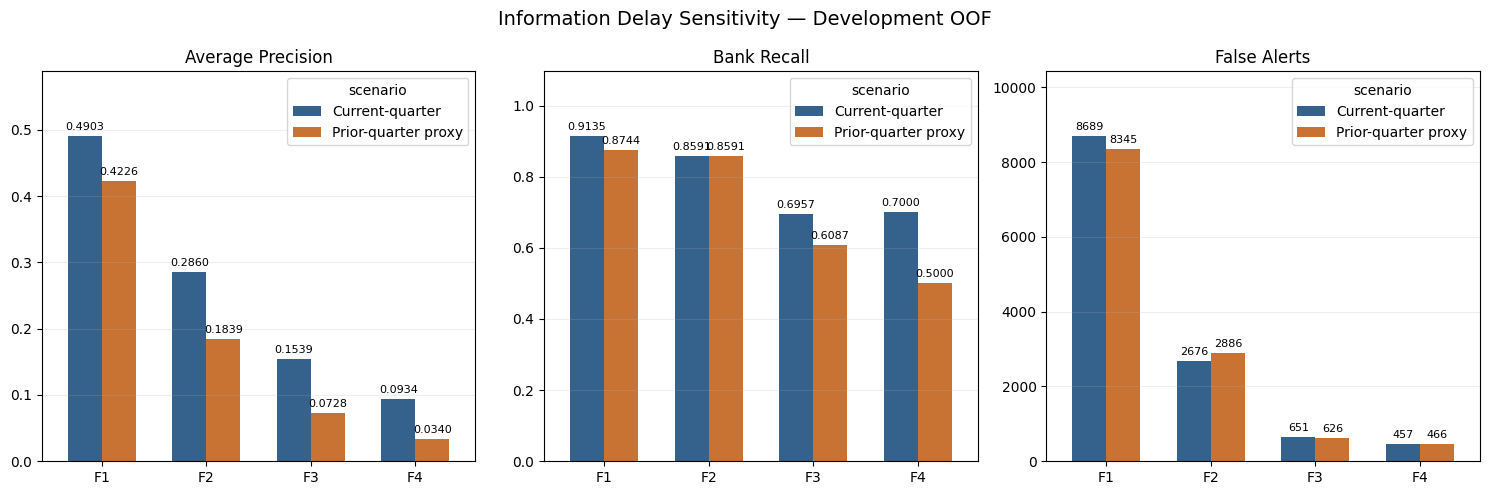

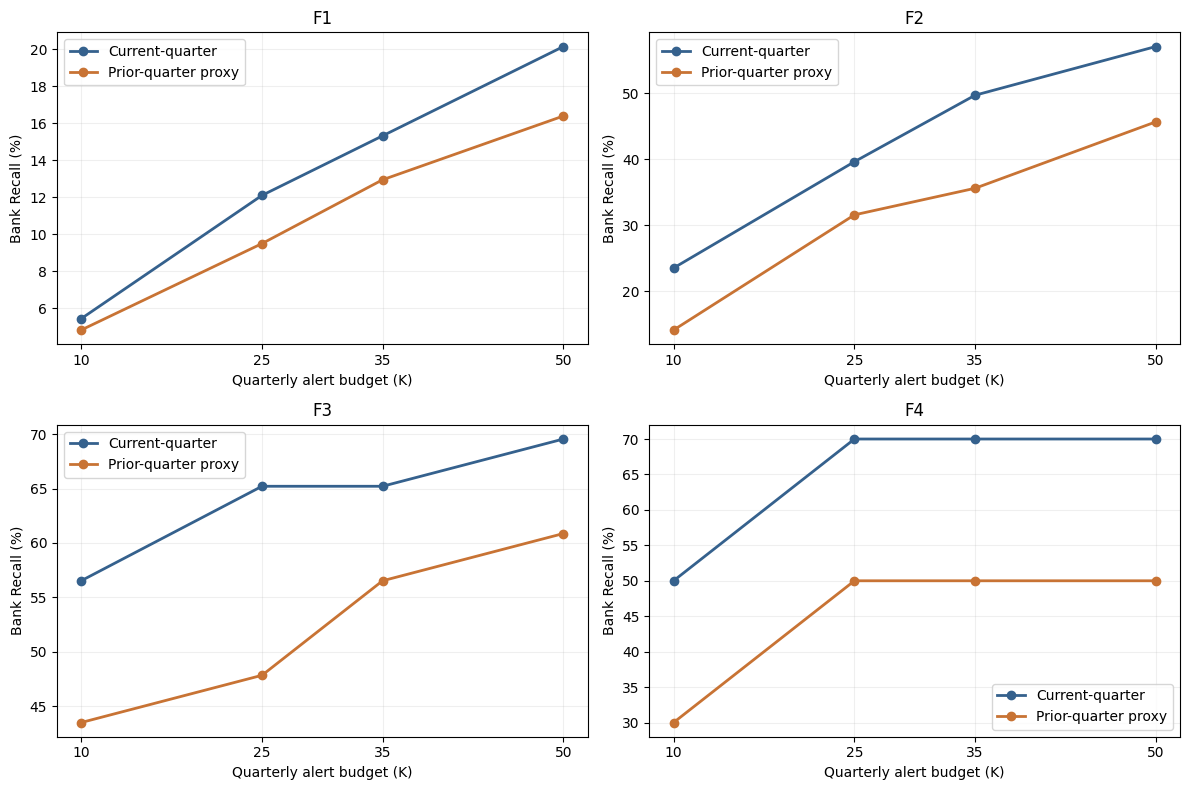


DEVELOPMENT INFORMATION DELAY — SUMMARY
Validation folds  : F1-F4 only
Score alignment   : Same fold, exact previous quarter
Decision dates    : Unchanged
Target labels     : Unchanged
Model retrained   : NO
Inference rerun   : NO
External test used: NO
Frozen spec edited: NO
Files created     : NO
Verified vintages : NOT ESTABLISHED


In [460]:
# 5.3B-PIT — Development-only information delay sensitivity

assert "P5_DEV_OOF" in globals()
assert "DEV_WINNER" in P5_DEV_OOF
assert "P5_COST_THRESHOLD" in globals()

PIT_DEV_THRESHOLD = float(P5_COST_THRESHOLD)

PIT_DEV_OOF = P5_DEV_OOF["DEV_WINNER"].copy()

PIT_DEV_OOF["REPDTE"] = pd.to_datetime(
    PIT_DEV_OOF["REPDTE"]
)

# Hard guards: development data only
assert PIT_DEV_OOF["fold"].isin(
    ["F1", "F2", "F3", "F4"]
).all()

assert PIT_DEV_OOF["REPDTE"].dt.year.between(
    1985, 2006
).all()

assert PIT_DEV_OOF["y"].isin([0, 1]).all()
assert np.isfinite(PIT_DEV_OOF["score"]).all()

PIT_DEV_OOF["q_id"] = (
    PIT_DEV_OOF["REPDTE"].dt.year * 4
    + PIT_DEV_OOF["REPDTE"].dt.quarter
)

assert not PIT_DEV_OOF.duplicated(
    ["fold", "CERT", "q_id"]
).any()

PIT_DEV_COVERAGE = []
PIT_DEV_RESULTS = []
PIT_DEV_TOPK = []
PIT_DEV_MATCHED = {}


# --------------------------------------------------
# A. Match exact previous-quarter OOF scores
# --------------------------------------------------

for fold in ("F1", "F2", "F3", "F4"):

    current = PIT_DEV_OOF.loc[
        PIT_DEV_OOF["fold"].eq(fold)
    ].copy()

    assert len(current) > 0

    prior = current[[
        "fold", "CERT", "q_id", "REPDTE", "score"
    ]].copy()

    prior = prior.rename(columns={
        "REPDTE": "prior_date",
        "score": "score_prior"
    })

    # Previous quarter t-1 is matched to quarter t
    prior["q_id"] += 1

    matched = current.merge(
        prior,
        on=["fold", "CERT", "q_id"],
        how="inner",
        validate="one_to_one"
    )

    matched = matched.rename(columns={
        "score": "score_current"
    })

    assert len(matched) > 0

    assert (
        matched["prior_date"] < matched["REPDTE"]
    ).all()

    prior_q = (
        matched["prior_date"].dt.year * 4
        + matched["prior_date"].dt.quarter
    )

    assert (
        matched["q_id"] - prior_q
    ).eq(1).all()

    PIT_DEV_MATCHED[fold] = matched.copy()

    PIT_DEV_COVERAGE.append({
        "fold": fold,
        "original_rows": len(current),
        "matched_rows": len(matched),
        "unmatched_rows": len(current) - len(matched),
        "coverage": len(matched) / len(current),

        "original_positive_rows": int(
            current["y"].sum()
        ),

        "matched_positive_rows": int(
            matched["y"].sum()
        ),

        "original_positive_banks": current.loc[
            current["y"].eq(1), "CERT"
        ].nunique(),

        "matched_positive_banks": matched.loc[
            matched["y"].eq(1), "CERT"
        ].nunique()
    })


    # ----------------------------------------------
    # B. Compare identical evaluation observations
    # ----------------------------------------------

    for scenario, score_col in [
        ("Current-quarter", "score_current"),
        ("Prior-quarter proxy", "score_prior")
    ]:

        d = matched[[
            "CERT", "REPDTE", "y"
        ]].copy()

        d["score"] = matched[score_col].to_numpy()

        positive = d["y"].eq(1)
        alert = d["score"].ge(PIT_DEV_THRESHOLD)

        tp = int((positive & alert).sum())
        fp = int((~positive & alert).sum())

        n_banks = d.loc[
            positive, "CERT"
        ].nunique()

        detected = d.loc[
            positive & alert, "CERT"
        ].nunique()

        PIT_DEV_RESULTS.append({
            "fold": fold,
            "scenario": scenario,
            "rows": len(d),
            "positive_quarters": int(positive.sum()),

            "AP": average_precision_score(
                d["y"], d["score"]
            ) if positive.any() else np.nan,

            "ROC_AUC": roc_auc_score(
                d["y"], d["score"]
            ) if d["y"].nunique() == 2 else np.nan,

            "Brier_raw": brier_score_loss(
                d["y"], d["score"]
            ),

            "precision": tp / max(tp + fp, 1),

            "quarter_recall": (
                tp / positive.sum()
                if positive.any() else np.nan
            ),

            "bank_recall": (
                detected / n_banks
                if n_banks else np.nan
            ),

            "detected_banks": detected,
            "positive_banks": n_banks,
            "missed_banks": n_banks - detected,
            "false_alerts": fp,
            "total_alerts": tp + fp
        })


        # ------------------------------------------
        # C. Quarterly Top-K evaluation
        # ------------------------------------------

        for k in (10, 25, 35, 50):

            _, metrics = p5_quarterly_alerts(
                d, d["score"], k=k
            )

            PIT_DEV_TOPK.append({
                "fold": fold,
                "scenario": scenario,
                **metrics
            })


P5_DEV_PIT_COVERAGE = pd.DataFrame(
    PIT_DEV_COVERAGE
)

P5_DEV_PIT_RESULTS = pd.DataFrame(
    PIT_DEV_RESULTS
)

P5_DEV_PIT_CAPACITY = pd.DataFrame(
    PIT_DEV_TOPK
)


# --------------------------------------------------
# D. Coverage audit
# --------------------------------------------------

print("TABLE 1 — PRIOR-QUARTER MATCHING COVERAGE")

display(
    P5_DEV_PIT_COVERAGE.style.format({
        "coverage": "{:.2%}"
    })
)


# --------------------------------------------------
# E. Predictive performance
# --------------------------------------------------

print("\nTABLE 2 — INFORMATION DELAY SENSITIVITY")

display(
    P5_DEV_PIT_RESULTS.style.format({
        "AP": "{:.5f}",
        "ROC_AUC": "{:.5f}",
        "Brier_raw": "{:.6f}",
        "precision": "{:.2%}",
        "quarter_recall": "{:.2%}",
        "bank_recall": "{:.2%}"
    })
)


# --------------------------------------------------
# F. Capacity comparison
# --------------------------------------------------

print("\nTABLE 3 — QUARTERLY TOP-K SENSITIVITY")

display(
    P5_DEV_PIT_CAPACITY[[
        "fold",
        "scenario",
        "K",
        "bank_recall",
        "detected_positive_banks",
        "positive_banks",
        "false_alerts",
        "precision",
        "alerts"
    ]].style.format({
        "bank_recall": "{:.2%}",
        "precision": "{:.2%}"
    })
)


# --------------------------------------------------
# G. Incremental performance
# --------------------------------------------------

pit_delta = []

for fold in ("F1", "F2", "F3", "F4"):

    g = P5_DEV_PIT_RESULTS.loc[
        P5_DEV_PIT_RESULTS["fold"].eq(fold)
    ].set_index("scenario")

    current = g.loc["Current-quarter"]
    prior = g.loc["Prior-quarter proxy"]

    k25 = P5_DEV_PIT_CAPACITY.loc[
        P5_DEV_PIT_CAPACITY["fold"].eq(fold)
        & P5_DEV_PIT_CAPACITY["K"].eq(25)
    ].set_index("scenario")

    pit_delta.append({
        "fold": fold,

        "AP_current": current["AP"],
        "AP_prior": prior["AP"],
        "AP_change": prior["AP"] - current["AP"],

        "relative_AP_change": (
            prior["AP"] / current["AP"] - 1
            if current["AP"] > 0 else np.nan
        ),

        "ROC_AUC_change": (
            prior["ROC_AUC"] - current["ROC_AUC"]
        ),

        "bank_recall_change_pp": (
            prior["bank_recall"] - current["bank_recall"]
        ) * 100,

        "recall_at25_change_pp": (
            k25.loc["Prior-quarter proxy", "bank_recall"]
            - k25.loc["Current-quarter", "bank_recall"]
        ) * 100,

        "detected_banks_change": (
            prior["detected_banks"]
            - current["detected_banks"]
        ),

        "false_alerts_change": (
            prior["false_alerts"]
            - current["false_alerts"]
        )
    })

P5_DEV_PIT_DELTA = pd.DataFrame(pit_delta)

print("\nTABLE 4 — INCREMENTAL PERFORMANCE")

display(
    P5_DEV_PIT_DELTA.style.format({
        "AP_current": "{:.5f}",
        "AP_prior": "{:.5f}",
        "AP_change": "{:+.5f}",
        "relative_AP_change": "{:+.2%}",
        "ROC_AUC_change": "{:+.5f}",
        "bank_recall_change_pp": "{:+.2f}",
        "recall_at25_change_pp": "{:+.2f}"
    })
)


# --------------------------------------------------
# H. Overall development performance
# --------------------------------------------------

P5_DEV_PIT_SUMMARY = (
    P5_DEV_PIT_RESULTS
    .groupby("scenario", sort=False)
    .agg(
        mean_AP=("AP", "mean"),
        mean_ROC_AUC=("ROC_AUC", "mean"),
        detected_bank_folds=("detected_banks", "sum"),
        positive_bank_folds=("positive_banks", "sum"),
        false_alerts=("false_alerts", "sum"),
        total_alerts=("total_alerts", "sum")
    )
    .reset_index()
)

P5_DEV_PIT_SUMMARY["pooled_bank_recall"] = (
    P5_DEV_PIT_SUMMARY["detected_bank_folds"]
    / P5_DEV_PIT_SUMMARY["positive_bank_folds"]
)

print("\nTABLE 5 — OVERALL DEVELOPMENT SENSITIVITY")

display(
    P5_DEV_PIT_SUMMARY.style.format({
        "mean_AP": "{:.5f}",
        "mean_ROC_AUC": "{:.5f}",
        "pooled_bank_recall": "{:.2%}"
    })
)


# --------------------------------------------------
# I. Performance visualization
# --------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, metric, title in zip(
    axes,
    ["AP", "bank_recall", "false_alerts"],
    ["Average Precision", "Bank Recall", "False Alerts"]
):

    pivot = P5_DEV_PIT_RESULTS.pivot(
        index="fold",
        columns="scenario",
        values=metric
    )[["Current-quarter", "Prior-quarter proxy"]]

    pivot.plot(
        kind="bar",
        ax=ax,
        color=["#35618D", "#C87334"],
        width=0.65,
        rot=0
    )

    for container in ax.containers:

        ax.bar_label(
            container,
            fmt="%.0f" if metric == "false_alerts" else "%.4f",
            padding=3,
            fontsize=8
        )

    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylim(
        0, max(pivot.to_numpy().max() * 1.2, 0.01)
    )
    ax.grid(axis="y", alpha=0.2)

fig.suptitle(
    "Information Delay Sensitivity — Development OOF",
    fontsize=14
)

plt.tight_layout()
plt.show()


# --------------------------------------------------
# J. Quarterly Top-K visualization
# --------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, fold in zip(
    axes.ravel(), ["F1", "F2", "F3", "F4"]
):

    g = P5_DEV_PIT_CAPACITY.loc[
        P5_DEV_PIT_CAPACITY["fold"].eq(fold)
    ]

    for scenario, color in [
        ("Current-quarter", "#35618D"),
        ("Prior-quarter proxy", "#C87334")
    ]:

        p = g.loc[g["scenario"].eq(scenario)]

        ax.plot(
            p["K"],
            p["bank_recall"] * 100,
            marker="o",
            color=color,
            linewidth=2,
            label=scenario
        )

    ax.set(
        title=fold,
        xlabel="Quarterly alert budget (K)",
        ylabel="Bank Recall (%)"
    )

    ax.set_xticks([10, 25, 35, 50])
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


print("\n" + "=" * 65)
print("DEVELOPMENT INFORMATION DELAY — SUMMARY")
print("=" * 65)
print("Validation folds  : F1-F4 only")
print("Score alignment   : Same fold, exact previous quarter")
print("Decision dates    : Unchanged")
print("Target labels     : Unchanged")
print("Model retrained   : NO")
print("Inference rerun   : NO")
print("External test used: NO")
print("Frozen spec edited: NO")
print("Files created     : NO")
print("Verified vintages : NOT ESTABLISHED")

#### Interpretation 5.3B-PIT — Information Delay Sensitivity

Using prior-quarter risk scores reduces mean AP from
0.25589 to 0.17832 (-30.31%) and pooled bank-fold recall
from 90.32% to 86.63%.

At Top-25, detected bank-folds decrease from 239 to 187.
AP and Recall@25 deteriorate across all four folds.

These findings demonstrate the importance of timely
financial information for effective early warning.

The analysis is restricted to matched development
observations and requires no model retraining.

Prior-quarter scores provide a delay sensitivity proxy,
not verification of historical reporting vintages.

### 5.3B-CAL — Chronological Calibration Sensitivity

**Problem:** Strong risk ranking does not necessarily
imply reliable absolute failure probabilities.

**Methodology:** Compare raw scores, historical prevalence,
Sigmoid, Isotonic and recency-weighted calibration using
expanding historical OOF windows.

Calibrators are fitted on earlier folds and evaluated
on subsequent folds using Brier score, Brier Skill Score
and observed versus predicted prevalence.

Method comparison uses F2–F3, with F4 retained as a
historical transfer check. No RF retraining, external
test access or frozen-model modification is performed.

TABLE 1 — CHRONOLOGICAL CALIBRATION


,fit_folds,validation_fold,method,observed_prevalence,mean_prediction,predicted_observed_ratio,Brier,BSS_historical,BSS_observed,LogLoss,AP,ROC_AUC
0,F1,F2,Raw score,0.3128%,1.8692%,5.98,0.00632580,-78.83%,-102.85%,0.026587,0.34576,0.97802
1,F1,F2,Historical prevalence,0.3128%,2.3594%,7.54,0.00353726,+0.00%,-13.43%,0.035523,0.00313,0.50000
2,F1,F2,Sigmoid,0.3128%,1.2554%,4.01,0.00376946,-6.56%,-20.88%,0.018733,0.34576,0.97802
3,F1,F2,Isotonic,0.3128%,0.9397%,3.00,0.00334015,+5.57%,-7.11%,0.014396,0.32466,0.97792
4,F1,F2,Recency Sigmoid,0.3128%,1.2449%,3.98,0.00380129,-7.46%,-21.90%,0.018689,0.34576,0.97802
5,F1,F2,Recency Isotonic,0.3128%,0.9347%,2.99,0.00335535,+5.14%,-7.60%,0.014370,0.32239,0.97793
6,F1+F2,F3,Raw score,0.0464%,0.5704%,12.30,0.00118060,-80.54%,-154.69%,0.007821,0.14323,0.91613
7,F1+F2,F3,Historical prevalence,0.0464%,1.4262%,30.75,0.00065393,+0.00%,-41.07%,0.016329,0.00046,0.50000
8,F1+F2,F3,Sigmoid,0.0464%,0.4801%,10.35,0.00056468,+13.65%,-21.82%,0.006385,0.14323,0.91613
9,F1+F2,F3,Isotonic,0.0464%,0.1801%,3.88,0.00053608,+18.02%,-15.65%,0.003376,0.13420,0.90039



TABLE 2 — METHOD COMPARISON (F2-F3)


,method,mean_Brier,mean_BSS_historical,mean_BSS_observed,mean_LogLoss,mean_AP
0,Recency Isotonic,0.00193481,+13.25%,-9.27%,0.008780,0.22824
1,Isotonic,0.00193811,+11.80%,-11.38%,0.008886,0.22943
2,Recency Sigmoid,0.00216983,+5.10%,-19.02%,0.012086,0.24449
3,Sigmoid,0.00216707,+3.54%,-21.35%,0.012559,0.24449
4,Historical prevalence,0.00209560,+0.00%,-27.25%,0.025926,0.00180
5,Raw score,0.00375320,-79.69%,-128.77%,0.017204,0.24449


Development candidate: Recency Isotonic

TABLE 3 — F4 TRANSFER CHECK


,method,selected_on_F2_F3,observed_prevalence,mean_prediction,predicted_observed_ratio,Brier,BSS_historical,BSS_observed,AP
12,Raw score,False,0.0338%,0.6326%,18.69,0.00116474,-172.07%,-244.29%,0.08263
13,Historical prevalence,False,0.0338%,0.9815%,29.00,0.00042811,+0.00%,-26.55%,0.00034
14,Sigmoid,False,0.0338%,0.3480%,10.28,0.00048630,-13.59%,-43.75%,0.08263
15,Isotonic,False,0.0338%,0.1672%,4.94,0.00046879,-9.50%,-38.57%,0.08192
16,Recency Sigmoid,False,0.0338%,0.2067%,6.11,0.00045789,-6.96%,-35.35%,0.08263
17,Recency Isotonic,True,0.0338%,0.1325%,3.92,0.00043085,-0.64%,-27.36%,0.08197


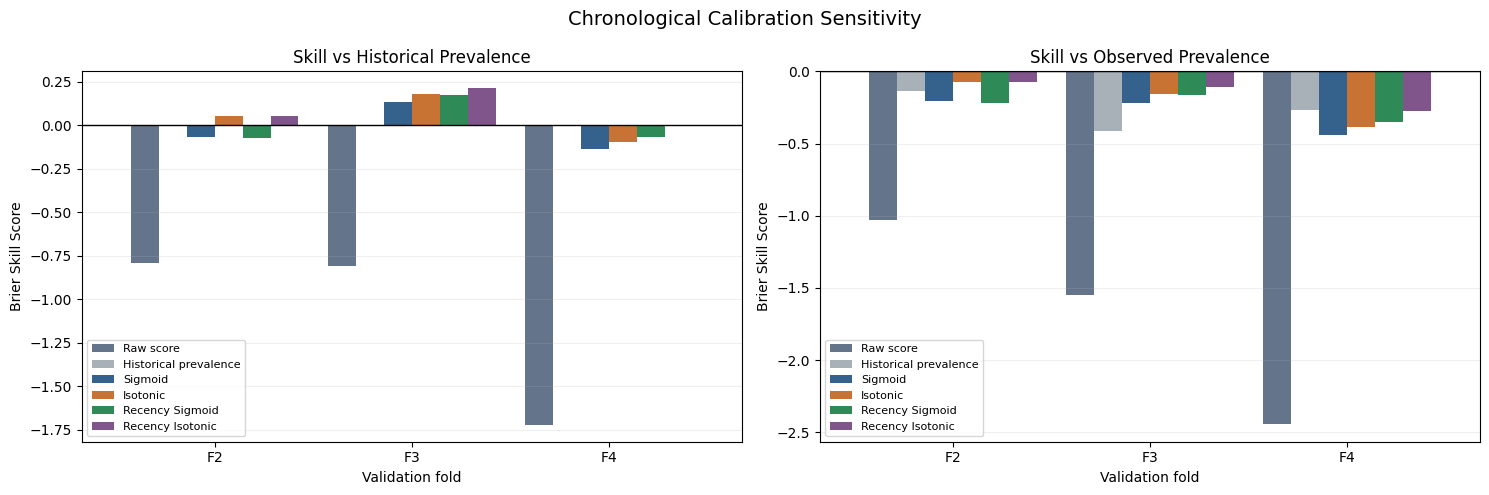

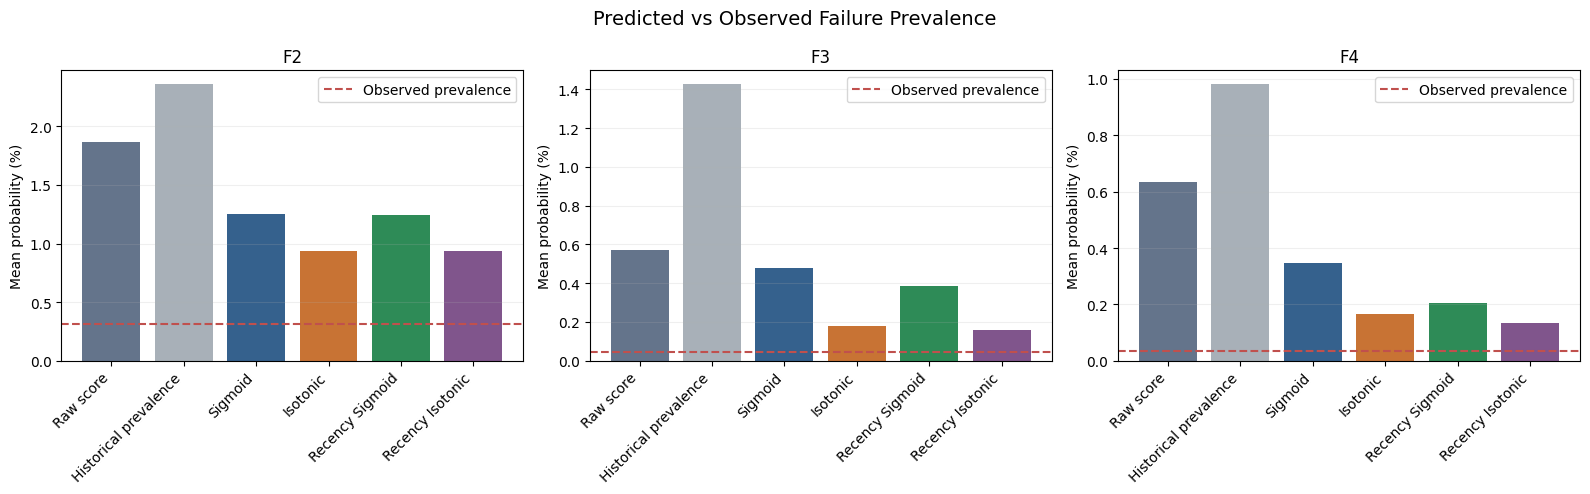


DEVELOPMENT CALIBRATION — SUMMARY
Selection folds    : F2-F3
Transfer fold      : F4
Selected candidate : Recency Isotonic
Target maturity    : Enforced
RF retrained       : NO
Calibrators fitted : YES
External test used : NO
Frozen spec edited : NO
Files created      : NO


In [461]:
# 5.3B-CAL — Development-only chronological calibration

assert "P5_DEV_OOF" in globals()
assert "DEV_WINNER" in P5_DEV_OOF

CAL_OOF = P5_DEV_OOF["DEV_WINNER"].copy()

CAL_OOF["REPDTE"] = pd.to_datetime(
    CAL_OOF["REPDTE"]
)

assert CAL_OOF["REPDTE"].dt.year.between(
    1985, 2006
).all()

assert CAL_OOF["fold"].isin(
    ["F1", "F2", "F3", "F4"]
).all()

assert CAL_OOF["y"].isin([0, 1]).all()
assert CAL_OOF["score"].between(0, 1).all()
assert np.isfinite(CAL_OOF["score"]).all()

CAL_HALF_LIFE = 5.0
CAL_EPS = 1e-8

CAL_RESULTS = []
CAL_PREDICTIONS = {}

CAL_WINDOWS = [
    (["F1"], "F2"),
    (["F1", "F2"], "F3"),
    (["F1", "F2", "F3"], "F4")
]


# --------------------------------------------------
# A. Chronological calibration
# --------------------------------------------------

for train_folds, valid_fold in CAL_WINDOWS:

    train = CAL_OOF.loc[
        CAL_OOF["fold"].isin(train_folds)
    ].copy()

    valid = CAL_OOF.loc[
        CAL_OOF["fold"].eq(valid_fold)
    ].copy()

    assert train["REPDTE"].max() < valid["REPDTE"].min()
    assert train["y"].nunique() == 2
    assert valid["y"].nunique() == 2

    # Ensure calibration outcomes are mature before
    # the subsequent validation decision period.
    first_decision = valid["REPDTE"].min()

    train = train.loc[
        train["REPDTE"] + pd.offsets.QuarterEnd(4)
        < first_decision
    ].copy()

    assert train["y"].nunique() == 2

    p_train = train["score"].to_numpy()
    y_train = train["y"].to_numpy()

    p_valid = valid["score"].to_numpy()
    y_valid = valid["y"].to_numpy()

    historical_prevalence = y_train.mean()
    observed_prevalence = y_valid.mean()

    # Five-year recency weighting
    age_years = (
        train["REPDTE"].max() - train["REPDTE"]
    ).dt.days.to_numpy() / 365.25

    weights = np.exp2(
        -age_years / CAL_HALF_LIFE
    )

    weights = weights / weights.mean()

    predictions = {
        "Raw score": p_valid,

        "Historical prevalence": np.full(
            len(valid),
            historical_prevalence
        )
    }

    # Sigmoid calibration
    sigmoid = LogisticRegression(
        C=1e6,
        solver="lbfgs",
        max_iter=500
    )

    sigmoid.fit(
        p_train.reshape(-1, 1),
        y_train
    )

    predictions["Sigmoid"] = sigmoid.predict_proba(
        p_valid.reshape(-1, 1)
    )[:, 1]

    # Isotonic calibration
    isotonic = IsotonicRegression(
        out_of_bounds="clip"
    )

    isotonic.fit(
        p_train,
        y_train
    )

    predictions["Isotonic"] = isotonic.predict(
        p_valid
    )

    # Recency-weighted sigmoid
    weighted_sigmoid = LogisticRegression(
        C=1e6,
        solver="lbfgs",
        max_iter=500
    )

    weighted_sigmoid.fit(
        p_train.reshape(-1, 1),
        y_train,
        sample_weight=weights
    )

    predictions["Recency Sigmoid"] = (
        weighted_sigmoid.predict_proba(
            p_valid.reshape(-1, 1)
        )[:, 1]
    )

    # Recency-weighted isotonic
    weighted_isotonic = IsotonicRegression(
        out_of_bounds="clip"
    )

    weighted_isotonic.fit(
        p_train,
        y_train,
        sample_weight=weights
    )

    predictions["Recency Isotonic"] = (
        weighted_isotonic.predict(p_valid)
    )


    # ----------------------------------------------
    # B. Benchmark Brier scores
    # ----------------------------------------------

    historical_brier = brier_score_loss(
        y_valid,
        predictions["Historical prevalence"]
    )

    observed_brier = brier_score_loss(
        y_valid,
        np.full(len(valid), observed_prevalence)
    )

    for method, p in predictions.items():

        p = np.asarray(p, dtype=float)

        assert np.isfinite(p).all()
        assert ((p >= 0) & (p <= 1)).all()

        brier = brier_score_loss(y_valid, p)

        clipped = np.clip(
            p, CAL_EPS, 1 - CAL_EPS
        )

        logloss = -np.mean(
            y_valid * np.log(clipped)
            + (1 - y_valid) * np.log(1 - clipped)
        )

        CAL_RESULTS.append({
            "fit_folds": "+".join(train_folds),
            "validation_fold": valid_fold,
            "method": method,
            "calibration_train_rows": len(train),
            "validation_rows": len(valid),
            "positive_rows": int(y_valid.sum()),

            "historical_prevalence": historical_prevalence,
            "observed_prevalence": observed_prevalence,
            "mean_prediction": p.mean(),

            "predicted_observed_ratio": (
                p.mean() / observed_prevalence
            ),

            "Brier": brier,

            "BSS_historical": (
                1 - brier / historical_brier
            ),

            "BSS_observed": (
                1 - brier / observed_brier
            ),

            "LogLoss": logloss,

            "AP": average_precision_score(
                y_valid, p
            ),

            "ROC_AUC": roc_auc_score(
                y_valid, p
            )
        })

        CAL_PREDICTIONS[(valid_fold, method)] = (
            pd.DataFrame({
                "CERT": valid["CERT"].to_numpy(),
                "REPDTE": valid["REPDTE"].to_numpy(),
                "y": y_valid,
                "probability": p
            })
        )


P5_DEV_CAL_RESULTS = pd.DataFrame(
    CAL_RESULTS
)


# --------------------------------------------------
# C. Calibration performance table
# --------------------------------------------------

print("TABLE 1 — CHRONOLOGICAL CALIBRATION")

display(
    P5_DEV_CAL_RESULTS[[
        "fit_folds",
        "validation_fold",
        "method",
        "observed_prevalence",
        "mean_prediction",
        "predicted_observed_ratio",
        "Brier",
        "BSS_historical",
        "BSS_observed",
        "LogLoss",
        "AP",
        "ROC_AUC"
    ]].style.format({
        "observed_prevalence": "{:.4%}",
        "mean_prediction": "{:.4%}",
        "predicted_observed_ratio": "{:.2f}",
        "Brier": "{:.8f}",
        "BSS_historical": "{:+.2%}",
        "BSS_observed": "{:+.2%}",
        "LogLoss": "{:.6f}",
        "AP": "{:.5f}",
        "ROC_AUC": "{:.5f}"
    })
)


# --------------------------------------------------
# D. Method comparison using F2-F3 only
# --------------------------------------------------

P5_CAL_SELECTION = (
    P5_DEV_CAL_RESULTS.loc[
        P5_DEV_CAL_RESULTS["validation_fold"]
        .isin(["F2", "F3"])
    ]
    .groupby("method")
    .agg(
        mean_Brier=("Brier", "mean"),
        mean_BSS_historical=("BSS_historical", "mean"),
        mean_BSS_observed=("BSS_observed", "mean"),
        mean_LogLoss=("LogLoss", "mean"),
        mean_AP=("AP", "mean")
    )
    .sort_values(
        "mean_BSS_historical",
        ascending=False
    )
    .reset_index()
)

P5_CAL_CANDIDATE = (
    P5_CAL_SELECTION.iloc[0]["method"]
)

print("\nTABLE 2 — METHOD COMPARISON (F2-F3)")

display(
    P5_CAL_SELECTION.style.format({
        "mean_Brier": "{:.8f}",
        "mean_BSS_historical": "{:+.2%}",
        "mean_BSS_observed": "{:+.2%}",
        "mean_LogLoss": "{:.6f}",
        "mean_AP": "{:.5f}"
    })
)

print("Development candidate:", P5_CAL_CANDIDATE)


# --------------------------------------------------
# E. F4 transfer assessment
# --------------------------------------------------

P5_CAL_F4_TRANSFER = (
    P5_DEV_CAL_RESULTS.loc[
        P5_DEV_CAL_RESULTS["validation_fold"].eq("F4")
    ].copy()
)

P5_CAL_F4_TRANSFER["selected_on_F2_F3"] = (
    P5_CAL_F4_TRANSFER["method"]
    .eq(P5_CAL_CANDIDATE)
)

print("\nTABLE 3 — F4 TRANSFER CHECK")

display(
    P5_CAL_F4_TRANSFER[[
        "method",
        "selected_on_F2_F3",
        "observed_prevalence",
        "mean_prediction",
        "predicted_observed_ratio",
        "Brier",
        "BSS_historical",
        "BSS_observed",
        "AP"
    ]].style.format({
        "observed_prevalence": "{:.4%}",
        "mean_prediction": "{:.4%}",
        "predicted_observed_ratio": "{:.2f}",
        "Brier": "{:.8f}",
        "BSS_historical": "{:+.2%}",
        "BSS_observed": "{:+.2%}",
        "AP": "{:.5f}"
    })
)


# --------------------------------------------------
# F. Brier Skill Score visualization
# --------------------------------------------------

cal_colors = [
    "#64748B",
    "#A8B0B8",
    "#35618D",
    "#C87334",
    "#2E8B57",
    "#80558C"
]

cal_methods = [
    "Raw score",
    "Historical prevalence",
    "Sigmoid",
    "Isotonic",
    "Recency Sigmoid",
    "Recency Isotonic"
]

fig, axes = plt.subplots(
    1, 2, figsize=(15, 5)
)

for ax, metric, title in zip(
    axes,
    ["BSS_historical", "BSS_observed"],
    [
        "Skill vs Historical Prevalence",
        "Skill vs Observed Prevalence"
    ]
):

    pivot = P5_DEV_CAL_RESULTS.pivot(
        index="validation_fold",
        columns="method",
        values=metric
    )[cal_methods]

    pivot.plot(
        kind="bar",
        ax=ax,
        color=cal_colors,
        width=0.85,
        rot=0
    )

    ax.axhline(
        0, color="black", linewidth=1
    )

    ax.set_title(title)
    ax.set_ylabel("Brier Skill Score")
    ax.set_xlabel("Validation fold")
    ax.grid(axis="y", alpha=0.2)
    ax.legend(fontsize=8)

fig.suptitle(
    "Chronological Calibration Sensitivity",
    fontsize=14
)

plt.tight_layout()
plt.show()


# --------------------------------------------------
# G. Predicted versus observed failure prevalence
# --------------------------------------------------

fig, axes = plt.subplots(
    1, 3, figsize=(16, 5)
)

for ax, fold in zip(
    axes, ["F2", "F3", "F4"]
):

    g = (
        P5_DEV_CAL_RESULTS.loc[
            P5_DEV_CAL_RESULTS["validation_fold"].eq(fold)
        ]
        .set_index("method")
        .loc[cal_methods]
    )

    x = np.arange(len(g))

    ax.bar(
        x,
        g["mean_prediction"] * 100,
        color=cal_colors
    )

    ax.axhline(
        g["observed_prevalence"].iloc[0] * 100,
        color="#C0504D",
        linestyle="--",
        label="Observed prevalence"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(
        g.index, rotation=45, ha="right"
    )

    ax.set_title(fold)
    ax.set_ylabel("Mean probability (%)")
    ax.legend()
    ax.grid(axis="y", alpha=0.2)

fig.suptitle(
    "Predicted vs Observed Failure Prevalence",
    fontsize=14
)

plt.tight_layout()
plt.show()


print("\n" + "=" * 65)
print("DEVELOPMENT CALIBRATION — SUMMARY")
print("=" * 65)

print("Selection folds    : F2-F3")
print("Transfer fold      : F4")
print("Selected candidate :", P5_CAL_CANDIDATE)
print("Target maturity    : Enforced")
print("RF retrained       : NO")
print("Calibrators fitted : YES")
print("External test used : NO")
print("Frozen spec edited : NO")
print("Files created      : NO")

#### Interpretation 5.3B-CAL — Calibration Robustness

Recency Isotonic achieves the highest mean historical
Brier Skill Score (+13.25%) on F2–F3.

On F4, it reduces Brier loss by 63.01% relative to raw
scores but remains inferior to the historical prevalence
benchmark (BSS = -0.64%).

Predicted failure probability remains 3.92 times the
observed prevalence. No calibration method outperforms
the observed-prevalence benchmark across F2–F4.

**Decision:** Retain the original calibration method
selected in Section 5.3B, as the sensitivity analysis
does not establish consistently superior temporal
generalization for an alternative method.

Recency Isotonic remains a promising alternative for
future research. Raw RF scores remain the basis for
capacity-constrained risk ranking and Top-K alerts.

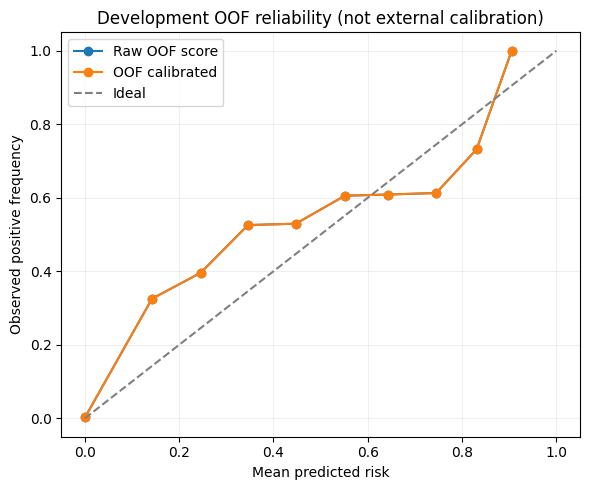

In [428]:
# 5.3C — reliability plot on OOF (descriptive; final training external reliability will differ).
if P5_DEV_OOF and P5_CALIBRATORS:
    d=P5_DEV_OOF['PHASE4_NATIVE_PROTOCOL']; score=d.score.to_numpy()
    cal=P5_CALIBRATORS['PHASE4_NATIVE_PROTOCOL'].predict(score)
    fig,ax=plt.subplots(figsize=(6,5))
    for name,p in [('Raw OOF score',score),('OOF calibrated',cal)]:
        q=np.linspace(0,1,11);bins=pd.cut(p,bins=q,include_lowest=True,duplicates='drop')
        g=pd.DataFrame({'p':p,'y':d.y,'bin':bins}).groupby('bin',observed=True).agg(
            predicted=('p','mean'),observed=('y','mean'),count=('y','size'))
        ax.plot(g.predicted,g.observed,marker='o',label=name)
    ax.plot([0,1],[0,1],linestyle='--',color='gray',label='Ideal')
    ax.set(xlabel='Mean predicted risk',ylabel='Observed positive frequency',
           title='Development OOF reliability (not external calibration)')
    ax.legend();ax.grid(alpha=.2);plt.tight_layout();plt.show()
else:print('Run development OOF calibration before plotting reliability.')

In [422]:
P5_MODE = "development"

In [429]:
# 5.3D — Huấn luyện RF ưu tiên dữ liệu gần trên toàn bộ TRAIN và freeze
from sklearn.pipeline import Pipeline

P5_READY_TO_TEST = False

if P5_MODE != "development":
    print("5.3D | Đặt P5_MODE = 'development' rồi chạy lại cell này.")
else:
    roles = {"PHASE4_NATIVE_PROTOCOL", "DEV_WINNER"}

    if (
        P5_DEV_WINNER_SPEC is None
        or set(P5_CALIBRATORS) != roles
        or set(P5_ALERT_POLICY["threshold_by_role"]) != roles
    ):
        raise RuntimeError(
            "Chạy xong bước chọn model, hiệu chuẩn và chọn ngưỡng trước 5.3D."
        )

    win = dict(P5_DEV_WINNER_SPEC)

    # Bảo đảm calibration và threshold thuộc RF gần.
    if win.get("strategy") != "RF ưu tiên dữ liệu gần":
        raise RuntimeError(
            "P5_DEV_WINNER_SPEC chưa được đồng bộ sang RF ưu tiên dữ liệu gần "
            "tại 5.3B. Không sử dụng calibration và threshold của RF T2 cũ."
        )

    win.update({
        "model": "RandomForest",
        "strategy": "RF ưu tiên dữ liệu gần",
        "params": dict(RF_PARAMS),
        "feature_count": 40,
        "by_cert": False,
        "by_recency": True,
        "half_life_years": float(RF_HALF_LIFE_YEARS),
    })

    P5_DEV_WINNER_SPEC = win

    output_dir = P5_OUTPUT.resolve()

    protected_files = (
        "external_test_access.json",
        "phase5_frozen_selection.json",
        "dev_challenger_pipeline.joblib",
        "oof_calibrator_phase4_native.json",
        "oof_calibrator_dev_winner.json",
        ".phase5_frozen_selection.tmp.json",
    )

    if any((output_dir / name).exists() for name in protected_files):
        stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
        run_dir = output_dir.parent / f"phase5_refit_{stamp}"
        run_dir.mkdir(exist_ok=False)
        print(f"5.3D | Thư mục cũ: {output_dir}", flush=True)
        print(f"5.3D | Lần fit mới: {run_dir}", flush=True)
    else:
        output_dir.mkdir(parents=True, exist_ok=True)
        run_dir = output_dir

    P5_OUTPUT = run_dir
    P5_FROZEN_SPEC_PATH = run_dir / "phase5_frozen_selection.json"
    P5_CHALLENGER_PATH = run_dir / "dev_challenger_pipeline.joblib"
    P5_CAL_MAIN_PATH = run_dir / "oof_calibrator_phase4_native.json"
    P5_CAL_CHALLENGER_PATH = run_dir / "oof_calibrator_dev_winner.json"
    manifest_tmp = run_dir / ".phase5_frozen_selection.tmp.json"

    # Đóng khóa external trong kernel cho tới khi 5.4A xác minh bộ mới.
    P5_EXTERNAL_UNLOCKED = False

    print("5.3D | Đang đọc TRAIN 1985–2006...", flush=True)

    Xtr, ytr, _train_meta = p5_collect_window(
        (1985, 2006), P5_CORE_FIELDS
    )

    ytr = np.asarray(ytr).ravel()

    train_cert = np.asarray(_train_meta["CERT"])

    train_dates = pd.DatetimeIndex(
        pd.to_datetime(_train_meta["REPDTE"])
    )

    try:
        P5_TRAIN_ROWS = int(len(ytr))
        P5_TRAIN_POSITIVE_QUARTERS = int(ytr.sum())

        verification_rows = Xtr[:min(16, len(Xtr))].copy()

        print(
            f"5.3D | Đang chọn Top 40 trên {P5_TRAIN_ROWS:,} dòng...",
            flush=True
        )

        full_selector = P5GainSelector(
            list(P5_CORE_FIELDS), k=40
        ).fit(Xtr, ytr)

        P5_CHALLENGER_FIELDS = list(
            full_selector.selected_names_
        )

        selected_indices = list(full_selector.indices_)

        del full_selector

        # Huấn luyện RF gần bằng đúng chiến lược trên Validation.
        print(
            "5.3D | Đang fit RF ưu tiên dữ liệu gần Top 40...",
            flush=True
        )

        print(f"RF parameters: {RF_PARAMS}", flush=True)

        print(
            f"Half-life: {RF_HALF_LIFE_YEARS} năm",
            flush=True
        )

        t0 = time.perf_counter()

        P5_FINAL_CHALLENGER = rf_strategy_fit(
            Xtr,
            ytr,
            train_cert,
            train_dates,
            selected_indices,
            by_cert=False,
            by_recency=True,
        )

        P5_FULL_FIT_SECONDS = time.perf_counter() - t0

    finally:
        del Xtr, ytr, _train_meta
        del train_cert, train_dates
        gc.collect()

    print(
        f"5.3D | Fit xong sau "
        f"{P5_FULL_FIT_SECONDS / 60:.1f} phút. Đang lưu...",
        flush=True,
    )

    # Mở file ở chế độ tạo mới để tránh ghi đè model đã có.
    with P5_CHALLENGER_PATH.open("xb") as model_file:
        joblib.dump(P5_FINAL_CHALLENGER, model_file)

    restored = joblib.load(P5_CHALLENGER_PATH)

    if not np.allclose(
        restored.predict_proba(verification_rows),
        P5_FINAL_CHALLENGER.predict_proba(verification_rows),
        atol=1e-7,
    ):
        raise RuntimeError(
            "Điểm dự báo sai lệch sau khi đọc lại model đã lưu."
        )

    del restored, verification_rows

    calibrator_paths = {
        "PHASE4_NATIVE_PROTOCOL": P5_CAL_MAIN_PATH,
        "DEV_WINNER": P5_CAL_CHALLENGER_PATH,
    }

    calibrator_specs = {}

    for role, path in calibrator_paths.items():

        if path.exists():
            raise FileExistsError(f"Đã có calibrator tại {path}")

        calibrator = P5_CALIBRATORS[role]

        p5_json_write(
            path,
            p5_calibration_export(calibrator)
        )

        calibrator_specs[role] = {
            "path": str(path),
            "sha256": p5_sha256_file(path),
            "method": calibrator.method,
        }

    specs = dict(
        phase="5.3",
        target=P5_Y,
        main_population="MODEL_ELIGIBLE_V3",
        robustness_population=(
            "MODEL_ELIGIBLE_V3 AND ROBUSTNESS_ELIGIBLE_V3"
        ),
        feature_count=40,
        main_features=P5_FINAL40,
        challenger_features=P5_CHALLENGER_FIELDS,
        selection_protocol=(
            "Phase4 original full TRAIN Top40 for main; "
            "independent full TRAIN gain Top40 for challenger; "
            "fold-train gain Top40 in CV; "
            "recency-weighted RandomForest selected on validation F1–F4"
        ),
        main_model="Phase4 Frozen LightGBM Native Top40",
        main_model_sha256=P5_MODEL_SHA,
        main_model_path=str(P5_MODEL_PATH),
        gold_export_sha256=P5_GOLD_SHA256,
        phase4_metadata_sha256=p5_sha256_file(P5_META_PATH),

        development_challenger=win,

        challenger_path=str(P5_CHALLENGER_PATH),
        challenger_sha256=p5_sha256_file(P5_CHALLENGER_PATH),

        calibrators=calibrator_specs,
        alert_policy=P5_ALERT_POLICY,
        folds=P5_FOLDS,
        seed=P5_SEED,

        # Hai tập test đã được truy cập trong các phiên bản trước.
        no_external_outcomes_used=True,
        previous_external_evaluation_exists=True,

        estimation_caveat=(
            "OOF calibration transfer; "
            "recency-weighted RF; "
            "external evaluation is supplementary"
        ),

        source_mode=P5_SOURCE_MODE,
        created_utc=datetime.now(timezone.utc).isoformat(),
    )

    specs["spec_sha256"] = p5_digest(specs)

    # Chỉ công bố manifest sau khi model và calibrator đã được lưu.
    p5_json_write(manifest_tmp, specs)

    if P5_FROZEN_SPEC_PATH.exists():
        raise FileExistsError(
            f"Đã có frozen manifest tại {P5_FROZEN_SPEC_PATH}"
        )

    manifest_tmp.rename(P5_FROZEN_SPEC_PATH)

    P5_READY_TO_TEST = True

    print(f"5.3D | Đã freeze tại {P5_FROZEN_SPEC_PATH}")
    print(f"Spec SHA256 = {specs['spec_sha256']}")
    print("Final challenger: RF ưu tiên dữ liệu gần Top 40")
    print(f"Half-life: {RF_HALF_LIFE_YEARS} năm")
    print(f"Features: {len(P5_CHALLENGER_FIELDS)}")
    print("PASS — RF gần đã được huấn luyện và freeze.")

5.3D | Thư mục cũ: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase5_v3\phase4_merged


5.3D | Lần fit mới: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase5_v3\phase5_refit_20261125T153506999665Z
5.3D | Đang đọc TRAIN 1985–2006...
5.3D | Đang chọn Top 40 trên 1,121,901 dòng...
5.3D | Đang fit RF ưu tiên dữ liệu gần Top 40...
RF parameters: {'n_estimators': 60, 'n_jobs': 2, 'class_weight': 'balanced_subsample', 'max_depth': 18, 'min_samples_leaf': 25}
Half-life: 5 năm
5.3D | Fit xong sau 3.8 phút. Đang lưu...
5.3D | Đã freeze tại C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase5_v3\phase5_refit_20261125T153506999665Z\phase5_frozen_selection.json
Spec SHA256 = be8f1b5c5c2a7bf5883ae38bcaf22b4706805425c32fa7e963b7880dfba6314c
Final challenger: RF ưu tiên dữ liệu gần Top 40
Half-life: 5 năm
Features: 40
PASS — RF gần đã được huấn luyện và freeze.


In [430]:
# Chạy sau khi 5.3D đã freeze RF ưu tiên dữ liệu gần
assert P5_FROZEN_SPEC_PATH.is_file(), P5_FROZEN_SPEC_PATH

P5_MODE = "external"

_frozen = json.loads(
    P5_FROZEN_SPEC_PATH.read_text(encoding="utf-8-sig")
)

P5_OUTPUT = P5_FROZEN_SPEC_PATH.parent / (
    f"external_recheck_{_frozen['spec_sha256'][:8]}"
)

P5_OUTPUT.mkdir(exist_ok=True)

print("Frozen spec:", P5_FROZEN_SPEC_PATH)
print("External output:", P5_OUTPUT)

Frozen spec: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase5_v3\phase5_refit_20261125T153506999665Z\phase5_frozen_selection.json
External output: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase5_v3\phase5_refit_20261125T153506999665Z\external_recheck_be8f1b5c


In [ ]:
# 5.4A — immutable freeze verifier, early test lock / hash discipline.
from pathlib import Path
# Manual confirmation required after model and policy freeze.
# Change to True only when ready for external evaluation.

P5_MODE = 'external'
P5_EXTERNAL_CONFIRM = False
P5_EXTERNAL_UNLOCKED = False
P5_FROZEN_SPEC = None

# Dùng đường dẫn từ 5.3D trong cùng kernel.
P5_FROZEN_SPEC_PATH = Path(P5_FROZEN_SPEC_PATH)

if P5_MODE == 'external':
    if not P5_EXTERNAL_CONFIRM:
        raise RuntimeError('External scoring is locked. Confirm manually in this cell after freeze.')
    if not P5_FROZEN_SPEC_PATH.is_file():
        raise FileNotFoundError(
            f'Không tìm thấy frozen spec tại: {P5_FROZEN_SPEC_PATH.resolve()}'
        )

    P5_FROZEN_SPEC = json.loads(
        P5_FROZEN_SPEC_PATH.read_text(encoding='utf-8-sig')
    )
    raw={k:v for k,v in P5_FROZEN_SPEC.items() if k!='spec_sha256'}
    assert p5_digest(raw)==P5_FROZEN_SPEC['spec_sha256'], 'Freeze manifest altered'
    assert P5_FROZEN_SPEC['main_model_sha256']==P5_MODEL_SHA
    assert P5_FROZEN_SPEC['phase4_metadata_sha256']==p5_sha256_file(P5_META_PATH)
    assert P5_FROZEN_SPEC['main_features']==P5_FINAL40
    assert (
          P5_FROZEN_SPEC['development_challenger']['strategy']
        == 'RF ưu tiên dữ liệu gần'
        ), 'Frozen challenger không phải RF ưu tiên dữ liệu gần'

    assert (
           P5_FROZEN_SPEC['development_challenger']['by_recency']
            is True
          ),        'Frozen RF chưa sử dụng trọng số thời gian'

    assert (
          P5_FROZEN_SPEC['development_challenger']['by_cert']
          is False
     ), 'Frozen RF sử dụng sai chiến lược trọng số'

    print(
            "Frozen strategy:",
            P5_FROZEN_SPEC['development_challenger']['strategy']
         )

    print(
    "Half-life:",
    P5_FROZEN_SPEC['development_challenger']['half_life_years']
        )
    assert set(P5_FROZEN_SPEC['alert_policy']['threshold_by_role'])=={'PHASE4_NATIVE_PROTOCOL','DEV_WINNER'}
    if P5_SOURCE_MODE=='EXPORTED_PARQUET':
        assert P5_FROZEN_SPEC['gold_export_sha256']==P5_GOLD_SHA256
    assert p5_sha256_file(P5_FROZEN_SPEC['challenger_path'])==P5_FROZEN_SPEC['challenger_sha256']
    for key,d in P5_FROZEN_SPEC['calibrators'].items():
        assert p5_sha256_file(d['path'])==d['sha256'],f'Calibrator tampered: {key}'
    P5_EXTERNAL_CHALLENGER=joblib.load(P5_FROZEN_SPEC['challenger_path'])
    P5_EXTERNAL_CAL={key:json.loads(Path(d['path']).read_text(encoding='utf-8'))
                     for key,d in P5_FROZEN_SPEC['calibrators'].items()}
    _access_log=P5_OUTPUT/'external_test_access.json'
    _access={'phase5_frozen_spec_sha256':P5_FROZEN_SPEC['spec_sha256'],
              'main_model_sha256':P5_MODEL_SHA, 'gold_export_sha256':P5_GOLD_SHA256,
              'first_access_utc':datetime.now(timezone.utc).isoformat()}
    if _access_log.exists():
        _old=json.loads(_access_log.read_text(encoding='utf-8'))
        for _key in ('phase5_frozen_spec_sha256','main_model_sha256','gold_export_sha256'):
            assert _old[_key]==_access[_key], 'Cannot re-evaluate external with a changed spec or Gold'
        print('REPLAY of the same locked external evaluation; NOT a fresh independent test.')
    else:
        p5_json_write(_access_log,_access)
    P5_EXTERNAL_UNLOCKED=True
    print('PASS — pre-test immutable spec, main booster, challenger and calibrator hashes verified.')
    print('External windows may now be read ONCE for reporting.')
else:print('External windows LOCKED (default).')

Frozen strategy: RF ưu tiên dữ liệu gần
Half-life: 5.0
PASS — pre-test immutable spec, main booster, challenger and calibrator hashes verified.
External windows may now be read ONCE for reporting.


In [432]:
# 5.4B — Final external scoring: LightGBM vs RF ưu tiên dữ liệu gần
# Frozen models and policies; never train here.

def p5_read_external(split, population='MAIN_V3'):
    assert P5_EXTERNAL_UNLOCKED and P5_MODE == 'external'
    assert split in ('CRISIS_TEST', 'RECENT_OOT')
    assert population in ('MAIN_V3', 'ROBUSTNESS_V3')

    source = P5_GOLD.filter(pl.col('__split') == split)

    if split == 'RECENT_OOT':
        source = source.filter(
            pl.col('REPDTE').cast(pl.Date)
            <= pl.date(2025, 6, 30)
        )

    if population == 'ROBUSTNESS_V3':
        source = source.filter(
            pl.col('ROBUSTNESS_ELIGIBLE_V3').fill_null(False)
        )

    t = (
        source.select('CERT', 'REPDTE', P5_Y, *P5_CORE_FIELDS)
        .sort('CERT', 'REPDTE')
        .collect(engine='streaming')
    )

    X = t.select(P5_CORE_FIELDS).to_numpy().astype(np.float32, copy=False)
    X[~np.isfinite(X)] = np.nan

    y = t[P5_Y].to_numpy().astype(np.int8, copy=False)

    meta = {
        'CERT': t['CERT'].to_numpy().copy(),
        'REPDTE': pd.to_datetime(t['REPDTE'].to_list()),
        'y': y.copy()
    }

    if split == 'RECENT_OOT':
        assert meta['REPDTE'].max() <= pd.Timestamp('2025-06-30')

    return X, y, meta


def p5_score_external(X, calibrate=True):
    assert P5_EXTERNAL_UNLOCKED

    ix = [P5_CORE_FIELDS.index(f) for f in P5_FINAL40]

    raw_main = np.asarray(
        P5_BOOSTER.predict(
            np.ascontiguousarray(X[:, ix]),
            num_threads=P5_N_JOBS
        ),
        dtype=float
    )

    # RF ưu tiên dữ liệu gần đã được fit và freeze tại 5.3D.
    positive_col = list(P5_EXTERNAL_CHALLENGER.classes_).index(1)

    raw_chall = np.asarray(
        P5_EXTERNAL_CHALLENGER.predict_proba(X)[:, positive_col],
        dtype=float
    )

    if not calibrate:
        return {
            'PHASE4_NATIVE_PROTOCOL': raw_main,
            'DEV_WINNER': raw_chall
        }

    return {
        'PHASE4_NATIVE_PROTOCOL': p5_calibration_apply(
            P5_EXTERNAL_CAL['PHASE4_NATIVE_PROTOCOL'], raw_main
        ),
        'DEV_WINNER': p5_calibration_apply(
            P5_EXTERNAL_CAL['DEV_WINNER'], raw_chall
        )
    }


P5_TEST_SUMMARY = []
P5_EXTERNAL_PREDICTIONS = {}
P5_CAPACITY_SUMMARY = []

if P5_EXTERNAL_UNLOCKED:

    for split in ['CRISIS_TEST', 'RECENT_OOT']:

        X, y, meta = p5_read_external(split, 'MAIN_V3')

        print(
            f"\n{split} | "
            f"{meta['REPDTE'].min():%Y-%m-%d} → "
            f"{meta['REPDTE'].max():%Y-%m-%d} | "
            f"{len(y):,} rows",
            flush=True
        )

        scores = p5_score_external(X, calibrate=False)

        for role, raw in scores.items():

            policy = P5_FROZEN_SPEC['alert_policy']
            cut = float(policy['threshold_by_role'][role])

            calibrated = p5_calibration_apply(
                P5_EXTERNAL_CAL[role], raw
            )

            metrics = p5_metric(
                y, raw, meta['CERT'], threshold=cut
            )

            metrics['Brier_calibrated'] = float(
                brier_score_loss(y, calibrated)
            )

            metrics['AP_calibrated'] = (
                float(average_precision_score(y, calibrated))
                if y.sum() else np.nan
            )

            metrics['threshold_raw'] = cut
            metrics['alert_rate'] = float((raw >= cut).mean())

            P5_TEST_SUMMARY.append(dict(
                split=split,
                role=role,
                population='MAIN_V3',
                **metrics
            ))

            record = pd.DataFrame({
                'CERT': meta['CERT'],
                'REPDTE': meta['REPDTE'],
                'y': y,
                'score': raw,
                'calibrated_probability': calibrated,
                'fixed_alert': raw >= cut
            })

            P5_EXTERNAL_PREDICTIONS[(split, role)] = record

            for k in policy['capacity_options']:

                alerts, summary = p5_quarterly_alerts(
                    record, raw, k=int(k)
                )

                P5_CAPACITY_SUMMARY.append(dict(
                    split=split,
                    role=role,
                    **summary
                ))

        del X, y, meta, scores
        gc.collect()

    P5_TEST_SUMMARY = pd.DataFrame(P5_TEST_SUMMARY)
    P5_CAPACITY_SUMMARY = pd.DataFrame(P5_CAPACITY_SUMMARY)

    display(P5_TEST_SUMMARY.round(5))
    display(P5_CAPACITY_SUMMARY.round(5))

    P5_TEST_SUMMARY.to_csv(
        P5_OUTPUT / 'final_external_test_scorecards.csv',
        index=False
    )

    P5_CAPACITY_SUMMARY.to_csv(
        P5_OUTPUT / 'final_external_alert_capacity.csv',
        index=False
    )

else:
    print('NOT RUN — external scoring is locked.')


CRISIS_TEST | 2008-03-31 → 2012-12-31 | 157,851 rows

RECENT_OOT | 2014-03-31 → 2025-06-30 | 249,606 rows


,split,role,population,rows,positive_quarters,prevalence,PR_AUC_AP,ROC_AUC,Brier,precision,...,F2,precision_top1pct,recall_top1pct,positive_banks,detected_banks_top1pct,bank_recall_top1pct,Brier_calibrated,AP_calibrated,threshold_raw,alert_rate
0,CRISIS_TEST,PHASE4_NATIVE_PROTOCOL,MAIN_V3,157851,1880,0.01191,0.63926,0.98241,0.00719,0.27541,...,0.61348,0.65358,0.54894,487,416,0.85421,0.00719,0.63926,0.01217,0.03828
1,CRISIS_TEST,DEV_WINNER,MAIN_V3,157851,1880,0.01191,0.63361,0.97736,0.01424,0.21459,...,0.55233,0.65168,0.54734,487,420,0.86242,0.00734,0.60752,0.19191,0.05054
2,RECENT_OOT,PHASE4_NATIVE_PROTOCOL,MAIN_V3,249606,175,0.00070,0.31188,0.93472,0.00056,0.11216,...,0.35064,0.05406,0.77143,53,44,0.83019,0.00056,0.31188,0.01217,0.00468
3,RECENT_OOT,DEV_WINNER,MAIN_V3,249606,175,0.00070,0.37201,0.90371,0.00208,0.07513,...,0.26862,0.05366,0.76571,53,44,0.83019,0.00079,0.33655,0.19191,0.00704


,split,role,K,alerts,true_positive_quarters,precision,recall,positive_banks,detected_positive_banks,bank_recall,false_alerts
0,CRISIS_TEST,PHASE4_NATIVE_PROTOCOL,10,200,173,0.86500,0.09202,487,134,0.27515,27
1,CRISIS_TEST,PHASE4_NATIVE_PROTOCOL,25,500,388,0.77600,0.20638,487,241,0.49487,112
2,CRISIS_TEST,PHASE4_NATIVE_PROTOCOL,50,1000,701,0.70100,0.37287,487,358,0.73511,299
3,CRISIS_TEST,DEV_WINNER,10,200,175,0.87500,0.09309,487,144,0.29569,25
4,CRISIS_TEST,DEV_WINNER,25,500,408,0.81600,0.21702,487,278,0.57084,92
5,CRISIS_TEST,DEV_WINNER,50,1000,717,0.71700,0.38138,487,377,0.77413,283
6,RECENT_OOT,PHASE4_NATIVE_PROTOCOL,10,460,75,0.16304,0.42857,53,35,0.66038,385
7,RECENT_OOT,PHASE4_NATIVE_PROTOCOL,25,1150,114,0.09913,0.65143,53,41,0.77358,1036
8,RECENT_OOT,PHASE4_NATIVE_PROTOCOL,50,2300,133,0.05783,0.76000,53,44,0.83019,2167
9,RECENT_OOT,DEV_WINNER,10,460,88,0.19130,0.50286,53,38,0.71698,372


In [433]:
rows = []

for split in ("CRISIS_TEST", "RECENT_OOT"):
    rf = P5_EXTERNAL_PREDICTIONS[(split, "DEV_WINNER")]
    years = pd.to_datetime(rf["REPDTE"]).dt.year

    for year, g in rf.groupby(years):
        n_pos = int(g["y"].eq(1).sum())
        rows.append({
            "Tập test": split,
            "Năm": int(year),
            "Số dòng nhãn dương": n_pos,
            "AP": average_precision_score(g["y"], g["score"]) if n_pos else float("nan"),
        })

display(pd.DataFrame(rows).round(5))

,Tập test,Năm,Số dòng nhãn dương,AP
0,CRISIS_TEST,2008,355,0.46240
1,CRISIS_TEST,2009,670,0.72157
2,CRISIS_TEST,2010,457,0.75994
3,CRISIS_TEST,2011,269,0.71358
4,CRISIS_TEST,2012,129,0.70508
5,RECENT_OOT,2014,46,0.55005
6,RECENT_OOT,2015,23,0.34909
7,RECENT_OOT,2016,29,0.64555
8,RECENT_OOT,2017,9,0.41176
9,RECENT_OOT,2018,6,0.04102


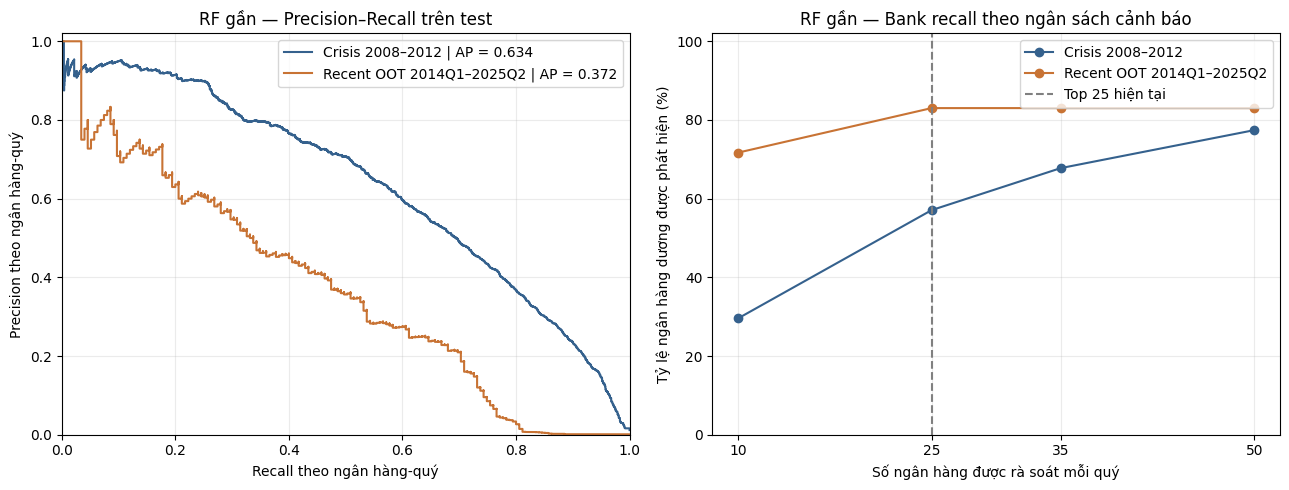

,Tập test,Top K/quý,Ngân hàng phát hiện,Ngân hàng dương,Bank recall (%),Cảnh báo sai (ngân hàng-quý)
0,Crisis 2008–2012,10,144,487,29.57,25
1,Crisis 2008–2012,25,278,487,57.08,92
2,Crisis 2008–2012,35,330,487,67.76,152
3,Crisis 2008–2012,50,377,487,77.41,283
4,Recent OOT 2014Q1–2025Q2,10,38,53,71.70,372
5,Recent OOT 2014Q1–2025Q2,25,44,53,83.02,1031
6,Recent OOT 2014Q1–2025Q2,35,44,53,83.02,1484
7,Recent OOT 2014Q1–2025Q2,50,44,53,83.02,2166


In [434]:
# 5.4B-PLOT — RF ưu tiên dữ liệu gần trên hai tập test

splits = {
    "CRISIS_TEST": ("Crisis 2008–2012", "#35618D"),
    "RECENT_OOT": ("Recent OOT 2014Q1–2025Q2", "#C87334"),
}
budgets = [10, 25, 35, 50]

predictions = globals().get("P5_EXTERNAL_PREDICTIONS", {})
if any((split, "DEV_WINNER") not in predictions for split in splits):
    raise RuntimeError("Chạy thành công 5.4B để có dự đoán trên cả hai tập test.")

fig, (ax_pr, ax_k) = plt.subplots(1, 2, figsize=(13, 5))
rows = []

for split, (label, color) in splits.items():
    df = predictions[(split, "DEV_WINNER")]
    y = df["y"].to_numpy()
    scores = df["score"].to_numpy()

    if not (y == 1).any():
        raise ValueError(f"{split} không có dòng nhãn dương.")

    # Chart 1 — Đường precision–recall theo ngân hàng-quý.
    precision, recall, _ = precision_recall_curve(y, scores)
    ap = average_precision_score(y, scores)
    ax_pr.step(
        recall[::-1], precision[::-1], where="post",
        color=color, label=f"{label} | AP = {ap:.3f}",
    )

    # Chart 2 — Recall theo ngân hàng duy nhất ở từng ngân sách.
    bank_recalls = []
    for k in budgets:
        _, metrics = p5_quarterly_alerts(df, scores, k=k)
        bank_recalls.append(100 * metrics["bank_recall"])
        rows.append({
            "Tập test": label,
            "Top K/quý": k,
            "Ngân hàng phát hiện": metrics["detected_positive_banks"],
            "Ngân hàng dương": metrics["positive_banks"],
            "Bank recall (%)": 100 * metrics["bank_recall"],
            "Cảnh báo sai (ngân hàng-quý)": metrics["false_alerts"],
        })

    ax_k.plot(budgets, bank_recalls, marker="o", color=color, label=label)

ax_pr.set(
    title="RF gần — Precision–Recall trên test",
    xlabel="Recall theo ngân hàng-quý",
    ylabel="Precision theo ngân hàng-quý",
    xlim=(0, 1), ylim=(0, 1.02),
)
ax_k.axvline(25, color="gray", linestyle="--", label="Top 25 hiện tại")
ax_k.set(
    title="RF gần — Bank recall theo ngân sách cảnh báo",
    xlabel="Số ngân hàng được rà soát mỗi quý",
    ylabel="Tỷ lệ ngân hàng dương được phát hiện (%)",
    xticks=budgets, ylim=(0, 102),
)

for ax in (ax_pr, ax_k):
    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.show()
display(pd.DataFrame(rows).round(2))

### Nhận xét kết quả RF ưu tiên dữ liệu gần trên hai tập kiểm tra

**Khả năng phát hiện rủi ro.** RF ưu tiên dữ liệu gần cho thấy khả năng phát hiện ngân hàng có nguy cơ phá sản trên cả hai giai đoạn Crisis 2008–2012 và Recent OOT 2014Q1–2025Q2. Với ngân sách Top 25 mỗi quý, mô hình đạt Bank Recall lần lượt là **57,08%** và **83,02%**. Tuy nhiên, sự khác biệt về số lượng ngân hàng dương và đặc điểm rủi ro giữa hai giai đoạn cần được xem xét khi so sánh hiệu suất.

**Hiệu quả theo ngân sách giám sát.** AP được tính trên từng dòng ngân hàng-quý, trong khi Bank Recall tính trên các ngân hàng có nhãn dương. Mỗi ngân hàng được tính một lần nếu có ít nhất một cảnh báo đúng trong kỳ.

| Tăng ngân sách | Crisis 2008–2012 | Recent OOT 2014Q1–2025Q2 |
|---|---|---|
| Top 10 → Top 25/quý | Phát hiện thêm **134** ngân hàng, tăng **67** cảnh báo sai | Phát hiện thêm **6** ngân hàng, tăng **659** cảnh báo sai |
| Top 25 → Top 35/quý | Phát hiện thêm **52** ngân hàng, tăng **60** cảnh báo sai | Không phát hiện thêm ngân hàng, tăng **453** cảnh báo sai |
| Top 35 → Top 50/quý | Phát hiện thêm **47** ngân hàng, tăng **131** cảnh báo sai | Không phát hiện thêm ngân hàng, tăng **682** cảnh báo sai |

**Hàm ý giám sát.** Với **Top 25 mỗi quý**, RF ưu tiên dữ liệu gần phát hiện **278/487 ngân hàng (57,08%)** trong Crisis và **44/53 ngân hàng (83,02%)** trong Recent OOT.

Tăng ngân sách từ Top 25 lên Top 50 giúp phát hiện thêm **99 ngân hàng** trong Crisis, nâng Bank Recall lên **77,41%**, với 191 cảnh báo sai bổ sung. Ngược lại, trên Recent OOT, việc mở rộng ngân sách không phát hiện thêm bất kỳ ngân hàng nào nhưng tạo thêm **1.135 cảnh báo sai**. Cảnh báo sai được tính theo ngân hàng-quý, nên một ngân hàng có thể xuất hiện nhiều lần.

Kết quả cho thấy hiệu quả biên của việc mở rộng ngân sách giám sát phụ thuộc đáng kể vào từng giai đoạn. Top 25 là phương án cân bằng hợp lý trong các mức khảo sát đối với Recent OOT, trong khi ngân sách lớn hơn có thể mang lại lợi ích đáng kể trong giai đoạn khủng hoảng.

Nếu áp dụng ngân sách giám sát linh hoạt, cần xác định tín hiệu kích hoạt dựa trên thông tin có sẵn tại thời điểm dự báo và kiểm chứng quy tắc trên một kỳ dữ liệu mới. Thay đổi Top K làm thay đổi số cảnh báo và Bank Recall, nhưng không làm thay đổi AP của cùng bộ điểm dự báo RF ưu tiên dữ liệu gần.

In [435]:
# 5.4C — by-year/regime, episodes, lead-time protocol audit.
P5_YEARLY=[];P5_EPISODE_RESULTS=[]
if P5_EXTERNAL_PREDICTIONS:
    for (split,role),d in P5_EXTERNAL_PREDICTIONS.items():
        for year,g in d.groupby(d.REPDTE.dt.year,sort=True):
            cut=P5_FROZEN_SPEC['alert_policy']['threshold_by_role'][role]
            met=p5_metric(g.y,g.score,g.CERT,threshold=float(cut))
            P5_YEARLY.append(dict(split=split,role=role,year=int(year),**met))
        policy=P5_FROZEN_SPEC['alert_policy']
        a,_=p5_quarterly_alerts(d,d.score,k=policy['capacity_per_quarter'])
        episodes=p5_episodes(a)
        P5_EPISODE_RESULTS.append(dict(split=split,role=role,
            positive_label_episodes=len(episodes),detected_label_episodes=int(episodes.detected.sum()) if len(episodes) else 0,
            episode_recall=float(episodes.detected.mean()) if len(episodes) else np.nan,
            average_lead_quarters_proxy=float(episodes.loc[episodes.detected,'lead_quarters_proxy'].mean())
                if len(episodes) and episodes.detected.any() else np.nan,
            lead_time_to_actual_failure='NOT AVAILABLE: requires Phase 2 event date ledger'))
    P5_YEARLY=pd.DataFrame(P5_YEARLY);P5_EPISODE_RESULTS=pd.DataFrame(P5_EPISODE_RESULTS)
    P5_YEARLY.to_csv(P5_OUTPUT/'external_yearly_metrics.csv',index=False)
    P5_EPISODE_RESULTS.to_csv(P5_OUTPUT/'external_label_episode_proxy.csv',index=False)
    display(P5_EPISODE_RESULTS)
else:print('Yearly and event-proxy diagnostics require frozen external scores.')

,split,role,positive_label_episodes,detected_label_episodes,episode_recall,average_lead_quarters_proxy,lead_time_to_actual_failure
0,CRISIS_TEST,PHASE4_NATIVE_PROTOCOL,487,241,0.494867,0.821577,NOT AVAILABLE: requires Phase 2 event date ledger
1,CRISIS_TEST,DEV_WINNER,487,278,0.570842,0.640288,NOT AVAILABLE: requires Phase 2 event date ledger
2,RECENT_OOT,PHASE4_NATIVE_PROTOCOL,53,41,0.773585,1.804878,NOT AVAILABLE: requires Phase 2 event date ledger
3,RECENT_OOT,DEV_WINNER,53,44,0.830189,1.750000,NOT AVAILABLE: requires Phase 2 event date ledger


In [436]:
# 5.4D — bank-clustered bootstrap confidence intervals.
def p5_bank_bootstrap_ci(d,metric='PR_AUC_AP',reps=150,seed=4903):
    """Resample whole bank trajectories, NOT independent positive quarters."""
    rng=np.random.default_rng(seed)
    bank_groups={str(cert):g for cert,g in d.groupby('CERT',sort=False)}
    banks=np.array(list(bank_groups),dtype=object)
    vals=[]
    for _ in range(reps):
        ids=rng.choice(banks,size=len(banks),replace=True)
        sample=pd.concat([bank_groups[c].assign(CERT=f'bootstrap_bank_{j}')
                          for j,c in enumerate(ids)],ignore_index=True)
        if sample.y.sum()==0 or sample.y.sum()==len(sample):continue
        vals.append(float(p5_metric(sample.y,sample.score,sample.CERT)[metric]))
    if len(vals)<max(30,int(reps*.6)):
        return dict(lower=np.nan,upper=np.nan,valid_reps=len(vals),warning='Low positive-bank support')
    return dict(lower=float(np.quantile(vals,.025)),upper=float(np.quantile(vals,.975)),
                valid_reps=len(vals),warning='Bank-cluster resampling; descriptive interval')

P5_CI=[]
if P5_EXTERNAL_PREDICTIONS:
    for (split,role),d in P5_EXTERNAL_PREDICTIONS.items():
        for metric in ('PR_AUC_AP','bank_recall_top1pct'):
            ci=p5_bank_bootstrap_ci(d,metric,reps=P5_BOOTSTRAP_REPS)
            P5_CI.append(dict(split=split,role=role,metric=metric,**ci))
    P5_CI=pd.DataFrame(P5_CI)
    display(P5_CI)
    P5_CI.to_csv(P5_OUTPUT/'external_clustered_bootstrap_ci.csv',index=False)
else:print('Clustered CIs unavailable until external test is unlocked.')

,split,role,metric,lower,upper,valid_reps,warning
0,CRISIS_TEST,PHASE4_NATIVE_PROTOCOL,PR_AUC_AP,0.610352,0.674991,150,Bank-cluster resampling; descriptive interval
1,CRISIS_TEST,PHASE4_NATIVE_PROTOCOL,bank_recall_top1pct,0.812926,0.887847,150,Bank-cluster resampling; descriptive interval
2,CRISIS_TEST,DEV_WINNER,PR_AUC_AP,0.599985,0.669178,150,Bank-cluster resampling; descriptive interval
3,CRISIS_TEST,DEV_WINNER,bank_recall_top1pct,0.834322,0.890113,150,Bank-cluster resampling; descriptive interval
4,RECENT_OOT,PHASE4_NATIVE_PROTOCOL,PR_AUC_AP,0.229057,0.417109,150,Bank-cluster resampling; descriptive interval
5,RECENT_OOT,PHASE4_NATIVE_PROTOCOL,bank_recall_top1pct,0.717920,0.926950,150,Bank-cluster resampling; descriptive interval
6,RECENT_OOT,DEV_WINNER,PR_AUC_AP,0.275305,0.473635,150,Bank-cluster resampling; descriptive interval
7,RECENT_OOT,DEV_WINNER,bank_recall_top1pct,0.717920,0.926950,150,Bank-cluster resampling; descriptive interval


### Diễn giải khoảng bootstrap theo ngân hàng

Trên **CRISIS_TEST**, khoảng tin cậy 95% của AP đối với RF ưu tiên dữ liệu gần (`DEV_WINNER`) là **[0,600; 0,669]**, thấp hơn nhẹ so với LightGBM Phase 4 (`PHASE4_NATIVE_PROTOCOL`) **[0,610; 0,675]**. Tuy nhiên, RF có khoảng Bank Recall@Top 1% nhỉnh hơn, đạt **83,4–89,0%** so với **81,3–88,8%** của LightGBM. Các khoảng tin cậy chồng lấn đáng kể, nên chưa đủ cơ sở khẳng định mô hình nào vượt trội.

Trên **RECENT_OOT**, RF ưu tiên dữ liệu gần có khoảng AP dịch lên so với LightGBM (**[0,275; 0,474]** so với **[0,229; 0,417]**). Hai mô hình có cùng khoảng Bank Recall@Top 1%, đạt **71,8–92,7%**. Khoảng tin cậy rộng hơn so với CRISIS_TEST, phản ánh mức độ bất định lớn hơn trong giai đoạn gần đây, phù hợp với số lượng ngân hàng dương ít hơn.

Các khoảng tin cậy được xây dựng từ **150 lần lấy mẫu lại theo cụm ngân hàng**, nhằm bảo toàn sự phụ thuộc giữa các quan sát theo quý của cùng một ngân hàng. Toàn bộ 150 lần lặp đều hợp lệ đối với cả hai mô hình và hai tập test.

Nhìn chung, RF ưu tiên dữ liệu gần cho thấy lợi thế về khả năng phát hiện ngân hàng rủi ro trong giai đoạn khủng hoảng và chất lượng xếp hạng trong giai đoạn gần đây.

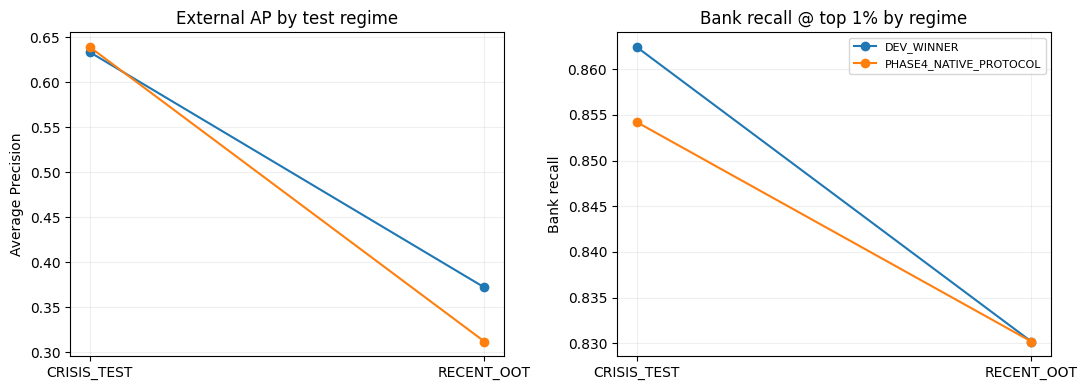

INTERPRETATION: compare within each regime; no retuning permitted.


In [437]:
# 5.4E — final held-out charts, only when actual external scores exist.
if isinstance(P5_TEST_SUMMARY,pd.DataFrame) and len(P5_TEST_SUMMARY):
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    for role,g in P5_TEST_SUMMARY.groupby('role'):
        g=g.set_index('split').reindex(['CRISIS_TEST','RECENT_OOT'])
        axes[0].plot(g.index,g.PR_AUC_AP,marker='o',label=role)
        axes[1].plot(g.index,g.bank_recall_top1pct,marker='o',label=role)
    axes[0].set(title='External AP by test regime',ylabel='Average Precision')
    axes[1].set(title='Bank recall @ top 1% by regime',ylabel='Bank recall')
    for a in axes:a.grid(alpha=.2)
    axes[1].legend(fontsize=8);plt.tight_layout();plt.show()
    print('INTERPRETATION: compare within each regime; no retuning permitted.')
else:print('No external results to plot, as expected in prepare/development mode.')

In [438]:
# 5.5A — global interpretation on train-derived artifacts; bounded test description if already unlocked.
P5_IMPORTANCE=pd.DataFrame();P5_ODDS=pd.DataFrame()
if P5_MODE=='development' and 'P5_FINAL_CHALLENGER' in globals():
    clf=P5_FINAL_CHALLENGER.named_steps['model']
    if hasattr(clf,'coef_'):
        indices=[P5_CORE_FIELDS.index(f) for f in P5_CHALLENGER_FIELDS]
        imp=P5_FINAL_CHALLENGER.named_steps['impute']
        original_names=list(P5_CHALLENGER_FIELDS)
        try:expanded_names=list(imp.get_feature_names_out(original_names))
        except Exception:expanded_names=original_names+[f'missing_indicator_{j}' for j in range(len(clf.coef_[0])-len(original_names))]
        beta=np.asarray(clf.coef_[0]);assert len(expanded_names)==len(beta)
        P5_ODDS=pd.DataFrame({'scaled_feature':expanded_names,'beta':beta,
                                'odds_ratio_per_scaled_unit':np.exp(np.clip(beta,-30,30))})
        display(P5_ODDS.reindex(P5_ODDS.beta.abs().sort_values(ascending=False).index).head(20))
        print('Odds ratio is per standardized transformed input, NOT causal or unit-raw effects.')
    # phase4 Booster gain importance is not feature causality.
    gain=np.asarray(P5_BOOSTER.feature_importance(importance_type='gain'))
    P5_IMPORTANCE=pd.DataFrame({'feature':P5_FINAL40,'gain':gain}).sort_values('gain',ascending=False)
    display(P5_IMPORTANCE.head(15))
else:
    print('Interpretation is available after development fit; no external data used to fit coefficients.')

Interpretation is available after development fit; no external data used to fit coefficients.


In [439]:
# 5.5A-RF — Feature importance của RF ưu tiên dữ liệu gần
if not P5_EXTERNAL_UNLOCKED:
    raise RuntimeError("Chạy thành công 5.4A trước.")

rf_pipe = P5_EXTERNAL_CHALLENGER
rf_model = rf_pipe.named_steps["model"]

if not isinstance(rf_model, RandomForestClassifier):
    raise TypeError("DEV_WINNER hiện tại không phải Random Forest.")

# Lấy cả tên các cột chỉ báo thiếu mà bước impute đã tạo.
features = rf_pipe.named_steps["impute"].get_feature_names_out(
    P5_FROZEN_SPEC["challenger_features"]
)

P5_RF_IMPORTANCE = pd.DataFrame({
    "feature": features,
    "importance": rf_model.feature_importances_,
}).sort_values("importance", ascending=False)

display(P5_RF_IMPORTANCE.head(15).round(5))

,feature,importance
18,RBC1AAJ,0.13651
17,RBCRWAJ,0.11204
24,equity_to_assets,0.10086
25,noncurrent_loan_ratio,0.08419
36,noncurrent_x_profitability,0.06810
38,expense_burden_x_profitability,0.06718
32,equity_to_assets_sq,0.06497
19,ROA,0.05646
26,roa_rolling_mean_4q,0.03647
27,roa_rolling_std_4q,0.02519


In [440]:
# 5.5B — bounded global and feature-group permutation importance (post-freeze, descriptive only).
P5_GROUP_IMPORTANCE=[]
def p5_group_permutation(X,y,group_indices,raw_score_fn,seed=4903,reps=3):
    rng=np.random.default_rng(seed)
    baseline=average_precision_score(y,raw_score_fn(X))
    out=[]
    for group,ids in group_indices.items():
        if not ids:continue
        changed=[]
        for _ in range(reps):
            src=np.asarray(X).copy()
            perm=rng.permutation(len(src))
            src[:,ids]=src[perm][:,ids]
            changed.append(baseline-average_precision_score(y,raw_score_fn(src)))
        out.append(dict(group=group,AP_drop_mean=float(np.mean(changed)),AP_drop_sd=float(np.std(changed)),
                        baseline_AP=float(baseline)))
    return pd.DataFrame(out)

if P5_EXTERNAL_UNLOCKED:
    # Descriptive interpretation ONLY; the external results may not be used for model changes.
    X,y,_meta=p5_read_external('CRISIS_TEST')
    rng=np.random.default_rng(P5_SEED)
    ids=np.sort(rng.choice(len(y),size=min(10000,len(y)),replace=False))
    xs=X[ids];ys=y[ids]
    if len(np.unique(ys))==2:
        ii={f:i for i,f in enumerate(P5_CORE_FIELDS)}
        selected=set(P5_FINAL40)
        groupdict={
            'Phase3_W1':[ii[f] for f in P5_W1_FIELDS if f in selected and f in ii],
            'Financial_interactions':[ii[f] for f in P5_FINAL40 if ('_x_' in f or f.endswith('_sq'))],
            'Other_core':[ii[f] for f in P5_FINAL40 if f not in set(P5_W1_FIELDS)
              and '_x_' not in f and not f.endswith('_sq')]
        }
        j=[ii[f] for f in P5_FINAL40]
        def raw_main_fn(arr):
            return np.asarray(P5_BOOSTER.predict(np.ascontiguousarray(arr[:,j]),num_threads=P5_N_JOBS),dtype=float)
        P5_GROUP_IMPORTANCE=p5_group_permutation(xs,ys,groupdict,raw_main_fn)
        display(P5_GROUP_IMPORTANCE)
    else:print('Skip permutation: bounded sample contains only one class.')
    del X,y,xs,ys;gc.collect()
else:print('Group permutation on external tests withheld until ONE-SHOT gate; no retuning permitted.')

,group,AP_drop_mean,AP_drop_sd,baseline_AP
0,Phase3_W1,0.311343,0.008096,0.594591
1,Financial_interactions,0.024453,0.017498,0.594591
2,Other_core,0.312324,0.020790,0.594591


In [441]:
# 5.5C — inspect cases (scored and frozen; identifiers only), plus guarded SHAP.
P5_CASES={}
if P5_EXTERNAL_PREDICTIONS:
    for (split,role),d in P5_EXTERNAL_PREDICTIONS.items():
        if role!='PHASE4_NATIVE_PROTOCOL':continue
        alerts,_=p5_quarterly_alerts(d,d.score,k=P5_FROZEN_SPEC['alert_policy']['capacity_per_quarter'])
        P5_CASES[split]={
            'detected_positive':alerts[(alerts.y==1)&(alerts.alert)].nlargest(10,'score'),
            'missed_positive':alerts[(alerts.y==1)&(~alerts.alert)].nlargest(10,'score'),
            'false_alerts':alerts[(alerts.y==0)&(alerts.alert)].nlargest(10,'score'),
        }
        print('\nCASE STUDIES:',split)
        for name,frame in P5_CASES[split].items():
            print(name,'count',len(frame));display(frame[['CERT','REPDTE','score','quarter_rank']].head(5))
    print('Cases are descriptive. Repeated rows for one CERT are NOT separate bank failure events.')
else:print('Cases available only after external evaluation.')

if P5_RUN_SHAP and P5_EXTERNAL_UNLOCKED:
    try:
        import shap
        X,y,_=p5_read_external('CRISIS_TEST')
        inds=np.random.default_rng(P5_SEED).choice(len(X),size=min(500,len(X)),replace=False)
        j=[P5_CORE_FIELDS.index(f) for f in P5_FINAL40]
        Xsub=np.ascontiguousarray(X[inds][:,j])
        explanation=shap.TreeExplainer(P5_BOOSTER)(Xsub)
        shap.summary_plot(explanation.values,Xsub,feature_names=P5_FINAL40,show=True)
        del X,Xsub,y;gc.collect()
    except (ImportError,ValueError,TypeError) as e:
        print('SHAP skipped:',str(e)[:240])
else:print('SHAP disabled by default; LightGBM Gain is already archived in Phase 4.')


CASE STUDIES: CRISIS_TEST
detected_positive count 10


,CERT,REPDTE,score,quarter_rank
9564,2119,2010-09-30,0.853628,1
150320,58336,2009-09-30,0.848873,1
141629,57563,2009-03-31,0.846620,1
145545,57959,2009-09-30,0.846141,2
142074,57604,2009-06-30,0.845295,1


missed_positive count 10


,CERT,REPDTE,score,quarter_rank
142514,57646,2010-03-31,0.698990,26
69239,16089,2010-03-31,0.698601,27
125011,34152,2010-03-31,0.691380,28
149933,58308,2010-03-31,0.689859,29
142954,57697,2010-03-31,0.687563,30


false_alerts count 10


,CERT,REPDTE,score,quarter_rank
147623,58135,2009-12-31,0.801455,4
21642,4879,2011-03-31,0.788382,3
84286,19498,2010-09-30,0.785089,7
21643,4879,2011-06-30,0.766992,2
120810,33111,2008-03-31,0.757615,1


... (3 outputs left out)

,CERT,REPDTE,score,quarter_rank
200304,32368,2014-03-31,0.148613,29
207155,34112,2014-09-30,0.098989,27
150524,20290,2014-09-30,0.086933,28
229636,57772,2014-06-30,0.071393,34
217738,35259,2014-12-31,0.068989,30


false_alerts count 10


,CERT,REPDTE,score,quarter_rank
14650,1802,2014-09-30,0.775130,1
216940,35187,2014-09-30,0.766660,2
227438,57564,2016-12-31,0.687885,2
105685,14361,2018-12-31,0.587950,1
105686,14361,2019-03-31,0.578145,1


Cases are descriptive. Repeated rows for one CERT are NOT separate bank failure events.
SHAP disabled by default; LightGBM Gain is already archived in Phase 4.


In [442]:
# 5.5D — predeclared robustness matrix; mark evidence status, do not fabricate studies.
P5_ROBUSTNESS_MATRIX=pd.DataFrame([
  {'experiment':'MAIN V3 vs ROBUSTNESS V3','protocol':'Same frozen model, filtered eligibility',
   'status':'AVAILABLE AFTER EXTERNAL' if P5_EXTERNAL_UNLOCKED else 'PENDING'},
  {'experiment':'V3 vs strict V2','protocol':'SHA-pinned Phase2 strict V2 label join, reporting-only sensitivity',
   'status':'OPTIONAL: verified V2 label + same frozen scores' if P5_PHASE2_LABEL_PATH else 'NOT EXECUTED: V2 source absent'},
  {'experiment':'45 vs 90 day reporting lag','protocol':'Proxy REPDTE+45/90 days, not true public timestamp',
   'status':'PROXY ONLY — requires release-vintage ledger'},
  {'experiment':'W1 vs extended predictors','protocol':'Train-only F1 ablation; never test-based re-selection',
   'status':'OPTIONAL DEVELOPMENT' if P5_MODE=='development' else 'NOT EXECUTED'},
  {'experiment':'With vs without interactions','protocol':'Train-only F1, same learner/rows',
   'status':'OPTIONAL DEVELOPMENT' if P5_MODE=='development' else 'NOT EXECUTED'},
  {'experiment':'Native vs median/mask','protocol':'Phase4 4.18B F1–F3 matched FDIC development',
   'status':'PREVIOUS PHASE4 RESULT; not repeated on external'},
  {'experiment':'Fixed threshold vs K=10/25/50','protocol':'Development freeze, descriptive external capacity comparison',
   'status':'AVAILABLE AFTER EXTERNAL' if P5_EXTERNAL_UNLOCKED else 'PENDING'},
  {'experiment':'Rolling-origin retraining','protocol':'F1–F4 expanding-window training',
   'status':'TRAIN CV COMPLETE' if isinstance(P5_BASELINE_RESULTS,pd.DataFrame) and len(P5_BASELINE_RESULTS) else 'PENDING'}
])
display(P5_ROBUSTNESS_MATRIX)
P5_ROBUSTNESS_MATRIX.to_csv(P5_OUTPUT/'robustness_matrix.csv',index=False)

,experiment,protocol,status
0,MAIN V3 vs ROBUSTNESS V3,"Same frozen model, filtered eligibility",AVAILABLE AFTER EXTERNAL
1,V3 vs strict V2,"SHA-pinned Phase2 strict V2 label join, report...",OPTIONAL: verified V2 label + same frozen scores
2,45 vs 90 day reporting lag,"Proxy REPDTE+45/90 days, not true public times...",PROXY ONLY — requires release-vintage ledger
3,W1 vs extended predictors,Train-only F1 ablation; never test-based re-se...,NOT EXECUTED
4,With vs without interactions,"Train-only F1, same learner/rows",NOT EXECUTED
5,Native vs median/mask,Phase4 4.18B F1–F3 matched FDIC development,PREVIOUS PHASE4 RESULT; not repeated on external
6,Fixed threshold vs K=10/25/50,"Development freeze, descriptive external capac...",AVAILABLE AFTER EXTERNAL
7,Rolling-origin retraining,F1–F4 expanding-window training,TRAIN CV COMPLETE


In [443]:
# 5.5E — Optional train-only W1 and interaction ablation — RF gần
P5_ABLATION_RESULTS=[]

if P5_RUN_ROBUSTNESS and P5_MODE=='development':
    fold=P5_FOLDS[0]  # F1 only: bounded robustness, not primary model selection
    Xtr,ytr,mtr,Xva,yva,mva=p5_fold_data(fold,'MAIN_V3')
    selected=P5_SELECTED_BY_FOLD['F1']

    groups={
      'W1_ONLY':[P5_CORE_FIELDS.index(f) for f in P5_W1_FIELDS if f in P5_CORE_FIELDS],
      'TOP40_NO_INTERACTIONS':[P5_CORE_FIELDS.index(f) for f in selected
         if '_x_' not in f and not f.endswith('_sq')],
      'TOP40_ALL':[P5_CORE_FIELDS.index(f) for f in selected],
    }

    for name,idxs in groups.items():
        if not idxs:
            print('SKIP:',name,'no matching feature group')
            continue

        print(f'RF gần | Đang fit {name} | {len(idxs)} features...',flush=True)

        model=rf_strategy_fit(
            Xtr,
            np.asarray(ytr).ravel(),
            np.asarray(mtr['CERT']),
            pd.DatetimeIndex(pd.to_datetime(mtr['REPDTE'])),
            idxs,
            by_cert=False,
            by_recency=True
        )

        score=model.predict_proba(Xva)[:,list(model.classes_).index(1)]

        P5_ABLATION_RESULTS.append({
            'variant':name,
            'n_features':len(idxs),
            **p5_metric(yva,score,mva['CERT'])
        })

    P5_ABLATION_RESULTS=pd.DataFrame(P5_ABLATION_RESULTS)

    display(P5_ABLATION_RESULTS[
        ['variant','n_features','PR_AUC_AP','bank_recall_top1pct']
    ])

    del Xtr,Xva,ytr,yva,mtr,mva
    gc.collect()

else:
    print('Train-only ablation off by default (P5_RUN_ROBUSTNESS=False).')


# Robustness V3: same frozen scorer, no retraining or test-driven decisions.
P5_ROBUST_SUBSET_SCORECARDS=[]

if P5_RUN_ROBUSTNESS and P5_EXTERNAL_UNLOCKED:
    for split in ('CRISIS_TEST','RECENT_OOT'):
        X,y,m=p5_read_external(split,'ROBUSTNESS_V3')

        for role,score in p5_score_external(X,calibrate=False).items():
            cut=P5_FROZEN_SPEC['alert_policy']['threshold_by_role'][role]
            calibrated=p5_calibration_apply(P5_EXTERNAL_CAL[role],score)

            P5_ROBUST_SUBSET_SCORECARDS.append({
                'split':split,
                'role':role,
                'population':'ROBUSTNESS_V3',
                'threshold_raw':cut,
                'Brier_calibrated':float(brier_score_loss(y,calibrated)),
                **p5_metric(y,score,m['CERT'],threshold=float(cut))
            })

        del X,y,m
        gc.collect()

    P5_ROBUST_SUBSET_SCORECARDS=pd.DataFrame(P5_ROBUST_SUBSET_SCORECARDS)
    display(P5_ROBUST_SUBSET_SCORECARDS.round(4))

    P5_ROBUST_SUBSET_SCORECARDS.to_csv(
        P5_OUTPUT/'robustness_v3_scorecards.csv',index=False
    )

Train-only ablation off by default (P5_RUN_ROBUSTNESS=False).


In [444]:
# 5.6A — model card + reproducibility manifest, never overwrite frozen spec.

P5_MODEL_CARD_PATH = P5_OUTPUT / 'model_card_phase5.md'
P5_REPORT_PATH = P5_OUTPUT / 'phase5_final_report.md'

lines = [
    '# Phase 5 Model Card — FDIC Failure EWS (V3)',
    '', '## Task and population',
    '- Prediction: bank-quarter probability of FDIC-confirmed failure in the next 4 quarters.',
    '- Key: CERT, REPDTE; target: y_failure_4q_v3; eligibility: MODEL_ELIGIBLE_V3.',
    '- Alternative robustness: ROBUSTNESS_ELIGIBLE_V3 subset; not a new target.',
    '- TRAIN: 1985–2006; CRISIS_TEST: 2008–2012; RECENT_OOT: 2014Q1–2025Q2.',
    '- Outcome observation cutoff: 2026Q2.',
    '- Internal chronological F1–F4 with full-year purge between training and validation.',

    '', '## Frozen Phase 4 reference model',
    '- Original Phase 4 LightGBM Native Top 40; no new main feature selection from test.',
    '- SHA256: ' + P5_MODEL_SHA,
    '- Model path: ' + str(P5_MODEL_PATH),
    '- Features (ordered): ' + ', '.join(P5_FINAL40),

    '', '## Selected Random Forest strategy',
    '- Selected strategy: Recency-weighted Random Forest Top 40.',
    '- Reference configuration: RF T2.',
    f'- Recency weighting half-life: {RF_HALF_LIFE_YEARS} years.',
    '- Recency weighting: enabled.',
    '- CERT weighting: disabled.',
    '- Temporal weights are computed using training observations only.',
    '- Model selection is based on chronological validation F1–F4.',
    '- Primary selection metric: bank recall at Top 25 per quarter.',
    '- Full TRAIN performance is treated as in-sample diagnostic evidence only.',

    '', '## Methodology',
    '- Train-fold-only feature gain selection for development CV.',
    '- Logistic preprocessing: median imputation with missing indicator + standard scaling inside pipeline.',
    '- Nonlinear baselines: RandomForest, ExtraTrees, iterative weighted RF, HistGradientBoosting, LightGBM; optional XGBoost/CatBoost.',
    '- Iterative RF uses feature duplication for iterative weighted sampling; RIT interaction stability is not implemented.',
    '- Random Forest strategy comparison includes fixed, recency-weighted, CERT-weighted, walk-forward and combined strategies.',
    '- OOF calibration transfer; separate development-only raw-score cut per model (full PR sweep).',

    '', '## Known limitations',
    '- REPDTE is financial quarter-end; availability dates are not actual public release timestamps.',
    '- Label-positive quarters of same bank are dependent; bank and event proxy reporting used.',
    '- No independent event date in engineered Gold: true warning lead-time unavailable.',
    '- V2 strict robustness requires a new SHA-pinned label source; no automatic fallback.',
    '- Calibration transport from historical fold models to full TRAIN scorer may drift.',
    '- Recency weighting may reduce the influence of older banking crisis observations.',
    '- Real-time inference requires original Phase 4 feature computation and vintage safeguards.',
    '- Revised external evaluation is supplementary because the test windows were previously accessed.',

    '', '## Test status',
    'External unlocked: ' + str(bool(P5_EXTERNAL_UNLOCKED)),
]

if P5_FROZEN_SPEC_PATH.is_file():
    lines += [
        'Frozen Phase5 spec: ' + str(P5_FROZEN_SPEC_PATH),
        'Spec file SHA256: ' + p5_sha256_file(P5_FROZEN_SPEC_PATH)
    ]

if isinstance(P5_TEST_SUMMARY, pd.DataFrame) and len(P5_TEST_SUMMARY):
    lines += [
        '',
        '## Actual external test scorecards',
        '```text',
        P5_TEST_SUMMARY.round(5).to_string(index=False),
        '```',
    ]
else:
    lines += [
        '',
        'External scorecards: NOT RUN (no numerical estimates asserted).'
    ]

if globals().get("P5_RF_STRATEGY_WINNER") is not None:
    lines += [
        "",
        "## So sánh các chiến lược Random Forest trên validation F1–F4",
        f"- Chiến lược đứng đầu: **{P5_RF_STRATEGY_WINNER}**.",
        "- Xếp hạng theo bank recall ở Top 25 mỗi quý, AP trung bình "
        "và recall của fold yếu nhất.",
        "",
        "```text",
        P5_RF_STRATEGY_SUMMARY.round(5).to_string(index=False),
        "```",
    ]

if isinstance(globals().get("P5_RF_BOOTSTRAP_SUMMARY"), pd.DataFrame):
    lines += [
        "",
        "## Statistical comparison of RF strategies",
        "- Paired Moving Block Bootstrap on validation F1–F4.",
        "- Primary metric: Bank Recall@25.",
        "- Positive differences favor the recency-weighted Random Forest.",
        "",
        "```text",
        P5_RF_BOOTSTRAP_SUMMARY.round(5).to_string(index=False),
        "```",
    ]

P5_MODEL_CARD_PATH.write_text('\n'.join(lines), encoding='utf-8')

print('Model card:', P5_MODEL_CARD_PATH)

Model card: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase5_v3\phase5_refit_20261125T153506999665Z\external_recheck_be8f1b5c\model_card_phase5.md


### 5.6A-REPRO — Reproducibility Readiness Audit

**Problem:** Reproducibility requires consistent source
artifacts, upstream handoffs, model specifications
and software dependencies.

**Methodology:** Perform a read-only inventory of existing
artifacts, verify recorded model and metadata digests,
and document the current software environment.

This audit assesses reproducibility readiness rather than
claiming successful end-to-end pipeline reproduction.

No model retraining or external test evaluation is performed.

In [462]:
# 5.6A-REPRO — Read-only reproducibility audit

assert "P5_ROOT" in globals()
assert "P5_MODEL_PATH" in globals()
assert "P5_META_PATH" in globals()
assert "p5_sha256_file" in globals()

REPRO_ROOT = Path(P5_ROOT)

REPRO_ROWS = []


# --------------------------------------------------
# A. Artifact verification helper
# --------------------------------------------------

def repro_check(name, path, expected_sha=None):

    if path is None:

        return {
            "artifact": name,
            "exists": False,
            "size_MB": np.nan,
            "hash_expected": False,
            "status": "PATH_UNAVAILABLE"
        }

    path = Path(path)

    result = {
        "artifact": name,
        "exists": path.is_file(),
        "size_MB": (
            path.stat().st_size / 1e6
            if path.is_file() else np.nan
        ),
        "hash_expected": bool(expected_sha),
        "path": str(path)
    }

    if not path.is_file():

        result["status"] = "MISSING"

    elif expected_sha:

        actual_sha = p5_sha256_file(path)

        result["status"] = (
            "SHA256_PASS"
            if actual_sha == expected_sha
            else "SHA256_MISMATCH"
        )

    else:

        result["status"] = "PRESENT_ONLY"

    return result


# --------------------------------------------------
# B. Phase 0 and upstream handoffs
# --------------------------------------------------

for name, relative_path in [

    (
        "Phase 0 field handoff",
        "docs/phase0_phase1_field_handoff_v2.json"
    ),
    (
        "Phase 0 data scope",
        "docs/phase0_data_scope_contract.json"
    ),
    (
        "Phase 0 bundle manifest",
        "docs/phase0_artifact_bundle_manifest.json"
    ),
    (
        "FDIC financial schema",
        "docs/fdic_financial_schema.yaml"
    )
]:

    REPRO_ROWS.append(
        repro_check(
            name,
            REPRO_ROOT / relative_path
        )
    )


# --------------------------------------------------
# C. Phase 2 label artifact
# --------------------------------------------------

REPRO_ROWS.append(
    repro_check(
        "Phase 2 V3 labels",
        globals().get("P5_PHASE2_LABEL_PATH"),
        globals().get("P5_PHASE2_LABEL_SHA")
    )
)


# --------------------------------------------------
# D. Locate existing frozen specification
# --------------------------------------------------

REPRO_SPEC_PATH = globals().get(
    "P5_FROZEN_SPEC_PATH"
)

REPRO_SPEC = globals().get(
    "P5_FROZEN_SPEC"
)

if (
    REPRO_SPEC_PATH is not None
    and Path(REPRO_SPEC_PATH).is_file()
):

    REPRO_SPEC = json.loads(
        Path(REPRO_SPEC_PATH).read_text(
            encoding="utf-8"
        )
    )

REPRO_SPEC = REPRO_SPEC or {}

REPRO_ROWS.append(
    repro_check(
        "Phase 5 frozen specification",
        REPRO_SPEC_PATH
    )
)


# --------------------------------------------------
# E. Verify existing model artifacts
# --------------------------------------------------

REPRO_ROWS.append(
    repro_check(
        "Phase 4 LightGBM model",
        P5_MODEL_PATH,
        REPRO_SPEC.get(
            "main_model_sha256",
            globals().get("P5_MODEL_SHA")
        )
    )
)

REPRO_ROWS.append(
    repro_check(
        "Phase 4 model metadata",
        P5_META_PATH,
        REPRO_SPEC.get(
            "phase4_metadata_sha256"
        )
    )
)

REPRO_ROWS.append(
    repro_check(
        "Phase 5 recency-weighted RF",
        REPRO_SPEC.get(
            "challenger_path",
            globals().get("P5_CHALLENGER_PATH")
        ),
        REPRO_SPEC.get(
            "challenger_sha256"
        )
    )
)


# --------------------------------------------------
# F. Calibration artifacts
# --------------------------------------------------

for role, info in REPRO_SPEC.get(
    "calibrators", {}
).items():

    REPRO_ROWS.append(
        repro_check(
            f"Calibrator: {role}",
            info.get("path"),
            info.get("sha256")
        )
    )


# --------------------------------------------------
# G. Artifact inventory
# --------------------------------------------------

P5_REPRO_ARTIFACTS = pd.DataFrame(
    REPRO_ROWS
)

print("TABLE 1 — ARTIFACT INVENTORY")

display(
    P5_REPRO_ARTIFACTS[[
        "artifact",
        "exists",
        "size_MB",
        "hash_expected",
        "status"
    ]].style.format({
        "size_MB": "{:,.3f}"
    })
)


# --------------------------------------------------
# H. Frozen specification digest
# --------------------------------------------------

REPRO_SPEC_STATUS = "NOT_VERIFIABLE"

if REPRO_SPEC and "p5_digest" in globals():

    spec_body = REPRO_SPEC.copy()

    expected_digest = spec_body.pop(
        "spec_sha256", None
    )

    if expected_digest:

        actual_digest = p5_digest(
            spec_body
        )

        REPRO_SPEC_STATUS = (
            "PASS"
            if actual_digest == expected_digest
            else "MISMATCH"
        )


# --------------------------------------------------
# I. Gold schema audit — metadata only
# --------------------------------------------------

REPRO_GOLD_STATUS = "NOT_AVAILABLE"

REPRO_GOLD_SCHEMA = set()

if "P5_GOLD" in globals():

    REPRO_GOLD_SCHEMA = set(
        P5_GOLD.collect_schema().names()
    )

    required = {
        "CERT",
        "REPDTE",
        "__split",
        "y_failure_4q_v3",
        "MODEL_ELIGIBLE_V3",
        "ROBUSTNESS_ELIGIBLE_V3"
    }

    required.update(
        globals().get("P5_CORE_FIELDS", [])
    )

    missing = required - REPRO_GOLD_SCHEMA

    REPRO_GOLD_STATUS = (
        "PASS" if not missing
        else "MISSING_FIELDS"
    )

    print("\nGold schema columns:", len(REPRO_GOLD_SCHEMA))
    print("Missing required fields:", sorted(missing))


# --------------------------------------------------
# J. Software environment
# --------------------------------------------------

P5_REPRO_ENV = pd.DataFrame([
    {
        "dependency": "Pandas",
        "version": pd.__version__
    },
    {
        "dependency": "NumPy",
        "version": np.__version__
    },
    {
        "dependency": "Polars",
        "version": pl.__version__
    },
    {
        "dependency": "Python",
        "version": (
            platform.python_version()
            if "platform" in globals()
            else "Not available in current namespace"
        )
    },
    {
        "dependency": "Random seed",
        "version": globals().get(
            "P5_SEED", "Unknown"
        )
    },
    {
        "dependency": "Parallel jobs",
        "version": globals().get(
            "P5_N_JOBS", "Unknown"
        )
    }
])

print("\nTABLE 2 — SOFTWARE ENVIRONMENT")

display(P5_REPRO_ENV)


# --------------------------------------------------
# K. Reproducibility evidence boundary
# --------------------------------------------------

P5_REPRO_READINESS = pd.DataFrame([
    {
        "verification": "Frozen specification digest",
        "status": REPRO_SPEC_STATUS
    },
    {
        "verification": "Gold schema contract",
        "status": REPRO_GOLD_STATUS
    },
    {
        "verification": "Gold content re-verification",
        "status": "NOT RUN — metadata only"
    },
    {
        "verification": "Source page-level provenance",
        "status": "INCOMPLETE — Phase 1 audit"
    },
    {
        "verification": "Clean environment installation",
        "status": "NOT RUN"
    },
    {
        "verification": "End-to-end pipeline reproduction",
        "status": "NOT RUN"
    },
    {
        "verification": "External prediction evaluation",
        "status": "NOT RUN"
    }
])

print("\nTABLE 3 — REPRODUCIBILITY READINESS")

display(P5_REPRO_READINESS)


# --------------------------------------------------
# L. Overall audit summary
# --------------------------------------------------

P5_REPRO_SUMMARY = (
    P5_REPRO_ARTIFACTS["status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="artifacts")
)

print("\nTABLE 4 — ARTIFACT VERIFICATION SUMMARY")

display(P5_REPRO_SUMMARY)

print("\nARTIFACTS REQUIRING ATTENTION")

display(
    P5_REPRO_ARTIFACTS.loc[
        ~P5_REPRO_ARTIFACTS["status"].isin([
            "SHA256_PASS",
            "PRESENT_ONLY"
        ])
    ]
)

print("\n" + "=" * 65)
print("REPRODUCIBILITY AUDIT — SUMMARY")
print("=" * 65)

print("Artifacts checked   :", len(P5_REPRO_ARTIFACTS))
print("SHA-256 passed      :", int(
    P5_REPRO_ARTIFACTS["status"]
    .eq("SHA256_PASS").sum()
))
print("Frozen spec digest  :", REPRO_SPEC_STATUS)
print("Gold schema         :", REPRO_GOLD_STATUS)
print("Pipeline rerun      : NO")
print("Model retrained     : NO")
print("Test rows collected : NO")
print("Test inference      : NO")
print("Artifacts modified  : NO")
print("Files created       : NO")

TABLE 1 — ARTIFACT INVENTORY


,artifact,exists,size_MB,hash_expected,status
0,Phase 0 field handoff,True,0.004,False,PRESENT_ONLY
1,Phase 0 data scope,True,0.002,False,PRESENT_ONLY
2,Phase 0 bundle manifest,True,0.002,False,PRESENT_ONLY
3,FDIC financial schema,True,0.617,False,PRESENT_ONLY
4,Phase 2 V3 labels,True,1.168,True,SHA256_PASS
5,Phase 5 frozen specification,True,0.006,False,PRESENT_ONLY
6,Phase 4 LightGBM model,True,0.222,True,SHA256_PASS
7,Phase 4 model metadata,True,0.002,True,SHA256_PASS
8,Phase 5 recency-weighted RF,True,18.223,True,SHA256_PASS
9,Calibrator: PHASE4_NATIVE_PROTOCOL,True,0.000,True,SHA256_PASS



Gold schema columns: 126
Missing required fields: []

TABLE 2 — SOFTWARE ENVIRONMENT


,dependency,version
0,Pandas,2.3.3
1,NumPy,2.3.3
2,Polars,2.1.0
3,Python,3.13.7
4,Random seed,4903
5,Parallel jobs,2



TABLE 3 — REPRODUCIBILITY READINESS


,verification,status
0,Frozen specification digest,PASS
1,Gold schema contract,PASS
2,Gold content re-verification,NOT RUN — metadata only
3,Source page-level provenance,INCOMPLETE — Phase 1 audit
4,Clean environment installation,NOT RUN
5,End-to-end pipeline reproduction,NOT RUN
6,External prediction evaluation,NOT RUN



TABLE 4 — ARTIFACT VERIFICATION SUMMARY


,status,artifacts
0,SHA256_PASS,6
1,PRESENT_ONLY,5



ARTIFACTS REQUIRING ATTENTION


,artifact,exists,size_MB,hash_expected,path,status



REPRODUCIBILITY AUDIT — SUMMARY
Artifacts checked   : 11
SHA-256 passed      : 6
Frozen spec digest  : PASS
Gold schema         : PASS
Pipeline rerun      : NO
Model retrained     : NO
Test rows collected : NO
Test inference      : NO
Artifacts modified  : NO
Files created       : NO


In [463]:
# 5.6A-REPRO-ENV — Dependency version audit

metadata = __import__("importlib.metadata", fromlist=["version"])

packages = [
    "pandas",
    "numpy",
    "polars",
    "scikit-learn",
    "lightgbm",
    "pyarrow",
    "joblib",
    "scipy",
    "matplotlib",
    "psutil",
    "pyspark"
]

rows = []

for package in packages:

    try:
        version = metadata.version(package)
        status = "INSTALLED"

    except metadata.PackageNotFoundError:
        version = None
        status = "NOT INSTALLED"

    rows.append({
        "dependency": package,
        "installed_version": version,
        "status": status
    })

P5_DEPENDENCY_AUDIT = pd.DataFrame(rows)

print("DEPENDENCY VERSION AUDIT")
display(P5_DEPENDENCY_AUDIT)

print("\nAvailable requirements files:")

requirement_files = sorted(
    list(Path(P5_ROOT).glob("requirements*.txt"))
    + list(Path(P5_ROOT).glob("docs/requirements*.txt"))
)

for path in requirement_files:
    print("\n" + "=" * 60)
    print(path.name)
    print("=" * 60)
    print(path.read_text(encoding="utf-8"))

if not requirement_files:
    print("No requirements files found in checked locations.")

print("\nPackages checked:", len(packages))
print("Model retrained: NO")
print("External test accessed: NO")
print("Packages installed: NO")
print("Files created: NO")

DEPENDENCY VERSION AUDIT


,dependency,installed_version,status
0,pandas,2.3.3,INSTALLED
1,numpy,2.3.3,INSTALLED
2,polars,2.1.0,INSTALLED
3,scikit-learn,1.9.0,INSTALLED
4,lightgbm,4.7.0,INSTALLED
5,pyarrow,26.0.1,INSTALLED
6,joblib,1.5.2,INSTALLED
7,scipy,1.16.3,INSTALLED
8,matplotlib,3.10.7,INSTALLED
9,psutil,7.0.0,INSTALLED



Available requirements files:
No requirements files found in checked locations.

Packages checked: 11
Model retrained: NO
External test accessed: NO
Packages installed: NO
Files created: NO


#### Interpretation 5.6A-REPRO — Reproducibility Readiness

All 11 audited artifacts are available, with six
reference SHA-256 checks passing successfully.
The frozen specification and Gold schema also pass.

All 11 audited dependencies are installed, and their
exact versions are documented.

However, a requirements file was not located in the
checked directories. Clean-environment installation
and end-to-end reproduction remain unverified.

The audit supports artifact integrity and reproducibility
readiness without model retraining or external test access.

In [445]:
# 5.6B — reproducible inference on a Phase4-engineered *new* bank-quarter table.
def p5_infer_engineered(engineered,asof_date,report_delay_days=45,
                        top_k=25,require_actual_release=False,
                        model_role='PHASE4_NATIVE_PROTOCOL'):
    """Requires Phase4-engineered features; does NOT construct them from raw data."""
    if require_actual_release:
        raise RuntimeError('Actual release timestamps unavailable; REPDTE+delay is only a proxy.')
    assert top_k>=1 and report_delay_days in (45,90)
    assert model_role in ('PHASE4_NATIVE_PROTOCOL','DEV_WINNER')
    spec=None
    if P5_FROZEN_SPEC_PATH.is_file():
        spec=json.loads(P5_FROZEN_SPEC_PATH.read_text(encoding='utf-8-sig'))
        assert p5_digest({k:v for k,v in spec.items() if k!='spec_sha256'})==spec['spec_sha256']
    if model_role=='DEV_WINNER' and spec is None:
        raise RuntimeError('Frozen challenger specification required.')
    features=P5_FINAL40 if model_role=='PHASE4_NATIVE_PROTOCOL' else P5_CORE_FIELDS
    assert all(f in engineered.columns for f in features)
    assert {'CERT','REPDTE'}.issubset(engineered.columns)
    df=engineered.copy()
    df['REPDTE']=pd.to_datetime(df['REPDTE'])
    assert not df[['CERT','REPDTE']].duplicated().any()
    asof=pd.Timestamp(asof_date)
    df=df.loc[(df.REPDTE+pd.to_timedelta(report_delay_days,unit='D'))<=asof].copy()
    assert len(df),'No reports are assumed available as of selected date.'
    df=df.sort_values(['CERT','REPDTE'],kind='stable').groupby('CERT',as_index=False).tail(1)
    X=df[features].apply(pd.to_numeric,errors='coerce').to_numpy(dtype=np.float32)
    X[~np.isfinite(X)]=np.nan
    if model_role=='PHASE4_NATIVE_PROTOCOL':
        risk=np.asarray(P5_BOOSTER.predict(np.ascontiguousarray(X),num_threads=P5_N_JOBS),dtype=float)
    else:
        assert p5_sha256_file(spec['challenger_path'])==spec['challenger_sha256']
        challenger=joblib.load(spec['challenger_path'])  # Trust only the SHA-pinned local artifact.
        risk=np.asarray(challenger.predict_proba(X)[:,1],dtype=float)
    df['model_role']=model_role
    df['risk_raw']=risk
    df['alert_fixed_threshold']=pd.NA
    if spec is not None:
        calinfo=spec['calibrators'][model_role]
        assert p5_sha256_file(calinfo['path'])==calinfo['sha256']
        cal=json.loads(Path(calinfo['path']).read_text(encoding='utf-8'))
        df['risk_calibrated']=p5_calibration_apply(cal,risk)
        df['alert_fixed_threshold']=risk>=float(spec['alert_policy']['threshold_by_role'][model_role])
    else:df['risk_calibrated']=np.nan
    df=df.sort_values(['risk_raw','CERT'],ascending=[False,True],kind='stable')
    df['alert_rank']=np.arange(1,len(df)+1)
    df['alert']=df.alert_rank<=top_k
    df['date_assumption']=f'Quarter-end plus {report_delay_days} calendar days (proxy)'
    return df[['CERT','REPDTE','model_role','risk_raw','risk_calibrated',
               'alert_rank','alert','alert_fixed_threshold','date_assumption']]

print('Inference function ready (Phase4-engineered data required).')

Inference function ready (Phase4-engineered data required).


In [446]:
# 5.6C — drift/missingness monitor based on TRAIN reference; no tuning on external.
def p5_train_psi(ref_values,new_values,bins=10):
    a=np.asarray(ref_values,dtype=float);b=np.asarray(new_values,dtype=float)
    amiss=float(np.mean(~np.isfinite(a)));bmiss=float(np.mean(~np.isfinite(b)))
    a=a[np.isfinite(a)];b=b[np.isfinite(b)]
    if len(a)<10 or len(b)<10:
        return {'PSI':np.nan,'ref_missing':amiss,'new_missing':bmiss,'warning':'Too few finite values'}
    cuts=np.unique(np.quantile(a,np.linspace(0,1,bins+1))[1:-1])
    ra=np.histogram(a,bins=np.r_[-np.inf,cuts,np.inf])[0].astype(float)
    rb=np.histogram(b,bins=np.r_[-np.inf,cuts,np.inf])[0].astype(float)
    pa=np.r_[ra/len(a)*(1-amiss),amiss]
    pb=np.r_[rb/len(b)*(1-bmiss),bmiss]
    eps=1e-6;pa=np.maximum(pa,eps);pb=np.maximum(pb,eps)
    val=float(np.sum((pb-pa)*np.log(pb/pa)))
    return {'PSI':val,'ref_missing':amiss,'new_missing':bmiss,
            'warning':'PSI is descriptive; feature definition/release-regime changes may dominate.'}

assert p5_train_psi([1,2,3,4,5,6,7,8,9,10],[1,2,3,4,5,6,7,8,9,10])['PSI']<1e-5
print('PASS — PSI fixed-reference-bin monitor synthetic check.')

PASS — PSI fixed-reference-bin monitor synthetic check.


In [447]:
# 5.6D — Final report, with NO fabricated external results.

report = [
    '# PHASE 5 — Final Report / Handoff to Deployment',
    '',
    '## 1. Modeling Contract',
    f'- Target: `{P5_Y}` (FDIC-confirmed failure within four following quarters).',
    '- Source: Phase4-native Gold with Phase2 V3 eligibility masks.',
    '- Internal folds: F1–F4 expanding train with purge. Main & Robustness kept separate.',
    '- Main frozen incumbent: Phase4 Native LightGBM Top40.',
    '- Selected RF strategy: Recency-weighted Random Forest Top40.',
    f'- Recency weighting half-life: {RF_HALF_LIFE_YEARS} years.',
    '- Gold source: ' + P5_SOURCE_MODE,
    '- Gold checksum: ' + str(
        P5_GOLD_SHA256 or
        'NOT MATERIALIZED — in-memory Phase 4 lineage only'
    ),
    '- Phase4 model SHA: ' + P5_MODEL_SHA,
    '',
    '## 2. Development Model Comparison',
]

if len(P5_RANKING):
    report += [
        '- Initial development model comparison:',
        '- Initial ranking criterion: bank-support-weighted AP − 0.15 × weighted SD; bank recall as secondary.',
        P5_RANKING.head(10).round(5).to_markdown(index=False),
    ]
else:
    report += [
        '- NOT EXECUTED: prepare mode; no new fitted models claimed.'
    ]

report += ['', '### 2.1. Random Forest Strategy Comparison']

if (
    isinstance(globals().get('P5_RF_STRATEGY_SUMMARY'), pd.DataFrame)
    and len(P5_RF_STRATEGY_SUMMARY)
):
    report += [
        '- Final RF strategy criterion: Bank Recall@25 across validation F1–F4.',
        '- Supporting metrics: Mean AP, worst-fold recall and false alerts.',
        P5_RF_STRATEGY_SUMMARY.round(5).to_markdown(index=False),
    ]
else:
    report += ['- NOT EXECUTED: RF strategy comparison unavailable.']

report += ['', '### 2.2. Statistical Comparison of RF Strategies']

if (
    isinstance(globals().get('P5_RF_BOOTSTRAP_SUMMARY'), pd.DataFrame)
    and len(P5_RF_BOOTSTRAP_SUMMARY)
):
    report += [
        '- Method: Paired Moving Block Bootstrap on validation OOF predictions.',
        '- Primary metric: Bank Recall@25.',
        '- Positive differences favour recency-weighted RF.',
        P5_RF_BOOTSTRAP_SUMMARY.round(5).to_markdown(index=False),
    ]

    primary = P5_RF_BOOTSTRAP_SUMMARY.loc[
        P5_RF_BOOTSTRAP_SUMMARY['metric'].eq('Bank_Recall_pp')
    ]

    if len(primary):
        primary = primary.iloc[0]

        report += [
            f"- Observed improvement: {primary['observed_difference']:+.4f} percentage points.",
            f"- 95% CI: [{primary['CI_95_lower']:+.4f}, "
            f"{primary['CI_95_upper']:+.4f}] percentage points.",
        ]

        if primary['CI_95_lower'] > 0:
            report += [
                '- Bootstrap evidence supports recency-weighted RF on validation.'
            ]
        elif primary['CI_95_upper'] < 0:
            report += [
                '- Bootstrap evidence supports fixed RF T2 on validation.'
            ]
        else:
            report += [
                '- Insufficient statistical evidence of a difference in Bank Recall@25.'
            ]
else:
    report += ['- NOT EXECUTED: bootstrap results unavailable.']

report += ['', '### 2.3. CAMELS 9 vs Top 40 Feature Ablation']

if (
    isinstance(globals().get('P5_RF_RECENCY_CAMELS9_VAL_SUMMARY'), pd.DataFrame)
    and len(P5_RF_RECENCY_CAMELS9_VAL_SUMMARY)
):
    report += [
        '- Both models use the same recency-weighted RF strategy.',
        '- Feature comparison: CAMELS 9 versus fold-specific Top 40.',
        P5_RF_RECENCY_CAMELS9_VAL_SUMMARY.round(5).to_markdown(),
    ]
else:
    report += ['- NOT EXECUTED: feature ablation results unavailable.']

report += [
    '',
    '### 2.4. Final Model Selection',
    '- Development-selected challenger: `' + str(P5_DEV_WINNER) + '`.',
    '- Selected strategy: Recency-weighted Random Forest Top40.',
    '- Selection prioritises out-of-fold validation performance rather than in-sample TRAIN performance.',
    '- External test performance is not used for model selection.',
]

report += ['', '## 3. Calibration and Alert Policy']

if P5_ALERT_POLICY['threshold_by_role']:
    report += [
        '- Frozen raw-score thresholds by protocol (development only): '
        + str(P5_ALERT_POLICY['threshold_by_role']),
        '- Quarterly capacity: Top 10, 25, 50; operational K=25 chosen in advance.',
        '- Full PR sweep on F1–F3; independent historical F4 threshold diagnostic.',
        '- Fit: OOF development only; final-model transfer is an acknowledged limitation.',
    ]
else:
    report += [
        '- NOT FITTED: no standalone calibration/threshold claims.'
    ]

report += [
    '',
    '## 4. External Tests',
    '- Primary crisis: 2008Q1–2012Q4.',
    '- Secondary recent OOT: 2014Q1–2025Q2 (required cutoff).',
    '- Outcome observation cutoff: 2026Q2.',
    '- Recent OOT requires fully matured four-quarter outcome horizons.',
    '- Evaluation of the revised RF strategy is supplementary because the external datasets were previously accessed.',
]

if isinstance(P5_TEST_SUMMARY, pd.DataFrame) and len(P5_TEST_SUMMARY):
    report += [
        '- Available external scorecard; verify model version and cutoff against the current frozen release.',
        P5_TEST_SUMMARY.round(5).to_markdown(index=False),
    ]
else:
    report += [
        '- NOT EXECUTED: tests remained locked; do not report performance figures.'
    ]

report += [
    '',
    '## 5. Limitations & Research Conclusions',
    '- Cross-temporal support is highly unequal; report positive banks, not only positive quarters.',
    '- Recency weighting may reduce the influence of older banking regimes.',
    '- Bootstrap intervals reflect uncertainty conditional on existing OOF predictions, not model refitting uncertainty.',
    '- In-sample TRAIN performance does not establish generalisation superiority.',
    '- Time-to-failure cannot be measured from a 4Q binary target alone without actual event dates.',
    '- Quarter-end reporting lag estimates (45/90d) are proxy assumptions, not evidence of filing vintage.',
    '- Robustness V3 is a subset; strict V2 requires independent SHA-verified target assembly.',
    '- External comparisons are reporting-only and cannot be used for selection or repeated retuning.',
    '- Native Phase4 checkpoint and original sources are never overwritten by Phase5.',
    '',
    '## 6. Next Step',
    '- Reproduce all artifacts from pinned inputs; attach actual release timestamps and event dates.',
    '- Deploy the frozen recency-weighted RF policy only after release verification.',
    '- Monitor PSI, missingness, score drift, alert volume and calibration.',
]

P5_REPORT_PATH.write_text(
    '\n\n'.join(report),
    encoding='utf-8'
)

print('PHASE 5 FINAL REPORT:', P5_REPORT_PATH)

print(
    'STATUS:',
    'EXTERNAL SCORECARDS AVAILABLE'
    if P5_EXTERNAL_PREDICTIONS else
    'NO EXTERNAL TEST RESULTS — correctly locked in prepare/development mode'
)

PHASE 5 FINAL REPORT: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase5_v3\phase5_refit_20261125T153506999665Z\external_recheck_be8f1b5c\phase5_final_report.md
STATUS: EXTERNAL SCORECARDS AVAILABLE


In [448]:
# 5.7 — show model comparison and actual threshold trade-offs in one place.
if P5_MODE=='development' and isinstance(P5_RANKING,pd.DataFrame) and len(P5_RANKING):
    print('=== PHASE 5: DEVELOPMENT (TRAIN CV, không phải external test) ===')
    display(P5_RANKING[['run_id','raw_mean_AP','weighted_mean_AP','min_AP',
                        'mean_bank_recall','stability_adjusted_AP']].head(12).round(5))
    print('Ngưỡng và số cảnh báo từ F1–F3:')
    display(P5_THRESHOLD_TABLE[['score_protocol','rule','threshold','precision',
                                'recall','alert_rate','false_alerts']].round(5))
    print('Áp ngưỡng đã chọn lên F4 lịch sử:')
    display(P5_THRESHOLD_MONITOR.round(5))
    fig,ax=plt.subplots(figsize=(8,5))
    for role,oof in P5_DEV_OOF.items():
        d=oof[oof.fold.isin(['F1','F2','F3'])]
        prec,rec,_=precision_recall_curve(d.y,d.score)
        ap=average_precision_score(d.y,d.score)
        ax.plot(rec,prec,label=f'{role}: AP={ap:.3f}')
    ax.set(xlabel='Recall (F1–F3)',ylabel='Precision (F1–F3)',
           title='Development PR curves; threshold choice affects the operating point')
    ax.grid(alpha=.2);ax.legend(fontsize=8);plt.tight_layout();plt.show()
elif P5_MODE=='external' and isinstance(P5_TEST_SUMMARY,pd.DataFrame) and len(P5_TEST_SUMMARY):
    print('=== PHASE 5: FROZEN EXTERNAL RESULTS ===')
    display(P5_TEST_SUMMARY.round(5))
    display(P5_CAPACITY_SUMMARY.round(5))
else:print('Chưa có kết quả huấn luyện: kiểm tra preflight, source và P5_MODE.')

=== PHASE 5: FROZEN EXTERNAL RESULTS ===


,split,role,population,rows,positive_quarters,prevalence,PR_AUC_AP,ROC_AUC,Brier,precision,...,F2,precision_top1pct,recall_top1pct,positive_banks,detected_banks_top1pct,bank_recall_top1pct,Brier_calibrated,AP_calibrated,threshold_raw,alert_rate
0,CRISIS_TEST,PHASE4_NATIVE_PROTOCOL,MAIN_V3,157851,1880,0.01191,0.63926,0.98241,0.00719,0.27541,...,0.61348,0.65358,0.54894,487,416,0.85421,0.00719,0.63926,0.01217,0.03828
1,CRISIS_TEST,DEV_WINNER,MAIN_V3,157851,1880,0.01191,0.63361,0.97736,0.01424,0.21459,...,0.55233,0.65168,0.54734,487,420,0.86242,0.00734,0.60752,0.19191,0.05054
2,RECENT_OOT,PHASE4_NATIVE_PROTOCOL,MAIN_V3,249606,175,0.00070,0.31188,0.93472,0.00056,0.11216,...,0.35064,0.05406,0.77143,53,44,0.83019,0.00056,0.31188,0.01217,0.00468
3,RECENT_OOT,DEV_WINNER,MAIN_V3,249606,175,0.00070,0.37201,0.90371,0.00208,0.07513,...,0.26862,0.05366,0.76571,53,44,0.83019,0.00079,0.33655,0.19191,0.00704


,split,role,K,alerts,true_positive_quarters,precision,recall,positive_banks,detected_positive_banks,bank_recall,false_alerts
0,CRISIS_TEST,PHASE4_NATIVE_PROTOCOL,10,200,173,0.86500,0.09202,487,134,0.27515,27
1,CRISIS_TEST,PHASE4_NATIVE_PROTOCOL,25,500,388,0.77600,0.20638,487,241,0.49487,112
2,CRISIS_TEST,PHASE4_NATIVE_PROTOCOL,50,1000,701,0.70100,0.37287,487,358,0.73511,299
3,CRISIS_TEST,DEV_WINNER,10,200,175,0.87500,0.09309,487,144,0.29569,25
4,CRISIS_TEST,DEV_WINNER,25,500,408,0.81600,0.21702,487,278,0.57084,92
5,CRISIS_TEST,DEV_WINNER,50,1000,717,0.71700,0.38138,487,377,0.77413,283
6,RECENT_OOT,PHASE4_NATIVE_PROTOCOL,10,460,75,0.16304,0.42857,53,35,0.66038,385
7,RECENT_OOT,PHASE4_NATIVE_PROTOCOL,25,1150,114,0.09913,0.65143,53,41,0.77358,1036
8,RECENT_OOT,PHASE4_NATIVE_PROTOCOL,50,2300,133,0.05783,0.76000,53,44,0.83019,2167
9,RECENT_OOT,DEV_WINNER,10,460,88,0.19130,0.50286,53,38,0.71698,372


In [449]:
# 5.7B — RF ưu tiên dữ liệu gần: optimized train/validation model handoff
# No test labels

P5_OPTIMIZED_MODEL_SUMMARY_PATH = (
    P5_OUTPUT / 'optimized_train_val_model_summary.json'
)

if P5_MODE == 'development':

    assert P5_READY_TO_TEST and P5_FROZEN_SPEC_PATH.is_file()
    assert P5_CHALLENGER_PATH.is_file() and P5_DEV_WINNER_SPEC is not None

    strategy = "RF ưu tiên dữ liệu gần"

    best = P5_RF_STRATEGY_SUMMARY.loc[
        P5_RF_STRATEGY_SUMMARY["strategy"].eq(strategy)
    ].iloc[0]

    check = P5_THRESHOLD_MONITOR.loc[
        P5_THRESHOLD_MONITOR.score_protocol == 'DEV_WINNER'
    ].iloc[0]

    fold_rows = []

    for fold in P5_FOLDS:
        fid = fold["fold"]

        val = P5_RF_STRATEGY_OOF[(fid, strategy)].copy()
        scores = val["score"].to_numpy()

        _, top25 = p5_quarterly_alerts(
            val, scores, k=25
        )

        fold_rows.append({
            "fold": fid,
            "PR_AUC_AP": average_precision_score(val["y"], scores),
            "positive_quarters": int(val["y"].eq(1).sum()),
            "positive_banks": top25["positive_banks"],
            "detected_banks_top25": top25["detected_positive_banks"],
            "bank_recall_top25": top25["bank_recall"],
            "false_alerts_top25": top25["false_alerts"],
        })

    fold_table = pd.DataFrame(fold_rows).sort_values("fold")

    assert len(fold_table) == len(P5_FOLDS)
    assert len(P5_CHALLENGER_FIELDS) == 40

    assert np.isclose(
        fold_table["PR_AUC_AP"].mean(),
        best["mean_AP"]
    )

    handoff = {
        'evaluation_scope':
            'Historical expanding TRAIN CV F1–F4; independent external tests locked',

        'winner': P5_DEV_WINNER_SPEC,
        'winning_strategy': strategy,
        'recency_weighting': True,
        'cert_weighting': False,
        'half_life_years': RF_HALF_LIFE_YEARS,

        'historical_validation_by_fold':
            fold_table.to_dict(orient='records'),

        'development_mean_AP':
            float(best["mean_AP"]),

        'development_min_fold_AP':
            float(fold_table["PR_AUC_AP"].min()),

        'development_sd_AP':
            float(fold_table["PR_AUC_AP"].std(ddof=0)),

        'development_bank_recall_top25':
            float(best["bank_recall_top25"]),

        'development_worst_fold_recall':
            float(best["worst_fold_recall"]),

        'development_detected_bank_folds':
            int(best["detected_bank_folds"]),

        'development_positive_bank_folds':
            int(best["positive_bank_folds"]),

        'development_false_alerts_top25':
            int(best["false_alerts_top25"]),

        'F4_historical_threshold_precision':
            float(check.F4_precision),

        'F4_historical_threshold_recall':
            float(check.F4_recall),

        'F4_historical_alert_rate':
            float(check.F4_alert_rate),

        'final_fit_years': [1985, 2006],

        'final_train_rows':
            P5_TRAIN_ROWS,

        'final_train_positive_quarters':
            P5_TRAIN_POSITIVE_QUARTERS,

        'selected_features':
            P5_CHALLENGER_FIELDS,

        'model_path':
            str(P5_CHALLENGER_PATH),

        'model_sha256':
            p5_sha256_file(P5_CHALLENGER_PATH),

        'frozen_spec_path':
            str(P5_FROZEN_SPEC_PATH),

        'frozen_spec_sha256':
            p5_sha256_file(P5_FROZEN_SPEC_PATH),

        'external_tests_used_for_selection': False
    }

    p5_json_write(P5_OPTIMIZED_MODEL_SUMMARY_PATH, handoff)

    print('=== RF ƯU TIÊN DỮ LIỆU GẦN — TRAIN / HISTORICAL VAL ===')

    print('Chiến lược thắng:', strategy)
    print('Mô hình và tham số thắng:', P5_DEV_WINNER_SPEC)
    print('Half-life:', RF_HALF_LIFE_YEARS, 'năm')

    display(fold_table.round(5))

    print(
        'CV Mean AP:',
        round(handoff['development_mean_AP'], 5),
        '| Min fold AP:',
        round(handoff['development_min_fold_AP'], 5)
    )

    print(
        'CV Bank Recall@25:',
        f"{handoff['development_bank_recall_top25']:.2%}",
        '| Worst fold recall:',
        f"{handoff['development_worst_fold_recall']:.2%}"
    )

    print(
        'Detected bank-folds:',
        handoff['development_detected_bank_folds'],
        '/',
        handoff['development_positive_bank_folds']
    )

    print(
        'False alerts@25:',
        handoff['development_false_alerts_top25']
    )

    print(
        'F4 historical recall:',
        round(handoff['F4_historical_threshold_recall'], 5),
        '| Precision:',
        round(handoff['F4_historical_threshold_precision'], 5)
    )

    print(
        'Full TRAIN fit:',
        P5_TRAIN_ROWS,
        'rows; positives:',
        P5_TRAIN_POSITIVE_QUARTERS
    )

    print('Saved + read-back verified model:', P5_CHALLENGER_PATH)
    print('Frozen selection:', P5_FROZEN_SPEC_PATH)
    print('Train/val summary:', P5_OPTIMIZED_MODEL_SUMMARY_PATH)

else:
    print('Train/val optimized model is created in development mode only.')

Train/val optimized model is created in development mode only.


In [450]:
from sklearn.metrics import log_loss, matthews_corrcoef

In [451]:
# 5.7C — Đánh giá xác suất, hiệu chuẩn và cảnh báo của RF gần
from sklearn.metrics import log_loss, matthews_corrcoef

predictions = globals().get("P5_EXTERNAL_PREDICTIONS", {})
splits = ("CRISIS_TEST", "RECENT_OOT")
role = "DEV_WINNER"

if any((split, role) not in predictions for split in splits):
    raise RuntimeError("Chạy thành công 5.4B trước.")

prob_rows, alert_rows = [], []

for split in splits:
    df = predictions[(split, role)]
    y = df["y"].to_numpy(dtype=int)
    prevalence = y.mean()
    if not 0 < prevalence < 1:
        raise ValueError(f"{split} cần có cả nhãn 0 và 1.")

    # Mốc mô tả: dự báo cùng một xác suất bằng tỷ lệ dương của split.
    baseline = np.full(len(y), prevalence)
    brier_ref = brier_score_loss(y, baseline)
    logloss_ref = log_loss(y, baseline, labels=[0, 1])

    for col, label in (
        ("score", "Điểm gốc"),
        ("calibrated_probability", "Sau hiệu chuẩn"),
    ):
        if col not in df:
            continue

        p = df[col].to_numpy(dtype=float)
        if not (np.isfinite(p) & (p >= 0) & (p <= 1)).all():
            raise ValueError(f"{split} / {col} có xác suất không hợp lệ.")

        brier = brier_score_loss(y, p)
        ll = log_loss(y, p, labels=[0, 1])
        ap = average_precision_score(y, p)

        # ECE: chia theo phân vị điểm, gộp các điểm cắt trùng nhau.
        edges = np.unique(np.quantile(p, np.linspace(0, 1, 11)))
        bin_id = np.searchsorted(edges[1:-1], p, side="right")
        bins = pd.DataFrame({"y": y, "p": p, "bin": bin_id}).groupby("bin").agg(
            n=("y", "size"),
            observed=("y", "mean"),
            predicted=("p", "mean"),
        )
        ece = ((bins["n"] / len(y)) *
               (bins["observed"] - bins["predicted"]).abs()).sum()

        prob_rows.append({
            "split": split,
            "score_type": label,
            "event_rate": prevalence,
            "mean_probability": p.mean(),
            "Brier": brier,
            "Brier_baseline": brier_ref,
            "Brier_skill": 1 - brier / brier_ref,
            "Log_loss": ll,
            "Log_loss_baseline": logloss_ref,
            "Log_loss_skill": 1 - ll / logloss_ref,
            "ECE": ece,
            "ECE_bins": len(bins),
            "AP": ap,
            "AP_lift": ap / prevalence,
        })

    # Dùng chính cảnh báo từ ngưỡng đã lưu trong 5.4B.
    alert = df["fixed_alert"].to_numpy(dtype=bool)
    positive = y == 1
    tp = int((alert & positive).sum())
    fp = int((alert & ~positive).sum())
    fn = int((~alert & positive).sum())
    tn = int((~alert & ~positive).sum())
    specificity = tn / (tn + fp)
    recall = tp / (tp + fn)

    positive_banks = df.loc[positive, "CERT"].nunique()
    detected_banks = df.loc[alert & positive, "CERT"].nunique()

    alert_rows.append({
        "split": split,
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "Specificity": specificity,
        "False_positive_rate": 1 - specificity,
        "Balanced_accuracy": (recall + specificity) / 2,
        "MCC": matthews_corrcoef(y, alert),
        "False_alerts_per_1000_rows": 1000 * fp / len(y),
        "Bank_recall_fixed_threshold": detected_banks / positive_banks,
    })

P5_RF_PROB_METRICS = pd.DataFrame(prob_rows)
P5_RF_ALERT_METRICS = pd.DataFrame(alert_rows)

display(P5_RF_PROB_METRICS.round(6))
display(P5_RF_ALERT_METRICS.round(6))

,split,score_type,event_rate,mean_probability,Brier,Brier_baseline,Brier_skill,Log_loss,Log_loss_baseline,Log_loss_skill,ECE,ECE_bins,AP,AP_lift
0,CRISIS_TEST,Điểm gốc,0.011910,0.038586,0.014240,0.011768,-0.210079,0.056659,0.064604,0.122984,0.026873,8,0.633615,53.200374
1,CRISIS_TEST,Sau hiệu chuẩn,0.011910,0.018136,0.007335,0.011768,0.376670,0.032368,0.064604,0.498981,0.006402,5,0.607524,51.009702
2,RECENT_OOT,Điểm gốc,0.000701,0.008426,0.002080,0.000701,-1.969153,0.013583,0.005793,-1.344850,0.007870,6,0.372012,530.608468
3,RECENT_OOT,Sau hiệu chuẩn,0.000701,0.002645,0.000786,0.000701,-0.121770,0.004706,0.005793,0.187647,0.001944,3,0.336548,480.024898


,split,TP,FP,FN,TN,Specificity,False_positive_rate,Balanced_accuracy,MCC,False_alerts_per_1000_rows,Bank_recall_fixed_threshold
0,CRISIS_TEST,1712,6266,168,149705,0.959826,0.040174,0.935232,0.431065,39.695662,0.979466
1,RECENT_OOT,132,1625,43,247806,0.993485,0.006515,0.873885,0.236746,6.510260,0.830189


In [452]:
# 5.7D — RF gần: ngưỡng điểm cố định vs Top K vs Top % mỗi quý
rows = []

for split in ("CRISIS_TEST", "RECENT_OOT"):
    df = P5_EXTERNAL_PREDICTIONS[(split, "DEV_WINNER")].copy()
    df["REPDTE"] = pd.to_datetime(df["REPDTE"])

    # Cùng quy tắc xếp hạng với p5_quarterly_alerts:
    # điểm giảm dần, CERT tăng dần khi bằng điểm.
    df = df.sort_values(
        ["REPDTE", "score", "CERT"], ascending=[True, False, True]
    )
    quarters = df.groupby("REPDTE", sort=False)
    rank = quarters.cumcount() + 1
    quarter_size = quarters["CERT"].transform("size")

    policies = {
        "Ngưỡng điểm cố định": df["fixed_alert"].astype(bool),
        "Top 25/quý": rank.le(25),
        "Top 0,25%/quý": rank.le(np.ceil(quarter_size * 0.0025)),
        "Top 0,5%/quý": rank.le(np.ceil(quarter_size * 0.005)),
        "Top 1%/quý": rank.le(np.ceil(quarter_size * 0.01)),
        "Top 2%/quý": rank.le(np.ceil(quarter_size * 0.02)),
    }

    positive = df["y"].eq(1)
    positive_banks = df.loc[positive, "CERT"].nunique()

    for policy, alert in policies.items():
        hit = alert & positive
        n_alerts = int(alert.sum())
        tp = int(hit.sum())
        detected_banks = df.loc[hit, "CERT"].nunique()
        alerts_per_quarter = alert.groupby(df["REPDTE"]).sum()

        rows.append({
            "split": split,
            "policy": policy,
            "alerts_per_quarter_mean": alerts_per_quarter.mean(),
            "alerts_per_quarter_max": alerts_per_quarter.max(),
            "false_alerts": n_alerts - tp,
            "precision_pct": 100 * tp / n_alerts if n_alerts else np.nan,
            "quarter_recall_pct": (
                100 * tp / positive.sum() if positive.any() else np.nan
            ),
            "detected_banks": detected_banks,
            "positive_banks": positive_banks,
            "bank_recall_pct": (
                100 * detected_banks / positive_banks if positive_banks else np.nan
            ),
        })

P5_RF_PERCENT_BUDGET_COMPARE = pd.DataFrame(rows)
display(P5_RF_PERCENT_BUDGET_COMPARE.round(2))

,split,policy,alerts_per_quarter_mean,alerts_per_quarter_max,false_alerts,precision_pct,quarter_recall_pct,detected_banks,positive_banks,bank_recall_pct
0,CRISIS_TEST,Ngưỡng điểm cố định,398.90,672,6266,21.46,91.06,477,487,97.95
1,CRISIS_TEST,Top 25/quý,25.00,25,92,81.60,21.70,278,487,57.08
2,CRISIS_TEST,"Top 0,25%/quý",20.25,22,64,84.20,18.14,243,487,49.90
3,CRISIS_TEST,"Top 0,5%/quý",39.90,43,178,77.69,32.98,358,487,73.51
4,CRISIS_TEST,Top 1%/quý,79.40,86,586,63.10,53.30,421,487,86.45
5,CRISIS_TEST,Top 2%/quý,158.30,172,1750,44.73,75.32,466,487,95.69
6,RECENT_OOT,Ngưỡng điểm cố định,38.20,129,1625,7.51,75.43,44,53,83.02
7,RECENT_OOT,Top 25/quý,25.00,25,1031,10.35,68.00,44,53,83.02
8,RECENT_OOT,"Top 0,25%/quý",14.07,18,539,16.69,61.71,42,53,79.25
9,RECENT_OOT,"Top 0,5%/quý",27.65,35,1147,9.83,71.43,44,53,83.02


In [453]:
# 5.7E — Đối chiếu Top 25 và ngưỡng cố định theo ngân hàng trên Recent OOT
predictions = globals().get("P5_EXTERNAL_PREDICTIONS", {})
key = ("RECENT_OOT", "DEV_WINNER")
if key not in predictions:
    raise RuntimeError("Chạy thành công 5.4B trước.")

oot = predictions[key].copy()
oot["REPDTE"] = pd.to_datetime(oot["REPDTE"])
positive = oot["y"].eq(1)
fixed_alert = oot["fixed_alert"].astype(bool)

top25, top25_metrics = p5_quarterly_alerts(
    oot, oot["score"].to_numpy(), k=25
)

# Quý cảnh báo đúng đầu tiên của mỗi ngân hàng theo từng chính sách.
first_fixed = (
    oot.loc[positive & fixed_alert]
    .groupby("CERT")["REPDTE"].min()
    .rename("first_fixed")
)
first_top25 = (
    top25.loc[top25["y"].eq(1) & top25["alert"]]
    .groupby("CERT")["REPDTE"].min()
    .rename("first_top25")
)

positive_banks = pd.Index(
    oot.loc[positive, "CERT"].unique(), name="CERT"
).sort_values()
details = pd.DataFrame(index=positive_banks).join([first_top25, first_fixed])

t25 = details["first_top25"]
fixed = details["first_fixed"]
both = t25.notna() & fixed.notna()

# Dương = ngưỡng cố định cảnh báo đúng sớm hơn Top 25.
details["quarters_earlier_fixed"] = (
    4 * (t25.dt.year - fixed.dt.year)
    + t25.dt.quarter - fixed.dt.quarter
).where(both).astype("Int64")

details["status"] = np.select(
    [
        t25.notna() & fixed.isna(),
        t25.isna() & fixed.notna(),
        both & t25.lt(fixed),
        both & fixed.lt(t25),
        both & t25.eq(fixed),
    ],
    [
        "Chỉ Top 25 phát hiện",
        "Chỉ ngưỡng cố định phát hiện",
        "Top 25 sớm hơn",
        "Ngưỡng cố định sớm hơn",
        "Cùng quý",
    ],
    default="Cả hai bỏ sót",
)

P5_POLICY_BANK_DETAILS = details.reset_index()
P5_POLICY_BANK_SUMMARY = details["status"].value_counts().rename("n_banks")

display(P5_POLICY_BANK_SUMMARY.to_frame())

# Hiện các ngân hàng có kết quả khác nhau, kèm ngày cảnh báo đầu tiên.
different = ~details["status"].isin(["Cùng quý", "Cả hai bỏ sót"])
display(
    details.loc[different].reset_index()
    .sort_values(["status", "CERT"])
)

fixed_false = int((fixed_alert & ~positive).sum())
top25_false = top25_metrics["false_alerts"]
print(f"Cảnh báo sai | Top 25: {top25_false:,} | Ngưỡng cố định: {fixed_false:,}")
print(f"Chênh lệch cảnh báo sai (cố định − Top 25): {fixed_false - top25_false:+,}")

,n_banks
status,
Cùng quý,34
Ngưỡng cố định sớm hơn,9
Cả hai bỏ sót,9
Top 25 sớm hơn,1


,CERT,first_top25,first_fixed,quarters_earlier_fixed,status
0,4862,2014-06-30,2014-03-31,1,Ngưỡng cố định sớm hơn
1,11297,2015-12-31,2015-09-30,1,Ngưỡng cố định sớm hơn
2,17557,2014-06-30,2014-03-31,1,Ngưỡng cố định sớm hơn
4,20364,2015-06-30,2015-03-31,1,Ngưỡng cố định sớm hơn
5,32102,2014-12-31,2014-03-31,3,Ngưỡng cố định sớm hơn
6,34738,2014-06-30,2014-03-31,1,Ngưỡng cố định sớm hơn
7,35156,2015-06-30,2014-12-31,2,Ngưỡng cố định sớm hơn
8,35259,2015-03-31,2014-12-31,1,Ngưỡng cố định sớm hơn
9,57772,2015-03-31,2014-06-30,3,Ngưỡng cố định sớm hơn
3,18265,2019-06-30,2019-12-31,-2,Top 25 sớm hơn


Cảnh báo sai | Top 25: 1,031 | Ngưỡng cố định: 1,625
Chênh lệch cảnh báo sai (cố định − Top 25): +594


In [ ]:
print(P5_MODEL_CARD_PATH.resolve())

C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase5_v3\phase4_merged\external_recheck_3a39b553\phase5_refit_20261124T115920593236Z\model_card_phase5.md


### 5.2 — Thử nghiệm phân bổ 25 suất giám sát mỗi quý

**Câu hỏi nghiên cứu.** Với cùng ngân sách tối đa 25 ngân hàng mỗi quý,
việc dành một phần suất cho ngân hàng chưa được cảnh báo gần đây có giúp
phát hiện thêm ngân hàng hoặc đưa ra cảnh báo đúng sớm hơn không?

**Đối chứng và phương án thử.** Cả ba chính sách dùng cùng điểm dự báo
ngoài mẫu của RF gần trên F1–F4. Trong mỗi quý, xếp điểm rủi ro giảm dần.
Nếu bằng điểm, ưu tiên CERT nhỏ hơn.

| Chính sách | Quy tắc phân bổ |
|---|---|
| Top 25 thuần | Chọn tối đa 25 ngân hàng có điểm cao nhất trong quý. |
| 22 + 3 | Giữ 22 suất đầu theo điểm. Dành tối đa 3 suất còn lại cho ngân hàng có điểm cao nhất trong nhóm chưa được chính sách này cảnh báo trong hai quý trước. |
| 20 + 5 | Giữ 20 suất đầu theo điểm. Dành tối đa 5 suất còn lại theo cùng quy tắc. |

Mỗi ngân hàng chỉ được chọn một lần trong một quý. Nếu nhóm chưa được
cảnh báo có ít ứng viên hơn số suất dành riêng, điền các suất còn lại
theo thứ hạng điểm. Hai quý trước được tính theo quý lịch. Lịch sử cảnh
báo được cập nhật sau mỗi quý và khởi tạo rỗng cho từng fold, từng chính sách.
Quý đầu của fold bắt đầu với cùng thứ hạng cho cả ba chính sách. Nhãn
thực tế chỉ được dùng khi tính chỉ số.

**Tiêu chí đánh giá.** So số ngân hàng dương được phát hiện, số cảnh báo
sai và quý cảnh báo đúng đầu tiên. Một cảnh báo đúng là một dòng
ngân hàng-quý được chọn có nhãn dương. Báo riêng số ngân hàng chỉ một
chính sách phát hiện. Chỉ so thời điểm giữa các ngân hàng cả hai chính
sách cùng phát hiện. Chênh lệch quý được tính theo REPDTE, tức ngày cuối
quý ghi trên báo cáo.

**Cách tổng hợp.** Ngân hàng được đếm một lần trong mỗi fold. Kết quả
gộp là tổng lượt ngân hàng theo fold. Báo cả kết quả từng fold vì số
ngân hàng dương phân bố không đều giữa các giai đoạn. Recent OOT đã được
xem để hình thành giả thuyết. Phương án chọn từ F1–F4 cần được xác nhận
trên một kỳ đánh giá mới trước khi áp dụng.

In [454]:
# 5.2 — Top 25 thuần vs 22+3 vs 20+5 trên validation RF ưu tiên dữ liệu gần

run_id = "RF ưu tiên dữ liệu gần"
oof_store = globals().get("P5_RF_STRATEGY_OOF", {})
fold_ids = [fold["fold"] for fold in P5_FOLDS]

if not all((fid, run_id) in oof_store for fid in fold_ids):
    raise RuntimeError("Cần dự đoán validation RF ưu tiên dữ liệu gần từ RF-STRATEGIES.")

frames = [oof_store[(fid, run_id)] for fid in fold_ids]

oof = pd.concat(frames, ignore_index=True)
oof["REPDTE"] = pd.to_datetime(oof["REPDTE"])

if set(oof["fold"]) != set(fold_ids):
    raise ValueError("Dự đoán RF gần không khớp bộ fold hiện tại.")
if oof.duplicated(["fold", "CERT", "REPDTE"]).any():
    raise ValueError("Có dòng CERT–REPDTE trùng trong một fold.")
if not oof["y"].isin([0, 1]).all() or not np.isfinite(oof["score"]).all():
    raise ValueError("Nhãn hoặc điểm dự báo không hợp lệ.")

# Dùng mã quý lịch để xử lý đúng kể cả khi dữ liệu thiếu một quý.
oof["quarter"] = oof["REPDTE"].dt.to_period("Q")
if oof.duplicated(["fold", "CERT", "quarter"]).any():
    raise ValueError("Một CERT có nhiều dòng trong cùng quý và fold.")

BUDGET = 25
LOOKBACK = 2
policies = {"Top 25 thuần": 25, "22 + 3": 22, "20 + 5": 20}
summary_rows = []
detail_frames = []

for fid in fold_ids:
    fold_data = oof.loc[oof["fold"].eq(fid)].sort_values(
        ["quarter", "score", "CERT"], ascending=[True, False, True]
    )
    positive_banks = pd.Index(
        fold_data.loc[fold_data["y"].eq(1), "CERT"].unique(), name="CERT"
    )
    quarters = list(fold_data.groupby("quarter", sort=True))

    first_hits = {}
    alert_stats = {}

    for policy, n_priority in policies.items():
        last_alert = {}
        selected_rows = []
        recent_repeat_count = 0

        for quarter, block in quarters:
            quarter_id = quarter.ordinal
            recent = block["CERT"].map(last_alert).ge(quarter_id - LOOKBACK)

            limit = min(BUDGET, len(block))
            priority = block.head(min(n_priority, limit))
            remaining = block.drop(index=priority.index)
            slots = limit - len(priority)

            # Ưu tiên ngân hàng chưa xuất hiện trong hai quý trước.
            fresh = remaining.loc[~recent.loc[remaining.index]].head(slots)
            fallback = remaining.drop(index=fresh.index).head(slots - len(fresh))
            chosen = pd.concat([priority, fresh, fallback])

            assert len(chosen) == limit and chosen["CERT"].is_unique
            recent_repeat_count += int(recent.loc[chosen.index].sum())
            selected_rows.append(chosen.loc[:, ["CERT", "quarter", "y"]])

            # Cập nhật sau khi đã chốt toàn bộ danh sách của quý.
            last_alert.update(dict.fromkeys(chosen["CERT"], quarter_id))

        alerts = pd.concat(selected_rows, ignore_index=True)
        hits = alerts.loc[alerts["y"].eq(1)]
        first_hits[policy] = (
            hits.groupby("CERT")["quarter"].min()
            .reindex(positive_banks)
        )
        alert_stats[policy] = {
            "alerts": len(alerts),
            "false_alerts": int(alerts["y"].eq(0).sum()),
            "recent_repeat_alerts": recent_repeat_count,
        }

    reference = first_hits["Top 25 thuần"]

    for policy, first in first_hits.items():
        both = reference.notna() & first.notna()
        earlier = both & first.lt(reference)
        later = both & first.gt(reference)
        extra = first.notna() & reference.isna()
        lost = first.isna() & reference.notna()
        same = both & first.eq(reference)

        # Dương nghĩa là phương án đang xét cảnh báo đúng sớm hơn Top 25.
        quarter_diff = pd.Series(pd.NA, index=positive_banks, dtype="Int64")
        quarter_diff.loc[both] = (
            reference.loc[both].astype("int64")
            - first.loc[both].astype("int64")
        )

        summary_rows.append({
            "fold": fid,
            "policy": policy,
            "positive_banks": len(positive_banks),
            "detected_banks": int(first.notna().sum()),
            "only_this_policy": int(extra.sum()),
            "only_top25": int(lost.sum()),
            "earlier_than_top25": int(earlier.sum()),
            "later_than_top25": int(later.sum()),
            "same_first_quarter": int(same.sum()),
            "quarters_gained_total": int(quarter_diff.loc[earlier].sum()),
            **alert_stats[policy],
        })

        if policy != "Top 25 thuần":
            detail_frames.append(pd.DataFrame({
                "fold": fid,
                "policy": policy,
                "CERT": positive_banks,
                "first_top25": reference.to_numpy(),
                "first_policy": first.to_numpy(),
                "quarters_earlier_vs_top25": quarter_diff.to_numpy(),
            }))

P5_QUEUE_BY_FOLD = pd.DataFrame(summary_rows)
P5_QUEUE_BY_FOLD["bank_recall_pct"] = (
    100 * P5_QUEUE_BY_FOLD["detected_banks"] / P5_QUEUE_BY_FOLD["positive_banks"]
)

P5_QUEUE_SUMMARY = P5_QUEUE_BY_FOLD.groupby("policy", sort=False).sum(numeric_only=True)
P5_QUEUE_SUMMARY["bank_recall_pct"] = (
    100 * P5_QUEUE_SUMMARY["detected_banks"] / P5_QUEUE_SUMMARY["positive_banks"]
)
P5_QUEUE_SUMMARY["recent_repeat_pct"] = (
    100 * P5_QUEUE_SUMMARY["recent_repeat_alerts"] / P5_QUEUE_SUMMARY["alerts"]
)
P5_QUEUE_SUMMARY["avg_quarters_gained_when_earlier"] = (
    P5_QUEUE_SUMMARY["quarters_gained_total"]
    / P5_QUEUE_SUMMARY["earlier_than_top25"].replace(0, np.nan)
)
P5_QUEUE_SUMMARY["delta_false_alerts_vs_top25"] = (
    P5_QUEUE_SUMMARY["false_alerts"]
    - P5_QUEUE_SUMMARY.loc["Top 25 thuần", "false_alerts"]
)

P5_QUEUE_BANK_DETAILS = pd.concat(detail_frames, ignore_index=True)

display(P5_QUEUE_BY_FOLD.round(2))
display(P5_QUEUE_SUMMARY.round(2))

,fold,policy,positive_banks,detected_banks,only_this_policy,only_top25,earlier_than_top25,later_than_top25,same_first_quarter,quarters_gained_total,alerts,false_alerts,recent_repeat_alerts,bank_recall_pct
0,F1,Top 25 thuần,1347,166,0,0,0,0,166,0,300,74,90,12.32
1,F1,22 + 3,1347,166,0,0,2,0,164,3,300,73,87,12.32
2,F1,20 + 5,1347,167,1,0,3,0,163,4,300,75,85,12.40
3,F2,Top 25 thuần,194,74,0,0,0,0,74,0,300,192,125,38.14
4,F2,22 + 3,194,75,1,0,1,0,73,1,300,192,116,38.66
5,F2,20 + 5,194,78,4,0,2,0,72,2,300,189,106,40.21
6,F3,Top 25 thuần,23,15,0,0,0,0,15,0,400,362,250,65.22
7,F3,22 + 3,23,15,0,0,0,0,15,0,400,362,231,65.22
8,F3,20 + 5,23,15,0,0,0,0,15,0,400,362,220,65.22
9,F4,Top 25 thuần,12,7,0,0,0,0,7,0,300,284,179,58.33


,positive_banks,detected_banks,only_this_policy,only_top25,earlier_than_top25,later_than_top25,same_first_quarter,quarters_gained_total,alerts,false_alerts,recent_repeat_alerts,bank_recall_pct,recent_repeat_pct,avg_quarters_gained_when_earlier,delta_false_alerts_vs_top25
policy,,,,,,,,,,,,,,,
Top 25 thuần,1576,262,0,0,0,0,262,0,1300,912,644,16.62,49.54,NaN,0
22 + 3,1576,262,1,1,3,0,258,4,1300,912,598,16.62,46.00,1.33,0
20 + 5,1576,266,5,1,5,0,256,6,1300,911,564,16.88,43.38,1.20,-1


### Nhận xét về phân bổ 25 suất giám sát mỗi quý

Trên Validation F1–F4, cả ba chính sách sử dụng cùng điểm dự báo
của RF ưu tiên dữ liệu gần và cùng ngân sách **1.300 lượt cảnh báo**.
Phương án **20 + 5** đạt Bank Recall cao nhất, tăng từ **16,62% lên
16,88%** so với Top 25 thuần. Cụ thể, phương án này phát hiện thêm
5 lượt ngân hàng–fold và bỏ lỡ 1 lượt mà Top 25 thuần phát hiện,
tương đương **tăng ròng 4 lượt**. Số cảnh báo sai giảm nhẹ từ
**912 xuống 911**.

Trong nhóm được cả hai chính sách phát hiện, phương án **20 + 5
cảnh báo đúng sớm hơn cho 5 lượt ngân hàng–fold**, với thời gian
cải thiện trung bình 1,2 quý và không có trường hợp cảnh báo muộn hơn.
Tỷ lệ cảnh báo lặp trong hai quý giảm từ **49,54% xuống 43,38%**,
cho thấy khả năng mở rộng phạm vi giám sát. Trong khi đó, phương án
**22 + 3** không cải thiện tổng số ngân hàng được phát hiện nhưng
giúp cảnh báo đúng sớm hơn cho 3 lượt và giảm tỷ lệ cảnh báo lặp
xuống 46,00%.

**Kết luận:** Chọn **20 + 5** làm ứng viên
Mức cải thiện chủ yếu đến từ F2 (+4) và F1 (+1), trong khi F3
không thay đổi và F4 giảm 1 lượt phát hiện. Tuy nhiên, mức tăng
Bank Recall chỉ khoảng **0,25 điểm phần trăm** và hiệu suất tại
F4 suy giảm, do đó cần kiểm chứng trên một giai đoạn độc lập
trước khi thay thế chính sách Top 25 thuần.

In [455]:
path = P5_OUTPUT / "model_card_phase5.md"
print(path.resolve())
print("Đã có file:", path.is_file())

C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase5_v3\phase5_refit_20261125T153506999665Z\external_recheck_be8f1b5c\model_card_phase5.md
Đã có file: True
